## Section 0, cell 1: Overview and settings guide

This notebook loads medical image volumes and tumour masks, prepares patient-level inputs and compares binary classification workflows. It supports NRRD and NIfTI files through two alternative data layouts. The split-folder reader also accepts MetaImage files. This first cell is a guide. The executable setup cell later in Section 0 reads the files and defines the analysis.

File format, folder layout and patient allocation are separate choices. NRRD or NIfTI describes how an image is stored. The layout determines how images are paired with masks and how patients are assigned to development and test groups. Cross-validation then creates training and validation folds within the development group.

### Input formats and data layouts

Enable exactly one input layout. The two layouts are alternatives for a run rather than two datasets automatically combined.

| Layout | Supported files and organisation | Development and test membership |
|---|---|---|
| Split folders: `ENABLE_SPLIT_FOLDERS = True` | Paired image and mask files under the configured roots. The reader searches subfolders and accepts `.nrrd`, `.nhdr`, `.nii`, `.nii.gz`, `.mha` and `.mhd`. Pairing uses canonical patient IDs derived from filenames. Each root must contain one unambiguous image and mask for each included patient. | All `DEVELOPMENT_ROOT` folders form one development group. Each `TEST_ROOT` folder defines a separate test set. |
| NIfTI phase folders: `ENABLE_NIFTI_PHASES = True` | One image folder per patient, with phase files such as `<ID>/<ID>_0001.nii.gz`, plus a separate mask tree containing `<ID>.nii.gz`. The reader accepts `.nii` and `.nii.gz`. | The label CSV supplies `split = 1` for development and `split = 2` for test. This layout produces one test group named `TEST`. |

The split-folder layout can therefore contain NIfTI files too. The NIfTI phase-folder layout adds explicit phase discovery and a different folder and label-file convention. Neither layout reads raw DICOM series directly.

Both layouts require patient-level binary outcomes coded `0` and `1`. Use the same patient identifiers in filenames and the label file. In the phase-folder layout the complete ID must follow `PREFIX_digits`, such as `PATIENT_001`. Test membership is supplied by folders or the CSV rather than created by a random train/test split inside this notebook.

### Classification workflows

Each main workflow can be enabled separately. They reuse the eligible patient list and development/test membership. Their cross-validation settings are separate, so their folds are not automatically identical.

| Workflow | Name in the main overview | What it does |
|---|---|---|
| Section 1 | `frozen` | Fits a classification head on a frozen 2D or 3D backbone. |
| Section 2 | `efficient_ML` | Extracts frozen-backbone features and fits classical classifiers. Optional radiomics provides separate and combined feature tables. |
| Section 3 | `finetune` | Trains the head first and then updates the selected part of the 2D or 3D backbone. Uses CUDA when available with a CPU fallback. |

Section 3b is an additional optional analysis for 3D backbones. It stores spatial feature tokens and trains a transformer aggregator. It has its own cross-validation and output files and is not a fourth entry in the main `workflow` column.

**Settings and dependencies.** The tables describe the available options regardless of their saved values. Some combinations are adjusted automatically and reported under `[AUTO SETTINGS]`. Other invalid combinations raise an error. For example, the token aggregator requires a selected 3D backbone, late fusion requires CNN+ML and radiomics and phase-based inputs require the NIfTI phase-folder layout. Read the reported effective settings after changing switches.

**How to use this guide.** Search for a setting by its variable name. Most shared settings are in the code labelled `Section 0, cell 3`. The add-on cells `3a` and `3b` define further helpers and settings. Radiomics settings are in `Section 0, cell 7b` and workflow-specific settings appear in their own sections. Run the notebook in order. After changing data paths or analysis settings, restart the session and run all cells so cached globals cannot retain earlier values.

**Package setup.** The notebook installs the packages it needs at the start. It keeps the NumPy version supplied by Colab when that version is 2.1 to 2.5 and installs NumPy 2.2.6 only when no compatible version is present. If a `numpy.ufunc` error appears, choose **Runtime > Restart session** and then **Run all**.

### Order of operations

1. Select one input layout, its paths and label file. Choose the workflows, backbones and optional analyses.
2. Run shared setup and the add-on cells. Setup validates combinations, discovers the cohort and records development/test membership.
3. Run optional mask generation and agreement checks. Prepare the original and requested automatic-mask inputs.
4. Extract radiomics if enabled. Run each enabled main workflow and the optional 3D token analysis when its prerequisites are available.
5. Build the main overview and run any requested automatic-mask workflow replays.
6. Run enabled perturbation, calibration and saliency analyses when their saved-model or prediction-file prerequisites are satisfied.

Development patients supply model fitting and parameter selection. Each enabled model or comparison can score the supplied test set, so the code does not restrict test evaluation to one prediction pass for the entire notebook. Use development results for choosing configurations if the test set is to remain an independent evaluation.

### Terms used in the notebook

| Term | Meaning |
|---|---|
| `CV`, cross-validation | The development patients are split into folds, so each fold is scored by a model that did not train on those patients. |
| `OOF`, out-of-fold | The prediction for a development patient made by a model that did not train on that patient. |
| `holdout` | The test patients, kept out of all training and setting selection. |
| `test_set` | The test group used for a result. Split-folder test groups are named after their roots. The phase-folder layout uses `TEST`. Main workflow outputs can report each test group separately. |
| `AUC` | A ranking score that needs no cut-off. Higher is better. |
| `LR` | Learning rate in training settings such as `LR_HEAD` and logistic regression in model names such as `LOGREG`. |
| `optimization arm` | One tested combination of settings, for example 1 image size, 1 plane tuple and 1 augmentation level. |
| `frozen`, `efficient_ML`, `finetune` | Names used in the main workflow overview. Diagnostic tables and Section 3b have their own output schemas. |
| `outcome` | The label file analysed in this run, named after the file. One run analyses 1 label file. |
| `threshold` | A score cut-off used to assign a predicted class. Scores may be probabilities or decision values, depending on the model. |


---

## Major settings

The following shared settings control input discovery, preprocessing and which analyses run. The executable setup cell is labelled `Section 0, cell 3`. Additional settings in later cells are described separately below.

### Data input

| Search for this text | Description |
|---|---|
| `ENABLE_SPLIT_FOLDERS =` | Loads paired volumes from development and test roots. Supports NRRD, NIfTI and MetaImage extensions listed above. Set `ENABLE_NIFTI_PHASES = False`. This layout uses one image per patient and does not discover contrast phases automatically. |
| `ENABLE_NIFTI_PHASES =` | Loads per-patient NIfTI phase folders and a separate mask tree. Set `ENABLE_SPLIT_FOLDERS = False`. This layout can analyse one phase or use the optional multi-phase paths. |
| `DATASET_LAYOUT` (set automatically, do not edit) | Follows the 2 switches above. |
| `DEVELOPMENT_ROOT =` | Split-folder layout only. A folder or list of folders whose patients form one development group. Files are paired by canonical ID within each root and its subfolders. Paths containing `none`, ignoring case, are skipped. At least one real root is required. Duplicate patient membership across roots is rejected. |
| `TEST_ROOT =` | Split-folder layout only. A folder or list of folders. Each real root defines its own test group. Entries containing `none` are skipped. At least one real test root is required. The root reader does not impose a two-folder limit. |
| `IMAGE_ROOT =`, `SEGMENTATION_ROOT =`, `SEGMENTATION_SUBFOLDER =` | NIfTI layout only. The image tree (`<ID>/<ID>_<phase>.nii.gz`), the mask tree and the mask source, which is `"expert"`, `"automatic"` or `None` for masks lying directly in the mask tree. |
| `NIFTI_TUMOR_LABEL =` | NIfTI layout only. The voxel value that marks tumour. Every other value is background. |
| `SPLIT_FOLDERS_LABELS_CSV =`, `NIFTI_LABELS_CSV =` | One label CSV per layout. The active layout selects `LABELS_CSV`. For split folders, `patient_id` and `label` are the clearest column names, although the reader also recognises alternatives and positional fallbacks. For phase folders, `patient_id`, `label` and `split` are required. Labels must be `0` or `1` and the cohort must contain both classes. An optional `include` column removes rows marked `0` before analysis. |
| `SPLIT_FOLDERS_OUT_ROOT =`, `NIFTI_OUT_ROOT =` | The results folder of each layout. `OUT_ROOT` is selected automatically. To analyse another outcome, change the label file and the results folder together, so that earlier results are kept. |
| `PREPARED_INPUT_CACHE_DIR =` | Persistent cache for prepared inputs. Cache keys include source-file identities and relevant preparation settings. Existing valid entries are copied back for reuse. `None` disables this persistent prepared-input cache. It does not disable every other cache or output file. |

### Contrast phases (NIfTI layout only)

| Search for this text | Description |
|---|---|
| `NIFTI_IMAGE_PHASE =` | Four-digit phase code identifying the primary image, for example `"0001"`. This image supplies the reference geometry and the automatic-segmentation input. Extra phases are discovered only when required by DCE, front-end, volume-phase or radiomics settings. |
| `DCE_INPUT_MODE =` | 2D phase input: `"off"` uses the primary image with the normal channel policy, `"phases"` uses pre-contrast, primary and late images on a shared intensity scale and `"kinetic"` uses the primary image with scaled wash-in and wash-out channels. The two phase-based modes require the NIfTI layout. `FRONTEND_MODE = "on"` supplies channels separately and forces this setting to `"off"`. |
| `DCE_PRE_PHASE =`, `DCE_LATE_PHASE =` | Four-digit codes for the pre-contrast and late images. The late code can instead be `"last"`, selecting the highest phase code after the primary phase. Missing required phases exclude the patient with an audit entry. These codes identify acquisition order rather than proving the clinical timing of contrast enhancement. |
| `DCE_WASHIN_RANGE =`, `DCE_WASHOUT_RANGE =` | Ranges used to clip and map kinetic wash-in and wash-out values onto 0 to 1. Also used by the matching direct wash-in and wash-out front-end channels. |
| `VOLUME_DCE_PHASES =` | 3D phase selection: `("early",)` or `("pre", "early", "late")`. Split-folder input always resolves to the single primary image. With NIfTI phase folders, three phases require pre-contrast and late files even if `DCE_INPUT_MODE = "off"`. The add-on `VolumeClassifier` combines encoded features as primary, primary minus pre-contrast and late minus primary. These are differences in feature space. The legacy Section 2 3D feature extractors do not implement this same phase-difference pooling. |

### Patients, lesions and slices

| Search for this text | Description |
|---|---|
| `ANALYZE_LARGEST_LESION_ONLY =` | `True` analyses only the largest connected piece of each mask. `False` analyses all pieces together and writes its results to the subfolder `ALL_LESIONS`. |
| `MAX_LESION_VOLUME_ML =` | Excludes patients whose largest lesion in the original mask is above this volume in millilitres, measured on the native grid before any resampling. A lesion of exactly this size is kept. Applies to development and test patients and to every workflow and the automatic masks inherit the same patients. Separate lesions are not added together. `None` switches the limit off. Exclusions go to `SHARED_INPUTS_AUDIT/lesion_volume_filter_audit.csv`. |
| `SLICE_PLANES =` | One or more of `"axial"`, `"sagittal"` and `"coronal"`. The largest selected-mask cross-section is chosen in each requested plane. These are array-axis views unless orientation settings put the image into anatomical alignment. This setting does not select 3D crops. |
| `CNN_INPUT_SIZE_SHARED =` | Prepared 2D crop size, restricted by the shared checks to 128 or 224 pixels. A feature-extraction wrapper may resize again for its backbone, including InceptionV3. This setting does not determine 3D input dimensions. |
| `RUN_SLICE_PLANE_COMPARISON =` | `True` compares the tuples in `SLICE_PLANE_COMBINATIONS`. With `False`, `SLICE_PLANES` is used unless the parameter-comparison settings request other plane counts. |
| `SLICE_PLANE_COMBINATIONS =` | The plane tuples compared when that switch is on. Each tuple has its own cache, model run and result rows. |
| `CNN_VOXEL_MODE =` | `"original"` keeps scan spacing during CNN volume preparation. `"resample"` converts that grid to `CNN_RESAMPLE_SPACING_MM`. The setting applies to original and automatic masks after segmentation and agreement checks. CNN crops still undergo their own resizing. Radiomics uses separate resampling settings. |
| `CNN_RESAMPLE_SPACING_MM =` | Target voxel size in X, Y and Z millimetres, used by `"resample"` only. |

### Workflows and networks

| Search for this text | Description |
|---|---|
| `RUN_FROZEN_CNN_E2E =` | Runs Section 1, the frozen-network workflow. |
| `RUN_CNN_LR =` | Runs Section 2, feature extraction plus classical machine learning. |
| `RUN_CNN_FINETUNE_E2E =` | Runs Section 3, the fine-tuned network workflow. |
| `SHARED_BACKBONES =` | Backbones requested by enabled workflows. Support is checked per workflow. Selecting a backbone does not enable a workflow or guarantee that its weights load successfully. |
| `RUN_CLASSIFIERS =` | Section 2 classifiers: `NAIVE_BAYES`, `LOGREG`, `SVM`, `LDA`, `ADABOOST`, `RANDOM_FOREST`, `DECISION_TREE`, `XGBOOST`, `GAUSSIAN_PROCESS`, `AE`, `EXTRATREES`, `HIST_GBDT`, `SGD_LOGLOSS`, `LIGHTGBM`, `CATBOOST` or `BAGGING`. The `AE` branch uses an MLP classifier. It is not an autoencoder workflow. |
| `MARS_USE_GLOBAL_LOCAL =`, `FMCIB_USE_GLOBAL_LOCAL =` | For the matching 3D backbone, `True` adds seven local crops to the global crop: one near the mask centroid and six at its extrema. Crops can include surrounding tissue. The volume classifier concatenates the global features with the mean local features. `False` uses the global crop alone. |
| `GLOBAL_LOCAL_CROP_FRACTION =` | Requested local-crop side length as a fraction of the global side, strictly between 0 and 1. In the native-crop implementation the local side is also capped by the physical extent represented by the output grid at the input spacing. It is not a fraction of retained tumour voxels. |
| `FROZEN_E2E_FINAL_MODEL =` | Which Section 1 model scores the test patients, either `"refit"` for 1 model retrained on all development patients or `"fold_ensemble"` for the average of the cross-validation models. |

### Pretrained networks (backbones)

`SHARED_BACKBONES` selects from the identifiers below. RadImageNet weights are read from configured local paths. ImageNet, DINOv3 and ConvNeXt weights use their model-library download mechanisms. MARS and FMCIB have explicit download switches and weight paths. Cache locations differ by source. A loading failure can stop setup or be recorded as a skipped backbone by a workflow, so check the execution log.

| Backbone | Description |
|---|---|
| `radimagenet_resnet10t`, `radimagenet_resnet18`, `radimagenet_resnet50`, `radimagenet_densenet121` | 2D CNNs pretrained on RadImageNet, which is a large set of radiology images. |
| `imagenet_resnet10t`, `imagenet_resnet18`, `imagenet_resnet50`, `imagenet_densenet121` | The same architectures pretrained on ImageNet, which is a set of everyday photographs. |
| `radimagenet_inceptionv3`, `imagenet_inceptionv3` | 2D InceptionV3 variants supported by the Section 2 feature extractor. That wrapper uses a 299-pixel input. Sections 1 and 3 exclude these identifiers. |
| `dinov3_vits16`, `dinov3_vitb16` | Small and base 2D DINOv3 Vision Transformers. The exact pretrained model identifiers are defined in `DINOV3_TIMM_MODELS` and loaded through timm. |
| `convnext_tiny_dino3` | 2D ConvNeXt-Tiny using the DINOv3 checkpoint named in `CONVNEXT_TIMM_MODELS`. |
| `convnextv2_atto`, `convnextv2_nano`, `convnextv2_tiny` | 2D ConvNeXt-V2 variants using the checkpoint identifiers in `CONVNEXT_TIMM_MODELS`. These entries use FCMAE-derived checkpoints with supervised ImageNet fine-tuning. Selecting a size does not impose a patient-count requirement. |
| `mars_3d` | MARS, a 3D Swin encoder pretrained on MRI. Source: https://github.com/zqiuak/MARS |
| `fmcib_3d` | 3D FMCIB feature network built from the ResNet configuration in `_new_fmcib_network`. Uses the checkpoint at `FMCIB_WEIGHTS_PATH` or downloads it when enabled. |
| `choi_idh` | Published brain-tumour IDH model supported by Section 2. Its special input uses a mask channel and is incompatible with DCE or custom front-end channels that replace that channel. |

The same architecture with another prefix, for example `radimagenet_resnet10t` and `imagenet_resnet10t`, is 1 network with 2 different sets of pretrained weights. Sections 1 and 3 filter their supported backbone lists and report excluded entries.

**ConvNeXt details.** Both families use ImageNet input scaling and LayerNorm rather than BatchNorm. In `FINETUNE_TRAINABLE` and `INNER_BACKBONE_LR_CANDIDATES` they share the key `'convnext'` and a more specific key such as `'convnextv2_atto'` takes precedence whatever the order of the entries.

**The 3D backbones MARS and FMCIB** read a block around the whole lesion, so `SLICE_PLANES`, `N_SLICES`, `CNN_INPUT_SIZE_SHARED` and slice pooling do not affect them. Each patient is 1 sample with the same development or test membership as in the 2D workflows. Their 3D preprocessing is checked before training and cached separately and a failure stops the run instead of quietly dropping a patient.

- **MARS** uses a physical cube around the selected mask plus `MARS_CROP_MARGIN_MM`, sampled to `MARS_INPUT_SIZE`. `MARS_INTENSITY_MODE = "nonzero_zscore"` scales nonzero image voxels using the nonzero mean and standard deviation. `"shared_roi"` uses the shared intensity-scaling path. `MARS_MATCH_PRETRAINING_RAS` controls its additional RAS orientation step. The encoder receives intensity rather than a mask channel. The mask defines crops and optional background removal. Batch size and checkpointing are configurable.
- **FMCIB** samples crops to `FMCIB_INPUT_SIZE`. `FMCIB_CROP_MODE = "lesion_cube"` encloses the mask plus a margin. `"fixed_mm"` uses `FMCIB_FIXED_CUBE_MM` and may exclude part of a lesion larger than that field of view. The shared intensity mode controls image scaling. `FMCIB_MATCH_PRETRAINING_LPS` controls its additional orientation step. LoRA and Section 9 saliency are not implemented for this backbone.

`ANALYZE_LARGEST_LESION_ONLY`, the orientation switches and the voxel mode all apply before the 3D crop. The final fixed-size crop still needs interpolation, as 2D cropping and resizing does.

**Fine-tuning protocols by cohort size.** `FINETUNE_BACKBONE_PROTOCOLS` supplies optional overrides for particular backbones within specified development-cohort ranges. Entries can change trainable blocks, learning rates, epochs, dropout and other listed settings. `USE_BACKBONE_FINETUNE_PROTOCOLS = False` disables them. A missing or out-of-range entry uses general settings. The MARS entry is added in cell `3b`. Protocol overrides are bypassed when LoRA is active. These are configured heuristics rather than guarantees that a model suits a given cohort.


### Automatic segmentation

| Search for this text | Description |
|---|---|
| `RUN_AUTOSEG_NNINTERACTIVE =` | Creates or loads nnInteractive masks and measures their agreement with the original masks. nnInteractive receives 1 prompt on 1 slice per tumour and draws the whole 3D mask itself. |
| `RUN_AUTOSEG_SAM2 =` | The same for SAM 2.1, which receives 1 box on every slice containing tumour. With both switches `False` the segmentation cell is skipped and its extra packages are not installed. |
| `ANALYZE_NNINTERACTIVE_MASKS =`, `ANALYZE_SAM2_MASKS =` | Repeat the enabled workflows on those masks. The original-mask analysis is always included. |
| `NNINTERACTIVE_ANALYSIS_PROMPT_TYPE =` | The 1 prompt type used in a run, either `"lasso"`, `"box"`, `"scribble"` or `"point"`. Only that type is created, compared and analysed. |
| `CAS2_ROOT =`, `LASSO_ROOT =`, `BOX_ROOT =`, `SCRIBBLE_ROOT =`, `POINT_ROOT =` | Permanent Drive folders of the saved masks, 1 NRRD file per patient and 1 folder per mask type. |
| `NNINTERACTIVE_WEIGHTS_PATH =` | Directory containing compatible nnInteractive weights. Used by the segmentation cell when loading a model. The folder name alone does not identify the installed package version. |
| `SAM2_WEIGHTS_PATH =` | Directory containing the SAM 2.1 checkpoint and configuration expected by the segmentation cell. |
| `AUTOSEG_DOWNLOAD_MISSING_WEIGHTS =` | `True` lets the notebook download missing weights once into the path given. `False` stops with a message instead. |

### Contour perturbation test (Section 7)

| Search for this text | Description |
|---|---|
| `RUN_MASK_PERTURBATION_RETEST =` | Enables Section 7 to load saved models and repeat preprocessing and prediction with altered test masks. It does not retrain the models. With FINETUNE disabled, this switch still enables the Section 3 helper cells needed for CNN inference. CPU inference is possible but the network and feature extraction still require computation. |
| `PERTURB_RETEST_ARMS =` | Which saved models to test, `"finetune_cnn"` from Section 3, `"frozen_ml"` from Section 2 or both. |
| `PERTURB_RETEST_CNN_MODEL_PATH =`, `PERTURB_RETEST_ML_MODEL_PATH =` | The saved model files. `None` searches below `OUT_ROOT` and stops with the list of matches when the search finds more than 1. |
| `PERTURB_RETEST_BACKBONE =` | The network of the saved model, needed to rebuild it before the weights are loaded. `None` reads it from the saved file itself. |
| `PERTURB_RETEST_LABEL_TAG =`, `PERTURB_RETEST_TEST_SET =` | The outcome table and the test set to score. `None` takes the first one available. |
| `PERTURB_RETEST_LEVELS =` | The changes applied to each test mask, as pairs of type and size. `"dilate"` and `"erode"` take millimetres and move the outline the same physical distance in every direction. `"shift"` moves the whole outline by a distance in millimetres in a random direction. `"scale"` changes size by a fraction, so `0.2` is 20% larger. `"deform"` moves the outline in and out by a smooth random amount whose spread is the size in millimetres, which imitates local disagreement between readers. `"dilate_voxels"` and `"erode_voxels"` take whole voxel steps instead of millimetres. |
| `PERTURB_RETEST_DEFORM_SMOOTHNESS_MM =` | For `"deform"` only. The distance over which the random movement of the outline stays similar, default 8 mm. |
| `PERTURB_RETEST_SAVED_MASK_METHODS =` | Saved automatic masks scored as real-world contours. `"auto"` uses every method with a saved mask for at least 1 test patient, a tuple names the methods and `()` switches this off. Patients without a saved mask are left out of that row and counted in `patients_dropped`. |
| `PERTURB_RETEST_SHIFT_REPEATS =` | Random draws per patient for `"shift"` and `"deform"`. The other types are not random and use 1 draw. |
| `PERTURB_RETEST_SEED =` | Seed of the random directions and deformations. It is part of the folder name of those masks, so the same seed reuses them and a changed seed creates new ones. |
| `PERTURB_RETEST_MASK_DIR =` | Folder of the changed masks, reused on a rerun. `None` uses `OUT_ROOT/MASK_PERTURBATION`. |

### Calibration and saliency (Sections 8 and 9)

| Search for this text | Description |
|---|---|
| `RUN_CALIBRATION_AND_DECISION_CURVES =` | Adds PR-AUC, calibration intercept and slope and decision curves for the per-patient predictions saved by Sections 1, 2 and 3. Nothing is trained. |
| `CALIBRATION_MAX_FIGURES =`, `CALIBRATION_MAX_TABLE_ROWS =` | How much is shown in the notebook. Everything is saved. |
| `RUN_SALIENCY_CHECK =` | Enables 2D occlusion analysis of a compatible saved Section 3 model. It requires Section 3 helpers, loaded through FINETUNE or the perturbation switch. It skips when prerequisites are missing, the model cannot be selected uniquely or the input uses a 3D backbone, DCE channels or custom front-end channels. |
| `SALIENCY_N_PATIENTS =`, `SALIENCY_PATCH_FRACTION =`, `SALIENCY_BATCH_SIZE =` | Maximum patients, occlusion-patch side as a fraction of image size and inference batch size. Selection uses test patients when available and otherwise development patients, with both classes represented where possible. |
| `SALIENCY_CNN_MODEL_PATH =`, `SALIENCY_BACKBONE =` | The saved model and its network. `None` uses the single model below the Section 3 results folder and reads the network from the file. |

---

## Image preprocessing settings

These settings prepare inputs for the classification networks. Radiomics has a separate preparation path described below. Automatic segmentation uses an LPS-oriented image grid and does not use the CNN voxel-resampling switch. Source files are not rewritten. Several settings create separate cache keys and result-path tags, but not every setting creates a unique output directory. Use separate result roots for experiments that must be retained.

| Search for this text | Description |
|---|---|
| `USE_LPS_REORIENTATION =` | `True` permutes and flips axes into 1 standard orientation without changing voxel values, so a plane name means the same anatomical direction for every patient. `False` keeps the stored axes and plane names then refer to stored array axes. |
| `USE_OBLIQUE_CORRECTION =` | `True` straightens tilted grids, with linear interpolation for the image and nearest neighbour for the mask. `False` keeps the tilt, so slices can stay tilted rather than exactly anatomical. |
| `INTENSITY_NORMALIZATION_MODE =` | `"image_percentile"` clips the foreground voxels of the whole volume, meaning those brighter than its mean, at `INTENSITY_PERCENTILES` and maps them onto 0 to 1. The mask is not used, so the tumour keeps its brightness relative to the surrounding tissue and a changed contour cannot change pixel values. `"image_zscore"` takes the mean and spread of the whole volume as PyRadiomics does, clipped at `IMAGE_ZSCORE_SPAN_SD` and also leaves the mask unused. `"tumor_zscore"` takes the mean and spread of the voxels inside the mask, clipped at `INTENSITY_Z_SPAN_SD`, which ties every pixel value to the contour. |
| `INTENSITY_PERCENTILES =` | Lower and upper percentiles used by `"image_percentile"`. |
| `IMAGE_ZSCORE_SPAN_SD =` | For `"image_zscore"`, clips standardised values to the positive and negative span before mapping to 0 to 1. This CNN scaling is separate from the radiomics normalisation settings. Clipping diagnostics are written to `SHARED_INPUTS_AUDIT/intensity_clipping_audit.csv`. |
| `USE_N4_BIAS_CORRECTION =` | Enables N4 correction in eligible single-image CNN preparation paths. It is bypassed for multi-phase inputs to preserve their relative signals. Automatic segmentation and the separate radiomics extraction path do not apply this CNN switch. |
| `N4_SHRINK_FACTOR =` | Downsampling factor used to estimate the N4 bias field. |
| `FRONTEND_MODE =` | `"on"` supplies three fixed channels from `FRONTEND_CHANNELS` to supported 2D backbones. `"off"` leaves the normal image or DCE channel policy active. Three-dimensional backbones ignore this front-end. The setup resolves incompatible DCE and backbone combinations and reports adjustments. |
| `FRONTEND_CHANNELS =` | Exactly 3 channels, each 1 of: `"intensity"`, the normalised image. `"rank"`, the rank of each pixel among all voxels of the scan, which no increasing change of the intensity scale can alter. `"energy:<size in mm>"`, texture strength at that size, averaged over `FRONTEND_N_ORIENTATIONS` directions and measured in units of the tissue spread, so brightness and contrast changes do not affect it. `"gradient:<size in mm>"`, edge strength. `"window:<low>,<high>"`, a CT Hounsfield window. With the NIfTI layout the phases can also be named: `"pre"`, `"early"` and `"late"` on 1 shared scale and `"washin"` and `"washout"` for relative enhancement. `"rank"`, `"energy"` and `"gradient"` accept `@pre`, `@early` (default), `@late`, `@washin` or `@washout` for the volume they are computed on, for example `"energy:1.5@washin"`. MRI example `("intensity", "energy:1.5", "energy:3.0")`. CT example `("window:-1350,150", "window:-160,240", "window:-150,1500")`. |
| `FRONTEND_N_ORIENTATIONS =` | Number of texture directions measured in the plane, a multiple of 4. |
| `FRONTEND_LOG10_RANGE =` | The range of texture and edge strength, on a log10 scale, mapped onto 0 to 1. |
| `CROP_MIN_FOV_MM =` | Minimum physical width of a 2D crop. `None` uses a tight square crop with its safety margin. A positive number enforces at least that width while still enclosing the selected mask. For a fixed pixel size, crops at the minimum width share a physical pixel scale. Wider lesions need wider crops. Three-dimensional backbones use their own crop settings. |
| `TUMOR_CONTEXT_MODE =` | `"MIN_BBOX"` keeps the tissue around the tumour inside the crop. `"ROI_ONLY"` keeps the same crop, scale and slices but replaces everything outside the tumour outline with `ROI_ONLY_BACKGROUND_VALUE`. |
| `ROI_ONLY_BACKGROUND_VALUE =` | The flat value used outside the tumour by `"ROI_ONLY"`. |
| `CROP_SAFETY_MARGIN_PX =` | Extra pixels kept around the tumour crop on every side. |
| `INTENSITY_Z_SPAN_SD =` | Used by `"tumor_zscore"` only. The range kept after scaling, before the mapping onto 0 to 1. |
| `PAIR_GEOMETRY_SPACING_TOL_MM =`, `PAIR_GEOMETRY_ORIGIN_TOL_MM =`, `PAIR_GEOMETRY_DIRECTION_TOL =` | The largest difference between the image grid and the mask grid still treated as rounding. Within these limits the mask takes the image geometry without interpolation. Beyond them the mask is resampled onto the image grid by nearest neighbour and the pair is listed in `SHARED_INPUTS_AUDIT/pair_geometry_audit.csv`. |
| `PAIR_GEOMETRY_VOLUME_CHANGE_WARN =` | Fractional mask-volume change that triggers a warning after alignment. A mask that becomes empty raises an error. This checks geometric consequences rather than proving that the image and mask belong together. |

---

## Comparison settings

Located in `Section 0, cell 3`. They test several settings against a reference in 1 run, on exactly the same patients and folds.

| Search for this text | Description |
|---|---|
| `RUN_PARAMETER_OPTIMIZATION =` | Enables the configured size, plane and augmentation comparisons. With `False`, plane comparisons can still run if their separate switch is on. Section 2 deduplicates size/plane combinations because frozen feature extraction does not use the end-to-end training augmentation sweep. |
| `EVALUATE_HOLDOUT_FOR_ALL_COMPARISON_ARMS =` | In comparison mode, `True` allows refitting and test scoring for each tested combination. `False` restricts these comparisons to development results. Outside comparison mode this switch does not disable ordinary test evaluation. Workflow-specific final-refit switches still apply. |
| `OPTIMIZATION_INPUT_SIZES =` | Image sizes in pixels to compare. |
| `OPTIMIZATION_N_SLICES =` | When parameter comparison is on and explicit plane comparison is off, each count selects the first N planes from the built-in order: axial, sagittal then coronal. This does not select N adjacent slices in one plane. Use `SLICE_PLANE_COMBINATIONS` for explicit plane choices. |
| `OPTIMIZATION_AUG_LEVELS =` | Training augmentation levels to compare. |
| `OPTIMIZATION_INCLUDE_REFERENCE_ARM =` | Adds the standard combination, so every comparison has a reference. With `False` the run stops at the start unless the lists already contain that combination. |
| `OPTIMIZATION_N_FOLDS =`, `OPTIMIZATION_N_REPEATS =` | Cross-validation folds and repeats used during comparisons. |
| `OPTIMIZATION_MIN_DELTA =` | The smallest AUC gain treated as meaningfully better. |
| `OPTIMIZATION_REFERENCE_AUG_BY_WORKFLOW =` | The reference augmentation level of each workflow. |

---

## Augmentation settings

Training augmentation is configured in `Section 0, cell 3`. It modifies training inputs. Validation and test prediction normally use unaugmented inputs. Optional test-time augmentation is controlled separately by `USE_TTA` and related settings. The implemented 3D transforms differ from the 2D transforms, so the same level name does not imply identical operations.

| Search for this text | Description |
|---|---|
| `TRAIN_AUGMENTATION_LEVEL =` | Level used by Section 3 when the comparison is off. `FLIPS` flips only, `BASIC` adds rotation, `COMPLEX` adds zoom and shift and `COMPLEX_JITTER` adds brightness, contrast, gamma and noise. |
| `FROZEN_E2E_AUGMENTATION_LEVEL =` | The same for Section 1. |
| `AUG_ROTATE_DEG =` | Largest random rotation in degrees, used by `BASIC`, `COMPLEX` and `COMPLEX_JITTER`. |
| `AUG_SCALE_RANGE =` | Random zoom range, used by `COMPLEX` and `COMPLEX_JITTER`. |
| `AUG_TRANSLATE =` | Random shift as a share of image size, used by `COMPLEX` and `COMPLEX_JITTER`. |
| `AUG_GAMMA_RANGE =`, `AUG_BRIGHTNESS =`, `AUG_CONTRAST =`, `AUG_NOISE_STD =` | Random intensity curve, brightness, contrast and noise, used by `COMPLEX_JITTER` only. |

---

## Radiomics settings

`RUN_RADIOMICS` and `RADIOMICS_IMAGES` are in the shared setup. Other radiomics settings are in `Section 0, cell 7b`. Extraction starts from the image and aligned mask with the configured lesion selection and optional LPS reorientation. PyRadiomics then applies its own settings, including optional resampling. Its features do not use the resized 2D CNN crops or the CNN intensity-normalisation and voxel-resampling switches. Label values do not enter feature computation, although the label table determines which patients are included.

| Search for this text | Description |
|---|---|
| `RUN_RADIOMICS =` | Enables PyRadiomics extraction for the eligible paired cohort. Defined in the shared setup. |
| `RADIOMICS_PARAMS_PATH =` | Path to a custom PyRadiomics parameter file. `None` uses the built-in parameter dictionary: whole-image normalisation, scale 100, outlier clipping at 3 standard deviations, 1 mm isotropic resampling, bin width 25 and Original plus LoG images with sigma 1, 2 and 3 mm. Whole-image normalisation is applied before the lesion crop. Shape features use the original image type. |
| `RADIOMICS_IMAGES =` | Selects `"early"`, `"washin"` or both. Here `"early"` means the paired primary image and `"washin"` is the raw primary-minus-pre-contrast difference before radiomics normalisation. In the phase-folder layout, requesting wash-in makes the pre-contrast file mandatory. If no patient has a registered pre-contrast image, wash-in is removed and extraction falls back to the primary image if needed. |
| `RADIOMICS_CROP_MARGIN_MM =` | Context kept around the lesion, which the filters need. |
| `RADIOMICS_DRIVE_DIR =` | Drive folder of the feature cache. `None` places it beside the prepared images, or in the results folder when no prepared-image cache is set. |
| `RADIOMICS_N_JOBS =` | Parallel extraction processes. |
| `RADIOMICS_TABLES =` | Section 2 controls: `"radiomics"` adds the radiomics-only table, `"fused"` adds combined tables and `()` adds neither. Both entries can be selected. |
| `RADIOMICS_ON_FAILURE =` | `"stop"` raises an error for failed extraction. `"nan"` records the failure and leaves features missing. It does not create a valid feature vector or guarantee later model fitting. Section 2 applies its own feature-table checks and training-fold imputation. |

When radiomics and CNN+ML are enabled, `RADIOMICS_TABLES` in Section 2 controls whether a radiomics-only table, combined CNN plus radiomics tables or both are added. `()` adds neither. Early fusion joins feature columns before model fitting. `RUN_LATE_FUSION` averages standardised scores from the best CNN and radiomics models selected by development OOF AUC. Those development fusion scores reuse the predictions used to choose the models and are therefore optimistic. Holdout predictions are combined without using holdout labels for selection.

---

## Evaluation and output settings

Located in `Section 0, cell 3`.

| Search for this text | Description |
|---|---|
| `TOP_RISK_PERCENT =` | Also reports results for the patients with the highest predicted risk. |
| `AUC_CI_CONFIDENCE =`, `AUC_BOOTSTRAP_REPEATS =` | Configure the shared AUC interval helpers. Some optional analyses have their own interval or resampling parameters. These settings do not control every uncertainty calculation in the notebook. |
| `MAX_DISPLAY_ROWS =` | Largest number of rows shown by a table in the notebook. |
| `USE_FEATURE_SELECTOR_VOTING =` | Turns on feature-selector voting in Section 2. |
| `RUN_FEATURE_SELECTOR_COMBINATIONS =` | The selection methods used together as a voting group, from mRMR, Boruta, sparse logistic regression, elastic net and recursive elimination. |
| `FEATURE_SELECTOR_TOP_K =`, `FEATURE_SELECTOR_MIN_KEEP =`, `FEATURE_SELECTOR_MIN_VOTES =` | Features nominated by each method, the fewest features kept and the votes needed to keep a feature. |
| `SAVE_SLICE_LEVEL_FEATURE_CSVS =` | Also writes per-slice feature files beside the per-patient ones. |
| `SHOW_ANALYSED_SLICES =`, `QC_N_PATIENTS =`, `QC_PATIENTS_PER_FIG =` | Shows the analysed slices before long runs, for this many patients and this many patients per figure. |
| `GLOBAL_SEED =` | Base seed for controlled random operations. It supports repeatable runs but does not guarantee bit-for-bit equality across devices, package versions or GPU kernels. |
| `PACKAGE_PINS =`, `AUTOSEG_PACKAGE_PINS =` | Package versions installed at the start, for the notebook and for the segmentation check. |
| `HF_TOKEN =` | Optional Hugging Face access key. Leave it blank for public downloads or when a Colab Secret is set. |
| `WEIGHTS_BASE =` | Folder holding the downloaded RadImageNet weights, used by every section. |
| `LOCAL_CACHE_DIR =` | Local cache for copied volumes and prepared data. It reduces repeated Drive access. Persistent-cache hits can avoid preparation. It does not guarantee that every source file is read exactly once. |
| `PART1_OUT_DIR =`, `PART2_OUT_DIR =`, `SEG2_FEATURE_DIR =`, `PART3_OUT_DIR =`, `FINETUNE_OUT_DIR =`, `COMBINED_OVERVIEW_DIR =` | Results folders of Section 1, Section 2 feature extraction, the feature files, Section 2 models, Section 3 and the final overview. |

---

## Segmentation check settings

Located in `Section 0, cell 5`.

| Search for this text | Description |
|---|---|
| `AUTOSEG_PILOT_N_PATIENTS =` | A number runs a trial on that many development patients only. `None` runs every patient. |
| `SAM2_BOX_MARGIN_PX =` | Pixels added on every side of each SAM 2 box. |
| `AUTOSEG_MIN_LESION_VOXELS =` | Pieces of a mask smaller than this are treated as stray voxels and receive no prompt. |
| `AUTOSEG_MAX_LESIONS_PER_PATIENT =` | Largest number of separate tumours per patient that receive their own prompt, largest first. |
| `AUTOSEG_KEEP_LARGEST_PIECE =` | Keeps only the largest connected piece of what a model returns for 1 tumour, so stray voxels cannot stretch the crop. |
| `AUTOSEG_SAVE_MASKS =` | The segmentation cell assigns this flag but saves successful new masks unconditionally. Changing the flag alone does not disable permanent NRRD output. |
| `AUTOSEG_QC_N_PATIENTS =` | Patients shown in the overlay figures. |
| `AUTOSEG_LOW_DICE =` | An agreement value below this counts as low in the summary table. |
| `AUTOSEG_OUT_DIR =` | Directory for segmentation agreement tables and QC outputs. Permanent masks are stored in the method-specific `CAS2_ROOT`, `LASSO_ROOT`, `BOX_ROOT`, `SCRIBBLE_ROOT` and `POINT_ROOT` directories. |

---

## Workflow settings

### Section 1, cell 3, frozen network

| Search for this text | Description |
|---|---|
| `CHANNEL_POLICY =` | Section 1 uses `gray3` for its ordinary 2D single-image input and does not use a mask channel. Shared DCE or front-end settings can replace those channels. Three-dimensional backbones use their own volume input. |
| `N_FOLDS =`, `N_REPEATS =` | Cross-validation folds and repeats. |
| `EPOCHS_HEAD =` | Largest number of training rounds for the classification head. |
| `FROZEN_E2E_EPOCH_SELECTION_FRACTION =` | Fraction of each outer-training fold reserved for inner selection. The gradient-trained path chooses training duration. The supported L-BFGS path chooses L2 strength. The outer validation fold is not used for either choice. Defined in cell `3b`. |
| `FROZEN_HEAD_SOLVER =`, `FROZEN_HEAD_L2_GRID =` | With `"lbfgs"` and a model exposing `pool_features`, fits a standardised linear logistic head using binary cross-entropy plus an L2 penalty. Otherwise Section 1 uses its gradient-training path. `"adamw"` explicitly uses that path. The grid controls L2 candidates for the supported L-BFGS path. These settings are in cell `3b`. |
| `LR_HEAD =`, `BATCH_SIZE =`, `DROPOUT =`, `WEIGHT_DECAY =` | Learning rate, patients per batch, dropout strength and regularisation strength. |
| `EARLY_STOP_PATIENCE =` | Stops training after this many rounds without improvement. |
| `USE_POS_WEIGHT =`, `POS_WEIGHT_SCALE =` | Enables positive-class loss weighting and scales its negative-to-positive training-count ratio. With weighting disabled the ordinary unweighted loss is used. |
| `DECISION_THRESHOLD =` | Fixed probability cut-off of the untuned fold results, also used when a Youden cut-off cannot be estimated. |

### Section 2, cell 4, feature extraction

| Search for this text | Description |
|---|---|
| `BATCH_SIZE_FEATURES =` | Image slices per extraction batch. |
| `USE_GITHUB_IDH_PRETRAINED_WEIGHTS =` | Uses the released weights of the Choi IDH network. |
| `CHANNEL_POLICIES_TO_COMPARE =` | Channel policies tested by feature extraction. |

### Section 2, cell 13, classical machine learning

Nested cross-validation runs on every feature table. An outer loop scores the model on held-out development patients while an inner loop tunes the settings on the remaining ones only, so no model is tuned on the patients used to score it. Every step that looks at the data, including rescaling, feature selection and class balancing, happens inside the folds.

| Search for this text | Description |
|---|---|
| `ML_OUTER_FOLDS =`, `ML_INNER_FOLDS =` | Outer folds evaluate Section 2 models and inner folds tune them. Set in the shared setup. In comparison mode only the outer count is replaced by `OPTIMIZATION_N_FOLDS`. |
| `ML_OUTER_REPEATS =`, `ML_INNER_REPEATS =` | Repeats of the outer and inner loops during nested evaluation. Comparison mode replaces the outer repeat count with `OPTIMIZATION_N_REPEATS`. Final full-development searches use the separate non-repeated `StratifiedKFold` construction in the code. |
| `SEARCH_MAX_CANDIDATES =` | Largest number of random search candidates when a setting grid is large. |
| `SEARCH_NJOBS =` | CPU workers used for the inner search. |
| `SVM_KERNEL_MODE =` | Support-vector-machine kernels to test. |
| `BALANCING_METHOD =` | `"class_weight"` uses class weights where supported and otherwise falls back to random oversampling. `"upsample"` duplicates minority-class training examples. `"smote"` interpolates feature vectors within training folds. `"none"` applies neither weighting nor resampling. Weighting and resampling can alter probability calibration. The prior-corrected Brier score applies the implemented class-weight correction but does not guarantee calibrated probabilities. |
| `SCALING_METHOD =` | Feature rescaling, `"zscore"` or `"minmax"`. |
| `VARIANCE_THRESHOLD =` | Removes features that are almost constant. |
| `USE_AUC_FILTER =` | Turns on a filter that keeps features whose single-feature ranking score is far enough from chance. Refitted inside each fold. |
| `INVERT_LOW_AUC_FEATURES =` | Reverses features whose lower values predict the positive class, so that higher values always support it. |
| `MIN_FEATURES_AFTER_AUC =`, `MAX_FEATURES_AFTER_AUC =` | Fewest and most features kept by that filter. |
| `USE_CORR_FILTER =` | Removes features that are nearly identical to another feature. |
| `USE_UNION_FS =` | Uses the feature-selector voting configured in Section 0. |
| `PCA_VARIANTS =`, `PCA_VARIANCE_GRID =` | Controls whether PCA is used and which component counts are tried inside the training pipeline. `ClippedPCA` caps requested counts to the available sample and feature dimensions. PCA is fitted inside the folds rather than on the full dataset before cross-validation. |
| `USE_POSTHOC_IMPORTANCE_FS =` | Optional final stage that ranks features with the best models, keeps the top ones and retrains. |
| `TOP_IMPORTANCE_MODELS =`, `TOP_FEATURES_PER_MODEL =`, `POSTHOC_MIN_VOTES =`, `POSTHOC_MAX_KEEP =` | Models used for that ranking, features nominated by each, votes needed to keep a feature and an optional cap on how many are kept. |
| `FINAL_REFIT_CLASSIFIERS =` | Models used in that final stage. |

Cut-offs come from Youden's J. Each outer fold uses the cut-off of its own training patients and the test set is classified at the cut-off taken from the pooled development predictions. One fitted model per classifier is saved in `FROZEN_SINGLE_MODELS`, together with its cut-off, so Section 7 can reload it.

### Section 0, cell 3, block "FINE-TUNING SETTINGS (Section 3)"

Most Section 3 settings are in this block. `FINETUNE_SELECTION_SCOPE`, `REPRESENTATION_SPLIT_FRACTION` and several 3D controls are defined later in cell `3b`, which can override earlier values. Training has a head-only phase and a backbone-update phase. Protocol selection uses development data. Applicable backbone-specific protocols can override general settings.

| Search for this text | Description |
|---|---|
| `FINETUNE_TRAINABLE =` | How much of each network is adjusted in phase 2. `"auto"` is a small built-in part, a number such as `3` counts blocks from the output, a share such as `"40%"` counts weights, `"all"` trains everything and `"bias_norm"` trains only the offsets and scales of the whole network, which is well under 1% of the weights. With LoRA the entry instead selects how many adapter units are used. |
| `USE_LORA =`, `LORA_BACKBONES =` | Enables low-rank adapters for supported backbone families while retaining frozen base weights. `LORA_BACKBONES` restricts the selected families. Adapter size and which blocks receive adapters are separately configurable. This reduces trainable parameters but does not guarantee improved generalisation. |
| `DINOV3_USE_LORA =` | Turns LoRA on for DINOv3 only. It does not override `USE_LORA = True`. |
| `LORA_RANK =`, `LORA_ALPHA =`, `LORA_TARGET =` | Size of each adapter, strength of its effect and which layers it adapts, from attention queries, keys and values, optionally with the projection and the inner layers. |
| `USE_WISE_FT =`, `WISE_FT_ALPHA =` | Interpolates fine-tuned weights with the head-only model from the end of phase 1. The same mixing is applied to evaluated fold and final models. It is an optional model change rather than a guaranteed improvement. |
| `USE_MOVEMENT_CAP =`, `FINETUNE_MAX_REL_RMS_MOVE =` | Optionally stops further phase-2 training when relative weight movement exceeds the limit measured from the start of that phase. The checkpoint that crosses the limit remains eligible for selection. |
| `FINETUNE_N_FOLDS =`, `FINETUNE_N_REPEATS =` | Cross-validation folds and repeats. |
| `FINETUNE_SELECTION_SCOPE =` | `"per_fold"` chooses the learning rate and training duration within each outer-training fold. `"once"` selects a shared protocol on a reserved subset of development patients and cross-validates on the remainder. The final refit uses the full development group. Use these documented values. The implementation branches on `"once"` and otherwise follows per-fold selection. |
| `REPRESENTATION_SPLIT_FRACTION =` | Used only when `FINETUNE_SELECTION_SCOPE = "once"`. A deterministic patient-ID rule selects an approximate fraction of development patients for protocol selection. These patients are omitted from the outer-CV pool but return for final full-development refitting. This is not a second holdout test set. |
| `INNER_VAL_FRACTION =` | Share of each training fold used for the inner check when 1 inner split is used. |
| `INNER_SELECTION_FOLDS =` | Inner folds used to choose the learning rate, the number of rounds and the cut-off. `1` uses a single split, a number such as `3` averages over inner folds and `"auto"` uses a single split only when it would hold enough patients of the smaller class. |
| `INNER_SELECTION_MIN_MINORITY =` | Minimum expected number of minority-class patients in the single inner validation split when `INNER_SELECTION_FOLDS = "auto"`. Below this value the helper requests three folds, capped by class counts. |
| `EPOCHS_HEAD_MAX =`, `EPOCHS_FINETUNE_MAX =` | Largest number of training rounds in each phase. |
| `FINETUNE_PHASE1_LR_HEAD =`, `WEIGHT_DECAY_HEAD =` | Learning rate and regularisation of the head-only phase. |
| `INNER_BACKBONE_LR_CANDIDATES =` | Network learning rates tried in the inner selection. |
| `LORA_LR_CANDIDATES =`, `DINOV3_LORA_LR_CANDIDATES =` | The same for LoRA, which needs its own range. |
| `FINETUNE_LAYER_DECAY =` | Each trainable block further from the output uses this factor times the rate of the block after it, so early general features move less than late task-specific ones. `1.0` gives every block the same rate. It has an effect only when more than 1 block is trainable. |
| `LR_FINETUNE_HEAD =`, `WEIGHT_DECAY_BACKBONE =` | Head learning rate during phase 2 and regularisation of the trainable network weights. |
| `FINETUNE_WARMUP_EPOCHS =`, `FINETUNE_MIN_LR_FACTOR =` | Rounds of gradual increase before the full learning rate and the lowest factor the decay reaches. |
| `FINETUNE_MIN_SELECTION_EPOCH =` | Earliest round that may be selected. |
| `L2SP_LAMBDA =` | Strength of the pull that keeps weights near their pretrained values. |
| `EARLY_STOP_PATIENCE_HEAD =`, `EARLY_STOP_PATIENCE_FINETUNE =` | Rounds without improvement before each phase stops. |
| `MIN_AUC_IMPROVEMENT =`, `VAL_LOGLOSS_TIE_TOL =` | The smallest improvement counted as progress and the tolerance within which a near-tie is decided by the lower learning rate. |
| `GRAD_CLIP_NORM =`, `FINETUNE_CLIP_FRACTION_WARN_MAX =` | A guard against single very large training steps, set high enough not to act on normal batches and a warning when it acts on more than this share of them. |
| `USE_EMA =`, `EMA_DECAY =` | Optional averaging of the weights along training. |
| `USE_SWA =`, `SWA_WINDOW =` | Optional averaging of the final rounds. |
| `USE_TTA =`, `USE_TTA_ROTATIONS =`, `TTA_ROTATION_DEGREES =`, `USE_TTA_FOR_EPOCH_SELECTION =` | Optional averaging of the prediction over flipped and rotated copies of the image and whether that also affects the choice of training rounds. |
| `USE_MIXUP =`, `MIXUP_ALPHA =` | Optional training on blended images and labels and the blend strength. |
| `USE_STAGED_UNFREEZE =`, `STAGE1_UNFREEZE_EPOCHS =`, `STAGE2_LR_FACTOR =` | Optional release of the network in stages, when the second stage starts and its learning-rate factor. |
| `USE_COMPLEXITY_GATE =`, `INNER_COMPLEXITY_MIN_AUC_GAIN =` | Requires a more complex choice to beat the simpler one by this margin. |
| `LABEL_SMOOTHING =` | Softens the training labels, where 0.0 keeps them hard. |
| `DROP_PATH_RATE =` | Share of training passes in which a block is skipped. |
| `SLICE_POOLING =`, `ATTENTION_HIDDEN =` | How several slices are combined into 1 patient prediction, by averaging or by attention and the width used by attention. |
| `DENSENET_STAGE1_LAST_DENSE_LAYERS =` | How many DenseNet layers are trainable in stage 1. |
| `USE_SMOOTHED_SELECTION =`, `SMOOTHING_WINDOW =` | Chooses the number of rounds from a smoothed curve and the width of that smoothing. |
| `SKIP_FINETUNE_IF_HEAD_WINS =`, `SKIP_FINETUNE_MIN_MEDIAN_DELTA =`, `SKIP_FINETUNE_MIN_POOLED_OOF_DELTA =` | Optional rule that skips phase 2 when the head-only model already wins and the margins it uses. |
| `FORCE_FINAL_REFIT_FINETUNE =` | Forces the final refit to include phase 2. |
| `FINETUNE_REL_RMS_MOVE_WARN_MIN =` | Warns when the network has moved only very slightly. |
| `FINETUNE_BATCH_SIZE =`, `FINETUNE_DROPOUT =` | Patients per batch and dropout strength in Section 3. |
| `FINETUNE_USE_POS_WEIGHT =`, `FINETUNE_POS_WEIGHT_SCALE =`, `FINETUNE_DECISION_THRESHOLD =` | Enables positive-class loss weighting, scales its negative-to-positive training-count ratio and sets the fixed cut-off used when a Youden cut-off cannot be estimated. |
| `FINETUNE_HOLDOUT_FOLD_ENSEMBLE =` | `True` also scores each test set with the average of the fold models, reported in the `fold_ensemble_*` columns beside the single refitted model. No extra training. |
| `MIN_RADIMAGENET_LOAD_FRACTION =` | Smallest acceptable share of pretrained weights that must load. |
| `RUN_FINAL_REFIT_AND_HOLDOUT =` | Runs the final refit on all development patients and the test evaluation. In a comparison run this also needs `EVALUATE_HOLDOUT_FOR_ALL_COMPARISON_ARMS = True`. |

### Speed and memory settings

These options control storage, numerical precision and training execution. Some can also affect numerical results or optimisation. In particular, a finite cache of augmented views limits the augmentations seen and gradient accumulation changes the effective update batch size.

| Search for this text | Description |
|---|---|
| `USE_AMP =` | Uses automatic mixed precision on supported CUDA paths. CPU paths remain in ordinary precision. Actual speed, memory savings and numerical differences depend on the model and hardware. Disabling it does not guarantee exact reproducibility across environments. |
| `USE_CHANNELS_LAST =` | A memory layout that suits the 2D convolutional networks on a GPU. |
| `USE_GPU_RESIDENT_DATA =`, `GPU_RESIDENT_DATA_MAX_GB =` | Keeps eligible prepared 2D training slices in a bounded GPU cache and performs their augmentation on the GPU. Evicted data can be reloaded. This does not apply to the 3D loader path. CPU and GPU augmentation need not produce identical pixel values. |
| `HEAD_PHASE_FEATURE_CACHE =`, `HEAD_PHASE_CACHE_AUG_VIEWS =` | Caches frozen-backbone features for a finite set of augmented views in eligible head-training paths. The head then reuses them. Mixup and selection with test-time augmentation can force the ordinary path. Cached augmentation is not identical to generating unlimited fresh views. |
| `FROZEN_3D_FEATURE_STORE =`, `FROZEN_3D_FEATURE_VIEWS =` | Stores frozen 3D features for reusable training views and the unaugmented evaluation view. Cache keys depend on the inputs, encoder weights and augmentation configuration. Disabling the store recomputes encoder outputs. Cell `3b` also installs the sharded store implementation. |
| `VOLUME_CACHE_MODE =`, `VOLUME_LOADER_WORKERS =`, `VOLUME_AUGMENT_ON_GPU =`, `VOLUME_GRAD_ACCUM_STEPS =` | `"native_crop"` stores compact multi-phase crop records for later view sampling. `"views"` uses the earlier prepared-view path. The remaining settings control Section 3 volume-loader workers, GPU augmentation and the number of mini-batches accumulated per update. The multi-phase add-on is implemented through the native-crop path, so these paths are not interchangeable for every input configuration. |

### Section 3b, token aggregator

| Search for this text | Description |
|---|---|
| `RUN_TOKEN_AGGREGATOR =` | Optional Section 3b analysis using stored spatial 3D tokens and mask-derived geometry. It compares a transformer aggregator with a pooled-token L2-regularised logistic head. Setup disables this switch if no 3D backbone is selected. It also needs helper state from Section 1 or Section 3 and is not a standalone CNN+ML option. |
| `TOKEN_BACKBONE =` | The 3D network whose feature grid is used, `"mars_3d"` or `"fmcib_3d"`. |
| `TOKEN_FOLDS =` | Cross-validation folds. |
| `TOKEN_RUN_SITE_CV =` | Enables leave-one-group-out evaluation when multiple ID prefixes are present. Groups come from the patient-ID prefix rather than verified institution metadata. The helper only evaluates held-out groups with at least 40 patients and both outcome classes. |
| `TOKEN_RUN_LEARNING_CURVE =` | Runs the implemented learning-curve experiment using a fixed 20% subset of development patients for scoring and varying training fractions. It does not use the holdout test group for that curve. |

### Section 3, cell 8

| Search for this text | Description |
|---|---|
| `END2END_MODES =` | The workflow name written to the Section 3 result tables. |
| `CHECKPOINT_SHA256 =` | Optional checksums of the pretrained weight files. |

---

## How a run is organised

### Shared inputs, prepared once and reused

`Section 0, cell 3` discovers images and masks, reads the active label table and audits the eligible cohort. Development/test membership comes from roots or the CSV according to the layout. The main workflows reuse this membership. Their inner and outer cross-validation folds are created separately using workflow-specific settings.

After optional segmentation and agreement checks, the preparation cell following the `Section 0, cell 6` heading calls `prepare_segmentation_analysis_jobs`. It prepares inputs for the original mask set and each selected automatic-mask set before training. Existing caches can be reused. Workflows then apply their own backbone input scaling, augmentation and feature extraction. Radiomics runs through its separate extraction cell.

Audit files go to `OUT_ROOT/SHARED_INPUTS_AUDIT`. Missing or ambiguous image and mask pairs and patients without a label are reported as exclusions shared by every workflow. An unreadable volume or an invalid preprocessing setting stops the run in Section 0, before training. After changing file names, folders, labels or preprocessing settings, rerun from `Section 0, cell 3`, preferably in a fresh session. Running a later section on its own deliberately reuses the group of patients already prepared.

### The analysed lesion

`ANALYZE_LARGEST_LESION_ONLY = True` keeps only the largest piece of each mask by physical volume. The choice is made on the mask after it has been aligned to the image grid and before any resampling, intensity scaling, slice selection or cropping. It is applied separately to the original, SAM 2 and nnInteractive masks, so the chosen piece can differ between methods. This is not lesion matching across masks.

Connected components use face, edge and corner connectivity. Small fragments therefore affect the component count. For split-folder masks, positive values are treated as foreground. For NIfTI masks loaded through the phase-folder layout, only `NIFTI_TUMOR_LABEL` is retained before subsequent binary-mask operations.

Each patient and mask method logs its piece count, kept volume and ignored pieces in `SHARED_INPUTS_AUDIT/largest_lesion_audit.csv`, also for runs that reuse prepared images. The same fields are stored with the slice information. The prepared-image cache keys include this choice, so all-lesion images are never reused for a largest-lesion run.

With `False`, every piece is analysed together, the slice and the crop come from the whole mask, the cache is separate and the results go to the subfolder `ALL_LESIONS`.

In the agreement tables, `dice` compares the whole masks and `dice_largest_lesion` compares the largest piece of each mask, each chosen on its own. The second value measures the agreement of those 2 pieces and does not track whether they are the same lesion.

### Which model scores the test patients in Section 1

| `FROZEN_E2E_FINAL_MODEL` | Meaning |
|---|---|
| `"refit"` | Fits a model on all development patients. The gradient path uses the median selected training duration. The supported L-BFGS head path uses the selected regularisation strength. |
| `"fold_ensemble"` | Averages the predictions from the cross-validation models. This is a different predictor from a single full-development refit. |

Neither choice uses test data, so choose before looking at test results. A `"fold_ensemble"` run also scores the refitted model for comparison, shown in the columns `alt_final_model_method`, `alt_final_test_auc` and `alt_final_test_AUC_with_DeLong_95CI` and writes to the Section 1 subfolder `FINAL_fold_ensemble`.

### LoRA and WiSE-FT

LoRA is available in Section 3 for the DINOv3 transformers, MARS and the ResNet and DenseNet families. It keeps the original weights and normalisation scales and offsets frozen and trains a small number of extra weights instead. `LORA_TARGET` selects which layers are adapted in a transformer and the convolutional networks use adapters on their filters. `FINETUNE_TRAINABLE` chooses how many adapter units are used, counted from the output and `"auto"` or `"all"` selects all of them. LoRA has its own learning-rate ranges per family. The movement limit and the pull towards the pretrained weights both measure the effective change, including the scaling of each adapter. Staged release of the original weights is switched off with LoRA. LoRA together with weight averaging stops with an error before the run, because averaging adapters is not the same operation as averaging the effective weights. Each saved LoRA model carries a description of its adapters, which is needed to rebuild the same configuration before the weights are loaded. LoRA does not affect the frozen workflows and it is not offered for FMCIB, InceptionV3 or the Choi IDH network.

WiSE-FT replaces each fine-tuned model by a mixture of its weights with those of the head-only model from the end of phase 1. It is applied to every fold model and to the final model, so the reported out-of-fold AUC already includes it.

Runs with a non-default `FINETUNE_TRAINABLE`, with LoRA or with WiSE-FT write to their own Section 3 results folders, named `__FT_...`, `__LORA-...` and `__WISE-...`, so they never overwrite the default results.

### Full analyses with automatic masks

`RUN_AUTOSEG_NNINTERACTIVE` and `RUN_AUTOSEG_SAM2` control only the creation of masks and the agreement measurements. nnInteractive creates 1 mask per patient for the prompt type in `NNINTERACTIVE_ANALYSIS_PROMPT_TYPE` and only for that type, from a hint taken from the original mask on the largest slice of each tumour. The 4 hint types are a rectangle, a filled outline, a short stroke inside the tumour and a point inside it. These masks never replace the original segmentation. The separate switches `ANALYZE_NNINTERACTIVE_MASKS` and `ANALYZE_SAM2_MASKS` add the full analyses.

Because the hints come from the original masks, these are prompt-assisted resegmentations rather than independent ones.

After resegmentation, the preparation cell checks each selected mask set. Sections 1 to 5 first analyse the original masks. Section 6 replays captured main-workflow cells in separate namespaces for the requested automatic-mask methods. It retains patient membership and recomputes mask-dependent inputs. The replay namespace is based on the snapshot captured in cell `3`. Later add-on definitions from cells `3a` and `3b` are not automatically included in that snapshot, so their 3D and token behaviour must not be assumed to replay identically. Section 3b has separate outputs.

With a creation switch enabled, the segmentation cell reuses valid saved masks and generates missing ones. With creation disabled and the corresponding analysis switch enabled, the preparation step requires existing valid masks for all included patients and does not generate missing masks. Invalid or incomplete sets stop preparation rather than silently reverting to original masks. To regenerate a mask, remove or rename its permanent file and any legacy copy under `AUTOSEG_OUT_DIR/masks/`. Pilot creation can leave an incomplete set, so a pilot is not automatically suitable for full classification.

Original-mask results go to the usual folders. The other results go below `OUT_ROOT/SEGMENTATION_ANALYSES/`, each method with its own caches, feature files, models and tables. After Section 6, the main file `COMBINED_OVERVIEW_DIR/combined_pipeline_overview.csv` holds the original and every selected mask method, marked in the `segmentation_method` column as `original`, `sam2_box_per_slice` or `nninteractive_<prompt type>`. The per-test-set files are refreshed as well and the same combined results are also written to `OUT_ROOT/SEGMENTATION_ANALYSES/combined_segmentation_overview.csv`.

### Optional voxel resampling

`CNN_VOXEL_MODE = "original"` keeps the voxel size of each scan and `"resample"` converts the temporary image and mask arrays to `CNN_RESAMPLE_SPACING_MM`, with linear interpolation for the image and nearest neighbour for the mask. This applies to the original and the automatic masks alike.

Automatic segmentation uses an LPS-oriented image grid for masks and agreement checks, independently of the CNN voxel-resampling option. CNN resampling is applied later during classification-input preparation. Radiomics has its own resampling parameters. Source image and mask files are not rewritten.

The safety margin around the crop is carried over as a physical distance and rounded up to whole pixels on the new grid. Intensity scaling, slice selection and cropping then use the grid of the run. The prepared-image caches include the voxel mode and the target spacing, so the two kinds of image can never be mixed. The slice information records the original and the analysis spacing and size.

CNN result paths include a voxel-mode tag and further preprocessing tags under `CNN_ANALYSIS_ROOT`. The code also appends a `LARGE_COHORT_v1_...` phase tag to `OUT_ROOT` regardless of cohort size. A folder name is therefore not a statement about the number of patients. Use separate result roots when retaining experiments, because rerunning the same configuration can replace result tables.


## Section 0, cell 2: Settings and Google Drive


In [1]:
# Section 0, cell 3: Settings, package installation and shared helper functions

# ══════════════════════════════════════════════════════════════════════════
# MAJOR SETTINGS: EDIT THESE, THEN RUN ALL
# ══════════════════════════════════════════════════════════════════════════
# Choose below the data layout, the folders, the label file, the preprocessing and the workflows
# that run. The paths and values here are examples. Replace them with your own folders and check
# every value, including the lesion-size limit, before running the notebook on your own data.
#
# Two data layouts are available. Turn on exactly one of them (True = on, False = off).
#   Layout 1  Paired image and mask files in a development folder and 1 or 2 test folders.
#   Layout 2  One NIfTI folder per patient, with the development and test split in the label file.
# The layout is not guessed from the file extension, so the files must match the layout chosen.
# DATASET_LAYOUT follows the 2 switches automatically and is not edited separately.
# The contrast-phase inputs are available in layout 2 only.
# Colab maps the Drive folder "My Drive" to "/content/drive/MyDrive".
#
# Layout 1 only:
# DEVELOPMENT_ROOT is 1 folder or a list of folders, read one after the other and combined into
# 1 development set. Splitting a large set over several folders lowers the memory needed when the
# files are first read from Drive.
#
# TEST_ROOT is 1 or 2 separate test sets, each named after its folder. The model is retrained once
# on all development patients and each test set is scored once, with its own result tables.
#
# Both settings are searched including every subfolder. Accepted file types are .nrrd, .nhdr,
# .nii, .nii.gz, .mha and .mhd. Each patient's image and mask must lie in the same folder and the
# same patient in more than 1 folder stops the run. A folder path containing "none", in any
# capitalisation, is ignored with a warning, which is how an optional folder is switched off.
# Each setting needs at least 1 real folder.

# ── Layout 1: paired image and mask files in separate folders ──────────────
ENABLE_SPLIT_FOLDERS = True    # True = on. Then set ENABLE_NIFTI_PHASES = False
# With this layout, also set DCE_INPUT_MODE = "off" below, because it has no contrast phases.
DEVELOPMENT_ROOT = [
    "/content/drive/MyDrive/DATA/DEVELOPMENT-165",   # development folder or folders
    "/content/drive/MyDrive/DATA/none",
]
TEST_ROOT = [
    "/content/drive/MyDrive/DATA/TEST-28",
    "/content/drive/MyDrive/none",
]

# The label file of this layout needs patient_id and label (0 or 1) only. No split column is
# needed, because DEVELOPMENT_ROOT and TEST_ROOT decide who is a development or a test patient.
SPLIT_FOLDERS_LABELS_CSV = "/content/drive/MyDrive/DATA/labels.csv"
SPLIT_FOLDERS_OUT_ROOT = "/content/drive/MyDrive/DATA/RESULTS/Results2"

# ── Layout 2: one NIfTI folder per patient ─────────────────────────────────
# Images are IMAGE_ROOT/<ID>/<ID>_<phase>.nii.gz and masks are
# SEGMENTATION_ROOT/<SEGMENTATION_SUBFOLDER>/<ID>.nii.gz. The development and test split is the
# "split" column of the label file, where 1 is development and 2 is test, so DEVELOPMENT_ROOT and
# TEST_ROOT above are not used.
# Use the full folder name as the patient ID and the same value in the label file. The label file
# needs the columns patient_id, label and split and may also have include.
# Patient IDs must have the form PREFIX_digits (for example PATIENT_001) and must be identical in
# the image folders, the file names, the mask names and the label file. Other folder layouts are
# not supported. Replace the paths below with those of your own data.
ENABLE_NIFTI_PHASES = False       # True = on. Then set ENABLE_SPLIT_FOLDERS = False
IMAGE_ROOT = "/content/drive/MyDrive/!aREPOSITORIES/MAMMA-MIA/images"
SEGMENTATION_ROOT = "/content/drive/MyDrive/!aREPOSITORIES/MAMMA-MIA/segmentations"
SEGMENTATION_SUBFOLDER = "expert"  # "expert", "automatic", or None for masks lying directly in SEGMENTATION_ROOT
NIFTI_TUMOR_LABEL = 1              # the voxel value that marks tumour. Every other value is background

# The label file of this layout needs patient_id, label and split (1 = development, 2 = test).
NIFTI_LABELS_CSV = "/content/drive/MyDrive/!aREPOSITORIES/MAMMA-MIA/labels.csv"
NIFTI_OUT_ROOT = "/content/drive/MyDrive/!aREPOSITORIES/MAMMA-MIA/RESULTS/RESULTS-LARGECOHORT-DCE-3D"

# Settle the layout before any package is installed or any file is read.
# Both switches True, or both False, is an error. Exactly 1 layout must be on.
if type(ENABLE_SPLIT_FOLDERS) is not bool or type(ENABLE_NIFTI_PHASES) is not bool:
    raise ValueError("Input switches must be Python True or False (without quotes).")
if ENABLE_SPLIT_FOLDERS == ENABLE_NIFTI_PHASES:
    raise ValueError("Enable exactly one input section: set ENABLE_SPLIT_FOLDERS and "
                     "ENABLE_NIFTI_PHASES to opposite True/False values.")
DATASET_LAYOUT = "split_folders" if ENABLE_SPLIT_FOLDERS else "nifti_phases"
print(f"[INPUT SELECTION] Split folders (NRRD/paired volumes): "
      f"{'ENABLED' if ENABLE_SPLIT_FOLDERS else 'DISABLED'} | "
      f"NIfTI phase folders: {'ENABLED' if ENABLE_NIFTI_PHASES else 'DISABLED'}")

# ── Contrast phases for the 2D networks (layout 2 only) ────────────────────
# NIFTI_IMAGE_PHASE is the early post-contrast phase. Every workflow uses it as the patient's
# image and so do the automatic segmentation check and the single phase the 3D networks read.
# DCE_INPUT_MODE sets what the 2D networks receive in their 3 channels:
#   "off"      the early phase copied into all 3 channels
#   "phases"   pre-contrast, early and late, scaled with 1 shared mean and spread, so the
#              enhancement between the phases is kept
#   "kinetic"  the early phase, the wash-in (early minus pre) and the wash-out (late minus early),
#              both relative to the mean pre-contrast tumour signal of that patient
# DCE_LATE_PHASE "last" takes each patient's last phase after the selected early one. The number
# of phases and the times at which they were taken can differ between patients, so "late" is not
# a fixed number of minutes after contrast.
# A patient missing the pre-contrast or the late phase is excluded and listed in
# SHARED_INPUTS_AUDIT/nifti_pairing_audit.csv. Each mode writes to its own results folder.
NIFTI_IMAGE_PHASE = "0001"
# "off" uses NIFTI_IMAGE_PHASE alone, scales it and copies it into all 3 channels. No other phase
# and no enhancement channel is used. The mask still sets the crop and the preprocessing.
DCE_INPUT_MODE = "off"         # "off" = early phase only. "phases" = pre, early, late. "kinetic" = early, wash-in, wash-out
DCE_PRE_PHASE = "0000"
DCE_LATE_PHASE = "0002"            # "last", or a four-digit phase after NIFTI_IMAGE_PHASE, for example "0002"
DCE_WASHIN_RANGE = (-0.5, 3.0)     # "kinetic" only: the wash-in range mapped onto 0 to 1
DCE_WASHOUT_RANGE = (-1.0, 1.0)    # "kinetic" only: the wash-out range mapped onto 0 to 1

# ── Contrast phases for the 3D networks MARS and FMCIB ─────────────────────
# ("pre", "early", "late"): every 3D view is read in the 3 phases on 1 intensity scale and the
# patient is described by the early phase, the early minus the pre phase and the late minus the
# early phase, which are the wash-in and the wash-out taken among the extracted features.
# ("early",): the early phase alone. Layout 2 only. Patients missing the pre-contrast or the late
# phase are excluded and listed in the pairing audit. N4 correction is not applied to 3D inputs.
VOLUME_DCE_PHASES = ("pre", "early", "late")


def volume_phase_names():
    names = tuple(str(n).lower() for n in VOLUME_DCE_PHASES)
    if names not in (("early",), ("pre", "early", "late")):
        raise ValueError('VOLUME_DCE_PHASES must be ("early",) or ("pre", "early", "late").')
    return names if DATASET_LAYOUT == "nifti_phases" else ("early",)


def volume_phases_enabled():
    return len(volume_phase_names()) > 1

# ── Prepared images kept on Google Drive ──────────────────────────────────
# Preparing the images, which means reading every phase, resampling and cropping the planes, is
# done once. Every prepared 2D image and 3D block is also saved in this Drive folder. A later
# session copies them back instead of preparing them again and a patient whose images are all
# saved is not copied from Drive at all. Each file is tied to its source files and to every
# preprocessing setting, so a changed setting prepares only the images it affects.
# None keeps the prepared images for the current session only.
PREPARED_INPUT_CACHE_DIR = "/content/drive/MyDrive/DATA/PREPARED_INPUT_CACHE"

# ── Results folder and label file ─────────────────────────────────────────
# OUT_ROOT receives every result table, feature file, saved model and overview.
# In layout 1 the label file needs patient_id in column A and the outcome, 0 or 1, in column B.
# In layout 2 it needs the named columns patient_id, label and split, where 1 is development and
# 2 is test. Their order does not matter.
# The optional column "include" keeps a patient with 1 and removes the patient from every section
# with 0. An excluded row needs no valid label or split. Without that column every row is used.
# One run analyses the label file of the layout switched on above. To study another outcome,
# change that layout's label file and results folder together.
# The 2 lines below pick the right pair for every workflow and are not edited.
LABELS_CSV = SPLIT_FOLDERS_LABELS_CSV if ENABLE_SPLIT_FOLDERS else NIFTI_LABELS_CSV
OUT_ROOT = SPLIT_FOLDERS_OUT_ROOT if ENABLE_SPLIT_FOLDERS else NIFTI_OUT_ROOT

# ── Image size of the 2D networks ─────────────────────────────────────────
# Every 2D workflow uses this size when the comparison runs are off.
CNN_INPUT_SIZE_SHARED = 224   # 128 or 224 pixels
# The planes, the square tumour crop and the intensity scaling are shared by every section.
# N_SLICES follows from SLICE_PLANES below and is not set here.

# ── Viewing planes used for each patient ──────────────────────────────────
# Name the planes used in a normal run. Their order only sets the order of the channels.
# Each plane uses the slice where the analysed lesion is largest, as ANALYZE_LARGEST_LESION_ONLY
# below defines it.
SLICE_PLANES = ("axial", "sagittal", "coronal")    # any combination of "axial", "sagittal", "coronal"

# ── Which part of the tumour mask is analysed ─────────────────────────────
# A mask can hold several separate pieces, such as a second tumour or a few stray voxels.
#   True   Only the largest piece is analysed. The slice choice, the crop and the intensity
#          scaling ignore the other pieces, which are still counted and logged.
#   False  All pieces are analysed together, so the slice and the crop come from the whole mask.
# Applies to all workflows and to the automatic masks. A mask with 1 piece gives the same images
# either way. Piece counts and volumes per patient go to
# SHARED_INPUTS_AUDIT/largest_lesion_audit.csv.
# A run with False writes its results to the subfolder ALL_LESIONS of OUT_ROOT and has its own
# prepared images, so the 2 kinds of result never mix.
ANALYZE_LARGEST_LESION_ONLY = False
# Excludes a patient from every analysis when any lesion in the original mask is above this volume.
# The volume is the number of voxels of the piece times the native voxel volume, in millilitres.
# Applied to development and test patients before the split and the automatic masks keep the same
# patients. A lesion of exactly this size is kept. None switches the limit off. After a change,
# rerun from Section 0.
MAX_LESION_VOLUME_ML = None  # a number of millilitres, or None

# False analyses SLICE_PLANES only.
# True runs every tuple below as a separate setting in the same run, on identical patient splits.
# Each tuple has its own prepared images, models and result rows.
RUN_SLICE_PLANE_COMPARISON = False   # False uses 1 plane setting per network
SLICE_PLANE_COMBINATIONS = (
    ("axial",),
    ("axial", "sagittal", "coronal"),
    ("coronal",),
)

# A separate comparison, independent of the plane comparison above. False keeps the image size,
# the slice count and the augmentation fixed. True compares every combination below.
RUN_PARAMETER_OPTIMIZATION = False
OPTIMIZATION_INPUT_SIZES = (224,)  # for example (128, 224)
OPTIMIZATION_N_SLICES = (1,)  # used when the plane comparison is off
OPTIMIZATION_AUG_LEVELS = ("FLIPS", "BASIC", "COMPLEX")

# True retrains and scores every tested combination on each test set.
# False keeps the test patients unseen and compares the combinations on development results only.
EVALUATE_HOLDOUT_FOR_ALL_COMPARISON_ARMS = True

# Follows from SLICE_PLANES and is used by the model shapes and the reports. Do not edit.
N_SLICES = len(SLICE_PLANES)

# ── Voxel size used for classification only ───────────────────────────────
# "original" keeps the voxel size of each scan. Its orientation and tilt follow the image
# preprocessing settings further below.
# "resample" converts every scan to the target voxel size, with linear interpolation for the image
# and nearest neighbour for the mask.
# This runs in Section 0, cell 7, after the automatic segmentation and the agreement measurements,
# for the original and the automatic masks alike. The saved images, masks and automatic masks keep
# their own geometry. Each mode has its own prepared images and resampled results go to a separate
# subfolder of OUT_ROOT. Run all cells again after changing this setting.
CNN_VOXEL_MODE = "original"        # "original" or "resample"
CNN_RESAMPLE_SPACING_MM = (1.0, 1.0, 1.0)  # X, Y and Z in millimetres, used by "resample" only

# ── Workflow switches. False skips that section ───────────────────────────
RUN_FROZEN_CNN_E2E    = False   # Section 1, "frozen": classification with a frozen network
RUN_CNN_LR            = True   # Section 2, "efficient_ML": extracted features plus classical models
RUN_CNN_FINETUNE_E2E  = False   # Section 3, "finetune": classification with a fine-tuned network. Needs a GPU
# With RUN_CNN_FINETUNE_E2E = False and RUN_MASK_PERTURBATION_RETEST = True, the Section 3 cells
# that only define settings and functions still run, so Section 7 can rebuild the saved network.
# Nothing is trained and no GPU is needed.

# ── Radiomics, fusion and the token aggregator ────────────────────────────
# These switches are read by the cells named beside them. The detailed settings of each stay in
# its own cell, because they need packages that are installed further down in this cell.
RUN_RADIOMICS        = True    # Section 0, cell 7b, radiomics features. More settings there
RUN_LATE_FUSION      = True     # Section 2, cell 13b, the best network model combined with the best radiomics model
RUN_TOKEN_AGGREGATOR = True   # Section 3b, a small transformer on the stored 3D feature grids. More settings there
# The images the radiomics features are computed on. "early" is the analysed image and "washin"
# is its enhancement over the pre-contrast phase. Asking for "washin" makes the pre-contrast phase
# a required file, so a patient without it is left out of the whole run, as with any other missing
# file and is listed with the reason in SHARED_INPUTS_AUDIT/nifti_pairing_audit.csv. Every
# workflow then analyses the same patients, which keeps the result tables comparable.
RADIOMICS_IMAGES     = ("early", )   # "early", "washin", or both
# RUN_LATE_FUSION also needs RUN_CNN_LR and RUN_RADIOMICS to be True.

# Classical models compared and tuned in Section 2. The names available are:
# NAIVE_BAYES, LOGREG, SVM, LDA, ADABOOST, RANDOM_FOREST, DECISION_TREE, XGBOOST,
# GAUSSIAN_PROCESS, AE, EXTRATREES, HIST_GBDT, SGD_LOGLOSS, LIGHTGBM, CATBOOST, BAGGING
RUN_CLASSIFIERS = ['NAIVE_BAYES', 'LOGREG', 'SVM', ]    # 'LDA', 'ADABOOST', 'RANDOM_FOREST', 'XGBOOST', 'GAUSSIAN_PROCESS', 'EXTRATREES',

# Cross-validation depth of Section 2. The outer loop scores the models and the inner loop tunes
# them. More outer folds leave more patients for training in each fold, so the estimate is closer
# to the final model and more repeats steady it. The cost is the product of the 4 numbers, so
# 5 folds with 3 repeats takes 5 times as long as 3 folds with 1 repeat.
# Section 1 uses N_FOLDS with N_REPEATS and Section 3 uses FINETUNE_N_FOLDS with
# FINETUNE_N_REPEATS. A comparison run replaces the outer numbers with OPTIMIZATION_N_FOLDS and
# OPTIMIZATION_N_REPEATS, so every tested combination keeps identical folds.
ML_OUTER_FOLDS   = 5    # outer folds that score the models
ML_OUTER_REPEATS = 3    # repeats of the outer loop
ML_INNER_FOLDS   = 3    # inner folds that tune the settings
ML_INNER_REPEATS = 1    # repeats of the inner loop

# ── Pretrained networks used by every section ─────────────────────────────
# Section 2 extracts features with every network listed. Sections 1 and 3 report and skip any
# network they cannot train. The weights of the ConvNeXt, DINOv3, MARS and FMCIB networks are
# downloaded on first use. The RadImageNet weights are downloaded by you into WEIGHTS_BASE.

SHARED_BACKBONES = ['convnextv2_nano',]
                                          # 'convnextv2_nano', 'convnext_tiny_dino3', 'convnextv2_atto', 'convnextv2_tiny', 'radimagenet_resnet10t', 'radimagenet_resnet18', 'radimagenet_resnet50', 'radimagenet_densenet121',
                                          # 'convnextv2_atto', 'convnextv2_tiny',
                                          # 'radimagenet_inceptionv3', 'imagenet_resnet10t', 'imagenet_resnet18', 'imagenet_resnet50', 'imagenet_densenet121', 'imagenet_inceptionv3',
                                          # 'dinov3_vits16', 'dinov3_vitb16', 'choi_idh'
                                          # 3D: 'mars_3d', 'fmcib_3d',

# ── Whole lesion and local views for the 3D networks (Sections 1, 2 and 3) ──
# False uses 1 view of the whole tumour. True adds 7 smaller views inside it.
# Include 'mars_3d' or 'fmcib_3d' in SHARED_BACKBONES above to run them.
MARS_USE_GLOBAL_LOCAL = True
FMCIB_USE_GLOBAL_LOCAL = True
GLOBAL_LOCAL_CROP_FRACTION = 0.5  # side of a local view divided by the side of the whole-tumour view
# The local views are centred on the tumour centre and on the 6 outermost points of the mask. They
# are taken from the prepared image before the whole tumour is resized, with the same scaling,
# orientation and mask handling. Their sampling is limited to the finest spacing of the source, so
# interpolation adds no detail the scan never held. CNN_VOXEL_MODE still sets the source grid.
# One shared pretrained network processes all 8 views in 1 batch and the classifier receives the
# whole-tumour features followed by the averaged local features. All pretrained weights are used
# and no part of the network learns where to look. The freezing and fine-tuning settings still
# apply. Rerun from Section 0 after changing these switches. A run with them on gets its own folder.

# ══════════════════════════════════════════════════════════════════════════
# AUTOMATIC SETTING ADJUSTMENTS, part 1 of 2
# Some settings only work together with another one. Rather than leaving those pairs to you, the
# notebook resolves configuration conflicts and prints each change at the
# end of this cell. A configuration that is already consistent is left untouched.
# ══════════════════════════════════════════════════════════════════════════
_AUTO_SETTING_CHANGES = []
_auto_dce = str(DCE_INPUT_MODE).strip().lower()

# The contrast phases exist in the per-patient NIfTI layout only.
if DATASET_LAYOUT != "nifti_phases" and _auto_dce != "off":
    _AUTO_SETTING_CHANGES.append(
        f'DCE_INPUT_MODE "{_auto_dce}" to "off", because the contrast phases need ENABLE_NIFTI_PHASES = True')
    DCE_INPUT_MODE = "off"
    _auto_dce = "off"

# fmcib_3d reads 1 intensity channel and choi_idh reads the mask as its third channel, so neither
# can take the contrast-phase input. The network is dropped when others remain and otherwise the
# phase input is switched off, because dropping it would leave nothing to run.
for _auto_name, _auto_reason in (("fmcib_3d", "reads 1 intensity channel"),
                                 ("choi_idh", "reads the mask as its third channel")):
    if _auto_dce == "off":
        break
    _auto_listed = [b for b in SHARED_BACKBONES if str(b).strip().lower() == _auto_name]
    if not _auto_listed:
        continue
    _auto_rest = [b for b in SHARED_BACKBONES if str(b).strip().lower() != _auto_name]
    if _auto_rest:
        _AUTO_SETTING_CHANGES.append(
            f'SHARED_BACKBONES: {_auto_name} removed, because it {_auto_reason} '
            f'and DCE_INPUT_MODE = "{_auto_dce}" replaces that channel')
        SHARED_BACKBONES = _auto_rest
    else:
        _AUTO_SETTING_CHANGES.append(
            f'DCE_INPUT_MODE "{_auto_dce}" to "off", because {_auto_name} {_auto_reason}')
        DCE_INPUT_MODE = "off"
        _auto_dce = "off"

# The token aggregator reads the 3D feature grid, so it needs a 3D network.
if RUN_TOKEN_AGGREGATOR and not any(str(b).strip().lower() in ("mars_3d", "fmcib_3d")
                                    for b in SHARED_BACKBONES):
    _AUTO_SETTING_CHANGES.append(
        "RUN_TOKEN_AGGREGATOR True to False, because SHARED_BACKBONES holds no 3D network")
    RUN_TOKEN_AGGREGATOR = False

# The late fusion combines a network model with a radiomics model, so it needs both of them.
if RUN_LATE_FUSION and not (RUN_CNN_LR and RUN_RADIOMICS):
    _AUTO_SETTING_CHANGES.append(
        "RUN_LATE_FUSION True to False, because it needs RUN_CNN_LR and RUN_RADIOMICS")
    RUN_LATE_FUSION = False
# ══════════════════════════════════════════════════════════════════════════
for _setting in (MARS_USE_GLOBAL_LOCAL, FMCIB_USE_GLOBAL_LOCAL):
    if not isinstance(_setting, bool):
        raise ValueError("The global/local switches must be True or False.")
if not 0 < GLOBAL_LOCAL_CROP_FRACTION < 1:
    raise ValueError("GLOBAL_LOCAL_CROP_FRACTION must be between 0 and 1.")
_GLOBAL_LOCAL_ACTIVE = [name for name, enabled in (
    ('mars_3d', MARS_USE_GLOBAL_LOCAL), ('fmcib_3d', FMCIB_USE_GLOBAL_LOCAL)
) if enabled and name in SHARED_BACKBONES]
if _GLOBAL_LOCAL_ACTIVE:
    OUT_ROOT = str(OUT_ROOT).rstrip('/') + '/GLOBAL_LOCAL_' + '_'.join(_GLOBAL_LOCAL_ACTIVE) + f'_fraction{GLOBAL_LOCAL_CROP_FRACTION:g}'
# Runs that use the ridge head, the native 3D crops and the contrast phases get their own folder.
OUT_ROOT = str(OUT_ROOT).rstrip('/') + '/LARGE_COHORT_v1_' + '-'.join(volume_phase_names())

# ── Section 1: which model scores the test patients ───────────────────────
# The test patients are fixed and never used for training. This setting only chooses which model
# gives each of them its probability.
#   "refit"          One model trained on all development patients scores every test patient.
#   "fold_ensemble"  Every cross-validation model, each trained on part of the development
#                    patients, scores every test patient and the probabilities are averaged.
#                    These are the models behind the development out-of-fold AUC.
# With "fold_ensemble" the retrained model is also reported, for comparison.
# The cut-off always comes from the development patients alone.
# Choose before looking at any test result. The results of "fold_ensemble" go to the Section 1
# subfolder FINAL_fold_ensemble.
FROZEN_E2E_FINAL_MODEL = "fold_ensemble"   # "refit" or "fold_ensemble"

# ── Optional automatic segmentation, Section 0, cell 5 ────────────────────
# Creates masks from prompts taken from the existing masks and reports their agreement with those
# masks as the Dice Similarity Coefficient (DSC). The original-mask classification is always
# included and the ANALYZE switches below add the full analysis on the automatic masks. These
# switches do not turn on any comparison run.
# nnInteractive works in 3D from 1 prompt on 1 slice per tumour.
# SAM 2.1 works in 2D from 1 box on every slice containing tumour.
# With both switches False the cell is skipped and its extra packages are not installed.
RUN_AUTOSEG_NNINTERACTIVE = False
RUN_AUTOSEG_SAM2          = False

ANALYZE_NNINTERACTIVE_MASKS = False
ANALYZE_SAM2_MASKS          = False

# The nnInteractive prompt type of this run: "box" for a rectangle, "lasso" for a filled outline,
# "scribble" for a short stroke or "point" for 1 point inside the tumour. Only this type is used.
# Its masks are created, or read from its folder, compared with the original masks and passed to
# the full analysis. The prompt is taken from the largest slice of each tumour in the original mask.
NNINTERACTIVE_ANALYSIS_PROMPT_TYPE = "lasso"

# Permanent folders on Google Drive, 1 NRRD file per patient.
CAS2_ROOT = "/content/drive/MyDrive/DATA/AUTOMATIC-SEG-FILES/CAS2"
LASSO_ROOT = "/content/drive/MyDrive/DATA/AUTOMATIC-SEG-FILES/nninteraction-lasso"
BOX_ROOT = "/content/drive/MyDrive/DATA/AUTOMATIC-SEG-FILES/nninteraction-box"
SCRIBBLE_ROOT = "/content/drive/MyDrive/DATA/AUTOMATIC-SEG-FILES/nninteraction-scribble"
POINT_ROOT = "/content/drive/MyDrive/DATA/AUTOMATIC-SEG-FILES/nninteraction-point"
NNINTERACTIVE_CACHE_ROOTS = {
    "box": BOX_ROOT, "lasso": LASSO_ROOT, "scribble": SCRIBBLE_ROOT, "point": POINT_ROOT,
}

_NNINTERACTIVE_SUPPORTED_PROMPTS = ("box", "lasso", "scribble", "point")
if type(ANALYZE_NNINTERACTIVE_MASKS) is not bool or type(ANALYZE_SAM2_MASKS) is not bool:
    raise TypeError("ANALYZE_NNINTERACTIVE_MASKS and ANALYZE_SAM2_MASKS must be True or False.")
NNINTERACTIVE_ANALYSIS_PROMPT_TYPE = str(NNINTERACTIVE_ANALYSIS_PROMPT_TYPE).strip().lower()
if NNINTERACTIVE_ANALYSIS_PROMPT_TYPE not in _NNINTERACTIVE_SUPPORTED_PROMPTS:
    raise ValueError("NNINTERACTIVE_ANALYSIS_PROMPT_TYPE must be box, lasso, scribble or point.")
# The prompt types created and compared in Section 0, cell 5: the selected type only.
NNINTERACTIVE_PROMPTS = (NNINTERACTIVE_ANALYSIS_PROMPT_TYPE,)

# Download the weights yourself from the links below, or let Section 0, cell 5 download a missing
# folder once by setting AUTOSEG_DOWNLOAD_MISSING_WEIGHTS. A download kept on Drive is reused.
#
# nnInteractive v1.0, about 410 MB, licensed CC BY-NC-SA 4.0 for non-commercial use:
# https://huggingface.co/MIC-DKFZ/nnInteractive/tree/main/nnInteractive_v1.0
# The folder must hold plans.json, dataset.json, inference_session_class.json and
# fold_0/checkpoint_final.pth
#
# SAM 2.1 Hiera Base+, about 325 MB, Apache-2.0 licence:
# https://huggingface.co/facebook/sam2.1-hiera-base-plus/tree/main
# The folder must hold config.json, model.safetensors, preprocessor_config.json and
# processor_config.json
NNINTERACTIVE_WEIGHTS_PATH = "/content/drive/MyDrive/DATA/weights/nnInteractive_v1.0"
SAM2_WEIGHTS_PATH          = "/content/drive/MyDrive/DATA/weights/sam2.1-hiera-base-plus"
AUTOSEG_DOWNLOAD_MISSING_WEIGHTS = False

# ── Optional contour perturbation re-test, Section 7 ──────────────────────
# Measures how sensitive the prediction is to small differences in the drawn tumour outline.
# Nothing is retrained. The models saved by earlier sections are reloaded and kept unchanged and
# only the tumour mask is changed, so every difference in AUC comes from the outline alone.
#
# A full run must have finished first, because this cell reloads its saved models:
#   Section 3  *_final_retrain_model.pt                      the fine-tuned network
#   Section 2  FROZEN_SINGLE_MODELS/*__frozen_model.joblib   extracted features plus a classical model
# With this switch False the cell is skipped and nothing else changes.
# Section 3 training may stay off with RUN_CNN_FINETUNE_E2E = False, because its settings and
# helper cells still run for this re-test, which then needs no GPU.
RUN_MASK_PERTURBATION_RETEST = False

# Which saved models to re-test, "finetune_cnn" from Section 3 and "frozen_ml" from Section 2.
# Keep the comma when only 1 entry is given, for example ("finetune_cnn",).
PERTURB_RETEST_ARMS = ("finetune_cnn",)

# The saved network weights to re-test. None searches below OUT_ROOT for the model saved by
# Section 3. The search stops and lists the files when it finds more than 1, which happens for
# example when the automatic-mask analyses are switched on. Then name the file here. To re-test a
# saved model without training again, set RUN_CNN_FINETUNE_E2E = False and name its
# *_final_retrain_model.pt file here.
PERTURB_RETEST_CNN_MODEL_PATH = None
# The saved Section 2 model, used by "frozen_ml" only. None searches below OUT_ROOT.
PERTURB_RETEST_ML_MODEL_PATH  = None

# The network of the saved weights, needed to rebuild it before the weights are loaded. None reads
# the network from the saved file itself, first from its file name and otherwise from the weights
# and falls back to the single entry of SHARED_BACKBONES. A name given here is checked against the
# file in the same way and is replaced, with a printed note, when the file holds another network.
PERTURB_RETEST_BACKBONE = None

PERTURB_RETEST_LABEL_TAG = None          # the outcome table to score. None uses the first one
PERTURB_RETEST_TEST_SET  = "TEST-28"     # the test set, named after its folder

# The changes applied to each test mask, as pairs of type and size:
#   "dilate"  enlarges the outline on all sides by this many millimetres
#   "erode"   shrinks the outline on all sides by this many millimetres
#   "shift"   moves the whole outline in a random direction by this many millimetres
#   "scale"   enlarges with a positive fraction and shrinks with a negative one, so 0.2 is 20%
#   "deform"  moves the outline in and out along its length by a smooth random amount whose
#             spread is this many millimetres. This imitates the local disagreement between 2
#             readers better than an even change does.
#   "dilate_voxels" and "erode_voxels" take whole voxel steps instead of millimetres, which is a
#             different physical distance along each axis when the voxels are not cubes.
# A size in millimetres follows the voxel spacing of each mask, so a size smaller than the spacing
# along an axis leaves the outline unchanged along that axis.
# Levels can be added or removed freely. Masks and prepared images already computed are reused.
# The random types, "shift" and "deform", keep the seed in their folder name, so a changed
# PERTURB_RETEST_SEED always creates new masks.
PERTURB_RETEST_LEVELS = (
    ("dilate", 1.0), ("dilate", 2.0), ("dilate", 3.0),
    ("erode", 1.0), ("erode", 2.0), ("erode", 3.0),
    ("shift", 2.0), ("shift", 5.0),
    ("scale", 0.1), ("scale", -0.1), ("scale", 0.2), ("scale", -0.2),
    ("deform", 1.0), ("deform", 2.0), ("deform", 3.0),
)

# "deform" only: the distance in millimetres over which the random in-and-out movement of the
# outline stays similar. Larger values give broader, smoother bulges.
PERTURB_RETEST_DEFORM_SMOOTHNESS_MM = 8.0

# Random draws per patient for each "shift" and "deform" level. Several draws are needed to
# measure the spread of the AUC, reported in the auc_sd column. The other types are not random
# and use 1 draw.
PERTURB_RETEST_SHIFT_REPEATS = 5
PERTURB_RETEST_SEED = 20261027

# Saved automatic masks scored as additional, real-world contours. "auto" uses every method below
# for which a saved mask exists for at least 1 test patient. A tuple such as
# ("nninteractive_lasso", "sam2_box_per_slice") names the methods and () switches this off.
# The names are "sam2_box_per_slice", "nninteractive_box", "nninteractive_lasso",
# "nninteractive_scribble" and "nninteractive_point". A patient without a saved mask is left out
# of that row and counted in the patients_dropped column.
PERTURB_RETEST_SAVED_MASK_METHODS = "auto"

# Folder of the changed masks. None uses OUT_ROOT/MASK_PERTURBATION on Drive, so the masks survive
# a restart and are reused by a later run.
PERTURB_RETEST_MASK_DIR = None

if type(RUN_MASK_PERTURBATION_RETEST) is not bool:
    raise TypeError("RUN_MASK_PERTURBATION_RETEST must be True or False.")
if RUN_MASK_PERTURBATION_RETEST:
    _PERTURB_SUPPORTED_ARMS = ("finetune_cnn", "frozen_ml")
    _PERTURB_SUPPORTED_MODES = ("dilate", "erode", "shift", "scale", "deform",
                                "dilate_voxels", "erode_voxels")
    if isinstance(PERTURB_RETEST_ARMS, str):
        PERTURB_RETEST_ARMS = (PERTURB_RETEST_ARMS,)
    PERTURB_RETEST_ARMS = tuple(str(a).strip().lower() for a in PERTURB_RETEST_ARMS)
    if not PERTURB_RETEST_ARMS or any(a not in _PERTURB_SUPPORTED_ARMS for a in PERTURB_RETEST_ARMS):
        raise ValueError("PERTURB_RETEST_ARMS must contain finetune_cnn and/or frozen_ml.")
    if len(set(PERTURB_RETEST_ARMS)) != len(PERTURB_RETEST_ARMS):
        raise ValueError("PERTURB_RETEST_ARMS must not repeat an arm.")
    PERTURB_RETEST_LEVELS = tuple((str(m).strip().lower(), float(v)) for m, v in PERTURB_RETEST_LEVELS)
    if not PERTURB_RETEST_LEVELS:
        raise ValueError("PERTURB_RETEST_LEVELS must list at least 1 perturbation.")
    for _mode, _value in PERTURB_RETEST_LEVELS:
        if _mode not in _PERTURB_SUPPORTED_MODES:
            raise ValueError(f"Unknown perturbation mode {_mode!r}: use one of {_PERTURB_SUPPORTED_MODES}.")
        if _mode in ("dilate_voxels", "erode_voxels") and (_value <= 0 or _value != int(_value)):
            raise ValueError(f"The {_mode} magnitude must be a positive whole number of voxels.")
        if _mode in ("dilate", "erode", "shift", "deform") and not (0 < _value < float("inf")):
            raise ValueError(f"The {_mode} magnitude must be a positive number of millimetres.")
        if _mode == "scale" and (_value <= -1.0 or _value == 0.0):
            raise ValueError("The scale magnitude must be a nonzero fraction above -1.")
    if int(PERTURB_RETEST_SHIFT_REPEATS) < 1:
        raise ValueError("PERTURB_RETEST_SHIFT_REPEATS must be 1 or more.")
    PERTURB_RETEST_SHIFT_REPEATS = int(PERTURB_RETEST_SHIFT_REPEATS)
    PERTURB_RETEST_SEED = int(PERTURB_RETEST_SEED)
    if not float(PERTURB_RETEST_DEFORM_SMOOTHNESS_MM) > 0:
        raise ValueError("PERTURB_RETEST_DEFORM_SMOOTHNESS_MM must be a positive number of millimetres.")
    _PERTURB_SAVED_MASK_METHODS_ALL = ("sam2_box_per_slice", "nninteractive_box", "nninteractive_lasso",
                                       "nninteractive_scribble", "nninteractive_point")
    if isinstance(PERTURB_RETEST_SAVED_MASK_METHODS, str):
        if PERTURB_RETEST_SAVED_MASK_METHODS.strip().lower() == "auto":
            PERTURB_RETEST_SAVED_MASK_METHODS = "auto"
        else:
            PERTURB_RETEST_SAVED_MASK_METHODS = (PERTURB_RETEST_SAVED_MASK_METHODS.strip().lower(),)
    elif PERTURB_RETEST_SAVED_MASK_METHODS is None:
        PERTURB_RETEST_SAVED_MASK_METHODS = ()
    else:
        PERTURB_RETEST_SAVED_MASK_METHODS = tuple(
            str(m).strip().lower() for m in PERTURB_RETEST_SAVED_MASK_METHODS)
    if PERTURB_RETEST_SAVED_MASK_METHODS != "auto" and any(
            m not in _PERTURB_SAVED_MASK_METHODS_ALL for m in PERTURB_RETEST_SAVED_MASK_METHODS):
        raise ValueError("PERTURB_RETEST_SAVED_MASK_METHODS must be \"auto\", () or a tuple drawn from "
                         f"{_PERTURB_SAVED_MASK_METHODS_ALL}.")

# ── Optional analyses of saved results, Sections 8 and 9 ──────────────────
# Neither trains a model nor changes any earlier result.
# Section 8 adds PR-AUC, the calibration intercept and slope and decision curves, which show the
# net benefit of acting on the model, for the per-patient predictions saved by Sections 1, 2 and 3.
RUN_CALIBRATION_AND_DECISION_CURVES = True
CALIBRATION_MAX_FIGURES = 6      # figures shown in the notebook. All of them are saved
CALIBRATION_MAX_TABLE_ROWS = 40  # rows printed. The full table is saved

# Section 9 moves a grey patch over each analysed slice and records where the prediction is
# sensitive and how much of that sensitivity lies inside the tumour mask. It needs the model saved
# by Section 3 and is skipped with a message when that model is not available.
RUN_SALIENCY_CHECK = True
SALIENCY_N_PATIENTS = 12            # test patients analysed, half from each class where possible
SALIENCY_PATCH_FRACTION = 1.0 / 7.0  # side of the covering patch as a share of the image side
SALIENCY_BATCH_SIZE = 32
# The saved weights and their network. None uses the single model below the Section 3 results
# folder. The network is read from that file, first from its name and then from the weights
# themselves. SALIENCY_BACKBONE, PERTURB_RETEST_BACKBONE and SHARED_BACKBONES are consulted only
# when the file does not say and a name that contradicts the file is replaced with a printed note.
SALIENCY_CNN_MODEL_PATH = None
SALIENCY_BACKBONE = None
for _switch in ("RUN_CALIBRATION_AND_DECISION_CURVES", "RUN_SALIENCY_CHECK"):
    if type(globals()[_switch]) is not bool:
        raise TypeError(f"{_switch} must be True or False.")

# ════════════════════════ END OF MAJOR SETTINGS ═══════════════════════════

# ════════════════════════ IMAGE PREPROCESSING SETTINGS ════════════════════
# These control the images given to the classification models in every workflow, for the original
# and the automatic masks alike. The automatic segmentation and the agreement measurements use the
# image grid as stored.

# True reorders and flips the axes into 1 standard orientation, without changing voxel values.
# False keeps the axis order and direction as stored.
USE_LPS_REORIENTATION = False

# True straightens tilted grids by interpolation, linear for the image and nearest neighbour for
# the mask. False keeps the tilt, even when CNN_VOXEL_MODE = "resample" changes the voxel size.
# With USE_LPS_REORIENTATION = False the axis order chosen above is kept and no standard
# orientation is forced.
USE_OBLIQUE_CORRECTION = False

# Both True is the usual preprocessing.
# Both False together with CNN_VOXEL_MODE = "original" leaves the 3D image untouched, while the
# mask is still aligned to it and the 2D crop and resize still happen.
# Without the standard orientation, a plane name selects a stored axis rather than an anatomical
# direction. Without the straightening, a slice can stay tilted.
# Restart the session and run all cells after changing these switches. Each setting has its own
# prepared images and its own results subfolder.

# Intensity scaling of the images given to the networks.
#   "image_percentile": the whole image volume sets the scale. The foreground voxels, meaning
#       those brighter than the mean of the volume, which leaves out the air around the patient,
#       are clipped at INTENSITY_PERCENTILES and mapped onto 0 to 1. The tumour mask is not used,
#       so the tumour keeps its brightness relative to the surrounding tissue and a changed
#       outline cannot change any pixel value.
#   "image_zscore": the mean and spread of the whole image volume set the scale, as PyRadiomics
#       does. They include every voxel, including air. The tumour mask is not used.
#       PyRadiomics then multiplies by a scale factor and groups the values into bins, while a
#       network needs values from 0 to 1, so the values are clipped at IMAGE_ZSCORE_SPAN_SD
#       standard deviations and mapped onto 0 to 1. That clipping is the operation PyRadiomics
#       calls removeOutliers.
#   "tumor_zscore": the mean and spread of the voxels inside the tumour mask set the scale,
#       clipped at INTENSITY_Z_SPAN_SD standard deviations. This removes the absolute tumour
#       signal and ties every pixel value to the outline. Use it to reproduce earlier results or
#       to re-test models saved by earlier runs.
INTENSITY_NORMALIZATION_MODE = "image_zscore"    # "image_zscore", "image_percentile" or "tumor_zscore"
INTENSITY_PERCENTILES = (0.5, 99.5)   # used by "image_percentile" only
# Used by "image_zscore" only. Values beyond this many standard deviations are clipped. Air pulls
# the mean of the whole image down, so tissue sits above 0 and a strongly enhancing tumour can
# reach 3 standard deviations or more. With half of the volume air, a tumour twice as bright as
# normal tissue lies at exactly 3 standard deviations, which is why the span is larger than the 3
# PyRadiomics suggests. A larger span keeps bright tumours but lowers the overall contrast.
# Section 0 prints the share of tumour voxels that reach the clip limit and saves it per patient
# in SHARED_INPUTS_AUDIT/intensity_clipping_audit.csv. Raise the span if that share is not near 0.
IMAGE_ZSCORE_SPAN_SD = 7

# True applies N4 bias-field correction to the image before any other preprocessing, which removes
# the slow shading caused by the receive coils. The field is estimated on a downsampled copy, set
# by N4_SHRINK_FACTOR and applied at full resolution. This takes a few seconds per patient on
# first preparation and is cached afterwards. It is not applied to the multi-phase inputs, whose
# channels compare signal between phases and not to the automatic segmentation check, which uses
# the image as stored.
USE_N4_BIAS_CORRECTION = False
N4_SHRINK_FACTOR = 4

# ── Optional fixed input channels defined in millimetres ──────────────────
# "off" gives every 2D network the normalised image copied into all 3 channels.
# "on" builds those 3 channels from FRONTEND_CHANNELS instead, in Sections 1 to 3 and in Sections
# 7 and 9. The 3D networks ignore it. Nothing in it is learned, so the pretrained networks receive
# a fixed, documented representation. It needs DCE_INPUT_MODE = "off", because the contrast phases
# are named among the channels instead and it writes to its own prepared images and its own
# FRONTEND_... subfolder.

FRONTEND_MODE = "off"     # "on" or "off", for the 2D networks

# Exactly 3 channels, because the pretrained networks take 3. Each one of:
#   "intensity"            the image scaled by INTENSITY_NORMALIZATION_MODE, as in the default.
#   "rank"                 the rank of each pixel among all voxels of the scan, from 0 to 1. Any
#                          increasing change of the MRI intensity scale leaves it unchanged. Air
#                          takes the lowest ranks, so tissue uses the upper part of the scale.
#   "energy:<size in mm>"  texture strength at that size. A fixed wavelet of that size is applied
#                          in FRONTEND_N_ORIENTATIONS directions in the plane and the answers are
#                          averaged, so the channel says how much texture of that size is present
#                          in any direction. It is measured in units of the spread of the tissue,
#                          meaning the voxels above the mean of the scan, so a change of overall
#                          brightness or contrast does not change it.
#   "gradient:<size in mm>"  edge strength, the steepness of the image after smoothing at that
#                          size, in units of the tissue spread per millimetre.
#   "window:<low>,<high>"  for CT, Hounsfield units from low to high mapped onto 0 to 1.
# With layout 2 the contrast phases can also be named. The pre-contrast, early and late phase of
# every patient are then read and N4 correction is not applied.
#   "pre", "early", "late"  the 3 phases, scaled with 1 shared scale so the enhancement between
#                          them is kept, which is the input of DCE_INPUT_MODE = "phases".
#   "washin", "washout"    the relative enhancement, early minus pre and late minus early, each
#                          divided by the mean pre-contrast signal of the tumour and mapped onto
#                          0 to 1 with DCE_WASHIN_RANGE and DCE_WASHOUT_RANGE, which is the input
#                          of DCE_INPUT_MODE = "kinetic".
#   "rank", "energy" and "gradient" take an optional volume to be computed on, written after an @
#                          sign: "@early" is the default and "@pre", "@late", "@washin" and
#                          "@washout" are also available. For example "energy:1.5@washin" is the
#                          texture of the enhancement. Energy and gradient of the wash-in and
#                          wash-out are in units of the pre-contrast tumour signal and those of
#                          the phases in units of the tissue spread.
# DCE_INPUT_MODE stays "off" when FRONTEND_MODE = "on". The channels ("intensity", "washin",
# "washout") give the input of "kinetic" and ("pre", "early", "late") that of "phases".
# Example with contrast phases: ("early", "washin", "energy:1.5@washin")
# The wash-in and wash-out use the pre-contrast tumour signal and the phases do so as well with
# INTENSITY_NORMALIZATION_MODE = "tumor_zscore", so a changed outline changes them slightly, as it
# does with DCE_INPUT_MODE. The energy, gradient and rank of the other volumes never use the mask.
# Energy and gradient are shown on a log10 scale, with FRONTEND_LOG10_RANGE mapped onto 0 to 1.
# Every size is in millimetres and is converted with the voxel spacing of the plane in use, so 1
# setting describes the same physical structure at any resolution.
# MRI example: ("intensity", "energy:1.5", "energy:3.0")
# CT example:  ("window:-1350,150", "window:-160,240", "window:-150,1500") for lung, soft tissue and bone
FRONTEND_CHANNELS = ("intensity", "energy:1.5", "energy:3.0")
FRONTEND_N_ORIENTATIONS = 4              # texture directions measured in the plane, a multiple of 4
FRONTEND_LOG10_RANGE = (-2.0, 0.5)       # the range of energy and gradient, on a log10 scale, mapped onto 0 to 1

# Smallest width of the tumour crop of the 2D networks, in millimetres, whatever FRONTEND_MODE is
# set to. The 3D networks have their own crop settings. None crops every tumour tightly and
# stretches it to the network input, so a 15 mm and a 50 mm tumour both fill the whole picture and
# tumour size is not visible. A number, for example 80, makes the crop at least that wide and
# centred on the tumour, so every smaller tumour keeps its true relative size and the same pixel
# scale. A tumour wider than the value keeps its tight crop and Section 0 reports how many there
# are. Larger values add more surrounding tissue.
CROP_MIN_FOV_MM = None    # a positive number of millimetres, for example 60, 80 or 100

# The largest difference between the image grid and the mask grid still treated as rounding.
# Within these limits the mask takes the image geometry without interpolation. Beyond them the
# mask is resampled onto the image grid by nearest neighbour and the pair is listed in
# SHARED_INPUTS_AUDIT/pair_geometry_audit.csv.
PAIR_GEOMETRY_SPACING_TOL_MM = 1e-3
PAIR_GEOMETRY_ORIGIN_TOL_MM = 1e-2
PAIR_GEOMETRY_DIRECTION_TOL = 1e-4
# A resampled mask whose physical volume changed by more than this fraction is reported as a
# probable misalignment.
PAIR_GEOMETRY_VOLUME_CHANGE_WARN = 0.20
# ════════════════════════ END OF IMAGE PREPROCESSING SETTINGS ═════════════

# ════════════════════════ FINE-TUNING SETTINGS (Section 3) ════════════════
# Every setting of Section 3, the workflow with a fine-tuned network, is in this block and is read
# by Section 3 only. Change the values here and rerun from Section 0. They are used only when
# RUN_CNN_FINETUNE_E2E is True.

# ── Movement cap of phase 2 ───────────────────────────────────────────────
# The movement cap limits how far fine-tuning may move the pretrained weights. Moved too far on a
# small group of patients, the network loses what pretraining gave it and has too little data to
# replace it.
# The distance is the size of the change relative to the weights at the start of phase 2, measured
# after every round. Phase 2 stops once the limit is passed and the round that passed it can
# still be selected. With USE_MOVEMENT_CAP = False, only early stopping and the maximum number of
# rounds limit the training.
# The cap is a last resort rather than the main control, because the pull towards the pretrained
# weights, the learning-rate search and early stopping already hold the network close to its
# starting point. At 3% it ended phase 2 before a group of several hundred patients or more could
# adapt the network at all, which is why it is set to 10%. Lower it again, for example to 0.03,
# only if a very small group of patients overfits in phase 2.
USE_MOVEMENT_CAP          = True
FINETUNE_MAX_REL_RMS_MOVE = 0.10   # used by USE_MOVEMENT_CAP only. 10% relative movement

# ── How much of each network is trained in phase 2 (FINETUNE_TRAINABLE) ───
# Phase 1 trains the new classification head only. In phase 2 part of the pretrained network is
# released as well. This setting decides how much, per network family. A family that is not listed
# uses "auto".
#   "auto"   A small built-in part at the output end: about 24% of ResNet-10t, which is 1
#            convolution, about 21% of ResNet-18, the last unit of ResNet-50, about 21% of
#            DenseNet-121 and the last 2 of the 12 blocks of DINOv3 with its final norm, about 16%.
#   3        The last 3 blocks. A block is 1 residual block in a ResNet, 1 dense or transition
#            layer in DenseNet-121 or 1 transformer block in DINOv3. The input stem counts as 1
#            block and is reached last.
#   "50%"    About this share of the weights, counted from the output end backwards. The share
#            actually reached is printed, because a layer is either trained or not.
#   "all"    The whole network.
#   "bias_norm"  Only the offsets and the scales of the normalisation layers of the whole network.
#            This trains well under 1% of the weights, reaches every depth of the network and is
#            hard to overfit, which suits a small group of patients.
# The batch normalisation layers stay frozen in every case, apart from the last one of
# DenseNet-121 and apart from "bias_norm", which trains their scale and offset while their stored
# statistics stay fixed.
# With LoRA on, the entry instead selects how many adapter units at the output end are used, where
# "auto" and "all" select all of them, 3 selects the last 3 and "50%" selects half. The original
# weights stay frozen. The LoRA settings below list the units of each family.
# A larger trainable part gives more freedom and a higher risk of overfitting a small group of
# patients, so raise the movement cap, the number of rounds and the patience along with it.
# A run with a value other than the default writes to its own results folder, marked "__FT_...".
# Examples: "resnet10t": "all", "resnet18": "60%", "dinov3": 4
# One entry per family. The key 'convnext' covers every ConvNeXt network. Their "auto" part is the
# last ConvNeXt block with the final norm, about 17% of ConvNeXt-Tiny and 22% of ConvNeXt-V2 Nano.
# A block there is 1 ConvNeXt block or 1 downsampling layer and the stem counts as 1 block.
FINETUNE_TRAINABLE = {
    'convnext': 'auto',
    'convnextv2_atto': 'auto',

#    'resnet10t': 'auto',
#    'resnet18': 'auto',
#    'resnet50': 'auto',
#   'densenet121': 'auto',
#    'dinov3': 4,
#    'mars': 2,
}

# ── Settings of the 3D networks and their pretrained weights ──────────────
# MARS reads a block holding the whole selected lesion, so the plane settings and the 2D image
# size do not change it. Every size must be a multiple of 32.
MARS_INPUT_SIZE = (96, 96, 96)  # depth, height and width. Raise only if the GPU has the memory
MARS_CROP_MARGIN_MM = 5.0      # tissue kept around the whole selected lesion, in millimetres
MARS_BATCH_SIZE = 1           # separate from the 2D batch size. The head of this network allows 1
MARS_INTENSITY_MODE = "nonzero_zscore"  # the scaling of the official release, or "shared_roi" for the scaling used elsewhere here
MARS_MATCH_PRETRAINING_RAS = True  # reorders and flips the 3D block into the orientation of the official pretraining, without interpolation
MARS_GRADIENT_CHECKPOINTING = True
MARS_WEIGHTS_PATH = "/content/drive/MyDrive/DATA/weights/MARS_pretrained.pt"
MARS_DOWNLOAD_WEIGHTS = True   # download the official weights once when the path holds no file
MARS_OFFICIAL_FILE_ID = "1__lWJfBaCSQqkyPvxpQqK-MWH_d__bWz"
MARS_EXPECTED_SHA256 = "88388a59d92935a15d30bd41c0e9dbece99ba78db73cb374d44290fd6566ccc3"
# DINOv3 comes from the timm releases and the pretrained weights are required. If Hugging Face
# asks for access, accept the terms of the model and set the Colab secret HF_TOKEN.

# ── LoRA, small extra weights for fine-tuning in Section 3 ────────────────
# LoRA keeps every original weight of the network frozen and trains small extra matrices beside
# selected layers instead. Only Section 3 uses it, so the frozen workflows are unaffected.
# Changing any setting below writes the results to a separate folder.

# ── FMCIB, a 3D ResNet-50 ('fmcib_3d' in SHARED_BACKBONES) ────────────────
# The network of "Foundation model for cancer imaging biomarkers" (Pai et al., Nature Machine
# Intelligence 2024), a 3D ResNet-50 of doubled width with 184 M weights and 4096 features,
# trained without labels on about 11,000 crops centred on lesions. It is the only network here
# that was pretrained on lesions rather than whole images. Two things to know:
#   - It was pretrained on CT rather than MRI. The lesion-centred design carries over but the
#     intensity scale does not, so each volume is scaled to 0 to 1 with
#     INTENSITY_NORMALIZATION_MODE instead of the Hounsfield conversion of the original.
#   - It is large. Used frozen, in Sections 1 and 2, it suits any number of patients. Fine-tuning
#     it in Section 3 is meant for a thousand patients or more, as FINETUNE_BACKBONE_PROTOCOLS
#     sets out.
# Like MARS it takes 1 3D crop per patient, so SLICE_PLANES and CNN_INPUT_SIZE_SHARED do not apply.
FMCIB_INPUT_SIZE = (50, 50, 50)     # depth, height and width of the pretraining. Keep unless you know why
# "lesion_cube" encloses the whole selected lesion plus FMCIB_CROP_MARGIN_MM and resizes that to
#               FMCIB_INPUT_SIZE, so every lesion is seen completely, as with MARS.
# "fixed_mm"    takes a cube of FMCIB_FIXED_CUBE_MM centred on the lesion, as in the pretraining.
#               Lesions keep their true size, but a lesion larger than the cube is cut off.
FMCIB_CROP_MODE = "lesion_cube"
FMCIB_CROP_MARGIN_MM = 5.0          # used by "lesion_cube" only
FMCIB_FIXED_CUBE_MM = 50.0          # used by "fixed_mm" only
FMCIB_MATCH_PRETRAINING_LPS = True  # reorders and flips the 3D crop into the orientation of the pretraining, without interpolation
FMCIB_BATCH_SIZE = 8                # separate from the 2D batch size, because cubes of 50 voxels are small
FMCIB_WEIGHTS_PATH = "/content/drive/MyDrive/DATA/weights/fmcib_model_weights.torch"
FMCIB_DOWNLOAD_WEIGHTS = True       # download the official weights once when the path holds no file, about 0.7 GB
FMCIB_WEIGHTS_URL = "https://zenodo.org/records/10528450/files/model_weights.torch?download=1"
FMCIB_EXPECTED_SHA256 = None        # optional. A checksum here stops the run when the file differs

USE_LORA = False     # True lets Section 3 use LoRA for the families in LORA_BACKBONES.
                       # False uses ordinary fine-tuning, which releases part of the network.
LORA_BACKBONES = ("dinov3", "mars", "resnet10t", "resnet18", "resnet50", "densenet121")
                       # The families that get LoRA when USE_LORA = True. Remove a name to
                       # fine-tune that family in the ordinary way instead.
DINOV3_USE_LORA = False  # Turns LoRA on for DINOv3 only. Leave it False when USE_LORA = True.

LORA_RANK  = 8         # Size of each adapter. Larger means more trainable weights and more
                       # capacity and more risk of overfitting a small group. Usually 4 to 16.
LORA_ALPHA = 16        # Strength of each adapter, whose effect is scaled by ALPHA divided by
                       # RANK, here 2. Raising it acts like a higher learning rate for the adapters.

# Which layers receive adapters. This applies to the transformers DINOv3 and MARS only, because
# the convolutional networks always adapt their filters, including the 1x1 and downsampling ones.
#   "qkv"           the attention query, key and value layers only, the smallest and safest choice
#   "qkv+proj"      those plus the output layer of the attention
#   "qkv+proj+mlp"  those plus the inner layers of every block, the largest choice
LORA_TARGET = "qkv"

# The learning rates tried for the network when LoRA is on. They replace
# INNER_BACKBONE_LR_CANDIDATES, which is used when LoRA is off.
# Three values are given because the best rate is not known in advance. Each one is tried on the
# inner training split and the one with the best inner validation AUC is used for that fold. The
# outer validation and the test patients never take part in that choice.
# The adapters start at zero, so LoRA needs roughly 10 times the rate of ordinary fine-tuning.
# Values can be added or removed freely. Each extra value costs 1 short phase-2 run per fold.
DINOV3_LORA_LR_CANDIDATES = (1e-4, 3e-4, 1e-3)
LORA_LR_CANDIDATES = {
    "mars":        (1e-5, 3e-5, 1e-4),   # lower, because this 3D network is large and uses a batch of 1
    "resnet10t":   (3e-5, 1e-4, 3e-4),
    "resnet18":    (1e-4, 3e-4, 1e-3),
    "resnet50":    (1e-4, 3e-4, 1e-3),
    "densenet121": (1e-4, 3e-4, 1e-3),
}

# How LoRA changes the other settings:
# - FINETUNE_TRAINABLE selects which units receive adapters, counted from the output end, where
#   "auto" and "all" take every unit, 3 takes the last 3 and "50%" takes half. The units are the
#   DINOv3 blocks, the MARS stages and, in the convolutional networks, the residual or dense
#   units, the transitions and the stem.
# - USE_STAGED_UNFREEZE is ignored, because the original weights are never released.
# - USE_EMA and USE_SWA must be False, because averaging the 2 parts of an adapter separately is
#   not the same operation as averaging the effective weights.
# - WiSE-FT, the pull towards the pretrained weights and the movement cap all act on the effective
#   change the adapters produce. With a high LoRA learning rate the cap can stop phase 2 early, so
#   raise it if that happens often.


# ── WiSE-FT, mixing the head-only and the fine-tuned model ────────────────
# WiSE-FT (Wortsman et al., CVPR 2022) mixes the weights of 2 models from the same run:
#   final weights = (1 - WISE_FT_ALPHA) x the head-only model from the end of phase 1
#                   + WISE_FT_ALPHA x the fine-tuned model from the end of phase 2
# It keeps part of the pretrained behaviour, which often makes predictions more stable on another
# hospital or scanner and less overfitted on a small group of patients, at no extra training cost.
# An alpha of 1.0 is plain fine-tuning, 0.0 is the head-only model and 0.5 is the usual middle.
# It is applied to every fold model and to the final model, so the reported out-of-fold AUC
# includes it. The learning rate and the number of rounds are chosen on the fine-tuned weights.
# A run with WiSE-FT writes to its own results folder, marked "__WISE-...".
USE_WISE_FT   = False
WISE_FT_ALPHA = 0.5          # used by USE_WISE_FT only. Above 0 and at most 1

# ── Fine-tuning protocol ──────────────────────────────────────────────────
# Section 1 has its own N_FOLDS, N_REPEATS, LR_HEAD, BATCH_SIZE, DROPOUT, USE_POS_WEIGHT,
# POS_WEIGHT_SCALE and DECISION_THRESHOLD, so the fine-tuning values carry the prefix FINETUNE_
# here. Section 3 copies them to the short names.
FINETUNE_N_FOLDS = 5
# In a comparison run, OPTIMIZATION_N_FOLDS and OPTIMIZATION_N_REPEATS replace the 2 values here,
# so every tested combination uses identical folds. Repeating the outer cross-validation makes the
# estimate more stable while the reported model stays 1 network, without weight averaging,
# test-time augmentation or a fold ensemble.
# With FINETUNE_N_REPEATS = 1 each patient has 1 out-of-fold prediction, so the pooled AUC and the
# cut-off taken from it vary more. Several repeats steady both without changing the final model.
FINETUNE_N_REPEATS = 3   # repeated cross-validation runs

# The inner split, taken inside each outer training fold. The patients being scored in the outer
# fold never influence the choice of checkpoint, number of rounds, pooling or weight averaging.
INNER_VAL_FRACTION = 0.20

# How many inner folds choose the network learning rate, the number of rounds and the cut-off
# inside each outer training fold.
#   1       1 split of INNER_VAL_FRACTION, drawn with the class balance kept.
#   3, 5    inner cross-validation. Every candidate is trained once per inner fold, its AUC and
#           log-loss are averaged and its number of rounds and cut-off are the medians. This costs
#           as many inner trainings as there are folds and removes most of the noise of a single
#           small validation split.
#   "auto"  1 when the single split would hold at least INNER_SELECTION_MIN_MINORITY validation
#           patients of the smaller class and 3 otherwise. A large group of patients therefore
#           keeps the cheap single split and a small group gets the steadier choice.
INNER_SELECTION_FOLDS = "auto"
INNER_SELECTION_MIN_MINORITY = 30
# The inner selection searches what the optional component switches further below configure and
# the network learning rate is always searched.

# The largest number of rounds in each phase. Early stopping picks the best round in each fold.
# Phase 2 is kept short, because long fine-tuning on a small group of patients moves the network
# far from its pretrained weights, which FINETUNE_MAX_REL_RMS_MOVE also limits directly.
EPOCHS_HEAD_MAX       = 20
EPOCHS_FINETUNE_MAX   = 15   # largest number of phase-2 rounds

# Phase 1, the classification head alone.
FINETUNE_PHASE1_LR_HEAD = 1e-3   # used as LR_HEAD in Section 3
WEIGHT_DECAY_HEAD     = 1e-4

# The phase-2 learning rate of the network is chosen inside the development patients. Every
# candidate follows the same warm-up and decay schedule and the test patients take no part, so
# networks are compared without any hand-picked learning rate.
# All candidates share 1 phase-1 run, so trying several rates costs 1 phase-1 pass plus 1 short
# phase-2 pass per rate.
# The highest candidate of each family is high enough to adapt the network when the number of
# patients supports it. The inner selection still picks the lowest rate when the results tie.
INNER_BACKBONE_LR_CANDIDATES = {
    'resnet10t': (1e-05, 3e-05, 1e-04),
    'resnet18': (1e-05, 3e-05, 1e-04),
    'resnet50': (5e-06, 2e-05, 5e-05),
    'densenet121': (5e-06, 2e-05, 5e-05),
    'mars': (3e-06, 1e-05, 3e-05),
    'dinov3': (1e-05, 3e-05, 1e-04),
    'convnext': (1e-05, 3e-05, 1e-04),
    # ConvNeXt-V2 Atto is meant for very small groups of patients, where a high rate overfits
    # within a few rounds, so its range is lower. A more specific key always wins over 'convnext'.
    'convnextv2_atto': (5e-06, 2e-05, 5e-05),
    # FMCIB is a large convolutional network with frozen batch normalisation, like resnet50.
    'fmcib': (5e-06, 2e-05, 5e-05),
}

# ── Fine-tuning protocols by number of patients (Section 3) ───────────────
# The general settings of this block suit a few hundred patients. Some networks are meant for
# other group sizes and the right amount of fine-tuning depends on the number of patients far
# more than on the network itself. Each protocol below therefore applies only when the number of
# development patients lies in its range. Outside that range the network uses the general
# settings, so a protocol for a large group can never be applied to a small one by accident.
# What was applied is printed for every network and saved in the result table, in the column
# finetune_backbone_protocol.
#   "trainable"      replaces the FINETUNE_TRAINABLE entry of that network
#   "lr_candidates"  replaces its INNER_BACKBONE_LR_CANDIDATES entry
#   "settings"       replaces general fine-tuning settings for that network only. The names
#                    allowed are BATCH_SIZE, DROPOUT, EPOCHS_HEAD_MAX, EPOCHS_FINETUNE_MAX,
#                    EARLY_STOP_PATIENCE_HEAD, EARLY_STOP_PATIENCE_FINETUNE, L2SP_LAMBDA,
#                    USE_MOVEMENT_CAP, FINETUNE_MAX_REL_RMS_MOVE, FINETUNE_LAYER_DECAY,
#                    FINETUNE_WARMUP_EPOCHS, LR_FINETUNE_HEAD and WEIGHT_DECAY_BACKBONE
# These are starting points taken from common practice, not values tuned on your data. Compare
# them with the general settings on the development out-of-fold AUC before relying on them.
# False ignores the protocols and uses the general settings for every network.
USE_BACKBONE_FINETUNE_PROTOCOLS = True
FINETUNE_BACKBONE_PROTOCOLS = {
    # Very small groups: little of the network moves, slowly, for few rounds, with more dropout.
    'convnextv2_atto': {
        "name": "very_small_cohort",
        "max_dev_patients": 600,
        "trainable": "auto",                       # the last block with the final norm, 25% of this network
        "lr_candidates": (5e-06, 2e-05, 5e-05),
        "settings": {"EPOCHS_FINETUNE_MAX": 10, "EARLY_STOP_PATIENCE_FINETUNE": 4,
                     "FINETUNE_MAX_REL_RMS_MOVE": 0.05, "DROPOUT": 0.40},
    },
    # A thousand patients or more: the whole last stage trains, with larger batches, more rounds
    # and a weaker tie to the pretrained weights, because the data can now support the change.
    'convnextv2_tiny': {
        "name": "large_cohort",
        "min_dev_patients": 1000,
        "trainable": 4,                            # the 3 blocks of the last stage and its downsampling, 56%
        "lr_candidates": (2e-05, 5e-05, 1e-04),
        "settings": {"BATCH_SIZE": 32, "EPOCHS_HEAD_MAX": 10, "EPOCHS_FINETUNE_MAX": 30,
                     "EARLY_STOP_PATIENCE_FINETUNE": 8, "USE_MOVEMENT_CAP": False,
                     "L2SP_LAMBDA": 1e-05, "DROPOUT": 0.20, "FINETUNE_LAYER_DECAY": 0.80},
    },
    'fmcib': {
        "name": "large_cohort",
        "min_dev_patients": 1000,
        "trainable": 3,                            # the 3 residual blocks of the last stage, 63%
        "lr_candidates": (1e-05, 3e-05, 1e-04),
        # The batch size of this 3D network is FMCIB_BATCH_SIZE rather than BATCH_SIZE.
        "settings": {"EPOCHS_HEAD_MAX": 10, "EPOCHS_FINETUNE_MAX": 30,
                     "EARLY_STOP_PATIENCE_FINETUNE": 8, "USE_MOVEMENT_CAP": False,
                     "L2SP_LAMBDA": 1e-05, "DROPOUT": 0.20, "FINETUNE_LAYER_DECAY": 0.80},
    },
}

# Learning rate by depth. The trainable block nearest the output uses the chosen network learning
# rate and every block closer to the input uses this factor times the rate of the block after it,
# so early general features move less than late task-specific ones. It has an effect only when
# more than 1 block is trainable. 1.0 gives every block the same rate.
FINETUNE_LAYER_DECAY = 0.75

LR_FINETUNE_HEAD      = 1e-4
WEIGHT_DECAY_BACKBONE = 1e-5
# Gradual start of phase 2.
# Phase 2 starts below the intended learning rate and rises to it over the first rounds, because
# the newly released block meets a head trained on frozen features and the first training steps
# are large and poorly aimed. After the rise, the rate decays smoothly to FINETUNE_MIN_LR_FACTOR
# of its peak. Three rounds use 20%, then 60%, then 100% of the chosen rate.
FINETUNE_WARMUP_EPOCHS = 3
# The earliest phase-2 round that may be selected. The gradual start lowers the learning rate
# only, so with 1 the rounds of that start can be selected as well.
FINETUNE_MIN_SELECTION_EPOCH = 1
FINETUNE_MIN_LR_FACTOR = 0.05

# Pull towards the pretrained weights.
# This is the soft counterpart of the movement cap, which is a hard stop. Ordinary weight decay
# pulls the weights towards zero, which erases what pretraining gave them. This pull goes towards
# the pretrained values instead, so the network pays a price for drifting and only drifts where
# the data insists. The price is the sum of the squared distances from the starting point rather
# than their mean, so a small value already acts strongly. 0.0 switches it off.
L2SP_LAMBDA = 1e-4

EARLY_STOP_PATIENCE_HEAD     = 6
# Phase 2 uses a short patience, in keeping with its small number of rounds.
EARLY_STOP_PATIENCE_FINETUNE = 5   # rounds without improvement before phase 2 stops
MIN_AUC_IMPROVEMENT          = 1e-4
# The AUC takes few distinct values on a small validation split, so the log-loss decides near-ties.
# Only a gain above this tolerance counts as an improvement.
VAL_LOGLOSS_TIE_TOL          = 0.002
# The gradient guard prevents single very large training steps and is not a way of setting the
# step size. 10 lies above the values of normal batches, so it does not set the step length and
# is low enough to stop 1 bad batch. The share of batches it acts on is printed and
# FINETUNE_CLIP_FRACTION_WARN_MAX warns when it starts to act often.
GRAD_CLIP_NORM               = 10.0
# Warns when the guard acts on most batches. Reported per checkpoint and never changes a choice.
FINETUNE_CLIP_FRACTION_WARN_MAX = 0.50

# ══════════════════════════════════════════════════════════════════════════════
# OPTIONAL COMPONENTS
# ══════════════════════════════════════════════════════════════════════════════
# One place to turn every optional part of the fine-tuning workflow on or off.
# Each switch controls the settings listed under it. When it is False those settings are inactive
# and the run summary records the component as off. No other edit is needed.
# The default is a strict single model: 1 network, 1 forward pass, no weight averaging, no
# test-time augmentation and no ensemble of folds or repeats. The movement cap at the start of
# this block is on, because it is a safety limit rather than an extra component.
# ══════════════════════════════════════════════════════════════════════════════

# ── Averaging the weights along training ──────────────────────────────────
# This keeps a running average of the weights during training, which lies nearer the centre of the
# region the training explored and may transfer better to new patients. A shadow copy is updated
# after every training step in phase 2 and offered to the inner selection beside the raw weights.
# EMA_DECAY sets its memory, where 0.97 keeps 97% of the old average at each step, so the shadow
# trails the live weights by roughly 30 steps. A value too high for a short phase 2 leaves the
# shadow near its starting point, which is in effect the head-only model.
USE_EMA   = False
EMA_DECAY = 0.97                 # used by USE_EMA only. The memory kept at each training step

# ── 2. SWA: Stochastic Weight Averaging ──────────────────────────────────────
# SWA is similar to EMA but takes an unweighted average over the last few epochs, once the learning
# rate has decayed and training circles a minimum. The weights of the final SWA_WINDOW phase-2
# ── Averaging the final rounds ────────────────────────────────────────────
# This is similar to the averaging above but takes a plain average over the last few rounds, once
# the learning rate has decayed and training is circling a good point. The weights of the final
# SWA_WINDOW rounds of phase 2 are averaged into 1 checkpoint and offered to the inner selection
# as a third option beside the raw and the running-average weights.
USE_SWA    = False
SWA_WINDOW = 5                   # used by USE_SWA only. The number of final rounds averaged

# ── Test-time augmentation ────────────────────────────────────────────────
# At prediction time this averages the predictions for several transformed copies of the same
# image, which lowers the variation in the same way a small ensemble does. Training is unchanged.
# USE_TTA averages flipped copies, USE_TTA_ROTATIONS adds the angles in TTA_ROTATION_DEGREES and
# USE_TTA_FOR_EPOCH_SELECTION also applies it when scoring the inner validation split, so that the
# best round under that averaging is chosen. All 3 are off by default, because the reported model
# must be a single forward pass.
USE_TTA                     = False
USE_TTA_ROTATIONS           = False
TTA_ROTATION_DEGREES        = (90.0, 180.0, 270.0)   # used by USE_TTA_ROTATIONS only
USE_TTA_FOR_EPOCH_SELECTION = False                  # used by USE_TTA only

# ── Training on blended patients ──────────────────────────────────────────
# This trains on blends of 2 patients with a random weight and the label is blended by the same
# weight, so 70% of patient A and 30% of patient B carries 70% of the label of A and 30% of that
# of B. It discourages over-confident predictions and enlarges the training set in effect. The
# blending is applied per patient inside each training batch, in both phases. MIXUP_ALPHA sets the
# distribution the weight is drawn from, where a small value such as 0.2 mostly gives nearly
# unmixed patients with an occasional strong blend and larger values push towards even mixes.
USE_MIXUP   = False
MIXUP_ALPHA = 0.2                # used by USE_MIXUP only. The shape of the blending weight

# ── Extra capacity: release in stages, attention pooling, complexity gate ──
#
# RELEASE IN STAGES
# Trains the pretrained network gradually. The last block trains first and after
# STAGE1_UNFREEZE_EPOCHS rounds of phase 2 the next part is released at the network learning rate
# times STAGE2_LR_FACTOR, once the layers above it have settled. More of the network can adapt
# without being destabilised early, at the cost of more trainable weights on a small group of
# patients.
#
# ATTENTION POOLING
# Replaces the plain average over slices with a small learned part that scores how informative
# each slice is and takes a weighted average (Ilse et al. 2018), so an uninformative slice can
# count for less. It is offered to the inner selection as 1 of the pooling options. It adds
# weights and with 1 slice there is nothing to weight, so it matters only with several planes.
#
# COMPLEXITY GATE
# Extra capacity has to earn its place. With this gate on, the extra-capacity options are offered
# to the inner selection and must beat the plain averaging by INNER_COMPLEXITY_MIN_AUC_GAIN to be
# chosen. This prevents a more complex option from winning on the random variation of a small
# inner split. With the gate off, only the learning rate is searched.
USE_STAGED_UNFREEZE           = False
STAGE1_UNFREEZE_EPOCHS        = 5      # used by USE_STAGED_UNFREEZE only
STAGE2_LR_FACTOR              = 0.5    # used by USE_STAGED_UNFREEZE only
USE_COMPLEXITY_GATE           = False
INNER_COMPLEXITY_MIN_AUC_GAIN = 0.04   # used by USE_COMPLEXITY_GATE only

# ══════════════════════════════════════════════════════════════════════════════
# Settings that are always active and have no switch
# ══════════════════════════════════════════════════════════════════════════════

# SOFTENED LABELS
# Targets such as 0.05 and 0.95 instead of 0 and 1, so the network is never rewarded for being
# infinitely certain. This makes the predicted probabilities more realistic and curbs
# over-confidence, at the cost of slightly blurred classes. 0.0 switches it off.
LABEL_SMOOTHING = 0.0

# SKIPPED BLOCKS DURING TRAINING
# Whole blocks are skipped at random during training, so the network behaves like a collection of
# shallower networks. This limits overfitting without adding any weights. Section 3 applies it to
# the ResNet-10t, DINOv3 and MARS networks. A value of 0.05 skips each eligible block in about 5%
# of the training passes.
DROP_PATH_RATE = 0.05   # share of training passes in which a block is skipped

# TRAINING AUGMENTATION: its level is TRAIN_AUGMENTATION_LEVEL in the major settings above.

# COMBINING THE SLICES
# How the outputs of the slices become 1 prediction per patient. "mean" averages them.
# ATTENTION_HIDDEN sets the width of the learned scorer and is read only when "attention" pooling
# is selected.
SLICE_POOLING     = "mean"
ATTENTION_HIDDEN  = 128          # read only when "attention" pooling is selected

# How much of DenseNet121 trains in stage 1: 1 transition convolution, the last 6 layers of the
# final dense block and the scale and offset of the last normalisation, which is about 21% of its
# feature part. The stored normalisation statistics stay fixed.
DENSENET_STAGE1_LAST_DENSE_LAYERS = 6

# CHOOSING THE ROUND FROM A SMOOTHED CURVE
# Picks the best round from a rolling average of the validation AUC rather than from its single
# highest point. On a small validation split the curve is jagged and its peak is often the
# fluctuation of 1 round, so the best raw round inside the smoothed peak is kept. The selection
# and the patience start at round 1 with whatever part of the window exists and use the full
# window of 3 rounds from round 3 onwards.
USE_SMOOTHED_SELECTION = True
SMOOTHING_WINDOW       = 3

# ── What this section reports ─────────────────────────────────────────────
# This section reports the fine-tuned network. With the settings below, phase 2 always runs, even
# where the head-only model scores higher in an inner fold or in the pooled development results.
# Section 1 provides the frozen comparison.
SKIP_FINETUNE_IF_HEAD_WINS   = False
SKIP_FINETUNE_MIN_MEDIAN_DELTA = 0.0

# True makes the final retraining always run phase 2, so the reported model is fine-tuned.
FORCE_FINAL_REFIT_FINETUNE = True

# Warns when the network has moved only very slightly from its pretrained weights, which means
# phase 2 changed almost nothing.
FINETUNE_REL_RMS_MOVE_WARN_MIN    = 0.005   # 0.5% relative movement

# Judged on the paired difference in pooled out-of-fold AUC. The inner-fold median is secondary.
SKIP_FINETUNE_MIN_POOLED_OOF_DELTA = 0.0

FINETUNE_BATCH_SIZE = 8     # used as BATCH_SIZE in Section 3
FINETUNE_DROPOUT    = 0.30   # used as DROPOUT in Section 3

# ── Class imbalance and the decision cut-off ──────────────────────────────
# When the positive outcome is the smaller group, a model trained without weighting leans towards
# predicting the larger one. Weighting multiplies the loss of the positive patients by the ratio
# of the 2 group sizes, which makes a missed positive as costly as a false alarm. It moves the
# operating point rather than the ranking, so the AUC is affected only indirectly. The weighting
# shifts the predicted probabilities towards the positive class, which the prior-corrected Brier
# score removes. The default is full strength, where 1.0 balances the classes, below 1 is milder
# and above 1 is stronger.
FINETUNE_USE_POS_WEIGHT     = True   # used as USE_POS_WEIGHT in Section 3
FINETUNE_POS_WEIGHT_SCALE   = 1.0    # used as POS_WEIGHT_SCALE in Section 3
FINETUNE_DECISION_THRESHOLD = 0.5    # used as DECISION_THRESHOLD in Section 3

# ── Speed and memory (Sections 1 and 3) ───────────────────────────────────
# Half precision runs the network in 16-bit numbers on a GPU, which roughly halves the time and
# the memory. The classification head and the loss stay in 32-bit, so the predicted probabilities
# keep their full resolution. No effect on a CPU. False reproduces 32-bit results exactly.
USE_AMP = True
# A memory layout that makes the 2D convolutional networks faster on a GPU.
USE_CHANNELS_LAST = True
# Keeping the training data on the GPU, for the 2D networks in Section 3. The prepared slices of
# every patient stay on the GPU and the training augmentation runs there too, 1 patient at a time
# with the same random draws. Without this the augmentation runs on the CPU for each
# patient while the GPU waits, which is what limits the speed when the network itself is small.
# The data is identical and only the place where it is computed changes. No effect without a GPU
# and none for the 3D networks.
USE_GPU_RESIDENT_DATA = True
# The most GPU memory those slices may use. One patient with three 224-pixel slices takes 1.8 MB,
# so 155 patients take about 0.3 GB and 1500 patients about 2.7 GB. The oldest patients are
# dropped when the limit is reached and loaded again when needed. Raise it on a large GPU.
GPU_RESIDENT_DATA_MAX_GB = 6.0
# Head-only phase on stored features. While the network is frozen its output for a given input
# never changes, so computing it again in every round is wasted work. With True the network runs
# once per augmented view and the head-only rounds train on the stored features.
# HEAD_PHASE_CACHE_AUG_VIEWS is the number of augmented views stored per training patient and
# each round draws 1 of them per patient. Without augmentation, 1 view is stored.
# The ordinary loop is used instead for blended training and for test-time augmentation in the
# choice of rounds. The frozen 3D networks use FROZEN_3D_FEATURE_STORE below.
HEAD_PHASE_FEATURE_CACHE = True
HEAD_PHASE_CACHE_AUG_VIEWS = 15
# Frozen 3D networks in Section 1 and in the head-only phase of Section 3. The 3D network is by
# far the slowest part of those runs and while it is frozen its output for a given patient and
# augmented view never changes. With True it runs once per patient and view and every round,
# fold, repeat, the final retraining, the test scoring and the fold ensemble then use the stored
# features. They are kept in memory and, when PREPARED_INPUT_CACHE_DIR is set, on Drive, so a
# restarted session does not compute them again. They are found again by the prepared 3D image of
# the patient, the network weights and the augmentation settings and any change to those leads
# to new features. False runs the network in every round, which is very slow for MARS.
FROZEN_3D_FEATURE_STORE = True
# Augmented views stored per training patient, at most HEAD_PHASE_CACHE_AUG_VIEWS, with each round
# drawing 1 of them per patient. The unaugmented view used for the validation and test patients is
# stored in addition. Each view costs 1 pass of the network over every patient, about 1 second per
# patient for the 8 volumes of the global and local input on an L4 GPU, so about 9 minutes for 526
# patients. Without augmentation only the unaugmented view exists.
FROZEN_3D_FEATURE_VIEWS = 4

# ── Scoring the test patients with the fold models (Section 3) ────────────
# True also scores each test set with the average of the fine-tuned models of the outer
# cross-validation folds, beside the single retrained model. Averaging several models lowers the
# variation of the prediction. The result is reported in its own columns and files and never
# replaces the retrained one. It needs no extra training.
FINETUNE_HOLDOUT_FOLD_ENSEMBLE = True

# ── Check that the pretrained weights really loaded ───────────────────────
MIN_RADIMAGENET_LOAD_FRACTION = 0.95

# ── Final retraining and test scoring ─────────────────────────────────────
# True retrains on all development patients and scores each test set once. A comparison run also
# needs EVALUATE_HOLDOUT_FOR_ALL_COMPARISON_ARMS = True in the major settings. Without it the
# retraining and the test scoring are skipped for every tested combination, so the test patients
# stay unseen while settings are compared. Training always uses development patients only.
RUN_FINAL_REFIT_AND_HOLDOUT = True
# ════════════════════════ END OF FINE-TUNING SETTINGS ═════════════════════

# ══════════════════════════════════════════════════════════════════════════
# AUTOMATIC SETTING ADJUSTMENTS, part 2 of 2
# The pairs below involve settings defined between part 1 and here: the segmentation switches,
# the image preprocessing and the fine-tuning block.
# ══════════════════════════════════════════════════════════════════════════
_auto_dce = str(DCE_INPUT_MODE).strip().lower()
_auto_frontend = str(FRONTEND_MODE).strip().lower()

# A full analysis on the automatic masks runs the enabled workflows, so it needs at least 1.
if (ANALYZE_NNINTERACTIVE_MASKS or ANALYZE_SAM2_MASKS) and not (
        RUN_FROZEN_CNN_E2E or RUN_CNN_LR or RUN_CNN_FINETUNE_E2E):
    for _auto_switch in ("ANALYZE_NNINTERACTIVE_MASKS", "ANALYZE_SAM2_MASKS"):
        if globals()[_auto_switch]:
            _AUTO_SETTING_CHANGES.append(
                f"{_auto_switch} True to False, because no workflow is enabled to analyse those masks")
            globals()[_auto_switch] = False

if _auto_frontend == "on":
    # The fixed channels name their own phases, so the separate phase input must be off.
    if _auto_dce != "off":
        _AUTO_SETTING_CHANGES.append(
            f'DCE_INPUT_MODE "{_auto_dce}" to "off", because FRONTEND_MODE = "on" names its own '
            "channels in FRONTEND_CHANNELS")
        DCE_INPUT_MODE = "off"
        _auto_dce = "off"
    # choi_idh reads the mask as its third channel, which the fixed channels replace.
    _auto_rest = [b for b in SHARED_BACKBONES if str(b).strip().lower() != "choi_idh"]
    if len(_auto_rest) < len(SHARED_BACKBONES):
        if _auto_rest:
            _AUTO_SETTING_CHANGES.append(
                'SHARED_BACKBONES: choi_idh removed, because FRONTEND_MODE = "on" replaces the '
                "mask channel it reads")
            SHARED_BACKBONES = _auto_rest
        else:
            _AUTO_SETTING_CHANGES.append(
                'FRONTEND_MODE "on" to "off", because choi_idh is the only network listed and it '
                "reads the mask as its third channel")
            FRONTEND_MODE = "off"
            _auto_frontend = "off"

# Averaging the 2 parts of a LoRA adapter separately is not averaging the weights it produces.
if (USE_LORA or DINOV3_USE_LORA) and (USE_EMA or USE_SWA):
    for _auto_switch in ("USE_EMA", "USE_SWA"):
        if globals()[_auto_switch]:
            _AUTO_SETTING_CHANGES.append(
                f"{_auto_switch} True to False, because weight averaging cannot be combined with LoRA")
            globals()[_auto_switch] = False

# USE_LORA already covers every family, so the DINOv3-only switch has nothing left to do.
if USE_LORA and DINOV3_USE_LORA:
    _AUTO_SETTING_CHANGES.append(
        "DINOV3_USE_LORA True to False, because USE_LORA already applies LoRA to the families in "
        "LORA_BACKBONES")
    DINOV3_USE_LORA = False

# The rotated and the selection-time copies are averaged only while test-time augmentation runs.
if not USE_TTA:
    for _auto_switch in ("USE_TTA_ROTATIONS", "USE_TTA_FOR_EPOCH_SELECTION"):
        if globals()[_auto_switch]:
            _AUTO_SETTING_CHANGES.append(f"{_auto_switch} True to False, because USE_TTA is False")
            globals()[_auto_switch] = False

# The staged release is offered to the inner selection by the complexity gate only.
if USE_STAGED_UNFREEZE and not USE_COMPLEXITY_GATE:
    _AUTO_SETTING_CHANGES.append(
        "USE_STAGED_UNFREEZE True to False, because it is offered only when USE_COMPLEXITY_GATE is True")
    USE_STAGED_UNFREEZE = False

# Attention pooling weighs the planes against each other, so it needs more than 1 plane.
_auto_planes = (SLICE_PLANES,) if isinstance(SLICE_PLANES, str) else tuple(SLICE_PLANES)
if (str(SLICE_POOLING).strip().lower() == "attention" and not RUN_SLICE_PLANE_COMPARISON
        and len(_auto_planes) < 2):
    _AUTO_SETTING_CHANGES.append(
        'SLICE_POOLING "attention" to "mean", because SLICE_PLANES holds 1 plane and there is '
        "nothing to weigh")
    SLICE_POOLING = "mean"

# MARS needs an isotropic cube whose side is a multiple of 32 voxels and FMCIB an isotropic cube
# of at least 32 voxels. Both are rounded up here instead of stopping the run.
for _auto_name, _auto_step in (("mars_3d", 32), ("fmcib_3d", 1)):
    if not any(str(_b).strip().lower() == _auto_name for _b in SHARED_BACKBONES):
        continue
    _auto_size = MARS_INPUT_SIZE if _auto_name == "mars_3d" else FMCIB_INPUT_SIZE
    try:
        _auto_side = max(int(round(float(_n))) for _n in _auto_size)
    except (TypeError, ValueError):
        continue
    _auto_side = max(32, -(-_auto_side // _auto_step) * _auto_step)
    if tuple(_auto_size) != (_auto_side,) * 3:
        _AUTO_SETTING_CHANGES.append(
            f"{'MARS' if _auto_name == 'mars_3d' else 'FMCIB'}_INPUT_SIZE {tuple(_auto_size)} to "
            f"{(_auto_side,) * 3}, because this network needs an isotropic cube of "
            + ("a multiple of 32 voxels" if _auto_step == 32 else "at least 32 voxels"))
        if _auto_name == "mars_3d":
            MARS_INPUT_SIZE = (_auto_side,) * 3
        else:
            FMCIB_INPUT_SIZE = (_auto_side,) * 3
# ══════════════════════════════════════════════════════════════════════════

# ── Other paths: pretrained weights and the local cache ───────────────────
# Every path of the notebook is set above or here. Download the RadImageNet weights yourself into
# WEIGHTS_BASE. The ResNet-10t file must be named exactly "RadImageNet_ResNet10t.pth".
WEIGHTS_BASE = "/content/drive/MyDrive/DATA/weights"
RADIMAGENET_RESNET10T_WEIGHTS_PATH   = f"{WEIGHTS_BASE}/RadImageNet_ResNet10t.pth"
RADIMAGENET_RESNET18_WEIGHTS_PATH    = f"{WEIGHTS_BASE}/RadImageNet_ResNet18.pt"
RADIMAGENET_RESNET50_WEIGHTS_PATH    = f"{WEIGHTS_BASE}/RadImageNet_ResNet50.pt"
RADIMAGENET_DENSENET121_WEIGHTS_PATH = f"{WEIGHTS_BASE}/RadImageNet_DenseNet121.pt"

# Section 2 can also use InceptionV3.
RADIMAGENET_INCEPTIONV3_WEIGHTS_PATH = f"{WEIGHTS_BASE}/RadImageNet_InceptionV3.pt"

# Local copies of the image files, in 1 subfolder per patient so that 2 patients with the same
# file name cannot overwrite each other.
LOCAL_CACHE_DIR = "/content/IMAGE_LOCAL_CACHE_PATIENT_SAFE"

# ── Timer for the whole notebook, including installation and Drive setup ──
import time as _notebook_time
from datetime import datetime as _notebook_datetime

_NOTEBOOK_RUN_T0_MONOTONIC = _notebook_time.perf_counter()
_NOTEBOOK_RUN_STARTED_AT = _notebook_datetime.now().astimezone()
print(
    "[RUN TIMER] Notebook started:",
    _NOTEBOOK_RUN_STARTED_AT.isoformat(timespec="seconds"),
)

# ── Package versions ──────────────────────────────────────────────────────
# Keep the NumPy version supplied by Colab when it is compatible. Installing a different version
# into a session that is already running leaves the session in a mixed state.
import sys as _package_sys
import importlib.metadata as _package_metadata
try:
    _NUMPY_INSTALLED_VERSION = _package_metadata.version("numpy")
except _package_metadata.PackageNotFoundError:
    _NUMPY_INSTALLED_VERSION = None
_numpy_loaded = _package_sys.modules.get("numpy")
if _numpy_loaded is not None and getattr(_numpy_loaded, "__version__", None) != _NUMPY_INSTALLED_VERSION:
    raise RuntimeError(
        "NumPy was changed during this Colab session. Select Runtime > "
        "Restart session, then Run all; the updated setup will retain Colab's compatible NumPy."
    )
try:
    _numpy_major_minor = tuple(int(x) for x in _NUMPY_INSTALLED_VERSION.split(".")[:2])
except (AttributeError, ValueError):
    _numpy_major_minor = (0, 0)
_NUMPY_PIN = _NUMPY_INSTALLED_VERSION if (2, 1) <= _numpy_major_minor < (2, 6) else "2.2.6"
print(f"[PACKAGE SETUP] Keeping NumPy {_NUMPY_PIN}" if _NUMPY_PIN == _NUMPY_INSTALLED_VERSION
      else f"[PACKAGE SETUP] Installing NumPy {_NUMPY_PIN}; restart this session once afterward.")
# The packages installed once here, before they are imported. The version checks in later cells
# read this list.
PACKAGE_PINS = {
    "numpy": _NUMPY_PIN,
    "SimpleITK": "2.5.5",
    "pandas": "2.2.3",
    "scikit-learn": "1.9.0",
    "tqdm": "4.69.0",
    "timm": "1.0.28",
    "monai": "1.5.2",
}

# The workflow switches RUN_FROZEN_CNN_E2E, RUN_CNN_LR and RUN_CNN_FINETUNE_E2E are set in the
# major settings at the top of this cell.

print(
    "[WORKFLOW SWITCHES] "
    f"frozen={RUN_FROZEN_CNN_E2E} | "
    f"efficient_ML={RUN_CNN_LR} | "
    f"finetune={RUN_CNN_FINETUNE_E2E}"
)

# ── Packages of the optional automatic segmentation ───────────────────────
# nnInteractive needs nnU-Net. Recent nnU-Net releases require an older timm than the one pinned
# here, so the versions below are chosen because they accept it. Everything is installed in 1
# command together with the packages above, so the installer checks every version at once.
# Nothing is added when both RUN_AUTOSEG switches are False.
AUTOSEG_PACKAGE_PINS = {
    "nnInteractive": "2.6.0",
    "nnunetv2": "2.7.0",
    "dynamic-network-architectures": "0.4.2",
    "transformers": "5.18.0",
}
_AUTOSEG_PIP_PACKAGES = ""
if RUN_AUTOSEG_NNINTERACTIVE:
    _AUTOSEG_PIP_PACKAGES += " nnInteractive==2.6.0 nnunetv2==2.7.0 dynamic-network-architectures==0.4.2"
if RUN_AUTOSEG_SAM2:
    _AUTOSEG_PIP_PACKAGES += " transformers==5.18.0"

# Every package is installed in 1 command, so the versions are resolved together against the
# NumPy version of Colab. MONAI is kept at 1.5.2 because 1.4.0 needs an older NumPy, which does
# not work with the Python version of Colab.
!pip -q install numpy=={_NUMPY_PIN} SimpleITK==2.5.5 nibabel pandas==2.2.3 scikit-learn==1.9.0 tqdm==4.69.0 timm==1.0.28 monai==1.5.2 einops gdown imbalanced-learn xgboost lightgbm catboost shap {_AUTOSEG_PIP_PACKAGES}


import os, sys, random, re, warnings
if "numpy" in sys.modules and getattr(sys.modules["numpy"], "__version__", None) != _package_metadata.version("numpy"):
    raise RuntimeError(
        "NumPy was replaced while this Colab kernel was running. "
        "Select Runtime > Restart session, then Run all with this notebook."
    )
try:
    import numpy as np
except (ImportError, AttributeError) as exc:
    raise RuntimeError(
        "NumPy cannot be imported in the current Colab session. "
        "Select Runtime > Restart session, then Run all with this notebook."
    ) from exc
# ── One base random seed for every workflow, so a rerun repeats a run ─────
# ── Reproducibility: the single base seed for every workflow ───────────────
GLOBAL_SEED = 42

def seed_everything(seed=None):
    """Seed Python, NumPy and PyTorch from one notebook-wide base seed."""
    seed = GLOBAL_SEED if seed is None else int(seed)
    random.seed(seed)
    np.random.seed(seed)
    import torch as _torch
    _torch.manual_seed(seed)
    _torch.cuda.manual_seed_all(seed)
    # Use fixed algorithms for the convolutions on the GPU. Without this the library may pick
    # algorithms whose results differ slightly between 2 runs with the same seed on the same GPU.
    # A few other operations on a GPU can still differ in the last digits.
    _torch.backends.cudnn.deterministic = True
    _torch.backends.cudnn.benchmark = False


# ── Hugging Face access key (optional) ────────────────────────────────────
# The public pretrained weights download without a key and a key only raises the download limits.
# A Colab Secret named HF_TOKEN is preferable to writing the key below.
HF_TOKEN = ""  # leave blank unless no Colab Secret is set

def configure_optional_hf_token():
    """Use the first available Hugging Face access key, or download public files without one."""
    token = os.environ.get("HF_TOKEN", "").strip()
    source = "environment variable"

    if not token:
        try:
            from google.colab import userdata
            token = (userdata.get("HF_TOKEN") or "").strip()
            source = "Colab Secret"
        except Exception:
            token = ""

    if not token:
        token = str(globals().get("HF_TOKEN", "") or "").strip()
        source = "notebook HF_TOKEN line"

    if token:
        # Export before any download library is imported.
        os.environ["HF_TOKEN"] = token
        print(f"[Hugging Face] Optional access key found in: {source}.")
        return True

    print("[Hugging Face] No HF_TOKEN found; public pretrained weights will be downloaded without an access key.")
    return False

HF_AUTHENTICATED = configure_optional_hf_token()

# Longer timeouts for slow weight downloads.
os.environ.setdefault("HF_HUB_ETAG_TIMEOUT", "30")
os.environ.setdefault("HF_HUB_DOWNLOAD_TIMEOUT", "120")

# Single-threaded BLAS for reproducible cross-validation and no oversubscription of cores.
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
os.environ.setdefault("VECLIB_MAXIMUM_THREADS", "1")
os.environ.setdefault("NUMEXPR_NUM_THREADS", "1")

def ensure_drive_mounted(mountpoint="/content/drive"):
    """Connect Google Drive only when it is not already connected."""
    global IN_COLAB
    if os.path.exists(os.path.join(mountpoint, "MyDrive")):
        IN_COLAB = True
        return True
    try:
        from google.colab import drive
        drive.mount(mountpoint)            # Mount only when needed.
        IN_COLAB = True
        return True
    except Exception as _e:
        IN_COLAB = False
        print("[Google Drive] Could not connect. The notebook may not be running in Colab:", repr(_e))
        return False

ensure_drive_mounted()

# SHARED_BACKBONES, the networks used by every section, is set in the major settings at the top of
# this cell.

# ── Input scale of each network, set once and shared by every section ─────
# Every pretrained network expects its input in the range of values it was trained on. A wrong
# range raises no error and only makes the features worse.
#   "imagenet"        the mean and spread used by ImageNet training
#   "unit_interval"   values stay from 0 to 1
#   "minus_one_one"   values from 0 to 1 are shifted to the range -1 to 1, which is the scaling of
#                     the official RadImageNet example
# The frozen workflows use "unit_interval" for ResNet-50, DenseNet-121 and InceptionV3 and
# "imagenet" for ResNet-18 and ResNet-10t. Section 3 uses "minus_one_one" for DenseNet-121.
RADIMAGENET_NORM_BY_BACKBONE = {
    'radimagenet_resnet18': 'imagenet',
    'radimagenet_resnet50': 'unit_interval',
    'radimagenet_resnet10t': 'imagenet',
    'radimagenet_densenet121': 'unit_interval',
    'radimagenet_inceptionv3': 'unit_interval',
}

_VALID_INPUT_SCALINGS = ("imagenet", "unit_interval", "minus_one_one", "caffe_over_255")
for _bb, _scaling in RADIMAGENET_NORM_BY_BACKBONE.items():
    if str(_scaling).lower() not in _VALID_INPUT_SCALINGS:
        raise ValueError(
            f"RADIMAGENET_NORM_BY_BACKBONE[{_bb!r}] is {_scaling!r}. Valid: {_VALID_INPUT_SCALINGS}"
        )

# Common spelling variants of the RadImageNet model names.
_RADIMAGENET_NAME_ALIASES = {
    "radimagenet": "radimagenet_resnet50",
    "radimagenet50": "radimagenet_resnet50",
    "radimagenet121": "radimagenet_densenet121",
    "radimagenet_densenet": "radimagenet_densenet121",
    "radimagenet_inception": "radimagenet_inceptionv3",
    "radimagenet_inception_v3": "radimagenet_inceptionv3",
    "radimagenet18": "radimagenet_resnet18",
    "radimagenet10t": "radimagenet_resnet10t",
    "radimagenet_resnet10": "radimagenet_resnet10t",
}


def radimagenet_norm_for(backbone_name):
    """Input scaling of one backbone, read from RADIMAGENET_NORM_BY_BACKBONE."""
    name = str(backbone_name).lower()
    name = _RADIMAGENET_NAME_ALIASES.get(name, name)
    if name in RADIMAGENET_NORM_BY_BACKBONE:
        return str(RADIMAGENET_NORM_BY_BACKBONE[name]).lower()
    if name == "mars_3d":
        return "mars3d"
    if name == "fmcib_3d":
        return "fmcib3d"
    # DINOv3 was pretrained with ImageNet mean/std scaling.
    if name.startswith("dinov3"):
        return "imagenet"
    # The ConvNeXt weights (DINOv3 distillation, ConvNeXt-V2) also expect ImageNet mean/std scaling.
    if name.startswith("convnext"):
        return "imagenet"
    # imagenet_* backbones must receive ImageNet mean/std normalisation. Feeding them
    # raw [0, 1] collapses the representation to an effective rank near 1.
    if name.startswith("imagenet"):
        return "imagenet"
    return "unit_interval"


# ImageNet mean/std and the RadImageNet "caffe" offsets on the [0, 1] scale. Keras
# preprocess_input(mode='caffe') subtracts [103.939, 116.779, 123.68] in BGR from 0-255
# data and RadImageNet then rescales by 1/255. Dividing the offsets by 255 folds both
# into one subtraction on [0, 1] data. BGR is the order the converted conv0 filters expect.
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]
RADIMAGENET_CAFFE_MEAN_BGR = [103.939 / 255.0, 116.779 / 255.0, 123.68 / 255.0]


def apply_input_scaling(xs, norm):
    """Scale slices from [0, 1] to the value range one backbone expects.

    xs has shape (..., 3, H, W). Sections 1, 2 and 3 all call this one function, so a scaling name
    means the same arithmetic in every workflow. torch is resolved at call time, after the active
    workflow has imported it.
    """
    mode = str(norm).lower()
    if mode in ("unit_interval", "none"):
        return xs
    if mode == "imagenet":
        mean = torch.as_tensor(IMAGENET_MEAN, dtype=xs.dtype, device=xs.device).view(1, 3, 1, 1)
        std = torch.as_tensor(IMAGENET_STD, dtype=xs.dtype, device=xs.device).view(1, 3, 1, 1)
        return (xs - mean) / std
    if mode == "minus_one_one":
        return xs * 2.0 - 1.0
    if mode == "caffe_over_255":
        mean = torch.as_tensor(
            RADIMAGENET_CAFFE_MEAN_BGR, dtype=xs.dtype, device=xs.device
        ).view(1, 3, 1, 1)
        return xs - mean
    raise ValueError(f"Unknown input scaling {norm!r}. Valid: {_VALID_INPUT_SCALINGS}")


# ── RadImageNet checkpoint files: resolved once, shared by all three sections ──────
# A path set at the top of this cell is used as is when the file exists. Otherwise WEIGHTS_BASE and
# its direct sub-folders are searched, ignoring letter case, for a file matching the patterns below.
# Exactly one match is accepted and two or more stop the run for a backbone in SHARED_BACKBONES,
# because an automatic choice could load the wrong pretrained network.
def find_weight_file(preferred_path, patterns, search_dirs=None, required=True):
    """Resolve a checkpoint path and never choose automatically among several candidate files."""
    import fnmatch
    from pathlib import Path as _Path

    preferred = _Path(str(preferred_path)).expanduser()
    if preferred.exists():
        return str(preferred)

    search_roots = []
    if preferred.parent and str(preferred.parent) not in ("", "."):
        search_roots.append(preferred.parent)
    if search_dirs:
        search_roots.extend(_Path(str(d)).expanduser() for d in search_dirs)

    _patterns = [str(p).lower() for p in patterns]
    matches = []
    seen_roots = set()
    for root in search_roots:
        if not root.is_dir():
            continue
        root_key = str(root.resolve())
        if root_key in seen_roots:
            continue
        seen_roots.add(root_key)
        # The folder itself plus one level below it. A full recursive scan times out on Drive.
        candidates = []
        for entry in root.iterdir():
            if entry.is_file():
                candidates.append(entry)
            elif entry.is_dir():
                candidates.extend(p for p in entry.iterdir() if p.is_file())
        for candidate in candidates:
            if any(fnmatch.fnmatchcase(candidate.name.lower(), pat) for pat in _patterns):
                matches.append(candidate)

    unique = sorted({str(m.resolve()) for m in matches})
    if len(unique) == 1:
        print(f"[checkpoint resolver] Exact path missing; using sole fallback match: {unique[0]}")
        return unique[0]
    if len(unique) > 1:
        _message = (
            "Ambiguous checkpoint fallback search. Refusing to choose automatically. "
            f"Preferred path: {preferred}. Candidates: {unique}"
        )
        if required:
            raise RuntimeError(_message)
        print("[checkpoint resolver][note] " + _message
              + " This backbone is not listed in SHARED_BACKBONES, so the run continues.")
    return str(preferred)


_LISTED_BACKBONES = {str(b).lower() for b in SHARED_BACKBONES}
RADIMAGENET_RESNET10T_WEIGHTS_PATH = find_weight_file(
    RADIMAGENET_RESNET10T_WEIGHTS_PATH,
    ["*resnet*10*.pt", "*resnet*10*.pth", "*resnet10*"],
    [WEIGHTS_BASE], required="radimagenet_resnet10t" in _LISTED_BACKBONES,
)
RADIMAGENET_RESNET18_WEIGHTS_PATH = find_weight_file(
    RADIMAGENET_RESNET18_WEIGHTS_PATH,
    ["*resnet*18*.pt", "*resnet*18*.pth", "*resnet18*"],
    [WEIGHTS_BASE], required="radimagenet_resnet18" in _LISTED_BACKBONES,
)
RADIMAGENET_RESNET50_WEIGHTS_PATH = find_weight_file(
    RADIMAGENET_RESNET50_WEIGHTS_PATH,
    ["*resnet*50*.pt", "*resnet*50*.pth", "*resnet50*"],
    [WEIGHTS_BASE], required="radimagenet_resnet50" in _LISTED_BACKBONES,
)
RADIMAGENET_DENSENET121_WEIGHTS_PATH = find_weight_file(
    RADIMAGENET_DENSENET121_WEIGHTS_PATH,
    ["*densenet*121*.pt", "*densenet*121*.pth"],
    [WEIGHTS_BASE], required="radimagenet_densenet121" in _LISTED_BACKBONES,
)
RADIMAGENET_INCEPTIONV3_WEIGHTS_PATH = find_weight_file(
    RADIMAGENET_INCEPTIONV3_WEIGHTS_PATH,
    ["*inception*v3*.pt", "*inception*v3*.pth"],
    [WEIGHTS_BASE], required="radimagenet_inceptionv3" in _LISTED_BACKBONES,
)
# Section 2 refers to the ResNet-50 checkpoint by this alias.
RADIMAGENET_WEIGHTS_PATH = RADIMAGENET_RESNET50_WEIGHTS_PATH

# ── Outcome analysed in this run ───────────────────────────────────────────
# Built automatically from LABELS_CSV, so there is nothing to edit here. The outcome is named after
# the label file (labels.csv -> "labels", labels-35.csv -> "labels_35") and that name fills the
# "outcome" column of the result tables and appears in output file names.
if not isinstance(LABELS_CSV, str) or not LABELS_CSV.strip():
    raise ValueError(
        "LABELS_CSV at the top of this cell must be the path of ONE label file, "
        "for example \"/content/drive/MyDrive/DATA/labels.csv\". "
        f"Found: {LABELS_CSV!r}"
    )
LABELS_CSV = LABELS_CSV.strip()
OUTCOME_NAME = (
    re.sub(r"[^A-Za-z0-9]+", "_", os.path.splitext(os.path.basename(LABELS_CSV))[0])
    .strip("_").lower()
    or "labels"
)
# The sections read the label file through these two names.
LABELS_CONFIGS = [{"tag": OUTCOME_NAME, "path": LABELS_CSV, "enabled": True}]
SHARED_OUTCOMES = [OUTCOME_NAME]


# ── Development / holdout split: the only definition ──────────────────────
# The split is set by DEVELOPMENT_ROOT and TEST_ROOT. Every folder is scanned once below
# (scan_split_folders()) and all sections read that one record. get_or_create_patient_split() stops
# the run if they disagree.
SPLIT_SET_DEVELOPMENT = "development"
SPLIT_SET_TEST = "test"


def split_folder_roots(value, set_name="folder input"):
    """Return configured folder paths in order, ignoring entries whose path contains "none"."""
    if value is None:
        candidates = []
    elif isinstance(value, (list, tuple)):
        candidates = list(value)
    else:
        candidates = [value]

    roots = []
    for slot, candidate in enumerate(candidates, start=1):
        if candidate is None or not str(candidate).strip():
            continue
        path = str(candidate).strip()
        # "none" anywhere in the path (any letter case) marks an unused entry, for example
        # "none", "/content/drive/MyDrive/project/none" or ".../TEST-NONE". The path is
        # not looked up on Drive at all.
        if "none" in path.casefold():
            print(
                f"[PATIENT SPLIT][WARNING] Ignoring {set_name} folder entry {slot}: "
                f"the path {path!r} contains 'none'."
            )
            continue
        roots.append(path)

    if not roots:
        raise ValueError(
            f"[PATIENT SPLIT] {set_name} needs at least one real folder; "
            'entries whose path contains "none" are ignored.'
        )
    if len({os.path.normpath(r) for r in roots}) != len(roots):
        raise ValueError(f"[PATIENT SPLIT] The same folder is listed more than once: {roots}")
    return roots

def split_folder_label(split_set, index, n_roots):
    """'DEVELOPMENT folder' for a single folder, 'DEVELOPMENT folder 1 of 2' for a list."""
    name = f"{str(split_set).upper()} folder"
    return name if int(n_roots) == 1 else f"{name} {int(index)} of {int(n_roots)}"


# ── Dataset layout and DCE settings: checked here, before any file is read ──
# "mamma_mia" is accepted as an alternative name of the "nifti_phases" layout.
DATASET_LAYOUT = str(DATASET_LAYOUT).strip().lower()
if DATASET_LAYOUT == "mamma_mia":
    DATASET_LAYOUT = "nifti_phases"
if DATASET_LAYOUT not in ("nifti_phases", "split_folders"):
    raise ValueError('DATASET_LAYOUT must be "nifti_phases" or "split_folders".')
DCE_INPUT_MODE = str(DCE_INPUT_MODE).strip().lower()
if DCE_INPUT_MODE not in ("off", "phases", "kinetic"):
    raise ValueError('DCE_INPUT_MODE must be "off", "phases" or "kinetic".')
NIFTI_IMAGE_PHASE, DCE_PRE_PHASE = str(NIFTI_IMAGE_PHASE).strip(), str(DCE_PRE_PHASE).strip()
DCE_LATE_PHASE = str(DCE_LATE_PHASE).strip().lower()
for _name, _value in (("NIFTI_IMAGE_PHASE", NIFTI_IMAGE_PHASE), ("DCE_PRE_PHASE", DCE_PRE_PHASE)):
    if not re.fullmatch(r"[0-9]{4}", _value):
        raise ValueError(f'{_name} must be a four-digit string such as "0001"; found {_value!r}.')
if DCE_LATE_PHASE != "last" and not re.fullmatch(r"[0-9]{4}", DCE_LATE_PHASE):
    raise ValueError('DCE_LATE_PHASE must be "last" or a four-digit phase such as "0002".')
if DCE_INPUT_MODE != "off":
    if DATASET_LAYOUT != "nifti_phases":
        raise ValueError('DCE_INPUT_MODE needs DATASET_LAYOUT = "nifti_phases". '
                         'Set DCE_INPUT_MODE = "off" for the split-folder layout.')
    if not DCE_PRE_PHASE < NIFTI_IMAGE_PHASE:
        raise ValueError("DCE_PRE_PHASE must come before NIFTI_IMAGE_PHASE.")
    if DCE_LATE_PHASE != "last" and not DCE_LATE_PHASE > NIFTI_IMAGE_PHASE:
        raise ValueError("DCE_LATE_PHASE must come after NIFTI_IMAGE_PHASE.")
    for _name, _range in (("DCE_WASHIN_RANGE", DCE_WASHIN_RANGE), ("DCE_WASHOUT_RANGE", DCE_WASHOUT_RANGE)):
        _range = tuple(_range)
        if (len(_range) != 2 or not np.isfinite(np.asarray(_range, dtype=float)).all()
                or not float(_range[0]) < float(_range[1])):
            raise ValueError(f"{_name} must be (low, high) with low < high.")
    if any(str(b).lower() in ("choi_idh", "choi", "idh") for b in SHARED_BACKBONES):
        raise ValueError("choi_idh reads the mask as its third channel, which DCE_INPUT_MODE replaces. "
                         'Remove choi_idh from SHARED_BACKBONES or set DCE_INPUT_MODE = "off".')
if PREPARED_INPUT_CACHE_DIR is not None and not str(PREPARED_INPUT_CACHE_DIR).strip():
    PREPARED_INPUT_CACHE_DIR = None
print(f"[SECTION 0] Prepared-input cache on Drive: {PREPARED_INPUT_CACHE_DIR or 'off (local only)'}")
print(f"[SECTION 0] Dataset layout: {DATASET_LAYOUT} | DCE input for the 2D CNNs: {DCE_INPUT_MODE}"
      + (f" (pre _{DCE_PRE_PHASE}, early _{NIFTI_IMAGE_PHASE}, late {DCE_LATE_PHASE})"
         if DCE_INPUT_MODE != "off" else ""))
if DATASET_LAYOUT == "nifti_phases":
    # The label file defines both groups and both read the same image tree.
    DEVELOPMENT_ROOT = [IMAGE_ROOT]
    TEST_ROOT = [IMAGE_ROOT]

# Each set maps to a list of folders, read in the order given. The DEVELOPMENT folders form one set
# and every TEST folder is a separate holdout test set (see below).
SPLIT_FOLDERS = {
    SPLIT_SET_DEVELOPMENT: split_folder_roots(DEVELOPMENT_ROOT, "DEVELOPMENT_ROOT"),
    SPLIT_SET_TEST: split_folder_roots(TEST_ROOT, "TEST_ROOT"),
}
# One-line text of each set's folder(s), for messages and the patient-split record.
DEVELOPMENT_ROOT_TEXT = " + ".join(SPLIT_FOLDERS[SPLIT_SET_DEVELOPMENT])
TEST_ROOT_TEXT = " + ".join(SPLIT_FOLDERS[SPLIT_SET_TEST])

# ── Holdout test sets: one per TEST_ROOT folder ────────────────────────────
# A test set is named after its folder. The name fills the "test_set" column of the
# result tables and, when there are two test sets, is added to output file names.
TEST_SET_ROOTS = list(SPLIT_FOLDERS[SPLIT_SET_TEST])
TEST_SET_NAMES = [
    (r.replace("\\", "/").rstrip("/").rsplit("/", 1)[-1].strip() or f"TEST-{i}")
    for i, r in enumerate(TEST_SET_ROOTS, start=1)
]
if DATASET_LAYOUT == "nifti_phases":
    DEVELOPMENT_ROOT_TEXT = f"{LABELS_CSV} [split=1] | images={IMAGE_ROOT}"
    TEST_ROOT_TEXT = f"{LABELS_CSV} [split=2] | images={IMAGE_ROOT}"
    TEST_SET_NAMES = ["TEST"]


def _test_set_token(test_set_name):
    """A test-set name reduced to letters, digits and underscores, for file names."""
    return re.sub(r"[^A-Za-z0-9]+", "_", str(test_set_name)).strip("_") or "TEST"


if len({_test_set_token(n).lower() for n in TEST_SET_NAMES}) != len(TEST_SET_NAMES):
    raise ValueError(
        "[PATIENT SPLIT] The TEST_ROOT folders must have different folder names, because each "
        f"test set is named after its folder. Found: {TEST_SET_NAMES}"
    )
TEST_SET_ROOT_BY_NAME = dict(zip(TEST_SET_NAMES, TEST_SET_ROOTS))

# The contour re-test scores 1 test set, named after its folder and the NIfTI layout names its
# single test set "TEST". A name that does not exist is replaced by the first one that does.
if RUN_MASK_PERTURBATION_RETEST and PERTURB_RETEST_TEST_SET not in TEST_SET_NAMES:
    _AUTO_SETTING_CHANGES.append(
        f'PERTURB_RETEST_TEST_SET "{PERTURB_RETEST_TEST_SET}" to "{TEST_SET_NAMES[0]}", because '
        f"this run has the test set(s) {TEST_SET_NAMES}")
    PERTURB_RETEST_TEST_SET = TEST_SET_NAMES[0]

# ── Slice visual-QC controls ──────────────────────────────────────────────
SHOW_ANALYSED_SLICES = True
QC_N_PATIENTS        = 35
QC_PATIENTS_PER_FIG  = 1

_VALID_SLICE_PLANES = ("axial", "sagittal", "coronal")


def normalize_slice_planes(planes, setting_name="SLICE_PLANES"):
    """Validate and canonicalize one explicit, nonempty anatomical-plane tuple."""
    if isinstance(planes, str):
        raise TypeError(f"{setting_name} must be a tuple/list, for example ('coronal',).")
    try:
        result = tuple(str(p).strip().lower() for p in planes)
    except TypeError as exc:
        raise TypeError(f"{setting_name} must be a tuple/list of plane names.") from exc
    if not result:
        raise ValueError(f"{setting_name} cannot be empty.")
    unknown = [p for p in result if p not in _VALID_SLICE_PLANES]
    if unknown:
        raise ValueError(f"{setting_name} contains invalid plane(s) {unknown}; valid: {_VALID_SLICE_PLANES}.")
    if len(set(result)) != len(result):
        raise ValueError(f"{setting_name} contains a duplicate plane: {result}.")
    return result


def slice_plane_tag(planes):
    """Compact filesystem-safe identity for an explicit plane tuple."""
    short = {"axial": "ax", "sagittal": "sag", "coronal": "cor"}
    return "-".join(short[p] for p in normalize_slice_planes(planes))


SLICE_PLANES = normalize_slice_planes(SLICE_PLANES)
N_SLICES = len(SLICE_PLANES)
if not isinstance(SLICE_PLANE_COMBINATIONS, (tuple, list)):
    raise TypeError("SLICE_PLANE_COMBINATIONS must be a tuple/list of plane tuples.")
SLICE_PLANE_COMBINATIONS = tuple(
    normalize_slice_planes(p, f"SLICE_PLANE_COMBINATIONS[{i}]")
    for i, p in enumerate(SLICE_PLANE_COMBINATIONS)
)
if len(set(SLICE_PLANE_COMBINATIONS)) != len(SLICE_PLANE_COMBINATIONS):
    raise ValueError("SLICE_PLANE_COMBINATIONS contains a duplicate plane tuple.")


# ══════════════════════════════════════════════════════════════════════════════
# COMPARISON RUNS: plane tuples, with image size and augmentation as an option
# ══════════════════════════════════════════════════════════════════════════════
# With neither comparison switch on, each network runs once. With the plane comparison or the
# parameter comparison on, the same engine runs every tested combination on identical folds.
#   The 2 end-to-end workflows run every combination for every network in SHARED_BACKBONES. The
# feature workflow runs once per distinct image representation, which is 1 image size with 1 plane
# tuple, because augmentation affects training only and a frozen network is not trained.
#   In every workflow:
#     * EVALUATE_HOLDOUT_FOR_ALL_COMPARISON_ARMS = True retrains and scores every combination.
#       False keeps the test patients unseen and compares the combinations on development results.
#     * Every combination uses the same seed and therefore the same folds, so the combinations are
#       compared patient by patient.
#     * The main figure is the pooled development out-of-fold AUC of each combination and its
#       paired difference from the reference combination, with a confidence interval.
# Accept a combination only when that difference is above OPTIMIZATION_MIN_DELTA and its interval
# does not contain 0. With few patients a smaller difference is random variation.
# The names below are used by the later cells. Edit only the settings at the top of this cell.
COMPARISON_MODE = bool(RUN_PARAMETER_OPTIMIZATION or RUN_SLICE_PLANE_COMPARISON)
OPTIMIZATION_REQUESTED = bool(RUN_PARAMETER_OPTIMIZATION)
OPTIMIZATION = COMPARISON_MODE
OPTIMIZATION_EVALUATE_HOLDOUT = bool(EVALUATE_HOLDOUT_FOR_ALL_COMPARISON_ARMS)


def holdout_evaluation_enabled():
    """Always evaluate a standard run and follow the explicit policy for comparison arms."""
    return (not COMPARISON_MODE) or bool(EVALUATE_HOLDOUT_FOR_ALL_COMPARISON_ARMS)


class HoldoutNotEvaluated(dict):
    """Holdout metrics of a run that did not score the holdout.

    Any metric that is not set explicitly reads as NaN. The result tables therefore keep their
    columns and their one row per test set, with empty holdout cells.
    """
    def __missing__(self, key):
        return float("nan")


HOLDOUT_NOT_EVALUATED_TEXT = (
    "holdout not evaluated (EVALUATE_HOLDOUT_FOR_ALL_COMPARISON_ARMS is False)"
)


def rows_for_display(df):
    """A result table as shown on screen when the holdout was not scored.

    Such a run stores every result once per test set, each time with the same development numbers
    and empty holdout cells. On screen each result is shown once and the test_set column is left
    out. Saved CSV files keep all rows. The table is returned unchanged when the holdout was scored
    or there is one test set.
    """
    if holdout_evaluation_enabled() or "test_set" not in df.columns or len(TEST_SET_NAMES) <= 1:
        return df
    first_test_set = df["test_set"].astype(str) == str(TEST_SET_NAMES[0])
    if not first_test_set.any():
        return df
    return df[first_test_set].drop(columns="test_set")

# The parameter-grid values are user settings near the top of this cell. Every combination is tested
# only when RUN_PARAMETER_OPTIMIZATION=True. Plane-only comparison does not activate them.

# Stop immediately for the common one-item tuple mistake: (1) is an int, while (1,) is iterable.
if not isinstance(OPTIMIZATION_N_SLICES, (tuple, list)):
    raise TypeError("OPTIMIZATION_N_SLICES must be a tuple/list, e.g. (1,) for one slice.")

# ── What surrounds the tumour in the image ────────────────────────────────
# Choose 1 mode before running. It is not compared automatically and is used by every setting
# combination and every workflow.
#
# "MIN_BBOX" keeps the MRI signal inside the tight crop around the tumour.
# "ROI_ONLY" keeps the same crop, scale and slices but replaces every pixel outside the tumour
#            outline with ROI_ONLY_BACKGROUND_VALUE.
TUMOR_CONTEXT_MODE = "MIN_BBOX"  # "MIN_BBOX" or "ROI_ONLY"
ROI_ONLY_BACKGROUND_VALUE = 0.5
_VALID_TUMOR_CONTEXT_MODES = ("MIN_BBOX", "ROI_ONLY")
if str(TUMOR_CONTEXT_MODE).upper() not in _VALID_TUMOR_CONTEXT_MODES:
    raise ValueError(
        f"Unknown TUMOR_CONTEXT_MODE={TUMOR_CONTEXT_MODE!r}; "
        f"valid: {_VALID_TUMOR_CONTEXT_MODES}"
    )
if not np.isfinite(float(ROI_ONLY_BACKGROUND_VALUE)) or not (0.0 <= float(ROI_ONLY_BACKGROUND_VALUE) <= 1.0):
    raise ValueError(
        f"ROI_ONLY_BACKGROUND_VALUE must be in [0,1]; got {ROI_ONLY_BACKGROUND_VALUE}"
    )

# The augmentation levels available, named in TRAIN_AUGMENTATION_LEVEL and OPTIMIZATION_AUG_LEVELS:
#     "NONE"           no augmentation at all
#     "FLIPS"          random horizontal and vertical flips
#     "BASIC"          flips plus a rotation of up to AUG_ROTATE_DEG degrees
#     "COMPLEX"        BASIC plus random zooming and shifting
#     "COMPLEX_JITTER" COMPLEX plus random gamma, brightness, contrast and added noise
# OPTIMIZATION_AUG_LEVELS compares FLIPS, BASIC and COMPLEX at each size in
# OPTIMIZATION_INPUT_SIZES. To test the intensity changes as well, add "COMPLEX_JITTER" to it.

# True adds the standard combination of each workflow when the lists above do not already hold it.
# It is measured on the same folds as the others, which gives every combination a reference it can
# be compared with patient by patient.

OPTIMIZATION_INCLUDE_REFERENCE_ARM = True

# ── What the comparison covers ────────────────────────────────────────────
# Both kinds of comparison use the networks listed in SHARED_BACKBONES.
COMPARISON_BACKBONES = tuple(SHARED_BACKBONES)

# Cross-validation folds and repeats of every workflow during a comparison.
# More repeats resolve smaller differences and take proportionally longer.
OPTIMIZATION_N_FOLDS   = 5
OPTIMIZATION_N_REPEATS = 2   # repeated cross-validation runs in comparison mode

# Smallest paired AUC gain that counts as an improvement, fixed before the comparison runs.
OPTIMIZATION_MIN_DELTA = 0.02

# ══════════════════════════════════════════════════════════════════════════════
# TRAINING AUGMENTATION: level and settings
# ══════════════════════════════════════════════════════════════════════════════
# The levels used outside a comparison run. In a comparison run each tested combination sets them.
#   TRAIN_AUGMENTATION_LEVEL        Section 3, the fine-tuned network
#   FROZEN_E2E_AUGMENTATION_LEVEL   Section 1, the frozen network
# Section 2 extracts its features without augmentation.
TRAIN_AUGMENTATION_LEVEL = "BASIC"
FROZEN_E2E_AUGMENTATION_LEVEL = "FLIPS"

# Parameters of the levels above. The crop is tumour-centred, so these small geometric
# changes keep the tumour inside the image.
AUG_ROTATE_DEG  = 12.0          # BASIC, COMPLEX, COMPLEX_JITTER: rotation +/- degrees
AUG_SCALE_RANGE = (0.92, 1.08)  # COMPLEX, COMPLEX_JITTER: object scale factor
AUG_TRANSLATE   = 0.06          # COMPLEX, COMPLEX_JITTER: shift, fraction of image size
AUG_GAMMA_RANGE = (0.80, 1.25)  # COMPLEX_JITTER only
AUG_BRIGHTNESS  = 0.10          # COMPLEX_JITTER only: additive, on [0,1] data
AUG_CONTRAST    = 0.10          # COMPLEX_JITTER only: multiplicative about the mean
AUG_NOISE_STD   = 0.02          # COMPLEX_JITTER only: gaussian sigma on [0,1] data

_VALID_AUG_LEVELS = ("NONE", "FLIPS", "BASIC", "COMPLEX", "COMPLEX_JITTER")
for _lvl in tuple(OPTIMIZATION_AUG_LEVELS) + (TRAIN_AUGMENTATION_LEVEL, FROZEN_E2E_AUGMENTATION_LEVEL):
    if str(_lvl).upper() not in _VALID_AUG_LEVELS:
        raise ValueError(f"Unknown augmentation level {_lvl!r}; valid: {_VALID_AUG_LEVELS}")

# ── Which combination each workflow is measured against ───────────────────
# The reference of a workflow is its standard setting combination. The 2 end-to-end sections have
# different standard augmentation levels, so each names its own reference level and both are
# included. Each section therefore gets a difference from its own standard on the same folds.
# Section 2 has no training augmentation, so its reference is defined by the image size and the
# plane tuple alone.
OPTIMIZATION_REFERENCE_AUG_BY_WORKFLOW = {
    "frozen":   str(FROZEN_E2E_AUGMENTATION_LEVEL).upper(),
    "finetune": str(TRAIN_AUGMENTATION_LEVEL).upper(),
}
for _wf, _wf_lvl in OPTIMIZATION_REFERENCE_AUG_BY_WORKFLOW.items():
    if str(_wf_lvl).upper() not in _VALID_AUG_LEVELS:
        raise ValueError(
            f"Reference augmentation for workflow {_wf!r} is {_wf_lvl!r}; "
            f"valid: {_VALID_AUG_LEVELS}"
        )


def optimization_reference_signature(workflow):
    """The size, explicit planes and augmentation of a workflow's standard setting."""
    workflow = str(workflow)
    if workflow not in OPTIMIZATION_REFERENCE_AUG_BY_WORKFLOW:
        raise KeyError(
            f"Unknown optimization workflow {workflow!r}; "
            f"known: {sorted(OPTIMIZATION_REFERENCE_AUG_BY_WORKFLOW)}"
        )
    return (
        int(OPTIMIZATION_REFERENCE_INPUT_SIZE),
        tuple(OPTIMIZATION_REFERENCE_SLICE_PLANES),
        str(OPTIMIZATION_REFERENCE_AUG_BY_WORKFLOW[workflow]).upper(),
    )


def optimization_arm_applies_to(workflow, arm):
    """Whether a comparison arm belongs to this workflow."""
    if arm is None:
        return False
    workflows = tuple(arm.get("workflows", ("frozen", "finetune")))
    return str(workflow) in workflows


def mars_arm_applies(arm):
    if arm is None:
        return True
    return (int(arm["input_size"]) == int(OPTIMIZATION_REFERENCE_INPUT_SIZE)
            and tuple(arm["slice_planes"]) == tuple(OPTIMIZATION_REFERENCE_SLICE_PLANES))


def optimization_arm_is_reference(workflow, arm):
    """True when an applicable arm is this workflow's standard setting."""
    if arm is None or not optimization_arm_applies_to(workflow, arm):
        return False
    return (
        int(arm["input_size"]),
        tuple(arm["slice_planes"]),
        str(arm["augmentation"]).upper(),
    ) == optimization_reference_signature(workflow)


def tumor_context_tag(mode=None, background=None):
    """Short filesystem-safe tag identifying the tumour-image representation."""
    mode = str(TUMOR_CONTEXT_MODE if mode is None else mode).upper()
    background = float(ROI_ONLY_BACKGROUND_VALUE if background is None else background)
    if mode == "ROI_ONLY":
        return "ROIONLY_bg" + f"{background:.3f}".replace(".", "p")
    return "MINBBOX"


def build_optimization_arms():
    """Build explicit size × plane tuple × augmentation comparison arms."""
    arms, by_key = [], {}

    def _add(size, planes, aug, workflows=("frozen", "finetune")):
        planes = normalize_slice_planes(planes, "comparison arm planes")
        workflows = tuple(dict.fromkeys(str(w) for w in workflows))
        key = (int(size), planes, str(aug).upper())
        if key in by_key:
            merged = tuple(dict.fromkeys(tuple(by_key[key]["workflows"]) + workflows))
            by_key[key]["workflows"] = merged
            return by_key[key]
        arm = {
            "arm_id": (
                f"s{int(size)}_pl-{slice_plane_tag(planes)}_{str(aug).upper()}_"
                f"{tumor_context_tag()}"
            ),
            "input_size": int(size),
            "slice_planes": planes,
            "n_slices": len(planes),
            "augmentation": str(aug).upper(),
            "workflows": workflows,
            "context_mode": str(TUMOR_CONTEXT_MODE).upper(),
            "roi_background": float(ROI_ONLY_BACKGROUND_VALUE),
            "is_reference": False,
        }
        by_key[key] = arm
        arms.append(arm)
        return arm

    if OPTIMIZATION_REQUESTED:
        sizes = tuple(OPTIMIZATION_INPUT_SIZES)
        augmentations = tuple(OPTIMIZATION_AUG_LEVELS)
        if RUN_SLICE_PLANE_COMPARISON:
            plane_options = tuple(SLICE_PLANE_COMBINATIONS)
        else:
            plane_options = tuple(
                _VALID_SLICE_PLANES[:int(n)] for n in OPTIMIZATION_N_SLICES
            )
        for size in sizes:
            for planes in plane_options:
                for aug in augmentations:
                    _add(size, planes, aug)
    else:
        # Plane-only comparison: keep each workflow's standard augmentation fixed, so the measured
        # difference is the plane tuple and there is no hidden augmentation sweep.
        plane_options = tuple(SLICE_PLANE_COMBINATIONS)
        if RUN_FROZEN_CNN_E2E:
            for planes in plane_options:
                _add(CNN_INPUT_SIZE_SHARED, planes,
                     OPTIMIZATION_REFERENCE_AUG_BY_WORKFLOW["frozen"], ("frozen",))
        if RUN_CNN_FINETUNE_E2E:
            for planes in plane_options:
                _add(CNN_INPUT_SIZE_SHARED, planes,
                     OPTIMIZATION_REFERENCE_AUG_BY_WORKFLOW["finetune"], ("finetune",))
        if RUN_CNN_LR and not (RUN_FROZEN_CNN_E2E or RUN_CNN_FINETUNE_E2E):
            for planes in plane_options:
                _add(CNN_INPUT_SIZE_SHARED, planes, "NOT_APPLICABLE", ())

    if OPTIMIZATION_INCLUDE_REFERENCE_ARM:
        for workflow, enabled in (("frozen", RUN_FROZEN_CNN_E2E),
                                  ("finetune", RUN_CNN_FINETUNE_E2E)):
            if enabled:
                size, planes, aug = optimization_reference_signature(workflow)
                _add(size, planes, aug, (workflow,))
        if RUN_CNN_LR:
            # Any source augmentation is removed by build_ml_optimization_arms().
            _add(OPTIMIZATION_REFERENCE_INPUT_SIZE, OPTIMIZATION_REFERENCE_SLICE_PLANES,
                 "NOT_APPLICABLE", ())

    for arm in arms:
        arm["is_reference"] = any(
            optimization_arm_is_reference(workflow, arm)
            for workflow in OPTIMIZATION_REFERENCE_AUG_BY_WORKFLOW
        )
    return arms


OPTIMIZATION_REFERENCE_INPUT_SIZE = int(CNN_INPUT_SIZE_SHARED)
OPTIMIZATION_REFERENCE_SLICE_PLANES = tuple(SLICE_PLANES)
OPTIMIZATION_REFERENCE_N_SLICES = len(OPTIMIZATION_REFERENCE_SLICE_PLANES)
OPTIMIZATION_ARMS = build_optimization_arms() if OPTIMIZATION else []


def build_ml_optimization_arms():
    """Unique image-size × explicit-plane arms for frozen CNN features and ML."""
    if not OPTIMIZATION_ARMS:
        return []
    arms, by_key = [], {}
    for src in OPTIMIZATION_ARMS:
        planes = tuple(src["slice_planes"])
        key = (int(src["input_size"]), planes)
        if key not in by_key:
            arm = dict(src)
            arm["arm_id"] = (
                f"s{key[0]}_pl-{slice_plane_tag(planes)}_FROZENFEATURES_{tumor_context_tag()}"
            )
            arm["augmentation"] = "NOT_APPLICABLE"
            arm["workflows"] = ()
            arm["source_augmentation_levels"] = []
            arm["is_reference"] = bool(
                key == (int(OPTIMIZATION_REFERENCE_INPUT_SIZE),
                        tuple(OPTIMIZATION_REFERENCE_SLICE_PLANES))
            )
            by_key[key] = arm
            arms.append(arm)
        source_aug = str(src.get("augmentation", "")).upper()
        if source_aug and source_aug not in by_key[key]["source_augmentation_levels"]:
            by_key[key]["source_augmentation_levels"].append(source_aug)
    return arms


OPTIMIZATION_ML_ARMS = build_ml_optimization_arms() if OPTIMIZATION else []


def check_optimization_reference_arms():
    """Stop before any training when an enabled workflow has no standard combination to compare against.

    Section 4 reports every setting combination as a paired difference against the standard
    combination of its workflow, so without that arm the run stops here instead of after all
    workflows have finished.
    """
    problems = []
    for _wf, _enabled in (("frozen", RUN_FROZEN_CNN_E2E), ("finetune", RUN_CNN_FINETUNE_E2E)):
        if not _enabled:
            continue
        _n_ref = sum(1 for a in OPTIMIZATION_ARMS if optimization_arm_is_reference(_wf, a))
        if _n_ref != 1:
            _size, _planes, _aug = optimization_reference_signature(_wf)
            problems.append(
                f"workflow '{_wf}' needs size={_size}, planes={_planes}, augmentation={_aug}"
            )
    if RUN_CNN_LR:
        _n_ref = sum(1 for a in OPTIMIZATION_ML_ARMS if bool(a.get("is_reference")))
        if _n_ref != 1:
            problems.append(
                f"workflow 'efficient_ML' needs size={int(OPTIMIZATION_REFERENCE_INPUT_SIZE)}, "
                f"planes={tuple(OPTIMIZATION_REFERENCE_SLICE_PLANES)}"
            )
    if problems:
        raise ValueError(
            "[OPTIMIZATION] The comparison grid does not contain the standard combination of every "
            "enabled workflow: " + " | ".join(problems) + ". "
            "Set OPTIMIZATION_INCLUDE_REFERENCE_ARM to True or add these values to "
            "the relevant size, plane tuple and augmentation settings."
        )


if OPTIMIZATION:
    check_optimization_reference_arms()

# Pooled development OOF predictions of each workflow, used for the paired arm comparisons.
# OPTIMIZATION_OOF_STORE holds those of the fine-tuning workflow (Section 3).
OPTIMIZATION_OOF_STORE = {}
OPTIMIZATION_FROZEN_OOF_STORE = {}
OPTIMIZATION_ML_OOF_STORE = {}

def _batch_auc_positives_first(scores, n_positive):
    """AUC of every row of `scores`, whose first `n_positive` columns are the positives.

    Tie-aware Mann-Whitney statistic on average ranks, identical to sklearn.metrics.roc_auc_score
    including half credit for ties. Scoring a whole block of bootstrap resamples in one call makes
    the paired bootstrap affordable at full resample counts.
    """
    scores = np.asarray(scores, dtype=float)
    n_batch, n_total = scores.shape
    n_positive = int(n_positive)
    n_negative = n_total - n_positive
    if n_positive < 1 or n_negative < 1:
        return np.full(n_batch, np.nan)

    order = np.argsort(scores, axis=1, kind="stable")
    ordered = np.take_along_axis(scores, order, axis=1)

    # Tied values must share one averaged rank, so mark where each run of equal
    # scores starts and give every member of the run that run's mean rank.
    starts_run = np.empty((n_batch, n_total), dtype=bool)
    starts_run[:, 0] = True
    np.not_equal(ordered[:, 1:], ordered[:, :-1], out=starts_run[:, 1:])
    run_id = np.cumsum(starts_run, axis=1) - 1

    flat_run = (np.arange(n_batch)[:, None] * n_total + run_id).ravel()
    ordinal = np.broadcast_to(np.arange(1.0, n_total + 1.0), (n_batch, n_total))
    run_rank_sum = np.bincount(flat_run, weights=ordinal.ravel(), minlength=n_batch * n_total)
    run_size = np.bincount(flat_run, minlength=n_batch * n_total)
    mean_rank = (run_rank_sum / np.maximum(run_size, 1)).reshape(n_batch, n_total)

    ranks_ordered = np.take_along_axis(mean_rank, run_id, axis=1)
    ranks = np.empty_like(ranks_ordered)
    np.put_along_axis(ranks, order, ranks_ordered, axis=1)

    positive_rank_sum = ranks[:, :n_positive].sum(axis=1)
    return (
        positive_rank_sum - n_positive * (n_positive + 1) / 2.0
    ) / (n_positive * n_negative)


def optimization_paired_bootstrap_auc_delta(
    y_true, reference_score, candidate_score, confidence=0.95,
    n_bootstrap=2000, random_state=GLOBAL_SEED + 137, resample_block=512,
):
    """Fast paired patient-level bootstrap for AUC(candidate) - AUC(reference).

    Positives and negatives are resampled separately, so every replicate holds both classes. All
    bootstrap indices are drawn first (positive draw, then negative draw, replicate by replicate),
    so `resample_block` cannot change which samples are analysed. Only the AUC scoring is
    vectorised.
    """
    y_true = np.asarray(y_true, dtype=int).ravel()
    reference_score = np.asarray(reference_score, dtype=float).ravel()
    candidate_score = np.asarray(candidate_score, dtype=float).ravel()
    valid = np.isfinite(y_true) & np.isfinite(reference_score) & np.isfinite(candidate_score)
    y_true, reference_score, candidate_score = (
        y_true[valid], reference_score[valid], candidate_score[valid]
    )
    if y_true.size == 0 or np.unique(y_true).size != 2:
        nan = float("nan")
        return {"reference_auc": nan, "candidate_auc": nan, "delta": nan,
                "ci_lower": nan, "ci_upper": nan, "n_bootstrap": 0,
                "p_candidate_gt_reference": nan}

    pos_idx = np.flatnonzero(y_true == 1)
    neg_idx = np.flatnonzero(y_true == 0)
    n_positive, n_negative = pos_idx.size, neg_idx.size

    # Point estimates use the same tie-aware Mann-Whitney AUC statistic as the
    # vectorised bootstrap scoring (mathematically identical to roc_auc_score).
    _paired = np.stack([
        np.concatenate([reference_score[pos_idx], reference_score[neg_idx]]),
        np.concatenate([candidate_score[pos_idx], candidate_score[neg_idx]]),
    ])
    ref_auc, cand_auc = (float(v) for v in _batch_auc_positives_first(_paired, n_positive))
    observed = cand_auc - ref_auc

    n_bootstrap = int(n_bootstrap)
    if n_positive < 1 or n_negative < 1 or n_bootstrap < 2:
        nan = float("nan")
        return {"reference_auc": ref_auc, "candidate_auc": cand_auc, "delta": observed,
                "ci_lower": nan, "ci_upper": nan, "n_bootstrap": 0,
                "p_candidate_gt_reference": nan}

    # Draw every bootstrap index first, one replicate at a time: positives, then
    # negatives. This fixed order makes the result reproducible for a given random_state.
    rng = np.random.default_rng(int(random_state))
    _take_all = np.empty((n_bootstrap, n_positive + n_negative), dtype=np.intp)
    for _b in range(n_bootstrap):
        _take_all[_b, :n_positive] = rng.choice(
            pos_idx, size=n_positive, replace=True
        )
        _take_all[_b, n_positive:] = rng.choice(
            neg_idx, size=n_negative, replace=True
        )

    # Score in blocks only to cap temporary memory. Because all indices were already
    # drawn above, the result is invariant to `resample_block`.
    _block = max(1, int(resample_block))
    deltas = np.empty(n_bootstrap, dtype=float)
    for _start in range(0, n_bootstrap, _block):
        _stop = min(_start + _block, n_bootstrap)
        _take = _take_all[_start:_stop]
        deltas[_start:_stop] = (
            _batch_auc_positives_first(candidate_score[_take], n_positive)
            - _batch_auc_positives_first(reference_score[_take], n_positive)
        )

    alpha = 1.0 - float(confidence)
    return {
        "reference_auc": ref_auc, "candidate_auc": cand_auc, "delta": float(observed),
        "ci_lower": float(np.quantile(deltas, alpha / 2.0)),
        "ci_upper": float(np.quantile(deltas, 1.0 - alpha / 2.0)),
        "n_bootstrap": int(deltas.size),
        "p_candidate_gt_reference": float(np.mean(deltas > 0.0)),
    }

# The networks that Sections 1 and 3 can train. Anything in SHARED_BACKBONES outside this list is
# used for feature extraction only, because InceptionV3 needs a 299-pixel input and the Choi IDH
# network is used with its released weights unchanged.
_SEG1_SUPPORTED_BACKBONES = {
    "radimagenet_resnet10t", "radimagenet_resnet18",
    "radimagenet_resnet50", "radimagenet_densenet121",
    "imagenet_resnet10t", "imagenet_resnet18",
    "imagenet_resnet50", "imagenet_densenet121",
    "dinov3_vits16", "dinov3_vitb16", "mars_3d",
    "convnext_tiny_dino3", "convnextv2_nano", "convnextv2_atto", "convnextv2_tiny",
    "fmcib_3d",
}

# The comparison needs networks that Section 3 can fine-tune, so any other network is left out of
# the comparison here and still runs in Sections 1 and 2.
if OPTIMIZATION and RUN_CNN_FINETUNE_E2E:
    _opt_unavailable = [str(b) for b in COMPARISON_BACKBONES
                        if str(b).lower() not in _SEG1_SUPPORTED_BACKBONES]
    if _opt_unavailable:
        _opt_keep = tuple(b for b in COMPARISON_BACKBONES
                          if str(b).lower() in _SEG1_SUPPORTED_BACKBONES)
        if not _opt_keep:
            raise ValueError(
                f"[OPTIMIZATION] None of the networks in SHARED_BACKBONES can be fine-tuned "
                f"({_opt_unavailable}), so the comparison has nothing to compare. Add a network "
                "that Section 3 supports, or set RUN_CNN_FINETUNE_E2E to False."
            )
        _AUTO_SETTING_CHANGES.append(
            f"comparison networks: {_opt_unavailable} left out of the comparison, because "
            "Section 3 cannot fine-tune them. They still run in Sections 1 and 2")
        COMPARISON_BACKBONES = _opt_keep

if OPTIMIZATION:
    print("=" * 78)
    print(f"[OPTIMIZATION] ON - CNN training workflows: {len(OPTIMIZATION_ARMS)} arms x "
          f"{len(COMPARISON_BACKBONES)} backbone(s), "
          f"{OPTIMIZATION_N_FOLDS}x{OPTIMIZATION_N_REPEATS} CV"
          + (" + final refit + holdout test per arm." if holdout_evaluation_enabled()
             else " on development patients only."))
    print(f"[OPTIMIZATION] CNN+ML: {len(OPTIMIZATION_ML_ARMS)} unique size x plane-tuple "
          "representation arms; augmentation is NOT_APPLICABLE to frozen feature extraction.")
    if holdout_evaluation_enabled():
        print("[OPTIMIZATION] EVERY arm is final-refit on all development patients and then "
              "evaluated on the SAME holdout test set.")
        print("[OPTIMIZATION][TEST-REUSE WARNING] If holdout metrics are used to choose an arm, "
              "this cohort functions as an optimization/validation set rather than an untouched final test.")
    else:
        print("[OPTIMIZATION] Holdout test: NOT scored for any arm "
              "(EVALUATE_HOLDOUT_FOR_ALL_COMPARISON_ARMS is False). "
              "Settings are chosen from development data only.")
    for _a in OPTIMIZATION_ARMS:
        _bg_txt = (f"bg={_a['roi_background']:.3f}"
                   if _a["context_mode"] == "ROI_ONLY" else "bg=n/a ")
        _ref_for = [
            _wf for _wf in OPTIMIZATION_REFERENCE_AUG_BY_WORKFLOW
            if optimization_arm_is_reference(_wf, _a)
        ]
        print(f"    {_a['arm_id']:58s} size={_a['input_size']:3d} | planes={tuple(_a['slice_planes'])} | "
              f"aug={_a['augmentation']:15s} | {_a['context_mode']:8s} | {_bg_txt}"
              + (f"   <- REFERENCE for {', '.join(_ref_for)}" if _ref_for else ""))
    print(f"[OPTIMIZATION] Adoption rule: paired delta >= {OPTIMIZATION_MIN_DELTA:+.3f} "
          "AND bootstrap CI excluding zero.")
    if len(OPTIMIZATION_ARMS) > 8:
        print(f"[OPTIMIZATION][multiplicity warning] {len(OPTIMIZATION_ARMS)} arms is a wide "
              "grid for a small cohort. Varying ONE factor at a time from the reference "
              "(collapse the other level lists to a single value) resolves a real effect "
              "more reliably than a full factorial does.")
    print("=" * 78)
# Each central plane uses the smallest physical square containing its tumour bounding box after adding this many
# native pixels of safety margin on every side, then it is resized to 224x224.
CROP_SAFETY_MARGIN_PX = 3
INTENSITY_Z_SPAN_SD = 2.5

# ── Checking the setting above ────────────────────────────────────────────
# TUMOR_CONTEXT_MODE and ROI_ONLY_BACKGROUND_VALUE are set in the major settings. This block only
# standardises the spelling and checks the value before any image is processed.
_VALID_TUMOR_CONTEXT_MODES = ("MIN_BBOX", "ROI_ONLY")
TUMOR_CONTEXT_MODE = str(TUMOR_CONTEXT_MODE).upper()
if TUMOR_CONTEXT_MODE not in _VALID_TUMOR_CONTEXT_MODES:
    raise ValueError(
        f"TUMOR_CONTEXT_MODE must be one of {_VALID_TUMOR_CONTEXT_MODES}; got {TUMOR_CONTEXT_MODE!r}"
    )
if not np.isfinite(float(ROI_ONLY_BACKGROUND_VALUE)) or not (0.0 <= float(ROI_ONLY_BACKGROUND_VALUE) <= 1.0):
    raise ValueError(
        f"ROI_ONLY_BACKGROUND_VALUE must be finite and within [0,1]; got {ROI_ONLY_BACKGROUND_VALUE}"
    )

# ══════════════════════════════════════════════════════════════════════════════
# SHARED IMAGE PREPROCESSING, defined once for every image workflow
# ══════════════════════════════════════════════════════════════════════════════
# These functions look their libraries and settings up when they are called, after the running
# workflow has imported them, so the geometry, the scaling and the mask handling are identical in
# Sections 1, 2 and 3.

PAIR_GEOMETRY_AUDIT = {}   # 1 row per pair whose mask had to be resampled onto the image grid


def pair_geometry_difference(img, mask):
    """Describe how the mask grid differs from the image grid, or return "" within tolerance.

    Stored geometry often differs in the last decimals between an image and its mask. Such
    rounding is not a misalignment and must not trigger interpolation of the mask.
    """
    if img.GetDimension() != mask.GetDimension():
        return f"dimension {mask.GetDimension()} vs {img.GetDimension()}"
    if img.GetSize() != mask.GetSize():
        return f"size {mask.GetSize()} vs {img.GetSize()}"
    reasons = []
    d_spacing = float(np.max(np.abs(np.asarray(img.GetSpacing()) - np.asarray(mask.GetSpacing()))))
    if d_spacing > float(PAIR_GEOMETRY_SPACING_TOL_MM):
        reasons.append(f"spacing differs by {d_spacing:.4g} mm")
    d_direction = float(np.max(np.abs(np.asarray(img.GetDirection()) - np.asarray(mask.GetDirection()))))
    if d_direction > float(PAIR_GEOMETRY_DIRECTION_TOL):
        reasons.append(f"direction differs by {d_direction:.4g}")
    d_origin = float(np.max(np.abs(np.asarray(img.GetOrigin()) - np.asarray(mask.GetOrigin()))))
    if d_origin > float(PAIR_GEOMETRY_ORIGIN_TOL_MM):
        reasons.append(f"origin differs by {d_origin:.4g} mm")
    return "; ".join(reasons)


def align_mask_to_image(img, mask, image_path="", mask_path=""):
    """Give the mask the image grid: copy the geometry within tolerance, otherwise resample.

    A resampled pair is recorded in PAIR_GEOMETRY_AUDIT with the physical tumour volume before and
    after resampling. A large change of that volume, or an empty result, means the two files do
    not describe the same anatomy.
    """
    reason = pair_geometry_difference(img, mask)
    if not reason:
        if (img.GetSpacing() != mask.GetSpacing() or img.GetDirection() != mask.GetDirection()
                or img.GetOrigin() != mask.GetOrigin()):
            mask.CopyInformation(img)   # rounding only: no interpolation
        return mask
    _stats = sitk.StatisticsImageFilter()
    _stats.Execute(sitk.Cast(mask > 0, sitk.sitkUInt8))
    volume_before = float(_stats.GetSum()) * float(np.prod(mask.GetSpacing())) / 1000.0
    mask = sitk.Resample(mask, img, sitk.Transform(), sitk.sitkNearestNeighbor, 0, mask.GetPixelID())
    _stats.Execute(sitk.Cast(mask > 0, sitk.sitkUInt8))
    volume_after = float(_stats.GetSum()) * float(np.prod(img.GetSpacing())) / 1000.0
    change = (abs(volume_after - volume_before) / volume_before) if volume_before > 0 else float("nan")
    suspect = bool(volume_after <= 0 or not np.isfinite(change)
                   or change > float(PAIR_GEOMETRY_VOLUME_CHANGE_WARN))
    key = os.path.realpath(str(mask_path)) if mask_path else f"unnamed_{len(PAIR_GEOMETRY_AUDIT)}"
    first_time = key not in PAIR_GEOMETRY_AUDIT
    PAIR_GEOMETRY_AUDIT[key] = {
        "image": str(image_path), "mask": str(mask_path), "difference": reason,
        "mask_volume_ml_before": volume_before, "mask_volume_ml_after": volume_after,
        "relative_volume_change": change, "probable_misalignment": suspect,
    }
    if suspect and first_time:
        print(f"[GEOMETRY][WARNING] Mask and image grids differ ({reason}) and the tumour volume "
              f"changed from {volume_before:.4g} to {volume_after:.4g} mL when the mask was moved "
              f"onto the image grid. Check that these files belong together:\n"
              f"  image: {image_path}\n  mask:  {mask_path}")
    return mask


def write_pair_geometry_audit(audit_dir, context=""):
    """Save and summarise the pairs whose mask was resampled onto the image grid."""
    if not PAIR_GEOMETRY_AUDIT:
        return None
    from pathlib import Path as _Path
    table = pd.DataFrame(list(PAIR_GEOMETRY_AUDIT.values()))
    path = _Path(audit_dir) / "pair_geometry_audit.csv"
    path.parent.mkdir(parents=True, exist_ok=True)
    table.to_csv(path, index=False)
    print(f"[GEOMETRY] {context}: {len(table)} mask(s) were resampled onto their image grid "
          f"(nearest neighbour) because the stored grids differ beyond rounding; "
          f"{int(table['probable_misalignment'].sum())} of them changed tumour volume by more than "
          f"{100 * float(PAIR_GEOMETRY_VOLUME_CHANGE_WARN):.0f}% (probable misalignment). List: {path}")
    return path


def n4_enabled():
    """N4 is applied to the single-phase CNN input only (see USE_N4_BIAS_CORRECTION)."""
    return bool(USE_N4_BIAS_CORRECTION) and not dce_input_enabled()


def apply_n4_bias_correction(img_arr, spacing_zyx):
    """N4 bias-field correction of one z,y,x volume. Returns float32 on the same grid.

    The field is estimated on a downsampled copy inside an Otsu foreground mask and divided out at
    full resolution. N4 works on the logarithm of the signal, so a volume holding values at or
    below zero is shifted to positive values for the estimate and shifted back afterwards.
    """
    if not n4_enabled():
        return img_arr
    arr = np.asarray(img_arr, dtype=np.float32)
    finite = np.isfinite(arr)
    if not finite.any():
        return img_arr
    low = float(arr[finite].min())
    shift = (1.0 - low) if low <= 0.0 else 0.0
    work = np.where(finite, arr + shift, 1.0 if shift else max(low, 1e-6)).astype(np.float32)
    if float(work.max()) - float(work.min()) < 1e-6:
        return img_arr   # constant volume: nothing to correct
    image = sitk.GetImageFromArray(work)
    image.SetSpacing(tuple(float(v) for v in np.asarray(spacing_zyx, dtype=float)[::-1]))
    # Keep at least 8 voxels along every axis of the downsampled copy (thick-slice volumes).
    shrink = [int(max(1, min(int(N4_SHRINK_FACTOR), size // 8))) for size in image.GetSize()]
    small = sitk.Shrink(image, shrink)
    small_mask = sitk.OtsuThreshold(small, 0, 1, 200)
    corrector = sitk.N4BiasFieldCorrectionImageFilter()
    corrector.SetMaximumNumberOfIterations([50, 50, 30, 20])
    corrector.Execute(small, small_mask)
    field = sitk.GetArrayFromImage(sitk.Exp(corrector.GetLogBiasFieldAsImage(image)))
    corrected = work / np.maximum(field.astype(np.float32), 1e-6) - shift
    corrected[~finite] = arr[~finite]
    return corrected.astype(np.float32, copy=False)


def read_sitk_pair(image_path: str, mask_path: str, return_geometry=False, apply_lps=None):
    """Read an aligned pair, optionally reorder axes to LPS and return its geometry.

    apply_lps=None follows the CNN setting. Segmentation uses its fixed LPS grid.
    """
    img = sitk.ReadImage(str(image_path))
    mask = sitk.ReadImage(str(mask_path))
    if DATASET_LAYOUT == "nifti_phases" and str(mask_path).lower().endswith((".nii", ".nii.gz")):
        # A NIfTI mask can hold several labels. Keep the tumour label only.
        mask = _mamma_mia_tumour_mask(mask, mask_path)
    mask = align_mask_to_image(img, mask, image_path, mask_path)
    use_lps = USE_LPS_REORIENTATION if apply_lps is None else apply_lps
    if type(use_lps) is not bool:
        raise TypeError("LPS reorientation must be True or False.")
    if use_lps:
        img = sitk.DICOMOrient(img, "LPS")
        mask = sitk.DICOMOrient(mask, "LPS")
    img_arr = sitk.GetArrayFromImage(img).astype(np.float32)   # z,y,x
    mask_arr = sitk.GetArrayFromImage(mask)                   # z,y,x, labels kept as is
    spacing_zyx = np.array(img.GetSpacing()[::-1], dtype=np.float32)
    geometry = {
        "size_xyz": tuple(int(v) for v in img.GetSize()),
        "spacing_xyz": tuple(float(v) for v in img.GetSpacing()),
        "origin_xyz": tuple(float(v) for v in img.GetOrigin()),
        "direction_xyz": tuple(float(v) for v in img.GetDirection()),
    }
    if return_geometry:
        return img_arr, mask_arr, spacing_zyx, geometry
    return img_arr, mask_arr, spacing_zyx


CNN_ANATOMICAL_GRID_POLICY = "independent_lps_oblique_switches_v2"


def validate_cnn_voxel_settings():
    """Validate the downstream-only spacing switch."""
    for name in ("USE_LPS_REORIENTATION", "USE_OBLIQUE_CORRECTION"):
        if type(globals()[name]) is not bool:
            raise TypeError(f"{name} must be True or False.")
    mode = str(CNN_VOXEL_MODE).strip().lower()
    if mode not in ("original", "resample"):
        raise ValueError('CNN_VOXEL_MODE must be "original" or "resample".')
    target_xyz = np.asarray(CNN_RESAMPLE_SPACING_MM, dtype=float).ravel()
    if (target_xyz.size != 3 or not np.isfinite(target_xyz).all()
            or np.any(target_xyz <= 0)):
        raise ValueError("CNN_RESAMPLE_SPACING_MM must contain three positive finite values (X, Y, Z).")
    return mode, tuple(float(v) for v in target_xyz)


def prepare_cnn_volume(img_arr, binary_mask, spacing_zyx, geometry=None):
    """Prepare CNN spacing and, independently, optional tilt correction.

    LPS axis permutation is handled by read_sitk_pair. Tilt correction snaps each direction to its
    nearest anatomical axis without changing the selected axis order or sign. With correction off,
    spacing changes keep the input direction. The output covers all source voxel-edge corners on the
    selected physical grid.
    """
    from itertools import product as _product, permutations as _permutations

    mode, requested_xyz = validate_cnn_voxel_settings()
    native_zyx = np.asarray(spacing_zyx, dtype=float).ravel()
    if (native_zyx.size != 3 or not np.isfinite(native_zyx).all()
            or np.any(native_zyx <= 0)):
        raise ValueError(f"Invalid native spacing: {spacing_zyx}")
    if img_arr.ndim != 3 or img_arr.shape != binary_mask.shape:
        raise ValueError("CNN preprocessing needs matching 3D image and mask arrays.")
    if not np.any(binary_mask):
        raise ValueError("The native tumour mask is empty.")

    native_xyz = native_zyx[::-1]
    if geometry is None:
        geometry = {
            "size_xyz": tuple(int(v) for v in img_arr.shape[::-1]),
            "spacing_xyz": tuple(float(v) for v in native_xyz),
            "origin_xyz": (0.0, 0.0, 0.0),
            "direction_xyz": (1.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 1.0),
        }
    direction = np.asarray(geometry["direction_xyz"], dtype=float).reshape(3, 3)
    origin_xyz = np.asarray(geometry["origin_xyz"], dtype=float)
    size_xyz = np.asarray(geometry["size_xyz"], dtype=np.int64)
    if (direction.shape != (3, 3) or not np.isfinite(direction).all()
            or origin_xyz.size != 3 or not np.isfinite(origin_xyz).all()
            or size_xyz.size != 3 or np.any(size_xyz <= 0)):
        raise ValueError("Invalid physical image geometry for anatomical rectification.")
    if tuple(int(v) for v in size_xyz) != tuple(int(v) for v in img_arr.shape[::-1]):
        raise ValueError("Physical geometry size does not match the image array.")

    # Find the closest signed axis permutation, not necessarily LPS identity.
    # Axis-aligned flips/swaps are not obliquity and must not override the LPS switch.
    axes = max(_permutations(range(3)),
               key=lambda order: sum(abs(direction[order[j], j]) for j in range(3)))
    aligned_direction = np.zeros((3, 3), dtype=float)
    for j, axis in enumerate(axes):
        aligned_direction[axis, j] = 1.0 if direction[axis, j] >= 0 else -1.0
    oblique = not np.allclose(direction, aligned_direction, rtol=0, atol=1e-5)
    rectify = bool(USE_OBLIQUE_CORRECTION and oblique)
    output_direction_matrix = aligned_direction if rectify else direction
    target_xyz = np.asarray(requested_xyz if mode == "resample" else native_xyz, dtype=float)
    spacing_change = not np.allclose(native_xyz, target_xyz, rtol=0, atol=1e-6)
    needs_resampling = bool(rectify or spacing_change)
    metadata = {
        "cnn_anatomical_grid_policy": CNN_ANATOMICAL_GRID_POLICY,
        "cnn_lps_reorientation_enabled": bool(USE_LPS_REORIENTATION),
        "cnn_oblique_correction_enabled": bool(USE_OBLIQUE_CORRECTION),
        "cnn_native_is_oblique": bool(oblique),
        "cnn_voxel_mode": mode,
        "cnn_native_spacing_xyz_mm": [float(v) for v in native_xyz],
        "cnn_input_spacing_xyz_mm": [float(v) for v in native_xyz],
        "cnn_native_size_xyz": [int(v) for v in size_xyz],
        "cnn_input_size_xyz": [int(v) for v in size_xyz],
        "cnn_native_origin_xyz_mm": [float(v) for v in origin_xyz],
        "cnn_native_direction_xyz": [float(v) for v in direction.ravel()],
        "cnn_input_direction_xyz": [float(v) for v in direction.ravel()],
        "cnn_oblique_rectified": False,
        "cnn_volume_resampled": False,
    }
    if not needs_resampling:
        return img_arr, binary_mask, spacing_zyx, metadata

    image = sitk.GetImageFromArray(np.asarray(img_arr, dtype=np.float32))
    image.SetSpacing(tuple(float(v) for v in native_xyz))
    image.SetOrigin(tuple(float(v) for v in origin_xyz))
    image.SetDirection(tuple(float(v) for v in direction.ravel()))
    mask_image = sitk.GetImageFromArray((np.asarray(binary_mask) > 0).astype(np.uint8))
    mask_image.CopyInformation(image)

    # Project all eight physical corners into the selected output-axis basis.
    edge_choices = [(-0.5, float(n) - 0.5) for n in size_xyz]
    corners = np.asarray([
        image.TransformContinuousIndexToPhysicalPoint(tuple(float(v) for v in idx))
        for idx in _product(*edge_choices)
    ], dtype=float)
    # Direction columns are the output axes in physical coordinates.
    # Inversion also handles small numeric deviations from perfect orthogonality.
    projected = np.linalg.solve(output_direction_matrix, corners.T).T
    lower_edge = projected.min(axis=0)
    upper_edge = projected.max(axis=0)
    new_size = np.maximum(
        1, np.ceil((upper_edge - lower_edge) / target_xyz - 1e-9).astype(np.int64)
    )
    output_origin = output_direction_matrix @ (lower_edge + 0.5 * target_xyz)
    output_direction = tuple(float(v) for v in output_direction_matrix.ravel())

    resampler = sitk.ResampleImageFilter()
    resampler.SetSize([int(v) for v in new_size])
    resampler.SetOutputSpacing(tuple(float(v) for v in target_xyz))
    resampler.SetOutputOrigin(tuple(float(v) for v in output_origin))
    resampler.SetOutputDirection(output_direction)
    resampler.SetTransform(sitk.Transform(3, sitk.sitkIdentity))
    resampler.SetInterpolator(sitk.sitkLinear)
    resampler.SetDefaultPixelValue(0.0)
    resampler.SetOutputPixelType(sitk.sitkFloat32)
    output_image = resampler.Execute(image)
    output_mask = sitk.Resample(
        mask_image, output_image, sitk.Transform(3, sitk.sitkIdentity),
        sitk.sitkNearestNeighbor, 0, sitk.sitkUInt8,
    )
    prepared_image = sitk.GetArrayFromImage(output_image).astype(np.float32, copy=False)
    prepared_mask = sitk.GetArrayFromImage(output_mask).astype(np.uint8, copy=False)
    if not prepared_mask.any():
        raise ValueError("The tumour disappeared during anatomical-grid preparation.")
    output_zyx = np.asarray(target_xyz[::-1], dtype=np.float32)
    metadata.update({
        "cnn_input_spacing_xyz_mm": [float(v) for v in target_xyz],
        "cnn_input_size_xyz": [int(v) for v in new_size],
        "cnn_input_origin_xyz_mm": [float(v) for v in output_origin],
        "cnn_input_direction_xyz": [float(v) for v in output_direction],
        "cnn_oblique_rectified": bool(rectify),
        "cnn_volume_resampled": True,
    })
    return prepared_image, prepared_mask, output_zyx, metadata


if MAX_LESION_VOLUME_ML is not None:
    if (isinstance(MAX_LESION_VOLUME_ML, (bool, np.bool_)) or
            not isinstance(MAX_LESION_VOLUME_ML, (int, float, np.number)) or
            not np.isfinite(MAX_LESION_VOLUME_ML) or MAX_LESION_VOLUME_ML <= 0):
        raise ValueError("MAX_LESION_VOLUME_ML must be a positive finite number or None.")
    MAX_LESION_VOLUME_ML = float(MAX_LESION_VOLUME_ML)

if not isinstance(ANALYZE_LARGEST_LESION_ONLY, (bool, np.bool_)):
    raise ValueError(f"ANALYZE_LARGEST_LESION_ONLY is {ANALYZE_LARGEST_LESION_ONLY!r}. Use True or False.")
# The policy name is part of the prepared-input cache key, so the two modes never share slices.
LESION_SELECTION_POLICY = ("largest_3d_component_v1" if ANALYZE_LARGEST_LESION_ONLY
                           else "all_components_v1")
LESION_CONNECTIVITY = 26


def select_largest_3d_lesion(mask_arr, spacing_zyx):
    """Return a private binary mask of the largest native-grid component and an audit.

    All positive labels are candidate tumour voxels. The count includes tiny fragments and is not a
    clinically verified lesion count. On a regular grid voxel count and physical volume give the
    same ranking. Equal-volume ties keep the first component in z,y,x scan order. The input array
    and its grid are never modified.
    """
    from scipy import ndimage as _ndi
    raw = np.asarray(mask_arr)
    sp = np.asarray(spacing_zyx, dtype=float).ravel()
    if raw.ndim != 3 or not np.isfinite(raw).all():
        raise ValueError("Largest-lesion selection needs a finite 3D mask.")
    if sp.size != 3 or not np.isfinite(sp).all() or np.any(sp <= 0):
        raise ValueError(f"Invalid lesion-volume spacing: {spacing_zyx}")
    binary = (raw > 0).astype(np.uint8)
    if not binary.any():
        raise ValueError("Cannot select a largest lesion from an empty mask.")
    box = _ndi.find_objects(binary)[0]
    labels, count = _ndi.label(binary[box], structure=np.ones((3, 3, 3), dtype=bool))
    sizes = np.bincount(labels.ravel())[1:]
    chosen = 1 + int(np.argmax(sizes))
    selected = np.zeros_like(binary)
    selected[box] = labels == chosen
    total, largest = int(sizes.sum()), int(sizes[chosen - 1])
    voxel_ml = float(np.prod(sp)) / 1000.0
    audit = {
        "lesion_selection_policy": LESION_SELECTION_POLICY,
        "lesion_connectivity": LESION_CONNECTIVITY,
        "n_lesions_native": int(count),
        "n_lesions_excluded": int(count - 1),
        "mask_total_voxels_native": total,
        "largest_lesion_voxels_native": largest,
        "excluded_lesion_voxels_native": total - largest,
        "mask_total_volume_ml_native": total * voxel_ml,
        "largest_lesion_volume_ml_native": largest * voxel_ml,
        "excluded_lesion_volume_ml_native": (total - largest) * voxel_ml,
        "largest_lesion_component_id_native": chosen,
    }
    return selected, audit


def select_analysed_lesions(mask_arr, spacing_zyx):
    """Binary mask that supplies the CNN inputs (following ANALYZE_LARGEST_LESION_ONLY) and the audit.

    True: only the largest connected component. False: every positive voxel, all components.
    The audit (component count, total and largest volume) is the same in both modes.
    """
    largest, audit = select_largest_3d_lesion(mask_arr, spacing_zyx)
    if ANALYZE_LARGEST_LESION_ONLY:
        return largest, audit
    return (np.asarray(mask_arr) > 0).astype(np.uint8), audit


def lesion_selection_audit_fields(metadata):
    """Recover count/volume fields from prepared slices without rereading volumes."""
    keys = (
        "lesion_selection_policy", "lesion_connectivity", "n_lesions_native",
        "n_lesions_excluded", "mask_total_voxels_native", "largest_lesion_voxels_native",
        "excluded_lesion_voxels_native", "mask_total_volume_ml_native",
        "largest_lesion_volume_ml_native", "excluded_lesion_volume_ml_native",
        "largest_lesion_component_id_native",
    )
    audit = {key: metadata[key] for key in keys}
    if audit["lesion_selection_policy"] != LESION_SELECTION_POLICY:
        raise ValueError("Prepared-input cache has a different lesion-selection policy.")
    return audit

def frozen_e2e_final_model_method():
    """FROZEN_E2E_FINAL_MODEL, checked and normalised: "refit" or "fold_ensemble"."""
    value = globals().get("FROZEN_E2E_FINAL_MODEL", "refit")
    text = (value.strip().lower().replace("-", "_").replace(" ", "_")
            if isinstance(value, str) else None)
    if text not in ("refit", "fold_ensemble"):
        raise ValueError(f'FROZEN_E2E_FINAL_MODEL is {value!r}. Use "refit" or "fold_ensemble".')
    return text


# ── DINOv3 backbones (Meta, Vision Transformer, loaded through timm) ──────
DINOV3_TIMM_MODELS = {
    "dinov3_vits16": "vit_small_patch16_dinov3.lvd1689m",   # 21.6 M weights, 384 features
    "dinov3_vitb16": "vit_base_patch16_dinov3.lvd1689m",    # 86 M weights, 768 features
}


def is_dinov3_backbone(backbone_name):
    """True for a DINOv3 entry of SHARED_BACKBONES."""
    return str(backbone_name).lower() in DINOV3_TIMM_MODELS


def make_dinov3_backbone(backbone_name, pretrained, drop_path_rate=0.0):
    """DINOv3 ViT-S/B16 class-token embedding with native rotary positions and registers.
    timm handles all DINOv3 architectural details. The shared crop size is kept for 2D comparison
    and dynamic padding supports sizes not divisible by 16.
    """
    import timm
    name = str(backbone_name).lower()
    if name not in DINOV3_TIMM_MODELS:
        raise ValueError(f"Unknown DINOv3 backbone: {name}")
    try:
        net = timm.create_model(DINOV3_TIMM_MODELS[name], pretrained=bool(pretrained),
            num_classes=0, img_size=224, dynamic_img_size=True, dynamic_img_pad=True,
            drop_path_rate=float(drop_path_rate))
    except Exception as exc:
        raise RuntimeError(f"DINOv3 {name} failed to load. Install the pinned timm version; for weight access errors check Hugging Face access/HF_TOKEN. No random-weight fallback. {exc}") from exc
    return net, int(net.num_features)


# ── ConvNeXt backbones (convolutional, loaded through timm) ───────────────────
# Both are 2D CNNs and run in all three workflows.
#   convnext_tiny_dino3  ConvNeXt-Tiny distilled by Meta from the DINOv3 ViT-7B teacher, i.e. the
#                        convolutional counterpart of the dinov3_vit* entries. 28 M weights,
#                        768 features. Self-supervised pretraining on 1.7 billion photographs.
#                        (The name avoids the text "dinov3" on purpose: settings such as
#                        FINETUNE_TRAINABLE match the Vision Transformers by that text.)
#   convnextv2_nano      ConvNeXt-V2 Nano, 15 M weights, 640 features. Masked-autoencoder (FCMAE)
#                        pretraining followed by ImageNet-22k and ImageNet-1k fine-tuning. For the
#                        purely self-supervised weights, e.g. as the start of pretraining on your
#                        own tumour crops, change the entry to "convnextv2_nano.fcmae".
# The weights are downloaded from the Hugging Face hub on first use and then reused.
#   convnextv2_atto      ConvNeXt-V2 Atto, 3.4 M weights, 320 features. The smallest ConvNeXt-V2,
#                        meant for very small cohorts. FCMAE pretraining plus ImageNet-1k
#                        fine-tuning (no ImageNet-22k version exists for Atto).
#   convnextv2_tiny      ConvNeXt-V2 Tiny, 28 M weights, 768 features. FCMAE pretraining plus
#                        ImageNet-22k and ImageNet-1k fine-tuning. Meant for cohorts of a thousand
#                        patients or more.
CONVNEXT_TIMM_MODELS = {
    "convnext_tiny_dino3": "convnext_tiny.dinov3_lvd1689m",
    "convnextv2_atto": "convnextv2_atto.fcmae_ft_in1k",
    "convnextv2_nano": "convnextv2_nano.fcmae_ft_in22k_in1k",
    "convnextv2_tiny": "convnextv2_tiny.fcmae_ft_in22k_in1k",
}


def is_convnext_backbone(backbone_name):
    """True for a ConvNeXt entry of SHARED_BACKBONES."""
    return str(backbone_name).lower() in CONVNEXT_TIMM_MODELS


def make_convnext_backbone(backbone_name, pretrained, drop_path_rate=0.0):
    """ConvNeXt feature network: global-average-pooled, normalised features of shape (B, D).

    ConvNeXt is fully convolutional, so it accepts the shared crop size (128 or 224) directly.
    It uses LayerNorm, not BatchNorm, so no running statistics exist to freeze.
    """
    import timm
    name = str(backbone_name).lower()
    if name not in CONVNEXT_TIMM_MODELS:
        raise ValueError(f"Unknown ConvNeXt backbone: {name}")
    try:
        net = timm.create_model(CONVNEXT_TIMM_MODELS[name], pretrained=bool(pretrained),
                                num_classes=0, drop_path_rate=float(drop_path_rate))
    except Exception as exc:
        raise RuntimeError(
            f"ConvNeXt {name} ({CONVNEXT_TIMM_MODELS[name]}) failed to load. Install the pinned timm "
            "version; for weight access errors check the internet connection and Hugging Face "
            f"access/HF_TOKEN. No randomly initialised substitute is used. Original error: {exc!r}"
        ) from exc
    return net, int(net.num_features)


def convnext_blocks_output_to_input(net):
    """(label, modules) units of a timm ConvNeXt from the output end back to the input.

    Units: each ConvNeXt block of stage 4 ... stage 1 (the last block together with the final
    norm of the head), the downsampling layer in front of each stage, and finally the stem.
    """
    units = []
    stages = list(net.stages)
    head_norm = getattr(getattr(net, "head", None), "norm", None)
    for s in reversed(range(len(stages))):
        blocks = list(stages[s].blocks)
        for b in reversed(range(len(blocks))):
            modules = [blocks[b]]
            if s == len(stages) - 1 and b == len(blocks) - 1 and isinstance(head_norm, torch.nn.Module):
                modules.append(head_norm)
            units.append((f"stages.{s}.blocks.{b}", modules))
        downsample = getattr(stages[s], "downsample", None)
        if isinstance(downsample, torch.nn.Module) and any(True for _ in downsample.parameters()):
            units.append((f"stages.{s}.downsample", [downsample]))
    units.append(("stem", [net.stem]))
    return units


import torch
# MARS uses the authors' MONAI SwinTransformer architecture, not a 2D approximation.
def is_mars_backbone(name):
    return str(name).lower() == "mars_3d"


def _mars_checkpoint():
    from pathlib import Path
    import hashlib
    path = Path(MARS_WEIGHTS_PATH)
    if not path.is_file():
        if not MARS_DOWNLOAD_WEIGHTS:
            raise FileNotFoundError(f"MARS checkpoint missing: {path}. Download the official weights or enable MARS_DOWNLOAD_WEIGHTS.")
        import gdown
        path.parent.mkdir(parents=True, exist_ok=True)
        tmp = path.with_suffix(path.suffix + ".download")
        try:
            result = gdown.download(id=MARS_OFFICIAL_FILE_ID, output=str(tmp), quiet=False)
            if not result or not tmp.is_file():
                raise RuntimeError("Official MARS download did not produce a checkpoint.")
            # Validate before replacing a persistent checkpoint. Never use random weights.
            data = torch.load(tmp, map_location="cpu", weights_only=True)
            if not isinstance(data, dict):
                raise ValueError("MARS download is not a state dictionary.")
            del data
            tmp.replace(path)
        except Exception as exc:
            tmp.unlink(missing_ok=True)
            raise RuntimeError(f"Cannot obtain MARS pretrained weights. Download https://drive.google.com/file/d/{MARS_OFFICIAL_FILE_ID}/view to {path}. Original error: {exc}") from exc
    h = hashlib.sha256()
    with path.open("rb") as fh:
        for chunk in iter(lambda: fh.read(1024 * 1024), b""):
            h.update(chunk)
    digest = h.hexdigest()
    if MARS_EXPECTED_SHA256 and digest.lower() != MARS_EXPECTED_SHA256.lower():
        raise ValueError("MARS checkpoint SHA256 does not match MARS_EXPECTED_SHA256.")
    return path, digest


def _mars_encoder_state(checkpoint):
    """Extract only the official encoder and reject ambiguous duplicated encoder weights."""
    state = checkpoint.get("state_dict", checkpoint)
    if not isinstance(state, dict):
        raise ValueError("MARS checkpoint must contain a state dictionary.")
    result = {}
    for key, value in state.items():
        if not torch.is_tensor(value):
            continue
        if "swinViT." in key:
            name = "swinViT." + key.split("swinViT.", 1)[1]
        elif key.startswith(("patch_embed.", "layers1.", "layers2.", "layers3.", "layers4.",
                             "layers1c.", "layers2c.", "layers3c.", "layers4c.")):
            name = "swinViT." + key
        else:
            continue
        if name in result and not torch.equal(result[name], value):
            raise ValueError(f"Ambiguous MARS encoder key: {name}")
        result[name] = value
    if "swinViT.patch_embed.proj.weight" not in result:
        raise ValueError("No official swinViT encoder found in MARS checkpoint.")
    return result


def _mars_architecture(state):
    """Infer released B/L/H encoder dimensions from checkpoint tensors."""
    import re
    stem = state["swinViT.patch_embed.proj.weight"]
    if stem.ndim != 5 or stem.shape[1] != 1 or tuple(stem.shape[2:]) != (2, 2, 2):
        raise ValueError(f"Expected MARS single-channel 3D patch stem, found {tuple(stem.shape)}")
    depths, heads = [], []
    for stage in range(1, 5):
        prefix = f"swinViT.layers{stage}.0.blocks."
        indices = {int(k[len(prefix):].split('.')[0]) for k in state if k.startswith(prefix)}
        if not indices or indices != set(range(max(indices) + 1)):
            raise ValueError(f"Incomplete MARS stage {stage}")
        depths.append(max(indices) + 1)
        bias = state[prefix + "0.attn.relative_position_bias_table"]
        if bias.shape[0] != 13 ** 3:
            raise ValueError("This integration expects the official MARS 7x7x7 attention windows.")
        heads.append(int(bias.shape[1]))
    return dict(embed_dim=int(stem.shape[0]), depths=tuple(depths), num_heads=tuple(heads),
                use_v2=any(k.startswith("swinViT.layers1c.") for k in state))


class MARSVolumeEncoder(torch.nn.Module):
    def __init__(self, config, drop_path_rate=0.0):
        super().__init__()
        from monai.networks.nets.swin_unetr import SwinTransformer
        self.swinViT = SwinTransformer(
            in_chans=1, window_size=(7, 7, 7), patch_size=(2, 2, 2),
            mlp_ratio=4.0, qkv_bias=True, norm_layer=torch.nn.LayerNorm,
            use_checkpoint=bool(MARS_GRADIENT_CHECKPOINTING), spatial_dims=3,
            drop_path_rate=float(drop_path_rate), **config,
        )
        self.num_features = int(config["embed_dim"]) * 16
        self.is_volume_encoder = True

    def forward(self, x):
        if x.ndim != 5 or x.shape[1] != 1:
            raise ValueError(f"MARS expects (B,1,D,H,W), got {tuple(x.shape)}")
        return self.swinViT(x)[4].mean(dim=(2, 3, 4))


_MARS_PRETRAINED = None
_MARS_CONFIG = None
_MARS_PROVENANCE = {}

def make_mars_backbone(pretrained=True, drop_path_rate=0.0):
    global _MARS_PRETRAINED, _MARS_CONFIG, _MARS_PROVENANCE
    if _MARS_PRETRAINED is None:
        path, digest = _mars_checkpoint()
        state = _mars_encoder_state(torch.load(path, map_location="cpu", weights_only=True))
        config = _mars_architecture(state)
        probe = MARSVolumeEncoder(config)
        expected = probe.state_dict()
        # Every parameter must match. Only deterministic relative-position buffers may be absent
        # from different MONAI versions of the released checkpoint.
        missing = [k for k, _ in probe.named_parameters() if k not in state]
        mismatched = [k for k in expected if k in state and expected[k].shape != state[k].shape]
        unexpected = [k for k in state if k not in expected]
        if missing or mismatched or unexpected:
            raise ValueError(f"Incompatible MARS checkpoint: missing={missing[:8]}, shape_mismatch={mismatched[:8]}, unexpected={unexpected[:8]}. No partial/random initialization is permitted.")
        expected.update(state)
        probe.load_state_dict(expected, strict=True)
        _MARS_PRETRAINED = {k: v.detach().cpu().clone() for k, v in probe.state_dict().items()}
        _MARS_CONFIG = config
        _MARS_PROVENANCE = {"checkpoint": str(path), "sha256": digest, "architecture": config}
        print(f"[MARS] All encoder parameters loaded | {config} | SHA256={digest}")
        del probe, state, expected
    net = MARSVolumeEncoder(_MARS_CONFIG, drop_path_rate=drop_path_rate)
    if pretrained:
        net.load_state_dict(_MARS_PRETRAINED, strict=True)
    net.volume_global_local = volume_global_local_enabled("mars_3d")
    return net, net.num_features


def mars_stage_modules(net, stage):
    swin = net.swinViT
    return [getattr(swin, f"layers{stage}")] + ([getattr(swin, f"layers{stage}c")]
            if hasattr(swin, f"layers{stage}c") else [])


# ── RadImageNet checkpoint loading, shared by Sections 1, 2 and 3 ──────────────────
# One definition for all three workflows, so that a correction cannot reach 1 of them only. The
# copies of Sections 1 and 2 only warned when less than 80% of a checkpoint loaded, while
# Section 3 stopped below MIN_RADIMAGENET_LOAD_FRACTION. A partly loaded backbone is not the
# pretrained model in any workflow, so every section now stops.
from pathlib import Path


def load_radimagenet_weights(net, weights_path, architecture_name="RadImageNet backbone"):
    p = Path(weights_path) if weights_path else None
    if (p is None) or (not p.exists()):
        parent = p.parent if p is not None else Path(".")
        nearby = []
        if parent.exists():
            nearby = sorted([str(x) for x in parent.rglob("*.pt")][:20] + [str(x) for x in parent.rglob("*.pth")][:20])
        raise FileNotFoundError(
            f"{architecture_name} weights not found at the resolved path. "
            "If the file is visible in Drive, check that Section 0, cell 3 ran after Drive was mounted, "
            "and that the filename/folder matches exactly. "
            f"Looked at: {weights_path}. "
            f"Nearby .pt/.pth files under {parent}: {nearby[:20]}"
        )

    try:
        raw = torch.load(str(p), map_location="cpu", weights_only=False)
    except TypeError:
        raw = torch.load(str(p), map_location="cpu")

    def _unwrap_state_dict(obj):
        """Find the actual tensor state_dict inside common checkpoint wrappers."""
        if hasattr(obj, "state_dict"):
            obj = obj.state_dict()
        if not isinstance(obj, dict):
            return obj, "<non-dict checkpoint>"

        # Already a state_dict.
        tensor_like_values = [v for v in obj.values() if torch.is_tensor(v)]
        if len(tensor_like_values) >= 10:
            return obj, "<top-level>"

        for key in (
            "state_dict", "model_state_dict", "model", "net", "network",
            "backbone", "encoder", "weights", "params", "module",
            "model_weights", "weight", "pretrained_dict",
        ):
            if key in obj:
                nested, where = _unwrap_state_dict(obj[key])
                if isinstance(nested, dict):
                    return nested, key if where == "<top-level>" else f"{key}.{where}"
        return obj, "<dict without tensor state_dict>"

    sd, sd_location = _unwrap_state_dict(raw)
    if not isinstance(sd, dict):
        raise RuntimeError(
            f"{architecture_name} checkpoint at {p} did not contain a PyTorch state_dict. "
            f"Loaded object type: {type(sd)}"
        )

    current = net.state_dict()
    loadable = {}

    import re as _re

    def _densenet_legacy(key):
        """Convert DenseNet keys saved by torchvision below ~0.12 (norm.N/conv.N) to the current naming (normN/convN).

        These versions saved dense-layer sub-modules as Sequential children, for example
        features.denseblock1.denselayer1.norm.1.weight instead of ...norm1.weight. Pass 1 finds
        no matches on such a checkpoint.
        """
        key = _re.sub(r'\.norm\.(\d+)', r'.norm\1', key)
        key = _re.sub(r'\.conv\.(\d+)', r'.conv\1', key)
        return key

    def candidate_keys(key):
        # Try the key as is, then with known wrapper prefixes removed. The torchvision DenseNet
        # "features." prefix belongs to the model and is kept.
        candidates = []
        seen = set()
        queue = [key]
        prefixes = (
            "module.", "backbone.", "model.", "encoder.", "resnet.",
            "base_model.", "feature_extractor.", "network.", "net.",
            "densenet.", "inception.", "inception_v3.",
            "0.", "1.", "2.", "3.",   # nn.Sequential / numeric-index wrappers
            "_orig_mod.",             # torch.compile saves with this prefix (e.g. ResNet-18)
        )
        while queue:
            cur = queue.pop(0)
            if cur not in seen:
                seen.add(cur)
                candidates.append(cur)
                for pre in prefixes:
                    if cur.startswith(pre):
                        stripped = cur[len(pre):]
                        if stripped not in seen:
                            queue.append(stripped)
        return candidates

    _HEAD_PREFIXES = ("fc.", "classifier.", "AuxLogits.fc.")
    _pass3_rescued = 0  # updated in Pass 3 below

    tensor_items = []
    non_tensor_keys = []
    for k, v in sd.items():
        if not torch.is_tensor(v):
            non_tensor_keys.append(str(k))
            continue
        tensor_items.append((str(k), v))
        for nk in candidate_keys(str(k)):
            if nk.startswith(_HEAD_PREFIXES):
                continue
            if nk in current and tuple(current[nk].shape) == tuple(v.shape):
                loadable[nk] = v
                break

    # Pass 2, DenseNet key names from torchvision below 0.12: "norm.1"/"conv.1" ->
    # "norm1"/"conv1". Runs for DenseNet or whenever pass 1 matched fewer than five tensors.
    _arch_lower = architecture_name.lower()
    if "densenet" in _arch_lower or len(loadable) < 5:
        _matched_so_far = set(loadable.keys())
        for k, v in tensor_items:
            modern_k = _densenet_legacy(k)
            if modern_k == k:
                continue  # key unchanged, already tried in pass 1
            for nk in candidate_keys(modern_k):
                if nk.startswith(_HEAD_PREFIXES) or nk in _matched_so_far:
                    continue
                if nk in current and tuple(current[nk].shape) == tuple(v.shape):
                    loadable[nk] = v
                    _matched_so_far.add(nk)
                    break

    # Pass 3, sequential wrappers. RadImageNet checkpoints saved through an
    # nn.Sequential('backbone') use backbone.N.subkey instead of named keys, for example
    # ResNet-50 backbone.0.weight -> conv1.weight and DenseNet-121 backbone.0.conv0.weight ->
    # features.conv0.weight. Keys are remapped and matching is retried.
    _inception_had_aux = False  # default, set in Pass 3 if needed
    _pass3_rescued = 0
    if len(loadable) < 5:
        _matched_so_far = set(loadable.keys())
        _ckpt_keys = [k for k, _ in tensor_items]
        _uses_backbone_prefix = any(k.startswith("backbone.") for k in _ckpt_keys)

        # The InceptionV3 variant is identified by the largest backbone.N index:
        #   max_idx <= 17  no AuxLogits, backbone.15/16/17 = Mixed_7a/7b/7c
        #   max_idx >= 18  AuxLogits present, 15 = AuxLogits, 16/17/18 = Mixed_7a/7b/7c
        # Each variant needs its own map. The wrong map leaves 54 tensors unmatched or, because
        # Mixed_7b and Mixed_7c share shapes, loads them into the wrong block. The load-fraction
        # check below catches both.
        _inception_had_aux = False
        if _uses_backbone_prefix and "inception" in _arch_lower:
            _bb_idxs = {
                int(_m.group(1)) for _k in _ckpt_keys
                for _m in [_re.match(r"backbone\.(\d+)\.", _k)] if _m
            }
            _inception_had_aux = max(_bb_idxs, default=0) >= 18

        def _normalize_key(k):
            if not _uses_backbone_prefix:
                return k
            if "densenet" in _arch_lower:
                if k.startswith("backbone.0."):
                    return "features." + k[len("backbone.0."):]
            elif "inception" in _arch_lower:
                _imap = {
                    "backbone.0.":  "Conv2d_1a_3x3.", "backbone.1.":  "Conv2d_2a_3x3.",
                    "backbone.2.":  "Conv2d_2b_3x3.",
                    "backbone.4.":  "Conv2d_3b_1x1.", "backbone.5.":  "Conv2d_4a_3x3.",
                    "backbone.7.":  "Mixed_5b.",       "backbone.8.":  "Mixed_5c.",
                    "backbone.9.":  "Mixed_5d.",       "backbone.10.": "Mixed_6a.",
                    "backbone.11.": "Mixed_6b.",       "backbone.12.": "Mixed_6c.",
                    "backbone.13.": "Mixed_6d.",       "backbone.14.": "Mixed_6e.",
                }
                if _inception_had_aux:
                    # AuxLogits present (max index >= 18).
                    _imap.update({
                        "backbone.15.": "AuxLogits.",
                        "backbone.16.": "Mixed_7a.",
                        "backbone.17.": "Mixed_7b.",
                        "backbone.18.": "Mixed_7c.",
                    })
                else:
                    # No AuxLogits (max index <= 17).
                    _imap.update({
                        "backbone.15.": "Mixed_7a.",
                        "backbone.16.": "Mixed_7b.",
                        "backbone.17.": "Mixed_7c.",
                    })
                for old, dst in _imap.items():
                    if k.startswith(old):
                        return dst + k[len(old):]
            else:  # resnet-50 / resnet-18 / resnet-10t
                # backbone.N indexes the top-level ResNet children: 0=conv1, 1=bn1,
                # 4..7=layer1..4. Activations and pooling have no parameters and are absent from
                # the checkpoint. The ResNet-10t stem sits inside child 0 as a conv1 sequence,
                # so the same map applies with the inner index kept.
                _rmap = {
                    "backbone.0.": "conv1.", "backbone.1.": "bn1.",
                    "backbone.4.": "layer1.", "backbone.5.": "layer2.",
                    "backbone.6.": "layer3.", "backbone.7.": "layer4.",
                }
                for old, dst in _rmap.items():
                    if k.startswith(old):
                        return dst + k[len(old):]
            return k

        for orig_k, v in tensor_items:
            norm_k = _normalize_key(orig_k)
            for nk in candidate_keys(norm_k):
                if nk.startswith(_HEAD_PREFIXES) or nk in _matched_so_far:
                    continue
                if nk in current and tuple(current[nk].shape) == tuple(v.shape):
                    loadable[nk] = v
                    _matched_so_far.add(nk)
                    _pass3_rescued += 1
                    break

        if _pass3_rescued:
            print(f"[RadImageNet] Pass 3 (sequential-backbone remapping) rescued {_pass3_rescued} tensors")

    sample_ckpt = [(k, tuple(v.shape)) for k, v in tensor_items[:12]]
    sample_expected = [(k, tuple(v.shape)) for k, v in list(current.items())[:12]]

    print(f"[RadImageNet] {architecture_name}: checkpoint={p.name} | state_dict_location={sd_location}")
    print(f"[RadImageNet] tensor keys in checkpoint: {len(tensor_items)} | non-tensor keys: {len(non_tensor_keys)}")
    print(f"[RadImageNet] sample checkpoint keys: {sample_ckpt}")
    print(f"[RadImageNet] sample expected torchvision keys: {sample_expected}")

    if len(loadable) == 0:
        raise RuntimeError(
            f"{architecture_name} loaded 0 compatible tensors from {p}. "
            "This usually means the checkpoint key names do not match the torchvision "
            "architecture expected for this backbone.\n"
            "Common causes:\n"
            "  • Wrong .pt file (e.g. ResNet50 file used for DenseNet121).\n"
            "  • DenseNet saved with old torchvision (<0.12): norm.1/conv.1 vs norm1/conv1 "
            "(pass 2 should have fixed this automatically. If you still see this, the file "
            "may not be a torchvision DenseNet at all).\n"
            "  • InceptionV3 checkpoint from a custom/non-torchvision implementation.\n"
            "  • Checkpoint is a full Keras/TF model, not a PyTorch state_dict.\n"
            "Inspect the sample checkpoint keys printed above vs. the expected torchvision keys "
            "and add an architecture-specific key-conversion pass if needed."
        )

    missing, unexpected = net.load_state_dict(loadable, strict=False)
    _used_legacy = ("densenet" in architecture_name.lower() or len(loadable) < 5) and any(
        _densenet_legacy(k) != k for k, _ in tensor_items
    )
    _strategy = ("densenet_legacy_keys" if _used_legacy
                 else "sequential_backbone_remapping" if _pass3_rescued
                 else "standard")
    print(f"[RadImageNet] {architecture_name}: loaded {len(loadable)}/{len(current)} compatible "
          f"backbone tensors from {p.name} (strategy={_strategy})")

    # ── Load completeness ──────────────────────────────────────────────────────
    # Counting the target model's non-head tensors gives an exact load fraction for every
    # architecture, so the incomplete-load warning is reliable.
    _n_expected = len([k for k in current if not k.startswith(_HEAD_PREFIXES)])
    _load_frac = len(loadable) / max(1, _n_expected)
    if _load_frac < float(MIN_RADIMAGENET_LOAD_FRACTION):
        raise RuntimeError(
            f"[RadImageNet][FATAL] {architecture_name}: loaded only "
            f"{len(loadable)}/{_n_expected} expected non-head tensors ({_load_frac:.1%}); "
            f"required minimum={float(MIN_RADIMAGENET_LOAD_FRACTION):.1%}. "
            "A partial checkpoint is not accepted. Inspect the "
            "checkpoint provenance, architecture and key mapping before continuing."
        )

    # ── Strict InceptionV3 check ──────────────────────────────────────────────
    # Key order alone cannot confirm the pass 3 index map and equal shapes can hide a wrong
    # assignment. A wrong map leaves target slots empty and lowers the load fraction. A correct
    # load fills all 94 convolution blocks and about 98% of non-head slots, the rest being the
    # auxiliary branch. Anything below 0.95 raises an error.
    if "inception" in _arch_lower:
        _bb_indices = sorted({
            int(_m.group(1)) for _k, _ in tensor_items
            for _m in [_re.match(r"backbone\.(\d+)\.", _k)] if _m
        })
        print(f"[RadImageNet] {architecture_name}: checkpoint backbone.N block "
              f"indices present: {_bb_indices} | inferred aux_logits_when_saved={_inception_had_aux}")
        if _load_frac < 0.95:
            raise RuntimeError(
                f"[RadImageNet][FATAL] {architecture_name}: loaded only "
                f"{len(loadable)}/{_n_expected} non-head tensors ({_load_frac:.0%}); "
                "a correct InceptionV3 load is ~98%. A partial load means the "
                "backbone.N -> torchvision index map (Pass 3) does not match this "
                "checkpoint's Sequential order, which risks silently loading weights "
                "into the WRONG Inception block. "
                f"Observed backbone.N indices: {_bb_indices}. "
                "Validate them against the torchvision inception_v3 child order "
                "(Conv2d_1a/2a/2b, [maxpool], Conv2d_3b/4a, [maxpool], "
                "Mixed_5b/5c/5d/6a/6b/6c/6d/6e, [AuxLogits], Mixed_7a/7b/7c) and "
                "correct the _imap in Pass 3 before trusting InceptionV3 features."
            )

    # ── BatchNorm statistics ──────────────────────────────────────────────────
    # A missing running_mean/running_var makes eval() use mean 0 and variance 1 for that layer,
    # which silently corrupts the features.
    _bn_expected_keys = [k for k in current if k.endswith((".running_mean", ".running_var"))]
    _bn_missing_keys  = [k for k in missing  if k.endswith((".running_mean", ".running_var"))]
    if _bn_missing_keys:
        _bn_frac = len(_bn_missing_keys) / max(1, len(_bn_expected_keys))
        if _bn_frac > 0.5:
            raise RuntimeError(
                f"[RadImageNet][FATAL] {architecture_name}: "
                f"{len(_bn_missing_keys)}/{len(_bn_expected_keys)} BatchNorm "
                "running_mean/running_var buffers MISSING from checkpoint. "
                "In eval() mode every BN layer normalises with mean=0/var=1, "
                "producing silently invalid features. The checkpoint likely stores "
                "only learnable parameters (conv weights + BN scale/bias) without "
                "running statistics. "
                f"Sample missing BN keys: {_bn_missing_keys[:4]}"
            )
        print(
            f"[RadImageNet][warning] {architecture_name}: "
            f"{len(_bn_missing_keys)}/{len(_bn_expected_keys)} BN running buffers "
            "missing. Those layers use default statistics in eval() mode."
        )
    else:
        print(
            f"[RadImageNet] {architecture_name}: all "
            f"{len(_bn_expected_keys)} BN running buffers loaded OK."
        )
    return net


def amp_enabled(tensor=None):
    """True when the backbone forward pass should run in 16-bit mixed precision."""
    if not bool(globals().get("USE_AMP", False)):
        return False
    if tensor is not None:
        return bool(tensor.is_cuda)
    return bool(torch.cuda.is_available())


def backbone_forward(backbone, x):
    """Backbone features in 32-bit floats; the forward pass itself uses mixed precision on GPU.

    Only the backbone is autocast. Head, pooling and loss run in 32-bit, so logits and
    probabilities are not rounded to 16-bit steps.
    """
    if amp_enabled(x):
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            feats = backbone(x)
        return feats.float()
    return backbone(x)


def channels_last_enabled(backbone_name):
    """channels-last applies to the 2D convolutional backbones only."""
    name = str(backbone_name).lower()
    return (bool(globals().get("USE_CHANNELS_LAST", False)) and torch.cuda.is_available()
            and not is_volume_backbone(name) and not is_dinov3_backbone(name))


def inner_selection_fold_count(labels):
    """Number of inner validation folds for these outer-training labels (INNER_SELECTION_FOLDS)."""
    y = np.asarray(labels, dtype=int)
    minority = int(min(y.sum(), (1 - y).sum()))
    setting = globals().get("INNER_SELECTION_FOLDS", 1)
    if isinstance(setting, str):
        if setting.strip().lower() != "auto":
            raise ValueError('INNER_SELECTION_FOLDS must be a whole number or "auto".')
        expected = minority * float(INNER_VAL_FRACTION)
        folds = 1 if expected >= float(INNER_SELECTION_MIN_MINORITY) else 3
    else:
        if isinstance(setting, bool) or int(setting) != setting or int(setting) < 1:
            raise ValueError('INNER_SELECTION_FOLDS must be a whole number (1 or more) or "auto".')
        folds = int(setting)
    # Every inner fold needs both classes in its training and validation part.
    return max(1, min(folds, minority)) if folds > 1 and minority >= 2 else 1


# ── FMCIB 3D ResNet-50 and the helpers shared by the 3D backbones (MARS, FMCIB) ─────
def is_fmcib_backbone(name):
    return str(name).lower() == "fmcib_3d"


def is_volume_backbone(name):
    """True for a backbone that takes one 3D crop per patient (MARS or FMCIB)."""
    return is_mars_backbone(name) or is_fmcib_backbone(name)


def is_volume_norm(norm):
    """True for the input kinds of the 3D backbones ("mars3d", "fmcib3d")."""
    return str(norm).lower() in ("mars3d", "fmcib3d")


def volume_batch_size_for_norm(norm):
    return int(FMCIB_BATCH_SIZE) if str(norm).lower() == "fmcib3d" else int(MARS_BATCH_SIZE)


def volume_input_size(backbone_name):
    """(D, H, W) of the 3D crop of a volume backbone."""
    return tuple(FMCIB_INPUT_SIZE) if is_fmcib_backbone(backbone_name) else tuple(MARS_INPUT_SIZE)


def volume_global_local_enabled(name):
    return bool(FMCIB_USE_GLOBAL_LOCAL if name in ("fmcib_3d", "fmcib3d")
                else MARS_USE_GLOBAL_LOCAL)


def volume_view_signature(name):
    if not volume_global_local_enabled(name):
        return ()
    return ("global-local-v1", float(GLOBAL_LOCAL_CROP_FRACTION), "center-six-extrema", "global-local-mean-concat")


def add_local_volume_views(global_volume, meta, normalized, binary, spacing, name, bg_value):
    """Eight equally shaped views, sampled from the source before global crop resizing."""
    import torch.nn.functional as VF
    size = tuple(global_volume.shape[-3:])
    points = np.argwhere(binary)
    center = points.mean(axis=0)
    # Pick actual mask voxels, including a center inside irregular/disconnected masks.
    centers = [points[np.argmin(np.sum(((points - center) * spacing) ** 2, axis=1))]]
    for axis in range(3):
        for bound in (points[:, axis].min(), points[:, axis].max()):
            face = points[points[:, axis] == bound]
            target = face.mean(axis=0)
            centers.append(face[np.argmin(np.sum(((face - target) * spacing) ** 2, axis=1))])
    prefix = "fmcib" if name == "fmcib_3d" else "mars"
    global_side = float(meta[prefix + "_crop_side_mm"])
    local_side = min(global_side * GLOBAL_LOCAL_CROP_FRACTION,
                     float(np.min(np.asarray(size) * np.asarray(spacing))))
    views = [global_volume]
    view_meta = [dict(meta, volume_view="global", volume_processing="global_local")]
    source = torch.from_numpy(normalized.copy())[None, None]
    mask_source = torch.from_numpy(binary.astype(np.float32))[None, None]
    for index, center in enumerate(centers):
        axes = []
        for axis, count in enumerate(size):
            positions = center[axis] + ((np.arange(count) + .5) / count - .5) * local_side / spacing[axis]
            axes.append(torch.tensor(2 * (positions + .5) / normalized.shape[axis] - 1, dtype=torch.float32))
        z, y, x = torch.meshgrid(*axes, indexing="ij")
        grid = torch.stack((x, y, z), dim=-1)[None]
        view = VF.grid_sample(source, grid, mode="bilinear", padding_mode="zeros", align_corners=False)[0]
        if str(TUMOR_CONTEXT_MODE).upper() == "ROI_ONLY":
            support = VF.grid_sample(mask_source, grid, mode="nearest", padding_mode="zeros", align_corners=False)[0] > .5
            view = torch.where(support, view, torch.full_like(view, bg_value))
        views.append(view)
        view_meta.append(dict(meta, volume_view=f"local_{index + 1}", volume_processing="global_local",
                              local_center_zyx=center.tolist(), local_side_mm=local_side,
                              local_spacing_zyx_mm=[local_side / count for count in size]))
    meta = dict(meta, volume_processing="global_local", volume_views=view_meta,
                volume_feature_fusion="global_concat_mean_local")
    return torch.stack(views), meta


def unpack_volume_views(volume, meta, name):
    if volume_global_local_enabled(name):
        return volume, [dict(view) for view in meta["volume_views"]]
    return volume.unsqueeze(0), [meta]


def get_volume_inputs_for_norm(norm, image_path, mask_path, prepare=False):
    """Prepared 3D crop of one patient for the volume backbone identified by its input kind."""
    if str(norm).lower() == "fmcib3d":
        return get_fmcib_patient_inputs(image_path, mask_path, prepare=prepare)
    return get_mars_patient_inputs(image_path, mask_path, prepare=prepare)


def augment_volume_for_norm(xs, level, norm):
    """Training augmentation of a 3D crop. FMCIB crops are on the [0, 1] scale."""
    if str(norm).lower() == "fmcib3d":
        return augment_mars_volume(xs, level, intensity_mode="shared_roi")
    return augment_mars_volume(xs, level)


def _fmcib_checkpoint():
    """Path and SHA256 of the FMCIB weights, downloading them once when allowed."""
    from pathlib import Path
    import hashlib
    path = Path(FMCIB_WEIGHTS_PATH)
    if not path.is_file():
        if not FMCIB_DOWNLOAD_WEIGHTS:
            raise FileNotFoundError(f"FMCIB weights missing: {path}. Download {FMCIB_WEIGHTS_URL} to that "
                                    "path or set FMCIB_DOWNLOAD_WEIGHTS = True.")
        import urllib.request, shutil
        path.parent.mkdir(parents=True, exist_ok=True)
        tmp = path.with_suffix(path.suffix + ".download")
        try:
            print(f"[FMCIB] Downloading the official weights once (about 0.7 GB) to {path}")
            with urllib.request.urlopen(FMCIB_WEIGHTS_URL, timeout=120) as response, tmp.open("wb") as fh:
                shutil.copyfileobj(response, fh, length=1024 * 1024)
            # Validate before the file becomes the persistent checkpoint. Never use random weights.
            data = torch.load(tmp, map_location="cpu", weights_only=True)
            if not isinstance(data, dict):
                raise ValueError("The FMCIB download is not a checkpoint dictionary.")
            del data
            tmp.replace(path)
        except Exception as exc:
            tmp.unlink(missing_ok=True)
            raise RuntimeError(f"Cannot obtain the FMCIB pretrained weights. Download {FMCIB_WEIGHTS_URL} "
                               f"by hand and save it as {path}. Original error: {exc!r}") from exc
    h = hashlib.sha256()
    with path.open("rb") as fh:
        for chunk in iter(lambda: fh.read(1024 * 1024), b""):
            h.update(chunk)
    digest = h.hexdigest()
    if FMCIB_EXPECTED_SHA256 and digest.lower() != str(FMCIB_EXPECTED_SHA256).lower():
        raise ValueError("The FMCIB checkpoint SHA256 does not match FMCIB_EXPECTED_SHA256.")
    return path, digest


def _fmcib_trunk_state(checkpoint):
    """Weights of the 3D ResNet-50 trunk from an FMCIB checkpoint, with wrapper prefixes removed.

    The released file stores them under "trunk_state_dict". A Lightning-style "state_dict" with
    "model.trunk." keys and a bare state dictionary are accepted as well.
    """
    if not isinstance(checkpoint, dict):
        raise ValueError("The FMCIB checkpoint is not a dictionary.")
    state = checkpoint.get("trunk_state_dict", checkpoint.get("state_dict", checkpoint))
    if not isinstance(state, dict) or not state:
        raise ValueError("The FMCIB checkpoint holds no trunk weights.")
    cleaned = {}
    for key, value in state.items():
        if not torch.is_tensor(value):
            continue
        name = str(key)
        changed = True
        while changed:
            changed = False
            for prefix in ("module.", "model.", "trunk.", "backbone."):
                if name.startswith(prefix):
                    name, changed = name[len(prefix):], True
        cleaned[name] = value
    return cleaned


def _new_fmcib_network():
    """The FMCIB architecture: MONAI 3D ResNet-50, doubled width, one input channel, no classifier."""
    from monai.networks.nets import resnet50 as _monai_resnet50
    net = _monai_resnet50(pretrained=False, n_input_channels=1, widen_factor=2, conv1_t_stride=2,
                          feed_forward=False, bias_downsample=True)
    net.num_features = 4096
    return net


_FMCIB_PRETRAINED = None
_FMCIB_PROVENANCE = {}


def make_fmcib_backbone(pretrained=True, drop_path_rate=0.0):
    """FMCIB 3D ResNet-50 returning pooled features of shape (B, 4096).

    The checkpoint is read and checked once per session and then reused from memory. A
    checkpoint that does not fill the network stops the run: a partly loaded network is not
    the pretrained model. drop_path_rate is accepted for a uniform interface and not used.
    """
    global _FMCIB_PRETRAINED, _FMCIB_PROVENANCE
    if _FMCIB_PRETRAINED is None:
        path, digest = _fmcib_checkpoint()
        state = _fmcib_trunk_state(torch.load(path, map_location="cpu", weights_only=True))
        probe = _new_fmcib_network()
        expected = probe.state_dict()
        loadable = {k: v for k, v in state.items() if k in expected and tuple(expected[k].shape) == tuple(v.shape)}
        wanted = [k for k in expected if not k.endswith("num_batches_tracked")]
        fraction = sum(k in loadable for k in wanted) / max(1, len(wanted))
        if fraction < float(MIN_RADIMAGENET_LOAD_FRACTION):
            missing = [k for k in wanted if k not in loadable][:6]
            raise ValueError(
                f"[FMCIB][FATAL] Only {fraction:.1%} of the network tensors were found in {path} "
                f"(required {float(MIN_RADIMAGENET_LOAD_FRACTION):.0%}). No partly initialised network "
                f"is used. First network tensors without a match: {missing}. First checkpoint keys: "
                f"{list(state)[:6]}.")
        expected.update(loadable)
        probe.load_state_dict(expected, strict=True)
        _FMCIB_PRETRAINED = {k: v.detach().cpu().clone() for k, v in probe.state_dict().items()}
        _FMCIB_PROVENANCE = {"checkpoint": str(path), "sha256": digest, "loaded_fraction": float(fraction)}
        print(f"[FMCIB] 3D ResNet-50 weights loaded: {len(loadable)} tensors, {fraction:.1%} of the "
              f"network | SHA256={digest}")
        del probe, state, expected, loadable
    net = _new_fmcib_network()
    if pretrained:
        net.load_state_dict(_FMCIB_PRETRAINED, strict=True)
    net.volume_global_local = volume_global_local_enabled("fmcib_3d")
    return net, int(net.num_features)


class FMCIBFeatureExtractor(torch.nn.Module):
    """Frozen FMCIB encoder for Section 2: one 4096-value feature vector per patient."""
    def __init__(self):
        super().__init__()
        self.backbone, self.out_dim = make_fmcib_backbone()
        self.input_size = int(FMCIB_INPUT_SIZE[0])
        self.native_input_size = self.input_size
        self.channel_policy = "single_channel_3d"
        self.norm = "fmcib3d"
        self.is_volume_encoder = True
        for p in self.parameters():
            p.requires_grad_(False)

    def forward(self, x):
        return self.backbone(x)


def _fmcib_input_key(image_path, mask_path):
    import hashlib, json
    # Fixed plane token: the 2D plane choice must not alter a 3D volume.
    shared = _shared_input_key(image_path, mask_path, FMCIB_INPUT_SIZE[0], ("axial",), volume_3d=True)
    payload = ("fmcib-volume-v1", shared, tuple(FMCIB_INPUT_SIZE), str(FMCIB_CROP_MODE),
               float(FMCIB_CROP_MARGIN_MM), float(FMCIB_FIXED_CUBE_MM), bool(FMCIB_MATCH_PRETRAINING_LPS))
    payload = payload + volume_view_signature("fmcib_3d")
    return hashlib.sha256(json.dumps(payload).encode()).hexdigest()


def orient_volume_to_lps(image, mask, geometry_meta):
    """LPS voxel permutation/flip of a 3D crop source, as in the FMCIB pretraining. No interpolation."""
    if not FMCIB_MATCH_PRETRAINING_LPS:
        return image, mask, tuple(geometry_meta["cnn_input_spacing_xyz_mm"][::-1])
    import SimpleITK as _sitk
    src = _sitk.GetImageFromArray(np.asarray(image, dtype=np.float32))
    src.SetSpacing(tuple(geometry_meta["cnn_input_spacing_xyz_mm"]))
    src.SetOrigin(tuple(geometry_meta.get("cnn_input_origin_xyz_mm",
                                          geometry_meta["cnn_native_origin_xyz_mm"])))
    src.SetDirection(tuple(geometry_meta["cnn_input_direction_xyz"]))
    seg = _sitk.GetImageFromArray(np.asarray(mask, dtype=np.uint8))
    seg.CopyInformation(src)
    lps = _sitk.DICOMOrient(src, "LPS")
    lps_seg = _sitk.DICOMOrient(seg, "LPS")
    if lps.GetSize() != lps_seg.GetSize() or lps.GetDirection() != lps_seg.GetDirection():
        raise ValueError("FMCIB image and segmentation lost alignment during LPS orientation.")
    return (_sitk.GetArrayFromImage(lps), _sitk.GetArrayFromImage(lps_seg) > 0,
            tuple(lps.GetSpacing())[::-1])


def build_fmcib_volume(image, binary, spacing):
    """Lesion-centred cube resampled to FMCIB_INPUT_SIZE, on the [0, 1] intensity scale.

    "lesion_cube" encloses the whole selected lesion plus a margin. "fixed_mm" takes a cube of
    FMCIB_FIXED_CUBE_MM around the lesion centre, as the FMCIB pretraining did. Intensities follow
    INTENSITY_NORMALIZATION_MODE, computed on the whole volume before cropping.
    """
    import torch.nn.functional as VF
    image = np.asarray(image, dtype=np.float32)
    binary = np.asarray(binary, dtype=bool)
    if image.shape != binary.shape or image.ndim != 3 or not binary.any():
        raise ValueError("FMCIB requires a nonempty 3D image/mask pair.")
    if not np.isfinite(image).all():
        raise ValueError("The FMCIB image contains non-finite intensities.")
    spacing = np.asarray(spacing, dtype=float)
    indices = np.argwhere(binary)
    lo, hi = indices.min(0), indices.max(0) + 1
    center = (lo + hi - 1) / 2.0
    lesion_extent_mm = float(np.max((hi - lo) * spacing))
    mode = str(FMCIB_CROP_MODE).strip().lower()
    if mode == "lesion_cube":
        side = lesion_extent_mm + 2 * float(FMCIB_CROP_MARGIN_MM)
    elif mode == "fixed_mm":
        side = float(FMCIB_FIXED_CUBE_MM)
    else:
        raise ValueError('FMCIB_CROP_MODE must be "lesion_cube" or "fixed_mm".')
    normalized = normalize_volume_for_cnn(image, binary)
    axes = []
    for axis, count in enumerate(FMCIB_INPUT_SIZE):
        positions = center[axis] + ((np.arange(count) + 0.5) / count - 0.5) * side / spacing[axis]
        axes.append(torch.tensor(2 * (positions + 0.5) / image.shape[axis] - 1, dtype=torch.float32))
    z, y, x = torch.meshgrid(*axes, indexing="ij")
    grid = torch.stack((x, y, z), dim=-1)[None]
    vol = VF.grid_sample(torch.from_numpy(normalized.copy())[None, None], grid,
                         mode="bilinear", padding_mode="zeros", align_corners=False)[0]
    sampled_mask = VF.grid_sample(torch.from_numpy(binary.astype(np.float32))[None, None], grid,
                                  mode="nearest", padding_mode="zeros", align_corners=False)[0] > .5
    if not sampled_mask.any():
        raise ValueError("The FMCIB crop lost the lesion at the requested resolution.")
    if str(TUMOR_CONTEXT_MODE).upper() == "ROI_ONLY":
        vol = torch.where(sampled_mask, vol, torch.full_like(vol, float(ROI_ONLY_BACKGROUND_VALUE)))
    meta = {"plane": "volume_3d", "slice_index": -1, "input_kind": "3d_volume",
            "fmcib_shape_dhw": list(FMCIB_INPUT_SIZE), "fmcib_crop_mode": mode,
            "fmcib_crop_side_mm": side, "fmcib_lesion_extent_mm": lesion_extent_mm,
            "fmcib_lesion_exceeds_cube": bool(lesion_extent_mm > side + 1e-6),
            "fmcib_crop_center_zyx": center.tolist(),
            "fmcib_output_spacing_zyx_mm": [side / n for n in FMCIB_INPUT_SIZE]}
    if volume_global_local_enabled("fmcib_3d"):
        return add_local_volume_views(vol, meta, normalized, binary, spacing, "fmcib_3d", float(ROI_ONLY_BACKGROUND_VALUE))
    return vol, meta


_FMCIB_INPUT_FILES = {}


def get_fmcib_patient_inputs(image_path, mask_path, prepare=False):
    """Prepared FMCIB crop of one patient, shape (1, 1, D, H, W), from the cache or newly built."""
    import json
    from pathlib import Path
    key = _fmcib_input_key(image_path, mask_path)
    path = Path(LOCAL_CACHE_DIR) / "prepared_fmcib_volumes" / (key + ".npz")
    if fetch_prepared_input(path):
        with np.load(path, allow_pickle=False) as f:
            volume = torch.from_numpy(f["slices"].copy())
            meta = json.loads(str(f["metadata"].item()))
        if tuple(volume.shape) != ((8, 1, *tuple(FMCIB_INPUT_SIZE)) if volume_global_local_enabled("fmcib_3d") else (1, *tuple(FMCIB_INPUT_SIZE))) or not torch.isfinite(volume).all():
            raise ValueError(f"Invalid FMCIB volume cache: {path}. Delete this cache file and rerun Section 0.")
    else:
        if not prepare:
            raise RuntimeError("FMCIB input not preflighted. Rerun Section 0; no workflow may change the cohort.")
        image, mask, spacing, geometry = read_sitk_pair(image_path, mask_path, return_geometry=True)
        image = apply_n4_bias_correction(image, spacing)
        binary, audit = select_analysed_lesions(mask, spacing)
        image, binary, spacing, geometry_meta = prepare_cnn_volume(image, binary, spacing, geometry)
        image, binary, spacing = orient_volume_to_lps(image, binary, geometry_meta)
        volume, meta = build_fmcib_volume(image, binary, spacing)
        meta["fmcib_lps_orientation_enabled"] = bool(FMCIB_MATCH_PRETRAINING_LPS)
        meta.update(audit)
        meta.update(geometry_meta)
        path.parent.mkdir(parents=True, exist_ok=True)
        _write_shared_input(path, volume, meta)
        store_prepared_input(path)
    _FMCIB_INPUT_FILES[key] = path
    return unpack_volume_views(volume, meta, "fmcib_3d")


class Frozen3DFeatureStore:
    """Features of a frozen 3D backbone (MARS, FMCIB), computed once per patient and view.

    A frozen backbone in eval mode returns the same features for the same input every time, so neither
    every epoch nor every cross-validation fold and repeat has to run the 3D encoder again. The store
    keeps one (views, features) array per patient for the unaugmented crop and one for each augmented
    view used in training. An augmented view is drawn with a random seed derived from GLOBAL_SEED, the
    patient and the view number: it does not depend on the order in which the folds ask for it, and the
    global random-number generators are left as they were. The arrays live in memory and, with
    PREPARED_INPUT_CACHE_DIR, on Drive. An entry is found by the prepared-input key of the patient
    (which contains every crop and intensity setting), the weights of the backbone and, for augmented
    views, the augmentation settings.
    """
    VERSION = 1
    _stores = {}

    @staticmethod
    def enabled():
        return bool(globals().get("FROZEN_3D_FEATURE_STORE", False))

    @staticmethod
    def _fingerprint(model):
        """Short digest of a sample of every backbone tensor: a different checkpoint never shares features."""
        import hashlib
        digest = hashlib.sha256()
        for name, tensor in model.backbone.state_dict().items():
            flat = tensor.detach().reshape(-1)
            if flat.numel() == 0:
                continue
            digest.update(name.encode())
            digest.update(str(tuple(tensor.shape)).encode())
            digest.update(flat[::max(1, flat.numel() // 509)].double().cpu().numpy().tobytes())
        return digest.hexdigest()[:20]

    @classmethod
    def for_loader(cls, model, loader):
        """The store that serves this loader, or None (2D backbone, store off, trainable backbone)."""
        if not cls.enabled():
            return None
        dataset = getattr(loader, "dataset", None)
        if dataset is None or not hasattr(dataset, "pairs") or not is_volume_norm(getattr(dataset, "norm", "")):
            return None
        if not (hasattr(model, "encode") and hasattr(model, "classify_features")):
            return None
        if any(p.requires_grad for p in model.backbone.parameters()):
            return None
        identity = (str(dataset.norm).lower(), cls._fingerprint(model),
                    bool(globals().get("USE_AMP", False)) and torch.cuda.is_available(),
                    bool(getattr(model, "global_local", False)))
        if identity not in cls._stores:
            cls._stores[identity] = cls(identity)
        return cls._stores[identity]

    def __init__(self, identity):
        self.identity = identity
        self.norm = identity[0]
        self._buckets = {}
        self._last_save = {}

    @staticmethod
    def _augmented(dataset):
        level = str(getattr(dataset, "volume_aug_level", "")).upper()
        return bool(getattr(dataset, "augment", False)) and level not in ("NONE", "OFF")

    def view_indices(self, dataset, n_views):
        """[None] for the unaugmented view, otherwise the augmented views 0 .. k-1 that a cache of n_views uses."""
        if not self._augmented(dataset):
            return [None]
        limit = max(1, int(globals().get("FROZEN_3D_FEATURE_VIEWS", 4)))
        return list(range(min(max(1, int(n_views)), limit)))

    def _bucket_name(self, augmented, dataset):
        import hashlib, json
        payload = [self.VERSION, *self.identity]
        if augmented:
            payload += [str(getattr(dataset, "volume_aug_level", "")).upper(),
                        str(globals().get("FROZEN_E2E_AUGMENTATION_LEVEL", "")).upper(),
                        str(globals().get("TRAIN_AUGMENTATION_LEVEL", "")).upper(),
                        AUG_ROTATE_DEG, AUG_SCALE_RANGE, AUG_TRANSLATE, AUG_CONTRAST, AUG_BRIGHTNESS,
                        AUG_NOISE_STD, AUG_GAMMA_RANGE, str(TUMOR_CONTEXT_MODE).upper(),
                        float(ROI_ONLY_BACKGROUND_VALUE), int(GLOBAL_SEED)]
        digest = hashlib.sha256(json.dumps(payload, default=str).encode()).hexdigest()[:24]
        return ("aug_" if augmented else "plain_") + self.norm + "_" + digest

    def _path(self, name):
        return Path(LOCAL_CACHE_DIR) / "frozen_3d_features" / (name + ".pt")

    def _bucket(self, name):
        if name not in self._buckets:
            entries = {}
            path = self._path(name)
            try:
                if fetch_prepared_input(path):
                    stored = torch.load(path, map_location="cpu", weights_only=True)
                    if isinstance(stored, dict) and stored.get("version") == self.VERSION:
                        entries = dict(stored["features"])
                        print(f"    [frozen 3D features] {len(entries)} stored feature arrays loaded from {path.name}")
            except Exception as error:
                print(f"    [frozen 3D features] stored file {path.name} not used: {type(error).__name__}: {error}")
                entries = {}
            self._buckets[name] = entries
        return self._buckets[name]

    def _save(self, name):
        path = self._path(name)
        try:
            path.parent.mkdir(parents=True, exist_ok=True)
            tmp = path.with_name(path.name + ".tmp")
            torch.save({"version": self.VERSION, "features": self._buckets[name]}, tmp)
            tmp.replace(path)
            store_prepared_input(path)
        except Exception as error:
            print(f"    [frozen 3D features] could not save {path.name}: {type(error).__name__}: {error}")

    def _patient_key(self, pair):
        if self.norm == "fmcib3d":
            return _fmcib_input_key(pair["image"], pair["mask"])
        return _mars_input_key(pair["image"], pair["mask"])

    @staticmethod
    def _seed(key, view):
        import hashlib
        digest = hashlib.sha256(f"{int(GLOBAL_SEED)}|{key}|{int(view)}".encode()).digest()
        return int.from_bytes(digest[:4], "big")

    def _item(self, dataset, index, key, view):
        pair = dataset.pairs[index]
        label = torch.tensor(float(pair["label"]), dtype=torch.float32)
        if view is None:
            xs, _ = get_volume_inputs_for_norm(self.norm, pair["image"], pair["mask"])
            return xs, label
        state = rng_state_snapshot()
        try:
            seed = self._seed(key, view)
            random.seed(seed)
            np.random.seed(seed)
            torch.manual_seed(seed)
            return dataset[index]
        finally:
            rng_state_restore(state)

    @torch.no_grad()
    def _compute(self, model, loader, bucket, keys, entry, missing, view):
        import time as _time
        device = next(model.parameters()).device
        batch = max(1, int(loader.batch_size))
        what = "unaugmented" if view is None else f"augmented view {int(view) + 1}"
        print(f"    [frozen 3D features] encoding {len(missing)} patients ({what}); once, then reused by every fold and epoch")
        started, last_print = _time.time(), _time.time()
        was_training = model.training
        model.eval()
        try:
            for start in range(0, len(missing), batch):
                chunk = missing[start:start + batch]
                items = [self._item(loader.dataset, i, keys[i], view) for i in chunk]
                xs, slice_mask, _ = loader.collate_fn(items)
                if not bool(slice_mask.all()):
                    raise RuntimeError("Frozen3DFeatureStore: a 3D batch with padded views is not expected.")
                feats = model.encode(xs.to(device)).float().cpu()
                for j, i in enumerate(chunk):
                    bucket[entry(keys[i])] = feats[j].clone()
                if _time.time() - last_print > 120 and start + batch < len(missing):
                    last_print = _time.time()
                    print(f"      {min(start + batch, len(missing))}/{len(missing)} patients, "
                          f"{(_time.time() - started) / 60:.1f} min")
        finally:
            model.train(was_training)
        print(f"    [frozen 3D features] done in {(_time.time() - started) / 60:.1f} min")

    def encode_loader(self, model, loader, view=None):
        """(features (N, views, D), mask (N, views), labels (N,)) on the model's device, in dataset order.

        view None: the unaugmented crops. view k: the k-th stored augmented view of the training crops."""
        dataset = loader.dataset
        augmented = view is not None and self._augmented(dataset)
        view = int(view) if augmented else None
        name = self._bucket_name(augmented, dataset)
        bucket = self._bucket(name)
        keys = [self._patient_key(pair) for pair in dataset.pairs]
        entry = (lambda key: f"{key}|{view}") if augmented else (lambda key: key)
        missing = [i for i, key in enumerate(keys) if entry(key) not in bucket]
        if missing:
            self._compute(model, loader, bucket, keys, entry, missing, view)
            # Saved after the first computation and then at most every 5 minutes: the file holds every patient.
            import time as _time
            if _time.time() - self._last_save.get(name, 0.0) >= 300.0:
                self._save(name)
                self._last_save[name] = _time.time()
        device = next(model.parameters()).device
        feats = torch.stack([bucket[entry(key)] for key in keys]).to(device)
        mask = torch.ones(tuple(feats.shape[:2]), dtype=torch.bool, device=device)
        labels = torch.tensor([float(pair["label"]) for pair in dataset.pairs], dtype=torch.float32, device=device)
        return feats, mask, labels


class HeadPhaseFeatureCache:
    """Backbone features of a frozen backbone, computed once and reused by head-only epochs.

    A frozen backbone in eval mode returns the same features for the same input in every epoch.
    The cache runs the backbone over the training loader `n_views` times, one random augmentation
    per pass, and stores the per-slice features on the training device. A head-only epoch then
    draws one stored view per patient and trains pooling and head on it, without touching the
    backbone again. The model must offer encode(x) and classify_features(feats, slice_mask).
    """

    @staticmethod
    def usable(model, loader):
        if not bool(globals().get("HEAD_PHASE_FEATURE_CACHE", False)):
            return False
        if not (hasattr(model, "encode") and hasattr(model, "classify_features")):
            return False
        if str(getattr(loader.dataset, "norm", "")).lower() == "mars3d" and not Frozen3DFeatureStore.enabled():
            return False
        return not any(p.requires_grad for p in model.backbone.parameters())

    def __init__(self, model, train_loader, n_views=1):
        self.model = model
        self.device = next(model.parameters()).device
        self.batch_size = int(train_loader.batch_size)
        self.drop_last = bool(getattr(train_loader, "drop_last", False))
        store = Frozen3DFeatureStore.for_loader(model, train_loader)
        if store is not None:
            # 3D backbones: one stored array per patient and view, shared by all folds and repeats.
            views = [store.encode_loader(model, train_loader, view=v)
                     for v in store.view_indices(train_loader.dataset, n_views)]
        else:
            views = [self.encode(train_loader) for _ in range(max(1, int(n_views)))]
        width = max(v[0].shape[1] for v in views)
        self.features = torch.stack([self._pad(v[0], width) for v in views])   # (V, N, S, D)
        self.mask = self._pad(views[0][1], width)                               # (N, S)
        self.labels = views[0][2]                                               # (N,)

    @staticmethod
    def _pad(tensor, width):
        """Pad the slice axis (axis 1) with zeros / False up to `width`."""
        missing = int(width) - int(tensor.shape[1])
        if missing <= 0:
            return tensor
        filler = tensor.new_zeros((tensor.shape[0], missing) + tuple(tensor.shape[2:]))
        return torch.cat([tensor, filler], dim=1)

    @torch.no_grad()
    def encode(self, loader):
        """(features (N, S, D), slice mask (N, S), labels (N,)) of a loader, in dataset order."""
        from torch.utils.data import DataLoader as _DataLoader
        if not getattr(loader.dataset, "augment", False):
            store = Frozen3DFeatureStore.for_loader(self.model, loader)
            if store is not None:
                return store.encode_loader(self.model, loader)
        if hasattr(loader, "ordered_batches"):    # GPUResidentLoader: slices already on the GPU
            ordered = loader.ordered_batches()
        else:
            ordered = _DataLoader(loader.dataset, batch_size=int(loader.batch_size), shuffle=False,
                                  num_workers=0, collate_fn=loader.collate_fn)
        was_training = self.model.training
        self.model.eval()
        feats, masks, labels = [], [], []
        try:
            for xs, slice_mask, ys in ordered:
                feats.append(self.model.encode(xs.to(self.device)).float())
                masks.append(slice_mask.to(self.device))
                labels.append(ys.to(self.device))
        finally:
            self.model.train(was_training)
        width = max(f.shape[1] for f in feats)
        return (torch.cat([self._pad(f, width) for f in feats]),
                torch.cat([self._pad(m, width) for m in masks]),
                torch.cat(labels))

    def epoch_batches(self):
        """Shuffled mini-batches of one head-only epoch: one stored view per patient."""
        n = int(self.labels.shape[0])
        view = torch.randint(0, int(self.features.shape[0]), (n,), device=self.device)
        feats = self.features[view, torch.arange(n, device=self.device)]
        order = torch.randperm(n, device=self.device)
        for start in range(0, n, self.batch_size):
            index = order[start:start + self.batch_size]
            if self.drop_last and index.numel() < self.batch_size and n > self.batch_size:
                break
            yield feats[index], self.mask[index], self.labels[index]


class VolumeClassifier(torch.nn.Module):
    """One 3D volume per patient. Same binary head API as the 2D workflows."""
    def __init__(self, backbone, feature_dim, dropout=0.5):
        super().__init__()
        self.backbone = backbone
        self.pool = None
        self.global_local = bool(getattr(backbone, "volume_global_local", False))
        if self.global_local:
            feature_dim *= 2
        self.slice_pool = "global_concat_mean_local" if self.global_local else "volume_global_average"
        self.head = torch.nn.Sequential(torch.nn.LayerNorm(feature_dim),
                                       torch.nn.Dropout(dropout), torch.nn.Linear(feature_dim, 1))

    def encode(self, x):
        """Shared encoder returns (patients, views, features)."""
        if x.ndim == 5:
            x = x.unsqueeze(1)
        expected = 8 if self.global_local else 1
        if x.ndim != 6 or x.shape[1] != expected:
            raise ValueError(f"Expected {expected} 3D views per patient, got {tuple(x.shape)}")
        batch, views = x.shape[:2]
        feats = backbone_forward(self.backbone, x.reshape(-1, *x.shape[2:]))
        return feats.reshape(batch, views, -1)

    def classify_features(self, feats, slice_mask=None):
        pooled = feats[:, 0]
        if self.global_local:
            if slice_mask is None:
                local = feats[:, 1:].mean(dim=1)
            else:
                weights = slice_mask[:, 1:].to(feats.dtype).unsqueeze(-1)
                local = (feats[:, 1:] * weights).sum(dim=1) / weights.sum(dim=1).clamp(min=1)
            pooled = torch.cat((pooled, local), dim=-1)
        return self.head(pooled).squeeze(-1)

    def forward(self, x, slice_mask=None):
        return self.classify_features(self.encode(x), slice_mask)


class MARSFeatureExtractor(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.backbone, self.out_dim = make_mars_backbone()
        self.input_size = int(MARS_INPUT_SIZE[0])
        self.native_input_size = self.input_size
        self.channel_policy = "single_channel_3d"
        self.norm = "mars3d"
        self.is_volume_encoder = True
        for p in self.parameters():
            p.requires_grad_(False)

    def forward(self, x):
        return self.backbone(x)


# ── FINETUNE_TRAINABLE: unfrozen part of each backbone in phase 2 ─────────
_FT_PLAN_KEYS = ("resnet10t", "resnet18", "resnet50", "densenet121", "dinov3", "mars", "convnext",
                 "convnext_tiny_dino3", "convnextv2_atto", "convnextv2_nano", "convnextv2_tiny", "fmcib")

def parse_finetune_trainable(value, where="FINETUNE_TRAINABLE"):
    """One setting value -> ("auto",), ("all",), ("bias_norm",), ("percent", share) or ("blocks", n)."""
    _help = ('Use "auto", "all", "bias_norm", a share such as "40%", or a whole number of blocks such as 3.')
    if isinstance(value, bool):
        raise ValueError(f"{where}: {value!r} is not valid. {_help}")
    if isinstance(value, (int, float, np.integer, np.floating)):
        if not np.isfinite(float(value)) or float(value) != int(float(value)) or int(float(value)) < 1:
            raise ValueError(f"{where}: {value!r} is not a whole number of blocks (1 or more). "
                             f'For a share of the backbone write it as text, e.g. "40%". {_help}')
        return ("blocks", int(float(value)))
    if isinstance(value, str):
        s = value.strip().lower()
        if s == "auto":
            return ("auto",)
        if s in ("all", "100%"):
            return ("all",)
        if s in ("bias_norm", "bias-norm", "bitfit"):
            return ("bias_norm",)
        m = re.fullmatch(r"(\d+(?:\.\d+)?)\s*%", s)
        if m:
            share = float(m.group(1))
            if not 0.0 < share <= 100.0:
                raise ValueError(f"{where}: the share {value!r} must be above 0% and at most 100%. {_help}")
            return ("percent", share)
        m = re.fullmatch(r"(\d+)\s*(?:blocks?)?", s)
        if m and int(m.group(1)) >= 1:
            return ("blocks", int(m.group(1)))
    raise ValueError(f"{where}: cannot read {value!r}. {_help}")

def finetune_plan_for(backbone_name):
    """The FINETUNE_TRAINABLE entry that applies to this backbone, parsed ("auto" if none).

    An active cohort-size protocol of this backbone (FINETUNE_BACKBONE_PROTOCOLS) takes precedence.
    """
    _active = globals().get("_ACTIVE_FINETUNE_PROTOCOL") or {}
    if _active.get("backbone") == str(backbone_name).lower() and _active.get("trainable") is not None:
        return parse_finetune_trainable(_active["trainable"],
                                        where=f"FINETUNE_BACKBONE_PROTOCOLS[{_active.get('key')!r}]['trainable']")
    setting = globals().get("FINETUNE_TRAINABLE", "auto")
    if not isinstance(setting, dict):
        return parse_finetune_trainable(setting)
    name = str(backbone_name).lower()
    # The most specific key wins, whatever the order of the entries: 'convnextv2_tiny' applies
    # to that model before the family key 'convnext' does.
    for key, value in sorted(setting.items(), key=lambda kv: -len(str(kv[0]).strip())):
        if str(key).strip().lower() in name:
            return parse_finetune_trainable(value, where=f"FINETUNE_TRAINABLE[{key!r}]")
    return ("auto",)

def finetune_plan_text(backbone_name):
    """Readable form of the plan, e.g. auto, all, 50%, 3 blocks."""
    plan = finetune_plan_for(backbone_name)
    if plan[0] == "percent":
        return f"{plan[1]:g}%"
    if plan[0] == "blocks":
        return f"{plan[1]} block" + ("" if plan[1] == 1 else "s")
    return plan[0]

def finetune_trainable_tag():
    """Folder suffix naming every non-default plan, empty when all backbones use "auto"."""
    setting = globals().get("FINETUNE_TRAINABLE", "auto")
    if isinstance(setting, dict):
        _unknown = [k for k in setting if str(k).strip().lower() not in _FT_PLAN_KEYS]
        if _unknown:
            raise ValueError(f"FINETUNE_TRAINABLE: unknown backbone key(s) {_unknown}. "
                             f"Valid keys: {list(_FT_PLAN_KEYS)}.")
    used = [str(b).lower() for b in globals().get("SHARED_BACKBONES", ())]
    parts = []
    for key in _FT_PLAN_KEYS:
        if not any(key in b for b in used):
            continue
        plan = finetune_plan_for(key)
        if plan[0] == "auto":
            continue
        if plan[0] == "all":
            short = "all"
        elif plan[0] == "bias_norm":
            short = "biasnorm"
        elif plan[0] == "percent":
            short = f"{plan[1]:g}".replace(".", "p") + "pct"
        else:
            short = f"{plan[1]}blk"
        parts.append(f"{key}-{short}")
    return ("FT_" + "_".join(parts)) if parts else ""


for _switch in ("USE_AMP", "USE_CHANNELS_LAST", "USE_GPU_RESIDENT_DATA", "HEAD_PHASE_FEATURE_CACHE",
                "FROZEN_3D_FEATURE_STORE", "FINETUNE_HOLDOUT_FOLD_ENSEMBLE"):
    if type(globals()[_switch]) is not bool:
        raise TypeError(f"{_switch} must be True or False.")
if not (np.isfinite(float(GPU_RESIDENT_DATA_MAX_GB)) and float(GPU_RESIDENT_DATA_MAX_GB) > 0):
    raise ValueError("GPU_RESIDENT_DATA_MAX_GB must be a positive number of gigabytes.")
if int(HEAD_PHASE_CACHE_AUG_VIEWS) < 1:
    raise ValueError("HEAD_PHASE_CACHE_AUG_VIEWS must be 1 or more.")
if type(FROZEN_3D_FEATURE_VIEWS) is not int or FROZEN_3D_FEATURE_VIEWS < 1:
    raise ValueError("FROZEN_3D_FEATURE_VIEWS must be a whole number, 1 or more.")
if not (0.0 < float(FINETUNE_LAYER_DECAY) <= 1.0):
    raise ValueError("FINETUNE_LAYER_DECAY must be above 0 and at most 1.")
inner_selection_fold_count([0, 0, 1, 1])   # validates INNER_SELECTION_FOLDS


_FINETUNE_PROTOCOL_SETTING_NAMES = (
    "BATCH_SIZE", "DROPOUT", "EPOCHS_HEAD_MAX", "EPOCHS_FINETUNE_MAX", "EARLY_STOP_PATIENCE_HEAD",
    "EARLY_STOP_PATIENCE_FINETUNE", "L2SP_LAMBDA", "USE_MOVEMENT_CAP", "FINETUNE_MAX_REL_RMS_MOVE",
    "FINETUNE_LAYER_DECAY", "FINETUNE_WARMUP_EPOCHS", "LR_FINETUNE_HEAD", "WEIGHT_DECAY_BACKBONE",
)
_FINETUNE_PROTOCOL_BASE = None      # general settings, captured before the first protocol is applied
_ACTIVE_FINETUNE_PROTOCOL = {}      # protocol of the backbone being trained, {} for none


def finetune_protocol_entry(backbone_name):
    """(key, protocol) of FINETUNE_BACKBONE_PROTOCOLS for this backbone, most specific key first."""
    name = str(backbone_name).lower()
    table = globals().get("FINETUNE_BACKBONE_PROTOCOLS") or {}
    for key, protocol in sorted(table.items(), key=lambda kv: -len(str(kv[0]))):
        if str(key).strip().lower() in name:
            return str(key), protocol
    return None, None


def check_finetune_backbone_protocols():
    """Validate FINETUNE_BACKBONE_PROTOCOLS at the start of the run, before any training."""
    if type(globals().get("USE_BACKBONE_FINETUNE_PROTOCOLS", False)) is not bool:
        raise TypeError("USE_BACKBONE_FINETUNE_PROTOCOLS must be True or False.")
    for key, protocol in (globals().get("FINETUNE_BACKBONE_PROTOCOLS") or {}).items():
        where = f"FINETUNE_BACKBONE_PROTOCOLS[{key!r}]"
        unknown = set(protocol) - {"name", "min_dev_patients", "max_dev_patients", "trainable",
                                   "lr_candidates", "settings"}
        if unknown:
            raise ValueError(f"{where}: unknown entries {sorted(unknown)}.")
        bad = [k for k in protocol.get("settings", {}) if k not in _FINETUNE_PROTOCOL_SETTING_NAMES]
        if bad:
            raise ValueError(f"{where}['settings']: {bad} cannot be set per backbone. "
                             f"Allowed: {list(_FINETUNE_PROTOCOL_SETTING_NAMES)}.")
        if protocol.get("trainable") is not None:
            parse_finetune_trainable(protocol["trainable"], where=f"{where}['trainable']")
        rates = protocol.get("lr_candidates")
        if rates is not None and (not rates or any(not (np.isfinite(float(v)) and float(v) > 0) for v in rates)):
            raise ValueError(f"{where}['lr_candidates'] must hold positive learning rates.")


def reset_finetune_backbone_protocol():
    """Put the general fine-tuning settings back (after a backbone that used a protocol)."""
    global _ACTIVE_FINETUNE_PROTOCOL
    if _FINETUNE_PROTOCOL_BASE is not None:
        globals().update(_FINETUNE_PROTOCOL_BASE)
    _ACTIVE_FINETUNE_PROTOCOL = {}


def apply_finetune_backbone_protocol(backbone_name, n_dev_patients):
    """Apply the cohort-size protocol of this backbone, or the general settings when none fits.

    Called by Section 3 once per backbone and outcome, when the number of development patients
    is known. Returns a short text for the log and the result table.
    """
    global _FINETUNE_PROTOCOL_BASE, _ACTIVE_FINETUNE_PROTOCOL
    if _FINETUNE_PROTOCOL_BASE is None:
        _FINETUNE_PROTOCOL_BASE = {k: globals()[k] for k in _FINETUNE_PROTOCOL_SETTING_NAMES if k in globals()}
    reset_finetune_backbone_protocol()
    if not bool(globals().get("USE_BACKBONE_FINETUNE_PROTOCOLS", False)) or lora_enabled_for(backbone_name):
        return "general settings"
    key, protocol = finetune_protocol_entry(backbone_name)
    if protocol is None:
        return "general settings"
    low = int(protocol.get("min_dev_patients", 0))
    high = protocol.get("max_dev_patients")
    n = int(n_dev_patients)
    label = str(protocol.get("name", key))
    if n < low or (high is not None and n > int(high)):
        span = f"{low} or more" if high is None else (f"up to {int(high)}" if low <= 0 else f"{low} to {int(high)}")
        print(f"  [fine-tuning protocol] {backbone_name}: protocol '{label}' is for {span} development "
              f"patients; this cohort has {n}, so the general settings are used.")
        return f"general settings ({label} not applicable to n={n})"
    for name, value in protocol.get("settings", {}).items():
        globals()[name] = value
    _ACTIVE_FINETUNE_PROTOCOL = {
        "backbone": str(backbone_name).lower(), "key": key, "name": label,
        "trainable": protocol.get("trainable"), "lr_candidates": protocol.get("lr_candidates"),
    }
    print(f"  [fine-tuning protocol] {backbone_name}: '{label}' applied for {n} development patients | "
          f"trainable={protocol.get('trainable', 'general')} | LR candidates="
          f"{protocol.get('lr_candidates', 'general')} | settings={protocol.get('settings', {})}")
    return label


check_finetune_backbone_protocols()


# LoRA policy shared by Section 3 and repeated segmentation analyses.
_LORA_FAMILIES = ("dinov3", "mars", "resnet10t", "resnet18", "resnet50", "densenet121")
_LORA_TARGETS = {
    "qkv": ("attn.qkv",),
    "qkv+proj": ("attn.qkv", "attn.proj"),
    "qkv+proj+mlp": ("attn.qkv", "attn.proj", "mlp.fc1", "mlp.fc2"),
}

def lora_backbone_family(backbone_name):
    name = str(backbone_name).strip().lower()
    if name in ("dinov3_vits16", "dinov3_vitb16"):
        return "dinov3"
    if is_mars_backbone(name):
        return "mars"
    for family in ("resnet10t", "resnet18", "resnet50", "densenet121"):
        if name in (f"imagenet_{family}", f"radimagenet_{family}"):
            return family
    return None

def lora_enabled_for(backbone_name):
    family = lora_backbone_family(backbone_name)
    return bool(family and (
        (USE_LORA and family in LORA_BACKBONES)
        or (family == "dinov3" and DINOV3_USE_LORA)
    ))

def lora_lr_candidates(backbone_name):
    family = lora_backbone_family(backbone_name)
    grid = DINOV3_LORA_LR_CANDIDATES if family == "dinov3" else LORA_LR_CANDIDATES.get(family)
    if not isinstance(grid, (tuple, list)) or not grid:
        raise ValueError(f"No LoRA learning-rate grid for {backbone_name!r}.")
    if any(isinstance(v, (bool, np.bool_)) or not isinstance(v, (int, float, np.integer, np.floating))
           or not np.isfinite(v) or v <= 0 for v in grid):
        raise ValueError(f"Invalid LoRA learning rates for {backbone_name}: {grid}")
    return tuple(float(v) for v in grid)

def lora_configuration(backbone_name):
    return {
        "implementation": "multi_backbone_lora_v1",
        "enabled": lora_enabled_for(backbone_name),
        "family": lora_backbone_family(backbone_name),
        "rank": int(LORA_RANK), "alpha": float(LORA_ALPHA),
        "target": (str(LORA_TARGET).strip().lower()
                   if lora_backbone_family(backbone_name) in ("dinov3", "mars") else "conv2d"),
        "trainable_plan": list(finetune_plan_for(backbone_name)),
        "learning_rates": list(lora_lr_candidates(backbone_name)),
    }

def check_lora_training_compatibility(backbone_name):
    if lora_enabled_for(backbone_name) and (USE_EMA or USE_SWA):
        raise ValueError(
            f"{backbone_name}: LoRA with USE_EMA/USE_SWA is not supported by this implementation. "
            "Averaging A and B separately is not averaging the effective BA weights. "
            "Set USE_EMA=False and USE_SWA=False for LoRA, or disable LoRA for this backbone."
        )

def finetune_staged_candidates(backbone_name):
    # Explicit plans and LoRA already choose the complete trainable subset.
    if lora_enabled_for(backbone_name) or finetune_plan_for(backbone_name)[0] != "auto":
        return (False,)
    return (False, True) if USE_COMPLEXITY_GATE and USE_STAGED_UNFREEZE else (False,)

def finetune_extra_settings_check():
    def _number(value):
        return (not isinstance(value, (bool, np.bool_))
                and isinstance(value, (int, float, np.integer, np.floating))
                and np.isfinite(float(value)))
    for key in ("USE_LORA", "DINOV3_USE_LORA", "USE_WISE_FT"):
        if not isinstance(globals()[key], (bool, np.bool_)):
            raise ValueError(f"{key} must be True or False.")
    if not isinstance(LORA_BACKBONES, (tuple, list)) or any(k not in _LORA_FAMILIES for k in LORA_BACKBONES):
        raise ValueError(f"LORA_BACKBONES must list families from {_LORA_FAMILIES}.")
    if len(set(LORA_BACKBONES)) != len(LORA_BACKBONES):
        raise ValueError("LORA_BACKBONES contains duplicates.")
    if isinstance(LORA_RANK, (bool, np.bool_)) or not isinstance(LORA_RANK, (int, np.integer)) or LORA_RANK < 1:
        raise ValueError("LORA_RANK must be a positive integer.")
    if not _number(LORA_ALPHA) or LORA_ALPHA <= 0:
        raise ValueError("LORA_ALPHA must be positive and finite.")
    if str(LORA_TARGET).strip().lower() not in _LORA_TARGETS:
        raise ValueError(f"LORA_TARGET must be one of {list(_LORA_TARGETS)}.")
    if not isinstance(LORA_LR_CANDIDATES, dict) or set(LORA_LR_CANDIDATES) != set(_LORA_FAMILIES) - {"dinov3"}:
        raise ValueError("LORA_LR_CANDIDATES must define mars, resnet10t, resnet18, resnet50 and densenet121.")
    for name in ("dinov3_vits16", "mars_3d", "imagenet_resnet10t", "imagenet_resnet18",
                 "imagenet_resnet50", "imagenet_densenet121"):
        lora_lr_candidates(name)
    if not _number(WISE_FT_ALPHA) or not 0 < WISE_FT_ALPHA <= 1:
        raise ValueError("WISE_FT_ALPHA must be above 0 and at most 1.")
    if globals().get("RUN_CNN_FINETUNE_E2E", True):
        for name in globals().get("SHARED_BACKBONES", ()):
            check_lora_training_compatibility(name)
    return (f"LoRA: {lora_settings_text()} | WiSE-FT: "
            + (f"on, alpha={float(WISE_FT_ALPHA):g}" if USE_WISE_FT else "off"))

def lora_settings_text(backbone_name=None):
    if backbone_name is None:
        active = [b for b in globals().get("SHARED_BACKBONES", ()) if lora_enabled_for(b)]
        return " | ".join(f"{b}: {lora_settings_text(b)}" for b in active) if active else "off"
    if not lora_enabled_for(backbone_name):
        return "off"
    c = lora_configuration(backbone_name)
    return f"r={c['rank']}, alpha={c['alpha']:g}, target={c['target']}, units={finetune_plan_text(backbone_name)}"

def finetune_method_tag():
    """Separate adapter configuration, alpha, target, scope and LR-grid variants on disk."""
    import hashlib
    import json
    active = {b: lora_configuration(b) for b in sorted(globals().get("SHARED_BACKBONES", ())) if lora_enabled_for(b)}
    parts = []
    if active:
        fingerprint = hashlib.sha256(json.dumps(active, sort_keys=True).encode()).hexdigest()[:12]
        parts.append(f"LORA-v1-r{int(LORA_RANK)}-a{float(LORA_ALPHA):g}-{fingerprint}")
    if USE_WISE_FT:
        parts.append("WISE-a" + f"{float(WISE_FT_ALPHA):g}".replace(".", "p"))
    return "__".join(parts)


_VALID_INTENSITY_MODES = ("image_percentile", "tumor_zscore", "image_zscore")
INTENSITY_NORMALIZATION_MODE = str(INTENSITY_NORMALIZATION_MODE).strip().lower()
if INTENSITY_NORMALIZATION_MODE not in _VALID_INTENSITY_MODES:
    raise ValueError(f"INTENSITY_NORMALIZATION_MODE must be one of {_VALID_INTENSITY_MODES}; "
                     f"got {INTENSITY_NORMALIZATION_MODE!r}")
INTENSITY_PERCENTILES = tuple(float(v) for v in INTENSITY_PERCENTILES)
if (len(INTENSITY_PERCENTILES) != 2
        or not (0.0 <= INTENSITY_PERCENTILES[0] < INTENSITY_PERCENTILES[1] <= 100.0)):
    raise ValueError("INTENSITY_PERCENTILES must be (low, high) with 0 <= low < high <= 100.")
if not (np.isfinite(float(IMAGE_ZSCORE_SPAN_SD)) and float(IMAGE_ZSCORE_SPAN_SD) > 0):
    raise ValueError("IMAGE_ZSCORE_SPAN_SD must be a positive number of standard deviations.")
if type(USE_N4_BIAS_CORRECTION) is not bool:
    raise TypeError("USE_N4_BIAS_CORRECTION must be True or False.")
if int(N4_SHRINK_FACTOR) < 1:
    raise ValueError("N4_SHRINK_FACTOR must be 1 or more.")


def intensity_preprocessing_signature():
    """Cache-key and folder entries of the intensity settings.

    Empty for the previous behaviour (tumour z-score, no N4), so prepared inputs and result
    folders of earlier runs keep their names.
    """
    if INTENSITY_NORMALIZATION_MODE == "tumor_zscore" and not n4_enabled():
        return ()
    signature = ("intensity-v2", INTENSITY_NORMALIZATION_MODE)
    if INTENSITY_NORMALIZATION_MODE == "image_percentile":
        signature += INTENSITY_PERCENTILES
    if INTENSITY_NORMALIZATION_MODE == "image_zscore":
        signature += ("whole-volume-v1", float(IMAGE_ZSCORE_SPAN_SD))
    if n4_enabled():
        signature += ("n4-v1", int(N4_SHRINK_FACTOR))
    return signature


def intensity_preprocessing_tag():
    """Result sub-folder of the intensity settings, "" for the previous behaviour."""
    if not intensity_preprocessing_signature():
        return ""
    tag = "INTENSITY_" + INTENSITY_NORMALIZATION_MODE.upper()
    if INTENSITY_NORMALIZATION_MODE == "image_percentile":
        tag += "_P" + "_".join(f"{v:g}" for v in INTENSITY_PERCENTILES)
    if INTENSITY_NORMALIZATION_MODE == "image_zscore":
        tag += f"_SD{float(IMAGE_ZSCORE_SPAN_SD):g}"
    return tag + ("_N4" if n4_enabled() else "")


def image_foreground_values(img_arr):
    """Finite voxels brighter than the mean of the volume: tissue without the surrounding air."""
    finite = np.isfinite(img_arr)
    values = img_arr[finite]
    if values.size == 0:
        return values.astype(np.float64)
    foreground = values[values > float(values.mean())]
    if foreground.size < 10:
        foreground = values[values != 0]
    if foreground.size < 10:
        foreground = values
    return foreground.astype(np.float64)


def percentile_window(values):
    """(low, high) intensity window of INTENSITY_PERCENTILES, widened when it is degenerate."""
    low, high = (float(v) for v in np.percentile(values, INTENSITY_PERCENTILES))
    if not np.isfinite(low) or not np.isfinite(high) or high - low < 1e-8:
        low, high = float(np.min(values)), float(np.max(values))
    if high - low < 1e-8:
        high = low + 1.0
    return low, high


def whole_image_zscore_statistics(volumes):
    """Mean and standard deviation over every finite voxel of one or more volumes.

    This is the PyRadiomics normalisation with normalize: true and normalizeInMask: false: the
    whole image sets the scale, air included, and no mask is involved.
    """
    values = np.concatenate([np.asarray(v, dtype=np.float64)[np.isfinite(v)].ravel() for v in volumes])
    if values.size == 0:
        raise ValueError("The volume holds no finite voxel to z-score.")
    return float(values.mean()), float(values.std()) + 1e-8


def normalize_volume_for_cnn(img_arr, mask_arr):
    """Scale one volume to [0, 1] following INTENSITY_NORMALIZATION_MODE.

    "image_percentile": clip the volume at the INTENSITY_PERCENTILES of its foreground voxels. The
    mask is not used. "image_zscore": z-score with the mean and SD of the whole volume
    (PyRadiomics style), clipped at +/- IMAGE_ZSCORE_SPAN_SD; the mask is not used.
    "tumor_zscore": z-score on the tumour voxels, clipped at +/- INTENSITY_Z_SPAN_SD.
    """
    if INTENSITY_NORMALIZATION_MODE == "image_zscore":
        mean, sd = whole_image_zscore_statistics([img_arr])
        span = float(IMAGE_ZSCORE_SPAN_SD)
        out = np.clip((np.asarray(img_arr, dtype=np.float32) - mean) / sd, -span, span) / (2.0 * span) + 0.5
        out[~np.isfinite(out)] = 0.0
        return out.astype(np.float32)
    if INTENSITY_NORMALIZATION_MODE == "image_percentile":
        low, high = percentile_window(image_foreground_values(img_arr))
        out = np.clip((np.asarray(img_arr, dtype=np.float32) - low) / (high - low), 0.0, 1.0)
        out[~np.isfinite(out)] = 0.0
        return out.astype(np.float32)
    finite = np.isfinite(img_arr)
    tumor_vals = img_arr[(mask_arr > 0) & finite]
    if tumor_vals.size >= 10:
        vals = tumor_vals
    else:
        vals = img_arr[(img_arr != 0) & finite]
    if vals.size < 10:
        vals = img_arr[finite]
    mean = float(np.mean(vals))
    sd = float(np.std(vals)) + 1e-8
    out = (img_arr.astype(np.float32) - mean) / sd
    # Map +/- INTENSITY_Z_SPAN_SD standard deviations onto [0, 1]. At 2.5 SD the
    # within-ROI pixel SD lands near 0.2-0.3, the contrast range these backbones
    # were pretrained on and the range their frozen BatchNorm statistics expect.
    z_span = float(INTENSITY_Z_SPAN_SD)
    out = np.clip(out, -z_span, z_span)
    out = out / (2.0 * z_span) + 0.5
    out[~np.isfinite(out)] = 0.0
    return out.astype(np.float32)

# ── Front-end: fixed, millimetre-defined input channels (FRONTEND_MODE) ──────────────────────
# One 2D plane of the scan becomes three channels in [0, 1]. Sizes are in millimetres and are
# converted with the in-plane spacing of the plane, so one setting means one physical size.
_FRONTEND_WAVELENGTH_PER_SIGMA = 3.3    # wavelet wavelength = 3.3 x the sigma of its Gaussian envelope
_FRONTEND_AUDIT = {"dropped_orientations": 0, "planes": 0, "rows": [], "patient": ""}


def frontend_enabled():
    """True when the three network channels are built from FRONTEND_CHANNELS."""
    return str(FRONTEND_MODE).strip().lower() == "on"


def frontend_fov_mm():
    """CROP_MIN_FOV_MM as a number of millimetres, or None."""
    return None if CROP_MIN_FOV_MM is None else float(CROP_MIN_FOV_MM)


def frontend_channel_specs():
    """FRONTEND_CHANNELS as three (kind, numbers, source) tuples; a mistake raises a clear error.

    source is the volume a rank, energy or gradient channel is computed on: "early" (the image of
    NIFTI_IMAGE_PHASE) unless "@<volume>" names another one; it is "" for the other kinds.
    """
    entries = [FRONTEND_CHANNELS] if isinstance(FRONTEND_CHANNELS, str) else list(FRONTEND_CHANNELS)
    if len(entries) != 3:
        raise ValueError("FRONTEND_CHANNELS must name exactly three channels (the pretrained backbones "
                         f"take three); got {len(entries)}.")
    specs = []
    for entry in entries:
        body, at, source = str(entry).strip().lower().partition("@")
        kind, _, argument = body.partition(":")
        source = source.strip()
        try:
            if kind == "intensity" or kind in _FRONTEND_PHASE_KINDS or kind in _FRONTEND_KINETIC_KINDS:
                if argument or at:
                    raise ValueError
                numbers = ()
            elif kind == "rank":
                if argument:
                    raise ValueError
                numbers = ()
            elif kind in ("energy", "gradient"):
                numbers = (float(argument),)
                if not (np.isfinite(numbers[0]) and numbers[0] > 0):
                    raise ValueError
            elif kind == "window":
                if at:
                    raise ValueError
                low, high = (float(v) for v in argument.split(","))
                if not (np.isfinite(low) and np.isfinite(high) and high > low):
                    raise ValueError
                numbers = (low, high)
            else:
                raise ValueError
            if at and source not in _FRONTEND_SOURCES:
                raise ValueError
        except ValueError:
            raise ValueError(
                f"FRONTEND_CHANNELS entry {entry!r} is not valid. Use 'intensity', 'rank', "
                "'energy:<sigma mm>', 'gradient:<sigma mm>', 'window:<low>,<high>' or the DCE channels "
                "'pre', 'early', 'late', 'washin', 'washout'. rank, energy and gradient accept "
                "'@pre', '@early', '@late', '@washin' or '@washout' to name the volume they are computed on.") from None
        specs.append((kind, numbers, (source or "early") if kind in ("rank", "energy", "gradient") else ""))
    return specs


def frontend_signature():
    """Cache-key entries of the front-end settings; empty when both are off, so earlier prepared
    inputs stay valid. Entries that need no DCE phase keep the form of the first front-end version."""
    if not frontend_enabled() and frontend_fov_mm() is None:
        return ()
    signature = ("frontend-v1", frontend_fov_mm())
    if frontend_enabled():
        signature += (tuple((kind, tuple(numbers)) if source in ("", "early") else (kind, tuple(numbers), source)
                            for kind, numbers, source in frontend_channel_specs()),
                      int(FRONTEND_N_ORIENTATIONS), tuple(float(v) for v in FRONTEND_LOG10_RANGE))
        if frontend_uses_dce():
            signature += ("dce-v1", str(DCE_PRE_PHASE), str(DCE_LATE_PHASE),
                          tuple(float(v) for v in DCE_WASHIN_RANGE), tuple(float(v) for v in DCE_WASHOUT_RANGE))
    return signature


def frontend_tag():
    """Result sub-folder of the front-end settings, "" when both are off."""
    signature = frontend_signature()
    if not signature:
        return ""
    import hashlib, json
    parts = []
    if frontend_enabled():
        names = []
        for kind, numbers, source in frontend_channel_specs():
            name = (kind + "_".join(f"{v:g}" for v in numbers)).replace("-", "m")
            names.append(name if source in ("", "early") else name + "-" + source)
        parts.append("FRONTEND_" + "_".join(names) + f"_{int(FRONTEND_N_ORIENTATIONS)}dir")
        if frontend_uses_dce():
            parts.append(f"pre{DCE_PRE_PHASE}_late{DCE_LATE_PHASE}")
    if frontend_fov_mm() is not None:
        parts.append(f"FOV{frontend_fov_mm():g}mm")
    return "_".join(parts) + "_" + hashlib.sha256(json.dumps(signature).encode()).hexdigest()[:6]


_FRONTEND_PHASE_KINDS = ("pre", "early", "late")     # the three phases on one shared scale, as DCE_INPUT_MODE = "phases"
_FRONTEND_KINETIC_KINDS = ("washin", "washout")      # relative enhancement, as DCE_INPUT_MODE = "kinetic"
_FRONTEND_SOURCES = ("early", "pre", "late", "washin", "washout")


def frontend_uses_dce():
    """True when FRONTEND_CHANNELS names a DCE channel or computes a channel on a DCE volume, so the
    pre-contrast and late phases of every patient are needed."""
    if not frontend_enabled():
        return False
    try:
        specs = frontend_channel_specs()
    except ValueError:
        return False      # the settings check reports the mistake
    return any(kind in _FRONTEND_PHASE_KINDS or kind in _FRONTEND_KINETIC_KINDS
               or source in ("pre", "late", "washin", "washout") for kind, _, source in specs)


def _frontend_source_stats(volume, source, needs):
    """Scan-level numbers one raw volume needs: the brightness scale of its tissue (energy, gradient)
    and a sample of its values (rank). Wash-in and wash-out are already in units of S0."""
    stats = {}
    if needs & {"energy", "gradient"}:
        if source in ("washin", "washout"):
            stats["mean"], stats["sd"] = 0.0, 1.0
        else:
            tissue = image_foreground_values(volume)      # voxels above the mean of the volume
            stats["mean"] = float(tissue.mean())
            stats["sd"] = float(tissue.std()) + 1e-8
    if "rank" in needs:
        values = np.asarray(volume, dtype=np.float32)
        values = values[np.isfinite(values)]
        if values.size < 10:
            raise ValueError("The volume holds no finite voxels to rank.")
        stats["rank_sample"] = np.sort(values[::max(1, values.size // 400000)])
    return stats


def frontend_source_volumes(img_norm, raw_volume, dce_volumes, binary_mask):
    """The volumes the front-end channels of one patient are cut from.

    "channel" holds the volumes of the channels that are read as they are (intensity, pre, early,
    late, washin, washout), each on [0, 1] exactly as DCE_INPUT_MODE would build them. "raw" holds the
    scan values that rank, energy, gradient and window channels are computed on, "stats" the
    brightness scale and rank sample of each of those. dce_volumes holds the pre-contrast and late
    phase on the grid of raw_volume; it is needed only when frontend_uses_dce().
    """
    specs = frontend_channel_specs()
    kinds = {kind for kind, _, _ in specs}
    needs = {}
    for kind, _, source in specs:
        if kind in ("rank", "energy", "gradient"):
            needs.setdefault(source, set()).add(kind)
    out = {"channel": {"intensity": img_norm}, "raw": {"early": raw_volume}, "stats": {}}
    if frontend_uses_dce():
        if not dce_volumes or "pre" not in dce_volumes or "late" not in dce_volumes:
            raise ValueError("The front-end DCE channels need the pre-contrast and late phase of the patient.")
        pre, late = dce_volumes["pre"], dce_volumes["late"]
        out["raw"].update(pre=pre, late=late)
        if kinds & set(_FRONTEND_PHASE_KINDS):
            phases = build_dce_channels(pre, raw_volume, late, binary_mask, mode="phases")
            out["channel"].update({name: phases[i] for i, name in enumerate(_FRONTEND_PHASE_KINDS) if name in kinds})
        if kinds & set(_FRONTEND_KINETIC_KINDS):
            kinetic = build_dce_channels(pre, raw_volume, late, binary_mask, mode="kinetic")
            out["channel"].update({name: kinetic[i + 1] for i, name in enumerate(_FRONTEND_KINETIC_KINDS) if name in kinds})
        if set(needs) & {"washin", "washout"}:
            pre32, early32, late32 = (np.asarray(v, dtype=np.float32) for v in (pre, raw_volume, late))
            s0 = dce_kinetic_scale(pre32, binary_mask)
            out["raw"]["washin"] = ((early32 - pre32) / s0).astype(np.float32)
            out["raw"]["washout"] = ((late32 - early32) / s0).astype(np.float32)
    for source, source_needs in needs.items():
        out["stats"][source] = _frontend_source_stats(out["raw"][source], source, source_needs)
    return out


def frontend_log_unit(values):
    """log10 of an energy or gradient, FRONTEND_LOG10_RANGE mapped onto [0, 1]."""
    low, high = (float(v) for v in FRONTEND_LOG10_RANGE)
    return np.clip((np.log10(np.maximum(values, 1e-6)) - low) / (high - low), 0.0, 1.0)


def gabor_energy_2d(plane, spacing_rc, sigma_mm):
    """Texture energy of one plane: fixed Morlet wavelets of envelope sigma_mm, root mean square of
    their moduli over FRONTEND_N_ORIENTATIONS directions, in the units of the plane.

    The modulus of a wavelet response equals the modulus of the Gaussian-smoothed product of the
    plane with a complex plane wave (the wave is removed from the phase), so each direction costs
    two separable Gaussian smoothings with sigma in voxels = sigma_mm / spacing along each axis. A
    constant is removed from the wavelet (zero mean), so a plain brightness offset has no effect. A
    texture of amplitude A in every direction gives about A; one stripe direction gives about
    A / sqrt(FRONTEND_N_ORIENTATIONS). Directions whose wave is sampled at more than 0.4 cycles per
    voxel on this grid are skipped (aliasing).
    """
    from scipy import ndimage as ndi
    z = np.asarray(plane, dtype=np.float32)
    s_r, s_c = float(spacing_rc[0]), float(spacing_rc[1])
    sigma_vox = (float(sigma_mm) / s_r, float(sigma_mm) / s_c)
    freq = 1.0 / (_FRONTEND_WAVELENGTH_PER_SIGMA * float(sigma_mm))        # cycles per mm
    kappa = float(np.exp(-0.5 * (2.0 * np.pi * freq * float(sigma_mm)) ** 2))   # makes the wavelet zero-mean
    # The plane is mirrored beyond its edges (the wave itself continues), so the zero-mean property
    # also holds at the edges of the plane.
    pad_r, pad_c = int(np.ceil(3.5 * sigma_vox[0])) + 1, int(np.ceil(3.5 * sigma_vox[1])) + 1
    z = np.pad(z, ((pad_r, pad_r), (pad_c, pad_c)), mode="reflect")
    rows_mm = ((np.arange(z.shape[0], dtype=np.float64) - pad_r) * s_r)[:, None]
    cols_mm = ((np.arange(z.shape[1], dtype=np.float64) - pad_c) * s_c)[None, :]
    smooth = ndi.gaussian_filter(z, sigma_vox, mode="nearest", truncate=3.5)
    total, used = np.zeros_like(z), 0
    n_dir = int(FRONTEND_N_ORIENTATIONS)
    for k in range(n_dir):
        theta = np.pi * k / n_dir
        d_r, d_c = float(np.sin(theta)), float(np.cos(theta))
        if freq * abs(d_r) * s_r > 0.4 or freq * abs(d_c) * s_c > 0.4:
            _FRONTEND_AUDIT["dropped_orientations"] += 1
            continue
        phase = 2.0 * np.pi * freq * (d_r * rows_mm + d_c * cols_mm)
        cos_p, sin_p = np.cos(phase).astype(np.float32), np.sin(phase).astype(np.float32)
        real = ndi.gaussian_filter(z * cos_p, sigma_vox, mode="nearest", truncate=3.5) - kappa * smooth * cos_p
        imag = ndi.gaussian_filter(z * sin_p, sigma_vox, mode="nearest", truncate=3.5) - kappa * smooth * sin_p
        total += 4.0 * (real * real + imag * imag)      # amplitude = 2 |response|
        used += 1
    if used == 0:
        raise ValueError(
            f"Front-end channel energy:{sigma_mm:g}: its wavelength of {1.0 / freq:.2f} mm is too short for "
            f"the voxel size of this plane ({s_r:g} x {s_c:g} mm) in every direction. Use a larger sigma or a "
            "finer voxel grid (CNN_VOXEL_MODE = 'resample').")
    return np.sqrt(total / used).astype(np.float32)[pad_r:-pad_r, pad_c:-pad_c]


def gradient_magnitude_2d(plane, spacing_rc, sigma_mm):
    """Gradient magnitude of the plane smoothed with a Gaussian of sigma_mm, per millimetre."""
    from scipy import ndimage as ndi
    z = np.asarray(plane, dtype=np.float32)
    s_r, s_c = float(spacing_rc[0]), float(spacing_rc[1])
    sigma_vox = (float(sigma_mm) / s_r, float(sigma_mm) / s_c)
    g_r = ndi.gaussian_filter(z, sigma_vox, order=(1, 0), mode="reflect", truncate=3.5) / s_r
    g_c = ndi.gaussian_filter(z, sigma_vox, order=(0, 1), mode="reflect", truncate=3.5) / s_c
    return np.sqrt(g_r * g_r + g_c * g_c).astype(np.float32)


def frontend_plane_channels(sources, row, spacing_rc, mask_plane=None):
    """The three front-end channels of one plane, (3, H, W) float32 in [0, 1].

    sources comes from frontend_source_volumes() and row is the selected slice (plane and index);
    spacing_rc is the (row, column) spacing of the plane in mm. With mask_plane, the share of tumour
    pixels sitting on the limits of each channel is recorded in _FRONTEND_AUDIT["rows"], to check that
    FRONTEND_LOG10_RANGE (and DCE_WASHIN_RANGE / DCE_WASHOUT_RANGE) suit the data.
    """
    raw_planes, z_planes, channels = {}, {}, []
    tumour = None if mask_plane is None else (np.asarray(mask_plane) > 0)

    def raw_plane(source):
        if source not in raw_planes:
            raw_planes[source] = np.asarray(extract_plane_slice(sources["raw"][source], row), dtype=np.float32)
        return raw_planes[source]

    for kind, numbers, source in frontend_channel_specs():
        if kind == "intensity" or kind in _FRONTEND_PHASE_KINDS or kind in _FRONTEND_KINETIC_KINDS:
            channel = np.asarray(extract_plane_slice(sources["channel"][kind], row), dtype=np.float32)
        elif kind == "window":
            raw = raw_plane("early")
            channel = np.where(np.isfinite(raw), np.clip((raw - numbers[0]) / (numbers[1] - numbers[0]), 0.0, 1.0), 0.0)
        elif kind == "rank":
            raw = raw_plane(source)
            sample = sources["stats"][source]["rank_sample"]
            channel = np.where(np.isfinite(raw), np.searchsorted(sample, raw, side="right") / float(sample.size), 0.0)
        else:
            if source not in z_planes:
                stats = sources["stats"][source]
                raw = raw_plane(source)
                z_planes[source] = np.where(np.isfinite(raw), (raw - stats["mean"]) / stats["sd"], 0.0).astype(np.float32)
            if kind == "energy":
                channel = frontend_log_unit(gabor_energy_2d(z_planes[source], spacing_rc, numbers[0]))
            else:
                channel = frontend_log_unit(gradient_magnitude_2d(z_planes[source], spacing_rc, numbers[0]))
        channel = np.where(np.isfinite(channel), channel, 0.0).astype(np.float32)
        channels.append(channel)
        if kind != "intensity" and tumour is not None and tumour.any():
            values = channel[tumour]
            _FRONTEND_AUDIT["rows"].append({
                "canonical_id": _FRONTEND_AUDIT["patient"],
                "channel": kind + (":" + ",".join(f"{v:g}" for v in numbers) if numbers else "")
                           + ("@" + source if source not in ("", "early") else ""),
                "tumour_share_at_lower_limit": float(np.mean(values <= 0.0)),
                "tumour_share_at_upper_limit": float(np.mean(values >= 1.0)),
                "tumour_mean": float(values.mean()), "tumour_sd": float(values.std())})
    _FRONTEND_AUDIT["planes"] += 1
    return np.stack(channels, axis=0)


def selected_tumor_slice_indices(mask_arr, spacing_zyx=None, n_slices=None, slice_planes=None):
    """Select the maximum tumour-area slice for each explicitly requested plane.

    Arrays are z,y,x on the grid selected by IMAGE PREPROCESSING SETTINGS. Plane names denote array
    axes and disabled geometry options can retain non-anatomical planes. The n_slices argument is
    used only by the axial-first segmentation prompt.
    """
    if slice_planes is not None and n_slices is not None:
        raise ValueError("Use either slice_planes or n_slices, not both.")
    if slice_planes is not None:
        planes = normalize_slice_planes(slice_planes, "slice_planes")
    elif n_slices is not None:
        if isinstance(n_slices, (bool, np.bool_)) or int(n_slices) not in (1, 2, 3):
            raise ValueError(f"n_slices must be 1, 2 or 3; got {n_slices}")
        planes = _VALID_SLICE_PLANES[:int(n_slices)]
    else:
        planes = normalize_slice_planes(SLICE_PLANES)
    binary = np.asarray(mask_arr) > 0
    if binary.ndim != 3 or not binary.any():
        raise ValueError("Expected a nonempty 3D segmentation mask.")
    axis_by_plane = {"axial": 0, "sagittal": 2, "coronal": 1}
    rows = []
    for plane in planes:
        axis = axis_by_plane[plane]
        areas = np.moveaxis(binary, axis, 0).reshape(binary.shape[axis], -1).sum(axis=1)
        index = int(np.argmax(areas))
        rows.append({"plane": plane, "slice_axis": axis, "slice_index": index,
                     "tumor_area": float(areas[index]), "reused": False,
                     "n_unique_tumour_slices": len(planes),
                     "n_available_tumour_slices": int(np.count_nonzero(areas))})
    return rows

def extract_plane_slice(volume, row):
    """Return axial y,x, sagittal z,y or coronal z,x pixels."""
    return np.take(volume, int(row["slice_index"]), axis=int(row["slice_axis"]))


def build_central_plane_inputs(img_norm, binary_mask, spacing_zyx, out_size, native_spacing_zyx=None,
                               raw_volume=None, dce_volumes=None):
    """Crop each plane in its own physical coordinates, then stack CNN inputs."""
    rows = selected_tumor_slice_indices(binary_mask)
    sp = np.asarray(spacing_zyx, dtype=float).ravel()
    if sp.size != 3 or not np.isfinite(sp).all() or np.any(sp <= 1e-6):
        raise ValueError(f"Invalid volume spacing: {spacing_zyx}")
    tensors, metadata = [], []
    # FRONTEND_MODE: the channels come from the scan values (raw_volume) on the same grid as img_norm.
    use_frontend = frontend_enabled()
    frontend_sources = None
    if use_frontend:
        if raw_volume is None or np.ndim(img_norm) == 4:
            raise ValueError("FRONTEND_MODE = 'on' needs the single-phase scan volume (not the DCE input).")
        frontend_sources = frontend_source_volumes(img_norm, raw_volume, dce_volumes, binary_mask)
    for row in rows:
        axis = int(row["slice_axis"])
        in_plane_axes = [a for a in range(3) if a != axis]
        plane_spacing = sp[[axis] + in_plane_axes]
        # A volume with a channel axis holds several contrast phases and each gives 1 plane.
        image2d = (np.stack([extract_plane_slice(v, row) for v in img_norm], axis=0)
                   if np.ndim(img_norm) == 4 else extract_plane_slice(img_norm, row))
        if use_frontend:
            image2d = frontend_plane_channels(frontend_sources, row, plane_spacing[1:3],
                                              mask_plane=extract_plane_slice(binary_mask, row))
        mask2d = extract_plane_slice(binary_mask, row)
        # The crop function expects a volume, so the plane is passed as a one-slice volume.
        margin_px = None
        if native_spacing_zyx is not None:
            # Preserve the physical margin implied by the original native-pixel
            # setting, rounding up to whole pixels of the current CNN grid.
            native = np.asarray(native_spacing_zyx, dtype=float)
            margin_px = np.ceil(
                float(CROP_SAFETY_MARGIN_PX) * native[in_plane_axes] / sp[in_plane_axes] - 1e-9
            ).astype(int)
        spec = build_patient_min_square_crop_spec(
            mask2d[None], [{"z_index": 0}], plane_spacing, safety_margin_px=margin_px,
            min_side_mm=frontend_fov_mm()
        )
        meta = attach_crop_diagnostics([row], spec, plane_spacing)[0]
        meta.pop("crop_peak_z_index", None)
        meta["crop_plane"] = row["plane"]
        tensors.append(crop_resize_slice(image2d, mask2d, spec, out_size))
        metadata.append(meta)
    return torch.stack(tensors, dim=0), metadata

def build_patient_min_square_crop_spec(mask_arr, slice_rows, spacing_zyx,
                                       safety_margin_px=None, min_side_mm=None):
    """Build one minimal patient-level physical-square crop for all selected slices.

    The union bounding box of the complete tumour across the selected native slices is expanded by
    CROP_SAFETY_MARGIN_PX native pixels on every side. The smallest physical square containing that
    box is used for every selected slice, which preserves a common field of view and scale. If the
    crop extends beyond the image, zero-padding keeps the full safety margin before resizing.
    min_side_mm (CROP_MIN_FOV_MM) widens the square to at least that many millimetres, centred on the
    tumour box, so smaller tumours keep their size relative to the picture.
    """
    if safety_margin_px is None:
        safety_margin_px = CROP_SAFETY_MARGIN_PX
    margins = np.asarray(safety_margin_px, dtype=float).ravel()
    if margins.size == 1:
        margins = np.repeat(margins, 2)
    if (margins.size != 2 or not np.isfinite(margins).all()
            or np.any(margins < 0) or np.any(margins != np.floor(margins))):
        raise ValueError(f"Crop safety margin must be a nonnegative integer or (Y, X) integer pair; got {safety_margin_px}")
    margin_y_px, margin_x_px = (int(v) for v in margins)
    if not slice_rows:
        raise ValueError("Cannot build a crop without selected tumour slices.")

    sp = np.asarray(spacing_zyx, dtype=float).ravel()
    if sp.size < 3 or not np.isfinite(sp[1:3]).all() or np.any(sp[1:3] <= 1e-6):
        raise ValueError(f"Invalid in-plane spacing for physical crop: {spacing_zyx}")
    sy, sx = float(sp[1]), float(sp[2])

    binary = (mask_arr > 0)
    areas_px = binary.reshape(binary.shape[0], -1).sum(axis=1)
    z_peak = int(np.argmax(areas_px))
    peak_coords = np.argwhere(binary[z_peak])
    if peak_coords.size == 0:
        raise ValueError("Peak tumour slice unexpectedly has an empty mask.")

    py0, px0 = peak_coords.min(axis=0).astype(int)
    py1, px1 = (peak_coords.max(axis=0) + 1).astype(int)

    # Union bounding box across the selected native slices. This is the smallest
    # rectangle that contains the complete tumour on every slice used for the patient.
    selected_boxes = []
    for row in slice_rows:
        z = int(row["z_index"])
        coords = np.argwhere(binary[z])
        if coords.size == 0:
            raise ValueError(f"Selected slice z={z} unexpectedly has an empty tumour mask.")
        y0, x0 = coords.min(axis=0).astype(int)
        y1, x1 = (coords.max(axis=0) + 1).astype(int)
        selected_boxes.append((y0, y1, x0, x1))

    uy0 = int(min(b[0] for b in selected_boxes))
    uy1 = int(max(b[1] for b in selected_boxes))
    ux0 = int(min(b[2] for b in selected_boxes))
    ux1 = int(max(b[3] for b in selected_boxes))

    # Add the requested native-pixel safety margin on all four sides before squaring. Bounds are
    # intentionally allowed outside the image and padding below preserves the full margin for
    # edge-touching tumours.
    req_y0 = uy0 - margin_y_px
    req_y1 = uy1 + margin_y_px
    req_x0 = ux0 - margin_x_px
    req_x1 = ux1 + margin_x_px

    req_h_px = int(req_y1 - req_y0)
    req_w_px = int(req_x1 - req_x0)
    req_h_mm = float(req_h_px * sy)
    req_w_mm = float(req_w_px * sx)

    # Smallest physical square containing the margin-expanded union box.
    requested_side_mm = float(max(req_h_mm, req_w_mm))
    tight_side_mm = requested_side_mm
    if min_side_mm is not None:
        requested_side_mm = max(requested_side_mm, float(min_side_mm))
    crop_h_px = max(req_h_px, int(np.ceil(requested_side_mm / sy - 1e-12)))
    crop_w_px = max(req_w_px, int(np.ceil(requested_side_mm / sx - 1e-12)))

    # Centre on the union tumour box while guaranteeing that the full
    # margin-expanded box is inside the crop.
    preferred_cy_px = (float(uy0) + float(uy1)) / 2.0
    preferred_cx_px = (float(ux0) + float(ux1)) / 2.0

    def _place_interval(required_lo, required_hi, length, preferred_center):
        start_min = int(required_hi - length)
        start_max = int(required_lo)
        if start_min > start_max:
            raise ValueError("Crop length is smaller than the tumour plus safety margin.")
        preferred_start = float(preferred_center) - float(length) / 2.0
        start = int(np.rint(preferred_start))
        start = min(max(start, start_min), start_max)
        return int(start), int(start + length)

    y0i, y1i = _place_interval(req_y0, req_y1, crop_h_px, preferred_cy_px)
    x0i, x1i = _place_interval(req_x0, req_x1, crop_w_px, preferred_cx_px)

    H, W = binary.shape[1:]
    pad_top = max(0, -y0i)
    pad_left = max(0, -x0i)
    pad_bottom = max(0, y1i - H)
    pad_right = max(0, x1i - W)
    y0c, y1c = max(0, y0i), min(H, y1i)
    x0c, x1c = max(0, x0i), min(W, x1i)

    crop_height_mm = float(crop_h_px * sy)
    crop_width_mm = float(crop_w_px * sx)
    crop_area_mm2 = float(crop_height_mm * crop_width_mm)

    peak_area_px = float(areas_px[z_peak])
    peak_area_mm2 = float(peak_area_px * sy * sx)
    achieved_peak_occupancy = float(peak_area_mm2 / crop_area_mm2)

    peak_bbox_h_mm = float((py1 - py0) * sy)
    peak_bbox_w_mm = float((px1 - px0) * sx)
    peak_min_square_side_mm = float(max(peak_bbox_h_mm, peak_bbox_w_mm))
    union_h_mm = float((uy1 - uy0) * sy)
    union_w_mm = float((ux1 - ux0) * sx)
    union_min_square_side_mm = float(max(union_h_mm, union_w_mm))

    return {
        "y0": int(y0c), "y1": int(y1c), "x0": int(x0c), "x1": int(x1c),
        "pad_top": int(pad_top), "pad_bottom": int(pad_bottom),
        "pad_left": int(pad_left), "pad_right": int(pad_right),
        "crop_center_y_px": float((y0i + y1i) / 2.0),
        "crop_center_x_px": float((x0i + x1i) / 2.0),
        "crop_preferred_center_y_px": float(preferred_cy_px),
        "crop_preferred_center_x_px": float(preferred_cx_px),
        "crop_height_px": int(crop_h_px), "crop_width_px": int(crop_w_px),
        "crop_height_mm": crop_height_mm, "crop_width_mm": crop_width_mm,
        "crop_area_mm2": crop_area_mm2,
        "crop_requested_side_mm": requested_side_mm,
        "crop_safety_margin_px": int(max(margin_y_px, margin_x_px)),
        "crop_safety_margin_y_px": int(margin_y_px),
        "crop_safety_margin_x_px": int(margin_x_px),
        "crop_safety_margin_y_mm": float(margin_y_px * sy),
        "crop_safety_margin_x_mm": float(margin_x_px * sx),
        "crop_union_bbox_height_px": int(uy1 - uy0),
        "crop_union_bbox_width_px": int(ux1 - ux0),
        "crop_margin_box_height_px": int(req_h_px),
        "crop_margin_box_width_px": int(req_w_px),
        "crop_peak_tumor_area_px": peak_area_px,
        "crop_peak_tumor_area_mm2": peak_area_mm2,
        "crop_peak_occupancy": achieved_peak_occupancy,
        "crop_peak_min_side_mm": peak_min_square_side_mm,
        "crop_all_selected_min_side_mm": union_min_square_side_mm,
        "crop_physical_square_error_mm": float(abs(crop_height_mm - crop_width_mm)),
        "crop_limiting_reason": ("union_bbox_plus_safety_margin_min_physical_square"
                                 if min_side_mm is None or tight_side_mm >= float(min_side_mm)
                                 else "minimum_field_of_view"),
        "crop_tight_side_mm": float(tight_side_mm),
        "crop_min_side_mm": 0.0 if min_side_mm is None else float(min_side_mm),
        "crop_larger_than_min_side": bool(min_side_mm is not None and tight_side_mm > float(min_side_mm) + 1e-9),
        "crop_peak_z_index": int(z_peak),
    }

def attach_crop_diagnostics(slice_rows, crop_spec, spacing_zyx):
    """Attach common-crop and per-slice occupancy diagnostics to slice metadata."""
    sp = np.asarray(spacing_zyx, dtype=float).ravel()
    sy, sx = float(sp[1]), float(sp[2])
    crop_area_mm2 = float(crop_spec["crop_area_mm2"])
    common = {k: v for k, v in crop_spec.items()
              if k.startswith("crop_") and k not in {"crop_peak_tumor_area_px"}}
    out = []
    for row in slice_rows:
        r = dict(row)
        r.update(common)
        r["slice_tumor_area_px"] = float(r["tumor_area"])
        r["slice_tumor_area_mm2"] = float(r["tumor_area"] * sy * sx)
        r["slice_tumor_occupancy"] = float(r["slice_tumor_area_mm2"] / crop_area_mm2)
        out.append(r)
    return out

def crop_resize_slice(img2d, mask2d, crop_spec, out_size):
    """Apply one precomputed patient-level crop, verify no tumour was clipped, then resize."""
    y0, y1 = int(crop_spec["y0"]), int(crop_spec["y1"])
    x0, x1 = int(crop_spec["x0"]), int(crop_spec["x1"])
    # img2d is (H, W), or (C, H, W) for several channels (DCE input).
    img_crop = img2d[..., y0:y1, x0:x1]
    mask_crop = (mask2d[y0:y1, x0:x1] > 0).astype(np.float32)

    pads = (
        int(crop_spec["pad_top"]), int(crop_spec["pad_bottom"]),
        int(crop_spec["pad_left"]), int(crop_spec["pad_right"]),
    )
    pad_top, pad_bottom, pad_left, pad_right = pads
    if any(v > 0 for v in pads):
        img_crop = np.pad(img_crop, ((0, 0),) * (img_crop.ndim - 2) + ((pad_top, pad_bottom), (pad_left, pad_right)),
                          mode="constant")
        mask_crop = np.pad(mask_crop, ((pad_top, pad_bottom), (pad_left, pad_right)), mode="constant")

    full_tumour_px = int((mask2d > 0).sum())
    kept_tumour_px = int(np.rint(mask_crop.sum()))
    if kept_tumour_px != full_tumour_px:
        raise ValueError(
            f"Patient crop clipped tumour pixels: kept {kept_tumour_px}/{full_tumour_px}."
        )

    # Optional tumour-ROI-only representation. Geometry is unchanged (same crop, slice positions and
    # resize), so this switch tests the removal of peritumoural context and not a different object
    # scale.
    _context_mode = str(TUMOR_CONTEXT_MODE).upper()
    if _context_mode == "ROI_ONLY":
        _bg = float(ROI_ONLY_BACKGROUND_VALUE)
        img_crop = np.where(mask_crop > 0.5, img_crop, _bg).astype(np.float32, copy=False)
    elif _context_mode != "MIN_BBOX":
        raise ValueError(f"Unknown TUMOR_CONTEXT_MODE={TUMOR_CONTEXT_MODE!r}")

    if img_crop.ndim == 3:
        # DCE input: the three prepared channels replace [image, image, mask].
        if img_crop.shape[0] != 3:
            raise ValueError(f"Expected three DCE channels, found {img_crop.shape[0]}.")
        ch = np.asarray(img_crop, dtype=np.float32)
    elif CHANNEL_MODE == "t1cc_t1cc_mask":
        ch = np.stack([img_crop, img_crop, mask_crop], axis=0)
    elif CHANNEL_MODE == "t1cc_masked_mask":
        ch = np.stack([img_crop, img_crop * mask_crop, mask_crop], axis=0)
    else:
        raise ValueError(f"Unknown CHANNEL_MODE={CHANNEL_MODE}")

    x = torch.from_numpy(ch[None]).float()
    x = F.interpolate(x, size=(int(out_size), int(out_size)), mode="bilinear", align_corners=False)
    return x.squeeze(0)


# True also writes the slice-level feature CSVs of Section 2. The patient-level means
# that the machine-learning step reads are written in either case.
SAVE_SLICE_LEVEL_FEATURE_CSVS = True

# Section 0 establishes one split from the validated, labelled pairs.
# Every later section must present that same canonical patient list.
GLOBAL_PATIENT_SPLIT_KEY = "global_patient_split"
PATIENT_SPLIT_RECORDS = {}
SPLIT_FOLDER_FILE_INVENTORY = {}


def canonical_patient_id(value) -> str:
    """Normalize a complete patient ID and never identify a patient from a digit substring."""
    if value is None:
        return ""
    s = str(value).strip()
    if not s or s.lower() in {"nan", "none", "null"}:
        return ""

    # Normalize numeric IDs such as 0008456 and CSV numeric values such as 8456.0,
    # but only when the whole value is numeric. A partial match would merge distinct
    # patients (for example, 8456 and 8400 both contain the substring 84).
    numeric_id = re.fullmatch(r"([0-9]+)(?:\.0+)?", s)
    if numeric_id:
        return str(int(numeric_id.group(1)))
    return s


# Self-checks: patient IDs are compared as whole values, never by a shared run of digits.
assert canonical_patient_id("8456") == "8456"
assert canonical_patient_id("8400") == "8400"
assert canonical_patient_id("8456") != canonical_patient_id("8400")
assert canonical_patient_id("8456") != canonical_patient_id("84")
assert canonical_patient_id("8456.0") == canonical_patient_id("8456")


def patient_id_sort_key(value):
    """Sort numeric patient IDs by number and place any non-numeric IDs afterwards."""
    cid = canonical_patient_id(value)
    if cid.isdigit():
        return (0, int(cid), cid)
    return (1, 0, cid)


def _canonical_unique_patient_ids(patient_ids, context="patient cohort"):
    """Convert IDs to the shared format and stop if an ID is blank or repeated."""
    ids = [canonical_patient_id(v) for v in list(patient_ids)]
    blank_positions = [i for i, cid in enumerate(ids) if not cid]
    if blank_positions:
        raise ValueError(
            f"{context}: blank/unusable patient IDs at row positions {blank_positions[:20]}"
        )

    counts = {}
    for cid in ids:
        counts[cid] = counts.get(cid, 0) + 1
    duplicates = sorted(
        [cid for cid, count in counts.items() if count > 1],
        key=patient_id_sort_key,
    )
    if duplicates:
        raise ValueError(f"{context}: patient IDs become duplicates after standard formatting: {duplicates}")
    return ids


def apply_include_column(df, path, context="labels"):
    """Keep the label rows with include = 1 and drop those with include = 0.

    The "include" column is optional: without it every row is included. Each value must be 0 or 1.
    The column is removed afterwards, so the rest of the file is read as usual, and excluded rows
    are dropped before their label is checked. Column names must already be lower case. Returns the
    included rows and the excluded rows.
    """
    if "include" not in df.columns:
        print(f"[labels] {context}: no 'include' column; every row is included.")
        return df, df.iloc[0:0]
    values = pd.to_numeric(df["include"].astype(str).str.strip(), errors="coerce")
    invalid = values.isna() | ~values.isin([0, 1])
    if invalid.any():
        found = sorted(set(df.loc[invalid, "include"].astype(str)))
        raise ValueError(f"{path}: 'include' must contain only 0 (exclude) or 1 (include) in every row; "
                         f"found {found[:20]}.")
    keep = values.astype(int) == 1
    if not keep.any():
        raise ValueError(f"{path}: every row has include = 0, so no patient is left.")
    print(f"[labels] {context}: 'include' column -> {int(keep.sum())} row(s) included, "
          f"{int((~keep).sum())} excluded (include = 0).")
    df = df.drop(columns="include")
    return df.loc[keep].reset_index(drop=True), df.loc[~keep].reset_index(drop=True)


def load_label_table(path, context="labels"):
    """Read the label CSV: one patient ID column and one 0/1 label column.

    Every section reads the label file through this function. Column names are matched ignoring
    letter case. Rows with include = 0 are dropped first (see apply_include_column). The ID column
    is the first one whose name contains "patient" or is id, pid or case, otherwise the first
    column. The label column is the first one named label, outcome, class, target or y, otherwise
    the last column. The columns used are printed so a wrong choice is visible. The canonical IDs
    of the excluded rows are kept in .attrs["excluded_by_include"] for the cohort audit.
    """
    df = pd.read_csv(path)
    df.columns = [str(c).strip().lower() for c in df.columns]
    df, excluded_rows = apply_include_column(df, path, context=context)
    id_col = next((c for c in df.columns if "patient" in c or c in ("id", "pid", "case")), df.columns[0])
    lbl_col = next((c for c in df.columns if c in ("label", "outcome", "class", "target", "y")), df.columns[-1])
    if id_col == lbl_col:
        raise ValueError(f"{path}: the label table needs a patient ID column and a separate label column.")
    print(f"[labels] {context}: patient ID column '{id_col}' | label column '{lbl_col}'")
    excluded_ids = tuple(cid for cid in excluded_rows[id_col].map(canonical_patient_id) if cid)
    df = df[[id_col, lbl_col]].copy()
    df.columns = ["patient_id", "label"]
    df["patient_id"] = df["patient_id"].astype(str)
    df["canonical_id"] = df["patient_id"].map(canonical_patient_id)
    _canonical_unique_patient_ids(df["canonical_id"], context=f"{context}: {path}")

    numeric_labels = pd.to_numeric(df["label"], errors="coerce")
    if numeric_labels.isna().any():
        raise ValueError(f"{path}: labels contain missing or non-numeric values.")
    if not np.allclose(numeric_labels.to_numpy(), numeric_labels.astype(int).to_numpy()):
        raise ValueError(f"{path}: labels must be integer 0/1 values.")
    df["label"] = numeric_labels.astype(int)
    classes = set(df["label"].unique().tolist())
    if classes != {0, 1}:
        raise ValueError(f"{path}: labels must be exactly {{0, 1}}; found {sorted(classes)}.")
    out = df[["patient_id", "canonical_id", "label"]].copy()
    out.attrs["excluded_by_include"] = excluded_ids
    return out


# ── Folder-defined development / holdout membership ───────────────────────
# Each image or mask file in DEVELOPMENT_ROOT or TEST_ROOT is mapped to its patient ID
# with the same rule the pairing cells use: drop the file extension and one image/mask
# tag such as "_t1c", "_seg" or "_mask", then apply canonical_patient_id().
_SPLIT_VOLUME_EXTENSIONS = (".nii.gz", ".nii", ".nrrd", ".nhdr", ".mha", ".mhd")
_SPLIT_ID_TAG_SUFFIXES = (
    "mask.seg",
    "-t1cc", "_t1cc", "-t1ce", "_t1ce", "-t1c", "_t1c", "-t1", "_t1",
    "-seg", "_seg", "-gtv", "_gtv", "-mask", "_mask", "-label", "_label", "-roi", "_roi",
    ".seg", ".gtv", ".mask", ".label", ".roi",
)


def patient_id_from_volume_filename(filename) -> str:
    """Patient ID of one image or mask file, in the shared canonical format."""
    base = os.path.basename(str(filename))
    low = base.lower()
    for ext in _SPLIT_VOLUME_EXTENSIONS:
        if low.endswith(ext):
            base = base[: -len(ext)]
            break
    low = base.lower()
    for tag in _SPLIT_ID_TAG_SUFFIXES:
        if low.endswith(tag):
            base = base[: -len(tag)]
            break
    return canonical_patient_id(base)


def scan_split_folders(split_folders=None):
    """Record which set (DEVELOPMENT or TEST) and which folder holds each patient's files.

    Each set is one folder or a list of folders, scanned in the order given. Returns two records:
    {canonical patient ID: "development" | "test"} and {canonical patient ID: folder path}. Stops
    the run when a folder is missing or holds no image/mask volumes, or when one patient has files
    in more than one folder.
    """
    from pathlib import Path as _Path
    split_folders = dict(SPLIT_FOLDERS if split_folders is None else split_folders)
    ids_by_set, n_files_by_set, folder_rows = {}, {}, []
    first_folder_of_id, in_several_folders = {}, {}
    for split_set, roots in split_folders.items():
        roots = split_folder_roots(roots)
        ids_by_set[split_set], n_files_by_set[split_set] = set(), 0
        for root_number, root in enumerate(roots, start=1):
            folder_text = split_folder_label(split_set, root_number, len(roots))
            root_path = _Path(str(root))
            if not root_path.is_dir():
                raise FileNotFoundError(
                    f"[PATIENT SPLIT] {folder_text} not found: {root}\n"
                    "Check the DEVELOPMENT_ROOT / TEST_ROOT paths at the top of Section 0, cell 3, "
                    "and that Google Drive is connected."
                )
            files = sorted(
                p for p in root_path.rglob("*")
                if p.is_file() and p.name.lower().endswith(_SPLIT_VOLUME_EXTENSIONS)
            )
            if not files:
                raise RuntimeError(
                    f"[PATIENT SPLIT] No image/mask volumes (.nrrd, .nii, .nii.gz, ...) were found "
                    f"in the {folder_text}: {root}"
                )
            # Keep this file list for the image/mask pairing that follows.
            SPLIT_FOLDER_FILE_INVENTORY[os.path.normpath(str(root))] = tuple(str(p) for p in files)
            ids = set()
            for p in files:
                cid = patient_id_from_volume_filename(p.name)
                if not cid:
                    raise ValueError(f"[PATIENT SPLIT] Cannot read a patient ID from the file name: {p}")
                ids.add(cid)
            for cid in ids:
                if cid in first_folder_of_id:
                    in_several_folders.setdefault(cid, [first_folder_of_id[cid]]).append(str(root))
                else:
                    first_folder_of_id[cid] = str(root)
            ids_by_set[split_set] |= ids
            n_files_by_set[split_set] += len(files)
            folder_rows.append((folder_text, len(ids), len(files), str(root)))

    membership, in_both = {}, set()
    for split_set, ids in ids_by_set.items():
        for cid in ids:
            if cid in membership and membership[cid] != split_set:
                in_both.add(cid)
            membership[cid] = split_set
    if in_both:
        raise ValueError(
            "[PATIENT SPLIT] These patient IDs have files in BOTH the DEVELOPMENT and the TEST "
            f"folder: {sorted(in_both, key=patient_id_sort_key)}. Each patient must be in exactly "
            "one folder; move or remove the duplicates, then rerun Section 0."
        )
    if in_several_folders:
        split_ids = sorted(in_several_folders, key=patient_id_sort_key)
        examples = "; ".join(
            f"{cid}: " + " and ".join(os.path.basename(f.rstrip("/")) for f in in_several_folders[cid])
            for cid in split_ids[:10]
        )
        raise ValueError(
            f"[PATIENT SPLIT] {len(split_ids)} patient ID(s) have files in more than one folder: "
            f"{split_ids}. A patient's image and mask must sit together in ONE "
            f"folder ({examples}). Move the files, then rerun Section 0."
        )
    label_width = max(len(row[0]) for row in folder_rows)
    for folder_text, n_ids, n_files, root in folder_rows:
        print(
            f"[PATIENT SPLIT] {folder_text + ':':<{label_width + 1}s} {n_ids} patient ID(s) "
            f"from {n_files} image/mask file(s) | {root}"
        )
    for split_set, roots in split_folders.items():
        n_roots = len(split_folder_roots(roots))
        if n_roots > 1 and split_set == SPLIT_SET_TEST:
            print(
                f"[PATIENT SPLIT] TEST: {n_roots} separate test sets, together "
                f"{len(ids_by_set[split_set])} patient ID(s) from "
                f"{n_files_by_set[split_set]} image/mask file(s)"
            )
        elif n_roots > 1:
            print(
                f"[PATIENT SPLIT] {split_set.upper()} set, all {n_roots} folders: "
                f"{len(ids_by_set[split_set])} patient ID(s) from "
                f"{n_files_by_set[split_set]} image/mask file(s)"
            )
    return membership, dict(first_folder_of_id)


def split_set_of_patient(patient_id):
    """Return "development", "test" or None when the patient is in neither folder."""
    return SPLIT_FOLDER_MEMBERSHIP.get(canonical_patient_id(patient_id))


# ── Image and mask pairing: the only definition, shared by all three sections ─────
# A file is a mask when its name contains one of MASK_FILENAME_KEYWORDS and an image otherwise.
# Patient IDs come from patient_id_from_volume_filename() and files are listed by the extensions of
# the folder scan above (_SPLIT_VOLUME_EXTENSIONS), so pairing and folder scan always agree on every
# patient ID. A patient is used only when exactly one image and one mask carry its ID.
MASK_FILENAME_KEYWORDS = ("seg", "gtv", "mask", "label", "roi", "contour",
                          "annotation", "delineation")


def is_mask_file(name):
    """True when the file name contains one of MASK_FILENAME_KEYWORDS."""
    low = str(name).lower()
    return any(keyword in low for keyword in MASK_FILENAME_KEYWORDS)


def collect_generic_image_mask_pairs(root, audit_csv=None):
    """Pair each image with its mask in one folder by exact canonical patient ID.

    No substring matching is used, so a wrong image and mask can never be paired by accident.
    Sub-folders are searched too. Every section hands this function to
    collect_pairs_from_split_folders(), which calls it once per DEVELOPMENT and TEST folder, so
    every section pairs the same files in the same way.

    An ID with no image, no mask or more than one of either is not used. Those IDs are printed with
    the reason and, when audit_csv is given, written to that file.
    """
    from pathlib import Path as _Path

    inventory = SPLIT_FOLDER_FILE_INVENTORY.get(os.path.normpath(str(root)))
    if inventory is None:
        raise RuntimeError("Folder inventory is missing. Rerun Section 0, cell 3.")
    files = [_Path(path) for path in inventory]

    image_by_cid, mask_by_cid = {}, {}
    for p in files:
        cid = patient_id_from_volume_filename(p.name)
        (mask_by_cid if is_mask_file(p.name) else image_by_cid).setdefault(cid, []).append(p)

    pairs, audit_rows = [], []
    for cid in sorted(set(image_by_cid) | set(mask_by_cid), key=patient_id_sort_key):
        imgs = image_by_cid.get(cid, [])
        masks = mask_by_cid.get(cid, [])
        if len(imgs) == 1 and len(masks) == 1:
            pairs.append({
                "patient_id": cid,
                "canonical_id": cid,
                "image": str(imgs[0]),
                "mask": str(masks[0]),
            })
            continue
        if not imgs:
            status = "mask_without_image"
        elif not masks:
            status = "image_without_mask"
        elif len(imgs) > 1 and len(masks) > 1:
            status = "ambiguous_multiple_images_and_masks"
        elif len(imgs) > 1:
            status = "ambiguous_multiple_images"
        else:
            status = "ambiguous_multiple_masks"
        audit_rows.append({
            "canonical_id": cid,
            "status": status,
            "n_images": len(imgs),
            "n_masks": len(masks),
            "image_names": " | ".join(p.name for p in imgs),
            "mask_names": " | ".join(p.name for p in masks),
            "image_paths": " | ".join(str(p) for p in imgs),
            "mask_paths": " | ".join(str(p) for p in masks),
        })

    n_images = sum(len(v) for v in image_by_cid.values())
    n_masks = sum(len(v) for v in mask_by_cid.values())
    print(f"[image pairing] image files: {n_images} | mask files: {n_masks} | "
          f"paired by exact patient ID: {len(pairs)} | IDs not paired: {len(audit_rows)}")
    if audit_rows:
        _audit = pd.DataFrame(audit_rows)
        print("[image pairing] IDs that are NOT used (first 12):")
        print(_audit[["canonical_id", "status", "image_names", "mask_names"]].head(12).to_string(index=False))
        if audit_csv:
            _audit.to_csv(audit_csv, index=False)
            print(f"[image pairing] Full list saved: {audit_csv}")
    return pairs


def collect_pairs_from_split_folders(collect_fn, context, split_folders=None):
    """Run the image/mask pairing on each split folder and tag every pair.

    collect_fn is collect_generic_image_mask_pairs(), the one pairing function of all three
    sections, or a function that calls it for one folder. Each returned pair gains "split_set"
    ("development" or "test"). The run stops if a pair's patient ID does not belong to the folder it
    was found in or if one patient is paired in more than one folder.

    A set of several folders is paired one folder after the other and the pairs are returned in that
    order. The Drive-to-local copy follows the same order, so one Drive folder is read completely
    before the next one is opened.
    """
    split_folders = dict(SPLIT_FOLDERS if split_folders is None else split_folders)
    all_pairs, seen = [], {}
    for split_set, roots in split_folders.items():
        roots = split_folder_roots(roots)
        for root_number, root in enumerate(roots, start=1):
            folder_text = split_folder_label(split_set, root_number, len(roots))
            print(f"[{context}] Pairing images and masks in the {folder_text}: {root}")
            for item in collect_fn(root):
                cid = canonical_patient_id(item.get("canonical_id", item.get("patient_id")))
                recorded = SPLIT_FOLDER_MEMBERSHIP.get(cid)
                if recorded is None:
                    raise ValueError(
                        f"{context}: patient {cid} was paired in the {folder_text} but was "
                        "not found by the Section 0 folder scan. Rerun Section 0 after any change to "
                        "the DEVELOPMENT/TEST folders."
                    )
                if recorded != split_set:
                    raise ValueError(
                        f"{context}: patient {cid} was paired in the {folder_text}, but the "
                        f"Section 0 folder scan recorded it in the {recorded.upper()} set."
                    )
                if cid in seen:
                    raise ValueError(f"{context}: patient {cid} is paired in more than one folder.")
                seen[cid] = split_set
                all_pairs.append({**item, "canonical_id": cid, "split_set": split_set})
    n_dev_pairs = sum(1 for p in all_pairs if p["split_set"] == SPLIT_SET_DEVELOPMENT)
    _dev_s = "s" if len(split_folder_roots(split_folders[SPLIT_SET_DEVELOPMENT])) > 1 else ""
    _test_s = "s" if len(split_folder_roots(split_folders[SPLIT_SET_TEST])) > 1 else ""
    print(
        f"[{context}] Paired image+mask cases: DEVELOPMENT folder{_dev_s}={n_dev_pairs} | "
        f"TEST folder{_test_s}={len(all_pairs) - n_dev_pairs}"
    )
    return all_pairs


# ── NIfTI phase-folder layout: NIfTI phases per patient folder, separate mask tree, CSV split ─────────
# Used when DATASET_LAYOUT = "nifti_phases". The functions below replace the folder scan, the
# image/mask pairing and the label reader of the split-folder layout (see the end of this block).
# Each patient folder IMAGE_ROOT/<ID>/ holds one file per DCE phase, <ID>_0000.nii.gz (pre-contrast),
# <ID>_0001.nii.gz (first post-contrast) and so on. The mask is SEGMENTATION_ROOT/<source>/<ID>.nii.gz.
# The folder scan below runs before pandas is imported further down this cell, so import it here.
import pandas as pd

DCE_PHASE_KEYS = ("dce_pre", "dce_late")
_DCE_PHASES_BY_IMAGE = {}
_MAMMA_MIA_LABEL_TABLE = None
_MAMMA_MIA_DATASET_PAIRS = ()


def nifti_file_base(filename):
    """Drop .nii.gz or .nii without changing the full patient/phase identifier."""
    name = os.path.basename(str(filename))
    for ext in (".nii.gz", ".nii"):
        if name.lower().endswith(ext):
            return name[:-len(ext)]
    return None


def mamma_mia_mask_root():
    """Choose one mask source; never mix expert and automatic masks."""
    from pathlib import Path as _Path
    root = _Path(SEGMENTATION_ROOT)
    if not root.is_dir():
        raise FileNotFoundError(f"Segmentation folder not found: {root}. Check the path and Drive mount.")
    choice = SEGMENTATION_SUBFOLDER
    if choice is None or not str(choice).strip():
        return root
    choice = str(choice).strip()
    if choice not in ("expert", "automatic"):
        raise ValueError('SEGMENTATION_SUBFOLDER must be "expert", "automatic", or None.')
    selected = root / choice
    if selected.is_dir():
        return selected
    # Direct/extracted layouts have no expert/automatic source folders.
    # If another known source exists, do not silently substitute it.
    if any((root / source).is_dir() for source in ("expert", "automatic")):
        raise FileNotFoundError(f"Requested mask source '{choice}' is missing under {root}. "
                                "Set SEGMENTATION_SUBFOLDER explicitly to the source you want.")
    return root


def _mamma_mia_tumour_mask(mask, mask_path):
    """Binary tumour mask (voxels equal to NIFTI_TUMOR_LABEL) of one NIfTI mask, on its own grid."""
    values = sitk.GetArrayViewFromImage(mask)
    if not np.isfinite(values).all() or not np.equal(values, np.rint(values)).all():
        raise ValueError(f"NIfTI mask must contain finite integer voxel labels: {mask_path}")
    label = int(NIFTI_TUMOR_LABEL)
    if label < 1 or float(NIFTI_TUMOR_LABEL) != label:
        raise ValueError("NIFTI_TUMOR_LABEL must be a positive integer; default is 1.")
    if not np.any(values == label):
        raise ValueError(f"Tumour label {label} is absent from mask: {mask_path}")
    extra = np.unique(values[(values != 0) & (values != label)])
    if extra.size:
        warnings.warn(f"{mask_path}: labels {extra.tolist()} ignored; using tumour label {label} only.")
    del values
    return sitk.Cast(mask == label, sitk.sitkUInt8)


def _mamma_mia_load_label_table(path, context="labels"):
    """Read patient_id, binary label, and the explicit split column (1=dev, 2=test).

    Rows with include = 0 are dropped first (see apply_include_column). The canonical IDs of the
    excluded rows are kept in .attrs["excluded_by_include"] for the pairing audit.
    """
    df = pd.read_csv(path, dtype=str, keep_default_na=False)
    df.columns = [str(c).strip().lstrip("﻿").strip().lower() for c in df.columns]
    required = ["patient_id", "label", "split"]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"{path}: missing CSV columns {missing}. Use columns A/B/C: patient_id, label, split.")
    df, excluded_rows = apply_include_column(df, path, context=context)
    excluded_ids = tuple(cid for cid in excluded_rows["patient_id"].str.strip().map(canonical_patient_id) if cid)
    df = df[required].copy()
    df["patient_id"] = df["patient_id"].str.strip()
    df["canonical_id"] = df["patient_id"].map(canonical_patient_id)
    _canonical_unique_patient_ids(df["canonical_id"], context=f"{context}: {path}")
    # The NIfTI phase-folder layout requires IDs made of a prefix, an underscore and digits.
    invalid_ids = [cid for cid in df["canonical_id"]
                   if not re.fullmatch(r"[A-Za-z][A-Za-z0-9]*_[0-9]+", cid)]
    if invalid_ids:
        raise ValueError(f"{path}: use complete IDs in PREFIX_digits format, "
                         f"such as PATIENT_001 or COHORT_002. Invalid IDs: {invalid_ids[:20]}")
    for column, allowed in (("label", {0, 1}), ("split", {1, 2})):
        values = pd.to_numeric(df[column], errors="coerce")
        if values.isna().any() or not np.isfinite(values.to_numpy(dtype=float)).all():
            raise ValueError(f"{path}: '{column}' contains missing or non-numeric values.")
        if not values.isin(allowed).all():
            raise ValueError(f"{path}: '{column}' must contain only {sorted(allowed)}; "
                             f"found {sorted(set(df[column]))}.")
        df[column] = values.astype(int)
    if set(df["label"]) != {0, 1}:
        raise ValueError(f"{path}: the cohort must contain both label classes 0 and 1.")
    if set(df["split"]) != {1, 2}:
        raise ValueError(f"{path}: both split groups are required: 1=development, 2=holdout test.")
    print(f"[labels] {context}: full patient_id | label 0/1 | split 1=development, 2=holdout test")
    out = df[["patient_id", "canonical_id", "label", "split"]].copy()
    out.attrs["excluded_by_include"] = excluded_ids
    return out


def discover_mamma_mia_pairs(labels_df, audit_csv=None):
    """Match the selected image phase (and, with DCE input, the pre-contrast and late phases)
    and one mask by exact, complete patient ID.

    Handles compressed NIfTI files and extracted folders ending in .nii.gz. Missing files are
    audited and the patient is excluded; duplicate files of one phase or mask stop the run before
    training. Unlabelled IDs and IDs with include = 0 in the label file are audited.
    """
    import collections as _collections
    from pathlib import Path as _Path
    image_root = _Path(IMAGE_ROOT)
    if not image_root.is_dir():
        raise FileNotFoundError(f"Image folder not found: {image_root}. Check IMAGE_ROOT and the Drive mount.")
    phase = str(NIFTI_IMAGE_PHASE).strip()
    dce_on = dce_input_enabled() or volume_phases_enabled()
    # Radiomics "washin" needs the pre-contrast phase of each patient even when no workflow reads
    # the phases, so the file is located here and a patient without it is excluded like any other
    # patient with a missing file, with the reason in the audit below.
    pre_contrast_on = dce_on or (bool(globals().get("RUN_RADIOMICS", False))
                                 and "washin" in tuple(str(_n).strip().lower()
                                                       for _n in globals().get("RADIOMICS_IMAGES", ())))
    mask_root = mamma_mia_mask_root()
    # Build the mask index once for the cohort, not once per patient.
    mask_index = {}
    for path in sorted(mask_root.rglob("*")):
        if path.is_file() and nifti_file_base(path.name) is not None:
            mask_index.setdefault(nifti_file_base(path.name), []).append(path)
    patient_dirs = {p.name: p for p in image_root.iterdir()
                    if p.is_dir() and re.fullmatch(r"[A-Za-z][A-Za-z0-9]*_[0-9]+", p.name)}
    pairs, audit_rows, ambiguous = [], [], []
    labels_by_id = {str(row.canonical_id): row for row in labels_df.itertuples(index=False)}
    excluded_by_include = set(labels_df.attrs.get("excluded_by_include", ()))
    all_ids = set(patient_dirs) | set(mask_index) | set(labels_by_id) | excluded_by_include
    for cid in sorted(all_ids, key=patient_id_sort_key):
        row = labels_by_id.get(cid)
        folder = patient_dirs.get(cid)
        # Exact base-name match <ID>_<4 digits> permits .nii.gz files or .nii files inside an
        # extracted <ID>_<phase>.nii.gz directory. No number-only/substring matching.
        by_phase = {}
        if folder is not None and row is not None:
            for p in sorted(folder.rglob("*")):
                base = nifti_file_base(p.name) if p.is_file() else None
                match = re.fullmatch(rf"{re.escape(cid)}_([0-9]{{4}})", base) if base else None
                if match:
                    by_phase.setdefault(match.group(1), []).append(p)
        images = by_phase.get(phase, [])
        masks = mask_index.get(cid, [])
        dce_pre, dce_late, late_phase = [], [], ""
        if pre_contrast_on:
            dce_pre = by_phase.get(DCE_PRE_PHASE, [])
        if dce_on:
            if DCE_LATE_PHASE == "last":
                later = sorted(p for p in by_phase if p > phase)
                late_phase = later[-1] if later else ""
            else:
                late_phase = DCE_LATE_PHASE
            dce_late = by_phase.get(late_phase, []) if late_phase else []
        if row is None:
            status = "excluded_by_include_column" if cid in excluded_by_include else "not_in_labels_csv"
        elif any(len(v) > 1 for v in (images, masks, dce_pre, dce_late)):
            status = "ambiguous_multiple_images_or_masks"
            ambiguous.append(cid)
        elif folder is None:
            status = "missing_patient_image_folder"
        elif not images:
            status = "missing_requested_image_phase"
        elif pre_contrast_on and not dce_pre:
            status = "missing_dce_pre_contrast_phase"
        elif dce_on and not dce_late:
            status = "missing_dce_late_phase"
        elif not masks:
            status = "missing_segmentation"
        else:
            status = "paired"
            pair = {"patient_id": cid, "canonical_id": cid,
                    "image": str(images[0]), "mask": str(masks[0]),
                    "source_image": str(images[0]), "source_mask": str(masks[0]),
                    "image_phase": phase, "mask_source": str(mask_root),
                    "n_image_phases": len(by_phase),
                    "split": int(row.split), "split_set": "development" if int(row.split) == 1 else "test"}
            if pre_contrast_on:
                pair.update({"dce_pre": str(dce_pre[0]),
                             "dce_late": str(dce_late[0]) if dce_late else "",
                             "dce_pre_phase": DCE_PRE_PHASE, "dce_late_phase": late_phase})
            pairs.append(pair)
        audit_rows.append({"patient_id": cid, "status": status,
                           "label": "" if row is None else int(row.label),
                           "split": "" if row is None else int(row.split),
                           "image_phase": phase, "mask_source": str(mask_root),
                           "phases_found": " ".join(sorted(by_phase)),
                           "dce_pre_phase": DCE_PRE_PHASE if pre_contrast_on else "",
                           "dce_late_phase": late_phase,
                           "n_images": len(images), "n_masks": len(masks),
                           "image_paths": " | ".join(str(p) for p in images),
                           "dce_paths": " | ".join(str(p) for p in dce_pre + dce_late),
                           "mask_paths": " | ".join(str(p) for p in masks)})
    audit = pd.DataFrame(audit_rows)
    if audit_csv:
        path = _Path(audit_csv)
        path.parent.mkdir(parents=True, exist_ok=True)
        audit.to_csv(path, index=False)
    print(f"[NIfTI phases] Image phase: _{phase} | mask source: {mask_root}")
    if dce_on:
        print(f"[NIfTI phases] DCE input '{DCE_INPUT_MODE if DCE_INPUT_MODE != 'off' else 'front-end channels'}': pre-contrast _{DCE_PRE_PHASE}, early _{phase}, "
              f"late {'= last phase of each patient' if DCE_LATE_PHASE == 'last' else '_' + DCE_LATE_PHASE}")
        late_by_site = _collections.defaultdict(_collections.Counter)
        for p in pairs:
            late_by_site[p["canonical_id"].split("_")[0]][p["dce_late_phase"]] += 1
        for site, counts in sorted(late_by_site.items()):
            print(f"[NIfTI phases]   {site}: late phase -> patients {dict(sorted(counts.items()))}")
    elif pre_contrast_on:
        print(f"[NIfTI phases] Pre-contrast phase _{DCE_PRE_PHASE} is required by the radiomics "
              'image "washin": a patient without it is excluded from the whole run.')
    print(f"[NIfTI phases] Patient image folders: {len(patient_dirs)} | labelled pairs: {len(pairs)}")
    if not audit.empty:
        print(audit["status"].value_counts().to_string())
        excluded = audit.loc[~audit["status"].isin(["paired", "not_in_labels_csv", "excluded_by_include_column"])]
        if not excluded.empty:
            print("[NIfTI phases] Labelled patients excluded (first 20; full list in pairing audit):")
            print(excluded[["patient_id", "status", "split", "phases_found"]].head(20).to_string(index=False))
    if ambiguous:
        raise ValueError(f"Ambiguous selected image/mask files for {ambiguous[:20]}. "
                         "Keep one file per phase and one mask per patient in the chosen source. "
                         "See nifti_pairing_audit.csv for all paths.")
    return pairs


def _mamma_mia_scan_split_folders(split_folders=None):
    """NIfTI layout: read development/test membership from the split column of the label CSV."""
    global _MAMMA_MIA_LABEL_TABLE, _MAMMA_MIA_DATASET_PAIRS
    from pathlib import Path as _Path
    _MAMMA_MIA_LABEL_TABLE = _mamma_mia_load_label_table(LABELS_CSV, context="NIfTI phase discovery")
    membership = {str(r.canonical_id): (SPLIT_SET_DEVELOPMENT if int(r.split) == 1 else SPLIT_SET_TEST)
                  for r in _MAMMA_MIA_LABEL_TABLE.itertuples(index=False)}
    pairs = discover_mamma_mia_pairs(
        _MAMMA_MIA_LABEL_TABLE,
        audit_csv=_Path(OUT_ROOT) / "SHARED_INPUTS_AUDIT" / "nifti_pairing_audit.csv")
    _MAMMA_MIA_DATASET_PAIRS = tuple(dict(p) for p in pairs)
    SPLIT_FOLDER_FILE_INVENTORY[os.path.normpath(str(IMAGE_ROOT))] = tuple(
        str(p[key]) for p in pairs for key in ("image", "mask") + DCE_PHASE_KEYS if p.get(key))
    for split_set in (SPLIT_SET_DEVELOPMENT, SPLIT_SET_TEST):
        print(f"[PATIENT SPLIT] {split_set.upper()}: "
              f"{sum(s == split_set for s in membership.values())} CSV patient IDs; "
              f"{sum(p['split_set'] == split_set for p in pairs)} matched image/mask pairs")
    return membership, {cid: str(IMAGE_ROOT) for cid in membership}


def _mamma_mia_collect_generic_image_mask_pairs(root, audit_csv=None):
    """Return the list of NIfTI image/mask pairs found once, without scanning Drive again."""
    if os.path.normpath(str(root)) != os.path.normpath(str(IMAGE_ROOT)):
        raise ValueError(f"Use the shared IMAGE_ROOT, not an independent split folder: {root}")
    return [dict(p) for p in _MAMMA_MIA_DATASET_PAIRS]


def _mamma_mia_collect_pairs_from_split_folders(collect_fn, context, split_folders=None):
    """NIfTI layout: tag every image/mask pair with its development/test set from the label CSV."""
    pairs, seen = [], set()
    for item in collect_fn(IMAGE_ROOT):
        cid = canonical_patient_id(item.get("canonical_id", item.get("patient_id")))
        split_set = SPLIT_FOLDER_MEMBERSHIP.get(cid)
        if split_set is None or cid in seen:
            raise ValueError(f"{context}: duplicate patient or patient outside labels.csv: {cid}")
        if item.get("split_set", split_set) != split_set:
            raise ValueError(f"{context}: split membership changed for {cid}; rerun from Section 0.")
        seen.add(cid)
        pairs.append({**item, "canonical_id": cid, "split_set": split_set})
    print(f"[{context}] CSV-defined paired cases: development="
          f"{sum(p['split_set'] == SPLIT_SET_DEVELOPMENT for p in pairs)} | "
          f"holdout test={sum(p['split_set'] == SPLIT_SET_TEST for p in pairs)}")
    return pairs


# ── DCE input: three phase channels for the 2D CNNs ─────────────────────────────────────────
def dce_input_enabled():
    """True when the pre-contrast and late phases are found, copied, read and cached: DCE_INPUT_MODE
    builds the three channels of the 2D CNNs from them, or FRONTEND_CHANNELS names DCE channels."""
    return DATASET_LAYOUT == "nifti_phases" and (str(DCE_INPUT_MODE).lower() != "off" or frontend_uses_dce())


def _dce_image_key(path):
    return os.path.normcase(os.path.realpath(str(path)))


def register_dce_phases(pairs):
    """Record each patient's pre-contrast and late phase files under its early-phase image path.

    The shared input cache and every section look a patient up by its image and mask paths only,
    so the two extra phases are found through this record.
    """
    if not (dce_input_enabled() or volume_phases_enabled()):
        return
    for item in pairs:
        if not all(item.get(key) for key in DCE_PHASE_KEYS):
            raise ValueError(f"Patient {item.get('canonical_id')}: "
                             + ("FRONTEND_CHANNELS needs" if DCE_INPUT_MODE == "off" else f"DCE_INPUT_MODE={DCE_INPUT_MODE!r} needs")
                             + " its pre-contrast and late phase files. Rerun from Section 0, cell 3.")
        _DCE_PHASES_BY_IMAGE[_dce_image_key(item["image"])] = tuple(str(item[key]) for key in DCE_PHASE_KEYS)


def dce_cache_signature(image_path):
    """DCE settings and phase files of one patient for the shared input cache key (None when off)."""
    if not dce_input_enabled():
        return None
    phases = _DCE_PHASES_BY_IMAGE.get(_dce_image_key(image_path))
    if phases is None:
        raise RuntimeError(f"No DCE phases are registered for {image_path}. Rerun from Section 0, cell 3.")
    files = [_file_identity(path) for path in phases]
    return [str(DCE_INPUT_MODE).lower(), str(DCE_PRE_PHASE), str(DCE_LATE_PHASE),
            [float(v) for v in DCE_WASHIN_RANGE], [float(v) for v in DCE_WASHOUT_RANGE], files]


def read_dce_phases(item, geometry, shape):
    """Pre-contrast and late phase of one patient on the grid and orientation of its early phase.

    geometry and shape come from read_sitk_pair() of the early phase. The phases of one NIfTI phase-folder
    acquisition share one grid; a phase on another grid is resampled onto the early phase (linear
    interpolation) with a warning.
    """
    arrays = []
    for key in DCE_PHASE_KEYS:
        path = item[key]
        phase = sitk.ReadImage(str(path))
        if phase.GetDimension() != 3 or phase.GetNumberOfComponentsPerPixel() != 1:
            raise ValueError(f"Expected one scalar 3D DCE phase: {path}")
        if USE_LPS_REORIENTATION:
            phase = sitk.DICOMOrient(phase, "LPS")
        same_grid = (tuple(int(v) for v in phase.GetSize()) == tuple(geometry["size_xyz"])
                     and np.allclose(phase.GetSpacing(), geometry["spacing_xyz"], rtol=0, atol=1e-4)
                     and np.allclose(phase.GetOrigin(), geometry["origin_xyz"], rtol=0, atol=1e-3)
                     and np.allclose(phase.GetDirection(), geometry["direction_xyz"], rtol=0, atol=1e-5))
        if not same_grid:
            reference = sitk.Image([int(v) for v in geometry["size_xyz"]], sitk.sitkFloat32)
            reference.SetSpacing(tuple(float(v) for v in geometry["spacing_xyz"]))
            reference.SetOrigin(tuple(float(v) for v in geometry["origin_xyz"]))
            reference.SetDirection(tuple(float(v) for v in geometry["direction_xyz"]))
            phase = sitk.Resample(phase, reference, sitk.Transform(), sitk.sitkLinear, 0.0, sitk.sitkFloat32)
            warnings.warn(f"{path}: grid differs from the early phase {item['image']}; resampled onto it.")
        array = sitk.GetArrayFromImage(phase).astype(np.float32)
        if array.shape != tuple(shape):
            raise ValueError(f"DCE phase {path} has shape {array.shape}, early phase {tuple(shape)}.")
        arrays.append(array)
    return arrays


def _tumour_reference_values(img_arr, mask_arr):
    """Tumour voxels of one volume, with the same fallbacks as normalize_volume_for_cnn()."""
    finite = np.isfinite(img_arr)
    vals = img_arr[(mask_arr > 0) & finite]
    if vals.size < 10:
        vals = img_arr[(img_arr != 0) & finite]
    if vals.size < 10:
        vals = img_arr[finite]
    return vals.astype(np.float64)


def _to_unit_interval(values, value_range):
    low, high = float(value_range[0]), float(value_range[1])
    return np.clip((values - low) / (high - low), 0.0, 1.0)


def dce_kinetic_scale(pre, mask_arr):
    """S0 of the kinetic channels: the mean pre-contrast signal of the tumour (positive-signal fallback)."""
    s0 = float(np.mean(_tumour_reference_values(pre, mask_arr)))
    if not np.isfinite(s0) or s0 <= 1e-6:
        positive = pre[np.isfinite(pre) & (pre > 0)]
        s0 = float(np.mean(positive)) if positive.size else float("nan")
    if not np.isfinite(s0) or s0 <= 1e-6:
        raise ValueError("The pre-contrast phase has no positive signal to scale wash-in and wash-out.")
    return s0


def build_dce_channels(pre, early, late, mask_arr, mode=None):
    """Three DCE channels (3, z, y, x) in [0, 1] for DCE_INPUT_MODE (or for mode, when it is given).

    "phases":  pre-contrast, early and late phase z-scored with ONE mean and SD, pooled over the
               tumour voxels of all three phases, so the enhancement between phases is kept.
    "kinetic": the early phase (as in single-phase mode), wash-in (early - pre) / S0 and wash-out
               (late - early) / S0, with S0 the mean pre-contrast tumour signal of the patient.
               Wash-in and wash-out are mapped from DCE_WASHIN_RANGE / DCE_WASHOUT_RANGE onto [0, 1].
    """
    mode = str(DCE_INPUT_MODE if mode is None else mode).lower()
    pre, early, late = (np.asarray(v, dtype=np.float32) for v in (pre, early, late))
    if mode == "phases" and INTENSITY_NORMALIZATION_MODE == "image_percentile":
        # One window from the foreground of all three phases, so enhancement between phases is kept.
        low, high = percentile_window(
            np.concatenate([image_foreground_values(v) for v in (pre, early, late)]))
        channels = [np.clip((v - low) / (high - low), 0.0, 1.0) for v in (pre, early, late)]
    elif mode == "phases" and INTENSITY_NORMALIZATION_MODE == "image_zscore":
        # One whole-image mean and SD over all three phases, so enhancement between phases is kept.
        mean, sd = whole_image_zscore_statistics([pre, early, late])
        span = float(IMAGE_ZSCORE_SPAN_SD)
        channels = [np.clip((v - mean) / sd, -span, span) / (2.0 * span) + 0.5
                    for v in (pre, early, late)]
    elif mode == "phases":
        z_span = float(INTENSITY_Z_SPAN_SD)
        vals = np.concatenate([_tumour_reference_values(v, mask_arr) for v in (pre, early, late)])
        mean, sd = float(np.mean(vals)), float(np.std(vals)) + 1e-8
        channels = [np.clip((v - mean) / sd, -z_span, z_span) / (2.0 * z_span) + 0.5
                    for v in (pre, early, late)]
    elif mode == "kinetic":
        s0 = dce_kinetic_scale(pre, mask_arr)
        channels = [normalize_volume_for_cnn(early, mask_arr),
                    _to_unit_interval((early - pre) / s0, DCE_WASHIN_RANGE),
                    _to_unit_interval((late - early) / s0, DCE_WASHOUT_RANGE)]
    else:
        raise ValueError(f"build_dce_channels() needs DCE_INPUT_MODE 'phases' or 'kinetic', not {mode!r}.")
    out = np.stack(channels, axis=0).astype(np.float32)
    out[~np.isfinite(out)] = 0.0
    return out


def reported_channel_policy(internal_policy="gray3", backbone_name=None):
    """Describe the effective input without changing the internal processing policy."""
    policy = str(internal_policy)
    if policy == "single_channel_3d" or (backbone_name is not None and is_volume_backbone(backbone_name)):
        return "single_channel_3d"
    if frontend_enabled():
        return "frontend"
    if dce_input_enabled():
        return str(DCE_INPUT_MODE).strip().lower()
    return policy


def reported_input_channels(policy):
    """Human-readable channels after assembly, before backbone-specific scaling."""
    if policy == "kinetic":
        return (f"[normalized early phase ({NIFTI_IMAGE_PHASE}), relative wash-in, relative wash-out]; "
                f"pre={DCE_PRE_PHASE}, late={DCE_LATE_PHASE}; "
                f"wash-in range={DCE_WASHIN_RANGE}, wash-out range={DCE_WASHOUT_RANGE}; "
                "S0=mean pre-contrast tumour signal (positive-signal fallback); mapped/clipped to [0, 1]")
    if policy == "phases":
        return (f"[pre-contrast ({DCE_PRE_PHASE}), early ({NIFTI_IMAGE_PHASE}), late ({DCE_LATE_PHASE})]; "
                "shared tumour-based normalization across phases")
    if policy == "frontend":
        return ("[" + ", ".join(str(c) for c in FRONTEND_CHANNELS) + "]; fixed millimetre-defined channels "
                "(FRONTEND_MODE): energy = wavelet texture energy, gradient = edge strength, both on a log scale "
                f"(FRONTEND_LOG10_RANGE={FRONTEND_LOG10_RANGE}); mask used for preprocessing only"
                + (f"; DCE phases pre={DCE_PRE_PHASE}, early={NIFTI_IMAGE_PHASE}, late={DCE_LATE_PHASE}"
                   if frontend_uses_dce() else ""))
    if policy == "gray3":
        return "[normalized image, normalized image, normalized image]; mask used for preprocessing only"
    if policy == "keep":
        if globals().get("CHANNEL_MODE") == "t1cc_masked_mask":
            return "[normalized image, masked normalized image, tumour mask]"
        return "[normalized image, normalized image, tumour mask]"
    if policy == "single_channel_3d":
        return "[single-channel 3D volume]"
    return str(policy)


def to_backbone_channels(xs):
    """Prepared slices (..., 3, H, W) -> the three channels a 2D backbone receives.

    With DCE input the three prepared channels are the DCE channels and pass unchanged. Otherwise
    channel 0 (the MRI image) is copied into all three channels and the mask channel is dropped
    ("gray3").
    """
    if dce_input_enabled() or frontend_enabled():
        return xs
    return xs[:, 0:1, :, :].repeat(1, 3, 1, 1)


# ── Front-end settings: validation ──────────────────────────────────────────────────────────
FRONTEND_MODE = str(FRONTEND_MODE).strip().lower()
if FRONTEND_MODE not in ("off", "on"):
    raise ValueError('FRONTEND_MODE must be "off" or "on".')
if (isinstance(FRONTEND_N_ORIENTATIONS, bool) or int(FRONTEND_N_ORIENTATIONS) != FRONTEND_N_ORIENTATIONS
        or int(FRONTEND_N_ORIENTATIONS) < 4 or int(FRONTEND_N_ORIENTATIONS) % 4):
    raise ValueError("FRONTEND_N_ORIENTATIONS must be a multiple of 4 (4, 8, 12, ...).")
FRONTEND_LOG10_RANGE = tuple(float(v) for v in FRONTEND_LOG10_RANGE)
if len(FRONTEND_LOG10_RANGE) != 2 or not (FRONTEND_LOG10_RANGE[0] < FRONTEND_LOG10_RANGE[1]):
    raise ValueError("FRONTEND_LOG10_RANGE must be (low, high) with low < high.")
if CROP_MIN_FOV_MM is not None and not (np.isfinite(float(CROP_MIN_FOV_MM)) and float(CROP_MIN_FOV_MM) > 0):
    raise ValueError("CROP_MIN_FOV_MM must be None or a positive number of millimetres.")
if frontend_enabled():
    frontend_channel_specs()
    if DCE_INPUT_MODE != "off":
        raise ValueError('FRONTEND_MODE = "on" needs DCE_INPUT_MODE = "off". Name the DCE channels in FRONTEND_CHANNELS '
                         'instead: ("intensity", "washin", "washout") is the input of DCE_INPUT_MODE = "kinetic" and '
                         '("pre", "early", "late") that of "phases".')
    if any(str(b).lower() in ("choi_idh", "choi", "idh") for b in SHARED_BACKBONES):
        raise ValueError("choi_idh reads the mask as its third channel, which FRONTEND_MODE replaces. "
                         'Remove choi_idh from SHARED_BACKBONES or set FRONTEND_MODE = "off".')
    if frontend_uses_dce():
        if DATASET_LAYOUT != "nifti_phases":
            raise ValueError('FRONTEND_CHANNELS names DCE channels, which need DATASET_LAYOUT = "nifti_phases" '
                             "(ENABLE_NIFTI_PHASES = True).")
        if not DCE_PRE_PHASE < NIFTI_IMAGE_PHASE:
            raise ValueError("DCE_PRE_PHASE must come before NIFTI_IMAGE_PHASE.")
        if DCE_LATE_PHASE != "last" and not DCE_LATE_PHASE > NIFTI_IMAGE_PHASE:
            raise ValueError("DCE_LATE_PHASE must come after NIFTI_IMAGE_PHASE.")
        for _name, _range in (("DCE_WASHIN_RANGE", DCE_WASHIN_RANGE), ("DCE_WASHOUT_RANGE", DCE_WASHOUT_RANGE)):
            _range = tuple(_range)
            if (len(_range) != 2 or not np.isfinite(np.asarray(_range, dtype=float)).all()
                    or not float(_range[0]) < float(_range[1])):
                raise ValueError(f"{_name} must be (low, high) with low < high.")


# ── Stable file identities and the persistent prepared-input cache ──────────────────────────
# A local copy is identified by its Drive source (path, size, modification time), so the cache keys
# of prepared inputs are the same in every Colab session.
_SOURCE_FILE_IDENTITY = {}


def _file_identity(path):
    """(source path, size, modification time) of one input file, for the prepared-input cache keys."""
    real = os.path.realpath(str(path))
    if real in _SOURCE_FILE_IDENTITY:
        return list(_SOURCE_FILE_IDENTITY[real])
    stat = os.stat(real)
    return [real, stat.st_size, stat.st_mtime_ns]


def _persistent_cache_path(local_path):
    """Drive copy of one prepared-input file, or None without PREPARED_INPUT_CACHE_DIR."""
    if not PREPARED_INPUT_CACHE_DIR:
        return None
    from pathlib import Path as _Path
    local_path = _Path(local_path)
    return _Path(PREPARED_INPUT_CACHE_DIR) / local_path.parent.name / local_path.name


def fetch_prepared_input(local_path):
    """True when a prepared-input file is on local disk, copying it from the Drive cache if needed."""
    import shutil as _shutil
    from pathlib import Path as _Path
    local_path = _Path(local_path)
    if local_path.is_file():
        return True
    remote = _persistent_cache_path(local_path)
    if remote is None or not remote.is_file():
        return False
    local_path.parent.mkdir(parents=True, exist_ok=True)
    tmp = local_path.with_name(local_path.name + ".tmp")
    _shutil.copyfile(str(remote), str(tmp))
    tmp.replace(local_path)
    return True


def store_prepared_input(local_path):
    """Copy one prepared-input file to the Drive cache (no-op when it is already there)."""
    import shutil as _shutil
    from pathlib import Path as _Path
    remote = _persistent_cache_path(local_path)
    if remote is None:
        return
    local_path = _Path(local_path)
    if remote.is_file() and remote.stat().st_size == local_path.stat().st_size:
        return
    remote.parent.mkdir(parents=True, exist_ok=True)
    tmp = remote.with_name(remote.name + ".tmp")
    _shutil.copyfile(str(local_path), str(tmp))
    tmp.replace(remote)


def prepared_input_variants():
    """(input size, plane tuple) of every 2D input this run prepares for each patient."""
    variants = {(int(CNN_INPUT_SIZE_SHARED), tuple(SLICE_PLANES))}
    if OPTIMIZATION:
        variants.update((int(a["input_size"]), tuple(a["slice_planes"])) for a in OPTIMIZATION_ARMS)
        variants.update((int(a["input_size"]), tuple(a["slice_planes"])) for a in OPTIMIZATION_ML_ARMS)
    return variants


def prepared_inputs_cached_ids(pairs, labelled_ids):
    """IDs whose prepared inputs (every 2D variant, and the MARS volume when MARS runs) are already
    on local disk or in the Drive cache. Their image files need not be copied from Drive.

    The automatic segmentation check and the generated-mask analyses read the images themselves,
    so no patient is skipped while they are switched on.
    """
    global CHANNEL_MODE
    from pathlib import Path as _Path
    if not PREPARED_INPUT_CACHE_DIR:
        return set()
    if any(bool(globals().get(name, False)) for name in (
            "RUN_AUTOSEG_NNINTERACTIVE", "RUN_AUTOSEG_SAM2", "ANALYZE_NNINTERACTIVE_MASKS", "ANALYZE_SAM2_MASKS")):
        return set()
    local_root = _Path(LOCAL_CACHE_DIR)
    use_mars = any(is_mars_backbone(b) for b in SHARED_BACKBONES)
    use_fmcib = any(is_fmcib_backbone(b) for b in SHARED_BACKBONES)

    def _names(folder):
        try:
            return set(os.listdir(_Path(PREPARED_INPUT_CACHE_DIR) / folder))
        except OSError:
            return set()
    remote = {"prepared_cnn_inputs": _names("prepared_cnn_inputs"),
              "prepared_mars_volumes": _names("prepared_mars_volumes") if use_mars else set(),
              "prepared_fmcib_volumes": _names("prepared_fmcib_volumes") if use_fmcib else set()}
    saved = globals().get("CHANNEL_MODE")
    CHANNEL_MODE = "t1cc_t1cc_mask"   # the slice assembly of prepare_shared_cnn_inputs()
    ready = set()
    try:
        for item in pairs:
            if item["canonical_id"] not in labelled_ids:
                continue
            try:
                files = [("prepared_cnn_inputs", _shared_input_key(item["image"], item["mask"], size, planes) + ".npz")
                         for size, planes in prepared_input_variants()]
                if use_mars:
                    files.append(("prepared_mars_volumes", _mars_input_key(item["image"], item["mask"]) + ".npz"))
                if use_fmcib:
                    files.append(("prepared_fmcib_volumes", _fmcib_input_key(item["image"], item["mask"]) + ".npz"))
            except OSError:
                continue
            if all(name in remote[folder] or (local_root / folder / name).is_file() for folder, name in files):
                ready.add(item["canonical_id"])
    finally:
        if saved is None:
            globals().pop("CHANNEL_MODE", None)
        else:
            CHANNEL_MODE = saved
    return ready


if DATASET_LAYOUT == "nifti_phases":
    load_label_table = _mamma_mia_load_label_table
    scan_split_folders = _mamma_mia_scan_split_folders
    collect_generic_image_mask_pairs = _mamma_mia_collect_generic_image_mask_pairs
    collect_pairs_from_split_folders = _mamma_mia_collect_pairs_from_split_folders


def cache_pairs_locally(pairs, context="local cache", cache_dir=None, max_copy_retries=3):
    """Copy each patient's image and mask from Drive to local disk once for the whole notebook.

    All sections share one local layout:
        <LOCAL_CACHE_DIR>/patient_<ID>/image_<file name on Drive>
        <LOCAL_CACHE_DIR>/patient_<ID>/mask_<file name on Drive>
    One folder per patient and the image_/mask_ prefixes mean no file can overwrite another
    patient's file. Nothing is renamed on Drive.

    A file copied by a previous section is reused while it still matches the Drive file (same size
    and not older). A Drive file replaced or edited after copying is copied again, so a corrected
    image or mask is never ignored. A new file is written under a temporary name and renamed when
    complete, so an interrupted copy leaves no half-written file.

    Returns new pair records, in the same order, whose "image" and "mask" are the local files.
    """
    import shutil as _shutil
    import time as _time
    from pathlib import Path as _Path
    from tqdm.auto import tqdm as _tqdm

    cache_root = _Path(str(LOCAL_CACHE_DIR if cache_dir is None else cache_dir))
    cached_pairs, n_copied, n_reused, n_refreshed = [], 0, 0, 0
    for item in _tqdm(list(pairs), desc="Caching files locally"):
        cid = canonical_patient_id(item.get("canonical_id", item.get("patient_id")))
        if not cid:
            raise ValueError(f"Cannot cache pair with blank patient ID: {item}")
        patient_dir = cache_root / f"patient_{cid}"
        patient_dir.mkdir(parents=True, exist_ok=True)
        cached_item = dict(item)
        # With DCE input the pre-contrast and late phase files are copied too.
        for key in ("image", "mask") + tuple(k for k in DCE_PHASE_KEYS if item.get(k)):
            src = _Path(item[key])
            if src.parent == patient_dir:
                continue  # This record already points at its local copy.
            dst = patient_dir / f"{key}_{src.name}"
            src_stat = src.stat()
            src_size = src_stat.st_size
            is_stale = False
            if dst.exists():
                dst_stat = dst.stat()
                is_stale = (dst_stat.st_size != src_size) or (src_stat.st_mtime > dst_stat.st_mtime)
            if dst.exists() and not is_stale:
                n_reused += 1
            else:
                if is_stale:
                    n_refreshed += 1
                tmp = dst.with_name(dst.name + ".tmp")
                last_error = None
                for attempt in range(1, int(max_copy_retries) + 1):
                    try:
                        _shutil.copyfile(str(src), str(tmp))
                        tmp_size = tmp.stat().st_size
                        if tmp_size != src_size:
                            raise IOError(f"Size mismatch: source={src_size}, local copy={tmp_size}")
                        tmp.replace(dst)
                        last_error = None
                        break
                    except Exception as copy_error:
                        last_error = copy_error
                        try:
                            if tmp.exists():
                                tmp.unlink()
                        except Exception:
                            pass
                        _time.sleep(0.5 * attempt)
                if last_error is not None:
                    raise RuntimeError(
                        f"[{context}] Could not copy {src} to {dst} after "
                        f"{int(max_copy_retries)} attempt(s): {last_error!r}"
                    ) from last_error
                n_copied += 1
            cached_item[key] = str(dst)
            _SOURCE_FILE_IDENTITY[os.path.realpath(str(dst))] = (
                os.path.realpath(str(src)), src_stat.st_size, src_stat.st_mtime_ns)
        cached_pairs.append(cached_item)
    print(
        f"[{context}] Local copies: {n_copied} file(s) read from Drive "
        f"({n_refreshed} of them replaced an outdated local copy), "
        f"{n_reused} already on local disk and reused | {cache_root}"
    )
    return cached_pairs


# Scan every folder once. Every section reads this one membership record.
SPLIT_FOLDER_MEMBERSHIP, SPLIT_FOLDER_OF_PATIENT = scan_split_folders()
DEV_FOLDER_PATIENT_IDS = sorted(
    [cid for cid, s in SPLIT_FOLDER_MEMBERSHIP.items() if s == SPLIT_SET_DEVELOPMENT],
    key=patient_id_sort_key,
)
TEST_FOLDER_PATIENT_IDS = sorted(
    [cid for cid, s in SPLIT_FOLDER_MEMBERSHIP.items() if s == SPLIT_SET_TEST],
    key=patient_id_sort_key,
)

# Which holdout test set each test patient belongs to: the TEST_ROOT folder holding its files.
_TEST_SET_NAME_BY_ROOT = {
    os.path.normpath(str(root)): name for name, root in zip(TEST_SET_NAMES, TEST_SET_ROOTS)
}
TEST_SET_OF_PATIENT = {
    cid: _TEST_SET_NAME_BY_ROOT[os.path.normpath(str(SPLIT_FOLDER_OF_PATIENT[cid]))]
    for cid in TEST_FOLDER_PATIENT_IDS
}
TEST_SET_PATIENT_IDS = {
    name: [cid for cid in TEST_FOLDER_PATIENT_IDS if TEST_SET_OF_PATIENT[cid] == name]
    for name in TEST_SET_NAMES
}


def test_set_of_patient(patient_id):
    """Name of the holdout test set of one patient, or None for a development patient."""
    return TEST_SET_OF_PATIENT.get(canonical_patient_id(patient_id))


def test_set_file_tag(test_set_name):
    """Text added to the name of a per-test-set output file.

    Empty when the run has one test set, so file names are then exactly as in a single-test-set run,
    and "__<test set>" when there are two.
    """
    if len(TEST_SET_NAMES) <= 1:
        return ""
    return "__" + _test_set_token(test_set_name)


def holdout_test_sets(patient_ids, labels=None, context="holdout test"):
    """Divide the holdout patients of one analysis into the separate test sets.

    patient_ids are the holdout patients in analysis order and labels are their 0/1 outcomes, if
    given. Returns [(test set name, positions)] in TEST_ROOT order, where positions index into
    patient_ids. Stops the run before any training if a test set has no patient in this analysis or,
    when labels are given, holds only one outcome class, because no AUC can be calculated for it.
    """
    ids = [canonical_patient_id(v) for v in list(patient_ids)]
    not_test = [cid for cid in ids if cid not in TEST_SET_OF_PATIENT]
    if not_test:
        raise ValueError(f"{context}: these patients are in no TEST_ROOT folder: {not_test[:30]}")
    label_list = None if labels is None else [int(v) for v in list(labels)]
    if label_list is not None and len(label_list) != len(ids):
        raise ValueError(f"{context}: {len(ids)} holdout patients but {len(label_list)} labels.")
    result = []
    for name in TEST_SET_NAMES:
        positions = [i for i, cid in enumerate(ids) if TEST_SET_OF_PATIENT[cid] == name]
        if not positions:
            raise ValueError(
                f"{context}: test set '{name}' has no patient in this analysis "
                f"({TEST_SET_ROOT_BY_NAME[name]}). Check that its patients have labels in LABELS_CSV, "
                "or mark the folder as unused by putting 'none' in its TEST_ROOT path."
            )
        if label_list is not None:
            n_pos = sum(label_list[i] for i in positions)
            if n_pos == 0 or n_pos == len(positions):
                raise ValueError(
                    f"{context}: test set '{name}' has {len(positions)} patient(s) but only one "
                    f"outcome class (positives={n_pos}). An AUC needs both classes in every test set."
                )
        result.append((name, positions))
    return result


def rng_state_snapshot():
    """Current state of the Python, NumPy and PyTorch random-number generators."""
    state = {"python": random.getstate(), "numpy": np.random.get_state()}
    _torch = sys.modules.get("torch")
    if _torch is not None:
        state["torch"] = _torch.get_rng_state()
        if _torch.cuda.is_available():
            state["torch_cuda"] = _torch.cuda.get_rng_state_all()
    return state


def rng_state_restore(state):
    """Put the random-number generators back to a state from rng_state_snapshot().

    Used around the scoring of a second holdout test set so that everything computed afterwards
    matches a run with one test set. None does nothing.
    """
    if state is None:
        return
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    _torch = sys.modules.get("torch")
    if _torch is not None and "torch" in state:
        _torch.set_rng_state(state["torch"])
        if "torch_cuda" in state:
            _torch.cuda.set_rng_state_all(state["torch_cuda"])


def order_by_test_set(df, sort_col=None, ascending=False):
    """Rows of a result table grouped by test set in TEST_ROOT order.

    Within each test set the rows are sorted by sort_col, when given. A table without a
    "test_set" column is only sorted by sort_col.
    """
    out = df
    if sort_col is not None and sort_col in out.columns:
        out = out.sort_values(sort_col, ascending=ascending, na_position="last", kind="mergesort")
    if "test_set" in out.columns:
        rank = {name: i for i, name in enumerate(TEST_SET_NAMES)}
        out = out.sort_values(
            "test_set", key=lambda s: s.map(lambda v: rank.get(v, len(rank))), kind="mergesort"
        )
    return out


def patient_split_record_key(outcome_tag) -> str:
    """Return the single split-record key used by every section and outcome definition."""
    tag = str(outcome_tag).strip()
    if not tag:
        raise ValueError("A non-empty outcome tag is required for the patient split.")
    return GLOBAL_PATIENT_SPLIT_KEY


def infer_patient_split_key_from_feature_file(path) -> str:
    """Read the outcome tag from a Section 2 patient-feature filename."""
    name = os.path.basename(str(path))
    match = re.search(r"__label_([^./\\]+)\.csv$", name, flags=re.IGNORECASE)
    if match:
        return patient_split_record_key(match.group(1))
    if len(SHARED_OUTCOMES) == 1:
        return patient_split_record_key(SHARED_OUTCOMES[0])
    raise ValueError(
        f"Cannot infer the outcome tag from feature filename '{name}'. "
        "Expected a name ending in '__label_<tag>.csv'."
    )


def get_or_create_patient_split(split_key, patient_ids, context):
    """Divide patients by folder once, then check that every later section uses exactly the same division.

    Development = patients found in DEVELOPMENT_ROOT and holdout test = patients found in the
    TEST_ROOT folder(s), each folder being its own test set (see scan_split_folders() and
    holdout_test_sets()). Patient-ID order plays no part in the split. Patients are listed in
    ascending ID order within each group only to fix the row order of printed lists and exported
    tables.
    """
    canonical_ids = _canonical_unique_patient_ids(patient_ids, context=context)
    ordered_ids = tuple(sorted(canonical_ids, key=patient_id_sort_key))

    outside = [cid for cid in ordered_ids if cid not in SPLIT_FOLDER_MEMBERSHIP]
    if outside:
        raise ValueError(
            f"{context}: {len(outside)} patient(s) are in neither the DEVELOPMENT nor the TEST "
            f"folder: {outside[:30]}{' ...' if len(outside) > 30 else ''}. "
            "Rerun Section 0 after any change to the folders."
        )
    dev_ids = tuple(cid for cid in ordered_ids if SPLIT_FOLDER_MEMBERSHIP[cid] == SPLIT_SET_DEVELOPMENT)
    test_ids = tuple(cid for cid in ordered_ids if SPLIT_FOLDER_MEMBERSHIP[cid] == SPLIT_SET_TEST)
    if not dev_ids:
        raise ValueError(
            f"{context}: no patients from the DEVELOPMENT folder are in this cohort ({DEVELOPMENT_ROOT_TEXT})."
        )
    if not test_ids:
        raise ValueError(
            f"{context}: no patients from the TEST folder are in this cohort ({TEST_ROOT_TEXT}); "
            "a holdout test set is required."
        )

    key = GLOBAL_PATIENT_SPLIT_KEY
    current = PATIENT_SPLIT_RECORDS.get(key)
    if current is None:
        current = {
            "split_rule": "folder",
            "development_root": str(DEVELOPMENT_ROOT_TEXT),
            "test_root": str(TEST_ROOT_TEXT),
            "all_ids": ordered_ids,
            "dev_ids": dev_ids,
            "test_ids": test_ids,
            "test_sets": {
                name: tuple(cid for cid in test_ids if TEST_SET_OF_PATIENT[cid] == name)
                for name in TEST_SET_NAMES
            },
            "created_by": str(context),
        }
        PATIENT_SPLIT_RECORDS[key] = current
        print(
            f"[PATIENT SPLIT] Created patient-split record '{key}' from {context}: "
            f"development (DEVELOPMENT folder)={len(dev_ids)}, holdout (TEST folder)={len(test_ids)}."
        )
        if len(TEST_SET_NAMES) > 1:
            for _name, _ids in current["test_sets"].items():
                print(f"[PATIENT SPLIT]   holdout test set '{_name}': {len(_ids)} patient(s)")
    else:
        if (current.get("development_root"), current.get("test_root")) != (str(DEVELOPMENT_ROOT_TEXT), str(TEST_ROOT_TEXT)):
            raise ValueError(
                f"{context}: patient-split record '{key}' was created from different folders "
                f"({current.get('development_root')} | {current.get('test_root')}). "
                "Restart the Colab session and rerun from Section 0."
            )
        expected = tuple(current["all_ids"])
        if ordered_ids != expected:
            expected_set, actual_set = set(expected), set(ordered_ids)
            missing = sorted(expected_set - actual_set, key=patient_id_sort_key)
            unexpected = sorted(actual_set - expected_set, key=patient_id_sort_key)
            raise ValueError(
                f"{context}: patient list does not match patient-split record '{key}'. "
                f"Missing={missing}; unexpected={unexpected}; "
                f"expected_n={len(expected)}, actual_n={len(ordered_ids)}."
            )
        if dev_ids != tuple(current["dev_ids"]) or test_ids != tuple(current["test_ids"]):
            raise ValueError(
                f"{context}: development/test membership differs from patient-split record '{key}'. "
                "Restart the Colab session and rerun from Section 0."
            )

    return list(current["dev_ids"]), list(current["test_ids"])


def print_patient_split(section, dev_ids, test_ids):
    """Print the complete patient lists so the development and holdout groups can be checked."""
    dev_ids = [canonical_patient_id(v) for v in dev_ids]
    test_ids = [canonical_patient_id(v) for v in test_ids]
    overlap = sorted(set(dev_ids) & set(test_ids), key=patient_id_sort_key)
    if overlap:
        raise RuntimeError(f"{section}: development/test patient overlap: {overlap}")
    wrong_dev = [cid for cid in dev_ids if SPLIT_FOLDER_MEMBERSHIP.get(cid) != SPLIT_SET_DEVELOPMENT]
    wrong_test = [cid for cid in test_ids if SPLIT_FOLDER_MEMBERSHIP.get(cid) != SPLIT_SET_TEST]
    if wrong_dev or wrong_test:
        raise RuntimeError(
            f"{section}: patients placed in the wrong group for their folder: "
            f"development but not in the DEVELOPMENT folder={wrong_dev}; "
            f"test but not in the TEST folder={wrong_test}"
        )
    print(f"\n[PATIENT SPLIT CHECK] {section}")
    print(f"  Split rule: folder location | DEVELOPMENT={DEVELOPMENT_ROOT_TEXT} | TEST={TEST_ROOT_TEXT}")
    print(f"  DEVELOPMENT ({len(dev_ids)}): {dev_ids}")
    if len(TEST_SET_NAMES) <= 1:
        print(f"  HOLDOUT TEST ({len(test_ids)}): {test_ids}")
    else:
        print(f"  HOLDOUT TEST, {len(TEST_SET_NAMES)} separate test sets ({len(test_ids)} patients in total):")
        for _name in TEST_SET_NAMES:
            _ids = [cid for cid in test_ids if TEST_SET_OF_PATIENT.get(cid) == _name]
            print(f"    TEST SET '{_name}' ({len(_ids)}): {_ids}")

# ── Visual check of the analysed slices: defined once, used by Sections 1 and 2 ───
# Renders slices as they reach the CNN: after tumour-centred cropping, intensity normalisation and
# resizing to CNN_INPUT_SIZE. The green outline is the segmentation in channel 2, which shows the
# crop framing.
def preview_analysed_slices(pairs, slice_fn, n_patients=QC_N_PATIENTS,
                            per_fig=QC_PATIENTS_PER_FIG, title=""):
    """Show the CNN input slices for the first n_patients.

    slice_fn(item) must return either a (S, 3, H, W) tensor or a (tensor, slice_rows) pair. Channel
    0 is the image and channel 2 the mask.
    """
    if not SHOW_ANALYSED_SLICES:
        print("[QC] Slice preview skipped (SHOW_ANALYSED_SLICES = False).")
        return
    items = list(pairs)[:int(n_patients)]
    if not items:
        print("[QC] No patients available to preview.")
        return

    import matplotlib.pyplot as plt

    for start in range(0, len(items), int(per_fig)):
        chunk = items[start:start + int(per_fig)]
        rendered = []
        for item in chunk:
            try:
                out = slice_fn(item)
                xs, meta = out if isinstance(out, tuple) else (out, None)
                rendered.append((item, np.asarray(xs.detach().cpu().numpy()), meta))
            except Exception as exc:
                print(f"[QC] {item.get('patient_id')}: could not render ({exc!r})")
        if not rendered:
            continue

        ncols = max(int(x.shape[0]) for _, x, _ in rendered)
        nrows = len(rendered)
        fig, axes = plt.subplots(nrows, ncols, figsize=(2.4 * ncols, 2.6 * nrows),
                                 squeeze=False)
        for r, (item, xs, meta) in enumerate(rendered):
            for c in range(ncols):
                ax = axes[r][c]
                ax.axis("off")
                if c >= xs.shape[0]:
                    continue
                if (dce_input_enabled() or frontend_enabled()) and xs.shape[1] == 3:
                    # DCE or front-end channels as red/green/blue (kinetic: early, wash-in, wash-out).
                    img = np.clip(np.moveaxis(xs[c], 0, -1), 0.0, 1.0)
                    msk = None
                else:
                    img = xs[c, 0]
                    msk = xs[c, 2] if xs.shape[1] > 2 else None
                ax.imshow(img, cmap="gray", vmin=0.0, vmax=1.0)
                if msk is not None and float(msk.max()) > 0:
                    ax.contour(msk, levels=[0.5], colors="lime", linewidths=0.8)
                    frac = float((msk > 0.5).mean()) * 100.0
                else:
                    frac = float("nan")
                if meta is not None and c < len(meta):
                    plane = meta[c].get("plane", ("axial", "sagittal", "coronal")[c])
                    ax.set_title(f"{plane} | {frac:.0f}%", fontsize=7)
                else:
                    ax.set_title(f"slice {c + 1} | {frac:.0f}%", fontsize=7)
            axes[r][0].text(-0.06, 0.5,
                            f"{item.get('patient_id')}\nlabel={item.get('label')}",
                            transform=axes[r][0].transAxes, fontsize=8,
                            va="center", ha="right")
        n_from = start + 1
        fig.suptitle(f"{title}patients {n_from}-{n_from + len(rendered) - 1} "
                     f"| {ncols} slice(s) per patient | % = tumour area of the crop"
                     + (f" | red, green, blue = {', '.join(str(c) for c in FRONTEND_CHANNELS)}"
                        if frontend_enabled() else ""),
                     fontsize=9)
        fig.tight_layout(rect=(0.04, 0, 1, 0.96))
        plt.show()
        plt.close(fig)

# ── The 2 cut-offs that turn a score into a class, reported side by side ──
#   1) The out-of-fold cut-off, taken by Youden's J from the development out-of-fold predictions
#      alone and then applied unchanged to the test patients. This is the main rule.
#   2) The top-risk cut-off, which classifies the highest-scoring TOP_RISK_PERCENT of the group
#      being scored. It is reported in addition and does not replace the first rule.
TOP_RISK_PERCENT = 25.0

def top_risk_mode_enabled():
    """State whether the additional top-risk result should be calculated and reported."""
    return TOP_RISK_PERCENT is not False and TOP_RISK_PERCENT is not None

def threshold_for_top_risk(scores, percentage=None):
    """
    Return the score that separates the requested highest-risk percentage from the rest.

    Scores equal to or above this value are classified as positive. CNN and machine-learning scores
    are usually continuous, so equal scores at the cut-off are uncommon, but when they occur
    slightly more than the requested percentage may be classified as positive.
    """
    values = np.asarray(scores, dtype=float).ravel()
    values = values[np.isfinite(values)]
    if values.size == 0:
        return float("nan")

    pct = TOP_RISK_PERCENT if percentage is None else percentage
    if pct is False or pct is None:
        raise ValueError("Top-risk evaluation is disabled.")

    pct = float(pct)
    if not 0.0 <= pct <= 100.0:
        raise ValueError("TOP_RISK_PERCENT must be from 0 to 100, or False.")

    if pct == 0.0:
        return float(np.nextafter(np.max(values), np.inf))
    if pct == 100.0:
        return float(np.min(values))

    requested_count = values.size * pct / 100.0
    n_positive = max(1, int(np.floor(requested_count + 0.5)))
    n_positive = min(values.size, n_positive)
    ordered = np.sort(values)[::-1]
    return float(ordered[n_positive - 1])

# ── Confidence intervals of the AUC, defined once for every section ───────
# Three estimates per patient group: an analytic one, a leave-one-out one and one from repeated
# resampling. All 3 use the saved labels and scores without retraining anything and the resampling
# draws within each class so that every repeat holds both classes. Every section takes the same
# function from here, so each one runs correctly whichever of the others are switched on.
from sklearn.metrics import roc_auc_score

AUC_CI_CONFIDENCE = 0.95
AUC_BOOTSTRAP_REPEATS = 2000


def _prepare_auc_inputs(y_true, y_score):
    """Return valid one-dimensional labels and scores for AUC calculations."""
    y_true = np.asarray(y_true, dtype=int).ravel()
    y_score = np.asarray(y_score, dtype=float).ravel()

    valid = np.isfinite(y_true) & np.isfinite(y_score)
    y_true = y_true[valid]
    y_score = y_score[valid]

    if y_true.size == 0 or y_true.size != y_score.size:
        raise ValueError("AUC requires equal non-empty label and score arrays.")
    if not np.all(np.isin(y_true, [0, 1])):
        raise ValueError("AUC labels must contain only 0 and 1.")
    if np.unique(y_true).size != 2:
        raise ValueError("AUC requires both outcome classes.")

    return y_true, y_score


def format_auc_with_ci(auc, ci_lower, ci_upper) -> str:
    """Format AUC and a two-sided confidence interval."""
    values = np.asarray([auc, ci_lower, ci_upper], dtype=float)
    if not np.all(np.isfinite(values)):
        return "nan"
    return f"{float(auc):.3f} ({float(ci_lower):.3f}–{float(ci_upper):.3f})"


def delong_auc_ci(y_true, y_score, confidence: float = AUC_CI_CONFIDENCE):
    """
    Calculate AUC and a two-sided DeLong confidence interval.

    This is the single-model DeLong variance estimate. It uses pairwise
    comparisons between positive and negative test scores and a normal
    approximation for the confidence limits.
    """
    from statistics import NormalDist

    try:
        y_true, y_score = _prepare_auc_inputs(y_true, y_score)
    except ValueError:
        nan = float("nan")
        return nan, nan, nan

    positive_scores = y_score[y_true == 1]
    negative_scores = y_score[y_true == 0]
    n_positive = positive_scores.size
    n_negative = negative_scores.size

    if n_positive < 2 or n_negative < 2:
        nan = float("nan")
        return nan, nan, nan

    comparisons = (
        (positive_scores[:, None] > negative_scores[None, :]).astype(float)
        + 0.5 * (positive_scores[:, None] == negative_scores[None, :]).astype(float)
    )

    positive_placements = comparisons.mean(axis=1)
    negative_placements = comparisons.mean(axis=0)
    auc = float(positive_placements.mean())

    variance = (
        np.var(positive_placements, ddof=1) / n_positive
        + np.var(negative_placements, ddof=1) / n_negative
    )
    standard_error = float(np.sqrt(max(float(variance), 0.0)))

    alpha = 1.0 - float(confidence)
    z_value = NormalDist().inv_cdf(1.0 - alpha / 2.0)
    lower = max(0.0, auc - z_value * standard_error)
    upper = min(1.0, auc + z_value * standard_error)
    return auc, float(lower), float(upper)


def jackknife_auc_ci(y_true, y_score, confidence: float = AUC_CI_CONFIDENCE):
    """
    Calculate a delete-one jackknife confidence interval for AUC.

    The function removes one test patient at a time. The CI uses the standard
    jackknife standard error with a normal approximation. It also returns the
    lowest and highest leave-one-out AUC values.
    """
    from statistics import NormalDist

    try:
        y_true, y_score = _prepare_auc_inputs(y_true, y_score)
    except ValueError:
        nan = float("nan")
        return nan, nan, nan, nan, nan

    observed_auc = float(roc_auc_score(y_true, y_score))
    n_patients = y_true.size
    leave_one_out_aucs = []

    for patient_index in range(n_patients):
        keep = np.ones(n_patients, dtype=bool)
        keep[patient_index] = False

        # Undefined if deleting a patient leaves one class.
        if np.unique(y_true[keep]).size != 2:
            continue

        leave_one_out_aucs.append(
            float(roc_auc_score(y_true[keep], y_score[keep]))
        )

    leave_one_out_aucs = np.asarray(leave_one_out_aucs, dtype=float)
    if leave_one_out_aucs.size < 2:
        nan = float("nan")
        return observed_auc, nan, nan, nan, nan

    jackknife_mean = float(leave_one_out_aucs.mean())
    jackknife_se = float(
        np.sqrt(
            ((leave_one_out_aucs.size - 1.0) / leave_one_out_aucs.size)
            * np.sum((leave_one_out_aucs - jackknife_mean) ** 2)
        )
    )

    alpha = 1.0 - float(confidence)
    z_value = NormalDist().inv_cdf(1.0 - alpha / 2.0)
    lower = max(0.0, observed_auc - z_value * jackknife_se)
    upper = min(1.0, observed_auc + z_value * jackknife_se)

    return (
        observed_auc,
        float(lower),
        float(upper),
        float(np.min(leave_one_out_aucs)),
        float(np.max(leave_one_out_aucs)),
    )


def bootstrap_auc_ci(
    y_true,
    y_score,
    confidence: float = AUC_CI_CONFIDENCE,
    n_bootstrap: int = AUC_BOOTSTRAP_REPEATS,
    random_state: int = GLOBAL_SEED,
):
    """
    Calculate a stratified nonparametric patient-level bootstrap CI for AUC.

    Positive and negative patients are independently sampled with replacement,
    preserving the original class counts in every replicate. The CI is the
    percentile interval across bootstrap AUC values.
    """
    try:
        y_true, y_score = _prepare_auc_inputs(y_true, y_score)
    except ValueError:
        nan = float("nan")
        return nan, nan, nan, 0

    observed_auc = float(roc_auc_score(y_true, y_score))
    pos_idx = np.flatnonzero(y_true == 1)
    neg_idx = np.flatnonzero(y_true == 0)

    if pos_idx.size < 1 or neg_idx.size < 1 or int(n_bootstrap) < 2:
        nan = float("nan")
        return observed_auc, nan, nan, 0

    rng = np.random.default_rng(int(random_state))
    aucs = np.empty(int(n_bootstrap), dtype=float)

    for b in range(int(n_bootstrap)):
        sample_pos = rng.choice(pos_idx, size=pos_idx.size, replace=True)
        sample_neg = rng.choice(neg_idx, size=neg_idx.size, replace=True)
        sample_idx = np.concatenate([sample_pos, sample_neg])
        aucs[b] = roc_auc_score(y_true[sample_idx], y_score[sample_idx])

    alpha = 1.0 - float(confidence)
    lower = float(np.quantile(aucs, alpha / 2.0))
    upper = float(np.quantile(aucs, 1.0 - alpha / 2.0))
    return observed_auc, lower, upper, int(aucs.size)


def calculate_auc_intervals(y_true, y_score, confidence: float = AUC_CI_CONFIDENCE):
    """
    Return AUC plus DeLong, delete-one Jackknife and patient-level Bootstrap CIs.
    """
    auc, delong_lower, delong_upper = delong_auc_ci(
        y_true,
        y_score,
        confidence=confidence,
    )
    (
        jackknife_auc,
        jackknife_lower,
        jackknife_upper,
        jackknife_min,
        jackknife_max,
    ) = jackknife_auc_ci(
        y_true,
        y_score,
        confidence=confidence,
    )
    (
        bootstrap_auc,
        bootstrap_lower,
        bootstrap_upper,
        bootstrap_repeats,
    ) = bootstrap_auc_ci(
        y_true,
        y_score,
        confidence=confidence,
    )

    # All three estimate the same observed AUC. Take DeLong's, else jackknife, else bootstrap.
    if not np.isfinite(auc):
        auc = jackknife_auc
    if not np.isfinite(auc):
        auc = bootstrap_auc

    return {
        "AUC": float(auc),
        "DeLong_CI_lower": float(delong_lower),
        "DeLong_CI_upper": float(delong_upper),
        "AUC_with_DeLong_95CI": format_auc_with_ci(
            auc, delong_lower, delong_upper
        ),
        "Jackknife_CI_lower": float(jackknife_lower),
        "Jackknife_CI_upper": float(jackknife_upper),
        "AUC_with_Jackknife_95CI": format_auc_with_ci(
            auc, jackknife_lower, jackknife_upper
        ),
        "Jackknife_min_AUC": float(jackknife_min),
        "Jackknife_max_AUC": float(jackknife_max),
        "Bootstrap_CI_lower": float(bootstrap_lower),
        "Bootstrap_CI_upper": float(bootstrap_upper),
        "AUC_with_Bootstrap_95CI": format_auc_with_ci(
            auc, bootstrap_lower, bootstrap_upper
        ),
        "Bootstrap_repeats": int(bootstrap_repeats),
    }

# ── Table display ─────────────────────────────────────────────────────────
# The number of rows is capped so that accidentally displaying a wide feature table cannot flood
# the notebook. The result tables are printed in a way this does not affect.
MAX_DISPLAY_ROWS = 200
import pandas as pd
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", MAX_DISPLAY_ROWS)

# ── Feature selection and models of Section 2 ─────────────────────────────
# Each entry is 1 group of selection methods whose votes are counted together:
#   N_MRMR and mRMR  keep features that are informative and not redundant
#   N_BORUTA         keeps features that beat a shuffled copy of themselves
#   N_L1             sparse logistic regression
#   N_ENET           elastic-net logistic regression
#   RFE              removes the weakest feature repeatedly. Available but not selected here
USE_FEATURE_SELECTOR_VOTING = False   # off when Section 2 reduces the features with PCA instead
RUN_FEATURE_SELECTOR_COMBINATIONS = [
    ("N_MRMR", "mRMR", "N_BORUTA", "N_L1", "N_ENET"),
]
FEATURE_SELECTOR_TOP_K = 25       # features nominated by each selection method
FEATURE_SELECTOR_MIN_KEEP = 4     # minimum number of features kept
FEATURE_SELECTOR_MIN_VOTES = 3    # votes needed to keep a feature

# The voting needs at least 1 group of methods, a feature cannot collect more votes than there
# are methods in the smallest group and no more features can be kept than are nominated.
if USE_FEATURE_SELECTOR_VOTING and not RUN_FEATURE_SELECTOR_COMBINATIONS:
    _AUTO_SETTING_CHANGES.append(
        "USE_FEATURE_SELECTOR_VOTING True to False, because RUN_FEATURE_SELECTOR_COMBINATIONS is empty")
    USE_FEATURE_SELECTOR_VOTING = False
if USE_FEATURE_SELECTOR_VOTING:
    _auto_votes = min(len(tuple(_combo)) for _combo in RUN_FEATURE_SELECTOR_COMBINATIONS)
    if not 1 <= int(FEATURE_SELECTOR_MIN_VOTES) <= _auto_votes:
        _AUTO_SETTING_CHANGES.append(
            f"FEATURE_SELECTOR_MIN_VOTES {FEATURE_SELECTOR_MIN_VOTES} to {_auto_votes}, because "
            f"the smallest group in RUN_FEATURE_SELECTOR_COMBINATIONS holds {_auto_votes} method(s)")
        FEATURE_SELECTOR_MIN_VOTES = _auto_votes
    if int(FEATURE_SELECTOR_MIN_KEEP) > int(FEATURE_SELECTOR_TOP_K):
        _AUTO_SETTING_CHANGES.append(
            f"FEATURE_SELECTOR_MIN_KEEP {FEATURE_SELECTOR_MIN_KEEP} to {FEATURE_SELECTOR_TOP_K}, "
            "because each method nominates FEATURE_SELECTOR_TOP_K features")
        FEATURE_SELECTOR_MIN_KEEP = int(FEATURE_SELECTOR_TOP_K)




# ── The network of a saved model, read from the file rather than a setting ──
# Sections 1 and 3 begin the name of every saved model with the name of its network, so the file
# itself says which network it holds. Sections 7 and 9 rebuild a network and load such a file and
# they call this helper so that a PERTURB_RETEST_BACKBONE or SALIENCY_BACKBONE value left over
# from an earlier run with another network cannot load weights into the wrong architecture.
# The file decides. When its name, or failing that its weights, names another network than the
# setting, a note is printed and the network found in the file is used.
def infer_backbone_from_saved_model(model_path, configured=None, state_dict=None, context="[saved model]"):
    """Return the backbone name of a saved *_model.pt file.

    Order of evidence: (1) a known backbone name inside the file name, longest names first, so
    'radimagenet_resnet50' wins over 'imagenet_resnet50'; (2) the architecture family read from
    the state-dictionary keys (stem/stages = ConvNeXt, patch_embed/blocks = DINOv3 ViT,
    features.denseblock = DenseNet, layer1 = ResNet); (3) the configured value unchanged.
    """
    import os as _os
    file_name = _os.path.basename(str(model_path))
    lowered = file_name.lower()
    known = set(_SEG1_SUPPORTED_BACKBONES) | {str(b).lower() for b in SHARED_BACKBONES}
    for _coll in ("CONVNEXT_TIMM_MODELS", "DINOV3_TIMM_MODELS"):
        _c = globals().get(_coll)
        if isinstance(_c, dict):
            known.update(str(k).lower() for k in _c)
    detected, evidence = None, None
    for cand in sorted((k for k in known if k), key=len, reverse=True):
        if cand in lowered:
            detected, evidence = cand, "file name"
            break
    if detected is None:
        sd = state_dict
        if not isinstance(sd, dict):
            try:
                import torch as _torch
                sd = _torch.load(str(model_path), map_location="cpu", weights_only=True)
            except Exception:
                sd = None
        if isinstance(sd, dict) and sd:
            keys = list(sd)
            bk = [k[len("backbone."):] if k.startswith("backbone.") else k for k in keys]
            _has = lambda prefix: any(k.startswith(prefix) for k in bk)
            if _has("stem.") and _has("stages."):
                _stem = next((sd[k] for k in keys if k.endswith("stem.0.weight")), None)
                _width = int(_stem.shape[0]) if _stem is not None else 0
                if any(".grn." in k for k in bk):   # ConvNeXt-V2: Atto 40, Nano 80, Tiny 96 stem channels
                    detected = {40: "convnextv2_atto", 80: "convnextv2_nano",
                                96: "convnextv2_tiny"}.get(_width, "convnextv2_nano")
                else:
                    detected = "convnext_tiny_dino3"
            elif _has("patch_embed.") and _has("blocks."):
                _w = next((sd[k] for k in keys if k.endswith("blocks.0.norm1.weight")), None)
                detected = "dinov3_vitb16" if (_w is not None and int(_w.shape[0]) >= 768) else "dinov3_vits16"
            elif _has("features.denseblock1"):
                detected = "radimagenet_densenet121"
            elif _has("layer1.") and any(
                    k.endswith("conv1.weight") and getattr(sd[k], "ndim", 0) == 5 for k in keys):
                detected = "fmcib_3d"
            elif _has("layer1."):
                if not _has("layer4."):
                    detected = "radimagenet_resnet10t"
                elif any(".conv3." in k for k in bk):
                    detected = "radimagenet_resnet50"
                else:
                    detected = "radimagenet_resnet18"
            if detected is not None:
                evidence = "weight keys"
        if state_dict is None:
            del sd
    if detected is None:
        return configured
    if configured and str(configured).lower() != detected:
        print(f"{context} Backbone setting {configured!r} does not match the saved model "
              f"{file_name} ({detected!r} according to its {evidence}). Using {detected!r}: "
              f"the saved weights decide the architecture that is rebuilt.")
    return detected


# ── Result tables and folders shared between sections ─────────────────────
RESULTS_REGISTRY = {}  # result table of each section, read by the final overview

# Separate predictive results for native and resampled runs. Segmentation and DSC folders stay under
# the original OUT_ROOT in both modes, so masks remain reusable.
CNN_VOXEL_MODE, CNN_RESAMPLE_SPACING_MM = validate_cnn_voxel_settings()
CNN_ANALYSIS_ROOT = (
    OUT_ROOT if CNN_VOXEL_MODE == "original" else os.path.join(
        OUT_ROOT, "CNN_RESAMPLED_" + "x".join(f"{v:g}" for v in CNN_RESAMPLE_SPACING_MM) + "mm"
    )
)

# Keep preprocessing comparisons in distinct folders, including their audit files.
CNN_ANALYSIS_ROOT = os.path.join(
    CNN_ANALYSIS_ROOT,
    f"IMAGE_PREPROCESSING_LPS_{'ON' if USE_LPS_REORIENTATION else 'OFF'}"
    f"_OBLIQUE_{'ON' if USE_OBLIQUE_CORRECTION else 'OFF'}",
)

# Intensity settings other than the previous tumour z-score without N4 get their own folder.
if intensity_preprocessing_tag():
    CNN_ANALYSIS_ROOT = os.path.join(CNN_ANALYSIS_ROOT, intensity_preprocessing_tag())
# Front-end channels and the minimum crop field of view likewise get their own folder.
if frontend_tag():
    CNN_ANALYSIS_ROOT = os.path.join(CNN_ANALYSIS_ROOT, frontend_tag())

# Results analysed from all mask components are kept apart from largest-lesion results.
if not ANALYZE_LARGEST_LESION_ONLY:
    CNN_ANALYSIS_ROOT = os.path.join(CNN_ANALYSIS_ROOT, "ALL_LESIONS")
if DATASET_LAYOUT == "nifti_phases":
    CNN_ANALYSIS_ROOT = os.path.join(
        CNN_ANALYSIS_ROOT,
        f"MAMMA_MIA_phase{NIFTI_IMAGE_PHASE}" + (
            f"_DCE_{DCE_INPUT_MODE}_pre{DCE_PRE_PHASE}_late{DCE_LATE_PHASE}" if str(DCE_INPUT_MODE).lower() != "off" else ""),
    )
if any(is_mars_backbone(b) for b in SHARED_BACKBONES):
    CNN_ANALYSIS_ROOT = os.path.join(CNN_ANALYSIS_ROOT, f"MARS_{MARS_INPUT_SIZE[0]}cube_margin{MARS_CROP_MARGIN_MM:g}_{MARS_INTENSITY_MODE}_RAS{int(MARS_MATCH_PRETRAINING_RAS)}")

if any(is_fmcib_backbone(b) for b in SHARED_BACKBONES):
    CNN_ANALYSIS_ROOT = os.path.join(
        CNN_ANALYSIS_ROOT,
        f"FMCIB_{FMCIB_INPUT_SIZE[0]}cube_{str(FMCIB_CROP_MODE).lower()}_"
        + (f"margin{FMCIB_CROP_MARGIN_MM:g}" if str(FMCIB_CROP_MODE).lower() == "lesion_cube"
           else f"{FMCIB_FIXED_CUBE_MM:g}mm")
        + f"_LPS{int(FMCIB_MATCH_PRETRAINING_LPS)}")

# Runs with a lesion-volume limit write to their own folder, one per limit value.
if MAX_LESION_VOLUME_ML is not None:
    CNN_ANALYSIS_ROOT = os.path.join(CNN_ANALYSIS_ROOT, f"MAX_LESION_{MAX_LESION_VOLUME_ML!r}mL")

PART1_OUT_DIR         = os.path.join(CNN_ANALYSIS_ROOT, "PART1_frozen_e2e_cnn")
PART2_OUT_DIR         = os.path.join(CNN_ANALYSIS_ROOT, "PART2_cnn_features")
SEG2_FEATURE_DIR      = os.path.join(PART2_OUT_DIR, "patient_features")
PART3_OUT_DIR         = os.path.join(CNN_ANALYSIS_ROOT, "PART3_cnn_ml")
FINETUNE_OUT_DIR      = os.path.join(CNN_ANALYSIS_ROOT, "PART4_finetuning")
COMBINED_OVERVIEW_DIR = os.path.join(CNN_ANALYSIS_ROOT, "combined_overview")
# Tables, figures and masks of the optional automatic segmentation check (Section 0, cell 5).
AUTOSEG_OUT_DIR       = os.path.join(OUT_ROOT, "AUTO_SEGMENTATION_CHECK")

for _d in (
    OUT_ROOT, PART1_OUT_DIR, PART2_OUT_DIR, SEG2_FEATURE_DIR,
    PART3_OUT_DIR, FINETUNE_OUT_DIR, COMBINED_OVERVIEW_DIR,
):
    os.makedirs(_d, exist_ok=True)

print("[SECTION 0] CNN architectures for Sections 1 to 3:", SHARED_BACKBONES)
print("[SECTION 0] Label file of this run:", LABELS_CSV, "| outcome name:", OUTCOME_NAME)
print(f"[SECTION 0] Standard plane tuple: {SLICE_PLANES}")
print(f"[SECTION 0] Plane-comparison mode: {RUN_SLICE_PLANE_COMPARISON} | combinations: {SLICE_PLANE_COMBINATIONS}")
print("[SECTION 0] Development/holdout split: by folder location")
print(f"[SECTION 0]   DEVELOPMENT folder(s): {len(DEV_FOLDER_PATIENT_IDS)} patient ID(s) | {DEVELOPMENT_ROOT_TEXT}")
for _name in TEST_SET_NAMES:
    print(f"[SECTION 0]   TEST set '{_name}': {len(TEST_SET_PATIENT_IDS[_name])} patient ID(s) | "
          f"{TEST_SET_ROOT_BY_NAME[_name]}")
if len(TEST_SET_NAMES) > 1:
    print(f"[SECTION 0]   {len(TEST_SET_NAMES)} holdout test sets: each is scored and reported separately.")
print("[SECTION 0] Percentage classified as top risk:", TOP_RISK_PERCENT)
print("[SECTION 0] CNN architectures trained end to end (Sections 1 and 3):",
      [b for b in SHARED_BACKBONES if b.lower() in _SEG1_SUPPORTED_BACKBONES])
print("[SECTION 0] Tumour-crop safety margin (all image sections):", f"{CROP_SAFETY_MARGIN_PX} native pixels per side")
print("[SECTION 0] Front-end channels:",
      (f"ON | {tuple(FRONTEND_CHANNELS)} | {FRONTEND_N_ORIENTATIONS} directions" if frontend_enabled() else "off"),
      "| minimum crop field of view:", (f"{frontend_fov_mm():g} mm" if frontend_fov_mm() is not None else "none (tight crop)"))
print("[SECTION 0] Tumour image mode:", TUMOR_CONTEXT_MODE, "| ROI-only neutral background:", ROI_ONLY_BACKGROUND_VALUE)
print("[SECTION 0] Analysed part of each mask (ANALYZE_LARGEST_LESION_ONLY="
      f"{ANALYZE_LARGEST_LESION_ONLY}):",
      "largest connected lesion only" if ANALYZE_LARGEST_LESION_ONLY else "all lesions together")
# FROZEN_E2E_FINAL_MODEL is checked here, so that a typing mistake stops the run immediately.
if RUN_FROZEN_CNN_E2E:
    _frozen_final = frozen_e2e_final_model_method()
    print("[SECTION 0] Section 1 holdout model (FROZEN_E2E_FINAL_MODEL):", _frozen_final,
          "| the other one,", ("fold_ensemble" if _frozen_final == "refit" else "refit") + ",",
          "is printed for comparison only")
# FINETUNE_TRAINABLE and the LoRA and WiSE-FT settings are checked here, so that a typing
# mistake stops the run immediately and not when Section 3 starts.
if RUN_CNN_FINETUNE_E2E:
    finetune_trainable_tag()
    print("[SECTION 0] Fine-tuning (Section 3) | unfrozen part (FINETUNE_TRAINABLE):",
          " | ".join(f"{_b}={finetune_plan_text(_b)}" for _b in SHARED_BACKBONES
                     if str(_b).lower() in _SEG1_SUPPORTED_BACKBONES) or "no fine-tunable backbone",
          "|", finetune_extra_settings_check())
print("[SECTION 0] Folder for Section 2 feature files:", SEG2_FEATURE_DIR)
print("[SECTION 0] Output root:", OUT_ROOT)
print("[SECTION 0] CNN voxel mode:", CNN_VOXEL_MODE,
      "| resample target XYZ (mm):", CNN_RESAMPLE_SPACING_MM)
print("[SECTION 0] Image preprocessing: LPS reorientation=", USE_LPS_REORIENTATION,
      "| oblique correction=", USE_OBLIQUE_CORRECTION)
if not USE_LPS_REORIENTATION:
    print("[SECTION 0] Plane names refer to stored array axes; anatomical orientation is not standardized.")
if not USE_OBLIQUE_CORRECTION:
    print("[SECTION 0] Tilt is preserved, including when voxel spacing is resampled.")
print("[SECTION 0] CNN results root:", CNN_ANALYSIS_ROOT)
print("[SECTION 0] Automatic segmentation and DSC retain native spacing; CNN preparation follows in cell 7.")
print("[SECTION 0]   Section 1, frozen:                  ", PART1_OUT_DIR)
print("[SECTION 0]   Section 2, efficient_ML features:   ", PART2_OUT_DIR)
print("[SECTION 0]   Section 2, efficient_ML classifiers:", PART3_OUT_DIR + "/<feature-file sub-folder>")
print("[SECTION 0]   Section 3, finetune:                ", FINETUNE_OUT_DIR)
print("[SECTION 0]   Combined final table:               ", COMBINED_OVERVIEW_DIR)
print(f"[SECTION 0] Automatic segmentation check (Section 0, cell 5): nnInteractive={RUN_AUTOSEG_NNINTERACTIVE} | "
      f"SAM 2={RUN_AUTOSEG_SAM2} | folder: {AUTOSEG_OUT_DIR}")
print("[SECTION 0] Feature-selection combinations for Section 2:", RUN_FEATURE_SELECTOR_COMBINATIONS)
print("[SECTION 0] Classifiers for Section 2:", RUN_CLASSIFIERS)

# Every automatically adjusted setting, so the run never silently differs from what
# the settings above say.
if _AUTO_SETTING_CHANGES:
    print(f"[AUTO SETTINGS] {len(_AUTO_SETTING_CHANGES)} connected setting(s) adjusted:")
    for _auto_line in _AUTO_SETTING_CHANGES:
        print("[AUTO SETTINGS]   -", _auto_line)
else:
    print("[AUTO SETTINGS] No connected setting needed adjusting.")


# ── One list of patients, 1 reading of the labels, 1 preprocessing pass ───
_SHARED_PATIENT_DATA = None
_SHARED_INPUT_FILES = {}
_SHARED_TENSOR_RAM_CACHE = None
_SHARED_TENSOR_RAM_BYTES = 0
# The largest amount of memory the prepared slices may use. One patient with three 224-pixel
# slices takes about 1.7 MB, so 1 GB holds about 590 patients. At the limit the patient used
# longest ago leaves the memory and is read from local disk when needed again.
_SHARED_TENSOR_RAM_LIMIT = 1024 * 1024 * 1024


def _shared_input_key(image_path, mask_path, out_size, slice_planes=None, volume_3d=False):
    """Cache only deterministic inputs. Labels and model weights are never cached here.

    volume_3d=True is the key of a 3D volume (MARS, FMCIB): the front-end settings (FRONTEND_MODE,
    FRONTEND_CHANNELS, CROP_MIN_FOV_MM) and the DCE phases named by FRONTEND_CHANNELS do not change it.
    """
    import hashlib, json
    from pathlib import Path as _Path
    # Identified by their Drive source files, so the key is the same in every session.
    paths = [_file_identity(path) for path in (image_path, mask_path)]
    planes = normalize_slice_planes(SLICE_PLANES if slice_planes is None else slice_planes)
    settings = (
        "shared-inputs-v5-geometry-switches-explicit-planes", CNN_ANATOMICAL_GRID_POLICY,
        bool(USE_LPS_REORIENTATION), bool(USE_OBLIQUE_CORRECTION),
        LESION_SELECTION_POLICY, LESION_CONNECTIVITY,
        paths, int(out_size), planes,
        int(CROP_SAFETY_MARGIN_PX), float(INTENSITY_Z_SPAN_SD),
        str(TUMOR_CONTEXT_MODE).upper(), float(ROI_ONLY_BACKGROUND_VALUE),
        str(CHANNEL_MODE), validate_cnn_voxel_settings(),
    )
    # Added only for intensity settings other than the original one, so earlier prepared images stay valid.
    settings = settings + intensity_preprocessing_signature() + (() if volume_3d else frontend_signature())
    if DATASET_LAYOUT == "nifti_phases":
        # The NIfTI layout adds its own entries, so its prepared inputs are cached separately. A 3D volume
        # reads the early phase only, so the other phases matter to it through DCE_INPUT_MODE alone.
        _dce_part = dce_cache_signature(image_path) if (not volume_3d or str(DCE_INPUT_MODE).lower() != "off") else None
        settings = settings + (("mamma_mia_nifti_label", int(NIFTI_TUMOR_LABEL), _dce_part),)
    return hashlib.sha256(json.dumps(settings, sort_keys=True).encode()).hexdigest()


def _write_shared_input(path, tensor, metadata):
    """Write compact slices and JSON crop diagnostics without pickled objects."""
    import json
    def scalar(value):
        if isinstance(value, np.generic):
            return value.item()
        raise TypeError(f"Unsupported crop metadata value: {type(value)}")
    tmp = path.with_suffix(".tmp")
    with tmp.open("wb") as fh:
        np.savez(fh, slices=tensor.detach().cpu().numpy(),
                 metadata=np.array(json.dumps(metadata, default=scalar)))
    tmp.replace(path)


def get_shared_patient_inputs(image_path, mask_path, out_size=None):
    """Reuse Section 0's compact slices, with a bounded CPU-memory cache.

    Returns a fresh tensor and metadata copy, so augmentation or caller changes can never modify
    another fold's deterministic input. New preprocessing settings need a rerun of Section 0, and
    later sections do not read the raw volumes themselves.
    """
    import copy, json
    from collections import OrderedDict
    global _SHARED_TENSOR_RAM_CACHE, _SHARED_TENSOR_RAM_BYTES
    if _SHARED_PATIENT_DATA is None:
        raise RuntimeError("Run Section 0, cell 3 to prepare the shared patient inputs first.")
    size = int(CNN_INPUT_SIZE_SHARED if out_size is None else out_size)
    key = _shared_input_key(image_path, mask_path, size, SLICE_PLANES)
    path = _SHARED_INPUT_FILES.get(key)
    if path is None or not path.is_file():
        raise RuntimeError(
            "Shared CNN input is missing or its files/settings changed. "
            "Rerun from Section 0, cell 3; no section will rebuild a different cohort."
        )
    if _SHARED_TENSOR_RAM_CACHE is None:
        _SHARED_TENSOR_RAM_CACHE = OrderedDict()
    entry = _SHARED_TENSOR_RAM_CACHE.pop(key, None)
    if entry is None:
        with np.load(path, allow_pickle=False) as data:
            tensor = torch.from_numpy(data["slices"].copy())
            metadata = json.loads(str(data["metadata"].item()))
        entry = (tensor, metadata)
        size_bytes = tensor.numel() * tensor.element_size()
        while _SHARED_TENSOR_RAM_CACHE and _SHARED_TENSOR_RAM_BYTES + size_bytes > _SHARED_TENSOR_RAM_LIMIT:
            _, (old_tensor, _) = _SHARED_TENSOR_RAM_CACHE.popitem(last=False)
            _SHARED_TENSOR_RAM_BYTES -= old_tensor.numel() * old_tensor.element_size()
        if size_bytes <= _SHARED_TENSOR_RAM_LIMIT:
            _SHARED_TENSOR_RAM_CACHE[key] = entry
            _SHARED_TENSOR_RAM_BYTES += size_bytes
    else:
        _SHARED_TENSOR_RAM_CACHE[key] = entry
    return entry[0].clone(), copy.deepcopy(entry[1])


def get_shared_patient_data(context="workflow"):
    """Copies of one frozen manifest and label tables, with no Drive access or reparsing."""
    if _SHARED_PATIENT_DATA is None:
        raise RuntimeError("Run Section 0, cell 3 to prepare the shared patient cohort first.")
    print(f"[{context}] Reusing Section 0 patient manifest and label tables: "
          f"{len(_SHARED_PATIENT_DATA['pairs'])} paired patients; no folder rescan or file copy.")
    return (
        [dict(item) for item in _SHARED_PATIENT_DATA["pairs"]],
        {tag: df.copy(deep=True) for tag, df in _SHARED_PATIENT_DATA["labels"].items()},
    )


def filter_patients_by_lesion_volume(pairs, audit_dir):
    """Screen original masks on their own native grid, independently of labels/CNN caches.

    The largest component exceeding the limit means at least one lesion exceeds it.
    Exclude the whole patient (do not substitute a smaller lesion). Multiple separate
    lesions below the limit are not summed. Generated masks never redefine eligibility.
    """
    if MAX_LESION_VOLUME_ML is None:
        print("[VOLUME FILTER] Disabled (MAX_LESION_VOLUME_ML=None).")
        return list(pairs), set()
    from tqdm.auto import tqdm as _volume_tqdm
    kept, excluded, rows = [], set(), []
    for item in _volume_tqdm(pairs, desc="Screening original lesion volumes"):
        cid = item["canonical_id"]
        try:
            native_mask = sitk.ReadImage(str(item["mask"]))
            if DATASET_LAYOUT == "nifti_phases" and str(item["mask"]).lower().endswith((".nii", ".nii.gz")):
                native_mask = _mamma_mia_tumour_mask(native_mask, item["mask"])
            _, stats = select_largest_3d_lesion(
                sitk.GetArrayFromImage(native_mask), native_mask.GetSpacing()[::-1])
            volume_ml = stats["largest_lesion_volume_ml_native"]
            # Tiny arithmetic tolerance retains a lesion mathematically equal to the limit.
            over_limit = (volume_ml > MAX_LESION_VOLUME_ML and
                          not np.isclose(volume_ml, MAX_LESION_VOLUME_ML, rtol=1e-12, atol=1e-12))
        except Exception as exc:
            raise RuntimeError(f"[VOLUME FILTER] Cannot measure patient {cid}: {exc}") from exc
        rows.append({"canonical_id": cid, "split_set": item.get("split_set", ""),
                     "test_set": item.get("test_set", ""), "mask": item["mask"],
                     "largest_lesion_volume_ml_native": volume_ml,
                     "max_lesion_volume_ml": MAX_LESION_VOLUME_ML,
                     "excluded_by_volume": bool(over_limit),
                     "reason": "lesion_volume_above_threshold" if over_limit else "within_volume_limit"})
        if over_limit:
            excluded.add(cid)
            print(f"[VOLUME FILTER] Excluded {cid}: {volume_ml:.6g} mL > {MAX_LESION_VOLUME_ML:g} mL")
        else:
            kept.append(item)
    path = audit_dir / "lesion_volume_filter_audit.csv"
    pd.DataFrame(rows).to_csv(path, index=False)
    print(f"[VOLUME FILTER] Retained {len(kept)}/{len(pairs)} patients; "
          f"excluded {len(excluded)} above {MAX_LESION_VOLUME_ML:g} mL. Audit: {path}")
    return kept, excluded


def initialize_shared_patient_data():
    """Validate and freeze the native-file cohort before automatic segmentation.

    CNN volume decoding, optional resampling and slice preparation are deferred to Section 0, cell
    7, after segmentation generation and Dice comparisons.
    """
    global _SHARED_PATIENT_DATA, N_SLICES, SLICE_PLANES, CHANNEL_MODE
    global sitk, torch, F
    from pathlib import Path as _Path
    from tqdm.auto import tqdm as _tqdm
    import SimpleITK as sitk
    import torch
    import torch.nn.functional as F

    if _SHARED_PATIENT_DATA is not None:
        return get_shared_patient_data("Section 0")
    configs = [c for c in LABELS_CONFIGS if c.get("enabled") and c.get("path")]
    if not configs:
        raise ValueError("No active label table; check LABELS_CSV in Section 0.")
    labels = {c["tag"]: load_label_table(c["path"], context="Section 0 shared cohort") for c in configs}
    pairs = collect_pairs_from_split_folders(collect_generic_image_mask_pairs, context="Section 0 shared cohort")
    if not pairs:
        raise ValueError("No unambiguous image/mask pairs. Check the filenames before training.")

    audit_dir = _Path(CNN_ANALYSIS_ROOT) / "SHARED_INPUTS_AUDIT"
    audit_dir.mkdir(parents=True, exist_ok=True)
    pairs, volume_excluded_ids = filter_patients_by_lesion_volume(pairs, audit_dir)
    pair_ids = {p["canonical_id"] for p in pairs}
    audit_rows = []
    for cid in sorted(SPLIT_FOLDER_MEMBERSHIP, key=patient_id_sort_key):
        row = {"canonical_id": cid, "split_set": SPLIT_FOLDER_MEMBERSHIP[cid],
               "test_set": TEST_SET_OF_PATIENT.get(cid, ""), "paired": cid in pair_ids}
        for tag, df in labels.items():
            label_ids = set(df["canonical_id"])
            row[f"included_{tag}"] = cid in pair_ids and cid in label_ids
            row[f"reason_{tag}"] = ("excluded_by_include_column" if cid in df.attrs.get("excluded_by_include", ()) else
                                    "lesion_volume_above_threshold" if cid in volume_excluded_ids else
                                    "unpaired_or_ambiguous_files" if cid not in pair_ids else
                                    "missing_label" if cid not in label_ids else "included")
        audit_rows.append(row)
    audit = pd.DataFrame(audit_rows)
    audit.to_csv(audit_dir / "patient_cohort_audit.csv", index=False)
    for tag in labels:
        excluded = audit.loc[~audit[f"included_{tag}"]]
        if not excluded.empty:
            print(f"[SHARED COHORT] {tag}: {len(excluded)} folder patient ID(s) excluded in ALL workflows:")
            print(excluded[["canonical_id", "split_set", f"reason_{tag}"]].to_string(index=False))

    # Freeze the split from exactly the labelled, paired patients, before any training.
    labelled_ids_union = set()
    for tag, df in labels.items():
        label_map = dict(zip(df["canonical_id"], df["label"]))
        ids = [p["canonical_id"] for p in pairs if p["canonical_id"] in label_map]
        if len(ids) < 4:
            raise ValueError(f"Shared cohort '{tag}' has only {len(ids)} labelled pairs.")
        dev_ids, test_ids = get_or_create_patient_split(patient_split_record_key(tag), ids,
                                                       context=f"Section 0 preflight | outcome={tag}")
        if len({int(label_map[cid]) for cid in dev_ids}) != 2:
            raise ValueError(f"Shared development cohort '{tag}' needs both outcome classes.")
        holdout_test_sets(test_ids, [label_map[cid] for cid in test_ids], context=f"Section 0 preflight | {tag}")
        labelled_ids_union.update(ids)

    # The files are copied once and the resulting list of local paths is reused by every later
    # section. A patient whose prepared images are all saved keeps its Drive paths, because its
    # image files are not needed. Every other patient is copied to local disk once.
    register_dce_phases(pairs)
    cached_ids = prepared_inputs_cached_ids(pairs, labelled_ids_union)
    if PREPARED_INPUT_CACHE_DIR:
        print(f"[PREPARED-INPUT CACHE] {len(cached_ids)} of {len(labelled_ids_union)} patients have all "
              f"prepared inputs cached; their image files are not copied from Drive. | {PREPARED_INPUT_CACHE_DIR}")
    copied = {p["canonical_id"]: p for p in cache_pairs_locally(
        [p for p in pairs if p["canonical_id"] not in cached_ids], context="Section 0 shared cohort")}
    pairs = [copied.get(p["canonical_id"], p) for p in pairs]
    register_dce_phases(pairs)
    pd.DataFrame(pairs).to_csv(audit_dir / "shared_patient_manifest.csv", index=False)
    _SHARED_PATIENT_DATA = {"pairs": tuple(dict(p) for p in pairs), "labels": labels}
    print(f"[SHARED COHORT] Ready: {len(pairs)} pairs; {len(labelled_ids_union)} labelled patients. "
          "CNN inputs will be prepared in Section 0, cell 7, after segmentation/DSC.")
    return get_shared_patient_data("Section 0")


def _mars_input_key(image_path, mask_path):
    import hashlib, json
    # Fixed plane token: changing the 2D plane comparison must not alter a 3D volume.
    shared = _shared_input_key(image_path, mask_path, MARS_INPUT_SIZE[0], ("axial",), volume_3d=True)
    payload = ("mars-volume-v2-ras", shared, tuple(MARS_INPUT_SIZE), float(MARS_CROP_MARGIN_MM),
               MARS_INTENSITY_MODE, bool(MARS_MATCH_PRETRAINING_RAS))
    payload = payload + volume_view_signature("mars_3d")
    return hashlib.sha256(json.dumps(payload).encode()).hexdigest()


def orient_mars_volume(image, mask, geometry_meta):
    """Optional RAS voxel permutation/flip to match official MARS preprocessing."""
    if not MARS_MATCH_PRETRAINING_RAS:
        return image, mask, tuple(geometry_meta["cnn_input_spacing_xyz_mm"][::-1])
    import SimpleITK as _sitk
    src = _sitk.GetImageFromArray(np.asarray(image, dtype=np.float32))
    src.SetSpacing(tuple(geometry_meta["cnn_input_spacing_xyz_mm"]))
    src.SetOrigin(tuple(geometry_meta.get("cnn_input_origin_xyz_mm",
                                          geometry_meta["cnn_native_origin_xyz_mm"])))
    src.SetDirection(tuple(geometry_meta["cnn_input_direction_xyz"]))
    seg = _sitk.GetImageFromArray(np.asarray(mask, dtype=np.uint8))
    seg.CopyInformation(src)
    ras = _sitk.DICOMOrient(src, "RAS")
    ras_seg = _sitk.DICOMOrient(seg, "RAS")
    if ras.GetSize() != ras_seg.GetSize() or ras.GetDirection() != ras_seg.GetDirection():
        raise ValueError("MARS image and segmentation lost alignment during RAS orientation.")
    return (_sitk.GetArrayFromImage(ras), _sitk.GetArrayFromImage(ras_seg) > 0,
            tuple(ras.GetSpacing())[::-1])


def build_mars_volume(image, binary, spacing):
    """Physical cube around the entire selected 3D lesion, then fixed-size sampling.

    The LPS, oblique correction and voxel switches are applied before this step. The network crop
    always needs resizing to MARS_INPUT_SIZE, just as 2D inputs need crop/resize. No slices are
    selected. Isotropic cube sampling preserves the physical aspect ratio.
    """
    import torch.nn.functional as VF
    image = np.asarray(image, dtype=np.float32)
    binary = np.asarray(binary, dtype=bool)
    if image.shape != binary.shape or image.ndim != 3 or not binary.any():
        raise ValueError("MARS requires a nonempty 3D image/mask pair.")
    if not np.isfinite(image).all():
        raise ValueError("MARS image contains non-finite intensities.")
    spacing = np.asarray(spacing, dtype=float)
    indices = np.argwhere(binary)
    lo, hi = indices.min(0), indices.max(0) + 1
    center = (lo + hi - 1) / 2.0
    side = float(np.max((hi - lo) * spacing) + 2 * MARS_CROP_MARGIN_MM)
    if MARS_INTENSITY_MODE == "nonzero_zscore":
        foreground = image != 0
        values = image[foreground]
        if not len(values):
            raise ValueError("MARS volume has no nonzero voxels.")
        std = float(values.std())
        if std < 1e-8:
            raise ValueError("MARS volume has constant foreground intensity.")
        normalized = np.zeros_like(image)
        normalized[foreground] = (values - float(values.mean())) / std
        bg_value = 0.0
    elif MARS_INTENSITY_MODE == "shared_roi":
        normalized = normalize_volume_for_cnn(image, binary)
        bg_value = float(ROI_ONLY_BACKGROUND_VALUE)
    else:
        raise ValueError("MARS_INTENSITY_MODE must be 'nonzero_zscore' or 'shared_roi'.")
    axes = []
    for axis, count in enumerate(MARS_INPUT_SIZE):
        positions = center[axis] + ((np.arange(count) + 0.5) / count - 0.5) * side / spacing[axis]
        axes.append(torch.tensor(2 * (positions + 0.5) / image.shape[axis] - 1, dtype=torch.float32))
    z, y, x = torch.meshgrid(*axes, indexing="ij")
    grid = torch.stack((x, y, z), dim=-1)[None]
    vol = VF.grid_sample(torch.from_numpy(normalized.copy())[None, None], grid,
                         mode="bilinear", padding_mode="zeros", align_corners=False)[0]
    sampled_mask = VF.grid_sample(torch.from_numpy(binary.astype(np.float32))[None, None], grid,
                                 mode="nearest", padding_mode="zeros", align_corners=False)[0] > .5
    if not sampled_mask.any():
        raise ValueError("MARS crop lost the lesion at the requested resolution; increase MARS_INPUT_SIZE.")
    if str(TUMOR_CONTEXT_MODE).upper() == "ROI_ONLY":
        vol = torch.where(sampled_mask, vol, torch.full_like(vol, bg_value))
    meta = {"plane": "volume_3d", "slice_index": -1, "input_kind": "3d_volume",
            "mars_shape_dhw": list(MARS_INPUT_SIZE), "mars_crop_side_mm": side,
            "mars_crop_center_zyx": center.tolist(), "mars_intensity_mode": MARS_INTENSITY_MODE,
            "mars_crop_margin_mm": float(MARS_CROP_MARGIN_MM),
            "mars_output_spacing_zyx_mm": [side / n for n in MARS_INPUT_SIZE]}
    if volume_global_local_enabled("mars_3d"):
        return add_local_volume_views(vol, meta, normalized, binary, spacing, "mars_3d", bg_value)
    return vol, meta


_MARS_INPUT_FILES = {}

def get_mars_patient_inputs(image_path, mask_path, prepare=False):
    import json
    from pathlib import Path
    key = _mars_input_key(image_path, mask_path)
    path = Path(LOCAL_CACHE_DIR) / "prepared_mars_volumes" / (key + ".npz")
    if fetch_prepared_input(path):
        with np.load(path, allow_pickle=False) as f:
            volume = torch.from_numpy(f["slices"].copy())
            meta = json.loads(str(f["metadata"].item()))
        if tuple(volume.shape) != ((8, 1, *tuple(MARS_INPUT_SIZE)) if volume_global_local_enabled("mars_3d") else (1, *tuple(MARS_INPUT_SIZE))) or not torch.isfinite(volume).all():
            raise ValueError(f"Invalid MARS volume cache: {path}. Delete this cache file and rerun Section 0.")
    else:
        if not prepare:
            raise RuntimeError("MARS input not preflighted. Rerun Section 0; no workflow may change the cohort.")
        image, mask, spacing, geometry = read_sitk_pair(image_path, mask_path, return_geometry=True)
        image = apply_n4_bias_correction(image, spacing)
        binary, audit = select_analysed_lesions(mask, spacing)
        image, binary, spacing, geometry_meta = prepare_cnn_volume(image, binary, spacing, geometry)
        image, binary, spacing = orient_mars_volume(image, binary, geometry_meta)
        volume, meta = build_mars_volume(image, binary, spacing)
        meta["mars_ras_orientation_enabled"] = bool(MARS_MATCH_PRETRAINING_RAS)
        meta.update(audit)
        meta.update(geometry_meta)
        path.parent.mkdir(parents=True, exist_ok=True)
        _write_shared_input(path, volume, meta)
        store_prepared_input(path)
    _MARS_INPUT_FILES[key] = path
    # One volume slot, one intensity channel. Reuses the patient-mask training API.
    return unpack_volume_views(volume, meta, "mars_3d")


def rotate_mars_batch(xs, degrees):
    import math
    import torch.nn.functional as VF
    shape = xs.shape
    flat = xs.reshape(-1, *shape[-4:])
    a = math.radians(float(degrees))
    c, s = math.cos(a), math.sin(a)
    theta = flat.new_tensor([[c, -s, 0, 0], [s, c, 0, 0], [0, 0, 1, 0]])[None].repeat(len(flat), 1, 1)
    grid = VF.affine_grid(theta, flat.shape, align_corners=False)
    return VF.grid_sample(flat, grid, mode="bilinear", padding_mode="border", align_corners=False).reshape(shape)


def augment_mars_volume(xs, level, intensity_mode=None):
    """Coherent 3D flips/affine. Intensity augmentation uses the chosen MARS scale, or the scale
    named in intensity_mode ("shared_roi" = values in [0, 1], used for FMCIB)."""
    MARS_INTENSITY_MODE = globals()["MARS_INTENSITY_MODE"] if intensity_mode is None else str(intensity_mode)
    import math
    import torch.nn.functional as VF
    level = str(level).upper()
    if level in ("NONE", "OFF"):
        return xs
    roi_only = str(TUMOR_CONTEXT_MODE).upper() == "ROI_ONLY"
    bg = 0.0 if MARS_INTENSITY_MODE == "nonzero_zscore" else float(ROI_ONLY_BACKGROUND_VALUE)
    support = (xs - bg).abs() > 1e-7 if roi_only else None
    for axis in (-1, -2, -3):
        if random.random() > .5:
            xs = torch.flip(xs, (axis,))
            if support is not None:
                support = torch.flip(support, (axis,))
    if level == "FLIPS":
        return xs
    angles = [math.radians(random.uniform(-AUG_ROTATE_DEG, AUG_ROTATE_DEG)) for _ in range(3)]
    a, b, c = angles
    Rx = xs.new_tensor([[1,0,0],[0,math.cos(a),-math.sin(a)],[0,math.sin(a),math.cos(a)]])
    Ry = xs.new_tensor([[math.cos(b),0,math.sin(b)],[0,1,0],[-math.sin(b),0,math.cos(b)]])
    Rz = xs.new_tensor([[math.cos(c),-math.sin(c),0],[math.sin(c),math.cos(c),0],[0,0,1]])
    scale = 1.0 if level == "BASIC" else random.uniform(*AUG_SCALE_RANGE)
    theta = xs.new_zeros(1,3,4)
    theta[0,:,:3] = (Rz @ Ry @ Rx) / scale
    if level != "BASIC":
        theta[0,:,3] = xs.new_tensor([random.uniform(-2*AUG_TRANSLATE, 2*AUG_TRANSLATE) for _ in range(3)])
    grid = VF.affine_grid(theta.expand(xs.shape[0], -1, -1), xs.shape, align_corners=False)
    xs = VF.grid_sample(xs, grid, mode="bilinear", padding_mode="border", align_corners=False)
    if support is not None:
        support = VF.grid_sample(support.float(), grid, mode="nearest", padding_mode="border", align_corners=False) > .5
    if level != "BASIC":
        xs = xs * random.uniform(1-AUG_CONTRAST, 1+AUG_CONTRAST) + random.uniform(-AUG_BRIGHTNESS, AUG_BRIGHTNESS)
        xs = xs + torch.randn_like(xs) * AUG_NOISE_STD
        if MARS_INTENSITY_MODE == "shared_roi":
            xs = xs.clamp(0,1).pow(random.uniform(*AUG_GAMMA_RANGE))
    if support is not None:
        xs = torch.where(support, xs, torch.full_like(xs, bg))
    return xs


def prepare_shared_cnn_inputs(pairs, labelled_ids_union, context="shared cohort"):
    """Count lesions and prepare inputs from the largest component, or from all components
    when ANALYZE_LARGEST_LESION_ONLY is False."""
    global N_SLICES, SLICE_PLANES, CHANNEL_MODE
    import json
    from pathlib import Path as _Path
    from tqdm.auto import tqdm as _tqdm
    variants = prepared_input_variants()
    input_dir = _Path(LOCAL_CACHE_DIR) / "prepared_cnn_inputs"
    input_dir.mkdir(parents=True, exist_ok=True)
    audit_dir = _Path(CNN_ANALYSIS_ROOT) / "SHARED_INPUTS_AUDIT"
    audit_dir.mkdir(parents=True, exist_ok=True)
    audit_csv = audit_dir / "largest_lesion_audit.csv"
    saved = (N_SLICES, SLICE_PLANES, globals().get("CHANNEL_MODE"))
    CHANNEL_MODE = "t1cc_t1cc_mask"
    n_decoded, n_reused = 0, 0
    lesion_rows = []
    _clip_rows = []   # tumour voxels at the limits of the intensity scale, newly prepared patients
    _fmcib_cut = 0    # lesions larger than the fixed FMCIB cube
    _frontend_seen, _frontend_over = set(), set()   # front-end audit: patients, tumours wider than the minimum FOV
    _FRONTEND_AUDIT.update(dropped_orientations=0, planes=0, rows=[], patient='')
    register_dce_phases([p for p in pairs if p["canonical_id"] in labelled_ids_union])

    def _record(item, audit, source):
        row = {
            "canonical_id": item["canonical_id"],
            "segmentation_method": SEGMENTATION_ANALYSIS_METHOD,
            "split_set": item.get("split_set", ""),
            "test_set": item.get("test_set", ""),
            "image": item["image"], "mask": item["mask"],
            "audit_source": source,
            **audit,
        }
        lesion_rows.append(row)
        print(f"[LESION] {SEGMENTATION_ANALYSIS_METHOD} | patient {item['canonical_id']}: "
              f"{audit['n_lesions_native']} connected lesion(s); "
              + (f"analysing largest={audit['largest_lesion_volume_ml_native']:.4g} mL "
                 f"({audit['largest_lesion_voxels_native']} voxels); "
                 f"excluded={audit['n_lesions_excluded']} | {source}"
                 if ANALYZE_LARGEST_LESION_ONLY else
                 f"analysing all of them together={audit['mask_total_volume_ml_native']:.4g} mL "
                 f"({audit['mask_total_voxels_native']} voxels); excluded=0 | {source}"))

    try:
        for item in _tqdm([p for p in pairs if p["canonical_id"] in labelled_ids_union],
                          desc=(f"Preparing {'largest-lesion' if ANALYZE_LARGEST_LESION_ONLY else 'all-lesion'} "
                                f"CNN inputs: {context}")):
            if any(is_mars_backbone(b) for b in SHARED_BACKBONES):
                try:
                    get_mars_patient_inputs(item["image"], item["mask"], prepare=True)
                except Exception as exc:
                    raise RuntimeError(f"[MARS PREFLIGHT] patient {item['canonical_id']}: {exc}") from exc
            if any(is_fmcib_backbone(b) for b in SHARED_BACKBONES):
                try:
                    _, _fmcib_meta = get_fmcib_patient_inputs(item["image"], item["mask"], prepare=True)
                    _fmcib_cut += int(bool(_fmcib_meta[0].get("fmcib_lesion_exceeds_cube", False)))
                except Exception as exc:
                    raise RuntimeError(f"[FMCIB PREFLIGHT] patient {item['canonical_id']}: {exc}") from exc
            pending, cached_audit = [], None
            for size, planes in sorted(variants, key=lambda v: (v[0], v[1])):
                count = len(planes)
                key = _shared_input_key(item["image"], item["mask"], size, planes)
                path = input_dir / f"{key}.npz"
                if fetch_prepared_input(path):
                    try:
                        with np.load(path, allow_pickle=False) as cached:
                            meta = json.loads(str(cached["metadata"].item()))
                            valid = (cached["slices"].shape == (count, 3, size, size) and
                                     np.isfinite(cached["slices"]).all() and len(meta) == count)
                            audit = lesion_selection_audit_fields(meta[0]) if valid else None
                            if valid and any(lesion_selection_audit_fields(m) != audit for m in meta):
                                valid = False
                    except Exception:
                        valid = False
                    if valid:
                        cached_audit = audit
                        n_reused += 1
                        _SHARED_INPUT_FILES[key] = path
                        store_prepared_input(path)
                        continue
                pending.append((size, planes, key, path))
            if not pending:
                _record(item, cached_audit, "prepared_input_cache")
                continue
            try:
                img, mask, spacing, geometry = read_sitk_pair(item["image"], item["mask"], return_geometry=True)
                img = apply_n4_bias_correction(img, spacing)
                # Count and select before optional voxel resampling and ROI normalization. This same
                # function prepares original, SAM2 and nnInteractive inputs.
                binary, lesion_audit = select_analysed_lesions(mask, spacing)
                _record(item, lesion_audit, "native_mask")
                native_spacing = np.asarray(spacing, dtype=float).copy()
                native_binary = binary
                dce_native = read_dce_phases(item, geometry, img.shape) if dce_input_enabled() else None
                img, binary, spacing, voxel_metadata = prepare_cnn_volume(img, binary, spacing, geometry)
                del mask
                _frontend_dce = None
                if dce_native is None:
                    normalized = normalize_volume_for_cnn(img, binary)
                    # Tumour voxels that sit exactly on the limits of the [0, 1] scale were
                    # clipped there: their differences, i.e. texture, are lost.
                    _tumour_values = normalized[np.asarray(binary) > 0]
                    if _tumour_values.size:
                        _clip_rows.append({
                            "canonical_id": item["canonical_id"],
                            "intensity_mode": INTENSITY_NORMALIZATION_MODE,
                            "tumour_share_at_upper_limit": float(np.mean(_tumour_values >= 1.0)),
                            "tumour_share_at_lower_limit": float(np.mean(_tumour_values <= 0.0)),
                            "tumour_mean_on_unit_scale": float(_tumour_values.mean()),
                            "tumour_sd_on_unit_scale": float(_tumour_values.std()),
                        })
                    del _tumour_values
                else:
                    # The extra phases follow the early phase onto the same CNN grid.
                    pre, late = (prepare_cnn_volume(arr, native_binary, native_spacing, geometry)[0]
                                 for arr in dce_native)
                    if frontend_enabled():
                        # FRONTEND_CHANNELS cuts its channels from these volumes, plane by plane.
                        normalized = normalize_volume_for_cnn(img, binary)
                        _frontend_dce = {"pre": pre, "late": late}
                    else:
                        normalized = build_dce_channels(pre, img, late, binary)
                    del pre, late
                del native_binary, dce_native
                n_decoded += 1
                for size, planes, key, path in pending:
                    SLICE_PLANES = tuple(planes)
                    N_SLICES = len(SLICE_PLANES)
                    _FRONTEND_AUDIT["patient"] = item["canonical_id"]
                    tensor, metadata = build_central_plane_inputs(
                        normalized, binary, spacing, size,
                        native_spacing_zyx=(native_spacing if voxel_metadata["cnn_volume_resampled"] else None),
                        raw_volume=(img if frontend_enabled() else None),
                        dce_volumes=_frontend_dce,
                    )
                    if frontend_enabled() or frontend_fov_mm() is not None:
                        _frontend_seen.add(item["canonical_id"])
                        if any(bool(row.get("crop_larger_than_min_side", False)) for row in metadata):
                            _frontend_over.add(item["canonical_id"])
                    for row in metadata:
                        row.update(voxel_metadata)
                        row.update(lesion_audit)
                    if not np.isfinite(tensor.detach().cpu().numpy()).all():
                        raise ValueError("Preprocessed slices contain non-finite values.")
                    _write_shared_input(path, tensor, metadata)
                    store_prepared_input(path)
                    _SHARED_INPUT_FILES[key] = path
                    del tensor, metadata
                del img, binary, normalized, voxel_metadata, native_spacing, geometry
                _frontend_dce = None
            except Exception as exc:
                raise RuntimeError(
                    f"[SHARED INPUT][PREFLIGHT] patient {item['canonical_id']} could not be prepared: {exc}. "
                    "Fix its image/mask, then rerun Section 0. No model training has started."
                ) from exc
    finally:
        N_SLICES, SLICE_PLANES = saved[:2]
        if saved[2] is None:
            globals().pop("CHANNEL_MODE", None)
        else:
            CHANNEL_MODE = saved[2]
        if lesion_rows:
            pd.DataFrame(lesion_rows).to_csv(audit_csv, index=False)
            print("[LESION] Per-patient lesion counts and retained/excluded volumes:", audit_csv)
        write_pair_geometry_audit(audit_dir, context)
        if _clip_rows:
            _clip = pd.DataFrame(_clip_rows)
            _clip_csv = audit_dir / "intensity_clipping_audit.csv"
            _clip.to_csv(_clip_csv, index=False)
            _hi, _lo = _clip["tumour_share_at_upper_limit"], _clip["tumour_share_at_lower_limit"]
            print(f"[INTENSITY] {context}: mode={INTENSITY_NORMALIZATION_MODE} | tumour voxels clipped at "
                  f"the bright limit: median {100 * _hi.median():.1f}%, largest {100 * _hi.max():.1f}% | at "
                  f"the dark limit: median {100 * _lo.median():.1f}%, largest {100 * _lo.max():.1f}% "
                  f"({len(_clip)} newly prepared patients; cached patients are not re-measured) | {_clip_csv}")
            if float(_hi.median()) > 0.05 or float(_lo.median()) > 0.05:
                print("[INTENSITY][WARNING] In a typical patient more than 5% of the tumour voxels sit on a "
                      "limit of the intensity scale, so tumour texture is being flattened. "
                      + ("Raise IMAGE_ZSCORE_SPAN_SD." if INTENSITY_NORMALIZATION_MODE == "image_zscore"
                         else "Raise INTENSITY_Z_SPAN_SD." if INTENSITY_NORMALIZATION_MODE == "tumor_zscore"
                         else "Widen INTENSITY_PERCENTILES, or use another INTENSITY_NORMALIZATION_MODE."))
    if frontend_enabled() or frontend_fov_mm() is not None:
        print(f"[FRONTEND] {context}: {len(_frontend_seen)} newly prepared patients | channels "
              + (f"{tuple(FRONTEND_CHANNELS)}" if frontend_enabled()
                 else f"unchanged ({reported_channel_policy('gray3')})")
              + (f" | minimum field of view {frontend_fov_mm():g} mm: {len(_frontend_over)} tumour(s) are wider "
                 "and keep their tight crop" if frontend_fov_mm() is not None else ""))
        if _FRONTEND_AUDIT["dropped_orientations"]:
            print(f"[FRONTEND][WARNING] {_FRONTEND_AUDIT['dropped_orientations']} wavelet direction(s) were skipped "
                  "because the voxel spacing is too coarse for their wavelength (aliasing); the energy of those "
                  "planes comes from the remaining directions. Use a larger sigma or CNN_VOXEL_MODE = 'resample'.")
        if frontend_enabled() and _FRONTEND_AUDIT["rows"]:
            _fe = pd.DataFrame(_FRONTEND_AUDIT["rows"])
            _fe_csv = audit_dir / "frontend_channel_audit.csv"
            _fe.to_csv(_fe_csv, index=False)
            for _label, _group in _fe.groupby("channel", sort=False):
                _low = float(_group["tumour_share_at_lower_limit"].median())
                _high = float(_group["tumour_share_at_upper_limit"].median())
                print(f"[FRONTEND] channel {_label}: tumour pixels on the lower limit {100 * _low:.1f}%, on the upper "
                      f"limit {100 * _high:.1f}% (median over planes), mean {float(_group['tumour_mean'].median()):.2f}, "
                      f"SD {float(_group['tumour_sd'].median()):.2f}")
                if _low > 0.05 or _high > 0.05:
                    print(f"[FRONTEND][WARNING] More than 5% of the tumour pixels of {_label} sit on a limit of the "
                          "scale, so their differences are lost. Shift or widen FRONTEND_LOG10_RANGE.")
            print("[FRONTEND] Per-plane channel audit:", _fe_csv)
        if frontend_enabled() and any(is_volume_backbone(_b) for _b in SHARED_BACKBONES):
            print("[FRONTEND] The 3D backbones (MARS, FMCIB) build their own single-channel volumes and ignore the front-end.")
    if _fmcib_cut:
        print(f"[FMCIB][WARNING] {context}: {_fmcib_cut} lesion(s) are larger than the fixed "
              f"{float(FMCIB_FIXED_CUBE_MM):g} mm cube and are cut off at its edges. Use "
              'FMCIB_CROP_MODE = "lesion_cube" or raise FMCIB_FIXED_CUBE_MM to see them completely.')
    n_multiple = sum(int(row["n_lesions_native"] > 1) for row in lesion_rows)
    print(f"[LESION] {context}: {len(lesion_rows)} patients; {n_multiple} masks had multiple "
          "components. " + ("Only the largest native-grid component supplies CNN inputs."
                            if ANALYZE_LARGEST_LESION_ONLY else
                            "All components together supply CNN inputs (ANALYZE_LARGEST_LESION_ONLY = False)."))
    return n_decoded, n_reused, len(variants)


SEGMENTATION_PIPELINE_CELL_KEYS = [(1, 2), (1, 3), (1, 4), (1, 5), (1, 6), (1, 7), (1, 8), (1, 9), (1, 10), (1, 11), (1, 12), (1, 13), (2, 2), (2, 3), (2, 4), (2, 5), (2, 6), (2, 7), (2, 8), (2, 9), (2, 10), (2, 11), (2, 13), (2, 15), (3, 2), (3, 6), (3, 7), (3, 8), (3, 9), (3, 10), (3, 11), (3, 12), (3, 13), (3, 14), (3, 15), (3, 16), (3, 17), (4, 2), (5, 2)]

# ── Additional full analyses with selected resegmentation masks ───────────────
SEGMENTATION_ANALYSIS_METHOD = "original"
SEGMENTATION_RESULTS_REGISTRY = {}
_SEGMENTATION_ANALYSIS_JOBS = []
_SEGMENTATION_PIPELINE_SOURCES = {}
_SEGMENTATION_BASE_GLOBALS = None
_SEGMENTATION_BASE_RNG = None
_SEGMENTATION_ANALYSES_COMPLETED = False


def segmentation_cache_path(method, patient_id):
    """One permanent NRRD per method and canonical patient ID, shared by all sections."""
    from pathlib import Path as _Path
    roots = {"sam2_box_per_slice": CAS2_ROOT,
             **{f"nninteractive_{p}": root for p, root in NNINTERACTIVE_CACHE_ROOTS.items()}}
    if method not in roots:
        raise ValueError(f"Unsupported segmentation cache method: {method!r}. Use SAM2 or nnInteractive box, lasso, scribble, point.")
    cid = canonical_patient_id(patient_id)
    if not cid or cid in (".", "..") or "/" in cid or "\\" in cid:
        raise ValueError(f"Invalid patient ID for segmentation cache: {patient_id!r}")
    return _Path(roots[method]) / f"{cid}.nrrd"


def find_saved_segmentation(method, patient_id):
    """Path of the permanent cached mask. A mask stored below AUTOSEG_OUT_DIR is copied into the cache once."""
    import shutil, uuid
    from pathlib import Path as _Path
    destination = segmentation_cache_path(method, patient_id)
    if destination.exists():
        if not destination.is_file():
            raise ValueError(f"Segmentation cache path is not a file: {destination}")
        return destination
    # A mask of this patient may also be stored below AUTOSEG_OUT_DIR (masks/ or
    # masks__pilot/). It is copied into the permanent cache, so it is not generated again.
    for subdir in ("masks", "masks__pilot"):
        legacy = _Path(AUTOSEG_OUT_DIR) / subdir / method / destination.name
        if legacy.is_file():
            destination.parent.mkdir(parents=True, exist_ok=True)
            temporary = destination.with_name(f".{destination.stem}.{uuid.uuid4().hex}.tmp.nrrd")
            try:
                shutil.copy2(legacy, temporary)
                if not destination.exists():
                    temporary.replace(destination)
            finally:
                temporary.unlink(missing_ok=True)
            print(f"[AUTO-SEG] Copied a mask from AUTOSEG_OUT_DIR into the permanent cache: {destination}")
            break
    return destination


def selected_segmentation_analysis_methods():
    """Generation and downstream analysis switches are independent."""
    methods = []
    if ANALYZE_NNINTERACTIVE_MASKS:
        methods.append(f"nninteractive_{NNINTERACTIVE_ANALYSIS_PROMPT_TYPE}")
    if ANALYZE_SAM2_MASKS:
        methods.append("sam2_box_per_slice")
    return methods


def _segmentation_namespace(base, method, pairs=None):
    """Bind shared helpers to an isolated analysis state, not the original globals."""
    import copy, types
    from pathlib import Path as _Path
    module_name = "_segmentation_analysis_" + re.sub(r"\W+", "_", method)
    module = types.ModuleType(module_name)
    env = module.__dict__
    env.update(base)
    env["__name__"] = module_name
    sys.modules[module_name] = module
    # Configuration and registries can contain mutable lists/dictionaries.
    for name, value in base.items():
        if isinstance(value, (dict, list, set)) and not name.startswith("__"):
            try:
                env[name] = copy.deepcopy(value)
            except (TypeError, ValueError):
                pass
    env["SEGMENTATION_ANALYSIS_METHOD"] = method
    env["RESULTS_REGISTRY"] = {}
    for name in ("OPTIMIZATION_OOF_STORE", "OPTIMIZATION_FROZEN_OOF_STORE", "OPTIMIZATION_ML_OOF_STORE"):
        env[name] = {}
    env["_SHARED_TENSOR_RAM_CACHE"] = None
    env["_SHARED_TENSOR_RAM_BYTES"] = 0
    env["_SHARED_INPUT_FILES"] = {}
    root = _Path(base["CNN_ANALYSIS_ROOT"]) / "SEGMENTATION_ANALYSES" / method
    env["OUT_ROOT"] = str(root)
    env["CNN_ANALYSIS_ROOT"] = str(root)
    paths = {
        "PART1_OUT_DIR": "PART1_frozen_e2e_cnn",
        "PART2_OUT_DIR": "PART2_cnn_features",
        "PART3_OUT_DIR": "PART3_cnn_ml",
        "FINETUNE_OUT_DIR": "PART4_finetuning",
        "COMBINED_OVERVIEW_DIR": "combined_overview",
    }
    for name, relative in paths.items():
        env[name] = str(root / relative)
    env["SEG2_FEATURE_DIR"] = str(_Path(env["PART2_OUT_DIR"]) / "patient_features")
    for name in tuple(paths) + ("SEG2_FEATURE_DIR",):
        _Path(env[name]).mkdir(parents=True, exist_ok=True)
    shared = base["_SHARED_PATIENT_DATA"]
    env["_SHARED_PATIENT_DATA"] = {
        "pairs": tuple(dict(p) for p in (shared["pairs"] if pairs is None else pairs)),
        "labels": {tag: df.copy(deep=True) for tag, df in shared["labels"].items()},
    }
    # Functions defined in Section 0 resolve globals dynamically, so rebinding is essential for
    # mask-specific caches, output paths and independent optimization stores.
    for name, function in base.items():
        if isinstance(function, types.FunctionType) and function.__globals__ is globals():
            rebound = types.FunctionType(function.__code__, env, function.__name__,
                                         function.__defaults__, function.__closure__)
            rebound.__kwdefaults__ = function.__kwdefaults__
            rebound.__annotations__ = function.__annotations__
            env[name] = rebound
    return env


def _copy_generated_masks(method, source_pairs, expected_ids):
    """Use explicit patient paths and never rediscover the image folders or label CSV."""
    import shutil
    from pathlib import Path as _Path
    generating_now = (RUN_AUTOSEG_SAM2 if method == "sam2_box_per_slice" else
                      RUN_AUTOSEG_NNINTERACTIVE and method in
                      [f"nninteractive_{p}" for p in NNINTERACTIVE_PROMPTS])
    current_rows = globals().get("_autoseg_rows", {})
    selected = []
    missing, failures = [], []
    for item in source_pairs:
        cid = item["canonical_id"]
        if cid not in expected_ids:
            continue
        source = find_saved_segmentation(method, cid)
        # A failed current generation must not fall back to an older saved mask.
        if generating_now:
            status = current_rows.get((cid, method), {}).get("status", "not generated in this run")
            if status != "ok":
                failures.append(f"{cid}: {status}")
                continue
        if not source.is_file():
            missing.append(cid)
            continue
        selected.append((item, source))
    if missing or failures or len(selected) != len(expected_ids):
        raise RuntimeError(
            f"[SEGMENTATION ANALYSIS][PREFLIGHT] {method} does not have a successful saved mask "
            f"for every labelled original-cohort patient. Missing={missing[:30]}; "
            f"failed/unprocessed={failures[:30]}; expected={len(expected_ids)}, available={len(selected)}. "
            "Generate full-cohort masks with AUTOSEG_PILOT_N_PATIENTS=None into CAS2_ROOT/the matching NNINTERACTIVE_CACHE_ROOTS folder, "
            "then rerun from Section 0. No original-mask substitution or patient dropping is allowed."
        )
    pairs, audit = [], []
    cache_dir = _Path(LOCAL_CACHE_DIR) / "generated_analysis_masks" / method
    cache_dir.mkdir(parents=True, exist_ok=True)
    for item, source in selected:
        destination = cache_dir / f"{item['canonical_id']}_mask.nrrd"
        source_stat = source.stat()
        if (not destination.is_file() or destination.stat().st_size != source_stat.st_size or
                destination.stat().st_mtime_ns < source_stat.st_mtime_ns):
            temporary = destination.with_suffix(".tmp")
            shutil.copyfile(source, temporary)
            if temporary.stat().st_size != source_stat.st_size:
                raise IOError(f"Incomplete generated-mask copy: {source}")
            temporary.replace(destination)
        pairs.append({**item, "mask": str(destination), "segmentation_method": method,
                      "original_mask": item["mask"], "generated_mask_source": str(source)})
        audit.append({"canonical_id": item["canonical_id"], "split_set": item["split_set"],
                      "test_set": TEST_SET_OF_PATIENT.get(item["canonical_id"], ""),
                      "segmentation_method": method, "image": item["image"],
                      "original_mask": item["mask"], "generated_mask_source": str(source),
                      "analysis_mask": str(destination)})
    return pairs, pd.DataFrame(audit)


def _capture_segmentation_pipeline_cell(result):
    """Capture only successful, visible Sections 1 to 5 cells for exact later replay."""
    if result.error_before_exec is not None or result.error_in_exec is not None:
        return
    source = result.info.raw_cell
    match = re.match(r"\s*#\s*Section\s+([1-5]),\s*cell\s+(\d+)\s*:", source)
    if match:
        _SEGMENTATION_PIPELINE_SOURCES[(int(match.group(1)), int(match.group(2)))] = source


def prepare_segmentation_analysis_jobs():
    """After resegmentation, preflight all requested masks before any CNN training."""
    global _SEGMENTATION_ANALYSIS_JOBS, _SEGMENTATION_BASE_GLOBALS, _SEGMENTATION_BASE_RNG
    global _SEGMENTATION_PIPELINE_SOURCES, _SEGMENTATION_ANALYSES_COMPLETED
    from IPython import get_ipython
    from pathlib import Path as _Path
    ipython = get_ipython()
    if ipython is None:
        raise RuntimeError("Run this .ipynb in Colab/Jupyter: downstream cell capture requires IPython.")
    old_hook = getattr(ipython, "_segmentation_pipeline_capture_hook", None)
    if old_hook is not None:
        ipython.events.unregister("post_run_cell", old_hook)
    _SEGMENTATION_PIPELINE_SOURCES = {}
    _SEGMENTATION_ANALYSIS_JOBS = []
    _SEGMENTATION_ANALYSES_COMPLETED = False
    _SEGMENTATION_BASE_RNG = rng_state_snapshot()
    # Freeze Section 0 settings before workflow cells redefine names and globals.
    _SEGMENTATION_BASE_GLOBALS = dict(_SEGMENTATION_SECTION0_BASE)
    source_pairs = _SHARED_PATIENT_DATA["pairs"] if _SHARED_PATIENT_DATA else ()
    record = PATIENT_SPLIT_RECORDS.get(GLOBAL_PATIENT_SPLIT_KEY, {})
    expected_ids = set(record.get("all_ids", ()))
    if selected_segmentation_analysis_methods() and not (RUN_FROZEN_CNN_E2E or RUN_CNN_LR or RUN_CNN_FINETUNE_E2E):
        raise ValueError("Enable at least one downstream workflow to analyze generated masks.")
    # Section 7 scores the original masks as its reference, so it needs these inputs as well.
    if RUN_FROZEN_CNN_E2E or RUN_CNN_LR or RUN_CNN_FINETUNE_E2E or RUN_MASK_PERTURBATION_RETEST:
        if not source_pairs or not expected_ids:
            raise RuntimeError("Run Section 0, cell 3 to initialize the patient cohort first.")
        decoded, reused, variants = prepare_shared_cnn_inputs(
            source_pairs, expected_ids, context="original masks (after segmentation/DSC)"
        )
        print(f"[SHARED INPUT] Original masks ready: mode={CNN_VOXEL_MODE}; "
              f"{variants} input setting(s); decoded {decoded}, reused {reused} inputs.")
    for method in selected_segmentation_analysis_methods():
        pairs, audit = _copy_generated_masks(method, source_pairs, expected_ids)
        env = _segmentation_namespace(_SEGMENTATION_BASE_GLOBALS, method, pairs)
        audit_dir = _Path(env["OUT_ROOT"]) / "SHARED_INPUTS_AUDIT"
        audit_dir.mkdir(parents=True, exist_ok=True)
        audit.to_csv(audit_dir / "segmentation_analysis_manifest.csv", index=False)
        # Recompute crop, selected slices and ROI normalization using this mask. Each image is
        # already local, so no original Drive volumes or labels are reloaded.
        env["prepare_shared_cnn_inputs"](pairs, expected_ids, context=method)
        _SEGMENTATION_ANALYSIS_JOBS.append({"method": method, "environment": env})
    ipython.events.register("post_run_cell", _capture_segmentation_pipeline_cell)
    ipython._segmentation_pipeline_capture_hook = _capture_segmentation_pipeline_cell
    print("[SEGMENTATION ANALYSIS] Original-mask workflows run first. Additional full analyses: "
          + (", ".join(job["method"] for job in _SEGMENTATION_ANALYSIS_JOBS) or "none"))
    print("[SEGMENTATION ANALYSIS] Run all remaining cells, including the final orchestration cell.")


def _release_segmentation_environment(env):
    """Keep importable helper/class definitions for saved ML models, release fitted data."""
    import types
    def small_setting(value):
        if value is None or isinstance(value, (str, bool, int, float, np.generic)):
            return True
        if isinstance(value, (list, tuple, set)):
            return len(value) <= 1000 and all(small_setting(v) for v in value)
        if isinstance(value, dict):
            return len(value) <= 1000 and all(small_setting(k) and small_setting(v) for k, v in value.items())
        return False
    for name, value in list(env.items()):
        if name == "__builtins__" or isinstance(value, (types.ModuleType, types.FunctionType, type)):
            continue
        if not small_setting(value):
            env.pop(name, None)


def run_additional_segmentation_analyses():
    """Run each selected mask cohort and expose incomplete analyses in the final report."""
    import gc
    from IPython import get_ipython
    from pathlib import Path as _Path
    global SEGMENTATION_RESULTS_REGISTRY, SEGMENTATION_COMPARISON_DF, SEGMENTATION_ANALYSIS_STATUS_DF
    global _SEGMENTATION_ANALYSES_COMPLETED

    def save_pipeline_overview(table):
        """Refresh the usual overview CSVs with original AND generated-mask results."""
        global overview_csv, overview_csv_by_test_set
        final_table = order_by_test_set(table.copy(deep=True), "AUC").reset_index(drop=True)
        # Keep a readable header even if no holdout results were produced this run.
        if "segmentation_method" not in final_table.columns:
            final_table["segmentation_method"] = pd.Series(dtype="object")
        main_dir = _Path(COMBINED_OVERVIEW_DIR)
        main_dir.mkdir(parents=True, exist_ok=True)
        overview_csv = str(main_dir / "combined_pipeline_overview.csv")
        overview_csv_by_test_set = {}
        # Same CSV layout as Section 5: one file, or one file per test set.
        if len(TEST_SET_NAMES) > 1 and "test_set" in final_table.columns:
            for test_set_name in TEST_SET_NAMES:
                part = (final_table[final_table["test_set"] == test_set_name]
                        .drop(columns="test_set").reset_index(drop=True))
                part_path = main_dir / (
                    "combined_pipeline_overview__"
                    + re.sub(r"[^A-Za-z0-9]+", "_", test_set_name).strip("_") + ".csv"
                )
                # Also overwrite empty tables to remove stale rows from a previous run.
                part.to_csv(part_path, index=False, encoding="utf-8-sig")
                overview_csv_by_test_set[test_set_name] = str(part_path)
        elif len(TEST_SET_NAMES) == 1:
            final_table = final_table.drop(columns="test_set", errors="ignore")
        # Replace the Section 5 original-only export and never append or duplicate rows.
        final_table.to_csv(overview_csv, index=False, encoding="utf-8-sig")
        print("[FINAL OVERVIEW] All available segmentation results saved:", overview_csv)
        if len(final_table):
            counts = final_table.groupby("segmentation_method", sort=False).size()
            print("[FINAL OVERVIEW] Rows by segmentation method:\n" + counts.to_string())
        for test_set_name, part_path in overview_csv_by_test_set.items():
            print(f"[FINAL OVERVIEW] Test set {test_set_name}:", part_path)

    required = SEGMENTATION_PIPELINE_CELL_KEYS
    if _SEGMENTATION_BASE_GLOBALS is None:
        raise RuntimeError("Run Section 0's segmentation-analysis setup cell first.")
    if _SEGMENTATION_ANALYSES_COMPLETED:
        status = globals().get("SEGMENTATION_ANALYSIS_STATUS_DF", pd.DataFrame())
        if len(status) and status["status"].isin(["failed", "incomplete"]).any():
            raise RuntimeError("Previous segmentation analyses are incomplete. Review segmentation_analysis_status.csv "
                               "and the error logs, then rerun from Section 0 after fixing the errors.")
        # Re-export without retraining if Section 5 was run again afterwards.
        save_pipeline_overview(SEGMENTATION_COMPARISON_DF)
        print("[SEGMENTATION ANALYSIS] Already completed. Rerun from Section 0 for a new full analysis.")
        return
    missing = [key for key in required if key not in _SEGMENTATION_PIPELINE_SOURCES]
    if _SEGMENTATION_ANALYSIS_JOBS and missing:
        raise RuntimeError(f"Downstream pipeline cells were not completed/captured: {missing}. Run all cells in order.")
    SEGMENTATION_RESULTS_REGISTRY = {}
    frames, status_rows = [], []

    def collect_method(method, environment, replay_error=""):
        registry = {name: df.copy(deep=True) for name, df in environment["RESULTS_REGISTRY"].items()}
        SEGMENTATION_RESULTS_REGISTRY[method] = registry
        table = environment.get("publication_df")
        result_rows = len(table) if table is not None else 0
        if result_rows:
            table = table.copy(deep=True)
            table["segmentation_method"] = method
            frames.append(table)
        error_rows = sum(len(df) for name, df in registry.items() if name.endswith("_errors"))
        if replay_error:
            state = "failed"
        elif error_rows:
            state = "incomplete" if result_rows else "failed"
        elif result_rows:
            state = "completed"
        elif holdout_evaluation_enabled():
            state = "failed" if (RUN_FROZEN_CNN_E2E or RUN_CNN_LR or RUN_CNN_FINETUNE_E2E) else "disabled"
        else:
            state = "holdout not evaluated"
        status_rows.append({"segmentation_method": method, "status": state,
                            "result_rows": result_rows, "error_rows": error_rows,
                            "replay_error": replay_error})

    collect_method("original", globals())
    saved_rng = rng_state_snapshot()
    try:
        for job in _SEGMENTATION_ANALYSIS_JOBS:
            method, env = job["method"], job["environment"]
            rng_state_restore(_SEGMENTATION_BASE_RNG)
            print("\n" + "=" * 110)
            print(f"FULL DOWNSTREAM ANALYSIS: {method} | {len(env['_SHARED_PATIENT_DATA']['pairs'])} patients")
            print("=" * 110)
            replay_error = ""
            try:
                for section, cell in required:
                    source = _SEGMENTATION_PIPELINE_SOURCES[(section, cell)]
                    print(f"[{method}] Section {section}, cell {cell}")
                    exec(compile(source, f"<{method}: Section {section}, cell {cell}>", "exec"), env, env)
            except Exception as exc:
                replay_error = repr(exc)
                print(f"[SEGMENTATION ANALYSIS][FAILED] {method}: {exc!r}")
            finally:
                collect_method(method, env, replay_error)
                _release_segmentation_environment(env)
                job.pop("environment", None)
                gc.collect()
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()
    finally:
        rng_state_restore(saved_rng)
        ipython = get_ipython()
        hook = getattr(ipython, "_segmentation_pipeline_capture_hook", None) if ipython else None
        if hook is not None:
            ipython.events.unregister("post_run_cell", hook)
            del ipython._segmentation_pipeline_capture_hook
    SEGMENTATION_COMPARISON_DF = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
    SEGMENTATION_ANALYSIS_STATUS_DF = pd.DataFrame(status_rows)
    out_dir = _Path(CNN_ANALYSIS_ROOT) / "SEGMENTATION_ANALYSES"
    out_dir.mkdir(parents=True, exist_ok=True)
    status_path = out_dir / "segmentation_analysis_status.csv"
    SEGMENTATION_ANALYSIS_STATUS_DF.to_csv(status_path, index=False, encoding="utf-8-sig")
    print("\n[SEGMENTATION ANALYSIS] Final completion status:")
    print(SEGMENTATION_ANALYSIS_STATUS_DF.to_string(index=False))
    print("[SEGMENTATION ANALYSIS] Status table:", status_path)
    # Write even an empty comparison so an old successful table cannot remain current.
    if "test_set" not in SEGMENTATION_COMPARISON_DF and len(TEST_SET_NAMES) == 1:
        SEGMENTATION_COMPARISON_DF["test_set"] = TEST_SET_NAMES[0]
    output = out_dir / "combined_segmentation_overview.csv"
    SEGMENTATION_COMPARISON_DF.to_csv(output, index=False, encoding="utf-8-sig")
    print("[SEGMENTATION ANALYSIS] Combined results:", output)
    # The main results CSV must include every collected segmentation method too.
    # Save before the failure guard so successfully completed rows remain available.
    save_pipeline_overview(SEGMENTATION_COMPARISON_DF)
    _SEGMENTATION_ANALYSES_COMPLETED = True
    bad = SEGMENTATION_ANALYSIS_STATUS_DF[SEGMENTATION_ANALYSIS_STATUS_DF["status"].isin(["failed", "incomplete"])]
    if len(bad):
        raise RuntimeError("Segmentation analysis incomplete for " + ", ".join(bad["segmentation_method"])
                           + ". Completed results were saved; check segmentation_analysis_status.csv and "
                           "PART3_cnn_ml/segment3_errors.csv. An original-only table is not a completed mask comparison.")


# Initialize before automatic segmentation or any CNN training starts.
if RUN_FROZEN_CNN_E2E or RUN_CNN_LR or RUN_CNN_FINETUNE_E2E or RUN_AUTOSEG_NNINTERACTIVE or RUN_AUTOSEG_SAM2 or ANALYZE_NNINTERACTIVE_MASKS or ANALYZE_SAM2_MASKS or RUN_MASK_PERTURBATION_RETEST:
    initialize_shared_patient_data()


# Freeze settings and helpers before resegmentation creates temporary 3D arrays.

if any(is_mars_backbone(b) for b in SHARED_BACKBONES):
    if len(MARS_INPUT_SIZE) != 3 or any(isinstance(n, bool) or int(n) != n or n < 32 or n % 32 for n in MARS_INPUT_SIZE):
        raise ValueError("MARS_INPUT_SIZE must contain three positive multiples of 32.")
    if len(set(MARS_INPUT_SIZE)) != 1:
        raise ValueError("MARS uses an isotropic physical cube; use equal D,H,W input sizes.")
    if MARS_BATCH_SIZE < 1 or int(MARS_BATCH_SIZE) != MARS_BATCH_SIZE:
        raise ValueError("MARS_BATCH_SIZE must be a positive integer.")
    if not np.isfinite(MARS_CROP_MARGIN_MM) or MARS_CROP_MARGIN_MM < 0:
        raise ValueError("MARS_CROP_MARGIN_MM must be nonnegative.")
    if MARS_INTENSITY_MODE not in ("nonzero_zscore", "shared_roi"):
        raise ValueError("Invalid MARS_INTENSITY_MODE.")
    if not isinstance(MARS_MATCH_PRETRAINING_RAS, bool):
        raise ValueError("MARS_MATCH_PRETRAINING_RAS must be True or False.")
    _mars_preflight_net, _ = make_mars_backbone()
    del _mars_preflight_net
    print(f"[MARS] True 3D crop {MARS_INPUT_SIZE}, batch={MARS_BATCH_SIZE}, scaling={MARS_INTENSITY_MODE}; 2D plane/size settings do not apply.")

_SEGMENTATION_SECTION0_BASE = {name: globals()[name] for name in ['MARS_USE_GLOBAL_LOCAL', 'FMCIB_USE_GLOBAL_LOCAL', 'GLOBAL_LOCAL_CROP_FRACTION', 'volume_global_local_enabled', 'volume_view_signature', 'add_local_volume_views', 'unpack_volume_views', 'volume_phase_names', 'volume_phases_enabled', 'COMPARISON_MODE', 'EVALUATE_HOLDOUT_FOR_ALL_COMPARISON_ARMS', 'FRONTEND_MODE', 'FRONTEND_CHANNELS', 'FRONTEND_N_ORIENTATIONS', 'FRONTEND_LOG10_RANGE', 'CROP_MIN_FOV_MM', '_FRONTEND_WAVELENGTH_PER_SIGMA', '_FRONTEND_AUDIT', 'frontend_enabled', 'frontend_fov_mm', 'frontend_channel_specs', 'frontend_signature', 'frontend_tag', 'frontend_uses_dce', '_frontend_source_stats', 'frontend_source_volumes', 'dce_kinetic_scale', '_FRONTEND_PHASE_KINDS', '_FRONTEND_KINETIC_KINDS', '_FRONTEND_SOURCES', 'frontend_log_unit', 'gabor_energy_2d', 'gradient_magnitude_2d', 'frontend_plane_channels', 'USE_AMP', 'USE_CHANNELS_LAST', 'USE_GPU_RESIDENT_DATA', 'GPU_RESIDENT_DATA_MAX_GB', 'HEAD_PHASE_FEATURE_CACHE', 'HEAD_PHASE_CACHE_AUG_VIEWS', 'FROZEN_3D_FEATURE_STORE', 'FROZEN_3D_FEATURE_VIEWS', 'Frozen3DFeatureStore', 'FINETUNE_HOLDOUT_FOLD_ENSEMBLE', 'INNER_SELECTION_FOLDS', 'INNER_SELECTION_MIN_MINORITY', 'FINETUNE_LAYER_DECAY', 'amp_enabled', 'Path', 'load_radimagenet_weights', 'HeadPhaseFeatureCache', 'backbone_forward', 'channels_last_enabled', 'inner_selection_fold_count', 'USE_BACKBONE_FINETUNE_PROTOCOLS', 'FINETUNE_BACKBONE_PROTOCOLS', '_FINETUNE_PROTOCOL_SETTING_NAMES', '_FINETUNE_PROTOCOL_BASE', '_ACTIVE_FINETUNE_PROTOCOL', 'finetune_protocol_entry', 'check_finetune_backbone_protocols', 'reset_finetune_backbone_protocol', 'apply_finetune_backbone_protocol', 'FMCIB_INPUT_SIZE', 'FMCIB_CROP_MODE', 'FMCIB_CROP_MARGIN_MM', 'FMCIB_FIXED_CUBE_MM', 'FMCIB_MATCH_PRETRAINING_LPS', 'FMCIB_BATCH_SIZE', 'FMCIB_WEIGHTS_PATH', 'FMCIB_DOWNLOAD_WEIGHTS', 'FMCIB_WEIGHTS_URL', 'FMCIB_EXPECTED_SHA256', '_FMCIB_PRETRAINED', '_FMCIB_PROVENANCE', '_FMCIB_INPUT_FILES', 'is_fmcib_backbone', 'is_volume_backbone', 'is_volume_norm', 'volume_batch_size_for_norm', 'volume_input_size', 'get_volume_inputs_for_norm', 'augment_volume_for_norm', '_fmcib_checkpoint', '_fmcib_trunk_state', '_new_fmcib_network', 'make_fmcib_backbone', 'FMCIBFeatureExtractor', '_fmcib_input_key', 'orient_volume_to_lps', 'build_fmcib_volume', 'get_fmcib_patient_inputs', 'CONVNEXT_TIMM_MODELS', 'is_convnext_backbone', 'make_convnext_backbone', 'convnext_blocks_output_to_input', 'INTENSITY_NORMALIZATION_MODE', 'INTENSITY_PERCENTILES', 'IMAGE_ZSCORE_SPAN_SD', 'whole_image_zscore_statistics', 'USE_N4_BIAS_CORRECTION', 'N4_SHRINK_FACTOR', 'PAIR_GEOMETRY_SPACING_TOL_MM', 'PAIR_GEOMETRY_ORIGIN_TOL_MM', 'PAIR_GEOMETRY_DIRECTION_TOL', 'PAIR_GEOMETRY_VOLUME_CHANGE_WARN', 'PAIR_GEOMETRY_AUDIT', 'pair_geometry_difference', 'align_mask_to_image', 'write_pair_geometry_audit', 'n4_enabled', 'apply_n4_bias_correction', '_VALID_INTENSITY_MODES', 'intensity_preprocessing_signature', 'intensity_preprocessing_tag', 'image_foreground_values', 'percentile_window', 'MAX_LESION_VOLUME_ML', 'filter_patients_by_lesion_volume', 'USE_LORA', 'LORA_BACKBONES', 'LORA_LR_CANDIDATES', '_LORA_FAMILIES', 'lora_backbone_family', 'lora_enabled_for', 'lora_lr_candidates', 'lora_configuration', 'check_lora_training_compatibility', 'finetune_staged_candidates', 'MARS_INPUT_SIZE', 'MARS_CROP_MARGIN_MM', 'MARS_BATCH_SIZE', 'MARS_INTENSITY_MODE', 'MARS_MATCH_PRETRAINING_RAS', 'MARS_GRADIENT_CHECKPOINTING', 'MARS_WEIGHTS_PATH', 'MARS_DOWNLOAD_WEIGHTS', 'MARS_OFFICIAL_FILE_ID', 'MARS_EXPECTED_SHA256', '_MARS_PRETRAINED', '_MARS_CONFIG', '_MARS_PROVENANCE', '_MARS_INPUT_FILES', 'mars_arm_applies', 'is_mars_backbone', '_mars_checkpoint', '_mars_encoder_state', '_mars_architecture', 'MARSVolumeEncoder', 'make_mars_backbone', 'mars_stage_modules', 'VolumeClassifier', 'MARSFeatureExtractor', '_mars_input_key', 'orient_mars_volume', 'build_mars_volume', 'get_mars_patient_inputs', 'rotate_mars_batch', 'augment_mars_volume', 'USE_LPS_REORIENTATION', 'USE_OBLIQUE_CORRECTION', 'FINETUNE_TRAINABLE', 'DINOV3_USE_LORA', 'LORA_RANK', 'LORA_ALPHA', 'LORA_TARGET', 'DINOV3_LORA_LR_CANDIDATES', 'USE_WISE_FT', 'WISE_FT_ALPHA', 'DINOV3_TIMM_MODELS', 'is_dinov3_backbone', 'make_dinov3_backbone', '_FT_PLAN_KEYS', 'parse_finetune_trainable', 'finetune_plan_for', 'finetune_plan_text', 'finetune_trainable_tag', '_LORA_TARGETS', 'finetune_extra_settings_check', 'lora_settings_text', 'finetune_method_tag', 'USE_MOVEMENT_CAP', 'FINETUNE_MAX_REL_RMS_MOVE', 'FINETUNE_N_FOLDS', 'FINETUNE_N_REPEATS', 'INNER_VAL_FRACTION', 'EPOCHS_HEAD_MAX', 'EPOCHS_FINETUNE_MAX', 'FINETUNE_PHASE1_LR_HEAD', 'WEIGHT_DECAY_HEAD', 'INNER_BACKBONE_LR_CANDIDATES', 'LR_FINETUNE_HEAD', 'WEIGHT_DECAY_BACKBONE', 'FINETUNE_WARMUP_EPOCHS', 'FINETUNE_MIN_SELECTION_EPOCH', 'FINETUNE_MIN_LR_FACTOR', 'L2SP_LAMBDA', 'EARLY_STOP_PATIENCE_HEAD', 'EARLY_STOP_PATIENCE_FINETUNE', 'MIN_AUC_IMPROVEMENT', 'VAL_LOGLOSS_TIE_TOL', 'GRAD_CLIP_NORM', 'FINETUNE_CLIP_FRACTION_WARN_MAX', 'USE_EMA', 'EMA_DECAY', 'USE_SWA', 'SWA_WINDOW', 'USE_TTA', 'USE_TTA_ROTATIONS', 'TTA_ROTATION_DEGREES', 'USE_TTA_FOR_EPOCH_SELECTION', 'USE_MIXUP', 'MIXUP_ALPHA', 'USE_STAGED_UNFREEZE', 'STAGE1_UNFREEZE_EPOCHS', 'STAGE2_LR_FACTOR', 'USE_COMPLEXITY_GATE', 'INNER_COMPLEXITY_MIN_AUC_GAIN', 'LABEL_SMOOTHING', 'DROP_PATH_RATE', 'SLICE_POOLING', 'ATTENTION_HIDDEN', 'DENSENET_STAGE1_LAST_DENSE_LAYERS', 'USE_SMOOTHED_SELECTION', 'SMOOTHING_WINDOW', 'SKIP_FINETUNE_IF_HEAD_WINS', 'SKIP_FINETUNE_MIN_MEDIAN_DELTA', 'FORCE_FINAL_REFIT_FINETUNE', 'FINETUNE_REL_RMS_MOVE_WARN_MIN', 'SKIP_FINETUNE_MIN_POOLED_OOF_DELTA', 'FINETUNE_BATCH_SIZE', 'FINETUNE_DROPOUT', 'FINETUNE_USE_POS_WEIGHT', 'FINETUNE_POS_WEIGHT_SCALE', 'FINETUNE_DECISION_THRESHOLD', 'MIN_RADIMAGENET_LOAD_FRACTION', 'RUN_FINAL_REFIT_AND_HOLDOUT', 'ANALYZE_LARGEST_LESION_ONLY', 'select_analysed_lesions', 'FROZEN_E2E_FINAL_MODEL', 'frozen_e2e_final_model_method', 'CNN_VOXEL_MODE', 'CNN_RESAMPLE_SPACING_MM', 'CNN_ANATOMICAL_GRID_POLICY', 'CNN_ANALYSIS_ROOT', 'RUN_SLICE_PLANE_COMPARISON', 'SLICE_PLANE_COMBINATIONS', '_VALID_SLICE_PLANES', 'normalize_slice_planes', 'slice_plane_tag', 'OPTIMIZATION_REQUESTED', 'OPTIMIZATION_REFERENCE_SLICE_PLANES', 'COMPARISON_BACKBONES', 'optimization_reference_signature', 'optimization_arm_applies_to', 'validate_cnn_voxel_settings', 'prepare_cnn_volume', 'LESION_SELECTION_POLICY', 'LESION_CONNECTIVITY', 'select_largest_3d_lesion', 'lesion_selection_audit_fields', 'CAS2_ROOT', 'LASSO_ROOT', 'BOX_ROOT', 'SCRIBBLE_ROOT', 'POINT_ROOT', 'NNINTERACTIVE_CACHE_ROOTS', 'NNINTERACTIVE_PROMPTS', '_NNINTERACTIVE_SUPPORTED_PROMPTS', 'segmentation_cache_path', 'find_saved_segmentation', 'ANALYZE_NNINTERACTIVE_MASKS', 'ANALYZE_SAM2_MASKS', 'AUC_BOOTSTRAP_REPEATS', 'AUC_CI_CONFIDENCE', 'AUG_BRIGHTNESS', 'AUG_CONTRAST', 'AUG_GAMMA_RANGE', 'AUG_NOISE_STD', 'AUG_ROTATE_DEG', 'AUG_SCALE_RANGE', 'AUG_TRANSLATE', 'AUTOSEG_DOWNLOAD_MISSING_WEIGHTS', 'AUTOSEG_OUT_DIR', 'AUTOSEG_PACKAGE_PINS', 'CNN_INPUT_SIZE_SHARED', 'COMBINED_OVERVIEW_DIR', 'CROP_SAFETY_MARGIN_PX', 'DEVELOPMENT_ROOT', 'DEVELOPMENT_ROOT_TEXT', 'DEV_FOLDER_PATIENT_IDS', 'F', 'FEATURE_SELECTOR_MIN_KEEP', 'FEATURE_SELECTOR_MIN_VOTES', 'FEATURE_SELECTOR_TOP_K', 'FINETUNE_OUT_DIR', 'FROZEN_E2E_AUGMENTATION_LEVEL', 'GLOBAL_PATIENT_SPLIT_KEY', 'GLOBAL_SEED', 'HF_AUTHENTICATED', 'HF_TOKEN', 'HOLDOUT_NOT_EVALUATED_TEXT', 'HoldoutNotEvaluated', 'IMAGENET_MEAN', 'IMAGENET_STD', 'INTENSITY_Z_SPAN_SD', 'LABELS_CONFIGS', 'LABELS_CSV', 'LOCAL_CACHE_DIR', 'MASK_FILENAME_KEYWORDS', 'MAX_DISPLAY_ROWS', 'NNINTERACTIVE_ANALYSIS_PROMPT_TYPE', 'NNINTERACTIVE_WEIGHTS_PATH', 'N_SLICES', 'OPTIMIZATION', 'OPTIMIZATION_ARMS', 'OPTIMIZATION_AUG_LEVELS', 'OPTIMIZATION_EVALUATE_HOLDOUT', 'OPTIMIZATION_FROZEN_OOF_STORE', 'OPTIMIZATION_INCLUDE_REFERENCE_ARM', 'OPTIMIZATION_INPUT_SIZES', 'OPTIMIZATION_MIN_DELTA', 'OPTIMIZATION_ML_ARMS', 'OPTIMIZATION_ML_OOF_STORE', 'OPTIMIZATION_N_FOLDS', 'OPTIMIZATION_N_REPEATS', 'OPTIMIZATION_N_SLICES', 'OPTIMIZATION_OOF_STORE', 'OPTIMIZATION_REFERENCE_AUG_BY_WORKFLOW', 'OPTIMIZATION_REFERENCE_INPUT_SIZE', 'OPTIMIZATION_REFERENCE_N_SLICES', 'OUTCOME_NAME', 'OUT_ROOT', 'PACKAGE_PINS', 'PART1_OUT_DIR', 'PART2_OUT_DIR', 'PART3_OUT_DIR', 'PATIENT_SPLIT_RECORDS', 'QC_N_PATIENTS', 'QC_PATIENTS_PER_FIG', 'RADIMAGENET_CAFFE_MEAN_BGR', 'RADIMAGENET_DENSENET121_WEIGHTS_PATH', 'RADIMAGENET_INCEPTIONV3_WEIGHTS_PATH', 'RADIMAGENET_NORM_BY_BACKBONE', 'RADIMAGENET_RESNET10T_WEIGHTS_PATH', 'RADIMAGENET_RESNET18_WEIGHTS_PATH', 'RADIMAGENET_RESNET50_WEIGHTS_PATH', 'RADIMAGENET_WEIGHTS_PATH', 'RESULTS_REGISTRY', 'ROI_ONLY_BACKGROUND_VALUE', 'RUN_AUTOSEG_NNINTERACTIVE', 'RUN_AUTOSEG_SAM2', 'RUN_CLASSIFIERS', 'ML_OUTER_FOLDS', 'ML_OUTER_REPEATS', 'ML_INNER_FOLDS', 'ML_INNER_REPEATS', 'RUN_CNN_FINETUNE_E2E', 'RUN_CNN_LR', 'RUN_FEATURE_SELECTOR_COMBINATIONS', 'RUN_FROZEN_CNN_E2E', 'SAM2_WEIGHTS_PATH', 'SAVE_SLICE_LEVEL_FEATURE_CSVS', 'SEG2_FEATURE_DIR', 'SEGMENTATION_ANALYSIS_METHOD', 'SEGMENTATION_PIPELINE_CELL_KEYS', 'SEGMENTATION_RESULTS_REGISTRY', 'SHARED_BACKBONES', 'SHARED_OUTCOMES', 'SHOW_ANALYSED_SLICES', 'SLICE_PLANES', 'SPLIT_FOLDERS', 'SPLIT_FOLDER_FILE_INVENTORY', 'SPLIT_FOLDER_MEMBERSHIP', 'SPLIT_FOLDER_OF_PATIENT', 'SPLIT_SET_DEVELOPMENT', 'SPLIT_SET_TEST', 'TEST_FOLDER_PATIENT_IDS', 'TEST_ROOT', 'TEST_ROOT_TEXT', 'TEST_SET_NAMES', 'TEST_SET_OF_PATIENT', 'TEST_SET_PATIENT_IDS', 'TEST_SET_ROOTS', 'TEST_SET_ROOT_BY_NAME', 'TOP_RISK_PERCENT', 'TRAIN_AUGMENTATION_LEVEL', 'TUMOR_CONTEXT_MODE', 'USE_FEATURE_SELECTOR_VOTING', 'WEIGHTS_BASE', '_AUTOSEG_PIP_PACKAGES', '_LISTED_BACKBONES', '_NOTEBOOK_RUN_STARTED_AT', '_NOTEBOOK_RUN_T0_MONOTONIC', '_RADIMAGENET_NAME_ALIASES', '_SEG1_SUPPORTED_BACKBONES', 'infer_backbone_from_saved_model', '_SHARED_INPUT_FILES', '_SHARED_PATIENT_DATA', '_SHARED_TENSOR_RAM_BYTES', '_SHARED_TENSOR_RAM_CACHE', '_SHARED_TENSOR_RAM_LIMIT', '_SPLIT_ID_TAG_SUFFIXES', '_SPLIT_VOLUME_EXTENSIONS', '_TEST_SET_NAME_BY_ROOT', '_VALID_AUG_LEVELS', '_VALID_INPUT_SCALINGS', '_VALID_TUMOR_CONTEXT_MODES', '__builtins__', '_a', '_batch_auc_positives_first', '_bb', '_bg_txt', '_canonical_unique_patient_ids', '_capture_segmentation_pipeline_cell', '_copy_generated_masks', '_d', '_lvl', '_name', '_notebook_datetime', '_notebook_time', '_prepare_auc_inputs', '_ref_for', '_release_segmentation_environment', '_scaling', '_segmentation_namespace', '_shared_input_key', '_test_set_token', '_wf', '_wf_lvl', '_write_shared_input', 'apply_input_scaling', 'attach_crop_diagnostics', 'b', 'bootstrap_auc_ci', 'build_central_plane_inputs', 'build_ml_optimization_arms', 'build_optimization_arms', 'build_patient_min_square_crop_spec', 'cache_pairs_locally', 'calculate_auc_intervals', 'canonical_patient_id', 'check_optimization_reference_arms', 'cid', 'collect_generic_image_mask_pairs', 'collect_pairs_from_split_folders', 'configure_optional_hf_token', 'crop_resize_slice', 'delong_auc_ci', 'display', 'ensure_drive_mounted', 'extract_plane_slice', 'find_weight_file', 'format_auc_with_ci', 'get_or_create_patient_split', 'get_shared_patient_data', 'get_shared_patient_inputs', 'holdout_evaluation_enabled', 'holdout_test_sets', 'i', 'infer_patient_split_key_from_feature_file', 'initialize_shared_patient_data', 'is_mask_file', 'jackknife_auc_ci', 'load_label_table', 'apply_include_column', 'n', 'name', 'normalize_volume_for_cnn', 'np', 'optimization_arm_is_reference', 'optimization_paired_bootstrap_auc_delta',  'order_by_test_set', 'os', 'patient_id_from_volume_filename', 'patient_id_sort_key', 'patient_split_record_key', 'pd', 'prepare_segmentation_analysis_jobs', 'prepare_shared_cnn_inputs', 'preview_analysed_slices', 'print_patient_split', 'r', 'radimagenet_norm_for', 'random', 're', 'read_sitk_pair', 'rng_state_restore', 'rng_state_snapshot', 'roc_auc_score', 'root', 'rows_for_display', 'run_additional_segmentation_analyses', 's', 'scan_split_folders', 'seed_everything', 'selected_segmentation_analysis_methods', 'selected_tumor_slice_indices', 'sitk', 'split_folder_label', 'split_folder_roots', 'split_set_of_patient', 'sys', 'test_set_file_tag', 'test_set_of_patient', 'threshold_for_top_risk', 'top_risk_mode_enabled', 'torch', 'tumor_context_tag', 'warnings', 'DATASET_LAYOUT', 'IMAGE_ROOT', 'SEGMENTATION_ROOT', 'SEGMENTATION_SUBFOLDER', 'NIFTI_TUMOR_LABEL', 'NIFTI_IMAGE_PHASE', 'DCE_INPUT_MODE', 'DCE_PRE_PHASE', 'DCE_LATE_PHASE', 'DCE_WASHIN_RANGE', 'DCE_WASHOUT_RANGE', 'DCE_PHASE_KEYS', '_DCE_PHASES_BY_IMAGE', '_MAMMA_MIA_LABEL_TABLE', '_MAMMA_MIA_DATASET_PAIRS', 'nifti_file_base', 'mamma_mia_mask_root', '_mamma_mia_tumour_mask', '_mamma_mia_load_label_table', 'discover_mamma_mia_pairs', '_mamma_mia_scan_split_folders', '_mamma_mia_collect_generic_image_mask_pairs', '_mamma_mia_collect_pairs_from_split_folders', 'dce_input_enabled', '_dce_image_key', 'register_dce_phases', 'dce_cache_signature', 'read_dce_phases', '_tumour_reference_values', '_to_unit_interval', 'build_dce_channels', 'to_backbone_channels', 'reported_channel_policy', 'reported_input_channels', 'PREPARED_INPUT_CACHE_DIR', '_SOURCE_FILE_IDENTITY', '_file_identity', '_persistent_cache_path', 'fetch_prepared_input', 'store_prepared_input', 'prepared_input_variants', 'prepared_inputs_cached_ids'] if name in globals()}

if any(is_fmcib_backbone(b) for b in SHARED_BACKBONES):
    if (len(FMCIB_INPUT_SIZE) != 3 or len(set(FMCIB_INPUT_SIZE)) != 1
            or any(isinstance(n, bool) or int(n) != n or n < 32 for n in FMCIB_INPUT_SIZE)):
        raise ValueError("FMCIB_INPUT_SIZE must hold three equal whole numbers of at least 32.")
    if str(FMCIB_CROP_MODE).strip().lower() not in ("lesion_cube", "fixed_mm"):
        raise ValueError('FMCIB_CROP_MODE must be "lesion_cube" or "fixed_mm".')
    if FMCIB_BATCH_SIZE < 1 or int(FMCIB_BATCH_SIZE) != FMCIB_BATCH_SIZE:
        raise ValueError("FMCIB_BATCH_SIZE must be a positive whole number.")
    if not (np.isfinite(FMCIB_CROP_MARGIN_MM) and FMCIB_CROP_MARGIN_MM >= 0 and FMCIB_FIXED_CUBE_MM > 0):
        raise ValueError("FMCIB_CROP_MARGIN_MM must be 0 or more and FMCIB_FIXED_CUBE_MM positive.")
    if type(FMCIB_MATCH_PRETRAINING_LPS) is not bool:
        raise ValueError("FMCIB_MATCH_PRETRAINING_LPS must be True or False.")
    if DATASET_LAYOUT == "nifti_phases" and str(DCE_INPUT_MODE).lower() != "off":
        raise ValueError('fmcib_3d takes one intensity channel: remove it from SHARED_BACKBONES or set DCE_INPUT_MODE = "off".')
    # Load (and if needed download) the weights now, so a missing file stops the run before training.
    _fmcib_preflight_net, _ = make_fmcib_backbone()
    del _fmcib_preflight_net
    print(f"[FMCIB] True 3D crop {FMCIB_INPUT_SIZE}, crop mode={FMCIB_CROP_MODE}, batch={FMCIB_BATCH_SIZE}, "
          f"intensity={INTENSITY_NORMALIZATION_MODE}; 2D plane/size settings do not apply.")

# Section 6 repeats Sections 1 to 5 with exactly the names in the list above. A function or class
# that is defined in this cell but missing from the list would be unknown there and would stop the
# repeat only at the very end of the run, so it is reported immediately.
import types as _types
_this_cell_code_file = sys._getframe().f_code.co_filename
_unlisted_helpers = sorted(
    _n for _n, _v in list(globals().items())
    if _n not in _SEGMENTATION_SECTION0_BASE and not _n.startswith("__")
    and (
        (isinstance(_v, _types.FunctionType) and _v.__code__.co_filename == _this_cell_code_file)
        or (isinstance(_v, type) and any(
            isinstance(_m, _types.FunctionType) and _m.__code__.co_filename == _this_cell_code_file
            for _m in vars(_v).values()
        ))
    )
)
if _unlisted_helpers:
    _unlisted_message = (
        f"These functions or classes of Section 0, cell 3 are not in the name list of "
        f"_SEGMENTATION_SECTION0_BASE (the statement above this check): {_unlisted_helpers}. "
        "Add their names to that list; Section 6 cannot repeat the analysis without them."
    )
    if selected_segmentation_analysis_methods():
        raise RuntimeError("[SECTION 0] " + _unlisted_message)
    print("[SECTION 0][note] " + _unlisted_message)


[INPUT SELECTION] Split folders (NRRD/paired volumes): ENABLED | NIfTI phase folders: DISABLED
[RUN TIMER] Notebook started: 2026-11-20T11:22:34+00:00
[PACKAGE SETUP] Keeping NumPy 2.4.6
[WORKFLOW SWITCHES] frozen=False | efficient_ML=True | finetune=False
[Hugging Face] No HF_TOKEN found; public pretrained weights will be downloaded without an access key.
Mounted at /content/drive
[checkpoint resolver] Exact path missing; using sole fallback match: /content/drive/MyDrive/DATA/weights/RadImageNet_ResNet18.pth
[SECTION 0] Prepared-input cache on Drive: /content/drive/MyDrive/DATA/PREPARED_INPUT_CACHE
[SECTION 0] Dataset layout: split_folders | DCE input for the 2D CNNs: off
[PATIENT SPLIT][WARNING] Ignoring DEVELOPMENT_ROOT folder entry 2: the path '/content/drive/MyDrive/DATA/none' contains 'none'.
[PATIENT SPLIT][WARNING] Ignoring TEST_ROOT folder entry 2: the path '/content/drive/MyDrive/none' contains 'none'.
[PATIENT SPLIT] DEVELOPMENT folder: 151 patient ID(s) from 300 image/mask 

Caching files locally:   0%|          | 0/1 [00:00<?, ?it/s]

[Section 0 shared cohort] Local copies: 2 file(s) read from Drive (0 of them replaced an outdated local copy), 0 already on local disk and reused | /content/IMAGE_LOCAL_CACHE_PATIENT_SAFE
[SHARED COHORT] Ready: 191 pairs; 190 labelled patients. CNN inputs will be prepared in Section 0, cell 7, after segmentation/DSC.
[Section 0] Reusing Section 0 patient manifest and label tables: 191 paired patients; no folder rescan or file copy.


## Section 0, cell 3a: Building blocks for large groups of patients

Defines the parts used when many patients are analysed: compact lesion crops kept in half precision, extraction and storage of the 3D feature grid of each patient, the aggregator that turns those grids into a prediction, a standardised ridge head fitted to convergence, splits by site, pretraining that predicts the contrast phase and a point-set model. Nothing here reads a notebook setting.


In [2]:
# Section 0, cell 3a: Large-cohort components
"""Large-cohort add-ons for the MRI classification notebook (paste as one new cell after Section 0, cell 3).

Self-contained: needs only numpy, torch, scipy and scikit-learn. Nothing here reads notebook globals,
so every function can be tested on its own. The notebook-side wiring is in NOTEBOOK_EDITS.md.

Contents
  A  Native lesion crop + view sampling   replaces the 8 x 96^3 float32 view cache (28 MB / patient)
  B  Token extraction and token geometry  token grids instead of one pooled vector per view
  C  LesionTokenStore                     sharded float16 store, memory-mapped, append-only
  D  LesionTokenAggregator + training     small transformer over (phase, view, position, zone) tokens
  E  Standardised L-BFGS linear head      replaces LayerNorm -> Dropout -> Linear trained with AdamW
  F  Splits and evaluation                site of a patient, representation split, grouped CV,
                                          leave-one-site-out, learning curve, paired AUC difference
  G  Phase-predictive pretraining         late-phase tokens predicted from pre + early tokens
  H  Kinetic point-set Perceiver          resolution-free exotic arm on the native crop
"""
import hashlib
import json
import math
import re
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


# ════════════════════════════════════════════════════════════════════════════════════════════
# A. Native lesion crop + view sampling
# ════════════════════════════════════════════════════════════════════════════════════════════
def lesion_view_plan(binary, spacing, out_size, margin_mm, local_fraction=None, global_side_mm=None):
    """Centres (voxel index, z y x) and physical side (mm) of the global view and the local views.

    Same rule as build_mars_volume / build_fmcib_volume ("lesion_cube") and add_local_volume_views:
    the global cube encloses the lesion plus margin_mm; local views sit on the mask voxel nearest the
    centroid and on the six mask extrema. local_fraction None gives the global view only.
    """
    binary = np.asarray(binary, dtype=bool)
    spacing = np.asarray(spacing, dtype=float)
    points = np.argwhere(binary)
    if not len(points):
        raise ValueError("Empty mask.")
    lo, hi = points.min(0), points.max(0) + 1
    centers = [(lo + hi - 1) / 2.0]
    # global_side_mm: a fixed cube instead of the lesion cube (FMCIB_CROP_MODE = "fixed_mm").
    global_side = (float(global_side_mm) if global_side_mm is not None
                   else float(np.max((hi - lo) * spacing) + 2 * float(margin_mm)))
    sides = [global_side]
    if local_fraction is not None:
        centroid = points.mean(axis=0)
        local_centers = [points[np.argmin(np.sum(((points - centroid) * spacing) ** 2, axis=1))]]
        for axis in range(3):
            for bound in (points[:, axis].min(), points[:, axis].max()):
                face = points[points[:, axis] == bound]
                target = face.mean(axis=0)
                local_centers.append(face[np.argmin(np.sum(((face - target) * spacing) ** 2, axis=1))])
        local_side = min(global_side * float(local_fraction),
                         float(np.min(np.asarray(out_size) * spacing)))
        centers += [np.asarray(c, dtype=float) for c in local_centers]
        sides += [local_side] * len(local_centers)
    return np.asarray(centers, dtype=float), np.asarray(sides, dtype=float)


def _view_positions(center, side, spacing, out_size):
    """Voxel-index sampling positions of one view along each axis (the notebook's formula)."""
    return [center[a] + ((np.arange(n) + 0.5) / n - 0.5) * side / spacing[a] for a, n in enumerate(out_size)]


def make_native_lesion_crop(volumes, binary, spacing, out_size, margin_mm, local_fraction=None, pad_voxels=2,
                            global_side_mm=None):
    """Smallest native-grid block that every view can be sampled from, as float16.

    volumes: one normalised 3D array (z, y, x) per DCE phase, all on the grid of `binary`.
    Returns a dict of arrays for np.savez_compressed. A 60 mm cube at 0.7 x 0.7 x 2.0 mm is about
    0.5 MB per phase, against 28 MB for eight resized 96^3 float32 views.
    """
    from scipy.ndimage import distance_transform_edt
    binary = np.asarray(binary, dtype=bool)
    spacing = np.asarray(spacing, dtype=float)
    centers, sides = lesion_view_plan(binary, spacing, out_size, margin_mm, local_fraction, global_side_mm)
    lo = np.full(3, np.inf)
    hi = np.full(3, -np.inf)
    for center, side in zip(centers, sides):
        for axis, pos in enumerate(_view_positions(center, side, spacing, out_size)):
            lo[axis], hi[axis] = min(lo[axis], pos.min()), max(hi[axis], pos.max())
    start = np.maximum(np.floor(lo).astype(int) - int(pad_voxels), 0)
    stop = np.minimum(np.ceil(hi).astype(int) + int(pad_voxels) + 1, np.asarray(binary.shape))
    box = tuple(slice(int(a), int(b)) for a, b in zip(start, stop))
    mask = binary[box]
    # Signed distance to the contour in millimetres: negative inside, positive outside.
    sdf = distance_transform_edt(~mask, sampling=spacing) - distance_transform_edt(mask, sampling=spacing)
    return {
        "crop": np.stack([np.asarray(v, dtype=np.float32)[box] for v in volumes]).astype(np.float16),
        "mask": np.packbits(mask, axis=None), "mask_shape": np.asarray(mask.shape, dtype=np.int32),
        "sdf_mm": np.clip(sdf, -327.0, 327.0).astype(np.float16),
        "start_zyx": start.astype(np.int32), "source_shape_zyx": np.asarray(binary.shape, dtype=np.int32),
        "spacing_zyx": spacing.astype(np.float32),
        "view_centers_zyx": centers.astype(np.float32), "view_sides_mm": sides.astype(np.float32),
    }


def unpack_native_mask(record):
    shape = tuple(int(v) for v in record["mask_shape"])
    return np.unpackbits(record["mask"], count=int(np.prod(shape))).reshape(shape).astype(bool)


@torch.no_grad()
def sample_views_from_crop(record, out_size, device="cpu", bg_value=None):
    """All views of all phases from one native crop with a single grid_sample.

    Returns views (V, P, D, H, W) float32, inside (V, D, H, W) = share of each output voxel inside the
    mask, sdf (V, D, H, W) in mm. Identical to sampling the whole volume: positions outside the source
    volume read zero exactly as before. bg_value (ROI_ONLY) fills voxels outside the mask.
    """
    crop = torch.as_tensor(np.asarray(record["crop"], dtype=np.float32), device=device)       # (P, d, h, w)
    mask = torch.as_tensor(unpack_native_mask(record), device=device, dtype=torch.float32)
    sdf = torch.as_tensor(np.asarray(record["sdf_mm"], dtype=np.float32), device=device)
    start = np.asarray(record["start_zyx"], dtype=float)
    spacing = np.asarray(record["spacing_zyx"], dtype=float)
    shape = np.asarray(crop.shape[1:], dtype=float)
    grids = []
    for center, side in zip(np.asarray(record["view_centers_zyx"], dtype=float),
                            np.asarray(record["view_sides_mm"], dtype=float)):
        axes = [torch.tensor(2 * (pos - start[a] + 0.5) / shape[a] - 1, dtype=torch.float32, device=device)
                for a, pos in enumerate(_view_positions(center, side, spacing, out_size))]
        z, y, x = torch.meshgrid(*axes, indexing="ij")
        grids.append(torch.stack((x, y, z), dim=-1))
    grid = torch.stack(grids)                                                                  # (V, D, H, W, 3)
    source = torch.cat((crop, mask[None], sdf[None]))[None].expand(len(grids), -1, -1, -1, -1)
    out = F.grid_sample(source, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    views, inside, sdf_views = out[:, :-2], out[:, -2], out[:, -1]
    if bg_value is not None:
        hard = F.grid_sample(mask[None, None].expand(len(grids), -1, -1, -1, -1), grid, mode="nearest",
                             padding_mode="zeros", align_corners=False) > 0.5
        views = torch.where(hard, views, torch.full_like(views, float(bg_value)))
    return views, inside, sdf_views


# ════════════════════════════════════════════════════════════════════════════════════════════
# B. Token extraction and token geometry
# ════════════════════════════════════════════════════════════════════════════════════════════
def mars_forward_tokens(encoder, x, stage=4):
    """Token grid of one Swin stage instead of its mean: (B, T, C) and the grid shape.

    encoder is the notebook's MARSVolumeEncoder; stage 4 is the 3x3x3 x 768 grid that forward()
    averages, stage 3 the 6x6x6 x 384 grid.
    """
    fmap = encoder.swinViT(x)[int(stage)]
    return fmap.flatten(2).transpose(1, 2), tuple(int(v) for v in fmap.shape[2:])


def fmcib_forward_tokens(net, x):
    """layer4 feature map of the FMCIB 3D ResNet-50 before global pooling: (B, T, 4096)."""
    x = net.conv1(x)
    x = net.bn1(x)
    x = net.act(x) if hasattr(net, "act") else net.relu(x)
    if not getattr(net, "no_max_pool", False):
        x = net.maxpool(x)
    x = net.layer4(net.layer3(net.layer2(net.layer1(x))))
    return x.flatten(2).transpose(1, 2), tuple(int(v) for v in x.shape[2:])


GEOMETRY_DIM = 7


def token_geometry(record, inside, sdf, grid_shape):
    """Geometry of every token: (V * T, 7) float32.

    Columns: share of the token cell inside the mask, mean signed distance to the contour (cm),
    offset of the token centre from the lesion centre along z, y, x (in units of 50 mm), log token
    size (mm), view kind (0 = global, 1 = local). Computed from the mask and distance map sampled on
    the same grid as the image, so it needs no extra file.
    """
    g = tuple(int(v) for v in grid_shape)
    inside_t = F.adaptive_avg_pool3d(inside[:, None], g).flatten(1)                 # (V, T)
    sdf_t = F.adaptive_avg_pool3d(sdf[:, None], g).flatten(1) / 10.0
    centers = np.asarray(record["view_centers_zyx"], dtype=float)
    sides = np.asarray(record["view_sides_mm"], dtype=float)
    spacing = np.asarray(record["spacing_zyx"], dtype=float)
    rows = []
    for v, (center, side) in enumerate(zip(centers, sides)):
        axes = [((np.arange(n) + 0.5) / n - 0.5) * side + (center[a] - centers[0][a]) * spacing[a]
                for a, n in enumerate(g)]
        z, y, x = np.meshgrid(*axes, indexing="ij")
        offset = np.stack((z, y, x), axis=-1).reshape(-1, 3) / 50.0
        size = np.full((offset.shape[0], 1), math.log(side / max(g)))
        kind = np.full((offset.shape[0], 1), 0.0 if v == 0 else 1.0)
        rows.append(np.concatenate((offset, size, kind), axis=1))
    rest = torch.as_tensor(np.stack(rows), dtype=torch.float32, device=inside.device)   # (V, T, 5)
    geom = torch.cat((inside_t[..., None], sdf_t[..., None], rest), dim=-1)
    return geom.reshape(-1, GEOMETRY_DIM)


def token_layout(n_phases, n_views, tokens_per_view):
    """Phase index and view index of every token, in the order encode_patient_tokens() stores them."""
    phase = np.repeat(np.arange(n_phases), n_views * tokens_per_view)
    view = np.tile(np.repeat(np.arange(n_views), tokens_per_view), n_phases)
    return torch.as_tensor(phase, dtype=torch.long), torch.as_tensor(view, dtype=torch.long)


@torch.no_grad()
def encode_patient_tokens(record, out_size, forward_tokens, device="cpu", bg_value=None, amp=False):
    """Tokens (P * V * T, C) float16 and geometry (P * V * T, 7) float16 of one patient.

    forward_tokens(x) takes (B, 1, D, H, W) and returns ((B, T, C), grid_shape), for example
    lambda x: mars_forward_tokens(model.backbone, x). One encoder pass per phase, V views in a batch.
    """
    views, inside, sdf = sample_views_from_crop(record, out_size, device=device, bg_value=bg_value)
    n_views, n_phases = views.shape[:2]
    tokens, grid_shape = [], None
    for p in range(n_phases):
        with torch.autocast(device_type=torch.device(device).type, dtype=torch.float16, enabled=bool(amp)):
            tok, grid_shape = forward_tokens(views[:, p:p + 1])
        tokens.append(tok.float().reshape(-1, tok.shape[-1]))
    geom = token_geometry(record, inside, sdf, grid_shape).repeat(n_phases, 1)
    return torch.cat(tokens).half().cpu().numpy(), geom.half().cpu().numpy(), (n_phases, n_views, int(np.prod(grid_shape)))


# ════════════════════════════════════════════════════════════════════════════════════════════
# C. LesionTokenStore: sharded, float16, append-only, memory-mapped
# ════════════════════════════════════════════════════════════════════════════════════════════
class LesionTokenStore:
    """Tokens and geometry of many patients on disk.

    A shard holds shard_size patients as two .npy files that are memory-mapped on reading. Adding a
    patient never rewrites an earlier shard, so saving costs the same at 300 and at 30,000 patients
    (the Frozen3DFeatureStore rewrites its whole file). `on_shard` is called with each finished file
    (store_prepared_input copies it to Drive) and `fetch` before a file is read (fetch_prepared_input
    copies it back in a new session).
    """

    def __init__(self, root, shard_size=256, on_shard=None, fetch=None):
        self.root = Path(root)
        self.root.mkdir(parents=True, exist_ok=True)
        self.shard_size = int(shard_size)
        self.on_shard = on_shard
        self.fetch = fetch
        self._index_path = self.root / "index.json"
        if fetch is not None:
            fetch(self._index_path)
        self.index = json.loads(self._index_path.read_text()) if self._index_path.exists() else {}
        self._pending = []
        self._maps = {}

    def __contains__(self, key):
        return key in self.index or any(k == key for k, _, _ in self._pending)

    def __len__(self):
        return len(self.index) + len(self._pending)

    def add(self, key, tokens, geom):
        if key in self:
            return
        self._pending.append((str(key), np.asarray(tokens, dtype=np.float16), np.asarray(geom, dtype=np.float16)))
        if len(self._pending) >= self.shard_size:
            self.flush()

    def flush(self):
        if not self._pending:
            return
        shard = 1 + max((int(v[0]) for v in self.index.values()), default=-1)
        files = []
        for name, column in (("tokens", 1), ("geom", 2)):
            path = self.root / f"shard_{shard:05d}.{name}.npy"
            np.save(path, np.stack([item[column] for item in self._pending]))
            files.append(path)
        for row, (key, _, _) in enumerate(self._pending):
            self.index[key] = [shard, row]
        tmp = self._index_path.with_suffix(".tmp")
        tmp.write_text(json.dumps(self.index))
        tmp.replace(self._index_path)
        self._pending = []
        if self.on_shard is not None:
            for path in files + [self._index_path]:
                self.on_shard(path)

    def _map(self, shard, name):
        if (shard, name) not in self._maps:
            path = self.root / f"shard_{shard:05d}.{name}.npy"
            if self.fetch is not None:
                self.fetch(path)
            self._maps[(shard, name)] = np.load(path, mmap_mode="r")
        return self._maps[(shard, name)]

    def get(self, key):
        shard, row = self.index[key]
        return self._map(shard, "tokens")[row], self._map(shard, "geom")[row]

    def gather(self, keys):
        """(N, T, C) and (N, T, G) float16 arrays in RAM: 3 GB for 3,000 patients x 648 tokens x 768."""
        self.flush()
        first_t, first_g = self.get(keys[0])
        tokens = np.empty((len(keys),) + first_t.shape, dtype=np.float16)
        geom = np.empty((len(keys),) + first_g.shape, dtype=np.float16)
        for i, key in enumerate(keys):
            tokens[i], geom[i] = self.get(key)
        return tokens, geom


# ════════════════════════════════════════════════════════════════════════════════════════════
# D. LesionTokenAggregator and its training
# ════════════════════════════════════════════════════════════════════════════════════════════
class _GradientReversal(torch.autograd.Function):
    @staticmethod
    def forward(ctx, x, scale):
        ctx.scale = scale
        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad):
        return -ctx.scale * grad, None


class LesionTokenAggregator(nn.Module):
    """Small transformer over lesion tokens.

    Each token = projected encoder token + embeddings of its DCE phase, its view and its geometry
    (inside share, distance to the contour, position, scale). A class token is read out by a linear
    head. Optional heads: auxiliary targets (multi-task) and a site classifier behind a gradient
    reversal, which pushes the representation to be uninformative about the site.
    """

    def __init__(self, token_dim, n_phases, n_views, geom_dim=GEOMETRY_DIM, width=192, depth=3, heads=4,
                 dropout=0.1, token_keep=0.5, aux_dims=None, n_sites=0):
        super().__init__()
        self.register_buffer("token_mean", torch.zeros(token_dim))
        self.register_buffer("token_std", torch.ones(token_dim))
        self.token_keep = float(token_keep)
        self.project = nn.Sequential(nn.Linear(token_dim, width), nn.LayerNorm(width))
        self.geometry = nn.Sequential(nn.Linear(geom_dim, width), nn.GELU(), nn.Linear(width, width))
        self.phase = nn.Embedding(n_phases, width)
        self.view = nn.Embedding(n_views, width)
        self.cls = nn.Parameter(torch.zeros(1, 1, width))
        layer = nn.TransformerEncoderLayer(width, heads, 4 * width, dropout, activation="gelu",
                                           batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(width)
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(width, 1)
        self.aux = nn.ModuleDict({name: nn.Linear(width, int(dim)) for name, dim in (aux_dims or {}).items()})
        self.site = nn.Linear(width, int(n_sites)) if int(n_sites) > 1 else None
        nn.init.trunc_normal_(self.cls, std=0.02)

    @torch.no_grad()
    def fit_standardizer(self, tokens):
        """Per-channel mean and SD of the TRAINING tokens only: (N, T, C) array or tensor."""
        flat = torch.as_tensor(np.asarray(tokens), dtype=torch.float32).reshape(-1, tokens.shape[-1])
        self.token_mean.copy_(flat.mean(0))
        self.token_std.copy_(flat.std(0).clamp_min(1e-6))

    def embed(self, tokens, geom, phase_ids, view_ids):
        x = (tokens.float() - self.token_mean) / self.token_std
        x = self.project(x) + self.geometry(geom.float()) + self.phase(phase_ids) + self.view(view_ids)
        if self.training and self.token_keep < 1.0:
            # Token dropout: a random subset per batch. Regularises and cuts the attention cost.
            keep = max(1, int(round(x.shape[1] * self.token_keep)))
            x = x[:, torch.randperm(x.shape[1], device=x.device)[:keep]]
        x = torch.cat((self.cls.expand(x.shape[0], -1, -1), x), dim=1)
        return self.norm(self.encoder(x))[:, 0]

    def forward(self, tokens, geom, phase_ids, view_ids, site_scale=0.0):
        z = self.embed(tokens, geom, phase_ids, view_ids)
        out = {"logit": self.head(self.drop(z)).squeeze(-1), "embedding": z}
        for name, layer in self.aux.items():
            out[name] = layer(z)
        if self.site is not None:
            out["site"] = self.site(_GradientReversal.apply(z, float(site_scale)))
        return out


def _auc(y, score):
    from sklearn.metrics import roc_auc_score
    y = np.asarray(y)
    return float(roc_auc_score(y, score)) if 0 < y.sum() < len(y) else float("nan")


def fit_aggregator(tokens, geom, y, train_idx, val_idx, phase_ids, view_ids, *, device="cpu", width=192,
                   depth=3, heads=4, dropout=0.1, token_keep=0.5, epochs=40, patience=8, lr=3e-4,
                   weight_decay=0.05, batch_size=64, aux=None, site_ids=None, site_weight=0.1, amp=False,
                   seed=0, verbose=False):
    """Train one aggregator on train_idx; the epoch is chosen on val_idx.

    val_idx must be an inner split of the training patients, never the fold that is scored.
    tokens (N, T, C) and geom (N, T, G) stay as float16 numpy arrays in RAM; batches move to the device.
    aux: {name: (targets (N,) or (N, k) with NaN = missing, "binary" | "regression")}.
    site_ids: (N,) integer site of every patient, for the adversarial site head.
    Returns (model with the best-epoch weights, best validation AUC, best epoch).
    """
    torch.manual_seed(int(seed))
    rng = np.random.default_rng(int(seed))
    y = np.asarray(y, dtype=np.float32)
    aux = aux or {}
    aux_arrays = {k: np.asarray(v[0], dtype=np.float32).reshape(len(y), -1) for k, v in aux.items()}
    n_sites = int(np.max(site_ids)) + 1 if site_ids is not None else 0
    n_phases, n_views = int(phase_ids.max()) + 1, int(view_ids.max()) + 1
    model = LesionTokenAggregator(tokens.shape[-1], n_phases, n_views, geom.shape[-1], width, depth, heads,
                                  dropout, token_keep, {k: v.shape[1] for k, v in aux_arrays.items()},
                                  n_sites).to(device)
    sample = rng.choice(train_idx, size=min(len(train_idx), 512), replace=False)
    model.fit_standardizer(tokens[np.sort(sample)])
    phase_ids, view_ids = phase_ids.to(device), view_ids.to(device)
    positives = float(y[train_idx].sum())
    pos_weight = torch.tensor((len(train_idx) - positives) / max(positives, 1.0), device=device)
    optimiser = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    steps = max(1, math.ceil(len(train_idx) / batch_size)) * int(epochs)
    schedule = torch.optim.lr_scheduler.OneCycleLR(optimiser, max_lr=lr, total_steps=steps, pct_start=0.1)
    best_auc, best_epoch, best_state, stale, step = -np.inf, 0, None, 0, 0
    amp = bool(amp) and torch.device(device).type == "cuda"

    def batch(idx):
        idx = np.sort(idx)
        return (torch.as_tensor(tokens[idx], device=device), torch.as_tensor(geom[idx], device=device), idx)

    for epoch in range(1, int(epochs) + 1):
        model.train()
        order = rng.permutation(train_idx)
        for start in range(0, len(order), batch_size):
            tok, geo, idx = batch(order[start:start + batch_size])
            with torch.autocast(device_type=torch.device(device).type, dtype=torch.float16, enabled=amp):
                out = model(tok, geo, phase_ids, view_ids, site_scale=min(1.0, step / (0.3 * steps)))
            target = torch.as_tensor(y[idx], device=device)
            loss = F.binary_cross_entropy_with_logits(out["logit"].float(), target, pos_weight=pos_weight)
            for name, values in aux_arrays.items():
                t = torch.as_tensor(values[idx], device=device)
                known = torch.isfinite(t)
                if known.any():
                    pred = out[name].float()
                    raw = (F.binary_cross_entropy_with_logits(pred, torch.nan_to_num(t), reduction="none")
                           if aux[name][1] == "binary" else F.smooth_l1_loss(pred, torch.nan_to_num(t), reduction="none"))
                    loss = loss + 0.3 * (raw * known).sum() / known.sum()
            if "site" in out:
                loss = loss + float(site_weight) * F.cross_entropy(
                    out["site"].float(), torch.as_tensor(np.asarray(site_ids)[idx], device=device, dtype=torch.long))
            optimiser.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimiser.step()
            schedule.step()
            step += 1
        val_auc = _auc(y[val_idx], predict_aggregator(model, tokens, geom, val_idx, phase_ids, view_ids, device))
        if verbose:
            print(f"      epoch {epoch:02d} | inner validation AUC {val_auc:.3f}")
        if np.isfinite(val_auc) and val_auc > best_auc + 1e-4:
            best_auc, best_epoch, stale = val_auc, epoch, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
            if stale >= int(patience):
                break
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, float(best_auc), int(best_epoch)


@torch.no_grad()
def predict_aggregator(model, tokens, geom, idx, phase_ids, view_ids, device="cpu", batch_size=128, key="logit"):
    model.eval()
    phase_ids, view_ids = phase_ids.to(device), view_ids.to(device)
    idx = np.asarray(idx)
    out = []
    for start in range(0, len(idx), batch_size):
        part = idx[start:start + batch_size]
        order = np.argsort(part)
        res = model(torch.as_tensor(tokens[part[order]], device=device),
                    torch.as_tensor(geom[part[order]], device=device), phase_ids, view_ids)[key].float().cpu().numpy()
        back = np.empty_like(res)
        back[order] = res
        out.append(back)
    return np.concatenate(out)


def cross_validate_aggregator(tokens, geom, y, phase_ids, view_ids, *, groups=None, scheme="stratified",
                              n_splits=5, inner_fraction=0.15, seed=0, min_group=40, **fit_kwargs):
    """Out-of-fold logits of the aggregator. The scored fold never chooses the epoch.

    scheme: "stratified" (StratifiedKFold), "grouped" (StratifiedGroupKFold: a site is never split
    between training and validation) or "leave_one_site_out". Returns (oof logits with NaN where a
    patient was never scored, list of fold records, list of fold models for a fold ensemble).
    """
    from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, StratifiedShuffleSplit
    y = np.asarray(y).astype(int)
    index = np.arange(len(y))
    if scheme == "stratified":
        folds = list(StratifiedKFold(n_splits, shuffle=True, random_state=seed).split(index, y))
        names = [f"fold {k + 1}" for k in range(len(folds))]
    elif scheme == "grouped":
        folds = list(StratifiedGroupKFold(n_splits, shuffle=True, random_state=seed).split(index, y, groups))
        names = [f"grouped fold {k + 1}" for k in range(len(folds))]
    elif scheme == "leave_one_site_out":
        groups = np.asarray(groups)
        folds, names = [], []
        for site in sorted(set(groups.tolist())):
            held = index[groups == site]
            if len(held) >= min_group and 0 < y[held].sum() < len(held):
                folds.append((index[groups != site], held))
                names.append(f"site {site}")
    else:
        raise ValueError('scheme must be "stratified", "grouped" or "leave_one_site_out".')
    oof = np.full(len(y), np.nan, dtype=np.float32)
    records, models = [], []
    for k, (train, held) in enumerate(folds):
        inner = StratifiedShuffleSplit(1, test_size=float(inner_fraction), random_state=seed + k)
        fit_pos, val_pos = next(inner.split(train, y[train]))
        model, inner_auc, epoch = fit_aggregator(tokens, geom, y, train[fit_pos], train[val_pos], phase_ids,
                                                 view_ids, seed=seed + k, **fit_kwargs)
        device = fit_kwargs.get("device", "cpu")
        # Fold models stop at different epochs, so their raw logits sit on different scales. Each one
        # is put on the log-odds scale with its own inner validation patients (Platt scaling) before
        # the folds are pooled and the fold being scored takes no part in it.
        slope, offset = platt_scale(predict_aggregator(model, tokens, geom, train[val_pos], phase_ids, view_ids, device),
                                    y[train[val_pos]])
        model.calibration = (slope, offset)
        oof[held] = slope * predict_aggregator(model, tokens, geom, held, phase_ids, view_ids, device) + offset
        records.append({"fold": names[k], "n_train": int(len(train)), "n_scored": int(len(held)),
                        "inner_auc": inner_auc, "epoch": epoch, "auc": _auc(y[held], oof[held]),
                        "platt_slope": slope, "platt_offset": offset})
        models.append(model)
    return oof, records, models


def platt_scale(logits, labels):
    """(slope, offset) so that slope * logit + offset is the log-odds on these patients."""
    x = torch.as_tensor(np.asarray(logits), dtype=torch.float32)[:, None]
    scale = float(x.std().clamp_min(1e-6))
    w, b = fit_linear_head_lbfgs(x / scale, torch.as_tensor(np.asarray(labels), dtype=torch.float32), l2=1e-6)
    return float(w[0]) / scale, float(b)


def ensemble_predict(models, tokens, geom, idx, phase_ids, view_ids, device="cpu"):
    """Holdout score of a fold ensemble: mean of the calibrated log-odds of the fold models."""
    return np.mean([m.calibration[0] * predict_aggregator(m, tokens, geom, idx, phase_ids, view_ids, device)
                    + m.calibration[1] for m in models], axis=0)


# ════════════════════════════════════════════════════════════════════════════════════════════
# E. Standardised linear head fitted with L-BFGS
# ════════════════════════════════════════════════════════════════════════════════════════════
class FeatureScaler(nn.Module):
    """z-score of every feature with the mean and SD of the TRAINING patients (fixed buffers).

    LayerNorm normalises one patient across its features and leaves the direction shared by all
    patients in place; this removes it. The buffers travel with head.state_dict(), so the fold
    ensemble and the saved models keep their own statistics.
    """

    def __init__(self, dim):
        super().__init__()
        self.register_buffer("mean", torch.zeros(dim))
        self.register_buffer("std", torch.ones(dim))

    @torch.no_grad()
    def fit(self, features):
        flat = features.reshape(-1, features.shape[-1]).float()
        self.mean.copy_(flat.mean(0))
        self.std.copy_(flat.std(0).clamp_min(1e-6))

    def forward(self, x):
        return (x - self.mean) / self.std


def fit_linear_head_lbfgs(features, labels, l2, pos_weight=None, max_iter=200):
    """Ridge-penalised logistic regression on already standardised features, full batch.

    features (M, D) and labels (M,) on any device. Minimises mean weighted BCE + l2/2 * |w|^2, the
    same objective as BCEWithLogitsLoss(pos_weight) with an explicit ridge penalty, to convergence.
    Returns (weight (D,), bias ()).
    """
    features, labels = features.float(), labels.float()
    weight = torch.zeros(features.shape[1], device=features.device, requires_grad=True)
    bias = torch.zeros((), device=features.device, requires_grad=True)
    optimiser = torch.optim.LBFGS([weight, bias], lr=1.0, max_iter=int(max_iter), tolerance_grad=1e-6,
                                  tolerance_change=1e-10, history_size=20, line_search_fn="strong_wolfe")
    pw = None if pos_weight is None else torch.as_tensor(float(pos_weight), device=features.device)

    def closure():
        optimiser.zero_grad()
        loss = F.binary_cross_entropy_with_logits(features @ weight + bias, labels, pos_weight=pw)
        loss = loss + 0.5 * float(l2) * weight.pow(2).sum()
        loss.backward()
        return loss

    optimiser.step(closure)
    return weight.detach(), bias.detach()


def select_l2_and_fit(features, labels, fit_idx, val_idx, l2_grid, pos_weight=None):
    """Ridge strength chosen on an inner split. Returns (best l2, {l2: inner AUC}).

    features (N, D) raw pooled features of the training patients of one fold (one row per patient,
    or the mean over stored views). Standardisation uses fit_idx only.
    """
    mean, std = features[fit_idx].mean(0), features[fit_idx].std(0).clamp_min(1e-6)
    z = (features - mean) / std
    scores = {}
    for l2 in l2_grid:
        w, b = fit_linear_head_lbfgs(z[fit_idx], labels[fit_idx], l2, pos_weight)
        scores[float(l2)] = _auc(labels[val_idx].cpu().numpy(), (z[val_idx] @ w + b).cpu().numpy())
    best = max(scores, key=lambda k: (scores[k], k))      # ties: the stronger penalty
    return best, scores


# ════════════════════════════════════════════════════════════════════════════════════════════
# F. Splits and evaluation
# ════════════════════════════════════════════════════════════════════════════════════════════
def site_of(patient_id):
    """Site of a patient = the ID without its trailing number: "DUKE_032" -> "DUKE"."""
    return re.sub(r"[_\-]?\d+$", "", str(patient_id))


def in_representation_split(patient_id, fraction, seed=0):
    """True for patients reserved for adapting the encoder (never used for CV or as holdout).

    Decided from a hash of the ID, so a patient keeps its assignment when the cohort grows and
    saved adapted encoders and token stores stay valid. Not exactly stratified; with thousands of
    patients the class and site shares match within about one percentage point.
    """
    digest = hashlib.sha256(f"{int(seed)}|representation|{patient_id}".encode()).digest()
    return int.from_bytes(digest[:8], "big") / 2 ** 64 < float(fraction)


def learning_curve(fit_predict, y, train_idx, test_idx, fractions=(0.1, 0.25, 0.5, 1.0), repeats=3, seed=0):
    """Test AUC against the number of training patients, on nested stratified subsets.

    fit_predict(train_subset_idx, test_idx) -> scores of test_idx. A curve that is still rising at
    100% says more patients would help that model; a flat one says its capacity is the limit.
    """
    from sklearn.model_selection import StratifiedShuffleSplit
    y = np.asarray(y).astype(int)
    rows = []
    for repeat in range(int(repeats)):
        current = np.asarray(train_idx)
        for fraction in sorted(fractions, reverse=True):
            target = max(20, int(round(len(train_idx) * fraction)))
            if target < len(current):
                keep, _ = next(StratifiedShuffleSplit(1, train_size=target, random_state=seed + repeat)
                               .split(current, y[current]))
                current = current[keep]
            rows.append({"repeat": repeat, "fraction": float(fraction), "n_train": int(len(current)),
                         "auc": _auc(y[test_idx], fit_predict(current, np.asarray(test_idx)))})
    return rows


def paired_auc_difference(y, score_a, score_b, n_boot=2000, seed=0):
    """AUC(a) - AUC(b) on the same patients with a patient-level bootstrap 95% interval."""
    y, a, b = np.asarray(y).astype(int), np.asarray(score_a), np.asarray(score_b)
    rng = np.random.default_rng(int(seed))
    pos, neg = np.flatnonzero(y == 1), np.flatnonzero(y == 0)
    deltas = []
    for _ in range(int(n_boot)):
        idx = np.concatenate((rng.choice(pos, len(pos)), rng.choice(neg, len(neg))))
        deltas.append(_auc(y[idx], a[idx]) - _auc(y[idx], b[idx]))
    low, high = np.percentile(deltas, [2.5, 97.5])
    return {"delta": _auc(y, a) - _auc(y, b), "ci_low": float(low), "ci_high": float(high)}


# ════════════════════════════════════════════════════════════════════════════════════════════
# G. Phase-predictive pretraining on stored tokens (no labels)
# ════════════════════════════════════════════════════════════════════════════════════════════
class PhasePredictor(nn.Module):
    """Predicts the late-phase tokens of a lesion from its pre-contrast and early tokens.

    Trained on every scan, labelled or not. Two uses: (1) its embedding and its per-token prediction
    error ("how unusual is this wash-out given the wash-in") are extra patient features; (2) the same
    loss, applied to the encoder output with LoRA adapters trainable, adapts the encoder to DCE
    kinetics before the tokens are extracted (see NOTEBOOK_EDITS.md, edit 11).
    """

    def __init__(self, token_dim, geom_dim=GEOMETRY_DIM, width=256, depth=2, heads=4, mask_share=0.3):
        super().__init__()
        self.register_buffer("mean", torch.zeros(token_dim))
        self.register_buffer("std", torch.ones(token_dim))
        self.mask_share = float(mask_share)
        self.inp = nn.Linear(2 * token_dim, width)
        self.geometry = nn.Linear(geom_dim, width)
        self.mask_token = nn.Parameter(torch.zeros(1, 1, width))
        layer = nn.TransformerEncoderLayer(width, heads, 4 * width, 0.0, activation="gelu",
                                           batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False)
        self.out = nn.Linear(width, token_dim)

    @torch.no_grad()
    def fit_standardizer(self, tokens):
        flat = torch.as_tensor(np.asarray(tokens), dtype=torch.float32).reshape(-1, tokens.shape[-1])
        self.mean.copy_(flat.mean(0))
        self.std.copy_(flat.std(0).clamp_min(1e-6))

    def forward(self, pre, early, late, geom):
        """pre, early, late: (B, T, C) tokens of the same views and positions; geom (B, T, G)."""
        pre, early, late = ((t.float() - self.mean) / self.std for t in (pre, early, late))
        x = self.inp(torch.cat((pre, early), dim=-1)) + self.geometry(geom.float())
        if self.training and self.mask_share > 0:
            hidden = torch.rand(x.shape[:2], device=x.device) < self.mask_share
            x = torch.where(hidden[..., None], self.mask_token.expand_as(x), x)
        h = self.encoder(x)
        error = F.smooth_l1_loss(self.out(h), late, reduction="none").mean(-1)       # (B, T)
        return error.mean(), error, h.mean(1)


def pretrain_phase_predictor(tokens, geom, phase_slices, idx, *, device="cpu", epochs=20, lr=3e-4,
                             batch_size=64, seed=0, **model_kwargs):
    """tokens (N, T_all, C); phase_slices = (pre, early, late) slices into the token axis."""
    torch.manual_seed(int(seed))
    rng = np.random.default_rng(int(seed))
    model = PhasePredictor(tokens.shape[-1], geom.shape[-1], **model_kwargs).to(device)
    model.fit_standardizer(tokens[np.sort(rng.choice(idx, size=min(len(idx), 512), replace=False))])
    optimiser = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.05)
    history = []
    for _ in range(int(epochs)):
        model.train()
        order, total = rng.permutation(idx), 0.0
        for start in range(0, len(order), batch_size):
            part = np.sort(order[start:start + batch_size])
            tok = torch.as_tensor(tokens[part], device=device)
            geo = torch.as_tensor(geom[part], device=device)[:, phase_slices[0]]
            loss, _, _ = model(*(tok[:, s] for s in phase_slices), geo)
            optimiser.zero_grad(set_to_none=True)
            loss.backward()
            optimiser.step()
            total += float(loss) * len(part)
        history.append(total / len(order))
    return model, history


@torch.no_grad()
def phase_surprise_features(model, tokens, geom, phase_slices, idx, device="cpu", batch_size=128):
    """Per patient: predictor embedding plus mean, maximum and inside/outside-mask prediction error."""
    model.eval()
    rows = []
    for start in range(0, len(idx), batch_size):
        part = np.asarray(idx[start:start + batch_size])
        order = np.argsort(part)
        tok = torch.as_tensor(tokens[part[order]], device=device)
        geo = torch.as_tensor(geom[part[order]], device=device)[:, phase_slices[0]].float()
        _, error, emb = model(*(tok[:, s] for s in phase_slices), geo)
        inside = geo[..., 0]
        stats = torch.stack((error.mean(1), error.amax(1),
                             (error * inside).sum(1) / inside.sum(1).clamp_min(1e-6),
                             (error * (1 - inside)).sum(1) / (1 - inside).sum(1).clamp_min(1e-6)), dim=1)
        block = torch.cat((emb, stats), dim=1).cpu().numpy()
        back = np.empty_like(block)
        back[order] = block
        rows.append(back)
    return np.concatenate(rows)


# ════════════════════════════════════════════════════════════════════════════════════════════
# H. Kinetic point-set Perceiver (exotic arm, no resampling of the image)
# ════════════════════════════════════════════════════════════════════════════════════════════
def sample_point_set(record, n_points=2048, max_distance_mm=10.0, rng=None):
    """Random native voxels of the lesion and its shell as tokens: (n_points, P + 4) float32.

    Columns: intensity of each phase, signed distance to the contour (cm), offset from the lesion
    centre z, y, x (units of 50 mm). No interpolation: anisotropic voxels are used as acquired, and
    drawing a new random set each epoch is the augmentation.
    """
    rng = np.random.default_rng() if rng is None else rng
    sdf = np.asarray(record["sdf_mm"], dtype=np.float32)
    candidates = np.argwhere(sdf <= float(max_distance_mm))
    pick = candidates[rng.choice(len(candidates), size=int(n_points), replace=len(candidates) < n_points)]
    z, y, x = pick.T
    crop = np.asarray(record["crop"], dtype=np.float32)
    centre = np.asarray(record["view_centers_zyx"][0], dtype=float) - np.asarray(record["start_zyx"], dtype=float)
    offset = (pick - centre) * np.asarray(record["spacing_zyx"], dtype=float) / 50.0
    return np.concatenate((crop[:, z, y, x].T, sdf[z, y, x][:, None] / 10.0, offset), axis=1).astype(np.float32)


class KineticPointPerceiver(nn.Module):
    """Perceiver over a point set: cross-attention into a few latents, then self-attention.

    Cost grows linearly with the number of points. About 2 M weights at the defaults, so it trains
    from scratch on thousands of patients; masked-point pretraining on unlabelled scans is the
    natural next step.
    """

    def __init__(self, n_phases, width=192, n_latents=64, depth=4, heads=4, n_freq=6, dropout=0.1):
        super().__init__()
        self.register_buffer("freq", 2.0 ** torch.arange(n_freq) * math.pi)
        in_dim = n_phases + 1 + 3 + 2 * 4 * n_freq          # values, distance, xyz, Fourier(distance, xyz)
        self.inp = nn.Sequential(nn.Linear(in_dim, width), nn.GELU(), nn.Linear(width, width))
        self.latents = nn.Parameter(torch.randn(1, n_latents, width) * 0.02)
        self.cross = nn.MultiheadAttention(width, heads, dropout=dropout, batch_first=True)
        self.cross_norm = nn.LayerNorm(width)
        layer = nn.TransformerEncoderLayer(width, heads, 4 * width, dropout, activation="gelu",
                                           batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(width)
        self.head = nn.Linear(width, 1)
        self.n_phases = int(n_phases)

    def forward(self, points):
        """points (B, K, P + 4) from sample_point_set()."""
        coords = points[..., self.n_phases:]
        angles = coords[..., None] * self.freq
        fourier = torch.cat((angles.sin(), angles.cos()), dim=-1).flatten(-2)
        x = self.inp(torch.cat((points, fourier), dim=-1))
        latents = self.latents.expand(points.shape[0], -1, -1)
        latents = latents + self.cross(self.cross_norm(latents), x, x, need_weights=False)[0]
        return self.head(self.norm(self.encoder(latents)).mean(1)).squeeze(-1)


## Section 0, cell 3b: Settings and parts for large groups of patients

Replaces, by name, the 3D classifier head, the 3D image cache that keeps 1 native crop per patient with all contrast phases and the store of frozen 3D features. It also adds a MARS fine-tuning protocol for large groups of patients. The settings these parts use are at the top of the cell.


In [3]:
# Section 0, cell 3b: Settings and parts for large groups of patients
# Every definition below replaces one of Section 0, cell 3 by name. The later sections look the
# names up when they run, so they use these versions.
# If you run Section 6, which repeats the analysis on the automatic masks in a separate working
# space, make the same changes inside Section 0, cell 3 instead.

# ══════════════════════════════════════════════════════════════════════════════════════════
# 1. Settings
# ══════════════════════════════════════════════════════════════════════════════════════════
FROZEN_E2E_EPOCH_SELECTION_FRACTION = 0.20   # share of each training fold that chooses the number of rounds and the regularisation strength
FROZEN_HEAD_SOLVER = "lbfgs"                 # "lbfgs" fits a standardised ridge head to convergence. "adamw" trains it by gradient steps
FROZEN_HEAD_L2_GRID = (1e-4, 1e-3, 1e-2, 1e-1, 1.0)
VOLUME_CACHE_MODE = "native_crop"            # "native_crop" keeps 1 small block per patient. "views" keeps every prepared view
# Three contrast phases need the switch to exist before the patients are found in Section 0,
# cell 3. Without that, this stays at the early phase alone.
VOLUME_LOADER_WORKERS = 4                    # CPU workers that build the 3D views in Section 3
VOLUME_AUGMENT_ON_GPU = True                 # run the 3D training augmentation once the batch is on the GPU
VOLUME_GRAD_ACCUM_STEPS = 8                  # 8 batches of 1 patient are added together, so the training step uses 8 patients
REPRESENTATION_SPLIT_FRACTION = 0.30         # development patients reserved for choosing the protocol. Read only when the scope below is "once"
FINETUNE_SELECTION_SCOPE = "per_fold"        # "per_fold" chooses the learning rate and the number of rounds in every fold, so every development patient takes part in the cross-validation. "once" chooses them one time on the reserved patients above, which suits a thousand patients or more
FINETUNE_N_REPEATS = 3

# The protocol for MARS with a large group of patients.
FINETUNE_BACKBONE_PROTOCOLS["mars"] = {
    "name": "large_cohort",
    "min_dev_patients": 1000,
    "trainable": 2,                            # Swin stages 4 and 3
    "lr_candidates": (1e-05, 3e-05, 1e-04),
    "settings": {"EPOCHS_HEAD_MAX": 10, "EPOCHS_FINETUNE_MAX": 30, "EARLY_STOP_PATIENCE_FINETUNE": 8,
                 "USE_MOVEMENT_CAP": False, "L2SP_LAMBDA": 1e-05, "DROPOUT": 0.20, "FINETUNE_LAYER_DECAY": 0.80},
}
check_finetune_backbone_protocols()


def volume_phase_names():
    """DCE phases the 3D backbones read, in storage order."""
    names = tuple(str(n).lower() for n in globals().get("VOLUME_DCE_PHASES", ("early",)))
    if names not in (("early",), ("pre", "early", "late")):
        raise ValueError('VOLUME_DCE_PHASES must be ("early",) or ("pre", "early", "late").')
    return names if DATASET_LAYOUT == "nifti_phases" else ("early",)


def volume_phases_enabled():
    return len(volume_phase_names()) > 1


# ══════════════════════════════════════════════════════════════════════════════════════════
# 2. VolumeClassifier: standardised head, optional phases
# ══════════════════════════════════════════════════════════════════════════════════════════
class VolumeClassifier(torch.nn.Module):
    """One lesion per patient: P phases x (1 global [+ 7 local]) views through one shared 3D encoder.

    Head = FeatureScaler (z-score with training-fold statistics) -> Dropout -> Linear, in place of
    LayerNorm -> Dropout -> Linear. With three phases the pooled vector is
    [early, early - pre, late - early]: wash-in and wash-out taken in embedding space.
    """
    def __init__(self, backbone, feature_dim, dropout=0.5):
        super().__init__()
        self.backbone = backbone
        self.pool = None
        self.global_local = bool(getattr(backbone, "volume_global_local", False))
        self.n_phases = len(volume_phase_names())
        self.views_per_phase = 8 if self.global_local else 1
        feature_dim *= (2 if self.global_local else 1) * self.n_phases
        self.slice_pool = "global_concat_mean_local" if self.global_local else "volume_global_average"
        self.head = torch.nn.Sequential(FeatureScaler(feature_dim), torch.nn.Dropout(dropout),
                                        torch.nn.Linear(feature_dim, 1))

    def encode(self, x):
        """Shared encoder returns (patients, phases * views, features)."""
        if x.ndim == 5:
            x = x.unsqueeze(1)
        expected = self.views_per_phase * self.n_phases
        if x.ndim != 6 or x.shape[1] != expected:
            raise ValueError(f"Expected {expected} 3D views per patient, got {tuple(x.shape)}")
        batch, views = x.shape[:2]
        feats = backbone_forward(self.backbone, x.reshape(-1, *x.shape[2:]))
        return feats.reshape(batch, views, -1)

    def pool_features(self, feats, slice_mask=None):
        """(patients, phases * views, D) -> the vector that enters the head."""
        f = feats.reshape(feats.shape[0], self.n_phases, self.views_per_phase, -1)
        pooled = f[:, :, 0]
        if self.global_local:
            pooled = torch.cat((pooled, f[:, :, 1:].mean(dim=2)), dim=-1)
        if self.n_phases == 1:
            return pooled[:, 0]
        pre, early, late = pooled.unbind(dim=1)
        return torch.cat((early, early - pre, late - early), dim=-1)

    def classify_features(self, feats, slice_mask=None):
        return self.head(self.pool_features(feats, slice_mask)).squeeze(-1)

    def forward(self, x, slice_mask=None):
        return self.classify_features(self.encode(x), slice_mask)


def fit_head_scaler(model, cache):
    """Set the FeatureScaler of a head from the cached training features (HeadPhaseFeatureCache)."""
    scaler = model.head[0] if isinstance(getattr(model, "head", None), torch.nn.Sequential) else None
    if isinstance(scaler, FeatureScaler) and hasattr(model, "pool_features"):
        with torch.no_grad():
            scaler.fit(torch.stack([model.pool_features(view, cache.mask) for view in cache.features]))


def fit_frozen_head_lbfgs(model, train_pairs, norm, input_size, l2=None, seed=0):
    """Frozen backbone: standardise the cached features and fit the linear head to convergence.

    l2 None: the ridge strength is chosen on an inner split of train_pairs
    (FROZEN_E2E_EPOCH_SELECTION_FRACTION); the scored fold takes no part. The head is then refitted on
    all of train_pairs with that strength. Returns the strength used.
    Needs make_dataloader, make_head_feature_cache and compute_pos_weight of the calling section.
    """
    from sklearn.model_selection import StratifiedShuffleSplit
    loader = make_dataloader(train_pairs, input_size, augment=True, batch_size=BATCH_SIZE, norm=norm)
    cache = make_head_feature_cache(model, loader, EPOCHS_HEAD)
    if cache is None:
        raise RuntimeError("fit_frozen_head_lbfgs needs HEAD_PHASE_FEATURE_CACHE = True and a frozen backbone.")
    with torch.no_grad():
        feats = torch.stack([model.pool_features(view, cache.mask) for view in cache.features])   # (views, N, F)
    labels = cache.labels.float()
    weight = compute_pos_weight([p["label"] for p in train_pairs])
    weight = None if weight is None else float(weight.item())
    if l2 is None:
        y_np = labels.cpu().numpy().astype(int)
        fit_idx, val_idx = next(StratifiedShuffleSplit(
            n_splits=1, test_size=float(FROZEN_E2E_EPOCH_SELECTION_FRACTION), random_state=int(seed)).split(y_np, y_np))
        l2, scores = select_l2_and_fit(feats.mean(0), labels, torch.as_tensor(fit_idx, device=labels.device),
                                       torch.as_tensor(val_idx, device=labels.device), FROZEN_HEAD_L2_GRID, weight)
        print("    ridge strength on the inner split: "
              + ", ".join(f"{k:g}: AUC {v:.3f}" for k, v in scores.items()) + f" -> {l2:g}")
    scaler, linear = model.head[0], model.head[-1]
    scaler.fit(feats)
    w, b = fit_linear_head_lbfgs(scaler(feats).reshape(-1, feats.shape[-1]), labels.repeat(feats.shape[0]), l2, weight)
    with torch.no_grad():
        linear.weight.copy_(w[None])
        linear.bias.copy_(b.reshape(1))
    return float(l2)


# ══════════════════════════════════════════════════════════════════════════════════════════
# 3. Token grids from the MARS encoder (FMCIB: fmcib_forward_tokens(net, x) of the add-ons)
# ══════════════════════════════════════════════════════════════════════════════════════════
def _mars_forward_tokens_method(self, x, stage=4):
    return mars_forward_tokens(self, x, stage)


MARSVolumeEncoder.forward_tokens = _mars_forward_tokens_method


# ══════════════════════════════════════════════════════════════════════════════════════════
# 4. 3D inputs: one native float16 crop per patient (all phases), views sampled when needed
# ══════════════════════════════════════════════════════════════════════════════════════════
def _volume_kind_settings(kind):
    if kind == "mars":
        return dict(name="mars_3d", size=tuple(MARS_INPUT_SIZE), margin=float(MARS_CROP_MARGIN_MM), side=None,
                    key=_mars_input_key, orient=orient_mars_volume,
                    bg=0.0 if MARS_INTENSITY_MODE == "nonzero_zscore" else float(ROI_ONLY_BACKGROUND_VALUE))
    fixed = str(FMCIB_CROP_MODE).strip().lower() == "fixed_mm"
    return dict(name="fmcib_3d", size=tuple(FMCIB_INPUT_SIZE), margin=float(FMCIB_CROP_MARGIN_MM),
                side=float(FMCIB_FIXED_CUBE_MM) if fixed else None, key=_fmcib_input_key,
                orient=orient_volume_to_lps, bg=float(ROI_ONLY_BACKGROUND_VALUE))


def _normalise_volume_phases(kind, prepared, binary):
    """Every phase on ONE intensity scale, so enhancement between phases survives."""
    names = volume_phase_names()
    if kind == "mars" and MARS_INTENSITY_MODE == "nonzero_zscore":
        reference = prepared["early"]
        values = reference[reference != 0]
        if not len(values) or float(values.std()) < 1e-8:
            raise ValueError("MARS volume has no usable nonzero voxels.")
        mean, std = float(values.mean()), float(values.std())
        out = []
        for name in names:                       # single phase: identical to build_mars_volume
            volume = prepared[name]
            z = np.zeros_like(volume, dtype=np.float32)
            z[volume != 0] = (volume[volume != 0] - mean) / std
            out.append(z)
        return out
    if len(names) == 1:
        return [normalize_volume_for_cnn(prepared["early"], binary)]
    channels = build_dce_channels(prepared["pre"], prepared["early"], prepared["late"], binary, mode="phases")
    return [channels[i] for i in range(3)]


def _volume_record_path(kind, image_path, mask_path):
    import hashlib, json
    from pathlib import Path
    settings = _volume_kind_settings(kind)
    phase_files = []
    if volume_phases_enabled():
        phases = _DCE_PHASES_BY_IMAGE.get(_dce_image_key(image_path))
        if phases is None:
            raise RuntimeError(f"No DCE phases registered for {image_path}. Rerun from Section 0, cell 3.")
        phase_files = [_file_identity(p) for p in phases]
    payload = ["native-crop-v1", settings["key"](image_path, mask_path), list(volume_phase_names()), phase_files]
    digest = hashlib.sha256(json.dumps(payload, sort_keys=True, default=str).encode()).hexdigest()
    return Path(LOCAL_CACHE_DIR) / f"native_crops_{kind}" / (digest + ".npz")


def get_volume_record(kind, image_path, mask_path, prepare=False):
    """Native crop record and metadata of one patient: from the cache, or built from the source files."""
    import json
    settings = _volume_kind_settings(kind)
    path = _volume_record_path(kind, image_path, mask_path)
    if fetch_prepared_input(path):
        with np.load(path, allow_pickle=False) as f:
            record = {name: f[name] for name in f.files if name != "metadata"}
            meta = json.loads(str(f["metadata"].item()))
        return record, meta
    if not prepare:
        raise RuntimeError("3D input not preflighted. Rerun Section 0; no workflow may change the cohort.")
    image, mask, spacing, geometry = read_sitk_pair(image_path, mask_path, return_geometry=True)
    native_shape = image.shape
    binary, audit = select_analysed_lesions(mask, spacing)
    native_spacing = np.asarray(spacing, dtype=float).copy()
    volumes = {"early": image}
    if volume_phases_enabled():
        # N4 would be estimated on one phase only and change the enhancement between phases: not applied.
        item = dict(zip(DCE_PHASE_KEYS, _DCE_PHASES_BY_IMAGE[_dce_image_key(image_path)]), image=image_path)
        volumes["pre"], volumes["late"] = read_dce_phases(item, geometry, native_shape)
    else:
        volumes["early"] = apply_n4_bias_correction(image, spacing)
    prepared, oriented_mask, oriented_spacing, geometry_meta = {}, None, None, None
    for name, array in volumes.items():           # every phase follows the early phase onto the same grid
        out, bin_p, _, geometry_meta = prepare_cnn_volume(array, binary, native_spacing, geometry)
        prepared[name], oriented_mask, oriented_spacing = settings["orient"](out, bin_p, geometry_meta)
    normalised = _normalise_volume_phases(kind, prepared, oriented_mask)
    fraction = float(GLOBAL_LOCAL_CROP_FRACTION) if volume_global_local_enabled(settings["name"]) else None
    record = make_native_lesion_crop(normalised, oriented_mask, oriented_spacing, settings["size"],
                                     settings["margin"], fraction, global_side_mm=settings["side"])
    meta = {"plane": "volume_3d", "slice_index": -1, "input_kind": "3d_volume",
            "volume_cache": "native_crop_v1", "volume_phases": list(volume_phase_names()),
            f"{kind}_shape_dhw": list(settings["size"]), f"{kind}_crop_side_mm": float(record["view_sides_mm"][0]),
            f"{kind}_crop_center_zyx": [float(v) for v in record["view_centers_zyx"][0]],
            "native_crop_shape": [int(v) for v in record["crop"].shape]}
    meta.update(audit)
    meta.update(geometry_meta)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    with tmp.open("wb") as fh:
        np.savez_compressed(fh, metadata=np.array(json.dumps(meta, default=lambda v: v.item() if isinstance(v, np.generic) else str(v))),
                            **record)
    tmp.replace(path)
    store_prepared_input(path)
    return record, meta


def _volume_inputs_from_record(kind, image_path, mask_path, prepare=False):
    """Same return contract as before: (views (P * V, 1, D, H, W) float32, one metadata dict per view)."""
    settings = _volume_kind_settings(kind)
    record, meta = get_volume_record(kind, image_path, mask_path, prepare=prepare)
    roi_only = str(TUMOR_CONTEXT_MODE).upper() == "ROI_ONLY"
    views, _, _ = sample_views_from_crop(record, settings["size"], bg_value=settings["bg"] if roi_only else None)
    volume = views.permute(1, 0, 2, 3, 4).reshape(-1, 1, *views.shape[2:]).contiguous()     # phases outer, views inner
    if not torch.isfinite(volume).all():
        raise ValueError(f"Non-finite 3D input for {image_path}. Delete its native-crop cache file and rerun Section 0.")
    processing = "global_local" if volume_global_local_enabled(settings["name"]) else "single_volume"
    metas = [dict(meta, dce_phase=phase, volume_view="global" if v == 0 else f"local_{v}", volume_processing=processing,
                  view_side_mm=float(record["view_sides_mm"][v]))
             for phase in volume_phase_names() for v in range(views.shape[0])]
    return volume, metas


_views_get_mars_patient_inputs, _views_get_fmcib_patient_inputs = get_mars_patient_inputs, get_fmcib_patient_inputs


def get_mars_patient_inputs(image_path, mask_path, prepare=False):
    if str(globals().get("VOLUME_CACHE_MODE", "views")).lower() != "native_crop":
        return _views_get_mars_patient_inputs(image_path, mask_path, prepare=prepare)
    return _volume_inputs_from_record("mars", image_path, mask_path, prepare=prepare)


def get_fmcib_patient_inputs(image_path, mask_path, prepare=False):
    if str(globals().get("VOLUME_CACHE_MODE", "views")).lower() != "native_crop":
        return _views_get_fmcib_patient_inputs(image_path, mask_path, prepare=prepare)
    return _volume_inputs_from_record("fmcib", image_path, mask_path, prepare=prepare)


# ══════════════════════════════════════════════════════════════════════════════════════════
# 5. Frozen3DFeatureStore: float16, append-only parts instead of one file rewritten every 5 minutes
# ══════════════════════════════════════════════════════════════════════════════════════════
def _f3d_part_path(self, name, part):
    return Path(LOCAL_CACHE_DIR) / "frozen_3d_features" / f"{name}.part{int(part):05d}.pt"


def _f3d_bucket(self, name):
    if name not in self._buckets:
        entries, part = {}, 0

        def _read(path):
            stored = torch.load(path, map_location="cpu", weights_only=True)
            if isinstance(stored, dict) and stored.get("version") == self.VERSION:
                entries.update(stored["features"])

        try:
            if fetch_prepared_input(self._path(name)):       # single-file store of earlier runs: read, never rewritten
                _read(self._path(name))
            while fetch_prepared_input(_f3d_part_path(self, name, part)):
                _read(_f3d_part_path(self, name, part))
                part += 1
        except Exception as error:
            print(f"    [frozen 3D features] stored file not used: {type(error).__name__}: {error}")
        if entries:
            print(f"    [frozen 3D features] {len(entries)} stored feature arrays loaded for {name}")
        self._buckets[name] = entries
        self.__dict__.setdefault("_next_part", {})[name] = part
        self.__dict__.setdefault("_unsaved", {})[name] = []
    return self._buckets[name]


def _f3d_save(self, name):
    """Write only the entries added since the last save, as one new part."""
    keys = self.__dict__.setdefault("_unsaved", {}).get(name, [])
    if not keys:
        return
    path = _f3d_part_path(self, name, self._next_part[name])
    try:
        path.parent.mkdir(parents=True, exist_ok=True)
        tmp = path.with_name(path.name + ".tmp")
        torch.save({"version": self.VERSION, "features": {k: self._buckets[name][k].half() for k in keys}}, tmp)
        tmp.replace(path)
        store_prepared_input(path)
        self._next_part[name] += 1
        self._unsaved[name] = []
    except Exception as error:
        print(f"    [frozen 3D features] could not save {path.name}: {type(error).__name__}: {error}")


def _f3d_encode_loader(self, model, loader, view=None):
    """As before; new features are appended as a part, and stored float16 arrays are read as float32."""
    dataset = loader.dataset
    augmented = view is not None and self._augmented(dataset)
    view = int(view) if augmented else None
    name = self._bucket_name(augmented, dataset)
    bucket = self._bucket(name)
    keys = [self._patient_key(pair) for pair in dataset.pairs]
    entry = (lambda key: f"{key}|{view}") if augmented else (lambda key: key)
    missing = [i for i, key in enumerate(keys) if entry(key) not in bucket]
    for start in range(0, len(missing), 256):          # a part every 256 patients: an interrupted run keeps them
        block = missing[start:start + 256]
        self._compute(model, loader, bucket, keys, entry, block, view)
        self._unsaved[name] += [entry(keys[i]) for i in block]
        self._save(name)
    device = next(model.parameters()).device
    feats = torch.stack([bucket[entry(key)] for key in keys]).float().to(device)
    mask = torch.ones(tuple(feats.shape[:2]), dtype=torch.bool, device=device)
    labels = torch.tensor([float(pair["label"]) for pair in dataset.pairs], dtype=torch.float32, device=device)
    return feats, mask, labels


Frozen3DFeatureStore._bucket = _f3d_bucket
Frozen3DFeatureStore._save = _f3d_save
Frozen3DFeatureStore.encode_loader = _f3d_encode_loader


_f3d_original_item = Frozen3DFeatureStore._item


def _f3d_item(self, dataset, index, key, view):
    """Stored augmented views are always augmented by the dataset itself, also when the training
    loop of Section 3 augments on the GPU (dataset.augment_on_gpu, see NOTEBOOK_EDITS.md, edit 7)."""
    saved = getattr(dataset, "augment_on_gpu", False)
    dataset.augment_on_gpu = False
    try:
        return _f3d_original_item(self, dataset, index, key, view)
    finally:
        dataset.augment_on_gpu = saved


Frozen3DFeatureStore._item = _f3d_item


## Section 0, cell 4: Automatic segmentation with saved masks (optional)

The next cell runs when `RUN_AUTOSEG_NNINTERACTIVE` or `RUN_AUTOSEG_SAM2` is on. For each patient it checks the permanent Drive folder before loading any model. An existing mask is loaded directly and a missing mask is created and saved immediately as NRRD. nnInteractive uses 1 prompt type per run, set by `NNINTERACTIVE_ANALYSIS_PROMPT_TYPE`. Only that type is created, compared and used in the classification analysis.

| Method | Prompt taken from the original mask | Saved in |
|---|---|---|
| nnInteractive box (3D) | A tight rectangle on the largest slice of each tumour. | `BOX_ROOT/<patient ID>.nrrd` |
| nnInteractive scribble (3D) | A short stroke inside the tumour on its largest slice. | `SCRIBBLE_ROOT/<patient ID>.nrrd` |
| nnInteractive point (3D) | One point furthest inside the tumour on its largest slice. | `POINT_ROOT/<patient ID>.nrrd` |
| nnInteractive lasso (3D) | A filled outline on the largest slice of each tumour, widened by 1 pixel. | `LASSO_ROOT/<patient ID>.nrrd` |
| SAM 2.1 (2D) | One box on every slice containing tumour. | `CAS2_ROOT/<patient ID>.nrrd` |

Each prompt type has its own folder and masks, so a lasso mask is never reused as a box, scribble or point mask. A mask left under `AUTOSEG_OUT_DIR/masks/<method>/` is copied once into the permanent folder when that folder holds no file for the patient.

Saved and newly created masks both receive agreement measurements and overlay figures. The per-patient table records where each mask came from and the summary counts reused and newly created masks. An invalid saved mask is reported and never overwritten. To create a patient's mask again, remove or rename its saved file and any copy under `AUTOSEG_OUT_DIR/masks/` first.

The original-mask classification is always included. The separate `ANALYZE_*` switches add the full analysis on the saved masks in Section 6. Use `AUTOSEG_PILOT_N_PATIENTS = None` for the whole group of patients. A trial run uses the same permanent masks but writes its agreement tables with `__pilot` in the name.

Because SAM 2.1 receives a box on every slice containing tumour, part of its agreement with the original mask is built in. The column `dice_box_only_control` shows how much, as the agreement of a simple oval drawn inside the same boxes without looking at the image.


In [4]:
# Section 0, cell 5: Automatic segmentation agreement check (nnInteractive and SAM 2)
#
# Optional. Runs only when RUN_AUTOSEG_NNINTERACTIVE or RUN_AUTOSEG_SAM2 is True in MAJOR/ESSENTIAL
# SETTINGS (Section 0, cell 3). It re-segments every tumour automatically from the existing mask and
# reports the Dice Similarity Coefficient (DSC) between each automatic mask and the existing one.
#
# Original-mask analyses stay included. The ANALYZE switches can also run the complete pipeline on
# these saved masks in Section 6. No outcome label is used for segmentation. Existing Drive masks
# are loaded and only missing masks need model inference.
#
# What each method takes from the existing mask:
#   nnInteractive  One prompt on one axial slice per tumour (the slice where that tumour is
#                  largest). The model draws the whole 3D mask itself.
#   SAM 2          One box on every axial slice of every tumour. The existing mask therefore
#                  fixes the slice range and the frame on each slice, so part of the DSC is
#                  built in. The "box only" control column shows how much: it is the DSC of
#                  an ellipse drawn inside the same boxes without looking at the image.
if globals().get("RUN_AUTOSEG_NNINTERACTIVE", False) or globals().get("RUN_AUTOSEG_SAM2", False):

    # ── Settings of this cell ───────────────────────────────────────────────
    # A "prompt" is a location hint given to the segmentation model, such as a marked point or a
    # rectangle around the tumour. Different hint formats are called "prompt types". Here the hints
    # are generated from the existing mask.
    #
    # Set a small pilot count to process development patients only, or None for the full
    # development/test cohort. Pilot masks share the same permanent patient cache.
    AUTOSEG_PILOT_N_PATIENTS = None

    # The prompt type is selected in Section 0, cell 3 (NNINTERACTIVE_ANALYSIS_PROMPT_TYPE). Only
    # that type is generated here. Each type has its own cache folder, so masks of other types saved
    # by other runs stay on Drive untouched.

    # SAM 2: pixels added on every side of each per-slice box. 0 gives the tightest box and the
    # highest built-in agreement and a margin makes the DSC more informative.
    SAM2_BOX_MARGIN_PX = 2

    # A mask may hold several separate tumours and each one gets its own prompt(s). Separate pieces
    # smaller than this many voxels are treated as stray voxels and get no prompt.
    AUTOSEG_MIN_LESION_VOXELS = 10
    AUTOSEG_MAX_LESIONS_PER_PATIENT = 25   # largest first

    # Keep only the largest connected piece of what a model returns for one tumour. Stray
    # voxels would otherwise stretch the tumour crop the notebook builds from a mask.
    AUTOSEG_KEEP_LARGEST_PIECE = True

    AUTOSEG_SAVE_MASKS = True     # fixed: every successful new mask is saved permanently on Drive
    # A full analysis on the automatic masks needs a mask for every patient, so a trial run on a
    # few patients is switched off here rather than stopping the run.
    _analysis_generating_now = ((RUN_AUTOSEG_NNINTERACTIVE and ANALYZE_NNINTERACTIVE_MASKS)
                               or (RUN_AUTOSEG_SAM2 and ANALYZE_SAM2_MASKS))
    if _analysis_generating_now and AUTOSEG_PILOT_N_PATIENTS is not None:
        print(f"[AUTO SETTINGS] AUTOSEG_PILOT_N_PATIENTS {AUTOSEG_PILOT_N_PATIENTS} to None, "
              "because a full analysis on the automatic masks needs every patient's mask.")
        AUTOSEG_PILOT_N_PATIENTS = None
    AUTOSEG_QC_N_PATIENTS = 12    # patients shown in the overlay figures
    AUTOSEG_LOW_DICE = 0.70       # DSC below this is counted as low in the summary

    # ── Imports ─────────────────────────────────────────────────────────────
    import contextlib, gc, hashlib, io, time, traceback, uuid
    import importlib.metadata as _autoseg_metadata
    from pathlib import Path
    import numpy as np
    import pandas as pd
    import torch
    import SimpleITK as sitk
    from scipy import ndimage as _autoseg_ndi
    from tqdm.auto import tqdm

    # ── Checks on the settings ──────────────────────────────────────────────
    if (not NNINTERACTIVE_PROMPTS or
            any(p not in _NNINTERACTIVE_SUPPORTED_PROMPTS for p in NNINTERACTIVE_PROMPTS) or
            len(set(NNINTERACTIVE_PROMPTS)) != len(NNINTERACTIVE_PROMPTS)):
        raise ValueError("Select unique nnInteractive prompt types: box, lasso, scribble, point.")
    if int(SAM2_BOX_MARGIN_PX) < 0 or int(AUTOSEG_MIN_LESION_VOXELS) < 1 or int(AUTOSEG_MAX_LESIONS_PER_PATIENT) < 1:
        raise ValueError("SAM2_BOX_MARGIN_PX must be >= 0; the two lesion limits must be >= 1.")

    _AUTOSEG_PILOT = AUTOSEG_PILOT_N_PATIENTS is not None and int(AUTOSEG_PILOT_N_PATIENTS) > 0
    _AUTOSEG_TAG = "__pilot" if _AUTOSEG_PILOT else ""
    _AUTOSEG_DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    _AUTOSEG_SAM2_METHOD = "sam2_box_per_slice"
    _AUTOSEG_NNI_METHODS = [f"nninteractive_{p}" for p in NNINTERACTIVE_PROMPTS] if RUN_AUTOSEG_NNINTERACTIVE else []
    _AUTOSEG_DEPENDENCE = {m: "one prompt on one slice per tumour" for m in _AUTOSEG_NNI_METHODS}
    _AUTOSEG_DEPENDENCE[_AUTOSEG_SAM2_METHOD] = "one box on every tumour slice"
    os.makedirs(AUTOSEG_OUT_DIR, exist_ok=True)

    # nnInteractive changes two global PyTorch settings (thread count and the cuDNN benchmark mode).
    # They and the random-number state are restored at the end of this cell, so Sections 1 to 3 run
    # as they do without this cell.
    _autoseg_saved_state = {
        "rng": rng_state_snapshot(),
        "threads": torch.get_num_threads(),
        "cudnn_benchmark": bool(torch.backends.cudnn.benchmark),
    }

    print("=" * 78)
    print("[AUTO-SEG] Automatic segmentation agreement check")
    print(f"[AUTO-SEG] nnInteractive={RUN_AUTOSEG_NNINTERACTIVE} (prompts: {NNINTERACTIVE_PROMPTS}) | "
          f"SAM 2={RUN_AUTOSEG_SAM2} (box margin {int(SAM2_BOX_MARGIN_PX)} px) | device: {_AUTOSEG_DEVICE}")
    if _AUTOSEG_DEVICE.type != "cuda":
        print("[AUTO-SEG] No GPU found; any missing masks will be generated on the CPU.")
    print("=" * 78)

    # ── Model weights: use the folders set in Section 0, cell 3 and download once if missing ──
    def _autoseg_missing_files(folder, required):
        folder = Path(str(folder))
        return [name for name in required if not (folder / name).is_file()]

    def _autoseg_ensure_weights(label, folder, required, repo_id, patterns, repo_subfolder, manual_url):
        """Check a weights folder and download missing files into it once."""
        folder = Path(str(folder))
        missing = _autoseg_missing_files(folder, required)
        if not missing:
            print(f"[AUTO-SEG] {label} weights found: {folder}")
            return
        if not AUTOSEG_DOWNLOAD_MISSING_WEIGHTS:
            raise FileNotFoundError(
                f"{label} weights are incomplete in {folder} (missing: {missing}). Download them from "
                f"{manual_url} into that folder, or set AUTOSEG_DOWNLOAD_MISSING_WEIGHTS = True in Section 0, cell 3."
            )
        from huggingface_hub import snapshot_download
        print(f"[AUTO-SEG] {label} weights not found in {folder}; downloading them once from {manual_url}")
        try:
            if repo_subfolder is None:
                folder.mkdir(parents=True, exist_ok=True)
                snapshot_download(repo_id=repo_id, allow_patterns=list(patterns), local_dir=str(folder))
            else:
                # The repository keeps the model inside a sub-folder of this name.
                folder.parent.mkdir(parents=True, exist_ok=True)
                snapshot_download(repo_id=repo_id, local_dir=str(folder.parent),
                                  allow_patterns=[f"{repo_subfolder}/*", f"{repo_subfolder}/**"])
                downloaded = folder.parent / repo_subfolder
                if downloaded != folder and downloaded.is_dir():
                    if folder.is_dir() and not any(folder.iterdir()):
                        folder.rmdir()
                    downloaded.rename(folder)
        except Exception as exc:
            raise FileNotFoundError(
                f"{label} weights could not be downloaded ({exc!r}). Download them by hand from {manual_url} "
                f"into {folder}"
            ) from exc
        missing = _autoseg_missing_files(folder, required)
        if missing:
            raise FileNotFoundError(
                f"{label} weights are still incomplete in {folder} after the download (missing: {missing}). "
                f"Download them by hand from {manual_url}"
            )
        print(f"[AUTO-SEG] {label} weights saved in: {folder}")

    def _autoseg_sha256(path, block=1 << 22):
        digest = hashlib.sha256()
        with open(path, "rb") as fh:
            for chunk in iter(lambda: fh.read(block), b""):
                digest.update(chunk)
        return digest.hexdigest()

    # ── Small helpers ───────────────────────────────────────────────────────
    def _autoseg_dice(a, b):
        """Dice Similarity Coefficient of two binary masks, NaN when both are empty."""
        a = np.asarray(a, dtype=bool)
        b = np.asarray(b, dtype=bool)
        total = int(a.sum()) + int(b.sum())
        return float("nan") if total == 0 else 2.0 * int((a & b).sum()) / total

    def _autoseg_pack(mask):
        """Keep a mask as its bounding box only, to save memory."""
        mask = np.asarray(mask, dtype=bool)
        if not mask.any():
            return (mask.shape, None, None)
        box = _autoseg_ndi.find_objects(mask.astype(np.uint8))[0]
        return (mask.shape, box, mask[box].copy())

    def _autoseg_unpack(packed):
        shape, box, crop = packed
        mask = np.zeros(shape, dtype=bool)
        if box is not None:
            mask[box] = crop
        return mask

    def _autoseg_largest_piece(mask):
        """The largest connected piece of one tumour's automatic mask (see AUTOSEG_KEEP_LARGEST_PIECE)."""
        if not AUTOSEG_KEEP_LARGEST_PIECE or not mask.any():
            return mask
        box = _autoseg_ndi.find_objects(mask.astype(np.uint8))[0]
        labelled, n_pieces = _autoseg_ndi.label(mask[box], structure=np.ones((3, 3, 3), dtype=bool))
        if n_pieces <= 1:
            return mask
        sizes = np.bincount(labelled.ravel())[1:]
        cleaned = np.zeros_like(mask)
        cleaned[box] = labelled == (1 + int(np.argmax(sizes)))
        return cleaned

    def _autoseg_box_iou(a, b):
        """Overlap (intersection over union) of two boxes given as (y0, y1, x0, x1)."""
        inter = max(0.0, min(a[1], b[1]) - max(a[0], b[0])) * max(0.0, min(a[3], b[3]) - max(a[2], b[2]))
        union = (a[1] - a[0]) * (a[3] - a[2]) + (b[1] - b[0]) * (b[3] - b[2]) - inter
        return float(inter / union) if union > 0 else float("nan")

    def _autoseg_lesions(ref):
        """Separate tumours of one existing mask, largest first.

        Returns (lesions, number of separate pieces in the mask). Each lesion holds its bounding
        box in the volume ("box"), its mask inside that box ("mask"), the axial slice where it is
        largest ("z_prompt") and its size in voxels.
        """
        labelled, n_pieces = _autoseg_ndi.label(ref, structure=np.ones((3, 3, 3), dtype=bool))
        if n_pieces == 0:
            return [], 0
        sizes = np.bincount(labelled.ravel())[1:]
        order = [int(i) for i in np.argsort(-sizes, kind="stable")]
        keep = [i for i in order if sizes[i] >= int(AUTOSEG_MIN_LESION_VOXELS)] or order[:1]
        keep = keep[:int(AUTOSEG_MAX_LESIONS_PER_PATIENT)]
        boxes = _autoseg_ndi.find_objects(labelled)
        lesions = []
        for i in keep:
            box = boxes[i]
            piece = labelled[box] == (i + 1)
            areas = piece.reshape(piece.shape[0], -1).sum(axis=1)
            lesions.append({"box": box, "mask": piece, "voxels": int(sizes[i]),
                            "z_prompt": int(box[0].start + int(np.argmax(areas)))})
        return lesions, int(n_pieces)

    def _autoseg_central_plane_agreement(ref, auto, spacing_zyx):
        """Does the automatic mask lead the notebook to the same slices and crops as the existing one?

        Uses the notebook's own slice-selection and crop functions on the planes it analyses
        (N_SLICES). Returns the mean DSC on the existing mask's central slices, how many central
        slices are the same, the largest slice shift in mm and the smallest crop-box overlap.
        """
        out = {"dice_analysed_slices": float("nan"), "same_central_slices": "",
               "max_central_slice_shift_mm": float("nan"), "min_crop_overlap": float("nan")}
        # Same mask part as the predictive analysis (ANALYZE_LARGEST_LESION_ONLY).
        ref, _ = select_analysed_lesions(ref, spacing_zyx)
        if auto.any():
            auto, _ = select_analysed_lesions(auto, spacing_zyx)
        rows_ref = selected_tumor_slice_indices(ref)
        out["dice_analysed_slices"] = float(np.mean(
            [_autoseg_dice(extract_plane_slice(ref, r), extract_plane_slice(auto, r)) for r in rows_ref]
        ))
        if not auto.any():
            out["same_central_slices"] = f"0/{len(rows_ref)}"
            return out
        rows_auto = selected_tumor_slice_indices(auto)
        sp = np.asarray(spacing_zyx, dtype=float).ravel()
        n_same, shifts, overlaps = 0, [], []
        for row_ref, row_auto in zip(rows_ref, rows_auto):
            axis = int(row_ref["slice_axis"])
            plane_spacing = sp[[axis] + [a for a in range(3) if a != axis]]
            n_same += int(row_ref["slice_index"] == row_auto["slice_index"])
            shifts.append(abs(int(row_ref["slice_index"]) - int(row_auto["slice_index"])) * float(sp[axis]))
            crop_boxes = []
            for volume, row in ((ref, row_ref), (auto, row_auto)):
                spec = build_patient_min_square_crop_spec(
                    extract_plane_slice(volume, row)[None], [{"z_index": 0}], plane_spacing
                )
                half_h, half_w = spec["crop_height_px"] / 2.0, spec["crop_width_px"] / 2.0
                crop_boxes.append((spec["crop_center_y_px"] - half_h, spec["crop_center_y_px"] + half_h,
                                   spec["crop_center_x_px"] - half_w, spec["crop_center_x_px"] + half_w))
            overlaps.append(_autoseg_box_iou(*crop_boxes))
        out["same_central_slices"] = f"{n_same}/{len(rows_ref)}"
        out["max_central_slice_shift_mm"] = float(max(shifts))
        out["min_crop_overlap"] = float(np.nanmin(overlaps))
        return out

    def _autoseg_outside_percent(ref, auto, spacing_zyx, margin_mm=5.0):
        """Percentage of the automatic mask lying more than margin_mm outside the existing mask's box."""
        n_auto = int(auto.sum())
        if n_auto == 0:
            return float("nan")
        box = _autoseg_ndi.find_objects(ref.astype(np.uint8))[0]
        sp = np.asarray(spacing_zyx, dtype=float).ravel()
        grown = tuple(
            slice(max(s.start - int(np.ceil(margin_mm / sp[a])), 0), min(s.stop + int(np.ceil(margin_mm / sp[a])), ref.shape[a]))
            for a, s in enumerate(box)
        )
        return 100.0 * (n_auto - int(auto[grown].sum())) / n_auto

    def _autoseg_image_grid(image_path):
        """Read geometry only and construct the same LPS grid used for preprocessing."""
        reader = sitk.ImageFileReader()
        reader.SetFileName(str(image_path))
        reader.ReadImageInformation()
        grid = sitk.Image([int(v) for v in reader.GetSize()], sitk.sitkUInt8)
        grid.SetSpacing(reader.GetSpacing())
        grid.SetOrigin(reader.GetOrigin())
        grid.SetDirection(reader.GetDirection())
        return sitk.DICOMOrient(grid, "LPS")


    def _autoseg_load_mask(path, image_path, expected_shape):
        """Load and validate a saved mask without invoking either segmentation model."""
        mask_image = sitk.DICOMOrient(sitk.ReadImage(str(path)), "LPS")
        grid = _autoseg_image_grid(image_path)
        if (mask_image.GetSize() != grid.GetSize() or
            any(not np.allclose(getattr(mask_image, attr)(), getattr(grid, attr)(), rtol=0, atol=1e-6)
                for attr in ("GetSpacing", "GetOrigin", "GetDirection"))):
            raise ValueError(f"Cached mask geometry differs from the image grid: {path}")
        array = sitk.GetArrayFromImage(mask_image)
        if array.shape != tuple(expected_shape) or not np.isfinite(array).all():
            raise ValueError(f"Cached mask has an invalid shape or nonfinite values: {path}")
        mask = array > 0
        if not mask.any():
            raise ValueError(f"Cached mask is empty: {path}")
        return mask


    def _autoseg_save_mask(auto, image_path, out_path):
        """Atomically save a new nonempty mask on Drive and never replace an existing cache."""
        out_path = Path(out_path)
        if out_path.exists():
            raise FileExistsError(f"Refusing to overwrite an existing segmentation cache: {out_path}")
        if not np.asarray(auto).any():
            raise ValueError("An empty automatic mask is not saved as a permanent segmentation cache.")
        grid = _autoseg_image_grid(image_path)
        mask_image = sitk.GetImageFromArray(np.asarray(auto, dtype=np.uint8))
        if mask_image.GetSize() != grid.GetSize():
            raise RuntimeError(f"Mask grid {mask_image.GetSize()} differs from image grid {grid.GetSize()}.")
        mask_image.CopyInformation(grid)
        out_path.parent.mkdir(parents=True, exist_ok=True)
        temporary = out_path.with_name(f".{out_path.stem}.{uuid.uuid4().hex}.tmp.nrrd")
        try:
            sitk.WriteImage(mask_image, str(temporary), True)
            if out_path.exists():
                raise FileExistsError(f"A segmentation cache appeared while saving: {out_path}")
            temporary.replace(out_path)
        finally:
            temporary.unlink(missing_ok=True)

    # ── Results kept while the two models run one after the other ─────────────
    _autoseg_rows = {}   # (patient ID, method) -> one row of the per-patient table
    _autoseg_kept = {}   # patient ID -> {nnInteractive method: packed mask}, for the comparison with SAM 2
    _autoseg_qc = {}     # patient ID -> image and mask crops for the overlay figures

    def _autoseg_qc_start(cid, img, ref):
        """Remember the existing mask's central axial slice of a patient for the overlay figure."""
        if cid in _autoseg_qc or len(_autoseg_qc) >= int(AUTOSEG_QC_N_PATIENTS):
            return
        z = int(selected_tumor_slice_indices(ref, n_slices=1)[0]["slice_index"])
        ys, xs = np.nonzero(ref[z])
        pad = max(12, int(0.6 * max(int(ys.max() - ys.min()) + 1, int(xs.max() - xs.min()) + 1)))
        window = (slice(max(int(ys.min()) - pad, 0), min(int(ys.max()) + pad + 1, ref.shape[1])),
                  slice(max(int(xs.min()) - pad, 0), min(int(xs.max()) + pad + 1, ref.shape[2])))
        crop = np.nan_to_num(np.asarray(img[z][window], dtype=np.float32))
        low, high = np.percentile(crop, [1.0, 99.0])
        crop = np.clip((crop - low) / max(float(high - low), 1e-6), 0.0, 1.0)
        _autoseg_qc[cid] = {"z": z, "window": window, "image": crop, "ref": ref[z][window].copy(), "auto": {}, "dice": {}}

    def _autoseg_record(case, method, ref, auto, spacing_zyx, n_pieces, lesions, seconds,
                        prompt_slices=None, n_prompts=None, box_only=None, cache_source="generated"):
        """Compute every agreement figure of one patient and one method, and store the row."""
        cid = case["canonical_id"]
        cache_path = segmentation_cache_path(method, cid)
        # Persist expensive inference before agreement metrics or plotting can fail.
        if cache_source == "generated" and auto.any():
            _autoseg_save_mask(auto, case["image"], cache_path)
        largest_ref, ref_audit = select_largest_3d_lesion(ref, spacing_zyx)
        if auto.any():
            largest_auto, auto_audit = select_largest_3d_lesion(auto, spacing_zyx)
        else:
            largest_auto, auto_audit = np.zeros_like(largest_ref), None
        voxel_ml = float(np.prod(np.asarray(spacing_zyx, dtype=float))) / 1000.0
        ref_ml, auto_ml = float(ref.sum()) * voxel_ml, float(auto.sum()) * voxel_ml
        row = {
            "patient_id": cid,
            "split_set": case["split_set"],
            "test_set": TEST_SET_OF_PATIENT.get(cid, "") if case["split_set"] == SPLIT_SET_TEST else "",
            "method": method,
            "cache_source": cache_source,
            "segmentation_file": str(cache_path),
            "taken_from_existing_mask": _AUTOSEG_DEPENDENCE[method],
            "status": "ok" if auto.any() else "empty automatic mask",
            "pieces_in_existing_mask": int(n_pieces),
            "tumours_prompted": len(lesions),
            "prompts_given": int(n_prompts if n_prompts is not None else len(lesions)),
            "existing_volume_ml": ref_ml,
            "automatic_volume_ml": auto_ml,
            "volume_ratio": (auto_ml / ref_ml) if ref_ml > 0 else float("nan"),
            "dice": _autoseg_dice(ref, auto),  # existing whole-mask agreement
            "dice_largest_lesion": _autoseg_dice(largest_ref, largest_auto),
            "lesions_in_automatic_mask": 0 if auto_audit is None else auto_audit["n_lesions_native"],
            "largest_existing_volume_ml": ref_audit["largest_lesion_volume_ml_native"],
            "largest_automatic_volume_ml": 0.0 if auto_audit is None else auto_audit["largest_lesion_volume_ml_native"],
            "dice_without_prompt_slices": float("nan"),
            "dice_box_only_control": float("nan") if box_only is None else _autoseg_dice(ref, box_only),
            "dice_vs_sam2": float("nan"),
        }
        if prompt_slices:
            other = np.ones(ref.shape[0], dtype=bool)
            other[sorted(set(int(z) for z in prompt_slices))] = False
            row["dice_without_prompt_slices"] = _autoseg_dice(ref[other], auto[other])
        row.update(_autoseg_central_plane_agreement(ref, auto, spacing_zyx))
        row["automatic_outside_existing_region_pct"] = _autoseg_outside_percent(ref, auto, spacing_zyx)
        row["seconds"] = float(seconds)
        _autoseg_rows[(cid, method)] = row
        if cid in _autoseg_qc:
            q = _autoseg_qc[cid]
            q["auto"][method] = auto[q["z"]][q["window"]].copy()
            q["dice"][method] = row["dice"]
        return row

    def _autoseg_record_failure(case, methods, error):
        for method in methods:
            cid = case["canonical_id"]
            _autoseg_rows[(cid, method)] = {
                "patient_id": cid, "split_set": case["split_set"],
                "test_set": TEST_SET_OF_PATIENT.get(cid, "") if case["split_set"] == SPLIT_SET_TEST else "",
                "method": method, "taken_from_existing_mask": _AUTOSEG_DEPENDENCE[method],
                "status": f"failed: {error!r}"[:300],
            }

    def _autoseg_read_case(case):
        """Segmentation generation and DSC use the LPS grid. The CNN switches apply later."""
        img, mask, spacing_zyx = read_sitk_pair(case["image"], case["mask"], apply_lps=True)
        ref = np.asarray(mask) > 0
        if not ref.any():
            raise ValueError("The existing mask is empty.")
        return img, ref, spacing_zyx

    def _autoseg_release_gpu():
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    def _autoseg_quiet():
        """nnInteractive prints several lines for every prompt, so they are kept off the screen."""
        return contextlib.redirect_stdout(io.StringIO())

    def _autoseg_median(values):
        values = pd.to_numeric(values, errors="coerce").dropna()
        return float(values.median()) if len(values) else float("nan")

    # ── nnInteractive: one prompt on one slice per tumour, full 3D mask from the model ──
    def _autoseg_nninteractive_prompt(session, prompt, lesion, shape):
        """One positive hint on one axial slice. Coordinates follow the image's (z,y,x) axes."""
        if prompt not in _NNINTERACTIVE_SUPPORTED_PROMPTS:
            raise ValueError(f"Unsupported nnInteractive prompt type: {prompt!r}")
        z = int(lesion["z_prompt"])
        y_off, x_off = int(lesion["box"][1].start), int(lesion["box"][2].start)
        piece = np.asarray(lesion["mask"][z - int(lesion["box"][0].start)], dtype=bool)
        if not piece.any():
            raise ValueError("The tumour's selected prompt slice is empty.")
        ys, xs = np.nonzero(piece)
        if prompt == "box":
            # Tight 2D rectangle on this slice, with half-open bounds.
            session.add_bbox_interaction(
                [[z, z + 1], [y_off + int(ys.min()), y_off + int(ys.max()) + 1],
                 [x_off + int(xs.min()), x_off + int(xs.max()) + 1]],
                include_interaction=True)
            return
        if prompt in ("point", "scribble"):
            # The centre of a bounding box can lie outside a concave tumour.
            # Pick the voxel furthest inside the tumour instead (pad for image edges).
            distance = _autoseg_ndi.distance_transform_edt(np.pad(piece, 1))[1:-1, 1:-1]
            cy, cx = (int(v) for v in np.unravel_index(int(np.argmax(distance)), piece.shape))
            if prompt == "point":
                session.add_point_interaction((z, y_off + cy, x_off + cx), include_interaction=True)
                return
            # A short straight stroke through the inside point. Choose the longer
            # contiguous horizontal/vertical run, then keep its central 60%.
            runs = []
            for line, centre in ((piece[cy, :], cx), (piece[:, cx], cy)):
                lo, hi = centre, centre + 1
                while lo > 0 and line[lo - 1]:
                    lo -= 1
                while hi < len(line) and line[hi]:
                    hi += 1
                runs.append((lo, hi))
            axis = int((runs[1][1] - runs[1][0]) > (runs[0][1] - runs[0][0]))
            lo, hi = runs[axis]
            centre = cy if axis else cx
            half_length = max(0, int(0.3 * (hi - lo)))
            lo, hi = max(lo, centre - half_length), min(hi, centre + half_length + 1)
            stroke = np.zeros_like(piece)
            if axis:
                stroke[lo:hi, cx] = True
            else:
                stroke[cy, lo:hi] = True
            # nnInteractive gives its preferred scribble thickness as one value per image axis
            # (z, y, x). The stroke lies in one axial slice, so the two in-plane values apply.
            preferred = getattr(session, "preferred_scribble_thickness", None)
            preferred = np.asarray(3 if preferred is None else preferred, dtype=float).ravel()
            thickness = max(1, int(round(float(preferred[-2:].max()))))
            radius = min(thickness // 2, max(piece.shape))
            if radius:
                yy, xx = np.ogrid[-radius:radius + 1, -radius:radius + 1]
                stroke = _autoseg_ndi.binary_dilation(stroke, structure=yy * yy + xx * xx <= radius * radius)
            stroke &= piece  # do not mark background or another tumour
            # Keep only the connected stroke containing the inside point.
            labelled, _ = _autoseg_ndi.label(stroke, structure=np.ones((3, 3), dtype=bool))
            stroke = labelled == labelled[cy, cx]
            sy, sx = np.nonzero(stroke)
            y0, y1, x0, x1 = int(sy.min()), int(sy.max()) + 1, int(sx.min()), int(sx.max()) + 1
            session.add_scribble_interaction(
                stroke[None, y0:y1, x0:x1].astype(np.uint8), include_interaction=True,
                interaction_bbox=[[z, z + 1], [y_off + y0, y_off + y1], [x_off + x0, x_off + x1]])
            return
        # Lasso: the filled outline of the tumour on this slice, widened by one pixel.
        y0, y1 = max(y_off - 1, 0), min(y_off + piece.shape[0] + 1, shape[1])
        x0, x1 = max(x_off - 1, 0), min(x_off + piece.shape[1] + 1, shape[2])
        region = np.zeros((y1 - y0, x1 - x0), dtype=bool)
        region[y_off - y0:y_off - y0 + piece.shape[0], x_off - x0:x_off - x0 + piece.shape[1]] = piece
        region = _autoseg_ndi.binary_dilation(_autoseg_ndi.binary_fill_holes(region))
        session.add_lasso_interaction(region[None].astype(np.uint8), include_interaction=True,
                                      interaction_bbox=[[z, z + 1], [y0, y1], [x0, x1]])

    def _autoseg_run_nninteractive(cases):
        session, initialization_error = None, None
        try:
            for case in tqdm(cases, desc="nnInteractive (Drive cache first)"):
                cid = case["canonical_id"]
                try:
                    img, ref, spacing_zyx = _autoseg_read_case(case)
                    _autoseg_qc_start(cid, img, ref)
                    lesions, n_pieces = _autoseg_lesions(ref)
                except Exception as exc:
                    _autoseg_record_failure(case, _AUTOSEG_NNI_METHODS, exc)
                    print(f"[AUTO-SEG][nnInteractive] patient {cid}: failed reading inputs ({exc!r})")
                    continue
                image_ready = False
                for prompt in NNINTERACTIVE_PROMPTS:
                    method = f"nninteractive_{prompt}"
                    try:
                        t0 = time.perf_counter()
                        path = find_saved_segmentation(method, cid)
                        if path.is_file():
                            auto = _autoseg_load_mask(path, case["image"], ref.shape)
                            cache_source = "drive_cache"
                        else:
                            if initialization_error is not None:
                                raise RuntimeError(f"nnInteractive initialization failed: {initialization_error}")
                            if session is None:
                                try:
                                    _autoseg_ensure_weights(
                                        "nnInteractive", NNINTERACTIVE_WEIGHTS_PATH,
                                        ("plans.json", "dataset.json", "inference_session_class.json", "fold_0/checkpoint_final.pth"),
                                        "MIC-DKFZ/nnInteractive", None, "nnInteractive_v1.0",
                                        "https://huggingface.co/MIC-DKFZ/nnInteractive/tree/main/nnInteractive_v1.0",
                                    )
                                    with _autoseg_quiet():
                                        from nnInteractive.inference.inference_session import nnInteractiveInferenceSession
                                    session = nnInteractiveInferenceSession(
                                        device=_AUTOSEG_DEVICE, use_torch_compile=False, verbose=False,
                                        torch_n_threads=os.cpu_count() or 1, do_autozoom=True,
                                    )
                                    session.initialize_from_trained_model_folder(str(NNINTERACTIVE_WEIGHTS_PATH))
                                except Exception as exc:
                                    initialization_error = exc
                                    session = None
                                    raise
                            # Set each patient's raw image once and use an independent target for
                            # each prompt type. Hints of different types are never combined.
                            target = torch.zeros(img.shape, dtype=torch.uint8)
                            with _autoseg_quiet():
                                if not image_ready:
                                    session.set_image(np.asarray(img, dtype=np.float32)[None])
                                    image_ready = True
                                session.set_target_buffer(target)
                            auto = np.zeros(ref.shape, dtype=bool)
                            for lesion in lesions:
                                with _autoseg_quiet():
                                    session.reset_interactions()
                                    target.zero_()
                                    _autoseg_nninteractive_prompt(session, prompt, lesion, ref.shape)
                                auto |= _autoseg_largest_piece(target.cpu().numpy() > 0)
                            cache_source = "generated"
                        _autoseg_record(case, method, ref, auto, spacing_zyx, n_pieces, lesions,
                                        time.perf_counter() - t0,
                                        prompt_slices=[lesion["z_prompt"] for lesion in lesions],
                                        cache_source=cache_source)
                        _autoseg_kept.setdefault(cid, {})[method] = _autoseg_pack(auto)
                        print(f"[AUTO-SEG][nnInteractive {prompt}] patient {cid}: {cache_source} -> {path}")
                    except Exception as exc:
                        print(f"[AUTO-SEG][nnInteractive {prompt}] patient {cid}: failed ({exc!r})")
                        _autoseg_record_failure(case, [method], exc)
                        _autoseg_release_gpu()
        finally:
            del session
            _autoseg_release_gpu()

    # ── SAM 2: one box on every axial slice of every tumour ────────────────────
    def _autoseg_run_sam2(cases):
        model, processor, initialization_error = None, None, None
        margin = int(SAM2_BOX_MARGIN_PX)
        try:
            for case in tqdm(cases, desc="SAM 2"):
                cid = case["canonical_id"]
                try:
                    t0 = time.perf_counter()
                    img, ref, spacing_zyx = _autoseg_read_case(case)
                    _autoseg_qc_start(cid, img, ref)
                    lesions, n_pieces = _autoseg_lesions(ref)
                    height, width = ref.shape[1], ref.shape[2]
                    # Boxes per axial slice: (y0, y1, x0, x1) in whole pixels, margin included.
                    boxes_by_slice = {}
                    for index, lesion in enumerate(lesions):
                        z_off, y_off, x_off = (int(s.start) for s in lesion["box"])
                        for k in range(lesion["mask"].shape[0]):
                            ys, xs = np.nonzero(lesion["mask"][k])
                            if ys.size == 0:
                                continue
                            boxes_by_slice.setdefault(z_off + k, []).append((
                                max(y_off + int(ys.min()) - margin, 0), min(y_off + int(ys.max()) + 1 + margin, height),
                                max(x_off + int(xs.min()) - margin, 0), min(x_off + int(xs.max()) + 1 + margin, width),
                                index,
                            ))
                    box_only = np.zeros(ref.shape, dtype=bool)
                    n_boxes = sum(len(boxes) for boxes in boxes_by_slice.values())
                    for z, boxes in boxes_by_slice.items():
                        for y0, y1, x0, x1, _ in boxes:
                            yy, xx = np.mgrid[y0:y1, x0:x1] + 0.5
                            box_only[z, y0:y1, x0:x1] |= (
                                ((yy - (y0 + y1) / 2.0) / ((y1 - y0) / 2.0)) ** 2
                                + ((xx - (x0 + x1) / 2.0) / ((x1 - x0) / 2.0)) ** 2
                            ) <= 1.0
                    path = find_saved_segmentation(_AUTOSEG_SAM2_METHOD, cid)
                    if path.is_file():
                        auto = _autoseg_load_mask(path, case["image"], ref.shape)
                        _autoseg_record(case, _AUTOSEG_SAM2_METHOD, ref, auto, spacing_zyx, n_pieces, lesions,
                                        time.perf_counter() - t0, n_prompts=n_boxes, box_only=box_only,
                                        cache_source="drive_cache")
                        for method, packed in _autoseg_kept.get(cid, {}).items():
                            if (cid, method) in _autoseg_rows:
                                _autoseg_rows[(cid, method)]["dice_vs_sam2"] = _autoseg_dice(_autoseg_unpack(packed), auto)
                        print(f"[AUTO-SEG][SAM 2] patient {cid}: drive_cache -> {path}")
                        continue
                    if initialization_error is not None:
                        raise RuntimeError(f"SAM2 initialization failed: {initialization_error}")
                    if model is None:
                        try:
                            _autoseg_ensure_weights(
                                "SAM 2", SAM2_WEIGHTS_PATH, ("config.json", "preprocessor_config.json", "model.safetensors"),
                                "facebook/sam2.1-hiera-base-plus",
                                ("config.json", "model.safetensors", "preprocessor_config.json", "processor_config.json"), None,
                                "https://huggingface.co/facebook/sam2.1-hiera-base-plus/tree/main",
                            )
                            try:
                                from transformers import Sam2Model, Sam2Processor
                                from transformers.utils import logging as _hf_logging
                            except Exception as exc:
                                raise ImportError(
                                    "This transformers version has no SAM 2 support. Run Section 0, cell 3 again with "
                                    "RUN_AUTOSEG_SAM2 = True: its install line installs the pinned version."
                                ) from exc
                            _verbosity = _hf_logging.get_verbosity()
                            _hf_logging.set_verbosity_error()   # the folder also holds the video part of SAM 2, which is not used here
                            try:
                                processor = Sam2Processor.from_pretrained(str(SAM2_WEIGHTS_PATH), local_files_only=True)
                                model = Sam2Model.from_pretrained(str(SAM2_WEIGHTS_PATH), local_files_only=True).to(_AUTOSEG_DEVICE).eval()
                            finally:
                                _hf_logging.set_verbosity(_verbosity)
                        except Exception as exc:
                            initialization_error = exc
                            model, processor = None, None
                            raise
                    # Display window for the 8-bit pictures SAM 2 expects: 0.5th to 99.5th
                    # percentile of the non-zero voxels of the whole volume.
                    finite = np.isfinite(img)
                    values = img[finite & (img != 0)]
                    if values.size < 10:
                        values = img[finite]
                    low, high = (float(v) for v in np.percentile(values, [0.5, 99.5]))
                    if high <= low:
                        high = low + 1.0
                    # Each tumour's slices are collected in its own small volume (its box plus the
                    # margin), so that its largest connected piece can be kept afterwards.
                    regions = [tuple(slice(max(s.start - margin, 0), min(s.stop + margin, n)) if a else s
                                     for a, (s, n) in enumerate(zip(lesion["box"], ref.shape))) for lesion in lesions]
                    per_tumour = [np.zeros(tuple(s.stop - s.start for s in region), dtype=bool) for region in regions]
                    auto = np.zeros(ref.shape, dtype=bool)
                    for z in sorted(boxes_by_slice):
                        boxes = boxes_by_slice[z]
                        picture = np.clip((np.nan_to_num(img[z], nan=low) - low) / (high - low), 0.0, 1.0)
                        picture = np.repeat((picture * 255.0).astype(np.uint8)[..., None], 3, axis=2)
                        inputs = processor(
                            images=picture, return_tensors="pt",
                            input_boxes=[[[float(x0), float(y0), float(x1), float(y1)] for (y0, y1, x0, x1, _) in boxes]],
                        ).to(_AUTOSEG_DEVICE)
                        with torch.inference_mode():
                            outputs = model(**inputs, multimask_output=False)
                        masks = processor.post_process_masks(
                            outputs.pred_masks.cpu(), inputs["original_sizes"].cpu()
                        )[0].numpy()
                        for (y0, y1, x0, x1, index), mask in zip(boxes, masks):
                            # Only the part inside the box is kept, so the mask cannot land elsewhere.
                            rz, ry, rx = (s.start for s in regions[index])
                            per_tumour[index][z - rz, y0 - ry:y1 - ry, x0 - rx:x1 - rx] |= mask[0, y0:y1, x0:x1].astype(bool)
                    for region, tumour_mask in zip(regions, per_tumour):
                        auto[region] |= _autoseg_largest_piece(tumour_mask)
                    print(f"[AUTO-SEG][SAM 2] patient {cid}: generated -> {path}")
                    row = _autoseg_record(case, _AUTOSEG_SAM2_METHOD, ref, auto, spacing_zyx, n_pieces, lesions,
                                          time.perf_counter() - t0, n_prompts=n_boxes, box_only=box_only)
                    for method, packed in _autoseg_kept.get(cid, {}).items():
                        if (cid, method) in _autoseg_rows:
                            _autoseg_rows[(cid, method)]["dice_vs_sam2"] = _autoseg_dice(_autoseg_unpack(packed), auto)
                except Exception as exc:
                    print(f"[AUTO-SEG][SAM 2] patient {cid}: failed ({exc!r})")
                    _autoseg_record_failure(case, [_AUTOSEG_SAM2_METHOD], exc)
                    _autoseg_release_gpu()
        finally:
            del model, processor
            _autoseg_release_gpu()

    # ── Run ─────────────────────────────────────────────────────────────────
    _autoseg_errors = {}
    _autoseg_cases = []
    try:
        _autoseg_cases, _ = get_shared_patient_data("Auto-segmentation")
        if _AUTOSEG_PILOT:
            _autoseg_cases = [c for c in _autoseg_cases if c["split_set"] == SPLIT_SET_DEVELOPMENT]
            _autoseg_cases = _autoseg_cases[:int(AUTOSEG_PILOT_N_PATIENTS)]
            print(f"[AUTO-SEG] PILOT: the first {len(_autoseg_cases)} DEVELOPMENT patients only. Set "
                  "AUTOSEG_PILOT_N_PATIENTS = None at the top of this cell for the whole cohort.")
        else:
            print(f"[AUTO-SEG] Whole cohort: {len(_autoseg_cases)} patients (development and test).")

        if RUN_AUTOSEG_NNINTERACTIVE:
            try:
                _autoseg_run_nninteractive(_autoseg_cases)
            except Exception as _autoseg_exc:
                _autoseg_errors["nnInteractive"] = repr(_autoseg_exc)
                print("[AUTO-SEG][ERROR] nnInteractive did not run:", _autoseg_exc)
                if not isinstance(_autoseg_exc, (FileNotFoundError, ImportError)):
                    traceback.print_exc()

        if RUN_AUTOSEG_SAM2:
            try:
                _autoseg_run_sam2(_autoseg_cases)
            except Exception as _autoseg_exc:
                _autoseg_errors["SAM 2"] = repr(_autoseg_exc)
                print("[AUTO-SEG][ERROR] SAM 2 did not run:", _autoseg_exc)
                if not isinstance(_autoseg_exc, (FileNotFoundError, ImportError)):
                    traceback.print_exc()
    finally:
        # Put the global PyTorch settings and the random-number state back (see above).
        torch.set_num_threads(_autoseg_saved_state["threads"])
        torch.backends.cudnn.benchmark = _autoseg_saved_state["cudnn_benchmark"]
        rng_state_restore(_autoseg_saved_state["rng"])
        _autoseg_release_gpu()

    # ── Tables ──────────────────────────────────────────────────────────────
    _AUTOSEG_COLUMNS = [
        "patient_id", "split_set", "test_set", "method", "cache_source", "segmentation_file", "taken_from_existing_mask", "status",
        "pieces_in_existing_mask", "tumours_prompted", "prompts_given",
        "existing_volume_ml", "automatic_volume_ml", "volume_ratio",
        "dice", "dice_largest_lesion", "lesions_in_automatic_mask",
        "largest_existing_volume_ml", "largest_automatic_volume_ml",
        "dice_without_prompt_slices", "dice_box_only_control", "dice_vs_sam2",
        "dice_analysed_slices", "same_central_slices", "max_central_slice_shift_mm", "min_crop_overlap",
        "automatic_outside_existing_region_pct", "seconds",
    ]
    _AUTOSEG_METHOD_ORDER = {m: i for i, m in enumerate(_AUTOSEG_NNI_METHODS + [_AUTOSEG_SAM2_METHOD])}

    def _autoseg_tables(cases):
        """Per-patient table and one summary line per method and patient set. Both are saved."""
        results = pd.DataFrame(list(_autoseg_rows.values())).reindex(columns=_AUTOSEG_COLUMNS)
        case_order = {c["canonical_id"]: i for i, c in enumerate(cases)}
        results = results.sort_values(
            by=["method", "patient_id"],
            key=lambda col: col.map(_AUTOSEG_METHOD_ORDER if col.name == "method" else case_order),
        ).reset_index(drop=True)
        per_patient_csv = Path(AUTOSEG_OUT_DIR) / f"auto_segmentation_dice_per_patient{_AUTOSEG_TAG}.csv"
        results.to_csv(per_patient_csv, index=False)

        summary_rows = []
        set_name = results["test_set"].where(results["split_set"] == SPLIT_SET_TEST, "development")
        for (method, patient_set), part in results.groupby(["method", set_name], sort=False):
            done = part[part["dice"].notna()]
            same = done["same_central_slices"].astype(str).str.split("/", expand=True)
            same_pct = float("nan")
            if len(done) and same.shape[1] == 2:
                same_pct = 100.0 * pd.to_numeric(same[0], errors="coerce").sum() / pd.to_numeric(same[1], errors="coerce").sum()
            summary_rows.append({
                "method": method,
                "patient_set": patient_set,
                "taken_from_existing_mask": _AUTOSEG_DEPENDENCE[method],
                "patients": len(part),
                "reused": int((part["cache_source"] == "drive_cache").sum()),
                "generated": int((part["cache_source"] == "generated").sum()),
                "failed": int(part["status"].astype(str).str.startswith("failed").sum()),
                "dice_median": _autoseg_median(done["dice"]),
                "dice_q1": float(done["dice"].quantile(0.25)) if len(done) else float("nan"),
                "dice_q3": float(done["dice"].quantile(0.75)) if len(done) else float("nan"),
                "dice_mean": float(done["dice"].mean()) if len(done) else float("nan"),
                "dice_largest_lesion_median": _autoseg_median(done["dice_largest_lesion"]),
                "dice_largest_lesion_mean": float(done["dice_largest_lesion"].mean()) if len(done) else float("nan"),
                "dice_min": float(done["dice"].min()) if len(done) else float("nan"),
                f"n_dice_below_{float(AUTOSEG_LOW_DICE):.2f}": int((done["dice"] < float(AUTOSEG_LOW_DICE)).sum()),
                "dice_without_prompt_slices_median": _autoseg_median(done["dice_without_prompt_slices"]),
                "dice_box_only_control_median": _autoseg_median(done["dice_box_only_control"]),
                "dice_analysed_slices_median": _autoseg_median(done["dice_analysed_slices"]),
                "same_central_slices_pct": same_pct,
                "min_crop_overlap_median": _autoseg_median(done["min_crop_overlap"]),
                "dice_vs_sam2_median": _autoseg_median(done["dice_vs_sam2"]),
                "seconds_per_patient_median": _autoseg_median(done["seconds"]),
            })
        summary = pd.DataFrame(summary_rows)
        summary_csv = Path(AUTOSEG_OUT_DIR) / f"auto_segmentation_dice_summary{_AUTOSEG_TAG}.csv"
        summary.to_csv(summary_csv, index=False)

        print("\n" + "=" * 78)
        print("[AUTO-SEG] DSC between each automatic mask and the existing mask"
              + (" - PILOT, development patients only" if _AUTOSEG_PILOT else ""))
        print("=" * 78)
        print(summary.drop(columns=["taken_from_existing_mask"]).round(3).to_string(index=False))
        print("\nHow to read it:")
        print("  dice                        whole 3D masks.")
        print("  dice_without_prompt_slices  nnInteractive only: the slices that carried a prompt are left out,")
        print("                              so nothing in this figure is copied from the existing mask.")
        print("  dice_box_only_control       SAM 2 only: an ellipse drawn in the same boxes without looking at")
        print("                              the image. SAM 2 adds information only where its dice is higher.")
        print("  dice_analysed_slices        on the central slice(s) the classifier analyses (N_SLICES).")
        print("  same_central_slices_pct     how often the automatic mask selects the same central slice(s).")
        print("  min_crop_overlap            overlap of the tumour crops the two masks produce (1 = identical).")
        print(f"\n[AUTO-SEG] Per-patient table: {per_patient_csv}")
        print(f"[AUTO-SEG] Summary table:     {summary_csv}")
        if RUN_AUTOSEG_SAM2:
            print(f"[AUTO-SEG] Permanent SAM2 masks:  {CAS2_ROOT}")
        if RUN_AUTOSEG_NNINTERACTIVE:
            for prompt in NNINTERACTIVE_PROMPTS:
                print(f"[AUTO-SEG] Permanent {prompt} masks: {NNINTERACTIVE_CACHE_ROOTS[prompt]}")
        not_ok = results[results["status"].astype(str) != "ok"]
        if len(not_ok):
            print(f"\n[AUTO-SEG] {len(not_ok)} patient/method result(s) need a look:")
            print(not_ok[["patient_id", "method", "status"]].to_string(index=False))
        return results, summary

    def _autoseg_run_record(cases):
        """Save the settings, package versions and weight-file checksums of this run."""
        info = {
            "pilot": _AUTOSEG_PILOT, "patients": len(cases), "device": str(_AUTOSEG_DEVICE),
            "nninteractive_prompts": ",".join(NNINTERACTIVE_PROMPTS) if RUN_AUTOSEG_NNINTERACTIVE else "",
            "sam2_box_margin_px": int(SAM2_BOX_MARGIN_PX) if RUN_AUTOSEG_SAM2 else "",
            "min_lesion_voxels": int(AUTOSEG_MIN_LESION_VOXELS),
            "keep_largest_piece": bool(AUTOSEG_KEEP_LARGEST_PIECE),
            "max_lesions_per_patient": int(AUTOSEG_MAX_LESIONS_PER_PATIENT),
            "n_slices": int(N_SLICES),
            "sam2_cache_root": CAS2_ROOT,
            "lasso_cache_root": LASSO_ROOT,
            **{f"{p}_cache_root": root for p, root in NNINTERACTIVE_CACHE_ROOTS.items()},
            "nninteractive_analysis_prompt_type": NNINTERACTIVE_ANALYSIS_PROMPT_TYPE,
            "masks_reused": sum(row.get("cache_source") == "drive_cache" for row in _autoseg_rows.values()),
            "masks_generated": sum(row.get("cache_source") == "generated" for row in _autoseg_rows.values()),
        }
        for package in AUTOSEG_PACKAGE_PINS:
            try:
                info[f"version_{package}"] = _autoseg_metadata.version(package)
            except Exception:
                info[f"version_{package}"] = "not installed"
        info["version_torch"] = torch.__version__
        for label, enabled, weight_file in (
            ("nninteractive", RUN_AUTOSEG_NNINTERACTIVE,
             Path(str(NNINTERACTIVE_WEIGHTS_PATH)) / "fold_0" / "checkpoint_final.pth"),
            ("sam2", RUN_AUTOSEG_SAM2, Path(str(SAM2_WEIGHTS_PATH)) / "model.safetensors"),
        ):
            methods = _AUTOSEG_NNI_METHODS if label == "nninteractive" else [_AUTOSEG_SAM2_METHOD]
            generated_now = any(row.get("method") in methods and row.get("cache_source") == "generated"
                                for row in _autoseg_rows.values())
            if enabled and generated_now and weight_file.is_file():
                info[f"weights_{label}"] = str(weight_file)
                info[f"weights_{label}_sha256"] = _autoseg_sha256(weight_file)
        for name, error in _autoseg_errors.items():
            info[f"error_{name}"] = error
        pd.DataFrame([{"item": k, "value": v} for k, v in info.items()]).to_csv(
            Path(AUTOSEG_OUT_DIR) / f"auto_segmentation_run_record{_AUTOSEG_TAG}.csv", index=False
        )
        used = (["nnInteractive", "nnunetv2", "dynamic-network-architectures"] if RUN_AUTOSEG_NNINTERACTIVE else []) \
            + (["transformers"] if RUN_AUTOSEG_SAM2 else [])
        differs = [f"{p}: running {info[f'version_{p}']}, pinned {AUTOSEG_PACKAGE_PINS[p]}"
                   for p in used if p in AUTOSEG_PACKAGE_PINS and info[f"version_{p}"] != AUTOSEG_PACKAGE_PINS[p]]
        if differs:
            print("[AUTO-SEG][versions] Running packages differ from AUTOSEG_PACKAGE_PINS:", "; ".join(differs))

    def _autoseg_overlays():
        """Existing mask and automatic mask on the existing mask's central axial slice."""
        if not _autoseg_qc or not SHOW_ANALYSED_SLICES:
            return
        import matplotlib.pyplot as plt
        from matplotlib.lines import Line2D
        methods = [m for m in _AUTOSEG_METHOD_ORDER if any(m in q["auto"] for q in _autoseg_qc.values())]
        patient_ids = list(_autoseg_qc)
        per_figure = 4
        for start in range(0, len(patient_ids), per_figure):
            chunk = patient_ids[start:start + per_figure]
            fig, axes = plt.subplots(len(chunk), max(len(methods), 1), squeeze=False,
                                     figsize=(2.6 * max(len(methods), 1), 2.8 * len(chunk)))
            for r, cid in enumerate(chunk):
                q = _autoseg_qc[cid]
                for c in range(axes.shape[1]):
                    axes[r][c].axis("off")
                for c, method in enumerate(methods):
                    ax = axes[r][c]
                    ax.imshow(q["image"], cmap="gray", vmin=0.0, vmax=1.0)
                    if q["ref"].any():
                        ax.contour(q["ref"], levels=[0.5], colors="lime", linewidths=1.2)
                    auto = q["auto"].get(method)
                    if auto is not None and auto.any():
                        ax.contour(auto, levels=[0.5], colors="magenta", linewidths=1.2, linestyles="dashed")
                    dice = q["dice"].get(method, float("nan"))
                    ax.set_title(f"{method}\n3D DSC {dice:.2f}", fontsize=7)
                axes[r][0].text(-0.05, 0.5, f"{cid}\nslice {q['z']}", transform=axes[r][0].transAxes,
                                fontsize=8, va="center", ha="right")
            fig.legend(
                handles=[Line2D([0], [0], color="lime", lw=1.6, label="existing mask (solid)"),
                         Line2D([0], [0], color="magenta", lw=1.6, ls="--", label="automatic mask (dashed)")],
                loc="upper center", ncol=2, fontsize=8, frameon=False,
            )
            fig.tight_layout(rect=(0.05, 0, 1, 0.95))
            png = Path(AUTOSEG_OUT_DIR) / f"overlays{_AUTOSEG_TAG}" / (
                f"overlay_patients_{start + 1:03d}-{start + len(chunk):03d}.png")
            png.parent.mkdir(parents=True, exist_ok=True)
            fig.savefig(png, dpi=130)
            plt.show()
            plt.close(fig)
        print(f"[AUTO-SEG] Overlay figures: {Path(AUTOSEG_OUT_DIR) / ('overlays' + _AUTOSEG_TAG)}")

    AUTOSEG_RESULTS, AUTOSEG_SUMMARY = pd.DataFrame(columns=_AUTOSEG_COLUMNS), pd.DataFrame()
    if not _autoseg_rows:
        print("[AUTO-SEG] No result was produced; see the messages above.")
    else:
        AUTOSEG_RESULTS, AUTOSEG_SUMMARY = _autoseg_tables(_autoseg_cases)
        _autoseg_run_record(_autoseg_cases)
        try:
            _autoseg_overlays()
        except Exception as _autoseg_exc:
            print("[AUTO-SEG] Overlay figures unavailable:", repr(_autoseg_exc))

    # Free the memory held for the comparison and the figures.
    _autoseg_kept.clear()
    _autoseg_qc.clear()
    _autoseg_release_gpu()
else:
    print("[AUTO-SEG] Skipped: RUN_AUTOSEG_NNINTERACTIVE and RUN_AUTOSEG_SAM2 are both False.")

[AUTO-SEG] Skipped: RUN_AUTOSEG_NNINTERACTIVE and RUN_AUTOSEG_SAM2 are both False.


## Section 0, cell 6: Prepare the images for classification

The next cell runs after automatic segmentation and the agreement measurements. It prepares the images for the original mask and then checks and prepares each selected automatic mask set. `CNN_VOXEL_MODE` applies here to every mask set, while the saved masks and the agreement measurements keep the geometry as stored. The original-mask analysis runs first and the other full analyses run in Section 6. With the creation switches off, masks saved earlier can still be used.

With the default preprocessing switches, tilted volumes are straightened in physical space onto an exact standard grid. When the plane comparison is on, every configured plane tuple is prepared and analysed on its own.


In [5]:
# Section 0, cell 7: Prepare generated-mask downstream analyses
prepare_segmentation_analysis_jobs()


Preparing all-lesion CNN inputs: original masks (after segmentation/DSC):   0%|          | 0/190 [00:00<?, ?it…

[LESION] original | patient 23: 1 connected lesion(s); analysing all of them together=7.053 mL (19592 voxels); excluded=0 | prepared_input_cache
[LESION] original | patient 26: 1 connected lesion(s); analysing all of them together=13.88 mL (38552 voxels); excluded=0 | prepared_input_cache
[LESION] original | patient 29: 1 connected lesion(s); analysing all of them together=37.52 mL (104219 voxels); excluded=0 | prepared_input_cache
[LESION] original | patient 41: 1 connected lesion(s); analysing all of them together=9.316 mL (27161 voxels); excluded=0 | prepared_input_cache
[LESION] original | patient 44: 2 connected lesion(s); analysing all of them together=5.189 mL (14414 voxels); excluded=0 | prepared_input_cache
[LESION] original | patient 45: 1 connected lesion(s); analysing all of them together=6.327 mL (7199 voxels); excluded=0 | prepared_input_cache
[LESION] original | patient 48: 1 connected lesion(s); analysing all of them together=3.63 mL (27534 voxels); excluded=0 | prepare

## Section 0, cell 7b: 3D radiomics features, extracted once and kept on Google Drive

Runs when `RUN_RADIOMICS = True`. Each labelled patient's features are computed once in 3D on the native grid and written to Drive immediately, so every later run reuses them and extracts only new patients or changed settings. Set `RADIOMICS_PARAMS_PATH` to your own parameter file, or keep the built-in settings.


In [6]:
# Section 0, cell 7b: 3D radiomics features, extracted once and kept on Google Drive
#
# Every labelled patient receives 1 feature vector per image named in RADIOMICS_IMAGES. Each
# patient's features are written to Drive as soon as they are computed, so an interrupted run
# keeps them and a later run, with any network and any workflow, extracts only the patients and
# settings it has not seen. The features depend on the image and mask files, the radiomics
# settings, the choice of lesion and the orientation switch and on nothing else, so the settings
# of the networks never change them. No labels are used. Section 2, cell 11b turns them into
# feature tables.

# RUN_RADIOMICS is set in the major settings at the top of Section 0, cell 3. The line below only
# gives it a value when this cell is run on its own, without that cell.
RUN_RADIOMICS = globals().get("RUN_RADIOMICS", True)

# The radiomics settings, either your own parameter file or None for the built-in settings below.
# Changing the file contents, not just its name, starts a new set of features.
RADIOMICS_PARAMS_PATH = None        # for example "/content/drive/My Drive/DUKE/Params.yml"
RADIOMICS_DEFAULT_PARAMS = {
    "setting": {
        "label": 1,
        "normalize": True, "normalizeScale": 100, "removeOutliers": 3,   # MRI has no absolute intensity scale
        "binWidth": 25,
        "resampledPixelSpacing": [1, 1, 1], "interpolator": "sitkBSpline",
        "correctMask": True, "geometryTolerance": 1e-3,
    },
    "imageType": {"Original": {}, "LoG": {"sigma": [1.0, 2.0, 3.0]}},   # add "Wavelet": {} when there is time for it
    # No feature class is named, so every class is computed. Shape is computed on the original image only.
}
# The images the features are computed on:
#   "early"   the analysed image, which is NIFTI_IMAGE_PHASE or the image of a pair in layout 1
#   "washin"  the early phase minus the pre-contrast phase. This needs layout 2 with the
#             pre-contrast phase available, for example VOLUME_DCE_PHASES = ("pre", "early", "late")
# RADIOMICS_IMAGES is set in the major settings at the top of Section 0, cell 3, because the
# patient pairing there needs to know whether the pre-contrast phase is required. The line below
# only gives it a value when this cell is run on its own, without that cell.
RADIOMICS_IMAGES = globals().get("RADIOMICS_IMAGES", ("early", "washin"))
# The Drive folder of the saved features. None places them beside the prepared images, or in
# <OUT_ROOT>/RADIOMICS_FEATURES when no such folder is set.
RADIOMICS_DRIVE_DIR = None
RADIOMICS_N_JOBS = max(1, (os.cpu_count() or 2) - 1)   # how many patients are extracted at the same time
RADIOMICS_CROP_MARGIN_MM = 25.0     # tissue kept around the lesion, which the filters need
RADIOMICS_ON_FAILURE = "stop"       # "stop" lets a failed patient stop the run, so the group of patients
                                    # never changes quietly. "nan" leaves that patient's features empty
RADIOMICS_PIP_SPEC = "git+https://github.com/AIM-Harvard/pyradiomics.git@master"


if globals().get("RUN_RADIOMICS", False):
    import hashlib, json, sys, subprocess, time, importlib, textwrap
    import multiprocessing as _mp
    from concurrent.futures import ProcessPoolExecutor, FIRST_COMPLETED, wait as _wait
    from pathlib import Path

    # ── Package: installed once per runtime, as in the standalone PyRadiomics script ──────────
    try:
        import radiomics  # noqa: F401
    except ImportError:
        print(f"[RADIOMICS] Installing PyRadiomics from {RADIOMICS_PIP_SPEC} (dependencies without "
              "changing the pinned NumPy/SimpleITK) ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "PyWavelets", "pykwalify", "six"])
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "--no-deps", RADIOMICS_PIP_SPEC])
        importlib.invalidate_caches()
        import radiomics  # noqa: F401
    print(f"[RADIOMICS] PyRadiomics {getattr(radiomics, '__version__', '?')}")

    RADIOMICS_IMAGES = tuple(str(n).lower() for n in RADIOMICS_IMAGES)
    if not RADIOMICS_IMAGES or any(n not in ("early", "washin") for n in RADIOMICS_IMAGES):
        raise ValueError('RADIOMICS_IMAGES must contain "early" and/or "washin".')
    if str(RADIOMICS_ON_FAILURE).lower() not in ("stop", "nan"):
        raise ValueError('RADIOMICS_ON_FAILURE must be "stop" or "nan".')

    # ── Settings and cache folder ──────────────────────────────────────────────────────────────
    # "washin" needs a registered pre-contrast phase. When no patient has one, for example in the
    # paired-folder layout, the analysed image takes its place, before the cache key below is
    # built from the image list.
    if "washin" in RADIOMICS_IMAGES:
        _rad_pairs, _rad_label_dfs = get_shared_patient_data("Section 0, cell 7b")
        _labelled_ids = set().union(*(set(df["canonical_id"]) for df in _rad_label_dfs.values()))
        _rad_pairs = [p for p in _rad_pairs if p["canonical_id"] in _labelled_ids]
        if _rad_pairs and not any(p.get("dce_pre") for p in _rad_pairs):
            RADIOMICS_IMAGES = tuple(n for n in RADIOMICS_IMAGES if n != "washin") or ("early",)
            print('[AUTO SETTINGS] RADIOMICS_IMAGES: "washin" removed, because no patient has a '
                  f"registered pre-contrast phase. Features are computed on {RADIOMICS_IMAGES}.")
    if RADIOMICS_PARAMS_PATH:
        _rad_params = str(RADIOMICS_PARAMS_PATH)
        _rad_params_bytes = Path(_rad_params).read_bytes()
    else:
        _rad_params = json.loads(json.dumps(RADIOMICS_DEFAULT_PARAMS))
        _rad_params_bytes = json.dumps(_rad_params, sort_keys=True).encode()
    _rad_settings = {
        "version": "radiomics-cache-v1",
        "params_sha256": hashlib.sha256(_rad_params_bytes).hexdigest(),
        "images": list(RADIOMICS_IMAGES),
        "crop_margin_mm": float(RADIOMICS_CROP_MARGIN_MM),
        "largest_lesion_only": bool(ANALYZE_LARGEST_LESION_ONLY),
        "lps": bool(USE_LPS_REORIENTATION),
        "nifti_tumour_label": int(globals().get("NIFTI_TUMOR_LABEL", 1)),
    }
    RADIOMICS_SETTINGS_HASH = hashlib.sha256(json.dumps(_rad_settings, sort_keys=True).encode()).hexdigest()[:16]
    _rad_root = Path(RADIOMICS_DRIVE_DIR or (Path(PREPARED_INPUT_CACHE_DIR) / "radiomics_features"
                                             if PREPARED_INPUT_CACHE_DIR else Path(OUT_ROOT) / "RADIOMICS_FEATURES"))
    _rad_dir = _rad_root / RADIOMICS_SETTINGS_HASH
    _rad_patient_dir = _rad_dir / "patients"
    _rad_patient_dir.mkdir(parents=True, exist_ok=True)
    _settings_file = _rad_dir / "settings.json"
    if not _settings_file.exists():
        _settings_file.write_text(json.dumps(dict(
            _rad_settings, params=(_rad_params if isinstance(_rad_params, dict) else _rad_params_bytes.decode(errors="replace")),
            params_source=str(RADIOMICS_PARAMS_PATH or "RADIOMICS_DEFAULT_PARAMS"),
            pyradiomics_version=str(getattr(radiomics, "__version__", "?"))), indent=2, default=str))
    print(f"[RADIOMICS] Settings {RADIOMICS_SETTINGS_HASH} | images {RADIOMICS_IMAGES} | cache {_rad_dir}")

    # ── Worker module: written to disk so the spawned processes can import it ────────────────
    _worker_dir = Path(LOCAL_CACHE_DIR) / "radiomics_worker"
    _worker_dir.mkdir(parents=True, exist_ok=True)
    (_worker_dir / "radiomics_worker_v1.py").write_text(textwrap.dedent('''
        import logging
        import numpy as np
        import SimpleITK as sitk

        _EXTRACTOR = None

        def init(params):
            global _EXTRACTOR
            import radiomics
            from radiomics import featureextractor
            radiomics.setVerbosity(logging.ERROR)
            _EXTRACTOR = featureextractor.RadiomicsFeatureExtractor(params)
            # Intensity normalisation uses statistics of the WHOLE image, so it is applied in the main
            # process before the lesion is cropped out, because here it would see the crop alone.
            _EXTRACTOR.settings["normalize"] = False

        def _image(array, geometry, pixel_type):
            image = sitk.GetImageFromArray(array)
            image.SetSpacing(geometry["spacing_xyz"])
            image.SetOrigin(geometry["origin_xyz"])
            image.SetDirection(geometry["direction_xyz"])
            return sitk.Cast(image, pixel_type)

        def extract(job):
            key, images, mask, geometry = job
            try:
                mask_image = _image(mask.astype(np.uint8), geometry, sitk.sitkUInt8)
                features = {}
                for name, array in images.items():
                    result = _EXTRACTOR.execute(_image(array.astype(np.float32), geometry, sitk.sitkFloat32),
                                                mask_image, label=1)
                    for feature, value in result.items():
                        if feature.startswith("diagnostics_"):
                            continue
                        try:
                            features[f"rad_{name}_{feature}"] = float(value)
                        except (TypeError, ValueError):
                            pass
                return key, features, None
            except Exception as error:
                return key, None, f"{type(error).__name__}: {error}"
    '''))
    if str(_worker_dir) not in sys.path:
        sys.path.insert(0, str(_worker_dir))

    # Resolved PyRadiomics settings (YAML file or dictionary): needed for the whole-image normalisation.
    import logging as _logging
    from radiomics import featureextractor as _rad_featureextractor, imageoperations as _rad_imageoperations
    radiomics.setVerbosity(_logging.ERROR)
    _rad_resolved = dict(_rad_featureextractor.RadiomicsFeatureExtractor(_rad_params).settings)
    if _rad_resolved.get("normalize", False):
        print(f"[RADIOMICS] Intensity normalisation on the whole image: scale {_rad_resolved.get('normalizeScale', 1)}, "
              f"outliers clipped at {_rad_resolved.get('removeOutliers')} SD")

    # ── Cohort and per-patient cache keys ──────────────────────────────────────────────────────
    _rad_pairs, _rad_label_dfs = get_shared_patient_data("Section 0, cell 7b")
    _labelled_ids = set().union(*(set(df["canonical_id"]) for df in _rad_label_dfs.values()))
    _rad_pairs = [p for p in _rad_pairs if p["canonical_id"] in _labelled_ids]
    if "washin" in RADIOMICS_IMAGES:
        # Section 0, cell 3 requires the pre-contrast phase when "washin" is asked for, so every
        # paired patient has one. A patient without it here means that cell ran with another
        # setting, so the patients it paired do not match this one.
        _no_pre = [p["canonical_id"] for p in _rad_pairs if not p.get("dce_pre")]
        if _no_pre:
            raise RuntimeError(
                f"[RADIOMICS] {len(_no_pre)} of {len(_rad_pairs)} patients have no registered "
                f"pre-contrast phase, needed for 'washin' (first: {_no_pre[:5]}). Choose "
                "Runtime > Restart session and Run all, so that the patients are paired with "
                'RADIOMICS_IMAGES as it is now, or remove "washin" from RADIOMICS_IMAGES.')

    def radiomics_patient_key(pair):
        files = [_file_identity(pair["image"]), _file_identity(pair["mask"])]
        if "washin" in RADIOMICS_IMAGES:
            files.append(_file_identity(pair["dce_pre"]))
        return hashlib.sha256(json.dumps([RADIOMICS_SETTINGS_HASH, files], default=str).encode()).hexdigest()[:24]

    _keys = {p["canonical_id"]: radiomics_patient_key(p) for p in _rad_pairs}

    # ── What is cached already: the consolidated table, then single-patient files ────────────
    _table_path = _rad_dir / "radiomics_table.csv"
    _cached = {}
    if _table_path.is_file():
        _old = pd.read_csv(_table_path, dtype={"radiomics_key": str, "canonical_id": str})
        for _row in _old.to_dict("records"):
            _k = _row.pop("radiomics_key")
            _row.pop("canonical_id", None)
            _cached[_k] = _row
    _wanted = set(_keys.values())
    for _name in os.listdir(_rad_patient_dir):
        _k = _name[:-5]
        if _name.endswith(".json") and _k in _wanted and _k not in _cached:
            try:
                _cached[_k] = json.loads((_rad_patient_dir / _name).read_text())
            except Exception as _error:
                print(f"[RADIOMICS] unreadable cache file {_name} ({_error}); extracted again")
    _missing = [p for p in _rad_pairs if _keys[p["canonical_id"]] not in _cached]
    print(f"[RADIOMICS] {len(_rad_pairs) - len(_missing)} of {len(_rad_pairs)} patients cached; "
          f"{len(_missing)} to extract with {RADIOMICS_N_JOBS} processes.")

    # ── Reading (main process) and extraction (worker processes) ─────────────────────────────
    def _radiomics_job(pair):
        """Image(s) and analysed mask, cropped to the lesion plus RADIOMICS_CROP_MARGIN_MM."""
        img, mask, spacing, geometry = read_sitk_pair(pair["image"], pair["mask"], return_geometry=True)
        binary, _audit = select_analysed_lesions(mask, spacing)
        binary = np.asarray(binary, dtype=bool)
        if not binary.any():
            raise ValueError("empty analysed mask")
        volumes = {}
        if "early" in RADIOMICS_IMAGES:
            volumes["early"] = img
        if "washin" in RADIOMICS_IMAGES:
            item = dict(pair)
            item.setdefault("dce_late", pair["dce_pre"])          # read_dce_phases reads both keys
            pre = read_dce_phases(item, geometry, img.shape)[0]
            volumes["washin"] = img - pre
        if _rad_resolved.get("normalize", False):
            # PyRadiomics normalisation (mean and SD of all voxels of the image), applied before cropping
            # with PyRadiomics' own function, so the result equals extraction on the uncropped image.
            for name, volume in list(volumes.items()):
                image = sitk.GetImageFromArray(np.asarray(volume, dtype=np.float32))
                image.SetSpacing(tuple(geometry["spacing_xyz"]))
                image.SetOrigin(tuple(geometry["origin_xyz"]))
                image.SetDirection(tuple(geometry["direction_xyz"]))
                volumes[name] = sitk.GetArrayFromImage(_rad_imageoperations.normalizeImage(image, **_rad_resolved))
        points = np.argwhere(binary)
        margin = np.ceil(float(RADIOMICS_CROP_MARGIN_MM) / np.asarray(spacing, dtype=float)).astype(int)
        lo = np.maximum(points.min(0) - margin, 0)
        hi = np.minimum(points.max(0) + margin + 1, np.asarray(binary.shape))
        box = tuple(slice(int(a), int(b)) for a, b in zip(lo, hi))
        # Origin of the cropped grid: the physical position of voxel lo (z, y, x -> x, y, z).
        direction = np.asarray(geometry["direction_xyz"], dtype=float).reshape(3, 3)
        spacing_xyz = np.asarray(geometry["spacing_xyz"], dtype=float)
        origin = np.asarray(geometry["origin_xyz"], dtype=float) + direction @ (lo[::-1] * spacing_xyz)
        cropped = {"spacing_xyz": tuple(spacing_xyz), "origin_xyz": tuple(origin),
                   "direction_xyz": tuple(direction.ravel())}
        return ({name: np.ascontiguousarray(v[box], dtype=np.float32) for name, v in volumes.items()},
                np.ascontiguousarray(binary[box]), cropped)

    def _save_patient(key, features):
        tmp = _rad_patient_dir / f"{key}.json.tmp"
        tmp.write_text(json.dumps(features))
        tmp.replace(_rad_patient_dir / f"{key}.json")

    _failures = []
    if _missing:
        import radiomics_worker_v1 as _rw
        _started, _done, _last = time.time(), 0, time.time()
        _context = _mp.get_context("spawn")          # no fork after CUDA has been initialised
        with ProcessPoolExecutor(max_workers=int(RADIOMICS_N_JOBS), mp_context=_context,
                                 initializer=_rw.init, initargs=(_rad_params,)) as _pool:
            _queue, _pending = list(_missing), {}
            while _queue or _pending:
                while _queue and len(_pending) < 2 * int(RADIOMICS_N_JOBS):
                    _pair = _queue.pop(0)
                    try:
                        _images, _mask, _geometry = _radiomics_job(_pair)
                    except Exception as _error:
                        _failures.append((_pair["canonical_id"], f"reading: {type(_error).__name__}: {_error}"))
                        continue
                    _future = _pool.submit(_rw.extract, (_keys[_pair["canonical_id"]], _images, _mask, _geometry))
                    _pending[_future] = _pair["canonical_id"]
                if not _pending:
                    continue
                _finished, _ = _wait(list(_pending), return_when=FIRST_COMPLETED)
                for _future in _finished:
                    _cid = _pending.pop(_future)
                    _key, _features, _error = _future.result()
                    if _error is not None:
                        _failures.append((_cid, _error))
                        continue
                    _save_patient(_key, _features)
                    _cached[_key] = _features
                    _done += 1
                if time.time() - _last > 60:
                    _last = time.time()
                    _rate = (time.time() - _started) / max(_done, 1)
                    print(f"  [RADIOMICS] {_done}/{len(_missing)} extracted | {_rate:.1f} s per patient | "
                          f"about {_rate * (len(_missing) - _done) / 60:.0f} min left")
        print(f"[RADIOMICS] Extracted {_done} patients in {(time.time() - _started) / 60:.1f} min.")

    if _failures:
        _fail_df = pd.DataFrame(_failures, columns=["canonical_id", "error"])
        _fail_df.to_csv(_rad_dir / "failures_last_run.csv", index=False)
        print(f"[RADIOMICS] {len(_failures)} patient(s) failed:\n{_fail_df.head(20).to_string(index=False)}")
        if str(RADIOMICS_ON_FAILURE).lower() == "stop":
            raise RuntimeError(f"[RADIOMICS] {len(_failures)} patient(s) failed; see {_rad_dir / 'failures_last_run.csv'}. "
                               'Fix them, or set RADIOMICS_ON_FAILURE = "nan".')

    # ── One table for these patients. The combined table on Drive is refreshed ──────────────
    _rows = []
    for _pair in _rad_pairs:
        _k = _keys[_pair["canonical_id"]]
        _rows.append({"canonical_id": _pair["canonical_id"], "radiomics_key": _k, **_cached.get(_k, {})})
    RADIOMICS_FEATURES_DF = pd.DataFrame(_rows).set_index("canonical_id")
    _feature_cols = [c for c in RADIOMICS_FEATURES_DF.columns if c.startswith("rad_")]
    RADIOMICS_FEATURES_DF = RADIOMICS_FEATURES_DF[["radiomics_key"] + _feature_cols]
    _all_rows = {k: v for k, v in _cached.items()}
    pd.DataFrame([{"radiomics_key": k, **v} for k, v in _all_rows.items()]).to_csv(
        _table_path.with_suffix(".csv.tmp"), index=False)
    _table_path.with_suffix(".csv.tmp").replace(_table_path)
    print(f"[RADIOMICS] Feature table: {RADIOMICS_FEATURES_DF.shape[0]} patients x {len(_feature_cols)} features "
          f"| patients without features: {int(RADIOMICS_FEATURES_DF[_feature_cols].isna().all(axis=1).sum())} "
          f"| Drive table {_table_path}")


[RADIOMICS] Installing PyRadiomics from git+https://github.com/AIM-Harvard/pyradiomics.git@master (dependencies without changing the pinned NumPy/SimpleITK) ...
[RADIOMICS] PyRadiomics 3.1.1.dev111+g8ed579383


INFO:radiomics.featureextractor:Loading parameter dictionary


[RADIOMICS] Settings c64ced7965878e37 | images ('early',) | cache /content/drive/MyDrive/DATA/PREPARED_INPUT_CACHE/radiomics_features/c64ced7965878e37
[RADIOMICS] Intensity normalisation on the whole image: scale 100, outliers clipped at 3 SD
[Section 0, cell 7b] Reusing Section 0 patient manifest and label tables: 191 paired patients; no folder rescan or file copy.
[RADIOMICS] 190 of 190 patients cached; 0 to extract with 11 processes.
[RADIOMICS] Feature table: 190 patients x 386 features | patients without features: 0 | Drive table /content/drive/MyDrive/DATA/PREPARED_INPUT_CACHE/radiomics_features/c64ced7965878e37/radiomics_table.csv


## Section 1, cell 1: Classification with a frozen network

Trains a classification head while keeping the selected 2D or 3D backbone frozen. Enable this workflow with `RUN_FROZEN_CNN_E2E` in Section 0.

**Input.** Reuses the shared patient cohort, masks and preprocessing. Two-dimensional backbones use the selected planes with grayscale, DCE or front-end channels. Three-dimensional backbones use their configured volume crops, phases and optional local views.

**Training.** The gradient path selects head-training duration on an inner split of each outer-training fold. When `FROZEN_HEAD_SOLVER = "lbfgs"` and the model exposes `pool_features`, an L2-penalised logistic head instead selects its regularisation strength. The outer validation fold is used for evaluation.

**Evaluation.** `N_FOLDS` and `N_REPEATS` control development cross-validation unless comparison settings override them. `FROZEN_E2E_FINAL_MODEL` selects a full-development refit or the average of fold-model predictions. Holdout scoring follows the shared comparison controls.

**Results.** `cv_mean_auc` averages fold AUCs. `oof_auc` uses each patient's repeat-averaged OOF prediction. `oof_auc_single_model_mean` averages the pooled AUCs computed separately for each repeat. Results are saved under `PART1_OUT_DIR` and passed to the final overview.


In [7]:
# Section 1, cell 2: Imports
if globals().get("RUN_FROZEN_CNN_E2E", True):
    import sys, subprocess, os, warnings, re, shutil, random, math
    from pathlib import Path
    from copy import deepcopy


    import numpy as np
    import pandas as pd
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    from torch.utils.data import Dataset, DataLoader
    import torchvision.models as tv_models
    import timm
    import SimpleITK as sitk
    from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, StratifiedShuffleSplit
    from sklearn.metrics import (
        roc_auc_score, balanced_accuracy_score, f1_score, accuracy_score,
        precision_score, recall_score, confusion_matrix, matthews_corrcoef,
        brier_score_loss
    )
    from tqdm.auto import tqdm

    # Show all warnings so numerical, API and checkpoint issues stay visible.
    warnings.filterwarnings("default")
    # Hide only the repetitive Jupyter utcnow deprecation notice.
    warnings.filterwarnings(
        "ignore",
        category=DeprecationWarning,
        module=r"jupyter_client\.session",
    )

    ensure_drive_mounted()   # defined in Section 0

    seed_everything(GLOBAL_SEED)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Device: {device}")
else:
    print('[SKIP] Section 1: frozen end-to-end CNN disabled by RUN_FROZEN_CNN_E2E=False.')


[SKIP] Section 1: frozen end-to-end CNN disabled by RUN_FROZEN_CNN_E2E=False.


In [8]:
# Section 1, cell 3: Configuration
if globals().get("RUN_FROZEN_CNN_E2E", True):

    # Input scaling of each backbone in this workflow.
    RADIMAGENET_NORM_BY_BACKBONE = {  # Input scaling per backbone: imagenet, unit_interval, minus_one_one or caffe_over_255.
        'radimagenet_resnet18': 'imagenet',
        'radimagenet_resnet50': 'unit_interval',
        'radimagenet_resnet10t': 'imagenet',
        'radimagenet_densenet121': 'unit_interval',
        'radimagenet_inceptionv3': 'unit_interval',
    }

    # ── Data paths ────────────────────────────────────────────────────────────────
    # DEVELOPMENT_ROOT, TEST_ROOT, LABELS_CONFIGS, WEIGHTS_BASE, the RadImageNet checkpoint paths
    # and the per-backbone input scaling (RADIMAGENET_NORM_BY_BACKBONE, radimagenet_norm_for())
    # are defined in Section 0, cell 3.

    # ── Output ────────────────────────────────────────────────────────────────────
    for _required in ("LOCAL_CACHE_DIR", "CNN_INPUT_SIZE_SHARED", "SLICE_PLANES",
                      "CROP_SAFETY_MARGIN_PX", "INTENSITY_Z_SPAN_SD",
                      "TUMOR_CONTEXT_MODE", "ROI_ONLY_BACKGROUND_VALUE",
                      "FROZEN_E2E_AUGMENTATION_LEVEL", "radimagenet_norm_for", "apply_input_scaling",
                      "collect_generic_image_mask_pairs", "load_label_table",
                      "holdout_evaluation_enabled", "HoldoutNotEvaluated", "rows_for_display",
                      "calculate_auc_intervals", "preview_analysed_slices",
                      "FROZEN_E2E_FINAL_MODEL", "frozen_e2e_final_model_method"):
        if _required not in globals():
            raise RuntimeError(f"{_required} is missing. Run Section 0 before Section 1.")

    # Sub-folder of the Section 0 output root, which is kept on Drive.
    OUT_DIR         = PART1_OUT_DIR  # Output directory path. Initially inherited from PART1_OUT_DIR.
    # Refit and fold-ensemble outputs use separate folders.
    FROZEN_FINAL_MODEL_METHOD = frozen_e2e_final_model_method()  # Derived from FROZEN_E2E_FINAL_MODEL: "refit" or "fold_ensemble".
    if FROZEN_FINAL_MODEL_METHOD != "refit":
        OUT_DIR = os.path.join(PART1_OUT_DIR, "FINAL_" + FROZEN_FINAL_MODEL_METHOD)
    print(f"[SECTION 1] Holdout model (FROZEN_E2E_FINAL_MODEL): {FROZEN_FINAL_MODEL_METHOD} | "
          f"results folder: {OUT_DIR}")
    os.makedirs(LOCAL_CACHE_DIR, exist_ok=True)
    os.makedirs(OUT_DIR, exist_ok=True)

    # ── Backbones trainable in this section ───────────────────────────────────────
    _seg1_backbone_source = (list(COMPARISON_BACKBONES) if OPTIMIZATION else list(SHARED_BACKBONES))
    RUN_BACKBONES = [b for b in _seg1_backbone_source  # Derived list of Section 1-supported entries from SHARED_BACKBONES or COMPARISON_BACKBONES.
                     if str(b).lower() in _SEG1_SUPPORTED_BACKBONES]
    _seg1_skipped_backbones = [b for b in _seg1_backbone_source
                               if str(b).lower() not in _SEG1_SUPPORTED_BACKBONES]
    if _seg1_skipped_backbones:
        print(f"[SECTION 1] Not trained end-to-end (feature-extracted in Section 2 only): {_seg1_skipped_backbones}")
    CHANNEL_POLICY = "gray3"  # Ordinary 2D input label: "gray3". DCE or front-end channels override the ordinary input.
    CNN_INPUT_SIZE = CNN_INPUT_SIZE_SHARED  # 2D crop side in pixels: 128 or 224. Inherited from Section 0 or the comparison arm.
    # ── Preprocessing constants, shared with Section 2 ────────────────────────────
    CHANNEL_MODE   = "t1cc_t1cc_mask"  # Legacy assembly label: "t1cc_t1cc_mask". Actual channels follow shared input helpers.

    # ── Training ──────────────────────────────────────────────────────────────────
    # The development/holdout split comes from Section 0.
    N_FOLDS         = int(OPTIMIZATION_N_FOLDS) if OPTIMIZATION else 5  # Outer CV folds: integer >= 2, no greater than the smaller class count. Comparison mode overrides it.
    N_REPEATS       = int(OPTIMIZATION_N_REPEATS) if OPTIMIZATION else 2  # CV repeats: integer >= 1. Comparison mode overrides it.
    EPOCHS_HEAD     = 15  # Maximum head-training epochs: integer >= 1. Used by the gradient solver.
    LR_HEAD         = 1e-3  # Head learning rate: positive number. Used by the gradient solver.
    # Inner validation selects training duration. Final refitting uses the median selected duration.

    # One execution mode. Backbone parameters are never unfrozen here.
    END2END_MODES = ['frozen']  # Supported workflow list: ["frozen"]. Backbone weights remain frozen.
    # Section 0 sets augmentation. Comparison arms can override it.
    print(f"[SECTION 1] modes={END2END_MODES} | backbone remains frozen | "
          f"training augmentation={str(FROZEN_E2E_AUGMENTATION_LEVEL).upper()}")

    def apply_part1_optimization_arm(arm):
        """Apply the shared optimization arm to frozen end-to-end CNN training."""
        global CNN_INPUT_SIZE, N_SLICES, SLICE_PLANES
        global FROZEN_E2E_AUGMENTATION_LEVEL
        if arm is None:
            CNN_INPUT_SIZE = int(CNN_INPUT_SIZE_SHARED)
            SLICE_PLANES = tuple(globals().get("OPTIMIZATION_REFERENCE_SLICE_PLANES", SLICE_PLANES))
            N_SLICES = len(SLICE_PLANES)
            FROZEN_E2E_AUGMENTATION_LEVEL = str(OPTIMIZATION_REFERENCE_AUG_BY_WORKFLOW["frozen"]).upper()
        else:
            CNN_INPUT_SIZE = int(arm["input_size"])
            SLICE_PLANES = tuple(arm["slice_planes"])
            N_SLICES = len(SLICE_PLANES)
            FROZEN_E2E_AUGMENTATION_LEVEL = str(arm["augmentation"]).upper()
        SLICE_PLANES = normalize_slice_planes(SLICE_PLANES)
        N_SLICES = len(SLICE_PLANES)
        try:
            _SLICE_CACHE.clear()
        except Exception:
            pass
        if arm is not None:
            print("\n" + "=" * 78)
            print(f"[SECTION 1 OPTIMIZATION ARM] {arm['arm_id']}"
                  + ("   (REFERENCE)"
                     if optimization_arm_is_reference("frozen", arm) else ""))
            print(f"    input size={CNN_INPUT_SIZE} | slices={N_SLICES} "
                  f"planes={SLICE_PLANES} | augmentation={FROZEN_E2E_AUGMENTATION_LEVEL}")
            print("=" * 78)

    PART1_OPTIMIZATION_ARM_MODE_PAIRS = (
        [(_arm, _mode) for _arm in OPTIMIZATION_ARMS if optimization_arm_applies_to("frozen", _arm) for _mode in END2END_MODES]
        if OPTIMIZATION else [(None, _mode) for _mode in END2END_MODES]
    )

    BATCH_SIZE      = 8  # Patients per training batch: integer >= 2 for the BatchNorm head. 3D paths use their backbone batch settings.
    DROPOUT         = 0.5  # Head dropout probability: number from 0 to 1 inclusive.
    WEIGHT_DECAY    = 1e-4  # Optimizer weight decay: number >= 0. Used by the gradient solver.
    EARLY_STOP_PATIENCE = 10  # Epochs without improvement before stopping: integer >= 1.

    # ── Class-imbalance / decision threshold ──────────────────────────────────────
    # A weighted loss shifts predicted probabilities towards the positive class.
    # final_test_brier uses the probabilities as predicted and final_test_brier_prior_corrected
    # removes the shift first. AUC is identical for both.
    USE_POS_WEIGHT   = True  # True enables positive-class loss weighting. False uses unweighted loss.
    POS_WEIGHT_SCALE = 1.0  # Multiplier of the negative/positive training-count ratio: number >= 0. Ignored if USE_POS_WEIGHT is False.
    DECISION_THRESHOLD = 0.5  # Fixed probability cut-off: number from 0 to 1. Also used if Youden selection fails.

    # IMAGENET_MEAN and IMAGENET_STD are defined in Section 0, cell 3.

    ACTIVE_LABEL_CONFIGS = [c for c in LABELS_CONFIGS  # Derived enabled entries from LABELS_CONFIGS. Configure labels in Section 0.
                            if c.get("enabled")]
    print(f"Outcome of this run: {[c['tag'] for c in ACTIVE_LABEL_CONFIGS]}")
    print(f"Backbones: {RUN_BACKBONES}")
    print(f"Channel policy: {reported_channel_policy(CHANNEL_POLICY)}")

    def _print_weight_status(label, path):
        p = Path(str(path))
        status = "FOUND" if p.exists() else "MISSING"
        size = f" ({p.stat().st_size/1024**2:.1f} MB)" if p.exists() else ""
        print(f"  {label}: {status}{size} | {p}")

    print("RadImageNet weights:")
    _print_weight_status("ResNet-10t", RADIMAGENET_RESNET10T_WEIGHTS_PATH)
    _print_weight_status("ResNet-18", RADIMAGENET_RESNET18_WEIGHTS_PATH)
    _print_weight_status("ResNet-50", RADIMAGENET_RESNET50_WEIGHTS_PATH)
    _print_weight_status("DenseNet-121", RADIMAGENET_DENSENET121_WEIGHTS_PATH)
    print("Input scaling per backbone:",
          {b: radimagenet_norm_for(b) for b in RUN_BACKBONES})


In [9]:
# Section 1, cell 4: Shared patient manifest
if globals().get("RUN_FROZEN_CNN_E2E", True):
    # Discovery, pairing, labels and local copying happen once in Section 0.
    # The next cell requests independent copies of that shared manifest.
    pass


In [10]:
# Section 1, cell 5: Label loading
if globals().get("RUN_FROZEN_CNN_E2E", True):

    # Label tables are read and validated once in Section 0, cell 3.

    def attach_labels(pairs: list, label_df: pd.DataFrame) -> list:
        """Return the unique image/mask pairs that have an exact canonical-ID label."""
        _canonical_unique_patient_ids(
            [item.get("canonical_id", item.get("patient_id")) for item in pairs],
            context="Section 1 image/mask pairs",
        )
        _canonical_unique_patient_ids(label_df["canonical_id"], context="Section 1 label table")
        lmap = dict(zip(label_df["canonical_id"].astype(str), label_df["label"].astype(int)))
        out = []
        for item in pairs:
            cid = canonical_patient_id(item.get("canonical_id", item.get("patient_id")))
            if cid in lmap:
                out.append({**item, "canonical_id": cid, "label": int(lmap[cid])})
        print(f"  Labelled pairs: {len(out)} / {len(pairs)}")
        return out

    # Cohort and labels come from Section 0, with no Drive scan, CSV read or copying here.
    raw_pairs, all_labels_dfs = get_shared_patient_data("Section 1")
    if set(all_labels_dfs) != {cfg["tag"] for cfg in ACTIVE_LABEL_CONFIGS}:
        raise RuntimeError("Active label settings changed. Rerun Section 0, cell 3.")


In [11]:
# Section 1, cell 6: Shared volume preprocessing
if globals().get("RUN_FROZEN_CNN_E2E", True):
    # Arm changes clear this cache. Section 0 manages shared disk and memory caches.
    _SLICE_CACHE = {}

    def make_frozen_e2e_patient_slices(image_path: str, mask_path: str,
                            out_size: int = None, use_cache: bool = True) -> torch.Tensor:
        """Return a private copy of Section 0's deterministic (slices, 3, H, W) input."""
        if out_size is None:
            out_size = CNN_INPUT_SIZE
        tensor, _ = get_shared_patient_inputs(image_path, mask_path, out_size)
        return tensor


In [12]:
# Section 1, cell 7: Dataset and augmentation
if globals().get("RUN_FROZEN_CNN_E2E", True):

    def _augment_slices_frozen_e2e(xs):
        """Training-only augmentation for Section 1, controlled per optimization arm."""
        level = str(globals().get("FROZEN_E2E_AUGMENTATION_LEVEL", "FLIPS")).upper()
        if level == "NONE":
            return xs
        if level not in ("FLIPS", "BASIC", "COMPLEX", "COMPLEX_JITTER"):
            raise ValueError(f"Unknown Section 1 augmentation level: {level!r}")

        _roi_only = str(globals().get("TUMOR_CONTEXT_MODE", "MIN_BBOX")).upper() == "ROI_ONLY"
        _bg_value = float(globals().get("ROI_ONLY_BACKGROUND_VALUE", 0.5))
        _bg_mask = ((xs - _bg_value).abs() < 1e-4).to(xs.dtype) if _roi_only else None

        if random.random() > 0.5:
            xs = torch.flip(xs, dims=[-1])
        if random.random() > 0.5:
            xs = torch.flip(xs, dims=[-2])
        if level == "FLIPS":
            return xs

        angle = math.radians(random.uniform(-float(AUG_ROTATE_DEG), float(AUG_ROTATE_DEG)))
        if level == "BASIC":
            scale, tx, ty = 1.0, 0.0, 0.0
        else:
            scale = random.uniform(float(AUG_SCALE_RANGE[0]), float(AUG_SCALE_RANGE[1]))
            tx = random.uniform(-float(AUG_TRANSLATE), float(AUG_TRANSLATE)) * 2.0
            ty = random.uniform(-float(AUG_TRANSLATE), float(AUG_TRANSLATE)) * 2.0
        cos_a, sin_a = math.cos(angle), math.sin(angle)
        inv = 1.0 / float(scale)
        theta = torch.tensor(
            [[cos_a * inv, -sin_a * inv, tx],
             [sin_a * inv,  cos_a * inv, ty]],
            dtype=xs.dtype, device=xs.device,
        ).unsqueeze(0).expand(xs.shape[0], -1, -1)
        grid = F.affine_grid(theta, list(xs.shape), align_corners=False)
        xs = F.grid_sample(xs, grid, mode="bilinear", padding_mode="border", align_corners=False)
        if _bg_mask is not None:
            _bg_mask = F.grid_sample(_bg_mask, grid, mode="nearest", padding_mode="border", align_corners=False)
        if level in ("BASIC", "COMPLEX"):
            return xs

        xs = xs.clamp(0.0, 1.0)
        gamma = random.uniform(float(AUG_GAMMA_RANGE[0]), float(AUG_GAMMA_RANGE[1]))
        xs = xs.clamp_min(1e-6).pow(gamma)
        contrast = 1.0 + random.uniform(-float(AUG_CONTRAST), float(AUG_CONTRAST))
        _mean = xs.mean()
        xs = (xs - _mean) * contrast + _mean
        xs = xs + random.uniform(-float(AUG_BRIGHTNESS), float(AUG_BRIGHTNESS))
        if float(AUG_NOISE_STD) > 0.0:
            xs = xs + torch.randn_like(xs) * float(AUG_NOISE_STD)
        xs = xs.clamp(0.0, 1.0)
        if _bg_mask is not None:
            xs = torch.where(_bg_mask > 0.5, torch.full_like(xs, _bg_value), xs)
        return xs

    class SliceDataset(Dataset):
        """
        Returns (slices, label) per patient. slices has shape (S, 3, input_size, input_size) with
        gray3 applied and scaling per `norm`. label is a float32 0/1 scalar.

        norm: one of the input scalings from Section 0, cell 3 ("imagenet", "unit_interval",
        "minus_one_one" or "caffe_over_255"), applied by apply_input_scaling().
        """
        def __init__(self, pairs: list, input_size: int = 224,
                     augment: bool = False, norm: str = "imagenet"):
            self.pairs      = pairs
            self.input_size = input_size
            self.augment    = augment
            self.norm       = str(norm).lower()
            self.volume_aug_level = str(FROZEN_E2E_AUGMENTATION_LEVEL)   # used by Frozen3DFeatureStore

        def __len__(self):
            return len(self.pairs)

        def __getitem__(self, idx):
            item = self.pairs[idx]
            if is_volume_norm(self.norm):   # 3D backbones: MARS or FMCIB
                xs, _ = get_volume_inputs_for_norm(self.norm, item["image"], item["mask"])
                if self.augment:
                    xs = augment_volume_for_norm(xs, FROZEN_E2E_AUGMENTATION_LEVEL, self.norm)
                return xs, torch.tensor(float(item["label"]), dtype=torch.float32)
            # Prepare slices at the requested backbone input size.
            xs = make_frozen_e2e_patient_slices(item["image"], item["mask"], out_size=self.input_size)

            # Shared input helpers provide grayscale, DCE or front-end channels.
            xs = to_backbone_channels(xs)  # (S, 3, input_size, input_size)

            # Apply one training augmentation consistently across the patient slices.
            if self.augment:
                xs = _augment_slices_frozen_e2e(xs)

            # Per-backbone input scaling, shared by all three sections.
            xs = apply_input_scaling(xs, self.norm)  # (S, 3, H, W)

            label = torch.tensor(float(item["label"]), dtype=torch.float32)
            return xs, label


In [13]:
# Section 1, cell 8: Visual check of analysed slices
if globals().get("RUN_FROZEN_CNN_E2E", True):
    # Preview prepared crops and mask outlines using the shared Section 0 helper.

    # Uses the first patients of the first active outcome definition.
    try:
        _qc_tag = ACTIVE_LABEL_CONFIGS[0]["tag"]
        _qc_pairs = attach_labels(raw_pairs, all_labels_dfs[_qc_tag])
        print(f"[QC] Section 1 input slices | outcome '{_qc_tag}' | "
              f"{int(N_SLICES)} central slice(s): {SLICE_PLANES}")
        preview_analysed_slices(
            _qc_pairs,
            lambda it: make_frozen_e2e_patient_slices(it["image"], it["mask"], out_size=CNN_INPUT_SIZE),
            title="Section 1: ",
        )
    except Exception as _e:
        print("[QC] Slice preview unavailable:", repr(_e))


In [14]:
# Section 1, cell 9: Backbone builders
if globals().get("RUN_FROZEN_CNN_E2E", True):

    def _make_timm_resnet10t_backbone() -> tuple:
        """Return (feature_net, feature_dim) for ResNet-10t, without head."""
        model = timm.create_model("resnet10t", pretrained=False, num_classes=0, global_pool="avg")
        dim = model.num_features
        return model, int(dim)

    def _make_torchvision_densenet121_backbone() -> tuple:
        """Return (feature_net, feature_dim) for DenseNet-121, without classifier."""
        net = tv_models.densenet121(weights=None)
        dim = net.classifier.in_features  # 1024
        net.classifier = nn.Identity()
        return net, int(dim)

    def _make_torchvision_resnet18_backbone() -> tuple:
        """Return (feature_net, feature_dim) for ResNet-18, without classifier."""
        net = tv_models.resnet18(weights=None)
        dim = net.fc.in_features  # 512
        net.fc = nn.Identity()  # keep global avg-pool, drop the 1000-way head
        return net, int(dim)

    def _make_torchvision_resnet50_backbone() -> tuple:
        """Return (feature_net, feature_dim) for ResNet-50, without classifier."""
        net = tv_models.resnet50(weights=None)
        dim = net.fc.in_features  # 2048
        net.fc = nn.Identity()  # keep global avg-pool, drop the 1000-way head
        return net, int(dim)


    # Shared checkpoint loading checks the minimum loaded-weight fraction.


    # Cache pretrained weights on CPU. Each fold receives a fresh model.
    _BACKBONE_SD_CACHE = {}
    _BACKBONE_META_CACHE = {}


    def _clone_state_dict_to_cpu(module: nn.Module):
        """Create a separate CPU copy of the model weights."""
        return {
            key: value.detach().cpu().clone()
            for key, value in module.state_dict().items()
        }


    def _build_imagenet_architecture(backbone_name: str, pretrained: bool):
        """Build an ImageNet model and optionally load pretrained weights."""
        name = str(backbone_name).lower()

        if name == "imagenet_resnet10t":
            net = timm.create_model(
                "resnet10t",
                pretrained=bool(pretrained),
                num_classes=0,
                global_pool="avg",
            )
            return net, int(net.num_features)

        def _torchvision_model(factory):
            if pretrained:
                try:
                    return factory(weights="DEFAULT")
                except TypeError:
                    return factory(pretrained=True)
            try:
                return factory(weights=None)
            except TypeError:
                return factory(pretrained=False)

        if name == "imagenet_resnet18":
            net = _torchvision_model(tv_models.resnet18)
            dim = int(net.fc.in_features)
            net.fc = nn.Identity()
        elif name == "imagenet_resnet50":
            net = _torchvision_model(tv_models.resnet50)
            dim = int(net.fc.in_features)
            net.fc = nn.Identity()
        elif name == "imagenet_densenet121":
            net = _torchvision_model(tv_models.densenet121)
            dim = int(net.classifier.in_features)
            net.classifier = nn.Identity()
        else:
            raise ValueError(f"Unknown ImageNet backbone: {backbone_name!r}")

        return net, dim


    def build_feature_backbone(backbone_name: str):
        """
        Return a fresh (backbone_nn_module, feature_dim, norm_mode).

        Every call builds a new model object from the pristine pretrained weights held in
        _BACKBONE_SD_CACHE, so folds stay independent without repeated downloads or checkpoint
        remapping.
        """
        name = str(backbone_name).lower()

        if is_mars_backbone(name):
            net, dim = make_mars_backbone(pretrained=True, drop_path_rate=float(globals().get("DROP_PATH_RATE", 0.0)))
            return net, dim, "mars3d"

        if is_fmcib_backbone(name):
            net, dim = make_fmcib_backbone(pretrained=True)
            return net, dim, "fmcib3d"

        # DINOv3 (frozen in this section) is downloaded once through timm and then reused.
        if is_dinov3_backbone(name):
            if name not in _BACKBONE_SD_CACHE:
                net, dim = make_dinov3_backbone(name, pretrained=True)
                _BACKBONE_SD_CACHE[name] = _clone_state_dict_to_cpu(net)
                _BACKBONE_META_CACHE[name] = {
                    "feature_dim": int(dim),
                    "norm": "imagenet",
                    "source": f"DINOv3 {DINOV3_TIMM_MODELS[name]} (timm)",
                }
                print(f"[DINOv3 cache primed] {name}: {DINOV3_TIMM_MODELS[name]} pretrained weights "
                      f"loaded once | feature_dim={dim}")
            else:
                net, dim = make_dinov3_backbone(name, pretrained=False)
                net.load_state_dict(_BACKBONE_SD_CACHE[name], strict=True)
            meta = _BACKBONE_META_CACHE[name]
            return net, int(meta["feature_dim"]), str(meta["norm"]).lower()

        # Load the selected ConvNeXt checkpoint through timm and reuse its weights.
        if is_convnext_backbone(name):
            if name not in _BACKBONE_SD_CACHE:
                net, dim = make_convnext_backbone(name, pretrained=True, drop_path_rate=float(globals().get("DROP_PATH_RATE", 0.0)))
                _BACKBONE_SD_CACHE[name] = _clone_state_dict_to_cpu(net)
                _BACKBONE_META_CACHE[name] = {
                    "feature_dim": int(dim),
                    "norm": "imagenet",
                    "source": f"ConvNeXt {CONVNEXT_TIMM_MODELS[name]} (timm)",
                }
                print(f"[ConvNeXt cache primed] {name}: {CONVNEXT_TIMM_MODELS[name]} pretrained weights "
                      f"loaded once | feature_dim={dim}")
            else:
                net, dim = make_convnext_backbone(name, pretrained=False, drop_path_rate=float(globals().get("DROP_PATH_RATE", 0.0)))
                net.load_state_dict(_BACKBONE_SD_CACHE[name], strict=True)
            meta = _BACKBONE_META_CACHE[name]
            return net, int(meta["feature_dim"]), str(meta["norm"]).lower()

        imagenet_names = {
            "imagenet_resnet10t",
            "imagenet_resnet18",
            "imagenet_resnet50",
            "imagenet_densenet121",
        }

        if name in imagenet_names:
            if name not in _BACKBONE_SD_CACHE:
                # Only the first call uses the network. Later calls hit the disk cache.
                net, dim = _build_imagenet_architecture(name, pretrained=True)
                _BACKBONE_SD_CACHE[name] = _clone_state_dict_to_cpu(net)
                _BACKBONE_META_CACHE[name] = {
                    "feature_dim": int(dim),
                    "norm": "imagenet",
                    "source": "ImageNet pretrained",
                }
                print(
                    f"[ImageNet cache primed] {name}: pretrained weights loaded once "
                    f"| feature_dim={dim}"
                )
            else:
                # Architecture only, with no download or network access.
                net, dim = _build_imagenet_architecture(name, pretrained=False)
                net.load_state_dict(_BACKBONE_SD_CACHE[name], strict=True)

            meta = _BACKBONE_META_CACHE[name]
            return net, int(meta["feature_dim"]), str(meta["norm"])

        if name == "radimagenet_resnet10t":
            net, dim = _make_timm_resnet10t_backbone()
            weights_path, label = RADIMAGENET_RESNET10T_WEIGHTS_PATH, "RadImageNet ResNet-10t"
        elif name == "radimagenet_resnet18":
            net, dim = _make_torchvision_resnet18_backbone()
            weights_path, label = RADIMAGENET_RESNET18_WEIGHTS_PATH, "RadImageNet ResNet-18"
        elif name == "radimagenet_resnet50":
            net, dim = _make_torchvision_resnet50_backbone()
            weights_path, label = RADIMAGENET_RESNET50_WEIGHTS_PATH, "RadImageNet ResNet-50"
        elif name == "radimagenet_densenet121":
            net, dim = _make_torchvision_densenet121_backbone()
            weights_path, label = RADIMAGENET_DENSENET121_WEIGHTS_PATH, "RadImageNet DenseNet-121"
        else:
            raise ValueError(f"Unknown backbone: {backbone_name!r}")

        if name not in _BACKBONE_SD_CACHE:
            net = load_radimagenet_weights(net, weights_path, label)
            _BACKBONE_SD_CACHE[name] = _clone_state_dict_to_cpu(net)
            _BACKBONE_META_CACHE[name] = {
                "feature_dim": int(dim),
                "norm": radimagenet_norm_for(name),
                "source": label,
            }
            print(
                f"[RadImageNet cache primed] {name}: checkpoint read/remapped once "
                f"| feature_dim={dim}"
            )
        else:
            net.load_state_dict(_BACKBONE_SD_CACHE[name], strict=True)

        meta = _BACKBONE_META_CACHE[name]
        return net, int(meta["feature_dim"]), str(meta["norm"])


    def prime_backbone_initial_state(backbone_name: str):
        """
        Load or download one backbone before CV starts, then discard the temporary model.

        Any network or download problem then appears at a labelled preflight step instead of looking
        like a freeze in fold 1.
        """
        name = str(backbone_name).lower()
        if name in _BACKBONE_SD_CACHE:
            return

        print(f"\n[backbone setup] Preparing original starting weights for: {name}")
        temporary_model, feature_dim, norm_mode = build_feature_backbone(name)
        del temporary_model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        print(
            f"[backbone setup complete] {name} | feature_dim={feature_dim} "
            f"| norm={norm_mode} | all folds use the CPU weight cache"
        )

    def freeze_backbone(net: nn.Module):
        for p in net.parameters():
            p.requires_grad = False


In [15]:
# Section 1, cell 10: Multi-slice classifier
if globals().get("RUN_FROZEN_CNN_E2E", True):

    class MultiSliceCNNClassifier(nn.Module):
        """
        Wraps a CNN backbone with a binary classification head.
        Input: (B, S, 3, H, W), S slices per patient
        Output: (B,), raw logits for BCEWithLogitsLoss

        All S slices go through the shared backbone and their features are mean-pooled across slices
        before the head.
        """
        def __init__(self, backbone: nn.Module, feature_dim: int, dropout: float = 0.5):
            super().__init__()
            self.backbone = backbone
            self.head = nn.Sequential(
                nn.BatchNorm1d(feature_dim),
                nn.Dropout(dropout),
                nn.Linear(feature_dim, 1),
            )

        def encode(self, x: torch.Tensor) -> torch.Tensor:
            """Per-slice backbone features (B, S, D) in 32-bit floats.

            The backbone pass uses mixed precision on GPU (USE_AMP) and the channels-last layout
            for convolutional backbones (USE_CHANNELS_LAST).
            """
            B, S, C, H, W = x.shape
            # Flatten batch and slice dimensions for one backbone pass
            x = x.view(B * S, C, H, W)
            if getattr(self, "channels_last", False):
                x = x.contiguous(memory_format=torch.channels_last)
            feats = backbone_forward(self.backbone, x)  # (B*S, D)
            # Reduce spatial feature maps (for example DenseNet) to vectors.
            if feats.dim() > 2:
                feats = F.adaptive_avg_pool2d(feats, 1).flatten(1)
            return feats.view(B, S, -1)

        def forward(self, x: torch.Tensor, slice_mask: torch.Tensor = None) -> torch.Tensor:
            # x: (B, S, 3, H, W). slice_mask: (B, S), True for real slices and False for padding.
            return self.classify_features(self.encode(x), slice_mask)

        def classify_features(self, feats: torch.Tensor, slice_mask: torch.Tensor = None) -> torch.Tensor:
            """Logits (B,) from per-slice features (B, S, D): mean over slices, then the head."""
            # Average real slices only. Exclude padding.
            if slice_mask is None:
                feats = feats.mean(dim=1)                     # (B, D)
            else:
                m = slice_mask.to(feats.dtype).unsqueeze(-1)  # (B, S, 1)
                feats = (feats * m).sum(dim=1) / m.sum(dim=1).clamp(min=1.0)
            return self.head(feats).squeeze(-1)              # (B,)


    def build_classifier(backbone_name: str, dropout: float = DROPOUT):
        backbone, feat_dim, norm = build_feature_backbone(backbone_name)
        if is_volume_backbone(backbone_name):
            model = VolumeClassifier(backbone, feat_dim, dropout=dropout)
            freeze_backbone(model.backbone)
            print(f"Built 3D volume classifier | backbone={backbone_name} | feature_dim={feat_dim} "
                  f"| volume={volume_input_size(backbone_name)}")
            return model, feat_dim, norm
        model = MultiSliceCNNClassifier(backbone, feat_dim, dropout=dropout)
        if channels_last_enabled(backbone_name):
            model.backbone.to(memory_format=torch.channels_last)
            model.channels_last = True
        freeze_backbone(model.backbone)
        print(f"Built classifier | backbone={backbone_name} | feature_dim={feat_dim} | norm={norm}")
        n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"  Trainable parameters (head only): {n_trainable:,}")
        return model, feat_dim, norm


In [16]:
# Section 1, cell 11: Training and evaluation utilities
if globals().get("RUN_FROZEN_CNN_E2E", True):

    def compute_pos_weight(labels: list):
        """BCEWithLogitsLoss pos_weight for class imbalance, set by USE_POS_WEIGHT and POS_WEIGHT_SCALE.

        Returns None when USE_POS_WEIGHT is False (unweighted loss). Otherwise returns (n_neg /
        n_pos) * POS_WEIGHT_SCALE.
        """
        if not USE_POS_WEIGHT:
            return None
        arr = np.array(labels)
        n_pos = arr.sum()
        n_neg = len(arr) - n_pos
        pw = (float(n_neg) / max(float(n_pos), 1.0)) * float(POS_WEIGHT_SCALE)
        return torch.tensor([pw], device=device)


    def training_class_weight(labels) -> float:
        """Weight that the training loss gives to the positive class (1.0 = no weighting)."""
        pos_weight = compute_pos_weight(list(labels))
        return 1.0 if pos_weight is None else float(pos_weight.item())


    def prior_corrected_probs(probs, positive_class_weight):
        """Predicted probabilities with the effect of the class weight removed.

        A loss that weights the positive class by w is minimised by odds that are w times the odds
        at the class frequencies of the training patients. Dividing the odds by w gives p / (p + w *
        (1 - p)). Patient order and therefore AUC are unchanged and only the level of the
        probabilities changes.
        """
        p = np.asarray(probs, dtype=float)
        w = float(positive_class_weight)
        if not np.isfinite(w) or w <= 0.0:
            return p
        return p / (p + w * (1.0 - p))


    def prior_corrected_brier(labels, probs, positive_class_weight) -> float:
        """Brier score of prior_corrected_probs(), NaN when it cannot be calculated."""
        try:
            return float(brier_score_loss(
                np.asarray(labels, dtype=int),
                prior_corrected_probs(probs, positive_class_weight),
            ))
        except Exception:
            return float("nan")


    def pad_slices_collate(batch):
        """Collate patients whose explicit plane tuples or slice counts differ.

        Each patient contributes (S_i, 3, H, W) where S_i is its number of tumour-bearing slices.
        The batch is padded to max(S_i) by repeating that patient's last real slice, and a boolean
        mask marks the real slots. Padding with a real slice rather than zeros keeps the backbone's
        BatchNorm inputs in-distribution, and the mask excludes padded slots from pooling so they
        cannot affect the patient feature.
        """
        xs_list, ys = zip(*batch)
        if xs_list[0].ndim == 5:
            return torch.stack(xs_list), torch.ones((len(batch), xs_list[0].shape[0]), dtype=torch.bool), torch.stack(ys)
        s_max = max(int(x.shape[0]) for x in xs_list)
        B = len(xs_list)
        C_, H_, W_ = xs_list[0].shape[1:]
        out = xs_list[0].new_zeros((B, s_max, C_, H_, W_))
        mask = torch.zeros((B, s_max), dtype=torch.bool)
        for i, x in enumerate(xs_list):
            s = int(x.shape[0])
            out[i, :s] = x
            mask[i, :s] = True
            if s < s_max:
                out[i, s:] = x[-1:].expand(s_max - s, -1, -1, -1)
        return out, mask, torch.stack(ys)


    def make_dataloader(pairs: list, input_size: int, augment: bool, batch_size: int,
                        norm: str = "imagenet") -> DataLoader:
        if is_volume_norm(norm):
            batch_size = volume_batch_size_for_norm(norm)
        ds = SliceDataset(pairs, input_size=input_size, augment=augment, norm=norm)
        # Drop a singleton final training batch for BatchNorm. Keep all validation and test patients.
        drop_last = (not is_volume_norm(norm)) and augment and (len(ds) > batch_size)
        # num_workers=0 keeps the shared slice cache of Section 0 in this process.
        return DataLoader(
            ds, batch_size=batch_size, shuffle=augment,
            num_workers=0, pin_memory=torch.cuda.is_available(), drop_last=drop_last,
            collate_fn=pad_slices_collate,
        )


    def make_head_feature_cache(model, train_loader, max_epochs):
        """Backbone features computed once for the head-only training of this section, or None.

        The backbone is frozen in the whole section, so every epoch would otherwise recompute
        identical features. See HeadPhaseFeatureCache in Section 0, cell 3.
        """
        if not HeadPhaseFeatureCache.usable(model, train_loader):
            return None
        augmented = (bool(getattr(train_loader.dataset, "augment", False))
                     and str(globals().get("FROZEN_E2E_AUGMENTATION_LEVEL", "FLIPS")).upper() != "NONE")
        views = min(int(HEAD_PHASE_CACHE_AUG_VIEWS), max(1, int(max_epochs))) if augmented else 1
        cache = HeadPhaseFeatureCache(model, train_loader, n_views=views)
        print(f"    [head training] backbone features cached once: {int(cache.labels.shape[0])} patients "
              f"x {int(cache.features.shape[0])} augmented view(s); the epochs do not rerun the backbone")
        fit_head_scaler(model, cache)
        return cache


    def train_one_epoch_cached(model, cache, optimiser, criterion):
        """train_one_epoch() on cached backbone features: same loss, clipping and return values."""
        model.train()
        model.backbone.eval()
        total_loss, n_seen, all_logits, all_labels = 0.0, 0, [], []
        for feats, slice_mask, ys in cache.epoch_batches():
            optimiser.zero_grad()
            logits = model.classify_features(feats, slice_mask)
            loss = criterion(logits, ys)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimiser.step()
            total_loss += loss.item() * len(ys)
            n_seen += len(ys)
            all_logits.append(logits.detach())
            all_labels.append(ys.detach())
        mean_loss = total_loss / max(n_seen, 1)
        try:
            auc = roc_auc_score(torch.cat(all_labels).cpu().numpy(), torch.cat(all_logits).cpu().numpy())
        except Exception:
            auc = float("nan")
        return mean_loss, auc


    @torch.no_grad()
    def evaluate_cached(model, encoded, threshold: float = DECISION_THRESHOLD):
        """evaluate() for features already encoded by a HeadPhaseFeatureCache."""
        feats, slice_mask, ys = encoded
        was_training = model.training
        model.eval()
        try:
            probs = torch.sigmoid(model.classify_features(feats, slice_mask)).cpu().numpy()
        finally:
            model.train(was_training)
        labels = ys.cpu().numpy().astype(int)
        metrics = compute_binary_metrics(
            labels,
            probs,
            threshold=threshold,
            threshold_source=f"fixed CNN threshold {float(threshold):g}",
        )
        metrics.update({"probs": probs, "labels": labels})
        return metrics


    def train_one_epoch(model, loader, optimiser, criterion):
        model.train()
        # Keep backbone BatchNorm statistics frozen while training the head.
        model.backbone.eval()
        total_loss, all_logits, all_labels = 0.0, [], []
        for xs, slice_mask, ys in loader:
            xs, slice_mask, ys = xs.to(device), slice_mask.to(device), ys.to(device)
            optimiser.zero_grad()
            logits = model(xs, slice_mask)
            loss   = criterion(logits, ys)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimiser.step()
            total_loss += loss.item() * len(ys)
            all_logits.extend(logits.detach().cpu().tolist())
            all_labels.extend(ys.cpu().tolist())
        mean_loss = total_loss / max(len(all_labels), 1)
        try:
            auc = roc_auc_score(all_labels, all_logits)
        except Exception:
            auc = float("nan")
        return mean_loss, auc


    # Use shared AUC interval helpers and their confidence and bootstrap settings.


    def optimal_threshold_youden(labels, probs):
        """
        Estimate a classification threshold by maximizing Youden's J.

        Used on pooled development OOF predictions. The selected threshold is then fixed and applied
        unchanged to the untouched holdout test.
        """
        labels = np.asarray(labels, dtype=int).ravel()
        probs = np.asarray(probs, dtype=float).ravel()
        valid = np.isfinite(labels) & np.isfinite(probs)
        labels = labels[valid]
        probs = probs[valid]

        if labels.size == 0 or np.unique(labels).size != 2:
            return float(DECISION_THRESHOLD)

        scores = np.unique(probs)
        if scores.size > 1001:
            scores = np.unique(np.quantile(probs, np.linspace(0.0, 1.0, 1001)))

        if scores.size > 1:
            thresholds = (scores[:-1] + scores[1:]) / 2.0
            thresholds = np.r_[scores[0] - 1e-12, thresholds, scores[-1] + 1e-12]
        else:
            thresholds = np.array([scores[0]], dtype=float)

        best_t = float(thresholds[0])
        best_j = -np.inf
        for threshold in thresholds:
            preds = (probs >= threshold).astype(int)
            tn, fp, fn, tp = confusion_matrix(labels, preds, labels=[0, 1]).ravel()
            sensitivity = tp / (tp + fn) if (tp + fn) else 0.0
            specificity = tn / (tn + fp) if (tn + fp) else 0.0
            youden = sensitivity + specificity - 1.0
            if youden > best_j:
                best_j = youden
                best_t = float(threshold)

        return best_t


    def compute_binary_metrics(
        labels,
        probs,
        threshold: float = DECISION_THRESHOLD,
        threshold_source: str = "explicit classification threshold",
    ):
        labels = np.array(labels, dtype=int)
        probs = np.array(probs, dtype=float)
        threshold = float(threshold)
        preds = (probs >= threshold).astype(int)

        out = {
            "threshold": float(threshold),
            "threshold_source": str(threshold_source),
        }
        try:
            out["auc"] = roc_auc_score(labels, probs)
        except Exception:
            out["auc"] = float("nan")

        try:
            out["accuracy"] = accuracy_score(labels, preds)
            out["balacc"] = balanced_accuracy_score(labels, preds)
            out["f1"] = f1_score(labels, preds, zero_division=0)
            out["precision"] = precision_score(labels, preds, zero_division=0)
            out["sensitivity"] = recall_score(labels, preds, zero_division=0)
            out["mcc"] = matthews_corrcoef(labels, preds)
            out["brier"] = brier_score_loss(labels, probs)

            cm = confusion_matrix(labels, preds, labels=[0, 1])
            tn, fp, fn, tp = cm.ravel()
            out["specificity"] = tn / (tn + fp) if (tn + fp) > 0 else float("nan")
            out["tn"], out["fp"], out["fn"], out["tp"] = int(tn), int(fp), int(fn), int(tp)
        except Exception:
            for k in [
                "accuracy", "balacc", "f1", "precision", "sensitivity",
                "specificity", "mcc", "brier",
            ]:
                out[k] = float("nan")
            out["tn"] = out["fp"] = out["fn"] = out["tp"] = 0

        return out


    def compute_top_risk_binary_metrics(labels, probs, percentage=TOP_RISK_PERCENT):
        """Calculate classification metrics when the highest-risk percentage is positive."""
        threshold = threshold_for_top_risk(probs, percentage=percentage)
        return compute_binary_metrics(
            labels,
            probs,
            threshold=threshold,
            threshold_source=f"top {float(percentage):g}% risk scores in evaluated set",
        )


    def pooled_auc_per_repeat(prob_by_repeat, label_by_pid):
        """Pooled out-of-fold AUC of each cross-validation repeat taken on its own.

        Within one repeat every patient is predicted once by one model, so this AUC describes a
        single model, as the final refit is. The pooled OOF AUC of the repeat-averaged probabilities
        describes the average of N_REPEATS models.
        """
        aucs = []
        for rep_probs in prob_by_repeat:
            pids = list(rep_probs.keys())
            try:
                aucs.append(float(roc_auc_score(
                    [label_by_pid[pid] for pid in pids],
                    [rep_probs[pid] for pid in pids],
                )))
            except Exception:
                aucs.append(float("nan"))
        return aucs


    @torch.no_grad()
    def evaluate(model, loader, threshold: float = DECISION_THRESHOLD):
        # Frozen 3D backbone: the features of these patients are stored once and reused (no encoder pass).
        _store = Frozen3DFeatureStore.for_loader(model, loader)
        if _store is not None and not getattr(loader.dataset, "augment", False):
            return evaluate_cached(model, _store.encode_loader(model, loader), threshold)
        model.eval()
        all_logits, all_labels = [], []
        for xs, slice_mask, ys in loader:
            xs, slice_mask = xs.to(device), slice_mask.to(device)
            logits = model(xs, slice_mask).cpu()
            all_logits.extend(logits.tolist())
            all_labels.extend(ys.tolist())
        probs = torch.sigmoid(torch.tensor(all_logits)).numpy()
        labels = np.array(all_labels, dtype=int)
        metrics = compute_binary_metrics(
            labels,
            probs,
            threshold=threshold,
            threshold_source=f"fixed CNN threshold {float(threshold):g}",
        )
        metrics.update({"probs": probs, "labels": labels})
        return metrics




    def train_classifier(
        model: nn.Module,
        train_pairs: list,
        val_pairs: list,
        backbone_name: str,
        input_size: int = CNN_INPUT_SIZE,
        feat_dim: int = 512,
        norm: str = "imagenet",
    ):
        """
        Epoch-selection run of the frozen-backbone workflow: train the classification head only.

        val_pairs must be an inner validation split of the training patients and never the outer
        fold that is scored afterwards, because the returned epoch is the one with the best AUC on
        val_pairs. Returns the best validation AUC, the best model weights and that epoch.
        """
        train_loader = make_dataloader(train_pairs, input_size, augment=True,  batch_size=BATCH_SIZE, norm=norm)
        val_loader   = make_dataloader(val_pairs,   input_size, augment=False, batch_size=BATCH_SIZE, norm=norm)

        pos_weight = compute_pos_weight([p["label"] for p in train_pairs])
        criterion  = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

        # Select only finite validation AUC values.
        best_auc, patience_ctr = -np.inf, 0
        best_state = None
        best_epoch = None

        # ── Frozen backbone: head only ──────────────────────────────────────────
        opt_p1 = torch.optim.AdamW(
            filter(lambda p: p.requires_grad, model.parameters()),
            lr=LR_HEAD, weight_decay=WEIGHT_DECAY
        )
        sch_p1 = torch.optim.lr_scheduler.CosineAnnealingLR(opt_p1, T_max=EPOCHS_HEAD)

        print(f"  Epoch selection on the inner split: frozen backbone, head only "
              f"(maximum {EPOCHS_HEAD} epochs)")
        _head_cache = make_head_feature_cache(model, train_loader, EPOCHS_HEAD)
        _head_cache_val = _head_cache.encode(val_loader) if _head_cache is not None else None
        for epoch in range(1, EPOCHS_HEAD + 1):
            if _head_cache is not None:
                tr_loss, tr_auc = train_one_epoch_cached(model, _head_cache, opt_p1, criterion)
                val_metrics     = evaluate_cached(model, _head_cache_val)
            else:
                tr_loss, tr_auc = train_one_epoch(model, train_loader, opt_p1, criterion)
                val_metrics     = evaluate(model, val_loader)
            sch_p1.step()

            val_auc = val_metrics["auc"]
            if np.isfinite(val_auc) and val_auc > best_auc:
                best_auc   = val_auc
                best_state = deepcopy(model.state_dict())
                best_epoch = int(epoch)
                patience_ctr = 0
            else:
                patience_ctr += 1

            print(f"    ep{epoch:02d}/{EPOCHS_HEAD} | loss={tr_loss:.4f}  tr_auc={tr_auc:.3f}  "
                  f"inner_val_auc={val_auc:.3f}  inner_val_balacc={val_metrics['balacc']:.3f}")

            if patience_ctr >= EARLY_STOP_PATIENCE:
                print(f"    Early stop (phase 1) at epoch {epoch}")
                break

        # Load the best weights.
        if best_state is not None:
            model.load_state_dict(best_state)
        else:
            # Report when no epoch produces a usable validation AUC.
            print("    [warning] no finite validation AUC in any epoch; "
                  "keeping last-epoch weights and reporting AUC=nan")
            best_auc = float("nan")
        return best_auc, best_state, best_epoch


    def train_classifier_fixed_budget(
        model: nn.Module,
        train_pairs: list,
        backbone_name: str,
        input_size: int = CNN_INPUT_SIZE,
        norm: str = "imagenet",
        head_epochs: int = EPOCHS_HEAD,
        run_label: str = "Final retrain: full development set",
    ):
        """
        Train for a fixed number of epochs without validation data.

        Trains two kinds of model. Each outer-fold model is trained on all patients of its
        outer-training fold for the epoch count selected on that fold's inner split. The final refit
        is trained on the full development set for the median of those counts before the untouched
        holdout evaluation.
        """
        train_loader = make_dataloader(train_pairs, input_size, augment=True, batch_size=BATCH_SIZE, norm=norm)
        pos_weight = compute_pos_weight([p["label"] for p in train_pairs])
        criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
        history = []

        # Frozen backbone, head only. The epoch budget is passed in and never chosen here.
        head_epochs = int(np.clip(int(head_epochs), 1, EPOCHS_HEAD))
        opt_p1 = torch.optim.AdamW(
            filter(lambda p: p.requires_grad, model.parameters()),
            lr=LR_HEAD, weight_decay=WEIGHT_DECAY
        )
        # Final refit: the learning rate decays (cosine schedule) over the selected number of epochs.
        sch_p1 = torch.optim.lr_scheduler.CosineAnnealingLR(opt_p1, T_max=head_epochs)

        print(
            f"  {run_label}, frozen backbone / head only "
            f"(epochs fixed beforehand: {head_epochs})"
        )
        _head_cache = make_head_feature_cache(model, train_loader, head_epochs)
        for epoch in range(1, head_epochs + 1):
            if _head_cache is not None:
                tr_loss, tr_auc = train_one_epoch_cached(model, _head_cache, opt_p1, criterion)
            else:
                tr_loss, tr_auc = train_one_epoch(model, train_loader, opt_p1, criterion)
            sch_p1.step()
            history.append({
                "phase": "head_only",
                "epoch": epoch,
                "train_loss": tr_loss,
                "train_auc": tr_auc,
                "cv_selected_refit_epochs": head_epochs,
            })
            print(f"    ep{epoch:02d}/{head_epochs} | loss={tr_loss:.4f}  tr_auc={tr_auc:.3f}")

        return history


In [17]:
# Section 1, cell 12: Cross-validation and holdout test
if globals().get("RUN_FROZEN_CNN_E2E", True):

    def safe_token(s: str) -> str:
        return re.sub(r"[^\w]+", "_", str(s)).strip("_")


    def split_dev_test_by_patient_id(labelled_pairs: list, split_key, context):
        """Apply the shared folder-based patient division (DEVELOPMENT / TEST folders)."""
        pair_by_id = {}
        for item in labelled_pairs:
            cid = canonical_patient_id(item.get("canonical_id", item.get("patient_id")))
            if not cid:
                raise ValueError(f"{context}: blank patient ID in labelled pairs.")
            if cid in pair_by_id:
                raise ValueError(f"{context}: duplicate patient ID in labelled pairs: {cid}")
            pair_by_id[cid] = {**item, "canonical_id": cid}

        dev_ids, test_ids = get_or_create_patient_split(
            split_key=split_key,
            patient_ids=pair_by_id.keys(),
            context=context,
        )
        return [pair_by_id[cid] for cid in dev_ids], [pair_by_id[cid] for cid in test_ids]


    def mean_std(values):
        values = np.array(values, dtype=float)
        return float(np.nanmean(values)), float(np.nanstd(values))


    def fmt_metric(x):
        return "nan" if pd.isna(x) else f"{x:.3f}"


    def print_metrics(prefix: str, metrics: dict):
        print(
            f"{prefix}: "
            f"AUC={fmt_metric(metrics.get('auc'))} | "
            f"Acc={fmt_metric(metrics.get('accuracy'))} | "
            f"BalAcc={fmt_metric(metrics.get('balacc'))} | "
            f"F1={fmt_metric(metrics.get('f1'))} | "
            f"Sens={fmt_metric(metrics.get('sensitivity'))} | "
            f"Spec={fmt_metric(metrics.get('specificity'))} | "
            f"MCC={fmt_metric(metrics.get('mcc'))} | "
            f"Brier={fmt_metric(metrics.get('brier'))}"
        )


    def print_cv_threshold_line(cv_summary: dict, prefix: str, cutoff_label: str):
        """Print one line of threshold-dependent CV fold metrics, naming its cut-off.

        Each line states the cut-off that produced its numbers: the development
        OOF-Youden cut-off, the fixed 0.5 cut-off or the top-risk cut-off.
        """
        def g(metric):
            return cv_summary.get(f"{prefix}_mean_{metric}", float("nan"))

        def s(metric):
            return cv_summary.get(f"{prefix}_std_{metric}", float("nan"))

        print(
            f"  Mean over folds @ {cutoff_label}: "
            f"Acc={fmt_metric(g('accuracy'))} ± {fmt_metric(s('accuracy'))} | "
            f"BalAcc={fmt_metric(g('balacc'))} ± {fmt_metric(s('balacc'))} | "
            f"F1={fmt_metric(g('f1'))} ± {fmt_metric(s('f1'))} | "
            f"Sens={fmt_metric(g('sensitivity'))} ± {fmt_metric(s('sensitivity'))} | "
            f"Spec={fmt_metric(g('specificity'))} ± {fmt_metric(s('specificity'))} | "
            f"MCC={fmt_metric(g('mcc'))} ± {fmt_metric(s('mcc'))}"
        )


    def print_final_retrain_summary(rows: list, title: str):
        """Tabulate, per backbone x outcome: the development-CV AUC (mean ± std across
        all n_folds x n_repeats folds) next to the final-retrain holdout-test metrics."""
        if not rows:
            print(f"\n{title}: (no completed runs)")
            return
        df = order_by_test_set(pd.DataFrame(rows)).reset_index(drop=True)
        # Without holdout scoring, display one development-results row per run.
        holdout_scored = holdout_evaluation_enabled()
        if not holdout_scored:
            title = f"{title} | holdout not scored in this run, development CV only"
            df = rows_for_display(df).reset_index(drop=True)

        # CV AUC as mean ± SD per backbone and outcome.
        df["CV AUC (mean±sd)"] = [
            ("nan" if pd.isna(m) else f"{m:.3f} ± {(0.0 if pd.isna(s) else s):.3f}")
            for m, s in zip(df["cv_mean_auc"], df["cv_std_auc"])
        ]

        cols = (["backbone"]
                + (["e2e_mode"] if "e2e_mode" in df.columns else [])
                + ["outcome"]
                + (["test_set"] if "test_set" in df.columns else [])
                + ["CV AUC (mean±sd)"]
                + (["final_test_auc", "final_test_accuracy", "final_test_balacc",
                    "final_test_f1", "final_test_sensitivity", "final_test_specificity",
                    "final_test_mcc", "final_test_brier",
                    "final_test_brier_prior_corrected"] if holdout_scored else []))
        disp = df[cols].rename(columns={
            "final_test_auc": "Test_AUC", "final_test_accuracy": "Acc",
            "final_test_balacc": "BalAcc", "final_test_f1": "F1",
            "final_test_sensitivity": "Sens", "final_test_specificity": "Spec",
            "final_test_mcc": "MCC", "final_test_brier": "Brier",
            "final_test_brier_prior_corrected": "Brier_corrected",
        })
        print("\n" + "=" * 100)
        print(title)
        print("-" * 100)
        print(disp.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
        # Format CV AUC separately. Summarise each test set independently.
        _sets = list(dict.fromkeys(disp["test_set"])) if "test_set" in disp.columns else [None]
        for _set in _sets:
            _rows = disp if _set is None else disp[disp["test_set"] == _set]
            _num = _rows.select_dtypes(include="number")
            if len(_rows) > 1 and not _num.empty:
                means = _num.mean()
                cv_mean_over_runs = float(np.nanmean(df.loc[_rows.index, "cv_mean_auc"].to_numpy(dtype=float)))
                print("-" * 100)
                print(
                    "Mean over runs"
                    + (f" [test set {_set}]" if len(_sets) > 1 else "")
                    + f": CV_AUC={cv_mean_over_runs:.3f} | "
                    + " | ".join(f"{c}={means[c]:.3f}" for c in _num.columns)
                )
        print("=" * 100)


    _FINAL_MODEL_TEXT = {
        "refit": "one model refitted on all development patients (median CV epoch count)",
        "fold_ensemble": "average of the cross-validation fold models",
    }


    def score_fold_ensemble(model, fold_heads, loader):
        """Holdout probabilities averaged over the outer-fold models.

        All fold models share the same frozen pretrained backbone and differ only in their head, so
        one model is reused with its head swapped per fold. The head of `model` is restored
        afterwards.
        """
        if not fold_heads:
            raise RuntimeError("fold_ensemble: no fold model was kept.")
        if any(p.requires_grad for p in model.backbone.parameters()):
            raise RuntimeError("fold_ensemble needs a frozen backbone; this backbone has trainable weights.")
        saved_head = {k: v.detach().clone() for k, v in model.head.state_dict().items()}
        all_probs, labels = [], None
        try:
            for head_state in fold_heads:
                model.head.load_state_dict(head_state, strict=True)
                scored = evaluate(model, loader)
                if labels is None:
                    labels = np.asarray(scored["labels"], dtype=int)
                elif not np.array_equal(labels, np.asarray(scored["labels"], dtype=int)):
                    raise RuntimeError("fold_ensemble: the holdout patient order changed between fold models.")
                all_probs.append(np.asarray(scored["probs"], dtype=float))
        finally:
            model.head.load_state_dict(saved_head, strict=True)
        return {"labels": labels, "probs": np.mean(np.vstack(all_probs), axis=0),
                "n_models": len(all_probs)}


    all_results = []   # one row per arm x backbone x outcome when OPTIMIZATION is on

    print("\n" + "#" * 78)
    print("# SECTION 1: FROZEN-BACKBONE END-TO-END CNN")
    print("#" * 78)

    for _opt_arm, e2e_mode in PART1_OPTIMIZATION_ARM_MODE_PAIRS:
        apply_part1_optimization_arm(_opt_arm)
        print("\n" + "#" * 78)
        print(f"# END-TO-END MODE: {e2e_mode}")
        print("#" * 78)
        for backbone_name in RUN_BACKBONES:
            if is_volume_backbone(backbone_name) and not mars_arm_applies(_opt_arm):
                continue
            # The backbone is loaded once and each fold gets its own model instance.
            try:
                prime_backbone_initial_state(backbone_name)
            except Exception as _preflight_error:
                print(
                    f"\n[backbone skipped after setup error] {backbone_name}: "
                    f"{repr(_preflight_error)}"
                )
                continue

            for lcfg in ACTIVE_LABEL_CONFIGS:
                ltag = lcfg["tag"]
                label_df = all_labels_dfs.get(ltag)
                if label_df is None:
                    print(f"[skip] no labels for {ltag}")
                    continue

                print(f"\n{'='*78}")
                print(f"Backbone: {backbone_name} | Mode: {e2e_mode} | Outcome: {ltag} | Policy: {reported_channel_policy(CHANNEL_POLICY, backbone_name)}")
                print("Split: DEVELOPMENT folder = development/CV; each TEST folder = one holdout test set")

                labelled_pairs = attach_labels(raw_pairs, label_df)
                if len(labelled_pairs) < 4:
                    print(f"  [skip] too few labelled cases: {len(labelled_pairs)}")
                    continue

                try:
                    dev_pairs, all_test_pairs = split_dev_test_by_patient_id(
                        labelled_pairs,
                        split_key=patient_split_record_key(ltag),
                        context=f"Section 1 | outcome={ltag}",
                    )
                    # Validate the supplied test groups before training.
                    _holdout_sets = holdout_test_sets(
                        [p["canonical_id"] for p in all_test_pairs],
                        labels=[p["label"] for p in all_test_pairs],
                        context=f"Section 1 | outcome={ltag}",
                    )
                except Exception as e:
                    print(f"  [skip] could not create development/test split: {e}")
                    continue

                print(
                    f"  Total labelled={len(labelled_pairs)} | development={len(dev_pairs)} "
                    f"(pos={sum(p['label'] for p in dev_pairs)}) | holdout test={len(all_test_pairs)} "
                    f"(pos={sum(p['label'] for p in all_test_pairs)})"
                )
                if len(_holdout_sets) > 1:
                    for _test_set_name, _test_positions in _holdout_sets:
                        print(
                            f"    holdout test set '{_test_set_name}': {len(_test_positions)} "
                            f"(pos={sum(all_test_pairs[_i]['label'] for _i in _test_positions)})"
                        )
                print_patient_split(
                    section=f"Section 1 | backbone={backbone_name} | mode={e2e_mode} | outcome={ltag}",
                    dev_ids=[p["canonical_id"] for p in dev_pairs],
                    test_ids=[p["canonical_id"] for p in all_test_pairs],
                )

                # ── Cross-validation inside development set only ────────────────────
                indices = list(range(len(dev_pairs)))
                y_dev = np.array([p["label"] for p in dev_pairs])
                n_folds = min(N_FOLDS, int(y_dev.sum()), int((1 - y_dev).sum()))
                if n_folds < 2:
                    print(f"  [skip] not enough minority samples for {n_folds}-fold CV inside development set")
                    continue

                rskf = RepeatedStratifiedKFold(n_splits=n_folds, n_repeats=N_REPEATS, random_state=GLOBAL_SEED)

                fold_metrics = []
                fold_best_epochs = []
                fold_l2_values = []
                # Store fold heads for ensembling with the shared frozen backbone.
                fold_heads = []
                # Average repeated OOF predictions per patient.
                oof_prob_accum, oof_label_by_pid = {}, {}
                # The same predictions kept per repeat, with one prediction per patient and repeat.
                oof_prob_by_repeat = [dict() for _ in range(int(N_REPEATS))]

                for fold_idx, (train_idx, val_idx) in enumerate(rskf.split(indices, y_dev)):
                    print(f"\n  CV fold {fold_idx + 1}/{n_folds * N_REPEATS}")
                    train_pairs_fold = [dev_pairs[i] for i in train_idx]
                    val_pairs_fold   = [dev_pairs[i] for i in val_idx]
                    print(f"    train={len(train_pairs_fold)} (pos={sum(p['label'] for p in train_pairs_fold)})  "
                          f"val={len(val_pairs_fold)} (pos={sum(p['label'] for p in val_pairs_fold)})")

                    seed_everything(GLOBAL_SEED + fold_idx)

                    model, feat_dim, norm_mode = build_classifier(backbone_name, dropout=DROPOUT)
                    model = model.to(device)

                    # Select training duration or L2 strength using only an inner training-fold split.
                    from sklearn.model_selection import StratifiedShuffleSplit
                    if str(FROZEN_HEAD_SOLVER).lower() == "lbfgs" and hasattr(model, "pool_features"):
                        # Fit an L2-penalised logistic head on standardised features.
                        fold_l2_values.append(fit_frozen_head_lbfgs(
                            model, train_pairs_fold, norm_mode, CNN_INPUT_SIZE, seed=GLOBAL_SEED + fold_idx))
                    else:
                        _y = [p["label"] for p in train_pairs_fold]
                        _fit, _val = next(StratifiedShuffleSplit(
                            n_splits=1, test_size=float(FROZEN_E2E_EPOCH_SELECTION_FRACTION),
                            random_state=GLOBAL_SEED + fold_idx).split(_y, _y))
                        _, _, best_epoch = train_classifier(
                            model, [train_pairs_fold[i] for i in _fit], [train_pairs_fold[i] for i in _val],
                            backbone_name=backbone_name, input_size=CNN_INPUT_SIZE, feat_dim=feat_dim, norm=norm_mode)
                        best_epoch = int(best_epoch or EPOCHS_HEAD)
                        fold_best_epochs.append(best_epoch)
                        seed_everything(GLOBAL_SEED + fold_idx)
                        model, feat_dim, norm_mode = build_classifier(backbone_name, dropout=DROPOUT)
                        model = model.to(device)
                        train_classifier_fixed_budget(
                            model, train_pairs_fold, backbone_name=backbone_name, input_size=CNN_INPUT_SIZE,
                            norm=norm_mode, head_epochs=best_epoch, run_label="Outer-fold model")

                    val_loader = make_dataloader(val_pairs_fold, CNN_INPUT_SIZE, augment=False, batch_size=BATCH_SIZE, norm=norm_mode)
                    val_metrics = evaluate(model, val_loader)
                    # Brier score with the class weight of this fold's training loss removed.
                    val_metrics["brier_prior_corrected"] = prior_corrected_brier(
                        val_metrics["labels"], val_metrics["probs"],
                        training_class_weight([p["label"] for p in train_pairs_fold]),
                    )
                    fold_metrics.append(val_metrics)
                    # val_loader preserves patient order.
                    for _p, _prob in zip(val_pairs_fold, val_metrics["probs"].tolist()):
                        _pid = str(_p["canonical_id"])
                        oof_prob_accum.setdefault(_pid, []).append(float(_prob))
                        oof_prob_by_repeat[fold_idx // n_folds][_pid] = float(_prob)
                        oof_label_by_pid[_pid] = int(_p["label"])

                    print_metrics("    CV validation", val_metrics)
                    fold_heads.append({_k: _v.detach().cpu().clone()
                                       for _k, _v in model.head.state_dict().items()})

                    del model
                    if torch.cuda.is_available():
                        torch.cuda.empty_cache()

                # ── CV-selected epoch budget for the final development-set refit ──
                # Each fold contributes the epoch that was best on its inner validation split. The
                # median is robust to unusually early or late folds. With an even number of folds,
                # .5 medians are rounded half-up, as in the fine-tuning section.
                if fold_best_epochs:
                    cv_best_epoch_median_raw = float(np.median(np.asarray(fold_best_epochs, dtype=float)))
                    selected_refit_epochs = int(np.clip(
                        np.floor(cv_best_epoch_median_raw + 0.5), 1, EPOCHS_HEAD
                    ))
                else:
                    # Defensive fallback only. Normally every fold selects an epoch on its inner split.
                    cv_best_epoch_median_raw = float(EPOCHS_HEAD)
                    selected_refit_epochs = int(EPOCHS_HEAD)
                    if not fold_l2_values:
                        print("  [warning] no fold selected an epoch on its inner split. "
                              f"Falling back to EPOCHS_HEAD={EPOCHS_HEAD}.")

                print(
                    f"  Epochs selected on the inner splits: {fold_best_epochs} | "
                    f"median={cv_best_epoch_median_raw:.2f} -> "
                    f"final refit={selected_refit_epochs} epochs"
                )

                _oof_pids       = list(oof_label_by_pid.keys())
                fold_labels_all = [oof_label_by_pid[_pid] for _pid in _oof_pids]
                fold_probs_all  = [float(np.mean(oof_prob_accum[_pid])) for _pid in _oof_pids]

                # Choose the holdout cut-off from pooled development OOF predictions.
                oof_youden_threshold = optimal_threshold_youden(fold_labels_all, fold_probs_all)
                oof_metrics = compute_binary_metrics(
                    fold_labels_all,
                    fold_probs_all,
                    threshold=oof_youden_threshold,
                    threshold_source="development pooled OOF Youden threshold",
                )

                # Secondary top-risk view.
                oof_toprisk_metrics = None
                if top_risk_mode_enabled():
                    oof_toprisk_metrics = compute_top_risk_binary_metrics(
                        fold_labels_all,
                        fold_probs_all,
                        percentage=TOP_RISK_PERCENT,
                    )

                # ── Per-fold CV summary, every column names its cut-off ────────────
                #   cv_mean_* / cv_std_*   AUC and Brier (as predicted and with the class weight removed),
                #                          no cut-off involved
                #   cv_fixed05_*           the fixed 0.5 cut-off used by evaluate()
                #   cv_oofthr_*            the development OOF-Youden cut-off, also applied to the holdout
                #   cv_toprisk_*           each fold's own top-TOP_RISK_PERCENT cut-off
                # Re-scoring needs no new predictions because evaluate() returns per-fold probabilities.
                _CV_THRESHOLD_FREE_KEYS = ["auc", "brier", "brier_prior_corrected"]
                _CV_THRESHOLD_DEPENDENT_KEYS = [
                    "accuracy", "balacc", "f1", "precision",
                    "sensitivity", "specificity", "mcc",
                ]

                cv_summary = {}
                for key in _CV_THRESHOLD_FREE_KEYS:
                    cv_summary[f"cv_mean_{key}"], cv_summary[f"cv_std_{key}"] = mean_std(
                        [m[key] for m in fold_metrics]
                    )

                _fold_at_oofthr = [
                    compute_binary_metrics(
                        m["labels"], m["probs"],
                        threshold=oof_youden_threshold,
                        threshold_source="development pooled OOF Youden threshold",
                    )
                    for m in fold_metrics
                ]
                _fold_at_toprisk = None
                if top_risk_mode_enabled():
                    _fold_at_toprisk = [
                        compute_top_risk_binary_metrics(
                            m["labels"], m["probs"], percentage=TOP_RISK_PERCENT
                        )
                        for m in fold_metrics
                    ]

                for key in _CV_THRESHOLD_DEPENDENT_KEYS:
                    cv_summary[f"cv_fixed05_mean_{key}"], cv_summary[f"cv_fixed05_std_{key}"] = (
                        mean_std([m[key] for m in fold_metrics])
                    )
                    cv_summary[f"cv_oofthr_mean_{key}"], cv_summary[f"cv_oofthr_std_{key}"] = (
                        mean_std([m[key] for m in _fold_at_oofthr])
                    )
                    if _fold_at_toprisk is not None:
                        cv_summary[f"cv_toprisk_mean_{key}"], cv_summary[f"cv_toprisk_std_{key}"] = (
                            mean_std([m[key] for m in _fold_at_toprisk])
                        )
                    else:
                        cv_summary[f"cv_toprisk_mean_{key}"] = np.nan
                        cv_summary[f"cv_toprisk_std_{key}"] = np.nan

                # Provenance columns for the exported CSV.
                cv_summary["cv_threshold_free_metrics"] = "auc, brier, brier_prior_corrected"
                cv_summary["cv_fixed05_threshold"] = float(DECISION_THRESHOLD)
                cv_summary["cv_fixed05_threshold_source"] = (
                    f"fixed CNN threshold {float(DECISION_THRESHOLD):g} (never tuned)"
                )
                cv_summary["cv_oofthr_threshold"] = float(oof_youden_threshold)
                cv_summary["cv_oofthr_threshold_source"] = (
                    "development pooled OOF Youden threshold "
                    "(the same cut-off frozen and applied to the holdout)"
                )
                cv_summary["cv_toprisk_percent"] = (
                    float(TOP_RISK_PERCENT) if _fold_at_toprisk is not None else np.nan
                )
                cv_summary["cv_toprisk_threshold_source"] = (
                    f"top {float(TOP_RISK_PERCENT):g}% risk scores within each fold"
                    if _fold_at_toprisk is not None else ""
                )

                # Epoch-selection provenance for the final refit.
                cv_summary["cv_fold_best_epochs"] = ",".join(str(int(x)) for x in fold_best_epochs)
                cv_summary["cv_best_epoch_median_raw"] = float(cv_best_epoch_median_raw)
                cv_summary["final_refit_head_epochs"] = int(selected_refit_epochs)
                cv_summary["final_refit_epoch_source"] = (
                    "median of fold-best validation-AUC epochs in development CV"
                )
                cv_summary["cv_epoch_selection"] = (
                    "best validation-AUC epoch selected within each development CV fold"
                )
                cv_summary["cv_inner_val_fraction"] = float(FROZEN_E2E_EPOCH_SELECTION_FRACTION)
                cv_summary["cv_fold_ridge_strengths"] = ",".join(f"{v:g}" for v in fold_l2_values)

                # Report per-repeat AUC separately from AUC of repeat-averaged predictions.
                _oof_repeat_aucs = pooled_auc_per_repeat(oof_prob_by_repeat, oof_label_by_pid)
                cv_summary["oof_auc_single_model_mean"], cv_summary["oof_auc_single_model_sd"] = (
                    mean_std(_oof_repeat_aucs)
                )
                cv_summary["oof_auc_per_repeat"] = "|".join(f"{_auc_value:.6g}" for _auc_value in _oof_repeat_aucs)

                print(f"\n  ── CV summary inside development set [{backbone_name} | {ltag}] ──")
                print(
                    f"  Mean over folds, cut-off independent: "
                    f"AUC={fmt_metric(cv_summary['cv_mean_auc'])} ± {fmt_metric(cv_summary['cv_std_auc'])} | "
                    f"Brier={fmt_metric(cv_summary['cv_mean_brier'])} ± {fmt_metric(cv_summary['cv_std_brier'])} | "
                    f"Brier, class weight removed={fmt_metric(cv_summary['cv_mean_brier_prior_corrected'])} ± "
                    f"{fmt_metric(cv_summary['cv_std_brier_prior_corrected'])}"
                )
                print_cv_threshold_line(
                    cv_summary, "cv_oofthr",
                    f"development OOF-Youden cut-off {float(oof_youden_threshold):.4f}",
                )
                print_cv_threshold_line(
                    cv_summary, "cv_fixed05",
                    f"fixed {float(DECISION_THRESHOLD):g} cut-off (untuned)",
                )
                if _fold_at_toprisk is not None:
                    print_cv_threshold_line(
                        cv_summary, "cv_toprisk",
                        f"top {float(TOP_RISK_PERCENT):g}% risk within each fold",
                    )
                print_metrics("  Pooled OOF @ OOF-Youden threshold", oof_metrics)
                print(
                    f"  Pooled OOF AUC of one repeat at a time (single model): "
                    f"{fmt_metric(cv_summary['oof_auc_single_model_mean'])} ± "
                    f"{fmt_metric(cv_summary['oof_auc_single_model_sd'])} over {len(_oof_repeat_aucs)} repeats | "
                    f"of the repeat-averaged probabilities: {fmt_metric(oof_metrics['auc'])}"
                )
                if oof_toprisk_metrics is not None:
                    print_metrics(
                        f"  Pooled OOF @ top {float(TOP_RISK_PERCENT):g}% risk",
                        oof_toprisk_metrics,
                    )

                # When comparison holdout scoring is disabled, skip final refitting and model saving.
                _holdout_scored = holdout_evaluation_enabled()
                if _holdout_scored:
                    # ── Final retrain on all development patients, evaluate holdout test ─
                    print(f"\n  ── Final retrain on all development patients, then untouched holdout test [{backbone_name} | {ltag}] ──")
                    seed_everything(GLOBAL_SEED + 10_000)
                    final_model, feat_dim, norm_mode = build_classifier(backbone_name, dropout=DROPOUT)
                    final_model = final_model.to(device)

                    if fold_l2_values:
                        # Choose final logistic-head L2 strength by the median fold choice on the log scale.
                        _l2 = float(np.exp(np.median(np.log(fold_l2_values))))
                        fit_frozen_head_lbfgs(final_model, dev_pairs, norm_mode, CNN_INPUT_SIZE, l2=_l2)
                        final_history = [{"phase": "head_only_lbfgs", "ridge_strength": _l2}]
                    else:
                        final_history = train_classifier_fixed_budget(
                            final_model,
                            dev_pairs,
                            backbone_name=backbone_name,
                            input_size=CNN_INPUT_SIZE,
                            norm=norm_mode,
                            head_epochs=selected_refit_epochs,
                        )
                    final_class_weight = training_class_weight([p["label"] for p in dev_pairs])
                    print(f"  Holdout model (FROZEN_E2E_FINAL_MODEL = {FROZEN_FINAL_MODEL_METHOD!r}): "
                          f"{_FINAL_MODEL_TEXT[FROZEN_FINAL_MODEL_METHOD]}"
                          + (f", {len(fold_heads)} fold models" if FROZEN_FINAL_MODEL_METHOD == "fold_ensemble" else ""))
                else:
                    print("\n  Final refit and holdout test: not run for this arm "
                          "(EVALUATE_HOLDOUT_FOR_ALL_COMPARISON_ARMS is False).")
                    final_model = None

                # Write per-backbone results as they complete.
                _arm_prefix = (safe_token(_opt_arm["arm_id"]) + "__") if _opt_arm is not None else ""
                out_prefix = (f"{_arm_prefix}{safe_token(backbone_name)}_{safe_token(ltag)}_"
                              f"{reported_channel_policy(CHANNEL_POLICY, backbone_name)}_{safe_token(e2e_mode)}")
                if _holdout_scored:
                    pd.DataFrame(final_history).to_csv(Path(OUT_DIR) / f"{out_prefix}_final_retrain_history.csv", index=False)
                    torch.save(final_model.state_dict(), Path(OUT_DIR) / f"{out_prefix}_final_retrain_model.pt")
                    # Heads of the fold models, which rebuild the fold ensemble together with the pretrained backbone.
                    if FROZEN_FINAL_MODEL_METHOD == "fold_ensemble":
                        torch.save(fold_heads, Path(OUT_DIR) / f"{out_prefix}_fold_ensemble_heads.pt")

                # Write separate predictions and results for each test group. Leave holdout metrics empty when disabled.
                _test_results_by_set = {}
                for _test_set_name, _test_positions in _holdout_sets:
                    test_pairs = [all_test_pairs[_i] for _i in _test_positions]
                    # Restore random state after test scoring to isolate later training.
                    _rng_state = rng_state_snapshot() if _test_set_name != _holdout_sets[0][0] else None
                    if _holdout_scored:
                        if len(_holdout_sets) > 1:
                            print(f"\n  ── Holdout test set '{_test_set_name}' ({len(test_pairs)} patients) ──")
                        test_loader = make_dataloader(test_pairs, CNN_INPUT_SIZE, augment=False, batch_size=BATCH_SIZE, norm=norm_mode)
                        _refit_scored = evaluate(final_model, test_loader)
                        if FROZEN_FINAL_MODEL_METHOD == "fold_ensemble":
                            _rng_before_ensemble = rng_state_snapshot()
                            _ensemble_scored = score_fold_ensemble(final_model, fold_heads, test_loader)
                            rng_state_restore(_rng_before_ensemble)
                            test_scored, _alt_scored, _alt_method = _ensemble_scored, _refit_scored, "refit"
                            _alt_auc, _alt_lo, _alt_hi = delong_auc_ci(_alt_scored["labels"], _alt_scored["probs"])
                            _alt_auc_ci_text = format_auc_with_ci(_alt_auc, _alt_lo, _alt_hi)
                        else:
                            test_scored = _refit_scored
                            _alt_scored = {"probs": np.full_like(_refit_scored["probs"], np.nan, dtype=float)}
                            _alt_method, _alt_auc, _alt_auc_ci_text = "fold_ensemble", np.nan, "not evaluated"

                        # Use the development OOF cut-off without consulting holdout labels.
                        test_metrics = compute_binary_metrics(
                            test_scored["labels"],
                            test_scored["probs"],
                            threshold=oof_youden_threshold,
                            threshold_source="development pooled OOF Youden threshold applied unchanged to holdout",
                        )
                        test_metrics.update({
                            "labels": test_scored["labels"],
                            "probs": test_scored["probs"],
                        })

                        # Secondary top-risk view on the same scores.
                        test_toprisk_metrics = None
                        if top_risk_mode_enabled():
                            test_toprisk_metrics = compute_top_risk_binary_metrics(
                                test_scored["labels"],
                                test_scored["probs"],
                                percentage=TOP_RISK_PERCENT,
                            )

                        test_auc_intervals = calculate_auc_intervals(
                            test_metrics["labels"],
                            test_metrics["probs"],
                        )
                        test_metrics.update(test_auc_intervals)
                        test_metrics["brier_prior_corrected"] = prior_corrected_brier(
                            test_scored["labels"], test_scored["probs"], final_class_weight
                        )

                        print_metrics("  HOLDOUT TEST @ development OOF-Youden threshold", test_metrics)
                        print(
                            f"  Brier with the class weight removed: "
                            f"{fmt_metric(test_metrics['brier_prior_corrected'])} "
                            f"(positive-class weight of the final refit: {final_class_weight:.3f})"
                        )
                        if test_toprisk_metrics is not None:
                            print_metrics(
                                f"  HOLDOUT TEST @ top {float(TOP_RISK_PERCENT):g}% risk",
                                test_toprisk_metrics,
                            )
                        print(f"  DeLong AUC with 95% CI: {test_metrics['AUC_with_DeLong_95CI']}")
                        print(f"  Jackknife AUC with 95% CI: {test_metrics['AUC_with_Jackknife_95CI']}")
                        print(f"  Bootstrap AUC with 95% CI: {test_metrics['AUC_with_Bootstrap_95CI']}")
                        print(
                            f"  Jackknife leave-one-out AUC range: "
                            f"{test_metrics['Jackknife_min_AUC']:.3f}–"
                            f"{test_metrics['Jackknife_max_AUC']:.3f}"
                        )

                        print(f"  For comparison only, not in the result tables: {_alt_method} "
                              f"({_FINAL_MODEL_TEXT[_alt_method]}) -> holdout AUC with DeLong 95% CI: "
                              f"{_alt_auc_ci_text}")

                        _test_pred_export = {
                            "patient_id": [str(_p["canonical_id"]) for _p in test_pairs],
                            "true_label": test_metrics["labels"],
                            "probability": test_metrics["probs"],
                            "final_model_method": FROZEN_FINAL_MODEL_METHOD,
                            f"probability_{_alt_method}_for_comparison": np.asarray(_alt_scored["probs"], dtype=float),
                            "predicted_label_oof_youden": (
                                test_metrics["probs"] >= test_metrics["threshold"]
                            ).astype(int),
                            "classification_threshold_oof_youden": test_metrics["threshold"],
                            "threshold_source_oof_youden": test_metrics["threshold_source"],
                        }
                        if test_toprisk_metrics is not None:
                            _test_pred_export.update({
                                "predicted_label_top_risk": (
                                    test_metrics["probs"] >= test_toprisk_metrics["threshold"]
                                ).astype(int),
                                "classification_threshold_top_risk": test_toprisk_metrics["threshold"],
                                "threshold_source_top_risk": test_toprisk_metrics["threshold_source"],
                            })
                        pd.DataFrame(_test_pred_export).to_csv(
                            Path(OUT_DIR) / f"{out_prefix}_holdout_test_predictions{test_set_file_tag(_test_set_name)}.csv",
                            index=False,
                        )
                    else:
                        # The row of this test set is still written with empty holdout values.
                        test_metrics = HoldoutNotEvaluated(threshold_source=HOLDOUT_NOT_EVALUATED_TEXT)
                        test_toprisk_metrics = None
                        _alt_method, _alt_auc, _alt_auc_ci_text = "", np.nan, ""

                    row = {
                        "backbone": backbone_name,
                        "e2e_mode": e2e_mode,
                        "outcome": ltag,
                        "test_set": _test_set_name,
                        "channel_policy": reported_channel_policy(CHANNEL_POLICY, backbone_name),
                        "optimization": bool(OPTIMIZATION),
                        "opt_arm_id": (_opt_arm["arm_id"] if _opt_arm is not None else ""),
                        "opt_is_reference": bool(
                            optimization_arm_is_reference("frozen", _opt_arm)
                        ),
                        "input_kind": "3d_volume" if is_volume_backbone(backbone_name) else "2d_slices",
            "volume_processing": ("global_local" if volume_global_local_enabled(backbone_name) else "single_volume") if is_volume_backbone(backbone_name) else "",
            "local_crop_fraction": GLOBAL_LOCAL_CROP_FRACTION if is_volume_backbone(backbone_name) and volume_global_local_enabled(backbone_name) else "",
                        "mars_input_shape": str(MARS_INPUT_SIZE) if is_mars_backbone(backbone_name) else "",
                        "mars_checkpoint_sha256": _MARS_PROVENANCE.get("sha256", "") if is_mars_backbone(backbone_name) else "",
                        "opt_input_size": int(volume_input_size(backbone_name)[0]) if is_volume_backbone(backbone_name) else int(CNN_INPUT_SIZE),
                        "opt_n_slices": 0 if is_volume_backbone(backbone_name) else int(N_SLICES),
                        "opt_slice_planes": "not_applicable_3d" if is_volume_backbone(backbone_name) else "+".join(SLICE_PLANES),
                        "opt_augmentation": str(FROZEN_E2E_AUGMENTATION_LEVEL).upper(),
                        "tumor_context_mode": str(TUMOR_CONTEXT_MODE).upper(),
                        "roi_only_background_value": (
                            float(ROI_ONLY_BACKGROUND_VALUE)
                            if str(TUMOR_CONTEXT_MODE).upper() == "ROI_ONLY" else np.nan
                        ),
                        "n_total_cases": len(labelled_pairs),
                        "n_dev_cases": len(dev_pairs),
                        "n_test_cases": len(test_pairs),
                        "n_folds": n_folds,
                        "n_repeats": N_REPEATS,
                        **cv_summary,

                        # Which model scored the holdout (FROZEN_E2E_FINAL_MODEL) and the other model.
                        "final_model_method": FROZEN_FINAL_MODEL_METHOD,
                        "final_model_description": _FINAL_MODEL_TEXT[FROZEN_FINAL_MODEL_METHOD],
                        "final_ensemble_n_models": (
                            len(fold_heads) if FROZEN_FINAL_MODEL_METHOD == "fold_ensemble" else np.nan
                        ),
                        "alt_final_model_method": _alt_method,
                        "alt_final_test_auc": _alt_auc,
                        "alt_final_test_AUC_with_DeLong_95CI": _alt_auc_ci_text,

                        # Development OOF metrics at the pooled OOF Youden cut-off.
                        "oof_auc": oof_metrics["auc"],
                        "oof_accuracy": oof_metrics["accuracy"],
                        "oof_balacc": oof_metrics["balacc"],
                        "oof_f1": oof_metrics["f1"],
                        "oof_sensitivity": oof_metrics["sensitivity"],
                        "oof_specificity": oof_metrics["specificity"],
                        "oof_mcc": oof_metrics["mcc"],
                        "oof_brier": oof_metrics["brier"],
                        "oof_youden_threshold": float(oof_youden_threshold),

                        # Development OOF, top-risk cut-off.
                        "oof_toprisk_percent": float(TOP_RISK_PERCENT) if oof_toprisk_metrics is not None else np.nan,
                        "oof_toprisk_threshold": (
                            oof_toprisk_metrics["threshold"] if oof_toprisk_metrics is not None else np.nan
                        ),
                        "oof_toprisk_accuracy": (
                            oof_toprisk_metrics["accuracy"] if oof_toprisk_metrics is not None else np.nan
                        ),
                        "oof_toprisk_balacc": (
                            oof_toprisk_metrics["balacc"] if oof_toprisk_metrics is not None else np.nan
                        ),
                        "oof_toprisk_f1": (
                            oof_toprisk_metrics["f1"] if oof_toprisk_metrics is not None else np.nan
                        ),
                        "oof_toprisk_sensitivity": (
                            oof_toprisk_metrics["sensitivity"] if oof_toprisk_metrics is not None else np.nan
                        ),
                        "oof_toprisk_specificity": (
                            oof_toprisk_metrics["specificity"] if oof_toprisk_metrics is not None else np.nan
                        ),
                        "oof_toprisk_mcc": (
                            oof_toprisk_metrics["mcc"] if oof_toprisk_metrics is not None else np.nan
                        ),

                        # Holdout AUC and intervals (threshold-free).
                        "final_test_auc": test_metrics["auc"],
                        "final_test_DeLong_CI_lower": test_metrics["DeLong_CI_lower"],
                        "final_test_DeLong_CI_upper": test_metrics["DeLong_CI_upper"],
                        "final_test_AUC_with_DeLong_95CI": test_metrics["AUC_with_DeLong_95CI"],
                        "final_test_Jackknife_CI_lower": test_metrics["Jackknife_CI_lower"],
                        "final_test_Jackknife_CI_upper": test_metrics["Jackknife_CI_upper"],
                        "final_test_AUC_with_Jackknife_95CI": test_metrics["AUC_with_Jackknife_95CI"],
                        "final_test_Jackknife_min_AUC": test_metrics["Jackknife_min_AUC"],
                        "final_test_Jackknife_max_AUC": test_metrics["Jackknife_max_AUC"],
                        "final_test_Bootstrap_CI_lower": test_metrics["Bootstrap_CI_lower"],
                        "final_test_Bootstrap_CI_upper": test_metrics["Bootstrap_CI_upper"],
                        "final_test_AUC_with_Bootstrap_95CI": test_metrics["AUC_with_Bootstrap_95CI"],
                        "final_test_Bootstrap_repeats": test_metrics["Bootstrap_repeats"],

                        # Holdout metrics at the OOF-derived Youden cut-off.
                        "final_test_accuracy": test_metrics["accuracy"],
                        "final_test_balacc": test_metrics["balacc"],
                        "final_test_f1": test_metrics["f1"],
                        "final_test_precision": test_metrics["precision"],
                        "final_test_sensitivity": test_metrics["sensitivity"],
                        "final_test_specificity": test_metrics["specificity"],
                        "final_test_mcc": test_metrics["mcc"],
                        "final_test_brier": test_metrics["brier"],
                        "final_test_brier_prior_corrected": test_metrics["brier_prior_corrected"],
                        "final_test_threshold": test_metrics["threshold"],
                        "final_test_threshold_source": test_metrics["threshold_source"],

                        # Holdout metrics, top-risk cut-off.
                        "final_test_toprisk_percent": float(TOP_RISK_PERCENT) if test_toprisk_metrics is not None else np.nan,
                        "final_test_toprisk_threshold": (
                            test_toprisk_metrics["threshold"] if test_toprisk_metrics is not None else np.nan
                        ),
                        "final_test_toprisk_accuracy": (
                            test_toprisk_metrics["accuracy"] if test_toprisk_metrics is not None else np.nan
                        ),
                        "final_test_toprisk_balacc": (
                            test_toprisk_metrics["balacc"] if test_toprisk_metrics is not None else np.nan
                        ),
                        "final_test_toprisk_f1": (
                            test_toprisk_metrics["f1"] if test_toprisk_metrics is not None else np.nan
                        ),
                        "final_test_toprisk_precision": (
                            test_toprisk_metrics["precision"] if test_toprisk_metrics is not None else np.nan
                        ),
                        "final_test_toprisk_sensitivity": (
                            test_toprisk_metrics["sensitivity"] if test_toprisk_metrics is not None else np.nan
                        ),
                        "final_test_toprisk_specificity": (
                            test_toprisk_metrics["specificity"] if test_toprisk_metrics is not None else np.nan
                        ),
                        "final_test_toprisk_mcc": (
                            test_toprisk_metrics["mcc"] if test_toprisk_metrics is not None else np.nan
                        ),
                        "final_test_toprisk_brier": (
                            test_toprisk_metrics["brier"] if test_toprisk_metrics is not None else np.nan
                        ),
                        "final_test_toprisk_threshold_source": (
                            test_toprisk_metrics["threshold_source"] if test_toprisk_metrics is not None else ""
                        ),
                    }

                    _test_results_by_set[_test_set_name] = {
                        _k: _v for _k, _v in row.items() if str(_k).startswith("final_test_")
                    }

                    if OPTIMIZATION and _opt_arm is not None:
                        OPTIMIZATION_FROZEN_OOF_STORE[(_opt_arm["arm_id"], backbone_name, ltag)] = {
                            "probs": {str(_pid): float(_p) for _pid, _p in zip(_oof_pids, fold_probs_all)},
                            "labels": {str(_pid): int(_l) for _pid, _l in zip(_oof_pids, fold_labels_all)},
                            "oof_auc": float(oof_metrics["auc"]),
                            "is_reference": bool(
                                optimization_arm_is_reference("frozen", _opt_arm)
                            ),
                            "input_size": int(_opt_arm["input_size"]),
                            "n_slices": int(_opt_arm["n_slices"]),
                            "slice_planes": tuple(_opt_arm["slice_planes"]),
                            "augmentation": str(_opt_arm["augmentation"]),
                            "context_mode": str(_opt_arm["context_mode"]),
                            "roi_background": float(_opt_arm["roi_background"]),
                            # Holdout results of the first test set and of every test set by name.
                            "test_results": dict(next(iter(_test_results_by_set.values()))),
                            "test_results_by_test_set": {_n: dict(_r) for _n, _r in _test_results_by_set.items()},
                        }

                    all_results.append(row)

                    if _holdout_scored:
                        print(
                            f"\n  ── Completed [{backbone_name} | {ltag}"
                            + (f" | test set {_test_set_name}" if len(_holdout_sets) > 1 else "")
                            + "] ──"
                        )
                        print(
                            f"  CV mean AUC={row['cv_mean_auc']:.3f} ± {row['cv_std_auc']:.3f} | "
                            f"Pooled OOF AUC={row['oof_auc']:.3f} | "
                            f"Final holdout-test AUC={row['final_test_auc']:.3f} ({FROZEN_FINAL_MODEL_METHOD}) | "
                            f"for comparison, {_alt_method}: {_alt_auc:.3f}"
                        )
                    elif _test_set_name == _holdout_sets[0][0]:
                        # Without holdout scoring the run is reported once instead of once per test set.
                        print(f"\n  ── Completed [{backbone_name} | {ltag}] ──")
                        print(
                            f"  CV mean AUC={row['cv_mean_auc']:.3f} ± {row['cv_std_auc']:.3f} | "
                            f"Pooled OOF AUC={row['oof_auc']:.3f} | "
                            "Final holdout-test AUC=not evaluated"
                        )
                    rng_state_restore(_rng_state)

                del final_model
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()

            # ── Per-backbone summary across outcome definitions ───────────────────
            _bb_rows = [
                r for r in all_results
                if r["backbone"] == backbone_name
                and r.get("e2e_mode") == e2e_mode
                and (not OPTIMIZATION or r.get("opt_arm_id") == (_opt_arm["arm_id"] if _opt_arm else ""))
            ]
            print_final_retrain_summary(
                _bb_rows,
                f"FINAL-RETRAIN SUMMARY (holdout test): backbone={backbone_name}, mode={e2e_mode}, all outcomes",
            )

    # ── Overall summary: every backbone × outcome ──
    print_final_retrain_summary(
        all_results,
        "OVERALL FINAL-RETRAIN SUMMARY (holdout test): all CNNs × all outcomes",
    )

    if OPTIMIZATION:
        # Reset the arm so its settings do not carry into the next workflow's setup or visual check.
        apply_part1_optimization_arm(None)

    print("\n" + "="*78)
    print("All backbone × outcome runs complete.")


In [18]:
# Section 1, cell 13: Results export
if globals().get("RUN_FROZEN_CNN_E2E", True):

    results_df = pd.DataFrame(all_results)
    if not results_df.empty:
        _backbone_col = next((c for c in ("backbone", "cnn_backbone") if c in results_df.columns), None)
        if _backbone_col:
            _is_volume = results_df[_backbone_col].map(is_mars_backbone)
            results_df["input_kind"] = np.where(
                results_df[_backbone_col].map(is_volume_backbone), "3d_volume", "2d_slices")
            results_df["mars_input_shape"] = np.where(_is_volume, str(MARS_INPUT_SIZE), "")
            results_df["mars_intensity_mode"] = np.where(_is_volume, MARS_INTENSITY_MODE, "")
            results_df["mars_pretrained_orientation"] = np.where(_is_volume, "RAS" if MARS_MATCH_PRETRAINING_RAS else "stored_or_lps", "")
            results_df["mars_checkpoint_sha256"] = np.where(_is_volume, _MARS_PROVENANCE.get("sha256", ""), "")
    results_df["segmentation_method"] = SEGMENTATION_ANALYSIS_METHOD

    # CV AUC as mean ± SD.
    if len(results_df) > 0:
        results_df["cv_auc_mean_sd"] = [
            ("nan" if pd.isna(m) else f"{m:.3f} ± {(0.0 if pd.isna(s) else s):.3f}")
            for m, s in zip(results_df["cv_mean_auc"], results_df["cv_std_auc"])
        ]

    display_cols = [
        "backbone", "outcome", "test_set", "channel_policy",
        "optimization", "opt_arm_id", "opt_is_reference",
        "opt_input_size", "opt_n_slices", "opt_augmentation",
        "tumor_context_mode", "roi_only_background_value",
        "n_total_cases", "n_dev_cases", "n_test_cases", "n_folds", "n_repeats",
        "cv_auc_mean_sd",
        # Independent of the cut-off.
        "cv_mean_auc", "cv_std_auc", "cv_mean_brier", "cv_std_brier",
        # Threshold-dependent metrics, the cut-off is named in the column.
        "cv_oofthr_threshold", "cv_oofthr_threshold_source",
        "cv_oofthr_mean_accuracy", "cv_oofthr_mean_balacc", "cv_oofthr_mean_f1",
        "cv_oofthr_mean_sensitivity", "cv_oofthr_mean_specificity",
        "cv_oofthr_mean_mcc",
        "cv_fixed05_threshold",
        "cv_fixed05_mean_accuracy", "cv_fixed05_mean_balacc", "cv_fixed05_mean_f1",
        "cv_fixed05_mean_sensitivity", "cv_fixed05_mean_specificity",
        "cv_fixed05_mean_mcc",
        "oof_auc", "oof_auc_single_model_mean", "oof_auc_single_model_sd",
        "final_model_method", "final_test_auc",
        "alt_final_model_method", "alt_final_test_auc", "alt_final_test_AUC_with_DeLong_95CI",
        "final_test_DeLong_CI_lower", "final_test_DeLong_CI_upper",
        "final_test_AUC_with_DeLong_95CI",
        "final_test_Jackknife_CI_lower", "final_test_Jackknife_CI_upper",
        "final_test_AUC_with_Jackknife_95CI",
        "final_test_Jackknife_min_AUC", "final_test_Jackknife_max_AUC",
        "final_test_Bootstrap_CI_lower", "final_test_Bootstrap_CI_upper",
        "final_test_AUC_with_Bootstrap_95CI", "final_test_Bootstrap_repeats",
        "final_test_accuracy", "final_test_balacc", "final_test_f1",
        "final_test_sensitivity", "final_test_specificity", "final_test_mcc", "final_test_brier",
        "final_test_brier_prior_corrected",
        "final_test_threshold", "final_test_threshold_source",
        "final_test_toprisk_percent", "final_test_toprisk_threshold",
        "final_test_toprisk_accuracy", "final_test_toprisk_balacc",
        "final_test_toprisk_sensitivity", "final_test_toprisk_specificity",
        "final_test_toprisk_f1", "final_test_toprisk_mcc",
        "final_test_toprisk_threshold_source",
    ]

    if "e2e_mode" in results_df.columns and "e2e_mode" not in display_cols:
        display_cols.insert(1, "e2e_mode")

    print("\n── Final Results ──")
    if len(results_df) == 0:
        print("No completed runs.")
    else:
        # Print only the columns this run produced.
        _show_cols = [c for c in display_cols if c in results_df.columns]
        _missing = [c for c in display_cols if c not in results_df.columns]
        if _missing:
            print(f"[note] columns not present in this run: {_missing}")
        if holdout_evaluation_enabled():
            # One block of rows per test set, best holdout AUC first within each.
            print(order_by_test_set(results_df, "final_test_auc")[_show_cols].to_string(index=False))
        else:
            # Without holdout scoring, display one development-results row per run.
            print("[note] Holdout test not scored in this run "
                  "(EVALUATE_HOLDOUT_FOR_ALL_COMPARISON_ARMS is False). "
                  "Each run is shown once, sorted by development out-of-fold AUC.")
            _dev_table = rows_for_display(order_by_test_set(results_df, "oof_auc"))
            _dev_cols = [
                c for c in _show_cols
                if c in _dev_table.columns and not c.startswith("final_test_") and c != "n_test_cases"
            ]
            print(_dev_table[_dev_cols].to_string(index=False))

    # The mode tag and the development and test set sizes are part of the filename.
    _modes_tag = "_".join(safe_token(m) for m in END2END_MODES) or "none"
    _opt_tag = "_OPTIMIZATION_ALL_ARMS" if OPTIMIZATION else ""
    _split_rec = PATIENT_SPLIT_RECORDS.get(GLOBAL_PATIENT_SPLIT_KEY) or {}
    _split_tag = (f"_dev{len(_split_rec.get('dev_ids', ()))}"
                  f"_test{len(_split_rec.get('test_ids', ()))}")
    out_csv = (Path(OUT_DIR) /
               f"cnn_classification_results_{reported_channel_policy(CHANNEL_POLICY)}_all_supported_backbones"
               f"{_split_tag}_mode_{_modes_tag}{_opt_tag}_holdout.csv")
    results_df.to_csv(out_csv, index=False)
    print(f"\nResults CSV: {out_csv}")

    # OUT_DIR is already under OUT_ROOT, so no second copy is made.

    # Hand the result table to the final overview.
    try:
        RESULTS_REGISTRY['segment1_cnn'] = results_df.copy()
        print('[SECTION 1] final overview contains', len(results_df), 'backbone x outcome x test-set rows.')
    except Exception as _e:
        print('[SECTION 1] result table is unavailable:', repr(_e))


## Section 2, cell 1: Feature extraction with frozen networks

Enabled by `RUN_CNN_LR`. Selected backbones extract features without updating their weights. Two-dimensional paths combine the selected slice features into one vector per patient. Three-dimensional paths use their volume extractors.

Section 0 controls patient membership, preprocessing and backbone selection. Ordinary 2D channels can repeat the image or include the mask. DCE and front-end channels have their own rules. Backbone wrappers apply the required scaling and any additional resizing.

Feature CSVs are saved under `SEG2_FEATURE_DIR` for the requested backbones, channel policies and outcomes. Later cells train classical models on these features. Optional radiomics adds separate or combined tables.


In [19]:
# Section 2, cell 2: Reset Section 2-only settings
if globals().get("RUN_CNN_LR", True):
    # Reset workflow-local state. Keep the shared paths and scaling map.
    for _name in [
        "RUN_BACKBONES", "IMAGENET_CHANNEL_POLICY", "CHANNEL_POLICIES_TO_COMPARE",
    ]:
        globals().pop(_name, None)

    # Section 2 uses the shared backbone selection in both modes.
    RUN_BACKBONES = (list(COMPARISON_BACKBONES) if OPTIMIZATION else list(SHARED_BACKBONES))  # Derived backbone list from Section 0. Section 3 filters for fine-tuning support.
    print("[SECTION 2] feature extraction backbones:", RUN_BACKBONES)
else:
    print('[SKIP] Section 2: efficient_ML workflow disabled by RUN_CNN_LR=False.')


[SECTION 2] feature extraction backbones: ['convnextv2_nano']


In [20]:
# Section 2, cell 3: Imports
if globals().get("RUN_CNN_LR", True):
    import sys, subprocess, os, warnings

    # Packages are installed in Section 0.

    # Show all warnings so numerical, API and checkpoint issues stay visible.
    warnings.filterwarnings("default")
    # Hide only the repetitive Jupyter utcnow deprecation notice.
    warnings.filterwarnings(
        "ignore",
        category=DeprecationWarning,
        module=r"jupyter_client\.session",
    )
    print("Dependencies installed.")


Dependencies installed.


In [21]:
# Section 2, cell 4: Paths and configuration
if globals().get("RUN_CNN_LR", True):

    # Input scaling of each backbone in this workflow.
    RADIMAGENET_NORM_BY_BACKBONE = {  # Scaling per backbone: imagenet, unit_interval, minus_one_one or caffe_over_255.
        'radimagenet_resnet18': 'imagenet',
        'radimagenet_resnet50': 'unit_interval',
        'radimagenet_resnet10t': 'imagenet',
        'radimagenet_densenet121': 'unit_interval',
        'radimagenet_inceptionv3': 'unit_interval',
    }
    from pathlib import Path
    import os, re, time, shutil, hashlib, random, math
    import numpy as np
    import pandas as pd
    from tqdm.auto import tqdm

    import SimpleITK as sitk

    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    from torch.utils.data import Dataset, DataLoader

    ensure_drive_mounted()   # defined in Section 0

    # File and label paths come from Section 0.
    ACTIVE_LABEL_CONFIGS = [c for c in LABELS_CONFIGS  # Derived enabled label configurations from Section 0.
                            if c.get("enabled") and c.get("path")]
    assert len(ACTIVE_LABEL_CONFIGS) >= 1, "LABELS_CSV in Section 0, cell 3 must be the path of the label file."
    # Section 0 copies and prepares inputs once for every workflow.

    # OUT_DIR holds this section's tables and summaries. Patient-level feature CSVs go straight to
    # SEG2_FEATURE_DIR with an unnamed ID column, "labels", then cnn_f0000...
    OUT_DIR = PART2_OUT_DIR  # Output directory path derived from the shared root and analysis tags.
    Path(OUT_DIR).mkdir(parents=True, exist_ok=True)
    Path(SEG2_FEATURE_DIR).mkdir(parents=True, exist_ok=True)

    # ── Feature-extraction settings ───────────────────────────────────────────
    CNN_INPUT_SIZE = CNN_INPUT_SIZE_SHARED  # 2D crop side: 128 or 224 pixels, inherited from Section 0 or the comparison arm.
    # ── Preprocessing constants, shared with Section 1 ────────────────────────
    BATCH_SIZE_FEATURES = 32  # Slices per feature-extraction batch: integer >= 1.

    # T1cc is a single modality but the CNNs expect three channels. The default assembly is [T1cc,
    # T1cc, mask] and "t1cc_masked_mask" uses [T1cc, T1cc inside the tumour, mask].
    CHANNEL_MODE = "t1cc_t1cc_mask"  # Legacy assembly label: "t1cc_t1cc_mask". Shared helpers determine actual input channels.

    # Load the published Choi-IDH weights. False gives a randomly initialised network,
    # valid only as a wiring test and never for reported results.
    USE_GITHUB_IDH_PRETRAINED_WEIGHTS = True  # True loads the released Choi IDH checkpoint. False uses the constructed model without those weights.
    GITHUB_MODEL2_URL = "https://github.com/yoonchoi-neuro/automated_hybrid_IDH/releases/download/final/MODEL2_CNNclassifier.pth"  # Download URL for a compatible Choi IDH checkpoint.
    MODEL2_CKPT_PATH = str(Path(OUT_DIR) / "MODEL2_CNNclassifier.pth")  # Local path at which the Choi IDH checkpoint is stored.

    # Extract one fixed-width feature vector per patient and backbone.

    # Parameter counts: resnet10t ~5M < densenet121 ~8M < resnet18 ~11.7M
    # < inceptionv3 ~24M < resnet50 ~25.6M

    # RUN_BACKBONES is set in Section 2, cell 2 from the Section 0 settings.

    PART2_OPTIMIZATION_ARMS = (list(OPTIMIZATION_ML_ARMS) if OPTIMIZATION else [None])

    def apply_part2_optimization_arm(arm):
        """Apply size/slice representation settings to frozen feature extraction."""
        global CNN_INPUT_SIZE, N_SLICES, SLICE_PLANES
        if arm is None:
            CNN_INPUT_SIZE = int(CNN_INPUT_SIZE_SHARED)
            SLICE_PLANES = tuple(globals().get("OPTIMIZATION_REFERENCE_SLICE_PLANES", SLICE_PLANES))
            N_SLICES = len(SLICE_PLANES)
        else:
            CNN_INPUT_SIZE = int(arm["input_size"])
            SLICE_PLANES = tuple(arm["slice_planes"])
            N_SLICES = len(SLICE_PLANES)
        SLICE_PLANES = normalize_slice_planes(SLICE_PLANES)
        N_SLICES = len(SLICE_PLANES)
        if arm is not None:
            print("\n" + "=" * 78)
            print(f"[SECTION 2 OPTIMIZATION ARM] {arm['arm_id']}"
                  + ("   (REFERENCE)" if arm.get("is_reference") else ""))
            print(f"    preprocessing size={CNN_INPUT_SIZE} | slices={N_SLICES} | "
                  f"planes={SLICE_PLANES}")
            print("    augmentation=NOT_APPLICABLE (CNN is frozen; one deterministic feature row per patient)")
            print("=" * 78)

    # Name of the model being processed, updated by prepare_backbone().
    BACKBONE = str(RUN_BACKBONES[0])  # Derived name of the backbone being processed. Select models in SHARED_BACKBONES.

    # Compare ordinary grayscale and mask-channel policies. Phase inputs have separate channel rules.
    IMAGENET_CHANNEL_POLICY = globals().get("IMAGENET_CHANNEL_POLICY", "gray3")  # "gray3" repeats the image. "keep" retains the mask channel. DCE or front-end inputs remove "keep".
    # options: "gray3", "keep"
    CHANNEL_POLICIES_TO_COMPARE = globals().get("CHANNEL_POLICIES_TO_COMPARE", ["gray3"])  # Nonempty list of "gray3", "keep" or both. DCE or front-end inputs remove "keep".
    # The "keep" policy puts the mask in the third channel, which the contrast phases and the
    # fixed channels both replace, so it is switched to "gray3" when either of them is on.
    if dce_input_enabled() or frontend_enabled():
        if "keep" in CHANNEL_POLICIES_TO_COMPARE:
            CHANNEL_POLICIES_TO_COMPARE = [p for p in CHANNEL_POLICIES_TO_COMPARE if p != "keep"] or ["gray3"]
            print('[AUTO SETTINGS] CHANNEL_POLICIES_TO_COMPARE: "keep" removed, because the mask '
                  f"channel it needs is replaced. Now {CHANNEL_POLICIES_TO_COMPARE}.")
        if IMAGENET_CHANNEL_POLICY == "keep":
            IMAGENET_CHANNEL_POLICY = "gray3"
            print('[AUTO SETTINGS] IMAGENET_CHANNEL_POLICY "keep" to "gray3", because the mask '
                  "channel it needs is replaced.")

    # Weight paths and scaling helpers come from Section 0. This cell sets its workflow scaling map.

    def print_weight_status(label, path):
        p = Path(str(path))
        status = "FOUND" if p.exists() else "MISSING"
        size_mb = f" ({p.stat().st_size / 1024**2:.1f} MB)" if p.exists() else ""
        print(f"  {label}: {status}{size_mb} | {p}")

    print("CNN backbones scheduled to run:", RUN_BACKBONES)
    print("RadImageNet weights:")
    print_weight_status("ResNet-50", RADIMAGENET_WEIGHTS_PATH)
    print_weight_status("DenseNet-121", RADIMAGENET_DENSENET121_WEIGHTS_PATH)
    print_weight_status("InceptionV3", RADIMAGENET_INCEPTIONV3_WEIGHTS_PATH)
    print_weight_status("ResNet-18",  RADIMAGENET_RESNET18_WEIGHTS_PATH)
    print_weight_status("ResNet-10t", RADIMAGENET_RESNET10T_WEIGHTS_PATH)
    print("Input scaling (per RadImageNet backbone):")
    for _bk in ("radimagenet_resnet50", "radimagenet_densenet121", "radimagenet_inceptionv3",
                "radimagenet_resnet18", "radimagenet_resnet10t"):
        print(f"  {_bk}: {radimagenet_norm_for(_bk)}")

    # Fixed seed for reproducibility.
    seed_everything(GLOBAL_SEED)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("Device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")


CNN backbones scheduled to run: ['convnextv2_nano']
RadImageNet weights:
  ResNet-50: FOUND (90.0 MB) | /content/drive/MyDrive/DATA/weights/RadImageNet_ResNet50.pt
  DenseNet-121: FOUND (27.1 MB) | /content/drive/MyDrive/DATA/weights/RadImageNet_DenseNet121.pt
  InceptionV3: FOUND (83.4 MB) | /content/drive/MyDrive/DATA/weights/RadImageNet_InceptionV3.pt
  ResNet-18: FOUND (86.0 MB) | /content/drive/MyDrive/DATA/weights/RadImageNet_ResNet18.pth
  ResNet-10t: FOUND (38.3 MB) | /content/drive/MyDrive/DATA/weights/RadImageNet_ResNet10t.pth
Input scaling (per RadImageNet backbone):
  radimagenet_resnet50: unit_interval
  radimagenet_densenet121: unit_interval
  radimagenet_inceptionv3: unit_interval
  radimagenet_resnet18: imagenet
  radimagenet_resnet10t: imagenet
Device: cuda NVIDIA L4


In [22]:
# Section 2, cell 5: Image/mask pairing and reading
if globals().get("RUN_CNN_LR", True):

    # Pairing and validation happen once in Section 0.

    def match_pairs_to_labels(pairs, labels_df):
        """Attach each patient's outcome label to their image+mask pair (exact ID match only)."""
        label_map = {str(r.canonical_id): (str(r.patient_id), int(r.label)) for r in labels_df.itertuples(index=False)}
        keep, missing = [], []
        for item in pairs:
            cid = canonical_patient_id(item["patient_id"])
            hit = label_map.get(cid)
            if hit is None:
                missing.append({
                    "pair_patient_id": item.get("patient_id"),
                    "canonical_id": cid,
                    "image": item.get("image"),
                    "mask": item.get("mask"),
                })
                continue
            label_patient_id, label = hit
            item2 = dict(item)
            item2["patient_id"] = label_patient_id
            item2["canonical_id"] = cid
            item2["label"] = label
            keep.append(item2)
        print(f"Pairs matched to labels: {len(keep)} / {len(pairs)}")
        if missing:
            out = Path(OUT_DIR) / "pairs_without_label_match.csv"
            pd.DataFrame(missing).to_csv(out, index=False)
            print(f"Saved unmatched pair list: {out}")
            print(pd.DataFrame(missing).head(10).to_string(index=False))
        return keep


    def print_image_mask_matches(pairs, title="[image] image-mask matches", csv_name="image_mask_matches.csv"):
        rows = []
        for i, item in enumerate(pairs, start=1):
            rows.append({
                "n": i,
                "patient_id": item.get("patient_id"),
                "canonical_id": item.get("canonical_id", canonical_patient_id(item.get("patient_id", ""))),
                "label": item.get("label", ""),
                "split_set": item.get("split_set", ""),
                "image_file": Path(str(item.get("image", ""))).name,
                "mask_file": Path(str(item.get("mask", ""))).name,
                "image_path": item.get("image"),
                "mask_path": item.get("mask"),
            })
        print("\n" + "=" * 120)
        print(f"{title}: {len(rows)} pair(s)")
        print("=" * 120)
        for row in rows[:200]:
            label_text = f" | label={row['label']}" if row.get("label") != "" else ""
            set_text = f" | folder={str(row['split_set']).upper()}" if row.get("split_set") else ""
            print(f"{row['n']:03d} | patient_id={row['patient_id']} | canonical_id={row['canonical_id']}{label_text}{set_text}")
            print(f"      image: {row['image_file']}")
            print(f"      mask : {row['mask_file']}")
        if len(rows) > 200:
            print(f"... printed first 200 of {len(rows)} pairs")
        out_path = Path(OUT_DIR) / csv_name
        pd.DataFrame(rows).to_csv(out_path, index=False)
        print(f"Saved match list to: {out_path}")




In [23]:
# Section 2, cell 6: Load pairs and labels
if globals().get("RUN_CNN_LR", True):
    # Use patients with labels in an active configuration. Export features separately for each outcome.
    image_pairs_all, all_labels_dfs = get_shared_patient_data("Section 2")
    if set(all_labels_dfs) != {cfg["tag"] for cfg in ACTIVE_LABEL_CONFIGS}:
        raise RuntimeError("Active label settings changed. Rerun Section 0, cell 3.")

    # Labels are merged only to decide which scans to keep. The label attached here is a placeholder
    # that Section 2, cell 10 replaces per outcome definition.
    _labels_for_extraction_parts = []
    for _ltag, _ldf in all_labels_dfs.items():
        _tmp = _ldf.copy()
        _tmp["outcome_used_for_matching"] = _ltag
        _labels_for_extraction_parts.append(_tmp)

    labels_for_extraction_df = (
        pd.concat(_labels_for_extraction_parts, ignore_index=True)
          .sort_values(["canonical_id", "outcome_used_for_matching"])
          .drop_duplicates("canonical_id", keep="first")
          [["patient_id", "canonical_id", "label"]]
          .reset_index(drop=True)
    )

    labels_df = labels_for_extraction_df
    print("Union label set for feature extraction:", labels_df.shape)
    print(labels_df.head().to_string(index=False))
    print(
        "NOTE: labels shown here are temporary matching labels only; "
        "Section 2, cell 10 writes one feature CSV per outcome definition with that definition's labels."
    )

    # Only the row ordering differs here. Patient identity and folder membership are fixed.
    image_pairs_all = sorted(
        image_pairs_all, key=lambda p: (len(str(p["canonical_id"])), str(p["canonical_id"]))
    )
    print_image_mask_matches(
        image_pairs_all,
        title="[image load finished] Exact image-mask matches after collection/existence check",
        csv_name="image_mask_matches_after_load.csv",
    )

    image_pairs = match_pairs_to_labels(image_pairs_all, labels_df)
    assert len(image_pairs) > 0, "No image+mask pairs matched to any active outcome definition."
    print_image_mask_matches(
        image_pairs,
        title="[image final cohort] Image-mask matches entering CNN feature extraction "
              "(matched to union of active outcome definitions)",
        csv_name="image_mask_matches_final_labeled.csv",
    )


[Section 2] Reusing Section 0 patient manifest and label tables: 191 paired patients; no folder rescan or file copy.
Union label set for feature extraction: (191, 3)
patient_id canonical_id  label
       100          100      1
      1001         1001      0
      1018         1018      0
       103          103      0
      1033         1033      0
NOTE: labels shown here are temporary matching labels only; Section 2, cell 10 writes one feature CSV per outcome definition with that definition's labels.

[image load finished] Exact image-mask matches after collection/existence check: 191 pair(s)
001 | patient_id=23 | canonical_id=23 | folder=DEVELOPMENT
      image: 0023.nrrd
      mask : 0023MASK.seg.nrrd
002 | patient_id=26 | canonical_id=26 | folder=DEVELOPMENT
      image: 0026.nrrd
      mask : 0026MASK.seg.nrrd
003 | patient_id=29 | canonical_id=29 | folder=DEVELOPMENT
      image: 0029.nrrd
      mask : 0029MASK.seg.nrrd
004 | patient_id=41 | canonical_id=41 | folder=DEVELOPMENT


In [24]:
# Section 2, cell 7: Slice extraction
if globals().get("RUN_CNN_LR", True):
    import warnings

    def make_patient_2d_cnn_inputs(image_path, mask_path):
        """Build one patient's central orthogonal CNN slices with a physical-square crop per plane."""
        return get_shared_patient_inputs(image_path, mask_path, CNN_INPUT_SIZE)


    # Basic input check on the first patient before the full run.
    first = image_pairs[0]
    x5, meta5 = make_patient_2d_cnn_inputs(first["image"], first["mask"])
    print("First patient:", first["patient_id"], "label=", first["label"])
    print("CNN input tensor:", tuple(x5.shape), "min/max:", float(x5.min()), float(x5.max()))
    print(pd.DataFrame(meta5).to_string(index=False))


First patient: 23 label= 0
CNN input tensor: (3, 3, 224, 224) min/max: 0.0 1.0
   plane  slice_axis  slice_index  tumor_area  reused  n_unique_tumour_slices  n_available_tumour_slices  crop_center_y_px  crop_center_x_px  crop_preferred_center_y_px  crop_preferred_center_x_px  crop_height_px  crop_width_px  crop_height_mm  crop_width_mm  crop_area_mm2  crop_requested_side_mm  crop_safety_margin_px  crop_safety_margin_y_px  crop_safety_margin_x_px  crop_safety_margin_y_mm  crop_safety_margin_x_mm  crop_union_bbox_height_px  crop_union_bbox_width_px  crop_margin_box_height_px  crop_margin_box_width_px  crop_peak_tumor_area_mm2  crop_peak_occupancy  crop_peak_min_side_mm  crop_all_selected_min_side_mm  crop_physical_square_error_mm                              crop_limiting_reason  crop_tight_side_mm  crop_min_side_mm  crop_larger_than_min_side  slice_tumor_area_px  slice_tumor_area_mm2  slice_tumor_occupancy crop_plane          cnn_anatomical_grid_policy  cnn_lps_reorientation_enabled  cn

In [25]:
# Section 2, cell 8: Visual check of analysed slices
if globals().get("RUN_CNN_LR", True):
    # Preview this section's prepared feature inputs using the shared Section 0 helper.
    print(f"[QC] Section 2 central planes | {SLICE_PLANES}")
    try:
        preview_analysed_slices(
            image_pairs,
            lambda it: make_patient_2d_cnn_inputs(it["image"], it["mask"]),
            title="Section 2: ",
        )
    except Exception as _e:
        print("[QC] Slice preview unavailable:", repr(_e))


Output hidden; open in https://colab.research.google.com to view.

In [26]:
# Section 2, cell 9: Feature-extractor construction
if globals().get("RUN_CNN_LR", True):

    def conv3x3(in_planes, out_planes, stride=1, groups=1, dilation=1):
        return nn.Conv2d(
            in_planes, out_planes, kernel_size=3, stride=stride,
            padding=dilation, groups=groups, bias=False, dilation=dilation,
        )


    def conv1x1(in_planes, out_planes, stride=1):
        return nn.Conv2d(in_planes, out_planes, kernel_size=1, stride=stride, bias=False)


    class BasicBlock(nn.Module):
        expansion = 1

        def __init__(self, inplanes, planes, stride=1, downsample=None):
            super().__init__()
            self.conv1 = conv3x3(inplanes, planes, stride)
            self.bn1 = nn.BatchNorm2d(planes)
            self.relu1 = nn.ReLU(inplace=True)
            self.conv2 = conv3x3(planes, planes)
            self.bn2 = nn.BatchNorm2d(planes)
            self.relu2 = nn.ReLU(inplace=True)
            self.downsample = downsample
            self.stride = stride

        def forward(self, x):
            residual = x
            out = self.conv1(x)
            out = self.bn1(out)
            out = self.relu1(out)
            out = self.conv2(out)
            out = self.bn2(out)
            if self.downsample is not None:
                residual = self.downsample(x)
            out += residual
            out = self.relu2(out)
            return out


    class ResNetFeatureExtractor(nn.Module):
        """The image half of the published Choi IDH network (a ResNet-34-style CNN). Gives 512 numbers per image."""
        def __init__(self, n_seqs=3, block=BasicBlock, layers=(3, 4, 6, 3)):
            super().__init__()
            self.inplanes = 64
            self.conv1 = nn.Conv2d(n_seqs, 64, kernel_size=7, stride=2, padding=3, bias=False)
            self.bn1 = nn.BatchNorm2d(64)
            self.relu = nn.ReLU(inplace=True)
            self.layer1 = self._make_layer(block, 64, layers[0])
            self.layer2 = self._make_layer(block, 128, layers[1], stride=2)
            self.layer3 = self._make_layer(block, 256, layers[2], stride=2)
            self.layer4 = self._make_layer(block, 512, layers[3], stride=2)
            # Global average pooling returns the same embedding width at supported input sizes.
            self.avgpool = nn.AvgPool2d(8, stride=1)
            self.out_dim = 512 * block.expansion

        def _make_layer(self, block, planes, blocks, stride=1):
            downsample = None
            if stride != 1 or self.inplanes != planes * block.expansion:
                downsample = nn.Sequential(
                    nn.Conv2d(self.inplanes, planes * block.expansion, kernel_size=1, stride=stride, bias=False),
                    nn.BatchNorm2d(planes * block.expansion),
                )
            layers = [block(self.inplanes, planes, stride, downsample)]
            self.inplanes = planes * block.expansion
            for _ in range(1, blocks):
                layers.append(block(self.inplanes, planes))
            return nn.Sequential(*layers)

        def forward(self, x):
            x = self.conv1(x)     # 128 -> 64
            x = self.bn1(x)
            x = self.relu(x)
            x = self.layer1(x)    # 64
            x = self.layer2(x)    # 32
            x = self.layer3(x)    # 16
            x = self.layer4(x)    # 8
            x = self.avgpool(x)   # 1
            x = x.view(x.size(0), -1)
            return x


    def download_github_model2_checkpoint(url=GITHUB_MODEL2_URL, dst=MODEL2_CKPT_PATH):
        dst = Path(dst)
        if dst.exists() and dst.stat().st_size > 1024:
            print(f"Checkpoint already exists: {dst}")
            return str(dst)
        from torch.hub import download_url_to_file
        print(f"Downloading GitHub Model 2 checkpoint to: {dst}")
        download_url_to_file(url, str(dst), progress=True)
        return str(dst)


    def load_github_model2_image_backbone_weights(feature_model, ckpt_path):
        """Copy in only the image-processing weights from the saved Choi IDH file.

        In that file the image layers are usually tagged with a 'model_pre.' name prefix. Those are
        taken and the final decision layers and the separate numeric-input layers are skipped, as
        they are not used here.
        """
        # This checkpoint carries a few non-tensor entries, so weights_only is relaxed. The file
        # comes from a trusted release.
        try:
            ckpt = torch.load(ckpt_path, map_location="cpu", weights_only=False)
        except TypeError:
            # Fallback for PyTorch versions without the weights_only argument.
            ckpt = torch.load(ckpt_path, map_location="cpu")
        sd = ckpt.get("model_state_dict", ckpt)
        current = feature_model.state_dict()
        loadable = {}

        for k, v in sd.items():
            nk = None
            for prefix in ("model_pre.", "module.model_pre."):
                if k.startswith(prefix):
                    nk = k[len(prefix):]
                    break
            # Also accept a plain ResNet checkpoint without the 'model_pre.' prefix.
            if nk is None and (k.startswith("conv1.") or k.startswith("bn1.") or k.startswith("layer")):
                nk = k
            if nk is None:
                continue
            if nk.startswith("fc.") or nk.startswith("fc"):
                continue
            if nk in current and tuple(current[nk].shape) == tuple(v.shape):
                loadable[nk] = v

        missing, unexpected = feature_model.load_state_dict(loadable, strict=False)
        print(f"Loaded {len(loadable)} compatible image-backbone tensors from: {ckpt_path}")
        print(f"Model tensors total: {len(current)}")
        if len(loadable) == 0:
            raise RuntimeError("The checkpoint contains no compatible CNN backbone weights.")
        return feature_model


    # The wrapper applies backbone-specific resizing, channel selection and scaling to prepared 2D inputs.
    import torchvision

    # The scaling arithmetic (apply_input_scaling(), IMAGENET_MEAN and IMAGENET_STD) is defined in
    # Section 0, cell 3.

    class BackboneFeatureExtractor(nn.Module):
        def __init__(self, backbone, out_dim, input_size=128,
                     channel_policy="keep", norm="none"):
            super().__init__()
            self.backbone = backbone
            self.out_dim = int(out_dim)
            self.input_size = int(input_size)
            self.channel_policy = channel_policy   # "keep" retains the mask channel, "gray3" drops it
            # "none" or one of the input scalings defined in Section 0, cell 3.
            self.norm = str(norm).lower()

        def _prep(self, x):
            # x: (batch, 3, H, W) where channel 0 is the scan and channel 2 the mask, or the three
            # DCE channels with DCE input.
            if self.channel_policy == "gray3":
                x = to_backbone_channels(x)
            if x.shape[-1] != self.input_size or x.shape[-2] != self.input_size:
                x = F.interpolate(x, size=(self.input_size, self.input_size),
                                  mode="bilinear", align_corners=False)
            # Per-backbone input scaling, shared by all three sections. "unit_interval" and "none"
            # need nothing further because preprocessing already delivers roughly [0, 1].
            return apply_input_scaling(x, self.norm)

        def forward(self, x):
            h = self.backbone(self._prep(x))
            if h.dim() > 2:
                h = F.adaptive_avg_pool2d(h, 1).flatten(1)
            return h


    def _make_torchvision_resnet(arch, pretrained):
        try:
            net = getattr(torchvision.models, arch)(weights=("DEFAULT" if pretrained else None))
        except TypeError:
            net = getattr(torchvision.models, arch)(pretrained=bool(pretrained))
        dim = net.fc.in_features
        net.fc = nn.Identity()   # forward returns the pooled feature with shape (B, dim)
        return net, dim


    def _make_torchvision_densenet121(pretrained=False):
        try:
            net = torchvision.models.densenet121(weights=("DEFAULT" if pretrained else None))
        except TypeError:
            net = torchvision.models.densenet121(pretrained=bool(pretrained))
        dim = net.classifier.in_features
        net.classifier = nn.Identity()
        return net, dim


    def _make_torchvision_inception_v3(pretrained=False):
        try:
            net = torchvision.models.inception_v3(
                weights=("DEFAULT" if pretrained else None), aux_logits=True, init_weights=False
            )
        except TypeError:
            net = torchvision.models.inception_v3(
                pretrained=bool(pretrained), aux_logits=True, init_weights=False
            )
        dim = net.fc.in_features
        net.fc = nn.Identity()
        return net, dim


    def _make_timm_resnet10t():
        """Build the small ResNet-10t model as a feature extractor (512 numbers per image)."""
        import timm
        # num_classes=0 drops the classifier and returns the pooled embedding.
        net = timm.create_model("resnet10t", pretrained=False, num_classes=0)
        dim = net.num_features  # 512
        return net, dim


    # load_radimagenet_weights() is defined once in Section 0, cell 3 and shared by Sections 1, 2
    # and 3. All three therefore stop on an incomplete checkpoint (MIN_RADIMAGENET_LOAD_FRACTION).


    def _build_backbone_extractor_native(backbone_name, channel_policy=None):
        name = str(backbone_name).lower()
        if is_mars_backbone(name):
            return MARSFeatureExtractor()
        if is_fmcib_backbone(name):
            return FMCIBFeatureExtractor()
        _cp = channel_policy if channel_policy is not None else IMAGENET_CHANNEL_POLICY
        if name in ("choi_idh", "choi", "idh"):
            fe = ResNetFeatureExtractor(n_seqs=3, block=BasicBlock, layers=(3, 4, 6, 3))
            if USE_GITHUB_IDH_PRETRAINED_WEIGHTS:
                ckpt_path = download_github_model2_checkpoint()
                fe = load_github_model2_image_backbone_weights(fe, ckpt_path)
            else:
                print("WARNING: random Choi-architecture features (debug only, not meaningful).")
            return BackboneFeatureExtractor(fe, out_dim=fe.out_dim, input_size=128,
                                            channel_policy="keep", norm="none")
        if name in ("imagenet_resnet10t", "imagenet10t", "imagenet_resnet10"):
            import timm as _timm
            net = _timm.create_model("resnet10t", pretrained=True, num_classes=0)
            dim = net.num_features
            print("[ImageNet] resnet10t: timm ImageNet-pretrained (c3_in1k) weights")
            return BackboneFeatureExtractor(net, out_dim=dim, input_size=224,
                                            channel_policy=_cp, norm="imagenet")
        if name in ("imagenet_resnet50", "imagenet50", "imagenet"):
            net, dim = _make_torchvision_resnet("resnet50", pretrained=True)
            return BackboneFeatureExtractor(net, out_dim=dim, input_size=224,
                                            channel_policy=_cp, norm="imagenet")
        if name in ("imagenet_resnet18", "imagenet18"):
            net, dim = _make_torchvision_resnet("resnet18", pretrained=True)
            return BackboneFeatureExtractor(net, out_dim=dim, input_size=224,
                                            channel_policy=_cp, norm="imagenet")
        if name in ("imagenet_densenet121", "imagenet_densenet", "imagenet121"):
            net, dim = _make_torchvision_densenet121(pretrained=True)
            return BackboneFeatureExtractor(net, out_dim=dim, input_size=224,
                                            channel_policy=_cp, norm="imagenet")
        if name in ("imagenet_inceptionv3", "imagenet_inception_v3", "imagenet_inception"):
            net, dim = _make_torchvision_inception_v3(pretrained=True)
            return BackboneFeatureExtractor(net, out_dim=dim, input_size=299,
                                            channel_policy=_cp, norm="imagenet")
        if name in ("radimagenet_resnet50", "radimagenet", "radimagenet50"):
            net, dim = _make_torchvision_resnet("resnet50", pretrained=False)
            net = load_radimagenet_weights(net, RADIMAGENET_WEIGHTS_PATH, "RadImageNet ResNet-50")
            rin_norm = radimagenet_norm_for(name)
            return BackboneFeatureExtractor(net, out_dim=dim, input_size=224,
                                            channel_policy=_cp, norm=rin_norm)
        if name in ("radimagenet_densenet121", "radimagenet_densenet", "radimagenet121"):
            net, dim = _make_torchvision_densenet121(pretrained=False)
            net = load_radimagenet_weights(net, RADIMAGENET_DENSENET121_WEIGHTS_PATH, "RadImageNet DenseNet-121")
            rin_norm = radimagenet_norm_for(name)
            return BackboneFeatureExtractor(net, out_dim=dim, input_size=224,
                                            channel_policy=_cp, norm=rin_norm)
        if name in ("radimagenet_inceptionv3", "radimagenet_inception_v3", "radimagenet_inception"):
            net, dim = _make_torchvision_inception_v3(pretrained=False)
            net = load_radimagenet_weights(net, RADIMAGENET_INCEPTIONV3_WEIGHTS_PATH, "RadImageNet InceptionV3")
            rin_norm = radimagenet_norm_for(name)
            return BackboneFeatureExtractor(net, out_dim=dim, input_size=299,
                                            channel_policy=_cp, norm=rin_norm)
        if name in ("radimagenet_resnet18", "radimagenet18"):
            net, dim = _make_torchvision_resnet("resnet18", pretrained=False)
            net = load_radimagenet_weights(net, RADIMAGENET_RESNET18_WEIGHTS_PATH, "RadImageNet ResNet-18")
            rin_norm = radimagenet_norm_for(name)
            return BackboneFeatureExtractor(net, out_dim=dim, input_size=224,
                                            channel_policy=_cp, norm=rin_norm)
        if name in ("radimagenet_resnet10t", "radimagenet10t", "radimagenet_resnet10"):
            net, dim = _make_timm_resnet10t()
            net = load_radimagenet_weights(net, RADIMAGENET_RESNET10T_WEIGHTS_PATH, "RadImageNet ResNet-10t")
            rin_norm = radimagenet_norm_for(name)
            return BackboneFeatureExtractor(net, out_dim=dim, input_size=224,
                                            channel_policy=_cp, norm=rin_norm)
        if is_dinov3_backbone(name):
            net, dim = make_dinov3_backbone(name, pretrained=True)
            print(f"[DINOv3] {name}: {DINOV3_TIMM_MODELS[name]} pretrained weights (timm)")
            return BackboneFeatureExtractor(net, out_dim=dim, input_size=224,
                                            channel_policy=_cp, norm="imagenet")
        if is_convnext_backbone(name):
            net, dim = make_convnext_backbone(name, pretrained=True)
            print(f"[ConvNeXt] {name}: {CONVNEXT_TIMM_MODELS[name]} pretrained weights (timm)")
            return BackboneFeatureExtractor(net, out_dim=dim, input_size=224,
                                            channel_policy=_cp, norm="imagenet")
        raise ValueError(
            f"Unknown BACKBONE={backbone_name!r}. Use choi_idh, imagenet_resnet50, "
            "imagenet_resnet18, imagenet_densenet121, imagenet_inceptionv3, "
            "radimagenet_resnet50, radimagenet_densenet121, radimagenet_inceptionv3, "
            "radimagenet_resnet18 or radimagenet_resnet10t."
        )


    def cnn_weight_source(backbone_name):
        name = str(backbone_name).lower()
        if is_mars_backbone(name):
            return f"MARS_official:{_MARS_PROVENANCE.get('sha256', 'not_loaded')}"
        if is_fmcib_backbone(name):
            return f"FMCIB_official:{_FMCIB_PROVENANCE.get('sha256', 'not_loaded')}"
        if name in ("choi_idh", "choi", "idh"):
            if USE_GITHUB_IDH_PRETRAINED_WEIGHTS:
                return f"github_idh_model2:{MODEL2_CKPT_PATH}"
            return "random_init_debug_only"
        if name in (
            "imagenet_resnet50", "imagenet50", "imagenet",
            "imagenet_resnet18", "imagenet18",
            "imagenet_densenet121", "imagenet_densenet", "imagenet121",
            "imagenet_inceptionv3", "imagenet_inception_v3", "imagenet_inception",
        ):
            return "torchvision_default_imagenet"
        if name in ("radimagenet_resnet50", "radimagenet", "radimagenet50"):
            return f"radimagenet_file:{RADIMAGENET_WEIGHTS_PATH}"
        if name in ("radimagenet_densenet121", "radimagenet_densenet", "radimagenet121"):
            return f"radimagenet_file:{RADIMAGENET_DENSENET121_WEIGHTS_PATH}"
        if name in ("radimagenet_inceptionv3", "radimagenet_inception_v3", "radimagenet_inception"):
            return f"radimagenet_file:{RADIMAGENET_INCEPTIONV3_WEIGHTS_PATH}"
        if name in ("radimagenet_resnet18", "radimagenet18"):
            return f"radimagenet_file:{RADIMAGENET_RESNET18_WEIGHTS_PATH}"
        if name in ("radimagenet_resnet10t", "radimagenet10t", "radimagenet_resnet10"):
            return f"radimagenet_file:{RADIMAGENET_RESNET10T_WEIGHTS_PATH}"
        if is_dinov3_backbone(name):
            return f"timm_dinov3:{DINOV3_TIMM_MODELS[name]}"
        if is_convnext_backbone(name):
            return f"timm_convnext:{CONVNEXT_TIMM_MODELS[name]}"
        return "unknown"


    def cnn_weight_status(backbone_name):
        name = str(backbone_name).lower()
        if is_mars_backbone(name):
            return "loaded_official_mars_encoder_all_parameters"
        if is_fmcib_backbone(name):
            return f"loaded_official_fmcib_trunk_{100 * float(_FMCIB_PROVENANCE.get('loaded_fraction', 0.0)):.0f}pct"
        if name in ("choi_idh", "choi", "idh"):
            return "loaded_github_idh_model2" if USE_GITHUB_IDH_PRETRAINED_WEIGHTS else "random_init_debug_only"
        if name.startswith("imagenet") or name in ("imagenet50", "imagenet18", "imagenet", "imagenet121"):
            return "loaded_torchvision_imagenet"
        if name.startswith("radimagenet") or name in ("radimagenet", "radimagenet50", "radimagenet121", "radimagenet18"):
            return "loaded_radimagenet_compatible_tensors"
        if is_dinov3_backbone(name):
            return "loaded_timm_dinov3_lvd1689m"
        if is_convnext_backbone(name):
            return "loaded_timm_" + CONVNEXT_TIMM_MODELS[name].replace(".", "_")
        return "unknown"


    def cnn_feature_metadata(feature_model=None, backbone_name=None):
        feature_model = feature_model if feature_model is not None else globals().get("feature_extractor")
        backbone_name = str(backbone_name if backbone_name is not None else globals().get("BACKBONE", "unknown"))
        return {
            "cnn_backbone": backbone_name,
            "cnn_weight_source": cnn_weight_source(backbone_name),
            "cnn_weight_status": cnn_weight_status(backbone_name),
            "cnn_feature_dim": int(getattr(feature_model, "out_dim", -1)),
            "cnn_input_size": int(getattr(feature_model, "input_size", -1)),
            # The input size the weights were pretrained at, which the network consumes unless an
            # configured fixed size or optimization arm asks for a different size.
            "cnn_native_input_size": int(getattr(
                feature_model, "native_input_size",
                getattr(feature_model, "input_size", -1),
            )),
            "cnn_channel_policy": reported_channel_policy(getattr(feature_model, "channel_policy", "unknown"), backbone_name),
            "cnn_norm": str(getattr(feature_model, "norm", "unknown")),
            "cnn_workflow": "frozen_feature_extractor_only",
            "cnn_training_epochs": "none",
            "cnn_learning_rate": "none",
            "cnn_optimizer": "none",
            "cnn_gradient_updates": "disabled_torch_no_grad",
            "cnn_mode": "eval",
            "input_kind": "3d_volume" if is_volume_backbone(backbone_name) else "2d_slices",
            "volume_processing": ("global_local" if volume_global_local_enabled(backbone_name) else "single_volume") if is_volume_backbone(backbone_name) else "",
            "local_crop_fraction": GLOBAL_LOCAL_CROP_FRACTION if is_volume_backbone(backbone_name) and volume_global_local_enabled(backbone_name) else "",
            "mars_input_shape": str(MARS_INPUT_SIZE) if is_mars_backbone(backbone_name) else "",
            "mars_intensity_mode": MARS_INTENSITY_MODE if is_mars_backbone(backbone_name) else "",
            "mars_pretrained_orientation": "RAS" if is_mars_backbone(backbone_name) and MARS_MATCH_PRETRAINING_RAS else "",
            "slice_strategy": ("global_plus_seven_local_volumes" if volume_global_local_enabled(backbone_name) else "whole_selected_lesion_volume") if is_volume_backbone(backbone_name) else f"{len(SLICE_PLANES)} central orthogonal slices",
            "slice_planes": "not_applicable_3d" if is_volume_backbone(backbone_name) else str(tuple(SLICE_PLANES)),
            "patient_feature_aggregation": ("global_concat_mean_local" if volume_global_local_enabled(backbone_name) else "3d_global_average") if is_volume_backbone(backbone_name) else "mean_over_selected_slices",
            "patient_feature_dim": int(getattr(feature_model, "out_dim", -1)) * (2 if is_volume_backbone(backbone_name) and volume_global_local_enabled(backbone_name) else 1),
            "downstream_training": "classical_ml_cv_only_in_section_2_cell_13",
        }


    def print_cnn_feature_info(feature_info):
        print("CNN feature source:")
        for k, v in feature_info.items():
            print(f"  {k}: {v}")


    def print_feature_extraction_protocol(feature_info, n_cases=None):
        print("CNN extraction protocol:")
        print("  task: frozen CNN embedding extraction, not CNN training/fine-tuning")
        print(f"  backbone: {feature_info.get('cnn_backbone')}")
        print(f"  weight_source: {feature_info.get('cnn_weight_source')}")
        print(f"  weight_status: {feature_info.get('cnn_weight_status')}")
        print(f"  model_mode: {feature_info.get('cnn_mode')} | gradients: {feature_info.get('cnn_gradient_updates')}")
        print(f"  epochs: {feature_info.get('cnn_training_epochs')} | learning_rate: {feature_info.get('cnn_learning_rate')} | optimizer: {feature_info.get('cnn_optimizer')}")
        print(f"  input_channels: {reported_input_channels(feature_info.get('cnn_channel_policy'))} | channel_policy: {feature_info.get('cnn_channel_policy')}")
        print(f"  selected_slices: {feature_info.get('slice_strategy')} | planes: {feature_info.get('slice_planes')}")
        print(f"  patient_embedding: {feature_info.get('patient_feature_aggregation')}")
        if n_cases is not None:
            print(f"  cases_to_process: {n_cases}")


    # Smallest spatial input each architecture family can consume. Below this the forward pass
    # either raises or collapses to a 1x1 feature map.
    _BACKBONE_MIN_INPUT_SIZE = (("inception", 75),)
    _BACKBONE_DEFAULT_MIN_INPUT_SIZE = 32

    def _backbone_min_input_size(backbone_name):
        name = str(backbone_name).lower()
        for _needle, _floor in _BACKBONE_MIN_INPUT_SIZE:
            if _needle in name:
                return int(_floor)
        return int(_BACKBONE_DEFAULT_MIN_INPUT_SIZE)

    def build_backbone_extractor(backbone_name, channel_policy=None, input_size=None):
        """Frozen extractor, optionally used at an input size other than its native one.

        Each backbone has a native input size, the resolution its weights were pretrained at, and
        BackboneFeatureExtractor._prep resizes whatever it receives to the extractor's input size.
        CNNs use their native input size in standard runs and the tested size in optimization
        runs. DINOv3 and MARS always use their configured input size.
        """
        extractor = _build_backbone_extractor_native(
            backbone_name, channel_policy=channel_policy
        )
        if is_volume_backbone(backbone_name):
            return extractor
        extractor.native_input_size = int(extractor.input_size)
        if input_size is not None:
            _requested = int(input_size)
            _floor = _backbone_min_input_size(backbone_name)
            if _requested < _floor:
                raise ValueError(
                    f"{backbone_name}: requested input_size={_requested} is below the "
                    f"{_floor} px minimum this architecture can consume."
                )
            extractor.input_size = _requested
        return extractor

    def prepare_backbone(backbone_name, channel_policy=None, input_size=None):
        global BACKBONE, feature_extractor, CNN_FEATURE_INFO
        BACKBONE = str(backbone_name)
        _cp = channel_policy if channel_policy is not None else IMAGENET_CHANNEL_POLICY
        print("\n" + "=" * 72)
        print(f"Preparing CNN backbone: {BACKBONE} | channel_policy={reported_channel_policy(_cp, BACKBONE)}")
        feature_extractor = build_backbone_extractor(
            BACKBONE, channel_policy=_cp, input_size=input_size
        ).to(device)
        feature_extractor.eval()
        CNN_FEATURE_INFO = cnn_feature_metadata(feature_extractor, BACKBONE)
        _native = int(getattr(feature_extractor, "native_input_size", feature_extractor.input_size))
        _size_txt = (
            f"{feature_extractor.input_size} (native {_native})"
            if int(feature_extractor.input_size) != _native
            else f"{feature_extractor.input_size}"
        )
        print(f"Backbone='{BACKBONE}' ready | feature_dim={feature_extractor.out_dim} "
              f"| input_size={_size_txt} "
              f"| channel_policy={CNN_FEATURE_INFO['cnn_channel_policy']} | norm={feature_extractor.norm}")
        print_cnn_feature_info(CNN_FEATURE_INFO)
        return feature_extractor, CNN_FEATURE_INFO


    print("Backbone factory ready. Scheduled backbones:", RUN_BACKBONES)


Backbone factory ready. Scheduled backbones: ['convnextv2_nano']


In [27]:
# Section 2, cell 10: Feature extraction to CSV
if globals().get("RUN_CNN_LR", True):

    def feature_columns(prefix="cnn_f", n=512):
        return [f"{prefix}{i:04d}" for i in range(n)]


    def patient_feature_vector(feats, meta, is_volume_encoder=False):
        """Patient feature vector. 2D: mean over slices and planes. 3D: [global, mean local] per phase;
        three DCE phases give [early, early - pre, late - early]."""
        if is_volume_encoder and meta:
            n_phases = len(dict.fromkeys(m.get("dce_phase", "early") for m in meta))
            blocks = feats.reshape(n_phases, feats.shape[0] // n_phases, -1)
            if meta[0].get("volume_processing") == "global_local":
                pooled = np.concatenate((blocks[:, 0], blocks[:, 1:].mean(axis=1)), axis=1)
            else:
                pooled = blocks.mean(axis=1)
            vector = pooled[0] if n_phases == 1 else np.concatenate(
                (pooled[1], pooled[1] - pooled[0], pooled[2] - pooled[1]))
            return feature_columns(n=vector.size), vector
        return feature_columns(n=feats.shape[1]), feats.mean(axis=0)


    def safe_filename_token(x):
        """Clean up a tag so it is safe to drop into a CSV filename."""
        return re.sub(r"[^A-Za-z0-9]+", "_", str(x)).strip("_").lower() or "unknown"


    def extract_features_for_pairs(pairs, feature_model, batch_size=BATCH_SIZE_FEATURES):
        patient_rows_all, slice_rows_all = [], []
        n_failures = 0
        first_error_repr = None
        fcols = feature_columns(n=feature_model.out_dim)
        feature_info = cnn_feature_metadata(feature_model, globals().get("BACKBONE", "unknown"))
        print_feature_extraction_protocol(feature_info, n_cases=len(pairs))

        feature_model.eval()
        with torch.no_grad():
            for item in tqdm(pairs, desc="Extracting CNN features"):
                try:
                    if getattr(feature_model, "is_volume_encoder", False):
                        xs, meta = get_volume_inputs_for_norm(
                            getattr(feature_model, "norm", "mars3d"), item["image"], item["mask"])
                    else:
                        xs, meta = make_patient_2d_cnn_inputs(item["image"], item["mask"])
                    feats = []
                    for start in range(0, len(xs), batch_size):
                        # make_patient_2d_cnn_inputs returns the slices already stacked as (slices,
                        # 3, H, W), so they are batched and moved to the device without restacking.
                        xb = xs[start:start + batch_size].to(device)
                        fb = feature_model(xb).detach().cpu().numpy()
                        feats.append(fb)
                    feats = np.vstack(feats)
                    if feats.ndim != 2 or feats.shape[1] != len(fcols):
                        raise ValueError(
                            f"The feature extractor returned {feats.shape[1:]} values per slice, "
                            f"but its out_dim is {len(fcols)}."
                        )
                    patient_fcols, patient_feat = patient_feature_vector(
                        feats, meta, is_volume_encoder=getattr(feature_model, "is_volume_encoder", False)
                    )

                    base = {
                        "patient_id": item["patient_id"],
                        "canonical_id": item["canonical_id"],
                        "label": int(item["label"]),
                        "image": item["image"],
                        "mask": item["mask"],
                        "n_slices": len(meta),
                        "selected_plane_indices": ",".join(f"{m['plane']}:{m['slice_index']}" for m in meta),
                        "selected_planes": ",".join(m["plane"] for m in meta),
                    }
                    # The patient summary records axial crop diagnostics and the slice-level rows
                    # contain the diagnostics of each plane.
                    if meta:
                        for _k in [
                            "crop_safety_margin_px", "crop_peak_occupancy",
                            "crop_height_px", "crop_width_px", "crop_height_mm", "crop_width_mm",
                            "crop_area_mm2", "crop_requested_side_mm", "crop_peak_tumor_area_mm2",
                            "crop_union_bbox_height_px", "crop_union_bbox_width_px",
                            "crop_margin_box_height_px", "crop_margin_box_width_px",
                            "crop_peak_min_side_mm", "crop_all_selected_min_side_mm",
                            "crop_physical_square_error_mm", "crop_limiting_reason",
                            "crop_peak_z_index", "n_available_tumour_slices",
                        ]:
                            base[_k] = meta[0].get(_k)
                    base.update(feature_info)
                    base.update({c: float(v) for c, v in zip(patient_fcols, patient_feat)})
                    patient_rows_all.append(base)

                    for m, vec in zip(meta, feats):
                        out = {
                            "patient_id": item["patient_id"],
                            "canonical_id": item["canonical_id"],
                            "label": int(item["label"]),
                            "image": item["image"],
                            "mask": item["mask"],
                        }
                        out.update(m)
                        out.update(feature_info)
                        out.update({c: float(v) for c, v in zip(fcols, vec)})
                        slice_rows_all.append(out)

                except Exception as e:
                    n_failures += 1
                    if first_error_repr is None:
                        first_error_repr = repr(e)
                    print(f"[feature extraction warning] skipped patient={item.get('patient_id')} | {repr(e)}")
                    fail_path = Path(OUT_DIR) / "feature_extraction_failures.csv"
                    pd.DataFrame([{
                        "patient_id": item.get("patient_id"),
                        "image": item.get("image"),
                        "mask": item.get("mask"),
                        "error": repr(e),
                    }]).to_csv(fail_path, mode="a", index=False, header=not fail_path.exists())

        if not patient_rows_all:
            raise RuntimeError(
                f"Feature extraction produced 0 usable patient rows: all {n_failures} case(s) failed. "
                f"First error: {first_error_repr}. "
                "See feature_extraction_failures.csv in OUT_DIR for the full list."
            )
        return pd.DataFrame(patient_rows_all), pd.DataFrame(slice_rows_all)


    all_feature_output_rows = []

    for _opt_arm in PART2_OPTIMIZATION_ARMS:
        apply_part2_optimization_arm(_opt_arm)
        _opt_row_meta = {
            "optimization": bool(OPTIMIZATION),
            "opt_arm_id": (_opt_arm["arm_id"] if _opt_arm is not None else ""),
            "opt_is_reference": bool(_opt_arm.get("is_reference")) if _opt_arm is not None else False,
            "opt_input_size": int(CNN_INPUT_SIZE),
            "opt_n_slices": int(N_SLICES),
            "opt_slice_planes": "+".join(SLICE_PLANES),
            "opt_augmentation": "NOT_APPLICABLE",
            "tumor_context_mode": str(TUMOR_CONTEXT_MODE).upper(),
            "roi_only_background_value": (
                float(ROI_ONLY_BACKGROUND_VALUE)
                if str(TUMOR_CONTEXT_MODE).upper() == "ROI_ONLY" else np.nan
            ),
        }
        for backbone_name in RUN_BACKBONES:
            # Channel policies apply only to the ImageNet/RadImageNet models. Choi-IDH always takes
            # its fixed [T1cc, T1cc, mask] input.
            _is_choi = str(backbone_name).lower() in ("choi_idh", "choi", "idh")
            _policies = (["single_channel_3d"] if is_volume_backbone(backbone_name) else
                         ["gray3"] if (is_dinov3_backbone(backbone_name) or is_convnext_backbone(backbone_name)) else
                         ["keep"] if _is_choi else CHANNEL_POLICIES_TO_COMPARE)

            if is_volume_backbone(backbone_name) and not mars_arm_applies(_opt_arm):
                continue
            for _cp in _policies:
                _reported_cp = reported_channel_policy(_cp, backbone_name)
                _base_bb_tag = (
                    safe_filename_token(backbone_name)
                    + f"__{safe_filename_token(_reported_cp)}"
                )
                _bb_tag = ((safe_filename_token(_opt_arm["arm_id"]) + "__")
                           if _opt_arm is not None else "") + _base_bb_tag
                try:
                    feature_extractor, CNN_FEATURE_INFO = prepare_backbone(
                        backbone_name,
                        channel_policy=_cp,
                        # The convolutional networks use their own size outside a comparison run, while DINOv3 and MARS use the configured size.
                        input_size=(int(CNN_INPUT_SIZE) if (OPTIMIZATION and _opt_arm is not None)
                                    or is_volume_backbone(backbone_name) or is_dinov3_backbone(backbone_name)
                                    or is_convnext_backbone(backbone_name)
                                    else None),
                    )
                except Exception as e:
                    if (is_volume_backbone(backbone_name) or is_dinov3_backbone(backbone_name)
                            or is_convnext_backbone(backbone_name)):
                        raise
                    err = repr(e)
                    print(f"[backbone skipped] {backbone_name} ({_reported_cp}): {err}")
                    for _lcfg in ACTIVE_LABEL_CONFIGS:
                        all_feature_output_rows.append({
                            **_opt_row_meta,
                            "cnn_backbone": str(backbone_name),
                            "cnn_channel_policy": _reported_cp,
                            "outcome": _lcfg["tag"],
                            "label_csv": _lcfg["path"],
                            "cnn_weight_source": cnn_weight_source(backbone_name),
                            "cnn_weight_status": "skipped_weight_load_failed",
                            "cnn_workflow": "frozen_feature_extractor_only",
                            "cnn_training_epochs": "none",
                            "cnn_learning_rate": "none",
                            "cnn_optimizer": "none",
                            "cnn_gradient_updates": "disabled_torch_no_grad",
                            "downstream_training": "not_run_for_skipped_backbone",
                            "status": "skipped",
                            "skip_reason": err,
                            "patient_csv": "",
                            "slice_csv": "",
                            "n_patients": 0,
                            "n_slice_rows": 0,
                        })
                    if torch.cuda.is_available():
                        torch.cuda.empty_cache()
                    continue

                try:
                    # Features do not depend on the outcome definition, so each model runs once per
                    # channel policy and only the label column is swapped.
                    patient_features_base_df, slice_features_base_df = extract_features_for_pairs(
                        image_pairs, feature_extractor
                    )

                    # Save patient-level crop diagnostics after each backbone.
                    _diag_cols = [
                        "patient_id", "canonical_id", "n_slices", "n_available_tumour_slices",
                        "selected_plane_indices", "selected_planes",
                        "crop_safety_margin_px", "crop_peak_occupancy",
                        "crop_peak_tumor_area_mm2", "crop_area_mm2",
                        "crop_width_mm", "crop_height_mm", "crop_width_px", "crop_height_px",
                        "crop_requested_side_mm", "crop_union_bbox_height_px", "crop_union_bbox_width_px",
                        "crop_margin_box_height_px", "crop_margin_box_width_px",
                        "crop_peak_min_side_mm", "crop_all_selected_min_side_mm",
                        "crop_physical_square_error_mm", "crop_limiting_reason", "crop_peak_z_index",
                    ]
                    _diag_cols = [c for c in _diag_cols if c in patient_features_base_df.columns]
                    _diag_suffix = ("__" + safe_filename_token(_opt_arm["arm_id"])) if _opt_arm is not None else ""
                    preprocessing_diag_csv = Path(OUT_DIR) / f"min_square_crop_preprocessing_diagnostics{_diag_suffix}.csv"
                    (patient_features_base_df[_diag_cols]
                        .drop_duplicates(subset=["canonical_id"])
                        .sort_values("canonical_id", key=lambda x: x.map(patient_id_sort_key))
                        .to_csv(preprocessing_diag_csv, index=False))
                    print("[SECTION 2] Saved minimal-square crop diagnostics:", preprocessing_diag_csv)
                except Exception as e:
                    err = repr(e)
                    print(f"[feature extraction skipped] {backbone_name} ({_reported_cp}): {err}")
                    for _lcfg in ACTIVE_LABEL_CONFIGS:
                        all_feature_output_rows.append({
                            **_opt_row_meta,
                            **CNN_FEATURE_INFO,
                            "outcome": _lcfg["tag"],
                            "label_csv": _lcfg["path"],
                            "status": "skipped",
                            "skip_reason": err,
                            "patient_csv": "",
                            "slice_csv": "",
                            "n_patients": 0,
                            "n_slice_rows": 0,
                        })
                    del feature_extractor
                    if torch.cuda.is_available():
                        torch.cuda.empty_cache()
                    continue

                saved_outcome_files = []

                for _lcfg in ACTIVE_LABEL_CONFIGS:
                    _raw_ltag = str(_lcfg["tag"])
                    _ltag = safe_filename_token(_raw_ltag)
                    _ldf = all_labels_dfs.get(_raw_ltag)

                    if _ldf is None:
                        err = f"Label file for outcome={_raw_ltag} is unavailable."
                        print(f"[outcome skipped] {backbone_name} ({_reported_cp}) | {_raw_ltag}: {err}")
                        all_feature_output_rows.append({
                            **_opt_row_meta,
                            **CNN_FEATURE_INFO,
                            "outcome": _raw_ltag,
                            "label_csv": _lcfg.get("path", ""),
                            "status": "skipped",
                            "skip_reason": err,
                            "patient_csv": "",
                            "slice_csv": "",
                            "n_patients": 0,
                            "n_slice_rows": 0,
                        })
                        continue

                    _label_df = _ldf[["canonical_id", "label"]].copy()
                    _label_df["canonical_id"] = _label_df["canonical_id"].astype(str)
                    _label_df["label"] = _label_df["label"].astype(int)

                    # Replace the placeholder label with this definition's label.
                    patient_features_df = (
                        patient_features_base_df
                        .drop(columns=["label", "outcome", "label_csv"], errors="ignore")
                        .assign(canonical_id=lambda d: d["canonical_id"].astype(str))
                        .merge(_label_df, on="canonical_id", how="inner")
                    )
                    slice_features_df = (
                        slice_features_base_df
                        .drop(columns=["label", "outcome", "label_csv"], errors="ignore")
                        .assign(canonical_id=lambda d: d["canonical_id"].astype(str))
                        .merge(_label_df, on="canonical_id", how="inner")
                    )

                    if len(patient_features_df) == 0:
                        err = f"No extracted feature rows matched outcome={_raw_ltag}."
                        print(f"[outcome skipped] {backbone_name} ({_reported_cp}) | {_raw_ltag}: {err}")
                        all_feature_output_rows.append({
                            **_opt_row_meta,
                            **CNN_FEATURE_INFO,
                            "outcome": _raw_ltag,
                            "label_csv": _lcfg.get("path", ""),
                            "status": "skipped",
                            "skip_reason": err,
                            "patient_csv": "",
                            "slice_csv": "",
                            "n_patients": 0,
                            "n_slice_rows": 0,
                        })
                        continue

                    try:
                        dev_ids, test_ids = get_or_create_patient_split(
                            split_key=patient_split_record_key(_raw_ltag),
                            patient_ids=patient_features_df["canonical_id"],
                            context=(
                                f"Section 2 | backbone={backbone_name} | "
                                f"channel={_cp} | outcome={_raw_ltag}"
                            ),
                        )
                    except Exception as e:
                        err = f"Patient split/cohort validation failed: {e}"
                        print(f"[outcome skipped] {backbone_name} ({_reported_cp}) | {_raw_ltag}: {err}")
                        all_feature_output_rows.append({
                            **_opt_row_meta,
                            **CNN_FEATURE_INFO,
                            "outcome": _raw_ltag,
                            "label_csv": _lcfg.get("path", ""),
                            "status": "skipped",
                            "skip_reason": err,
                            "patient_csv": "",
                            "slice_csv": "",
                            "n_patients": 0,
                            "n_slice_rows": 0,
                        })
                        continue

                    print_patient_split(
                        section=(
                            f"Section 2 | backbone={backbone_name} | "
                            f"channel={_cp} | outcome={_raw_ltag}"
                        ),
                        dev_ids=dev_ids,
                        test_ids=test_ids,
                    )

                    # Fixed patient order across every exported table.
                    split_order = {cid: i for i, cid in enumerate(dev_ids + test_ids)}
                    patient_features_df["_shared_split_order"] = patient_features_df["canonical_id"].map(split_order)
                    if patient_features_df["_shared_split_order"].isna().any():
                        raise RuntimeError("Section 2 patient table contains IDs that are not present in the shared patient-split record.")
                    patient_features_df = (
                        patient_features_df.sort_values("_shared_split_order", kind="mergesort")
                                           .drop(columns="_shared_split_order")
                                           .reset_index(drop=True)
                    )
                    slice_features_df["_shared_split_order"] = slice_features_df["canonical_id"].map(split_order)
                    if slice_features_df["_shared_split_order"].isna().any():
                        raise RuntimeError("Section 2 slice table contains IDs that are not present in the shared patient-split record.")
                    slice_features_df = (
                        slice_features_df.sort_values(["_shared_split_order", "canonical_id"], kind="mergesort")
                                         .drop(columns="_shared_split_order")
                                         .reset_index(drop=True)
                    )

                    patient_features_df.insert(0, "outcome", _raw_ltag)
                    patient_features_df.insert(1, "label_csv", _lcfg["path"])
                    slice_features_df.insert(0, "outcome", _raw_ltag)
                    slice_features_df.insert(1, "label_csv", _lcfg["path"])

                    # Patient-level CSVs are the input to the machine-learning cell and are
                    # written straight into the shared feature folder, named per definition.
                    _aggregation_tag = ("global_local" if volume_global_local_enabled(backbone_name) else "mean") if is_volume_backbone(backbone_name) else "plane_concat"
                    patient_csv = Path(SEG2_FEATURE_DIR) / f"cnn_features_patient_{_aggregation_tag}__{_bb_tag}__label_{_ltag}.csv"
                    slice_csv = (
                        Path(OUT_DIR) / f"cnn_features_5slices__{_bb_tag}__label_{_ltag}.csv"
                        if SAVE_SLICE_LEVEL_FEATURE_CSVS else None
                    )
                    # CSV layout: unnamed patient-ID column, "labels", then plane-specific
                    # cnn_axial_f0000... blocks (or unchanged cnn_f0000... for 3D MARS).
                    _feat_cols = [c for c in patient_features_df.columns
                                  if re.fullmatch(r"cnn_(?:(?:axial|sagittal|coronal)_)?f\d+", str(c))]
                    patient_export_df = (
                        patient_features_df[["patient_id", "label"] + _feat_cols]
                        .rename(columns={"label": "labels"})
                        .set_index("patient_id")
                    )
                    patient_export_df.index.name = None      # blank header on the ID column
                    patient_export_df.to_csv(patient_csv)
                    if slice_csv is not None:
                        slice_features_df.to_csv(slice_csv, index=False)

                    print(f"Saved patient-level CNN feature table [{_raw_ltag}]:", patient_csv, patient_features_df.shape)
                    if slice_csv is not None:
                        print(f"Saved slice-level CNN feature table   [{_raw_ltag}]:", slice_csv, slice_features_df.shape)
                    else:
                        print("[SECTION 2] Slice-level CSV saving disabled; patient feature vectors are retained for the machine-learning step.")
                    print_cnn_feature_info(CNN_FEATURE_INFO)
                    print(patient_features_df[
                        ["outcome", "patient_id", "canonical_id", "label", "n_slices",
                         "cnn_backbone", "cnn_weight_source"]
                    ].head().to_string(index=False))

                    saved_outcome_files.append(patient_csv)
                    if slice_csv is not None:
                        saved_outcome_files.append(slice_csv)


                    all_feature_output_rows.append({
                        **_opt_row_meta,
                        **CNN_FEATURE_INFO,
                        "outcome": _raw_ltag,
                        "label_csv": _lcfg["path"],
                        "status": "completed",
                        "skip_reason": "",
                        "patient_csv": str(patient_csv),
                        "slice_csv": (str(slice_csv) if slice_csv is not None else ""),
                        "n_patients": int(patient_features_df.shape[0]),
                        "n_slice_rows": int(slice_features_df.shape[0]),
                    })

                # The feature folder holds feature CSVs only and diagnostic tables stay in OUT_DIR.

                del feature_extractor
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()

    if OPTIMIZATION:
        apply_part2_optimization_arm(None)

    feature_output_summary_df = pd.DataFrame(all_feature_output_rows)
    feature_output_summary_df["segmentation_method"] = SEGMENTATION_ANALYSIS_METHOD
    feature_output_summary_csv = Path(OUT_DIR) / "cnn_feature_output_summary__all_backbones_all_labels.csv"
    feature_output_summary_df.to_csv(feature_output_summary_csv, index=False)
    print("\nFeature extraction complete for all scheduled backbones and active outcome definitions.")
    print(feature_output_summary_df.to_string(index=False))
    skipped_feature_df = feature_output_summary_df[
        feature_output_summary_df.get("status", pd.Series(dtype=str)).eq("skipped")
    ]
    if len(skipped_feature_df) > 0:
        print("\nSKIPPED BACKBONES/OUTCOMES DURING FEATURE EXTRACTION:")
        print(skipped_feature_df[
            ["cnn_backbone", "cnn_channel_policy", "outcome", "cnn_weight_status", "skip_reason"]
        ].to_string(index=False))
    else:
        print("\nAll requested backbones and outcome definitions completed feature extraction.")
    print("Saved feature output summary:", feature_output_summary_csv)

    print(f"[SECTION 2] Persistent patient-feature folder: {SEG2_FEATURE_DIR}")



Preparing CNN backbone: convnextv2_nano | channel_policy=gray3


model.safetensors: reconstructing file:   0%|          |  0.00B / 62.5MB            

model.safetensors: downloading bytes:           |  0.00B            

<sys>:0: ResourceWarning: Unclosed socket <zmq.Socket(zmq.PUSH) at 0x7cca98395b00>
<sys>:0: ResourceWarning: Unclosed socket <zmq.Socket(zmq.PUSH) at 0x7cca983970e0>
<sys>:0: ResourceWarning: Unclosed socket <zmq.Socket(zmq.PUSH) at 0x7cca98397150>
<sys>:0: ResourceWarning: Unclosed socket <zmq.Socket(zmq.PUSH) at 0x7cca98397230>
<sys>:0: ResourceWarning: Unclosed socket <zmq.Socket(zmq.PUSH) at 0x7cca98396f90>


[ConvNeXt] convnextv2_nano: convnextv2_nano.fcmae_ft_in22k_in1k pretrained weights (timm)
Backbone='convnextv2_nano' ready | feature_dim=640 | input_size=224 | channel_policy=gray3 | norm=imagenet
CNN feature source:
  cnn_backbone: convnextv2_nano
  cnn_weight_source: timm_convnext:convnextv2_nano.fcmae_ft_in22k_in1k
  cnn_weight_status: loaded_timm_convnextv2_nano_fcmae_ft_in22k_in1k
  cnn_feature_dim: 640
  cnn_input_size: 224
  cnn_native_input_size: 224
  cnn_channel_policy: gray3
  cnn_norm: imagenet
  cnn_workflow: frozen_feature_extractor_only
  cnn_training_epochs: none
  cnn_learning_rate: none
  cnn_optimizer: none
  cnn_gradient_updates: disabled_torch_no_grad
  cnn_mode: eval
  input_kind: 2d_slices
  volume_processing: 
  local_crop_fraction: 
  mars_input_shape: 
  mars_intensity_mode: 
  mars_pretrained_orientation: 
  slice_strategy: 3 central orthogonal slices
  slice_planes: ('axial', 'sagittal', 'coronal')
  patient_feature_aggregation: mean_over_selected_slices
  p

Extracting CNN features:   0%|          | 0/190 [00:00<?, ?it/s]

[SECTION 2] Saved minimal-square crop diagnostics: /content/drive/MyDrive/DATA/RESULTS/Results2/LARGE_COHORT_v1_early/IMAGE_PREPROCESSING_LPS_OFF_OBLIQUE_OFF/INTENSITY_IMAGE_ZSCORE_SD7/ALL_LESIONS/PART2_cnn_features/min_square_crop_preprocessing_diagnostics.csv

[PATIENT SPLIT CHECK] Section 2 | backbone=convnextv2_nano | channel=gray3 | outcome=labels
  Split rule: folder location | DEVELOPMENT=/content/drive/MyDrive/DATA/DEVELOPMENT-165 | TEST=/content/drive/MyDrive/DATA/TEST-28
  DEVELOPMENT (148): ['23', '26', '29', '41', '44', '45', '48', '50', '56', '58', '62', '66', '67', '68', '69', '70', '82', '98', '99', '100', '103', '104', '113', '116', '118', '123', '125', '140', '142', '144', '150', '154', '157', '159', '163', '165', '173', '175', '178', '191', '222', '232', '242', '248', '250', '252', '255', '257', '259', '263', '278', '286', '287', '297', '315', '319', '343', '357', '360', '394', '399', '409', '415', '427', '428', '436', '437', '442', '443', '469', '484', '490', '500', 

In [28]:
# Section 2, cell 11: Feature-file handover
if globals().get("RUN_CNN_LR", True):
    import os
    from pathlib import Path

    _seg2_feature_csvs = []
    try:
        _summary = feature_output_summary_df.copy()
        if {"status", "patient_csv"}.issubset(set(_summary.columns)):
            _seg2_feature_csvs = (
                _summary.loc[
                    _summary["status"].astype(str).str.lower().eq("completed")
                    & _summary["patient_csv"].notna()
                    & _summary["patient_csv"].astype(str).str.len().gt(0),
                    "patient_csv",
                ]
                .astype(str)
                .tolist()
            )
    except Exception as _e:
        raise RuntimeError(f"[SECTION 2] cannot read feature_output_summary_df: {_e!r}") from _e

    # De-duplicate while preserving run order.
    _seen = set()
    _seg2_feature_csvs = [
        _f for _f in _seg2_feature_csvs
        if not (_f in _seen or _seen.add(_f))
    ]
    _missing = [_f for _f in _seg2_feature_csvs if not os.path.isfile(_f)]
    if _missing:
        raise RuntimeError(
            "[SECTION 2] Current-run patient feature file(s) are missing: " + repr(_missing[:20])
        )

    _wrong_root = [
        _f for _f in _seg2_feature_csvs
        if Path(_f).resolve().parent != Path(SEG2_FEATURE_DIR).resolve()
    ]
    if _wrong_root:
        raise RuntimeError(
            "[SECTION 2] Feature files escaped the single configured feature directory: "
            + repr(_wrong_root[:20])
        )

    print(f"[SECTION 2] {len(_seg2_feature_csvs)} current patient-level feature CSV(s) "
          f"ready for the machine-learning step in {SEG2_FEATURE_DIR}")

    # Provenance of each feature file from the current run, including the optimization arm.
    SEG2_FEATURE_METADATA_BY_PATH = {}
    try:
        _completed = _summary.loc[
            _summary["status"].astype(str).str.lower().eq("completed")
            & _summary["patient_csv"].notna()
        ].copy()
        for _, _r in _completed.iterrows():
            _p = os.path.abspath(str(_r["patient_csv"]))
            SEG2_FEATURE_METADATA_BY_PATH[_p] = _r.to_dict()
    except Exception as _e:
        raise RuntimeError(f"[SECTION 2] cannot build feature metadata map: {_e!r}") from _e

    RESULTS_REGISTRY['segment2_features'] = feature_output_summary_df.copy()


[SECTION 2] 1 current patient-level feature CSV(s) ready for the machine-learning step in /content/drive/MyDrive/DATA/RESULTS/Results2/LARGE_COHORT_v1_early/IMAGE_PREPROCESSING_LPS_OFF_OBLIQUE_OFF/INTENSITY_IMAGE_ZSCORE_SD7/ALL_LESIONS/PART2_cnn_features/patient_features


### Section 2, cell 11b: Radiomics and combined feature tables

When radiomics and CNN+ML are enabled, `RADIOMICS_TABLES` selects radiomics-only tables, combined CNN plus radiomics tables or both. An empty tuple adds neither. These tables enter the same Section 2 modelling pipeline and shared patient groups as CNN features. Late score fusion is separate.


In [29]:
# Section 2, cell 11b: Optional radiomics-only and combined feature tables
# Add requested table types to the Section 2 modelling inputs. Late score fusion is separate.
RADIOMICS_TABLES = ("radiomics", "fused")  # Tuple containing "radiomics", "fused" or both. () adds neither table type.

if globals().get("RUN_CNN_LR", True):
    import os
    import re
    from pathlib import Path
    from sklearn.decomposition import PCA as _SklearnPCA

    class ClippedPCA(_SklearnPCA):
        """PCA whose number of components never exceeds the features or patients of the data it is fitted on.

        The same component grid then works for an 8,192-column CNN table and a 400-column radiomics
        table; a grid value that is too large becomes the largest possible one.
        """
        def _clip_components(self, X):
            n = self.n_components
            if isinstance(n, (int, np.integer)) and not isinstance(n, bool):
                self.n_components = int(max(1, min(int(n), X.shape[0], X.shape[1])))

        def fit(self, X, y=None):
            self._clip_components(X)
            return super().fit(X, y)

        def fit_transform(self, X, y=None):
            self._clip_components(X)
            return super().fit_transform(X, y)

    _rad_tables = tuple(str(t).lower() for t in RADIOMICS_TABLES)
    if _rad_tables and not globals().get("RUN_RADIOMICS", False):
        print("[SECTION 2] RUN_RADIOMICS is False: no radiomics tables are added.")
    elif _rad_tables:
        if "RADIOMICS_FEATURES_DF" not in globals():
            raise RuntimeError("RADIOMICS_FEATURES_DF is missing: run Section 0, cell 7b first.")
        _rad = RADIOMICS_FEATURES_DF.drop(columns=["radiomics_key"])
        _rad = _rad.loc[:, _rad.notna().any(axis=0)]                  # features no patient has
        _constant = _rad.columns[_rad.nunique(dropna=True) <= 1]
        _rad = _rad.drop(columns=_constant)
        print(f"[SECTION 2] Radiomics block: {_rad.shape[1]} features "
              f"({len(_constant)} constant features left out)")
        _shared_pairs, _shared_labels = get_shared_patient_data("Section 2, cell 11b")
        _pid_of = {p["canonical_id"]: p["patient_id"] for p in _shared_pairs}

        _added = []

        def _register(path, meta):
            path = str(path)
            _seg2_feature_csvs.append(path)
            SEG2_FEATURE_METADATA_BY_PATH[os.path.abspath(path)] = meta
            _added.append(path)

        if "radiomics" in _rad_tables:
            for _tag, _ldf in _shared_labels.items():
                _ldf = _ldf[_ldf["canonical_id"].isin(set(_pid_of))]      # labelled AND paired patients
                _missing_ids = sorted(set(_ldf["canonical_id"]) - set(_rad.index))
                if _missing_ids:
                    raise RuntimeError(f"[SECTION 2] Radiomics features are missing for {len(_missing_ids)} "
                                       f"labelled patients of '{_tag}' (first: {_missing_ids[:5]}).")
                _table = _rad.loc[_ldf["canonical_id"]].copy()
                _table.insert(0, "labels", _ldf["label"].astype(int).to_numpy())
                _table.index = [_pid_of.get(c, c) for c in _table.index]
                _path = Path(SEG2_FEATURE_DIR) / f"radiomics_features_patient__pyradiomics__label_{safe_filename_token(_tag)}.csv"
                _table.to_csv(_path)
                _register(_path, {"feature_source": "radiomics", "outcome": _tag, "cnn_backbone": "pyradiomics",
                                  "radiomics_settings": RADIOMICS_SETTINGS_HASH, "patient_csv": str(_path),
                                  "status": "completed"})

        if "fused" in _rad_tables:
            for _cnn_path in [f for f in list(_seg2_feature_csvs) if Path(f).name.startswith("cnn_features_patient_")]:
                _cnn = pd.read_csv(_cnn_path, index_col=0)
                _cids = [canonical_patient_id(str(i)) for i in _cnn.index]
                _absent = sorted(set(_cids) - set(_rad.index))
                if _absent:
                    raise RuntimeError(f"[SECTION 2] {Path(_cnn_path).name}: no radiomics features for "
                                       f"{len(_absent)} patients (first: {_absent[:5]}).")
                _fused = pd.concat([_cnn.reset_index(drop=True),
                                    _rad.loc[_cids].reset_index(drop=True)], axis=1)
                _fused.index = _cnn.index
                _stem = Path(_cnn_path).name[len("cnn_features_patient_"):]
                _path = Path(SEG2_FEATURE_DIR) / f"fused_radiomics__{_stem}"
                _fused.to_csv(_path)
                _meta = dict(SEG2_FEATURE_METADATA_BY_PATH.get(os.path.abspath(_cnn_path), {}))
                _meta.update({"feature_source": "cnn+radiomics", "radiomics_settings": RADIOMICS_SETTINGS_HASH,
                              "cnn_feature_file": str(_cnn_path), "patient_csv": str(_path)})
                _register(_path, _meta)

        print(f"[SECTION 2] {len(_added)} radiomics-based feature table(s) added; "
              f"{len(_seg2_feature_csvs)} table(s) queued for the machine-learning step:")
        for _p in _added:
            print("  -", Path(_p).name)


[SECTION 2] Radiomics block: 386 features (0 constant features left out)
[Section 2, cell 11b] Reusing Section 0 patient manifest and label tables: 191 paired patients; no folder rescan or file copy.
[SECTION 2] 2 radiomics-based feature table(s) added; 3 table(s) queued for the machine-learning step:
  - radiomics_features_patient__pyradiomics__label_labels.csv
  - fused_radiomics__plane_concat__convnextv2_nano__gray3__label_labels.csv


### Section 2, cell 12: Classical machine learning on extracted features

Nested cross-validation evaluates each selected feature table. Inner folds tune models within outer-training data. Imputation, scaling and enabled feature-selection, balancing and PCA steps are fitted inside the pipeline. Outer repeats and inner repeats have separate settings. Final full-development searches use non-repeated folds.

Only feature files registered by this run are processed. Errors are recorded while completed results are retained. Automatic-mask replay uses thread-based searches so its dynamically defined components remain accessible.

**Cut-offs.** Outer-fold Youden cut-offs use that fold's training scores. Reported test cut-offs use pooled development OOF predictions. Saved model packages include their fitted pipeline and model-specific cut-off for later retesting.

The optional posthoc stage selects features using the best development models and refits on those features. These additional results should be distinguished from the original nested-CV evaluation.


In [30]:
# Section 2, cell 13: Nested cross-validation and model comparison
if globals().get("RUN_CNN_LR", True):
    # Tune within outer-training folds and evaluate on their held-out patients. Fit preprocessing inside the pipeline.


    import os
    import json
    import math
    import shutil
    import itertools
    import re
    import numpy as np
    import pandas as pd

    from dataclasses import dataclass
    from typing import Dict, Any
    from collections import Counter

    # Colab packages
    import shap

    os.environ["OMP_NUM_THREADS"] = "1"
    os.environ["OPENBLAS_NUM_THREADS"] = "1"
    os.environ["MKL_NUM_THREADS"] = "1"
    os.environ["VECLIB_MAXIMUM_THREADS"] = "1"
    os.environ["NUMEXPR_NUM_THREADS"] = "1"

    from sklearn.base import BaseEstimator, TransformerMixin, clone

    from sklearn.model_selection import (
        StratifiedKFold, RepeatedStratifiedKFold, RandomizedSearchCV, GridSearchCV, ParameterGrid,
        cross_val_predict,
    )

    from sklearn.impute import SimpleImputer
    from sklearn.preprocessing import StandardScaler, MinMaxScaler
    from sklearn.feature_selection import VarianceThreshold, RFE
    from sklearn.decomposition import PCA
    from sklearn.feature_selection import mutual_info_classif
    from sklearn.inspection import permutation_importance
    from sklearn.utils import check_random_state

    from xgboost import XGBClassifier


    from sklearn.metrics import (
        roc_auc_score, accuracy_score, balanced_accuracy_score,
        confusion_matrix, matthews_corrcoef, precision_score, recall_score, f1_score,
        brier_score_loss
    )

    from sklearn.svm import SVC
    from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
    from sklearn.linear_model import LogisticRegression
    from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
    from sklearn.gaussian_process import GaussianProcessClassifier
    from sklearn.tree import DecisionTreeClassifier
    from sklearn.naive_bayes import GaussianNB
    from sklearn.neural_network import MLPClassifier
    from sklearn.ensemble import ExtraTreesClassifier, BaggingClassifier
    from sklearn.linear_model import SGDClassifier
    from sklearn.ensemble import HistGradientBoostingClassifier

    from lightgbm import LGBMClassifier
    from catboost import CatBoostClassifier


    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import RandomOverSampler, SMOTE


    from scipy.stats import kruskal
    from scipy.stats import loguniform, randint
    from IPython.display import display

    import lightgbm as lgb

    import warnings
    import time

    import joblib
    import traceback
    from contextlib import nullcontext
    from threadpoolctl import threadpool_limits
    from pathlib import Path

    warnings.filterwarnings("ignore", category=UserWarning, module="lightgbm")

    # Require scikit-learn 1.8 or later for the configured logistic-regression penalty interface.
    import sklearn as _sklearn
    _sklearn_release = tuple(int(_part) for _part in re.findall(r"\d+", _sklearn.__version__)[:2])
    if _sklearn_release < (1, 8):
        raise RuntimeError(
            f"scikit-learn {_sklearn.__version__} is running, but Section 2 needs release 1.8 or "
            f"newer (Section 0 installs {PACKAGE_PINS['scikit-learn']}). Run the install line in "
            "Section 0, cell 3 and restart the runtime."
        )

    # ── Master switches ─────────────────────────────────────────────────────────

    USE_UNION_FS = bool(USE_FEATURE_SELECTOR_VOTING)  # True enables feature-selector voting. False bypasses it. Inherited from USE_FEATURE_SELECTOR_VOTING.
    USE_POSTHOC_IMPORTANCE_FS = False  # True ranks features using selected models and refits on retained features. False skips this stage.
    USE_CORR_FILTER = False  # True removes highly correlated features within the pipeline. False bypasses this filter.

    # ── 1 · User settings ───────────────────────────────────────────────────────


    # Shared ML settings control CV. Comparison settings override only outer folds and repeats.
    OUTER_FOLDS = int(OPTIMIZATION_N_FOLDS) if OPTIMIZATION else int(globals().get("ML_OUTER_FOLDS", 3))  # Outer CV folds: integer >= 2 supported by class counts. Comparison mode uses OPTIMIZATION_N_FOLDS.
    INNER_FOLDS = int(globals().get("ML_INNER_FOLDS", 3))  # Inner CV folds: integer >= 2 supported by training-fold class counts. Inherited from ML_INNER_FOLDS.

    OUTER_REPEATS = int(OPTIMIZATION_N_REPEATS) if OPTIMIZATION else int(globals().get("ML_OUTER_REPEATS", 1))  # Outer CV repeats: integer >= 1. Comparison mode uses OPTIMIZATION_N_REPEATS.
    INNER_REPEATS = int(globals().get("ML_INNER_REPEATS", 1))  # Inner CV repeats: integer >= 1. Final full-development searches use non-repeated folds.


    # Hyper-parameter grids shorter than this are searched exhaustively. Longer ones are sampled
    # with RandomizedSearchCV at this cap under a fixed seed.
    SEARCH_MAX_CANDIDATES = 30  # Search-candidate cap: integer >= 1. Smaller grids are searched exhaustively.

    # Parallelise the inner search while keeping individual estimators single-threaded.
    SEARCH_NJOBS = max(1, (os.cpu_count() or 2) - 1)  # Search workers: nonzero integer. Positive values set workers, -1 uses all CPUs and lower negatives leave CPUs free.
    # Generated-mask classes live in an in-memory module that process workers cannot import. Threads
    # share it and keep the same estimators, folds and grids.
    SEARCH_BACKEND = ("loky" if SEGMENTATION_ANALYSIS_METHOD == "original" else "threading")  # Derived backend: "loky" for original masks or "threading" for automatic-mask replay.
    print(f"[SECTION 2 ML] method={SEGMENTATION_ANALYSIS_METHOD} | backend={SEARCH_BACKEND} | "
          f"SEARCH_NJOBS={SEARCH_NJOBS} of {os.cpu_count()} detected CPUs.")

    # SVM (support vector machine) kernel options:
    SVM_KERNEL_MODE = "linear+rbf"  # Kernel search: "linear", "rbf", "poly", "linear+rbf" or its alias "rbf+linear".

    # Balancing is fitted within training folds. Prior correction does not guarantee probability calibration.
    BALANCING_METHOD = "class_weight"  # "class_weight" weights supported classifiers with oversampling fallback. "upsample", "smote" or "none" select alternatives.

    # Rescale features by: "zscore" (shift to mean 0, spread 1) or "minmax" (squash to 0-1)
    SCALING_METHOD = "zscore"  # "zscore" standardises features. "minmax" scales them to 0 to 1.

    VARIANCE_THRESHOLD = 1e-6  # Remove features at or below this variance: number >= 0.

    # Univariate AUC filter, refitted inside each fold so held-out patients cannot influence it.
    USE_AUC_FILTER = False  # True fits a single-feature AUC filter inside each training fold. False bypasses it.


    # ── Preprocessing values offered to the inner search ────────────────────────
    GLOBAL_TUNE_GRID = {}  # Pipeline-parameter names mapped to nonempty candidate lists. {} adds no extra combinations.

    if USE_AUC_FILTER:
        GLOBAL_TUNE_GRID.update({
            "aucf__high": [0.58],
            "aucf__low":  [0.42],
        })

    if USE_CORR_FILTER:
        GLOBAL_TUNE_GRID.update({
            "corr__threshold": [0.98],
        })

    GLOBAL_COMBOS = list(ParameterGrid(GLOBAL_TUNE_GRID)) if GLOBAL_TUNE_GRID else [dict()]  # Derived combinations from GLOBAL_TUNE_GRID. An empty grid produces one unchanged configuration.

    print(
        f"[GLOBAL_GRID] combos={len(GLOBAL_COMBOS)} | "
        f"AUC_FILTER={USE_AUC_FILTER} | CORR_FILTER={USE_CORR_FILTER} | "
        f"keys={list(GLOBAL_TUNE_GRID.keys())}"
    )


    # Feature-selector voting follows the enabled AUC and correlation filters.

    UNION_FS_K = int(FEATURE_SELECTOR_TOP_K)  # Features nominated per selector: positive integer, inherited from FEATURE_SELECTOR_TOP_K.
    UNION_FS_MIN_KEEP = int(FEATURE_SELECTOR_MIN_KEEP)  # Minimum retained features: positive integer, limited by available features.

    # Internal names of the available selection methods.
    FS_METHODS_ALL = ["N_MRMR", "mRMR", "N_BORUTA", "N_L1", "N_ENET", "RFE"]  # Available selector identifiers: N_MRMR, mRMR, N_BORUTA, N_L1, N_ENET and RFE.

    # Read the feature-selection combinations chosen in Section 0.
    FS_COMBOS = [tuple(combo) for combo in RUN_FEATURE_SELECTOR_COMBINATIONS]  # List of nonempty tuples using FS_METHODS_ALL identifiers. Each tuple must support the configured vote count.
    # Keep a feature when at least this many selected methods choose it.
    UNION_FS_MIN_VOTES = int(FEATURE_SELECTOR_MIN_VOTES)  # Votes needed to retain a feature: integer from 1 to the number of methods in each selected combination.

    def _validate_fs_combo(combo):
        combo = tuple(combo)
        bad = [m for m in combo if m not in FS_METHODS_ALL]
        if bad:
            raise ValueError(f"Unknown FS methods in combo {combo}: {bad}")
        if len(combo) < 1:
            raise ValueError("FS combo cannot be empty.")
        if UNION_FS_MIN_VOTES < 1 or UNION_FS_MIN_VOTES > len(combo):
            raise ValueError(
                f"UNION_FS_MIN_VOTES must be 1..{len(combo)} for combo {combo} "
                f"(got {UNION_FS_MIN_VOTES})"
            )
        return combo

    FS_COMBOS = [_validate_fs_combo(c) for c in FS_COMBOS]  # List of nonempty tuples using FS_METHODS_ALL identifiers. Each tuple must support the configured vote count.
    print(f"[UNION_FS] combos={len(FS_COMBOS)} | min_votes={UNION_FS_MIN_VOTES}")


    print(f"[UNION_FS] selectors voting={len(FS_METHODS_ALL)} | min_votes={UNION_FS_MIN_VOTES}")
    # ── AUC filter limits (used when USE_AUC_FILTER is True) ────────────────
    INVERT_LOW_AUC_FEATURES = True  # True reverses low-AUC features selected by the training-fold filter. False retains their sign.
    MIN_FEATURES_AFTER_AUC  = 50  # Minimum feature count after AUC filtering: positive integer, limited by available features.

    MAX_FEATURES_AFTER_AUC  = 3000  # Maximum retained features: positive integer or None for no cap.


    # Compare PCA and bypass paths using the selected variants.
    PCA_VARIANTS = ["pca"]  # List containing "pca", "no_pca" or both. Only "pca" enables PCA. Other labels follow the bypass branch.
    PCA_VARIANCE_GRID = [8, 16, 32]  # Nonempty list of positive integer component counts. ClippedPCA caps counts to fold dimensions.


    # Classifiers, read from RUN_CLASSIFIERS in Section 0.
    CLASSIFIERS = [c.upper() for c in RUN_CLASSIFIERS]  # Classifier list from RUN_CLASSIFIERS: NAIVE_BAYES, LOGREG, SVM, LDA, ADABOOST, RANDOM_FOREST, DECISION_TREE, XGBOOST, GAUSSIAN_PROCESS, AE, EXTRATREES, HIST_GBDT, SGD_LOGLOSS, LIGHTGBM, CATBOOST or BAGGING.
    print("Configured CLASSIFIERS:", CLASSIFIERS)

    # ── Optional final refit: rank features, keep the top ones, retrain ─────────
    TOP_IMPORTANCE_MODELS = 5  # Top models used for posthoc feature ranking: positive integer.
    TOP_FEATURES_PER_MODEL = 35  # Features nominated per ranked model: positive integer.

    POSTHOC_MIN_VOTES = 4  # Minimum model votes for posthoc feature retention: positive integer.
    POSTHOC_MAX_KEEP  = None  # Posthoc feature cap: positive integer or None for no cap.


    # "LOGREG", "ADABOOST", "EXTRATREES", "RANDOM_FOREST"
    FINAL_REFIT_CLASSIFIERS = ["LOGREG"]  # Posthoc refit classifier list: NAIVE_BAYES, LOGREG, SVM, LDA, ADABOOST, RANDOM_FOREST, DECISION_TREE, XGBOOST, GAUSSIAN_PROCESS, AE, EXTRATREES, HIST_GBDT, SGD_LOGLOSS, LIGHTGBM, CATBOOST or BAGGING.


    # ── Run settings ────────────────────────────────────────────────────────────

    _valid_classifiers = {
        "SVM", "LDA", "LOGREG", "ADABOOST", "RANDOM_FOREST", "DECISION_TREE",
        "XGBOOST", "NAIVE_BAYES", "GAUSSIAN_PROCESS", "AE",
        "EXTRATREES", "HIST_GBDT", "SGD_LOGLOSS", "LIGHTGBM", "CATBOOST", "BAGGING"
    }

    bad_c = [c for c in CLASSIFIERS if c not in _valid_classifiers]
    if bad_c:
        raise ValueError(f"Unknown classifier(s) in RUN_CLASSIFIERS: {bad_c}")



    # ── 2 · Google Drive ────────────────────────────────────────────────────────
    ensure_drive_mounted()   # connect to Google Drive once (set up in Section 0)

    # Use feature CSVs produced by this run.
    FEATURE_INPUT_DIR = SEG2_FEATURE_DIR  # Feature directory path inherited from SEG2_FEATURE_DIR.
    # Check shared output paths and evaluation helpers before processing feature files.
    for _required in ("PART3_OUT_DIR", "calculate_auc_intervals", "holdout_test_sets",
                      "holdout_evaluation_enabled", "HoldoutNotEvaluated", "rows_for_display"):
        if _required not in globals():
            raise RuntimeError(f"{_required} is missing. Run Section 0 before Section 2.")
    os.makedirs(PART3_OUT_DIR, exist_ok=True)


    def _safe_run_name(name: str, max_len: int = 120) -> str:
        name = re.sub(r"[^0-9a-zA-Z._-]+", "_", str(name)).strip("._-")
        return (name[:max_len] or "feature_file")


    # Read the current feature-file manifest rather than scanning for files from earlier runs.
    FEATURE_INPUT_FILES = list(globals().get("_seg2_feature_csvs", []))  # Derived list of feature CSV paths produced by this run.
    if not FEATURE_INPUT_FILES:
        print("[FEATURE INPUT] The current run produced no patient-level feature CSV.")
        print("[FEATURE INPUT] The machine-learning step is skipped. Files of earlier runs "
              "in the feature folder are not used.")
    print(f"[FEATURE INPUT] Folder: {FEATURE_INPUT_DIR}")
    print(f"[FEATURE INPUT] Files queued: {len(FEATURE_INPUT_FILES)}")
    for _fp in FEATURE_INPUT_FILES:
        print(" -", os.path.basename(_fp))


    def _load_feature_table(path: str) -> pd.DataFrame:
        ext = os.path.splitext(path)[1].lower()
        if ext in (".xlsx", ".xls"):
            return pd.read_excel(path)
        if ext == ".tsv":
            return pd.read_csv(path, sep="\t")
        return pd.read_csv(path)


    class FeatureStructureError(Exception):
        """Raised when a feature CSV doesn't have the expected layout.

        The batch driver catches this, records it and moves on to the next file, so one malformed
        feature CSV never stops the whole run.
        """
        pass


    def _detect_label_column(df):
        """Find the label column, accepting 'labels' or 'label' (case-insensitive)."""
        lower = {str(c).strip().lower(): c for c in df.columns}
        for cand in ("labels", "label"):
            if cand in lower:
                return lower[cand]
        return None


    def validate_feature_table_structure(full_df, feature_file):
        """Validate one patient-level feature table before any modelling."""
        if full_df is None or full_df.shape[1] < 3:
            raise FeatureStructureError(
                f"{feature_file}: expected at least 3 columns (id, labels, >=1 feature); "
                f"got shape {None if full_df is None else full_df.shape}.")

        id_col = full_df.columns[0]
        label_col = _detect_label_column(full_df)
        if label_col is None:
            raise FeatureStructureError(
                f"{feature_file}: no 'labels'/'label' column found. "
                f"Columns seen: {list(map(str, full_df.columns[:10]))}.")

        try:
            canonical_ids = _canonical_unique_patient_ids(
                full_df[id_col], context=f"Section 2 ML feature table {feature_file}"
            )
        except ValueError as e:
            raise FeatureStructureError(str(e)) from e

        lab = pd.to_numeric(full_df[label_col], errors="coerce")
        if lab.isna().any():
            raise FeatureStructureError(
                f"{feature_file}: label column '{label_col}' has missing/non-numeric values.")
        if not np.allclose(lab.to_numpy(), lab.astype(int).to_numpy()):
            raise FeatureStructureError(
                f"{feature_file}: label column '{label_col}' must contain integer 0/1 values.")
        classes = set(lab.astype(int).unique().tolist())
        if classes != {0, 1}:
            raise FeatureStructureError(
                f"{feature_file}: labels must be exactly {{0, 1}}; found {sorted(classes)}.")

        feature_cols = [c for c in full_df.columns if c not in (id_col, label_col)]
        if len(feature_cols) < 1:
            raise FeatureStructureError(f"{feature_file}: no feature columns besides id and label.")
        x_numeric = full_df[feature_cols].apply(pd.to_numeric, errors="coerce")
        if int(x_numeric.notna().to_numpy().sum()) == 0:
            raise FeatureStructureError(f"{feature_file}: feature columns are not numeric.")
        _split_sets = [SPLIT_FOLDER_MEMBERSHIP.get(cid) for cid in canonical_ids]
        if SPLIT_SET_DEVELOPMENT not in _split_sets or SPLIT_SET_TEST not in _split_sets:
            raise FeatureStructureError(
                f"{feature_file}: needs patients from both the DEVELOPMENT and the TEST folder; "
                f"found development={_split_sets.count(SPLIT_SET_DEVELOPMENT)}, "
                f"test={_split_sets.count(SPLIT_SET_TEST)}.")
        return id_col, label_col, feature_cols, canonical_ids


    # ── 3 · Transformers fitted on training data only ───────────────────────
    class CorrelationFilter(BaseEstimator, TransformerMixin):
        def __init__(self, threshold=0.95):
            self.threshold = threshold
            self.keep_idx_ = None

        def fit(self, X, y=None):
            X = np.asarray(X)
            n_features = X.shape[1]
            if n_features <= 1:
                self.keep_idx_ = np.arange(n_features)
                return self

            variances = np.nanvar(X, axis=0)
            corr = np.corrcoef(X, rowvar=False)
            corr = np.nan_to_num(corr, nan=0.0, posinf=0.0, neginf=0.0)
            abs_corr = np.abs(corr)

            keep = np.ones(n_features, dtype=bool)

            def current_mean_abs_corr(mask):
                sub = abs_corr[np.ix_(mask, mask)]
                if sub.shape[0] <= 1:
                    return np.zeros(sub.shape[0])
                return (sub.sum(axis=0) - 1.0) / (sub.shape[0] - 1)

            while True:
                idx = np.where(keep)[0]
                if len(idx) <= 1:
                    break

                sub = abs_corr[np.ix_(keep, keep)].copy()
                np.fill_diagonal(sub, 0.0)

                max_val = sub.max()
                if max_val <= self.threshold:
                    break

                a, b = np.argwhere(sub == max_val)[0]
                feat_a = idx[a]
                feat_b = idx[b]

                mean_corr = current_mean_abs_corr(keep)
                mean_a = mean_corr[a]
                mean_b = mean_corr[b]

                if mean_a > mean_b:
                    drop = feat_a
                elif mean_b > mean_a:
                    drop = feat_b
                else:
                    drop = feat_a if variances[feat_a] < variances[feat_b] else feat_b

                keep[drop] = False

            self.keep_idx_ = np.where(keep)[0]
            return self

        def transform(self, X):
            X = np.asarray(X, dtype=float)
            # Imputation happens upstream. This step only drops columns and learns nothing from X,
            # so held-out feature values cannot influence it.
            X = np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)
            return X[:, self.keep_idx_]


    class UnivariateAUCFilterProper(BaseEstimator, TransformerMixin):
        def __init__(self, high=0.51, low=0.01, invert_low=True, min_keep=50, max_keep=None):
            self.high = float(high)
            self.low = float(low)
            self.invert_low = bool(invert_low)
            self.min_keep = int(min_keep)
            self.max_keep = None if max_keep is None else int(max_keep)

            self.keep_idx_ = None
            self.invert_mask_kept_ = None
            self.auc_ = None
            self.median_ = None

        def fit(self, X, y):
            X = np.asarray(X, dtype=float)
            y = np.asarray(y).astype(int)
            n, p = X.shape

            # Medians are learned on training patients only and reused downstream.
            Xc = X.copy()
            Xc[~np.isfinite(Xc)] = np.nan
            med = np.nanmedian(Xc, axis=0)
            med = np.where(np.isfinite(med), med, 0.0)
            Xc = np.where(np.isfinite(Xc), Xc, med)
            self.median_ = med

            aucs = np.full(p, 0.5, dtype=float)

            # Score each feature by AUC, counting tied values correctly.
            for j in range(p):
                col = Xc[:, j]
                if np.nanstd(col) < 1e-12:
                    continue
                try:
                    aucs[j] = roc_auc_score(y, col)
                except Exception:
                    aucs[j] = 0.5

            keep = (aucs >= self.high) | (aucs <= self.low)

            # Never drop below min_keep features (a safety floor).
            if keep.sum() < min(self.min_keep, p):
                k = min(self.min_keep, p)
                order = np.argsort(np.abs(aucs - 0.5))[::-1]
                keep = np.zeros(p, dtype=bool)
                keep[order[:k]] = True

            # Never keep more than max_keep of the strongest features (a cap).
            if self.max_keep is not None and keep.sum() > self.max_keep:
                kept_idx = np.where(keep)[0]
                strength = np.abs(aucs[kept_idx] - 0.5)   # bigger = more predictive
                order = kept_idx[np.argsort(strength)[::-1]]
                keep = np.zeros(p, dtype=bool)
                keep[order[: self.max_keep]] = True

            self.auc_ = aucs
            self.keep_idx_ = np.where(keep)[0]
            self.invert_mask_kept_ = (aucs[self.keep_idx_] <= self.low) if self.invert_low else np.zeros(len(self.keep_idx_), bool)
            return self


        def transform(self, X):
            X = np.asarray(X, dtype=float)
            Xc = X.copy()
            Xc[~np.isfinite(Xc)] = np.nan
            Xc = np.where(np.isfinite(Xc), Xc, self.median_)

            Xk = Xc[:, self.keep_idx_]
            if self.invert_low and self.invert_mask_kept_ is not None and self.invert_mask_kept_.any():
                Xk = Xk.copy()
                Xk[:, self.invert_mask_kept_] *= -1.0
            return Xk

    def _safe_finite(X):
        X = np.asarray(X, dtype=float)
        X = np.where(np.isfinite(X), X, np.nan)
        # Fill each column with its median.
        med = np.nanmedian(X, axis=0)
        med = np.where(np.isfinite(med), med, 0.0)
        X = np.where(np.isfinite(X), X, med)
        return X

    def _topk_idx(scores, k):
        scores = np.asarray(scores, dtype=float)
        scores = np.nan_to_num(scores, nan=-np.inf, posinf=np.max(scores[np.isfinite(scores)]) if np.isfinite(scores).any() else 0.0, neginf=-np.inf)
        order = np.argsort(scores)[::-1]
        return order[:k]

    def _rfe_topk(X, y, k, random_state=GLOBAL_SEED):
        X = _safe_finite(X)
        y = np.asarray(y).astype(int)

        base = LogisticRegression(
            solver="liblinear",   # L2 penalty, the scikit-learn default (l1_ratio=0)
            C=1.0,
            max_iter=500,
            random_state=random_state,
        )
        rfe = RFE(estimator=base, n_features_to_select=min(k, X.shape[1]), step=0.2)
        rfe.fit(X, y)
        idx = np.where(rfe.get_support())[0]
        return idx[:k]

    def _lasso_l1_topk(X, y, k, random_state=GLOBAL_SEED):
        X = _safe_finite(X)
        y = np.asarray(y).astype(int)

        clf = LogisticRegression(
            solver="liblinear",
            l1_ratio=1.0,         # pure L1 penalty
            C=0.5,
            max_iter=1000,
            random_state=random_state,
        )
        clf.fit(X, y)
        coef = np.abs(clf.coef_).ravel()
        if coef.size == 0 or np.all(coef == 0):
            # If L1 kept too few features, fall back to ranking the rest by variance.
            coef = np.var(X, axis=0)
        return _topk_idx(coef, min(k, X.shape[1]))

    def _enet_topk(X, y, k, random_state=GLOBAL_SEED):
        # Elastic-net logistic regression via "saga", with steadier coefficients than pure L1.
        X = _safe_finite(X)
        y = np.asarray(y).astype(int)

        clf = LogisticRegression(
            solver="saga",
            l1_ratio=0.5,         # elastic net: half L1, half L2
            C=1.0,
            max_iter=3000,
            random_state=random_state,
        )
        clf.fit(X, y)
        coef = np.abs(clf.coef_).ravel()
        if coef.size == 0 or np.all(coef == 0):
            coef = np.var(X, axis=0)
        return _topk_idx(coef, min(k, X.shape[1]))

    def _mrmr_select(X, y, k, mode="diff", random_state=GLOBAL_SEED):
        """Minimum-redundancy maximum-relevance selection, run inside a fold.

        Prefers features with high mutual information about the outcome and low mean absolute
        correlation with those already chosen. mode:
          "diff"   MI - mean(|corr|)
          "ratio"  MI / (1 + mean(|corr|))
        """
        X = _safe_finite(X)
        y = np.asarray(y).astype(int)

        # Standardise within the fold so correlation and mutual information are comparable.
        Xs = StandardScaler().fit_transform(X)

        mi = mutual_info_classif(Xs, y, random_state=random_state)
        mi = np.nan_to_num(mi, nan=0.0, posinf=0.0, neginf=0.0)

        # Calculate absolute correlations safely.
        C = np.corrcoef(Xs, rowvar=False)
        C = np.nan_to_num(C, nan=0.0, posinf=0.0, neginf=0.0)
        absC = np.abs(C)
        np.fill_diagonal(absC, 0.0)

        p = Xs.shape[1]
        k = min(int(k), p)

        selected = []
        remaining = set(range(p))

        # Seed the selection with the single most informative feature.
        first = int(np.argmax(mi)) if p > 0 else 0
        selected.append(first)
        remaining.discard(first)

        while len(selected) < k and len(remaining) > 0:
            sel_arr = np.array(selected, dtype=int)

            # Redundancy: mean correlation with the already-selected features, penalised.
            red = absC[:, sel_arr].mean(axis=1) if sel_arr.size > 0 else np.zeros(p)

            if mode == "ratio":
                score = mi / (1.0 + red)
            else:
                score = mi - red

            # Do not select the same feature twice.
            score[sel_arr] = -np.inf
            nxt = int(np.argmax(score))
            if not np.isfinite(score[nxt]):
                # Fallback: if the score ties or fails, take the most informative leftover.
                rem = np.array(list(remaining), dtype=int)
                nxt = int(rem[np.argmax(mi[rem])])
            selected.append(nxt)
            remaining.discard(nxt)

        return np.array(selected[:k], dtype=int)

    def _boruta_lite_topk(X, y, k, random_state=GLOBAL_SEED, n_estimators=150):
        """Lightweight Boruta selection.

        Shuffled "shadow" copies of each column set the noise floor and a random forest keeps only
        features whose importance beats the strongest shadow. If too few clear the bar, the list is
        topped up by raw importance.
        """
        X = _safe_finite(X)
        y = np.asarray(y).astype(int)

        n, p = X.shape
        k = min(int(k), p)

        rng = np.random.RandomState(random_state)
        X_shadow = X.copy()
        for j in range(p):
            rng.shuffle(X_shadow[:, j])

        Xb = np.hstack([X, X_shadow])

        rf = RandomForestClassifier(
            n_estimators=n_estimators,
            random_state=random_state,
            n_jobs=1,
            class_weight="balanced_subsample",
        )
        rf.fit(Xb, y)
        imp = np.asarray(rf.feature_importances_, dtype=float)

        imp_real = imp[:p]
        imp_shadow = imp[p:]
        thr = float(np.max(imp_shadow)) if imp_shadow.size else 0.0

        keep = np.where(imp_real > thr)[0]
        if keep.size >= k:
            # Choose the strongest feature from this group.
            keep = keep[np.argsort(imp_real[keep])[::-1][:k]]
            return keep.astype(int)

        # If still short of k features, add the next most important ones.
        order = np.argsort(imp_real)[::-1]
        keep2 = np.unique(np.concatenate([keep, order[:k]]))
        # Keep exactly k features in a reproducible order.
        keep2 = keep2[np.argsort(imp_real[keep2])[::-1]]
        return keep2[:k].astype(int)


    class UnionFeatureSelector50(BaseEstimator, TransformerMixin):
        def __init__(self, k=50, min_keep=50, min_votes=2, random_state=GLOBAL_SEED, methods=("N_MRMR","mRMR","N_BORUTA","N_L1","N_ENET","RFE")):
            self.k = int(k)
            self.min_keep = int(min_keep)
            self.min_votes = int(min_votes)
            self.random_state = int(random_state)
            self.methods = tuple(methods)  # enabled selector methods
            self.keep_idx_ = None
            self.details_ = None

        def fit(self, X, y):
            X = _safe_finite(X)
            y = np.asarray(y).astype(int)

            p = X.shape[1]
            k = min(self.k, p)

            methods = tuple(self.methods)
            if len(methods) < 1:
                raise ValueError("UnionFeatureSelector50.methods cannot be empty.")
            if not (1 <= self.min_votes <= len(methods)):
                raise ValueError(f"min_votes must be 1..{len(methods)} (got {self.min_votes})")

            # Run only the selection methods switched on for this combination.
            selector_sets = {}

            if "RFE" in methods:
                idx_rfe = _rfe_topk(X, y, k, random_state=self.random_state)
                selector_sets["RFE"] = set(map(int, idx_rfe))
            else:
                idx_rfe = np.array([], dtype=int)

            if "N_MRMR" in methods:
                idx_nmrmr = _mrmr_select(X, y, k, mode="ratio", random_state=self.random_state)
                selector_sets["N_MRMR"] = set(map(int, idx_nmrmr))
            else:
                idx_nmrmr = np.array([], dtype=int)

            if "mRMR" in methods:
                idx_mrmr = _mrmr_select(X, y, k, mode="diff", random_state=self.random_state)
                selector_sets["mRMR"] = set(map(int, idx_mrmr))
            else:
                idx_mrmr = np.array([], dtype=int)

            if "N_BORUTA" in methods:
                idx_bor = _boruta_lite_topk(X, y, k, random_state=self.random_state)
                selector_sets["N_BORUTA"] = set(map(int, idx_bor))
            else:
                idx_bor = np.array([], dtype=int)

            if "N_L1" in methods:
                idx_l1 = _lasso_l1_topk(X, y, k, random_state=self.random_state)
                selector_sets["N_L1"] = set(map(int, idx_l1))
            else:
                idx_l1 = np.array([], dtype=int)

            if "N_ENET" in methods:
                idx_enet = _enet_topk(X, y, k, random_state=self.random_state)
                selector_sets["N_ENET"] = set(map(int, idx_enet))
            else:
                idx_enet = np.array([], dtype=int)

            # ── Consensus: keep a feature only with enough selector votes ───────
            vote_counter = Counter()
            for s in selector_sets.values():
                vote_counter.update(s)

            mv = int(self.min_votes)
            consensus = np.array(sorted([i for i, c in vote_counter.items() if c >= mv]), dtype=int)

            # If the agreed-on set is smaller than min_keep, top it up to that floor.
            if consensus.size < min(self.min_keep, p):
                ranked_by_votes = [i for i, c in vote_counter.most_common()]
                kept = list(consensus.tolist())

                for i in ranked_by_votes:
                    if i not in kept:
                        kept.append(int(i))
                    if len(kept) >= min(self.min_keep, p):
                        break

                if len(kept) < min(self.min_keep, p):
                    Xs = StandardScaler().fit_transform(X)
                    mi = mutual_info_classif(Xs, y, random_state=self.random_state)
                    topup = _topk_idx(mi, min(self.min_keep, p))
                    for i in topup.tolist():
                        if int(i) not in kept:
                            kept.append(int(i))
                        if len(kept) >= min(self.min_keep, p):
                            break

                consensus = np.array(sorted(set(kept)), dtype=int)

            self.keep_idx_ = consensus

            vote_dict = {int(i): int(vote_counter[i]) for i in consensus.tolist()}
            # The saved details cover only the selectors that ran.
            self.details_ = {
                "METHODS": list(methods),
                "RFE": idx_rfe.tolist() if idx_rfe.size else [],
                "N_MRMR": idx_nmrmr.tolist() if idx_nmrmr.size else [],
                "mRMR": idx_mrmr.tolist() if idx_mrmr.size else [],
                "N_BORUTA": idx_bor.tolist() if idx_bor.size else [],
                "N_L1": idx_l1.tolist() if idx_l1.size else [],
                "N_ENET": idx_enet.tolist() if idx_enet.size else [],
                "CONSENSUS_MIN_VOTES": int(self.min_votes),
                "CONSENSUS_N": int(len(consensus)),
                "CONSENSUS_VOTES": vote_dict,
            }
            return self


        def transform(self, X):
            X = np.asarray(X, dtype=float)
            # SimpleImputer runs upstream on training data only, so no held-out information is used
            # here.
            X = np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)
            return X[:, self.keep_idx_]


    @dataclass
    class ModelRunResult:
        model_id: str
        pca_variant: str
        selector: str
        classifier: str
        best_params: Dict[str, Any]
        train_metrics: Dict[str, Any]
        val_metrics: Dict[str, Any]
        test_metrics: Dict[str, Any]
        threshold: float
        paths: Dict[str, str]


    def _save_completed_ml_rows(rows, output_dir, feature_path):
        """Keep current-run completed rows in memory and atomically checkpoint them on disk."""
        table = pd.DataFrame(rows)
        table["segmentation_method"] = SEGMENTATION_ANALYSIS_METHOD
        key = os.path.abspath(str(feature_path))
        _SEGMENT3_COMPLETED_TABLES[key] = table.copy(deep=True)
        path = Path(output_dir) / "all_models_summary_metrics.csv"
        temporary = path.with_suffix(".csv.tmp")
        try:
            table.to_csv(temporary, index=False)
            os.replace(temporary, path)
        finally:
            temporary.unlink(missing_ok=True)
        return table


    def run_pipeline_for_feature_file(feature_path: str):
        feature_path = str(feature_path)
        feature_file = os.path.basename(feature_path)
        _feature_meta = dict(globals().get("SEG2_FEATURE_METADATA_BY_PATH", {}).get(
            os.path.abspath(feature_path), {}
        ))
        feature_run_name = _safe_run_name(os.path.splitext(feature_file)[0])
        OUT_DIR = os.path.join(PART3_OUT_DIR, feature_run_name)
        os.makedirs(OUT_DIR, exist_ok=True)

        print("\n" + "#" * 100)
        print(f"[FEATURE INPUT] Processing file: {feature_file}")
        print(f"[FEATURE INPUT] Output folder: {OUT_DIR}")
        print("#" * 100)

        # Load patient groups supplied by the active Section 0 layout.
        full_df = _load_feature_table(feature_path)

        # A malformed file raises FeatureStructureError. The driver records it and continues.
        id_col, label_col, feature_cols, canonical_ids = validate_feature_table_structure(
            full_df, feature_file
        )
        full_df = full_df.copy()
        full_df["_canonical_id"] = canonical_ids

        split_key = infer_patient_split_key_from_feature_file(feature_file)
        train_ids, test_ids = get_or_create_patient_split(
            split_key=split_key,
            patient_ids=full_df["_canonical_id"],
            context=f"Section 2 ML | feature_file={feature_file}",
        )
        print_patient_split(
            section=f"Section 2 ML | feature_file={feature_file}",
            dev_ids=train_ids,
            test_ids=test_ids,
        )

        # Split on patient IDs, not row position, so row order cannot change the split.
        indexed = full_df.set_index("_canonical_id", verify_integrity=True)
        dev_df = indexed.loc[train_ids].copy()
        test_df = indexed.loc[test_ids].copy()

        y_train = dev_df[label_col].astype(int).to_numpy()
        y_test = test_df[label_col].astype(int).to_numpy()
        X_train = dev_df[feature_cols].apply(pd.to_numeric, errors="coerce").copy()
        X_test = test_df[feature_cols].apply(pd.to_numeric, errors="coerce").copy()
        train_ids = np.asarray(train_ids, dtype=str)
        test_ids = np.asarray(test_ids, dtype=str)
        # One entry per holdout test set (one per TEST_ROOT folder): (name, row positions in X_test
        # / y_test / test_ids). Every model is scored on each test set separately.
        _holdout_sets = [
            (_name, np.asarray(_positions, dtype=int))
            for _name, _positions in holdout_test_sets(
                test_ids, labels=y_test, context=f"Section 2 ML | feature_file={feature_file}"
            )
        ]

        feature_names = X_train.columns.tolist()

        print(f"DEVELOPMENT (DEVELOPMENT folder, N={len(train_ids)}) shape:", X_train.shape, " Pos%:", y_train.mean())
        print(f"HOLDOUT TEST (TEST folder, N={len(test_ids)}) shape:", X_test.shape, " Pos%:", y_test.mean())
        if len(_holdout_sets) > 1:
            for _name, _positions in _holdout_sets:
                print(f"  HOLDOUT TEST SET '{_name}': N={len(_positions)}  Pos%: {y_test[_positions].mean()}")
        # ── 5 · Metrics and decision cut-off ────────────────────────────────────
        def optimal_threshold_youden(y_true, y_score):
            y_true = np.asarray(y_true).astype(int)
            y_score = np.asarray(y_score, dtype=float).ravel()

            # Take the distinct, valid score values.
            scores = np.unique(y_score[np.isfinite(y_score)])
            if scores.size == 0:
                return 0.0

            # Thin to 1000 quantiles when there are many distinct scores.
            if scores.size > 1000:
                scores = np.quantile(y_score, np.linspace(0, 1, 1001))
                scores = np.sort(np.unique(scores))

            # Midpoints between neighbouring scores, keeping the best Youden J.
            if scores.size >= 2:
                thresholds = (scores[:-1] + scores[1:]) / 2.0
                thresholds = np.r_[scores[0] - 1e-12, thresholds, scores[-1] + 1e-12]
            else:
                thresholds = np.array([scores[0]])

            best_t = float(thresholds[0])
            best_j = -1e9

            for t in thresholds:
                y_pred = (y_score >= t).astype(int)
                tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

                sens = tp / (tp + fn) if (tp + fn) else 0.0
                spec = tn / (tn + fp) if (tn + fp) else 0.0
                j = sens + spec - 1.0

                if j > best_j:
                    best_j = j
                    best_t = float(t)

            return best_t


        def compute_metrics(
            y_true,
            y_score,
            threshold=None,
            threshold_source=None,
            use_top_risk=False,
            top_risk_percentage=None,
        ):
            y_true = np.asarray(y_true)
            y_score = np.asarray(y_score)

            auc = roc_auc_score(y_true, y_score) if len(np.unique(y_true)) == 2 else np.nan

            if use_top_risk:
                pct = TOP_RISK_PERCENT if top_risk_percentage is None else top_risk_percentage
                threshold = threshold_for_top_risk(y_score, percentage=pct)
                threshold_source = f"top {float(pct):g}% risk scores in evaluated set"
            else:
                if threshold is None:
                    threshold = optimal_threshold_youden(y_true, y_score)
                    if threshold_source is None:
                        threshold_source = "Youden threshold estimated from supplied scores"
                if threshold_source is None:
                    threshold_source = "explicit frozen classification threshold"

            threshold = float(threshold)
            y_pred = (y_score >= threshold).astype(int)

            acc = accuracy_score(y_true, y_pred)
            bacc = balanced_accuracy_score(y_true, y_pred)
            mcc = matthews_corrcoef(y_true, y_pred)

            tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
            sens = tp / (tp + fn) if (tp + fn) else 0.0
            spec = tn / (tn + fp) if (tn + fp) else 0.0
            youden = sens + spec - 1.0

            prec = precision_score(y_true, y_pred, zero_division=0)
            rec  = recall_score(y_true, y_pred, zero_division=0)
            f1v  = f1_score(y_true, y_pred, zero_division=0)

            # Brier needs calibrated [0, 1] probabilities from predict_proba.
            if np.all(np.isfinite(y_score)) and np.all((y_score >= 0.0) & (y_score <= 1.0)):
                brier = brier_score_loss(y_true, y_score)
            else:
                brier = np.nan

            return {
                "AUC": float(auc),
                "ACC": float(acc),
                "BACC": float(bacc),
                "MCC": float(mcc),
                "SENS": float(sens),
                "SPEC": float(spec),
                "YOUDEN": float(youden),
                "PREC": float(prec),
                "RECALL": float(rec),
                "F1": float(f1v),
                "BRIER": float(brier),
                "THRESH": float(threshold),
                "THRESH_SOURCE": str(threshold_source),
                "TN": int(tn),
                "FP": int(fp),
                "FN": int(fn),
                "TP": int(tp),
            }


        def predict_score(estimator, X):
            if hasattr(estimator, "predict_proba"):
                return estimator.predict_proba(X)[:, 1]
            if hasattr(estimator, "decision_function"):
                s = estimator.decision_function(X)
                return np.asarray(s).ravel()
            return estimator.predict(X).astype(float)

        def inner_oof_scores(fitted_estimator, X_fit, y_fit):
            """Scores of the training patients from models that were fitted without them.

            The tuned pipeline is refitted on INNER_FOLDS - 1 parts of the training patients and
            scores the remaining part, for every part in turn. A cut-off estimated from these scores
            does not depend on how closely the pipeline fits the patients it was trained on. Returns
            None when such scores cannot be produced.
            """
            if hasattr(fitted_estimator, "predict_proba"):
                method = "predict_proba"
            elif hasattr(fitted_estimator, "decision_function"):
                method = "decision_function"
            else:
                return None
            y_fit = np.asarray(y_fit).astype(int)
            n_splits = min(int(INNER_FOLDS), int(np.bincount(y_fit, minlength=2).min()))
            if n_splits < 2:
                return None
            # The additional fits must not move the random-number generators, so every other number
            # of the run is the same as without them.
            _rng_state = rng_state_snapshot()
            try:
                estimator = clone(fitted_estimator)
                # Reduce SMOTE neighbours when the training subset has too few minority-class examples.
                sampler = dict(getattr(estimator, "steps", [])).get("sample")
                if isinstance(sampler, SMOTE):
                    smaller_class = int(np.bincount(y_fit, minlength=2).min())
                    inner_smaller_class = smaller_class - int(np.ceil(smaller_class / n_splits))
                    sampler.set_params(
                        k_neighbors=max(1, min(int(sampler.k_neighbors), inner_smaller_class - 1))
                    )
                scores = cross_val_predict(
                    estimator, X_fit, y_fit,
                    cv=StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=GLOBAL_SEED),
                    method=method,
                )
            except Exception as _oof_error:
                print(f"  [note] inner out-of-fold scores not available ({_oof_error!r}); the cut-off "
                      "of this fold is estimated from the scores of its own training patients.")
                return None
            finally:
                rng_state_restore(_rng_state)
            scores = np.asarray(scores, dtype=float)
            if scores.ndim == 2:
                scores = scores[:, 1]
            return scores if np.all(np.isfinite(scores)) else None

        def balancing_prior_weight(y_fit):
            """Factor by which class balancing multiplies the predicted odds of the positive class.

            "upsample" and "smote" fit the classifier on equally many cases of both classes, so its
            odds are n_neg / n_pos times the odds at the class frequencies of the training patients.
            Without balancing the factor is 1.
            """
            if (BALANCING_METHOD or "none").lower().strip() not in ("upsample", "smote", "class_weight"):
                return 1.0
            y_fit = np.asarray(y_fit).astype(int)
            n_pos = int(y_fit.sum())
            n_neg = int(len(y_fit) - n_pos)
            return float(n_neg) / float(n_pos) if (n_pos > 0 and n_neg > 0) else 1.0

        def prior_corrected_brier(y_true, y_score, prior_weight):
            """Brier score after the predicted odds are divided by prior_weight.

            The correction is exact for a classifier that estimates probabilities and approximate
            for the others. NaN when the scores are not probabilities.
            """
            y_score = np.asarray(y_score, dtype=float)
            if not (np.all(np.isfinite(y_score)) and np.all((y_score >= 0.0) & (y_score <= 1.0))):
                return float("nan")
            w = float(prior_weight)
            if np.isfinite(w) and w > 0.0:
                y_score = y_score / (y_score + w * (1.0 - y_score))
            try:
                return float(brier_score_loss(np.asarray(y_true).astype(int), y_score))
            except Exception:
                return float("nan")

        def safe_auc(y_true, y_score):
            y_true = np.asarray(y_true) if y_true is not None else None
            y_score = np.asarray(y_score)
            if y_true is None:
                return np.nan
            if len(np.unique(y_true)) != 2:
                return np.nan
            try:
                return float(roc_auc_score(y_true.astype(int), y_score.astype(float)))
            except Exception:
                return np.nan


        # ── 6 · Build components ────────────────────────────────────────────────
        def smote_neighbours(y_for_fit=None):
            """Neighbour count of SMOTE for a pipeline that is fitted on the patients in y_for_fit.

            SMOTE needs at least one more case of the smaller class than it has neighbours. The
            inner search fits the pipeline on INNER_FOLDS - 1 parts of these patients, so the count
            is taken from the smaller class of such a part. The fit on all of the patients uses the
            same count.
            """
            if y_for_fit is None:
                return 5
            counts = np.unique(np.asarray(y_for_fit).astype(int), return_counts=True)[1]
            if len(counts) != 2:
                return 5
            smaller_class = int(np.min(counts))
            inner_part = smaller_class - int(np.ceil(smaller_class / int(INNER_FOLDS)))
            return max(1, min(5, inner_part - 1))

        def supports_class_weight(clf):
            """True when this classifier can weight the classes in its loss."""
            try:
                return "class_weight" in clf.get_params(deep=False)
            except Exception:
                return False

        def apply_class_weight(clf, grid):
            """With BALANCING_METHOD "class_weight": balanced class weights, fixed (not searched)."""
            if (BALANCING_METHOD or "none").lower().strip() != "class_weight" or not supports_class_weight(clf):
                return clf, grid
            clf.set_params(class_weight="balanced")
            if isinstance(grid, dict):
                grid = {k: v for k, v in grid.items() if k != "clf__class_weight"}
            elif isinstance(grid, (list, tuple)):
                grid = [{k: v for k, v in g.items() if k != "clf__class_weight"} if isinstance(g, dict) else g
                        for g in grid]
            return clf, grid

        def make_sampler(y_for_fold=None, clf=None):
            m = (BALANCING_METHOD or "none").lower().strip()
            if m == "class_weight":
                # The class weights do the balancing. A classifier without that option is
                # balanced by duplicating minority cases instead.
                if clf is not None and supports_class_weight(clf):
                    return "passthrough"
                return RandomOverSampler(random_state=GLOBAL_SEED)
            if m == "upsample":
                return RandomOverSampler(random_state=GLOBAL_SEED)
            if m == "smote":
                # Shrink SMOTE's k to the minority count available in this fold.
                k = 5
                if y_for_fold is not None:
                    y = np.asarray(y_for_fold).astype(int)
                    vals, counts = np.unique(y, return_counts=True)
                    if len(counts) == 2:
                        minority = int(np.min(counts))
                        k = max(1, min(5, minority - 1))
                return SMOTE(random_state=GLOBAL_SEED, k_neighbors=k)
            if m in ("none", "off", "no", ""):
                return "passthrough"
            raise ValueError("BALANCING_METHOD must be 'class_weight', 'upsample', 'smote', or 'none'")


        def make_scaler():
            if SCALING_METHOD.lower() == "zscore":
                return StandardScaler()

            elif SCALING_METHOD.lower() == "minmax":
                return MinMaxScaler()

            else:
                raise ValueError("SCALING_METHOD must be 'zscore' or 'minmax'")


        # Build only the classifiers and selectors named above.

        from sklearn.svm import SVC
        from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
        from sklearn.linear_model import LogisticRegression
        from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier
        from sklearn.gaussian_process import GaussianProcessClassifier
        from sklearn.tree import DecisionTreeClassifier
        from sklearn.neural_network import MLPClassifier

        # mRMR is provided by the selector functions above, so no separate class is used.


        def classifier_and_grid(clf_name: str):
            """Return one classifier plus the exact set of settings to try for it.

            The grids are deliberately strict, so only the listed settings are tried. Classifiers
            with a short list of settings search it in full and classifiers with larger grids are
            sampled instead.
            """
            clf_name = clf_name.lower()

            # AdaBoost
            if clf_name == "adaboost":
                clf = AdaBoostClassifier(random_state=GLOBAL_SEED)
                dist = {"clf__n_estimators": [10, 50, 100]}
                return clf, dist

            # AE (MLP)
            if clf_name == "ae":
                clf = MLPClassifier(solver="adam", random_state=GLOBAL_SEED)
                dist = {
                    "clf__hidden_layer_sizes": [(30,), (100,)],
                    "clf__alpha": [0.0001, 0.001],
                    "clf__learning_rate_init": [0.001, 0.01],
                }
                return clf, dist

            # Decision Tree
            if clf_name == "decision_tree":
                clf = DecisionTreeClassifier(random_state=GLOBAL_SEED)
                dist = {
                    "clf__criterion": ["gini", "entropy"],
                    "clf__max_features": ["log2", "sqrt"],
                }
                return clf, dist

            # Gaussian Process (no tuning)
            if clf_name == "gaussian_process":
                clf = GaussianProcessClassifier()
                dist = {}
                return clf, dist


            # LDA (3 configs)
            if clf_name == "lda":
                clf = LinearDiscriminantAnalysis()
                dist = [
                    {"clf__solver": ["svd"]},
                    {"clf__solver": ["lsqr"], "clf__shrinkage": ["auto"]},
                    {"clf__solver": ["eigen"], "clf__shrinkage": ["auto"]},
                ]
                return clf, dist

            # Logistic Regression
            if clf_name == "logreg":
                clf = LogisticRegression(solver="lbfgs", max_iter=2000, random_state=GLOBAL_SEED)
                dist = {"clf__C": [1e-4, 1e-3, 1e-2, 1e-1, 1.0]}
                return clf, dist

            # LASSO classifier (LogReg L1)
            if clf_name == "lasso":
                clf = LogisticRegression(
                    solver="liblinear", l1_ratio=1.0, random_state=GLOBAL_SEED  # pure L1 penalty
                )
                dist = {
                    "clf__C": [0.1, 1.0],
                    "clf__tol": [0.00003, 0.0003],
                    "clf__max_iter": [100],
                }
                return clf, dist


            # Random Forest: depth and leaf size are selected by the existing inner development CV.
            if clf_name == "random_forest":
                clf = RandomForestClassifier(random_state=GLOBAL_SEED, n_jobs=1)
                dist = {
                    "clf__n_estimators": [10, 50, 100],
                    "clf__criterion": ["gini", "entropy"],
                }
                return clf, dist


            # SVM, kernels controlled by SVM_KERNEL_MODE
            if clf_name == "svm":
                clf = SVC(probability=False, random_state=GLOBAL_SEED)

                mode = (SVM_KERNEL_MODE or "linear").lower().strip()

                if mode == "linear":
                    dist = [{"clf__kernel": ["linear"], "clf__C": [0.1, 0.3, 1.0, 3.0]}]

                elif mode in ("linear+rbf", "rbf+linear"):
                    dist = [
                        {"clf__kernel": ["linear"], "clf__C": [0.1, 0.3, 1.0, 3.0]},
                        {"clf__kernel": ["rbf"], "clf__C": [0.1, 0.3, 1.0, 3.0], "clf__gamma": [0.1, 0.3, 1.0, 3.0]},
                    ]

                elif mode == "rbf":
                    dist = [{"clf__kernel": ["rbf"], "clf__C": [0.1, 0.3, 1.0, 3.0], "clf__gamma": [0.1, 0.3, 1.0, 3.0]}]

                elif mode == "poly":
                    dist = [{"clf__kernel": ["poly"], "clf__C": [0.1, 0.3, 1.0, 3.0], "clf__degree": [2, 3, 4]}]

                else:
                    raise ValueError(
                        f"Unknown SVM_KERNEL_MODE='{SVM_KERNEL_MODE}'. Use 'linear', 'rbf', 'poly' or 'linear+rbf'."
                    )

                return clf, dist


            # XGBoost, small parameter grid
            if clf_name == "xgboost":
                clf = XGBClassifier(
                    objective="binary:logistic",
                    eval_metric="logloss",
                    random_state=GLOBAL_SEED,
                    n_jobs=1,
                    tree_method="hist",
                )
                dist = {
                    "clf__n_estimators": [50, 150],
                    "clf__max_depth": [2, 3, 4],
                    "clf__learning_rate": [0.03, 0.1],
                    "clf__subsample": [0.8, 1.0],
                    "clf__colsample_bytree": [0.6, 0.8, 1.0],
                    "clf__min_child_weight": [1, 5],
                    "clf__reg_lambda": [1.0, 5.0],
                }
                return clf, dist

            # Naive Bayes (GaussianNB), no parameter tuning

            if clf_name == "naive_bayes":
                clf = GaussianNB()
                dist = {}
                return clf, dist


            # ExtraTrees
            if clf_name == "extratrees":
                clf = ExtraTreesClassifier(
                    random_state=GLOBAL_SEED,
                    n_jobs=1,
                )
                dist = {
                    "clf__n_estimators": [200, 600],
                    "clf__max_depth": [None, 3, 5],
                    "clf__min_samples_leaf": [1, 2, 5],
                    "clf__max_features": ["sqrt", "log2", 1.0],
                }
                return clf, dist

            # HistGradientBoosting (scikit-learn)
            if clf_name in ("hist_gbdt", "histgradientboosting", "histgradientboostingclassifier"):
                clf = HistGradientBoostingClassifier(random_state=GLOBAL_SEED)
                dist = {
                    "clf__learning_rate": [0.03, 0.1],
                    "clf__max_depth": [2, 3, None],
                    "clf__max_leaf_nodes": [15, 31, 63],
                    "clf__min_samples_leaf": [5, 10, 20],
                    "clf__l2_regularization": [0.0, 0.1, 1.0],
                }
                return clf, dist

            # SGDClassifier with log loss
            if clf_name in ("sgd_logloss", "sgd"):
                clf = SGDClassifier(
                    loss="log_loss",
                    penalty="elasticnet",
                    random_state=GLOBAL_SEED,
                    max_iter=3000,
                    tol=1e-3,
                )
                dist = {
                    "clf__alpha": [1e-5, 1e-4, 1e-3],
                    "clf__l1_ratio": [0.0, 0.15, 0.5, 0.85],
                    "clf__class_weight": [None, "balanced"],
                }
                return clf, dist

            # LightGBM
            if clf_name in ("lightgbm", "lgbm"):
                clf = LGBMClassifier(
                    objective="binary",
                    random_state=GLOBAL_SEED,
                    n_jobs=1,
                    verbose=-1,
                    verbosity=-1,
                )
                dist = {
                    "clf__n_estimators": [200, 600],
                    "clf__learning_rate": [0.03, 0.1],
                    "clf__num_leaves": [7, 15, 31],
                    "clf__min_child_samples": [5, 10, 20],
                    "clf__subsample": [0.8, 1.0],
                    "clf__colsample_bytree": [0.8, 1.0],
                    "clf__reg_lambda": [0.0, 1.0, 5.0],
                }
                return clf, dist

            # CatBoost with quiet Colab output
            if clf_name == "catboost":
                clf = CatBoostClassifier(
                    loss_function="Logloss",
                    random_seed=GLOBAL_SEED,
                    verbose=0,
                    allow_writing_files=False,
                    thread_count=1,
                )
                dist = {
                    "clf__iterations": [300, 800],
                    "clf__depth": [2, 3, 4, 5],
                    "clf__learning_rate": [0.03, 0.1],
                    "clf__l2_leaf_reg": [1.0, 3.0, 10.0],
                }
                return clf, dist

            # Bagging for more stable small-data predictions
            if clf_name == "bagging":
                base = DecisionTreeClassifier(random_state=GLOBAL_SEED)
                try:
                    clf = BaggingClassifier(
                        estimator=base,
                        random_state=GLOBAL_SEED,
                        n_jobs=1,
                    )
                    est_key = "clf__estimator__"
                except TypeError:
                    clf = BaggingClassifier(
                        base_estimator=base,
                        random_state=GLOBAL_SEED,
                        n_jobs=1,
                    )
                    est_key = "clf__base_estimator__"

                dist = {
                    "clf__n_estimators": [50, 200, 500],
                    "clf__max_samples": [0.7, 1.0],
                    "clf__max_features": [0.7, 1.0],
                    "clf__bootstrap": [True, False],
                    f"{est_key}max_depth": [None, 2, 3, 4],
                    f"{est_key}min_samples_leaf": [1, 2, 5],
                }
                return clf, dist

            raise ValueError(f"Unknown classifier '{clf_name}' (strict mode).")


        # ── 7 · Pipeline ────────────────────────────────────────────────────────
        def build_pipeline(pca_variant: str, selector_name: str, clf_name: str, fs_methods=None):

            imputer = SimpleImputer(strategy="median")
            var = VarianceThreshold(threshold=VARIANCE_THRESHOLD)

            aucf = (

                UnivariateAUCFilterProper(
                    high=0.5,   # placeholder, overridden by aucf__high
                    low=0.5,    # placeholder, overridden by aucf__low
                    invert_low=INVERT_LOW_AUC_FEATURES,
                    min_keep=MIN_FEATURES_AFTER_AUC,
                    max_keep=MAX_FEATURES_AFTER_AUC,
                )
                if USE_AUC_FILTER
                else "passthrough"
            )

            scaler = make_scaler()

            # Correlation filter with a searchable cut-off.
            corr = CorrelationFilter(threshold=0.95) if USE_CORR_FILTER else "passthrough"

            if fs_methods is None:
                fs_methods = tuple(FS_METHODS_ALL)

            fsu = (
                UnionFeatureSelector50(
                    k=UNION_FS_K,
                    min_keep=UNION_FS_MIN_KEEP,
                    min_votes=min(UNION_FS_MIN_VOTES, len(fs_methods)),  # safety
                    random_state=GLOBAL_SEED,
                    methods=tuple(fs_methods),
                )
                if USE_UNION_FS
                else "passthrough"
            )

            if pca_variant == "pca":
                pca = ClippedPCA(svd_solver="randomized", whiten=True, random_state=GLOBAL_SEED)  # Section 2, cell 11b
            else:
                pca = "passthrough"

            clf, clf_dist = classifier_and_grid(clf_name)
            clf, clf_dist = apply_class_weight(clf, clf_dist)
            sampler = make_sampler(clf=clf)

            pipe = ImbPipeline(steps=[
                ("impute", imputer),
                ("var", var),
                ("aucf", aucf),
                ("scale", scaler),
                ("corr", corr),
                ("fsu", fsu),
                ("sample", sampler),
                ("pca", pca),
                ("clf", clf),
            ])


            # Settings to search over for this pipeline
            if pca_variant == "pca":
                if isinstance(clf_dist, list):
                    dist = []
                    for d in clf_dist:
                        merged = dict(d)
                        merged.update({"pca__n_components": PCA_VARIANCE_GRID})
                        dist.append(merged)
                else:
                    dist = dict(clf_dist)
                    dist.update({"pca__n_components": PCA_VARIANCE_GRID})
                return pipe, dist

            # no_pca
            if isinstance(clf_dist, list):
                dist = []
                for d in clf_dist:
                    merged = dict(d)
                    dist.append(merged)
                return pipe, dist

            dist = dict(clf_dist) if clf_dist else {}
            return pipe, dist


        def make_search(estimator, param_grid, inner_cv):
            """Try every setting when the list is short and sample a fixed-size subset when it is long, so long searches stay fast and repeatable."""
            if not param_grid:
                return None

            try:
                total_candidates = len(ParameterGrid(param_grid))
            except Exception:
                total_candidates = None

            common = dict(
                estimator=estimator,
                error_score="raise",
                scoring="roc_auc",
                cv=inner_cv,
                n_jobs=SEARCH_NJOBS,
                refit=True,
                verbose=0,
            )

            if total_candidates is not None and total_candidates <= SEARCH_MAX_CANDIDATES:
                print(f"    [SEARCH] GridSearchCV: all {total_candidates} candidate settings")
                return GridSearchCV(param_grid=param_grid, **common)

            n_iter = int(SEARCH_MAX_CANDIDATES)
            if total_candidates is not None:
                n_iter = min(n_iter, total_candidates)
                detail = f"{n_iter} of {total_candidates} candidate settings"
            else:
                detail = f"{n_iter} sampled candidate settings"
            print(f"    [SEARCH] RandomizedSearchCV: {detail}")
            return RandomizedSearchCV(
                param_distributions=param_grid,
                n_iter=n_iter,
                random_state=GLOBAL_SEED,
                **common,
            )


        def _step_support_indices(step, n_features):
            if hasattr(step, "get_support"):
                mask = step.get_support()
                return np.where(mask)[0]

            for attr in ["top_idx_", "selected_idx_", "support_", "keep_idx_"]:
                if hasattr(step, attr) and getattr(step, attr) is not None:
                    idx = np.asarray(getattr(step, attr))
                    if idx.dtype == bool:
                        return np.where(idx)[0]
                    return idx.astype(int)

            return np.arange(n_features)

        def extract_selected_feature_names(fitted_pipe, feature_names):
            names = list(feature_names)

            if hasattr(fitted_pipe, "named_steps"):
                steps = list(fitted_pipe.named_steps.items())
            elif hasattr(fitted_pipe, "steps"):
                steps = list(fitted_pipe.steps)
            else:
                return names

            for name, step in steps:
                if step is None:
                    continue
                if isinstance(step, str) and step == "passthrough":
                    continue

                if name.lower() in ["sample","sampler","balance","scaler","normalize","norm","scale","impute","clf"]:
                    continue

                if "pca" in name.lower():
                    n_comp = getattr(step, "n_components_", None)
                    if n_comp is None:
                        n_comp = getattr(step, "n_components", None)
                    if n_comp is None:
                        continue
                    try:
                        n_comp_int = int(n_comp)
                    except Exception:
                        n_comp_int = int(getattr(step, "n_components_", len(names)))
                    names = [f"PC{i+1}" for i in range(n_comp_int)]
                    continue

                idx = _step_support_indices(step, len(names))
                idx = idx[(idx >= 0) & (idx < len(names))]
                names = [names[i] for i in idx]

            return names

        def feature_names_before_step(fitted_pipe, feature_names, stop_step="fsu"):
            """Return the feature names as they are entering a given step (for example "fsu", the voting selector).

            The selector records its picks by position within its own input, which is already after
            the var/aucf/corr filters have run, so the name list is needed at exactly that point.
            """
            names = list(feature_names)

            for name, step in fitted_pipe.steps:
                lname = name.lower()

                if lname == stop_step.lower():
                    break

                if step is None or (isinstance(step, str) and step == "passthrough"):
                    continue

                if lname in ["sample", "sampler"]:
                    break
                if lname == stop_step.lower():
                    break

                # Skip steps that neither change the feature count nor rename columns.
                if lname in ["impute", "scale", "scaler", "normalize", "norm"]:
                    continue

                if "pca" in lname:
                    n_comp = getattr(step, "n_components_", getattr(step, "n_components", None))
                    if n_comp is None:
                        continue
                    try:
                        n_comp = int(n_comp)
                    except Exception:
                        n_comp = len(names)
                    names = [f"PC{i+1}" for i in range(n_comp)]
                    continue

                idx = _step_support_indices(step, len(names))
                idx = np.asarray(idx, dtype=int)
                idx = idx[(idx >= 0) & (idx < len(names))]
                names = [names[i] for i in idx]

            return names


        def fsu_details_to_fold_df(best_est, orig_feature_names, fold_id, model_id):
            """Build a table (one per fold) of every feature that any voting selector picked, with how many selectors voted for each."""
            fsu = best_est.named_steps.get("fsu", None)
            if fsu is None or (isinstance(fsu, str) and fsu == "passthrough"):
                return pd.DataFrame()

            det = getattr(fsu, "details_", None)
            if not isinstance(det, dict):
                return pd.DataFrame()

            in_names = feature_names_before_step(best_est, orig_feature_names, stop_step="fsu")

            selector_keys = ["N_MRMR", "mRMR", "N_BORUTA", "N_L1", "N_ENET", "RFE"]
            picked_by = {}

            for sk in selector_keys:
                idx_list = det.get(sk, [])
                if not idx_list:
                    continue
                for i in idx_list:
                    i = int(i)
                    if 0 <= i < len(in_names):
                        fn = in_names[i]
                        picked_by.setdefault(fn, set()).add("RFE" if sk == "RFE" else sk)

            kept_idx = getattr(fsu, "keep_idx_", None)
            kept_feats = set()
            if kept_idx is not None:
                for i in np.asarray(kept_idx, dtype=int).tolist():
                    if 0 <= i < len(in_names):
                        kept_feats.add(in_names[i])

            rows = []
            for feat, sels in picked_by.items():
                rows.append({
                    "model_id": model_id,
                    "fold": int(fold_id),
                    "feature": feat,
                    "selector_votes": int(len(sels)),
                    "selectors": "|".join(sorted(sels)),
                    "kept_by_consensus": bool(feat in kept_feats),
                    "coef_or_importance": np.nan,
                })

            df = pd.DataFrame(rows)
            if not df.empty:
                df = df.sort_values(["kept_by_consensus", "selector_votes", "feature"],
                                    ascending=[False, False, True]).reset_index(drop=True)
            return df


        def _supports_feature_importance(clf) -> bool:
            if hasattr(clf, "feature_importances_"):
                return True
            if hasattr(clf, "coef_"):
                return True
            if clf.__class__.__name__.lower().startswith("catboost"):
                return True
            return False


        def _get_importance_scores(clf):
            """Return one importance score per feature (how much the trained classifier relied on it), in the same order as the features fed into the classifier."""
            # 1) Tree / boosting models expose importances directly (feature_importances_).
            if hasattr(clf, "feature_importances_"):
                imp = np.asarray(clf.feature_importances_, dtype=float).ravel()
                return imp

            # 2) Linear models: use the size of each coefficient as its importance.
            if hasattr(clf, "coef_"):
                coef = np.asarray(clf.coef_, dtype=float)
                if coef.ndim == 2:
                    coef = coef[0]
                return np.abs(coef).ravel()

            # 3) CatBoost
            if clf.__class__.__name__.lower().startswith("catboost"):
                try:
                    imp = np.asarray(clf.get_feature_importance(), dtype=float).ravel()
                    return imp
                except Exception:
                    pass

            return None


        def _transform_until_clf(fitted_pipe, X_df):
            """Push the data through every pipeline step up to (but not including) the balancer and
            classifier, which gives the exact form the classifier sees.
            Returns:
              Xmat: the transformed numbers (a NumPy array)
              feat_names: the matching feature names for those columns (best effort)
            """
            # Keep the feature names in step as the data passes through each stage.
            feat_names = feature_names_before_step(fitted_pipe, X_df.columns.tolist(), stop_step="clf")

            Xcur = X_df
            for name, step in fitted_pipe.steps:
                lname = name.lower()

                # Stop just before the balancer/classifier because only the inputs are needed.
                if lname in ("sample", "sampler", "clf"):
                    break

                if step is None or (isinstance(step, str) and step == "passthrough"):
                    continue

                # After the first transform the data may be a NumPy array, so handle both.
                Xcur = step.transform(Xcur)

            Xmat = np.asarray(Xcur)
            return Xmat, feat_names


        def top_features_from_model(best_est, X_train_df, k=30):
            """The model is already trained (best_est). Pull out the k features it relied on most, by classifier importance."""
            clf = best_est.named_steps.get("clf", None)
            if clf is None or not _supports_feature_importance(clf):
                return []

            # Under PCA, importances describe components rather than original features.
            pca_step = best_est.named_steps.get("pca", None)
            if pca_step is not None and not (isinstance(pca_step, str) and pca_step == "passthrough"):
                # Skip PCA models when the goal is original-feature importance.
                return []

            # Transform the training data into the classifier's input form.
            Xmat, feat_names = _transform_until_clf(best_est, X_train_df)

            # Read the importance score for each feature from the trained classifier.
            imp = _get_importance_scores(clf)
            if imp is None:
                return []

            # Match array lengths.
            m = min(len(imp), len(feat_names))
            imp = imp[:m]
            feat_names = feat_names[:m]

            order = np.argsort(imp)[::-1]
            topk = [feat_names[i] for i in order[: min(k, len(order))]]
            return topk


        def build_final_refit_pipeline(final_clf_name: str, y_for_fit=None):
            """A stripped-down pipeline used to retrain ("refit") on an already-chosen
            set of features. Adjusts SMOTE so it still works when the smaller class is very small.
            """
            imputer = SimpleImputer(strategy="median")
            scaler = make_scaler()

            # Build a valid sampler for final refitting.
            if (BALANCING_METHOD or "").lower().strip() == "smote":
                k = 5
                if y_for_fit is not None:
                    ytmp = np.asarray(y_for_fit).astype(int)
                    vals, counts = np.unique(ytmp, return_counts=True)
                    if len(counts) == 2:
                        minority = int(np.min(counts))
                        k = max(1, min(5, minority - 1))
                sampler = SMOTE(random_state=GLOBAL_SEED, k_neighbors=k)
            else:
                sampler = None   # chosen below, once the classifier is known

            clf, dist = classifier_and_grid(final_clf_name.lower())
            clf, dist = apply_class_weight(clf, dist)
            if sampler is None:
                sampler = make_sampler(clf=clf)

            pipe = ImbPipeline(steps=[
                ("impute", imputer),
                ("scale", scaler),
                ("sample", sampler),
                ("clf", clf),
            ])
            return pipe, dist

        def jaccard_mean(list_of_sets):
            if len(list_of_sets) < 2:
                return 1.0
            pairs = list(itertools.combinations(list_of_sets, 2))
            vals = []
            for a, b in pairs:
                if len(a) == 0 and len(b) == 0:
                    vals.append(1.0)
                else:
                    vals.append(len(a & b) / max(1, len(a | b)))
            return float(np.mean(vals))

        def save_stability_csv(model_tag, selected_sets, out_dir):
            counts = Counter([f for s in selected_sets for f in s])
            rows = []
            k = len(selected_sets)
            for feat, c in counts.most_common():
                rows.append([feat, c, c / max(1, k)])
            df = pd.DataFrame(rows, columns=["feature", "count", "freq"])
            df.to_csv(os.path.join(out_dir, f"{model_tag}__feature_stability.csv"), index=False)

        def _print_end_summary(title: str, lines: list):
            print("\n" + "=" * 90)
            print(title)
            print("=" * 90)
            for ln in lines:
                print(ln)
            print("=" * 90 + "\n")

        def print_overall_sanity_from_results(results_df: pd.DataFrame,
                                              final_refit_classifiers: list,
                                              final_feats_count: int = None,
                                              posthoc_union_count: int = None,
                                              posthoc_consensus_count: int = None):
            """End-of-run summary: mean features surviving each step (var, aucf, corr, fsu, pca), mean features returned per selection method, features kept by the optional final refit (nominated / agreed / final) and the count the final models used."""
            lines = []

            # 1) Preprocessing counts for each fold
            if "sanity_counts_json" in results_df.columns and results_df["sanity_counts_json"].notna().any():
                all_rows = []
                for s in results_df["sanity_counts_json"].dropna().tolist():
                    try:
                        lst = json.loads(s) if isinstance(s, str) else s
                        if isinstance(lst, list):
                            all_rows.extend(lst)
                    except Exception:
                        pass

                if all_rows:
                    df = pd.DataFrame(all_rows)
                    for k in ["var", "aucf", "corr", "fsu", "pca"]:
                        if k in df.columns:
                            lines.append(f"[SANITY-OVERALL] mean n_features after {k}: {np.nanmean(df[k].astype(float)):.2f}")

            # 2) Feature-selector outputs for each fold
            if "fsu_counts_json" in results_df.columns and results_df["fsu_counts_json"].notna().any():
                all_rows = []
                for s in results_df["fsu_counts_json"].dropna().tolist():
                    try:
                        lst = json.loads(s) if isinstance(s, str) else s
                        if isinstance(lst, list):
                            all_rows.extend(lst)
                    except Exception:
                        pass

                if all_rows:
                    df = pd.DataFrame(all_rows)
                    keys = ["N_MRMR", "mRMR", "N_BORUTA", "N_L1", "N_ENET", "RFE", "CONSENSUS_KEPT"]
                    present = [k for k in keys if k in df.columns]
                    if present:
                        parts = [f"{k}={np.nanmean(df[k].astype(float)):.2f}" for k in present]
                        lines.append("[FSU-OVERALL] mean features selected per fold: " + " | ".join(parts))

            # 3) Features kept by the optional end stage (rank -> vote -> keep).
            if posthoc_union_count is not None:
                lines.append(f"[POSTHOC] classifier-selected UNION features (unique across top models): {int(posthoc_union_count)}")
            if posthoc_consensus_count is not None:
                lines.append(f"[POSTHOC] classifier-selected CONSENSUS features (vote rule): {int(posthoc_consensus_count)}")
            if final_feats_count is not None:
                lines.append(f"[POSTHOC] features PASSED to final refit classifiers: {int(final_feats_count)}")

            # 4) The models retrained on those kept features.
            if final_refit_classifiers:
                lines.append(f"[FINAL REFIT] classifiers: {', '.join(final_refit_classifiers)}")

            _print_end_summary("OVERALL SANITY CHECK", lines)

        def top_features_with_scores_from_model(best_est, X_train_df, k=50):
            """Return a table of the top-k features and their importance scores.
            - Linear models: importance = the coefficient (with its sign), ranked by size.
            - Tree/boosting models: importance = feature_importances_ (or CatBoost's), ranked by value.
            With PCA on it returns nothing because the scores would refer to components, not original features.
            """
            clf = best_est.named_steps.get("clf", None)
            if clf is None or not _supports_feature_importance(clf):
                return pd.DataFrame(columns=["feature", "importance", "abs_importance"])

            # Skip PCA models here, because the original feature names are needed.
            pca_step = best_est.named_steps.get("pca", None)
            if pca_step is not None and not (isinstance(pca_step, str) and pca_step == "passthrough"):
                return pd.DataFrame(columns=["feature", "importance", "abs_importance"])

            # Put the training data (and its feature names) into the classifier's input form.
            Xmat, feat_names = _transform_until_clf(best_est, X_train_df)

            # Read out the per-feature importance scores.
            imp = None

            # Tree and boosting models
            if hasattr(clf, "feature_importances_"):
                imp = np.asarray(clf.feature_importances_, dtype=float).ravel()
                raw = imp.copy()
                abs_imp = np.abs(raw)

                # Rank features by their importance value.
                order = np.argsort(raw)[::-1]

            # Linear models
            elif hasattr(clf, "coef_"):
                coef = np.asarray(clf.coef_, dtype=float)
                if coef.ndim == 2:
                    coef = coef[0]
                raw = coef.ravel()
                abs_imp = np.abs(raw)

                # Rank by coefficient size (ignoring sign).
                order = np.argsort(abs_imp)[::-1]

            # CatBoost alternative
            elif clf.__class__.__name__.lower().startswith("catboost"):
                try:
                    raw = np.asarray(clf.get_feature_importance(), dtype=float).ravel()
                    abs_imp = np.abs(raw)
                    order = np.argsort(raw)[::-1]
                except Exception:
                    return pd.DataFrame(columns=["feature", "importance", "abs_importance"])
            else:
                return pd.DataFrame(columns=["feature", "importance", "abs_importance"])

            # Match array lengths.
            m = min(len(raw), len(feat_names))
            raw = raw[:m]
            abs_imp = abs_imp[:m]
            feat_names = feat_names[:m]
            order = [i for i in order if i < m]

            top_idx = order[: min(int(k), len(order))]
            df = pd.DataFrame({
                "feature": [feat_names[i] for i in top_idx],
                "importance": [float(raw[i]) for i in top_idx],
                "abs_importance": [float(abs_imp[i]) for i in top_idx],
            })
            return df

        def compute_fold_mean_abs_shap(best_est, X_tr_df, y_tr, max_samples=200, perm_repeats=5):
            """Per-feature influence on predictions, measured on the training fold only.

            Prefers SHAP (TreeExplainer/LinearExplainer) and falls back to permutation importance
            under the same column name. Uses the raw input features on a subsample of the fold and
            touches no validation or test data.
            """
            clf = best_est.named_steps.get("clf", None)
            if clf is None:
                return []

            # Work on a subsample of the training fold to keep this fast.
            Xuse = X_tr_df
            yuse = np.asarray(y_tr).astype(int)

            n = len(yuse)
            if n == 0:
                return []

            if n > max_samples:
                rng = check_random_state(GLOBAL_SEED)
                idx = rng.choice(n, size=max_samples, replace=False)
                Xuse = X_tr_df.iloc[idx].copy()
                yuse = yuse[idx]

            # Prefer SHAP contributions for tree and linear models.
            try:
                # SHAP is computed on the features as the classifier sees them.
                Xmat, feat_names = _transform_until_clf(best_est, Xuse)

                model_name = clf.__class__.__name__.lower()
                is_tree = hasattr(clf, "feature_importances_") or any(k in model_name for k in
                            ["forest", "tree", "xgb", "lgbm", "catboost", "histgradient"])
                is_linear = hasattr(clf, "coef_") and any(k in model_name for k in ["logistic", "sgd"])

                if is_tree:
                    explainer = shap.TreeExplainer(clf)
                    sv = explainer.shap_values(Xmat, check_additivity=False)
                elif is_linear:
                    explainer = shap.LinearExplainer(clf, Xmat)
                    sv = explainer.shap_values(Xmat)
                else:
                    sv = None

                if sv is not None:
                    # Take the positive-class array when SHAP returns one per class.
                    if isinstance(sv, list) and len(sv) >= 2:
                        sv = sv[1]
                    sv = np.asarray(sv)
                    if sv.ndim == 2:
                        mean_abs = np.mean(np.abs(sv), axis=0)
                        m = min(len(mean_abs), len(feat_names))
                        mean_abs = mean_abs[:m]
                        feat_names = feat_names[:m]
                        return [{"feature": str(feat_names[i]), "mean_abs_shap": float(mean_abs[i])} for i in range(m)]
            except Exception:
                pass

            # Otherwise fall back to permutation importance on the raw training fold.
            try:
                # Columns of Xuse are shuffled one at a time against the already-fitted model.
                r = permutation_importance(
                    best_est,
                    Xuse,
                    yuse,
                    scoring="roc_auc",
                    n_repeats=int(perm_repeats),
                    random_state=GLOBAL_SEED,
                    n_jobs=SEARCH_NJOBS   # safe: runs after search.fit returns, so not nested with
                                          # the CV search and uses the same one-core-free budget
                )

                imp = np.asarray(r.importances_mean, dtype=float)
                feat_names = list(Xuse.columns)

                # Replace any invalid (NaN/inf) scores with 0.
                m = min(len(imp), len(feat_names))
                imp = imp[:m]
                feat_names = feat_names[:m]

                # Save it under the same name as the SHAP result so both feed one column.
                return [{"feature": str(feat_names[i]), "mean_abs_shap": float(imp[i])} for i in range(m)]
            except Exception:
                return []
        # Feature count after each preprocessing step.
        def feature_counts_by_step(fitted_pipe, X_df, steps=("var","aucf","corr","fsu","pca")):
            """Return how many features remain after each named preprocessing step:
            {step_name: feature_count_after_that_step}.
            """
            Xcur = X_df
            out = {}

            for name, step in fitted_pipe.steps:
                lname = name.lower()

                if lname in ("sample", "sampler", "clf"):
                    break

                if step is None or (isinstance(step, str) and step == "passthrough"):
                    continue

                Xcur = step.transform(Xcur)

                if lname in steps:
                    out[lname] = int(np.asarray(Xcur).shape[1])

            for k in steps:
                out.setdefault(k, None)

            return out


        def pca_n_components_from_est(estimator):
            pca = estimator.named_steps.get("pca", None)
            if pca is None or isinstance(pca, str) or pca == "passthrough":
                return None
            return getattr(pca, "n_components_", getattr(pca, "n_components", None))


        # Tune on inner folds and evaluate on the excluded outer-fold patients.
        def nested_oof_predictions_for_config(X, y, pca_variant, selector_name, clf_name, model_id, feature_names, gparams):

            outer_cv = RepeatedStratifiedKFold(
                n_splits=OUTER_FOLDS,
                n_repeats=OUTER_REPEATS,
                random_state=GLOBAL_SEED
            )

            inner_cv = RepeatedStratifiedKFold(
                n_splits=INNER_FOLDS,
                n_repeats=INNER_REPEATS,
                random_state=GLOBAL_SEED
            )

            # Each patient is validated once per repeat, so predictions and thresholds are
            # averaged across repeats rather than overwritten.
            oof_score_sum = np.zeros(len(y), dtype=float)
            oof_thr_sum = np.zeros(len(y), dtype=float)
            oof_count = np.zeros(len(y), dtype=int)

            fold_info = []
            selected_sets = []

            fold_val_aucs = []

            # Gather the per-fold feature-count check results.
            fold_sanity_counts = []      # var/aucf/corr/fsu/pca per fold
            fold_fsu_counts = []         # selector list sizes + consensus kept per fold

            # Store detailed training, validation and test metrics for each fold.
            fold_metrics_rows = []

            # Selector output per fold, long form: one row per (fold, method, feature).
            fold_selector_feature_rows = []
            # Long-form rows: one row per (fold, consensus_feature) with vote count
            fold_consensus_vote_rows = []
            fold_shap_rows = []

            # Track PCA_n and selector_k for the stability summary.
            fold_pca_n = []

            # Helper: get feature names before a selected step such as "fsu".
            def _feature_names_before_step(fitted_pipe, original_feature_names, stop_step: str):
                names = list(original_feature_names)

                if not hasattr(fitted_pipe, "steps"):
                    return names

                for name, step in fitted_pipe.steps:
                    lname = name.lower()

                    # Stop before this step.
                    if lname == str(stop_step).lower():
                        break

                    if step is None or (isinstance(step, str) and step == "passthrough"):
                        continue

                    # Skip steps that do not change the feature set.
                    if lname in ("sample", "sampler", "balance", "scaler", "normalize", "norm", "scale", "impute", "clf"):
                        continue

                    # With PCA the components take the place of the features, so the original names no longer apply.
                    if "pca" in lname:
                        n_comp = getattr(step, "n_components_", None)
                        if n_comp is None:
                            n_comp = getattr(step, "n_components", None)
                        if n_comp is None:
                            continue
                        try:
                            n_comp_int = int(n_comp)
                        except Exception:
                            n_comp_int = int(getattr(step, "n_components_", len(names)))
                        names = [f"PC{i+1}" for i in range(n_comp_int)]
                        continue

                    idx = _step_support_indices(step, len(names))
                    idx = np.asarray(idx, dtype=int)
                    idx = idx[(idx >= 0) & (idx < len(names))]
                    names = [names[i] for i in idx]

                return names

            for fold, (tr_idx, va_idx) in enumerate(outer_cv.split(X, y), start=1):
                print(f"  Outer fold {fold}/{OUTER_FOLDS * OUTER_REPEATS}...")

                X_tr, y_tr = X.iloc[tr_idx], y[tr_idx]
                X_va, y_va = X.iloc[va_idx], y[va_idx]

                # The name holds which selection methods this run combines, so unpack it.
                fs_methods = tuple(selector_name.replace("FSU__", "").split("+")) if selector_name.startswith("FSU__") else tuple(FS_METHODS_ALL)

                pipe, dist = build_pipeline(pca_variant, selector_name, clf_name, fs_methods=fs_methods)
                pipe.set_params(**gparams)

                # Cap SMOTE's neighbour count to the smaller class's size in this fold.
                if (BALANCING_METHOD or "").lower().strip() == "smote":
                    pipe.set_params(sample=make_sampler(y_for_fold=y_tr))

                search = make_search(pipe, dist, inner_cv)

                if search is None:
                    best_est = pipe.fit(X_tr, y_tr)
                    best_params = {}
                else:
                    search.fit(X_tr, y_tr)
                    best_est = search.best_estimator_
                    best_params = search.best_params_

                # Record how many PCA components were used, even if no search was run.
                fold_pca_n.append(pca_n_components_from_est(best_est))


                selected_names = extract_selected_feature_names(best_est, feature_names)
                selected_sets.append(set(selected_names))

                # SHAP on the training fold only, in the classifier's input space.
                sh_rows = compute_fold_mean_abs_shap(best_est, X_tr, y_tr, max_samples=200, perm_repeats=5)
                print(f"  [SHAP] fold {fold}: clf={clf_name} | n_rows={len(sh_rows)}")


                # When PCA is off, keep just the voted-in (consensus) features.
                pca_step = best_est.named_steps.get("pca", None)
                pca_active = (pca_step is not None) and not (isinstance(pca_step, str) and pca_step == "passthrough")

                if (not pca_active) and selected_names:
                    sel_set = set(map(str, selected_names))
                    sh_rows = [r for r in sh_rows if str(r.get("feature", "")) in sel_set]

                for r in sh_rows:
                    r.update({
                        "model_id": model_id,
                        "pca": pca_variant,
                        "selector": selector_name,
                        "classifier": clf_name,
                        "fold": int(fold),
                    })
                fold_shap_rows.extend(sh_rows)


                # Check how many features remain after each preprocessing step.
                cnt = feature_counts_by_step(best_est, X_tr, steps=("var","aucf","corr","fsu","pca"))
                print(
                    "  [SANITY] n_features after: "
                    f"var={cnt['var']} | "
                    f"aucf={cnt['aucf']} | "
                    f"corr={cnt['corr']} | "
                    f"fsu={cnt['fsu']} | "
                    f"pca={cnt['pca']}"
                )


                fold_sanity_counts.append({
                    "model_id": model_id,
                    "pca_variant": pca_variant,
                    "selector": selector_name,
                    "classifier": clf_name,
                    "fold": int(fold),
                    "var": cnt.get("var", None),
                    "aucf": cnt.get("aucf", None),
                    "corr": cnt.get("corr", None),
                    "fsu": cnt.get("fsu", None),
                    "pca_n": cnt.get("pca", None),
                })

                # Compare what the correlation filter kept against what the vote kept.
                names_before_fsu = feature_names_before_step(best_est, feature_names, stop_step="fsu")

                # Features coming OUT of the voting selector, on their way to the balancer
                names_after_fsu = feature_names_before_step(best_est, feature_names, stop_step="sample")

                print("  [SANITY-ID] fsu changed features:", set(names_before_fsu) != set(names_after_fsu))
                print("  [SANITY] features before FSU:", len(names_before_fsu),
                      " after FSU:", len(names_after_fsu))

                print("  [SANITY-ID] fsu-dropped features (first 20):",
                      sorted(set(names_before_fsu) - set(names_after_fsu))[:20])

                # Per fold: each selector's picks and the consensus votes.
                fsu_step = None
                try:
                    fsu_step = best_est.named_steps.get("fsu", None)
                except Exception:
                    fsu_step = None

                if fsu_step is not None and hasattr(fsu_step, "details_") and isinstance(fsu_step.details_, dict):
                    det = fsu_step.details_
                    names_before_fsu = _feature_names_before_step(best_est, feature_names, stop_step="fsu")

                    selector_keys = ["N_MRMR", "mRMR", "N_BORUTA", "N_L1", "N_ENET", "RFE"]
                    for ksel in selector_keys:
                        idx_list = det.get(ksel, [])
                        if not isinstance(idx_list, (list, tuple, np.ndarray)):
                            idx_list = []
                        selector_method = "RFE" if ksel == "RFE" else ksel

                        for ii in idx_list:
                            try:
                                ii = int(ii)
                            except Exception:
                                continue
                            if 0 <= ii < len(names_before_fsu):
                                fold_selector_feature_rows.append({
                                    "model_id": model_id,
                                    "pca": pca_variant,
                                    "selector": selector_name,
                                    "classifier": clf_name,
                                    "fold": int(fold),
                                    "selector_method": str(selector_method),
                                    "feature": str(names_before_fsu[ii]),
                                    "rank_within_selector": None,
                                })

                    votes_dict = det.get("CONSENSUS_VOTES", {})
                    if isinstance(votes_dict, dict):
                        for ii, vv in votes_dict.items():
                            try:
                                ii = int(ii); vv = int(vv)
                            except Exception:
                                continue
                            if 0 <= ii < len(names_before_fsu):
                                fold_consensus_vote_rows.append({
                                    "model_id": model_id,
                                    "pca": pca_variant,
                                    "selector": selector_name,
                                    "classifier": clf_name,
                                    "fold": int(fold),
                                    "feature": str(names_before_fsu[ii]),
                                    "votes": int(vv),
                                })

                    # Emit one summary row per fold (after the inner loops finish).
                    fold_fsu_counts.append({
                        "model_id": model_id,
                        "pca": pca_variant,
                        "selector": selector_name,
                        "classifier": clf_name,
                        "fold": int(fold),
                        "N_MRMR": int(len(det.get("N_MRMR", []) or [])),
                        "mRMR": int(len(det.get("mRMR", []) or [])),
                        "N_BORUTA": int(len(det.get("N_BORUTA", []) or [])),
                        "N_L1": int(len(det.get("N_L1", []) or [])),
                        "N_ENET": int(len(det.get("N_ENET", []) or [])),
                        "RFE": int(len(det.get("RFE", []) or [])),
                        "CONSENSUS_KEPT": int(len(selected_names)),
                    })
                # The agreed-on features and their vote counts, per fold.
                print(f"  [FOLD {fold}] Consensus features kept: {len(selected_names)}")
                if len(selected_names) > 0:
                    print("  [FOLD {}] Feature names: {}".format(fold, ", ".join(map(str, selected_names))))

                    # Show each consensus feature's own single-feature AUC on the training fold.
                    if any(str(n).startswith("PC") for n in selected_names):
                        print(f"  [FOLD {fold}] PCA active → skipping per-feature univariate AUC print.")
                    else:
                        print(f"  [FOLD {fold}] Univariate AUC per selected feature (TRAIN fold):")
                        for fn in selected_names:
                            try:
                                col = pd.to_numeric(X_tr[fn], errors="coerce").values.astype(float)
                                col2 = col.copy()
                                col2[~np.isfinite(col2)] = np.nan
                                med = np.nanmedian(col2)
                                if not np.isfinite(med):
                                    med = 0.0
                                col2 = np.where(np.isfinite(col2), col2, med)

                                if np.nanstd(col2) < 1e-12 or len(np.unique(y_tr)) != 2:
                                    aucv = np.nan
                                else:
                                    aucv = roc_auc_score(y_tr, col2)

                                print(f"    {fn}: {aucv:.4f}" if np.isfinite(aucv) else f"    {fn}: nan")
                            except Exception:
                                print(f"    {fn}: nan")

                # The model's predicted scores for this fold.
                tr_score = predict_score(best_est, X_tr)
                thr = optimal_threshold_youden(y_tr, tr_score)

                va_score = predict_score(best_est, X_va)

                oof_score_sum[va_idx] += va_score
                oof_count[va_idx] += 1

                # This fold's validation AUC, for the fold-mean and spread later.
                try:
                    fold_auc = roc_auc_score(y_va, va_score) if len(np.unique(y_va)) == 2 else np.nan
                except Exception:
                    fold_auc = np.nan
                fold_val_aucs.append(float(fold_auc))

                fold_info.append({"fold": fold, "best_params": best_params, "thr": thr, "val_auc": float(fold_auc)})

                # Cut-off chosen on the outer training fold, then applied to its validation fold.
                tr_m = compute_metrics(
                    y_tr, tr_score, threshold=thr,
                    threshold_source="outer-train Youden threshold",
                )
                va_m = compute_metrics(
                    y_va, va_score, threshold=thr,
                    threshold_source="outer-train Youden threshold applied to outer-validation",
                )
                thr = tr_m["THRESH"]
                fold_info[-1]["thr"] = float(thr)
                oof_thr_sum[va_idx] += float(va_m["THRESH"])

                def _pick(m, prefix):
                    return {f"{prefix}_{k}": v for k, v in m.items()}

                # Build the rows saved to fold_metrics.csv.
                sanity_counts_fold = fold_sanity_counts[-1] if len(fold_sanity_counts) else {}
                fsu_counts_fold = fold_fsu_counts[-1] if len(fold_fsu_counts) else {}

                row = {
                    "model_id": model_id,
                    "pca": pca_variant,
                    "selector": selector_name,
                    "classifier": clf_name,
                    "fold": fold,
                    "fold_thr_from_train": float(thr),
                    "fold_val_auc": float(fold_auc),

                    # Save this fold's feature counts as JSON text.
                    "sanity_counts_json": json.dumps([sanity_counts_fold], default=str),
                    "fsu_counts_json": json.dumps([fsu_counts_fold], default=str),
                }

                row.update(_pick(tr_m, "train"))
                row.update(_pick(va_m, "val"))
                fold_metrics_rows.append(row)


            expected_oof_count = int(OUTER_REPEATS)
            if np.any(oof_count != expected_oof_count):
                bad = np.where(oof_count != expected_oof_count)[0].tolist()
                raise RuntimeError(
                    f"{model_id}: invalid repeated-OOF coverage; expected {expected_oof_count} "
                    f"prediction(s) per patient, bad indices={bad[:20]}, "
                    f"observed counts={sorted(set(oof_count.tolist()))}."
                )
            oof_score = oof_score_sum / oof_count
            oof_thr = oof_thr_sum / oof_count

            # How steady the PCA component count was across the outer folds.
            pca_arr = np.asarray([np.nan if v is None else float(v) for v in fold_pca_n], dtype=float)
            pca_mean = float(np.nanmean(pca_arr)) if np.isfinite(pca_arr).any() else float("nan")
            pca_std  = float(np.nanstd(pca_arr, ddof=1)) if np.sum(np.isfinite(pca_arr)) >= 2 else float("nan")
            print(f"  [STABILITY] {model_id} | PCA_n: {pca_mean:.2f}±{pca_std:.2f}")

            # Overall out-of-fold (OOF) validation scores, each fold using its own cut-off.
            val_auc = roc_auc_score(y, oof_score) if len(np.unique(y)) == 2 else float("nan")
            y_pred = (oof_score >= oof_thr).astype(int)

            tn, fp, fn, tp = confusion_matrix(y, y_pred, labels=[0, 1]).ravel()
            sens = tp / (tp + fn) if (tp + fn) else 0.0
            spec = tn / (tn + fp) if (tn + fp) else 0.0
            youden = sens + spec - 1.0

            fold_val_aucs_arr = np.asarray(fold_val_aucs, dtype=float)
            val_auc_mean = float(np.nanmean(fold_val_aucs_arr))
            val_auc_std  = float(np.nanstd(fold_val_aucs_arr, ddof=1)) if np.sum(~np.isnan(fold_val_aucs_arr)) >= 2 else float("nan")

            val_metrics = {
                "AUC_OOF": float(val_auc),
                "AUC_FOLD_MEAN": float(val_auc_mean),
                "AUC_FOLD_STD": float(val_auc_std),

                "PCA_N_MEAN": float(pca_mean),
                "PCA_N_STD": float(pca_std),

                "ACC_OOF": float(accuracy_score(y, y_pred)),
                "BACC_OOF": float(balanced_accuracy_score(y, y_pred)),
                "MCC_OOF": float(matthews_corrcoef(y, y_pred)),
                "YOUDEN_OOF": float(youden),

                "THRESH_NOTE": "fold-specific thresholds from outer-train",
                "TN_OOF": int(tn),
                "FP_OOF": int(fp),
                "FN_OOF": int(fn),
                "TP_OOF": int(tp),
            }

            stability = {
                "selected_features_per_fold": selected_sets,
                "stability_jaccard_mean": jaccard_mean(selected_sets),
                "stability_top": Counter([f for s in selected_sets for f in s]).most_common(30)
            }

            # Average the training and validation scores across the folds.
            fold_df = pd.DataFrame(fold_metrics_rows)
            avg_cols = [c for c in fold_df.columns if c.startswith("train_") or c.startswith("val_")]
            fold_metrics_avg = fold_df[avg_cols].mean(numeric_only=True).to_dict()

            # Hand back the per-fold selector picks for the per-model CSV files.
            return (
                oof_score,
                oof_thr,
                val_metrics,
                fold_info,
                stability,
                fold_metrics_rows,
                fold_metrics_avg,
                fold_selector_feature_rows,   # per-fold features picked by each selector
                fold_consensus_vote_rows,
                fold_shap_rows,
                fold_sanity_counts,   # per-fold feature-count checks
                fold_fsu_counts,      # per-fold number of features each selector picked and voting kept
            )


        def fit_final_and_test_for_config(X_train, y_train, X_test, y_test, pca_variant, selector_name, clf_name, gparams):
            inner_cv = StratifiedKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=GLOBAL_SEED)

            fs_methods = tuple(selector_name.replace("FSU__", "").split("+")) if selector_name.startswith("FSU__") else tuple(FS_METHODS_ALL)
            pipe, dist = build_pipeline(pca_variant, selector_name, clf_name, fs_methods=fs_methods)
            pipe.set_params(**gparams)

            # SMOTE's neighbour count for the development patients and the inner search on them.
            if (BALANCING_METHOD or "").lower().strip() == "smote":
                vals, counts = np.unique(np.asarray(y_train).astype(int), return_counts=True)
                if len(counts) == 2:
                    minority = int(np.min(counts))
                    k = max(1, min(5, minority - 1))
                else:
                    k = 1
                pipe.set_params(sample=SMOTE(random_state=GLOBAL_SEED, k_neighbors=k))

            search = make_search(pipe, dist, inner_cv)

            if search is None:
                best_est = pipe.fit(X_train, y_train)
                best_params = {}
            else:
                search.fit(X_train, y_train)
                best_est = search.best_estimator_
                best_params = search.best_params_

            train_score = predict_score(best_est, X_train)
            # An OPTIMIZATION run that keeps the holdout unseen makes no holdout prediction.
            test_score = predict_score(best_est, X_test) if holdout_evaluation_enabled() else None

            # In-sample cut-off, for training-side reports only.
            thr_train = optimal_threshold_youden(y_train, train_score)

            train_metrics = compute_metrics(
                y_train,
                train_score,
                threshold=thr_train,
                threshold_source="full-development in-sample Youden threshold (training report only)",
            )
            thr_train = train_metrics["THRESH"]

            # Holdout at the in-sample cut-off, for comparison only. The headline results below use
            # the out-of-fold cut-off.
            if test_score is None:
                test_metrics = HoldoutNotEvaluated(
                    THRESH=float(thr_train), THRESH_SOURCE=HOLDOUT_NOT_EVALUATED_TEXT
                )
            else:
                test_metrics = compute_metrics(
                    y_test,
                    test_score,
                    threshold=thr_train,
                    threshold_source="full-development in-sample Youden threshold applied to holdout",
                )

            return best_est, best_params, thr_train, train_score, test_score, train_metrics, test_metrics


        def _fmt_metrics(m: dict) -> str:
            # Show missing/NaN values cleanly.
            def g(k, default=np.nan):
                v = m.get(k, default)
                try:
                    return float(v)
                except Exception:
                    return np.nan

            return (
                f"AUC={g('AUC'):.3f} "
                f"BACC={g('BACC'):.3f} "
                f"MCC={g('MCC'):.3f} "
                f"YOUDEN={g('YOUDEN'):.3f}"
            )

        def _fmt_line(m: dict) -> str:
            # Lay out every metric returned by compute_metrics().
            keys = ["AUC","ACC","BACC","MCC","SENS","SPEC","YOUDEN","PREC","RECALL","F1","THRESH","TN","FP","FN","TP"]
            parts = []
            for k in keys:
                v = m.get(k, None)
                if v is None:
                    continue
                if isinstance(v, float):
                    parts.append(f"{k}={v:.3f}")
                else:
                    parts.append(f"{k}={v}")
            return " | ".join(parts)

        def show_fold_report(fold_rows, model_id: str, max_rows=50):
            df = pd.DataFrame(fold_rows).copy()
            if df.empty:
                print(f"[{model_id}] No fold rows to display.")
                return

            # Preserve the original fold order.
            df = df.sort_values("fold").reset_index(drop=True)

            # Use a compact layout.
            view_cols = [
                "fold", "fold_thr_from_train", "fold_val_auc",
                "train_AUC","train_ACC","train_BACC","train_MCC","train_SENS","train_SPEC","train_YOUDEN",
                "val_AUC","val_ACC","val_BACC","val_MCC","val_SENS","val_SPEC","val_YOUDEN",
                "train_TN","train_FP","train_FN","train_TP",
                "val_TN","val_FP","val_FN","val_TP",
            ]
            view_cols = [c for c in view_cols if c in df.columns]

            print(f"\n[{model_id}] === PER-FOLD METRICS (active threshold rule) ===")
            display(df[view_cols].head(max_rows))

            # Per-metric averages and spreads (SD) across folds.
            num_cols = [
                c for c in df.columns
                if (
                    c.startswith("train_")
                    or c.startswith("val_")
                    or c == "fold_val_auc"
                )
                and pd.api.types.is_numeric_dtype(df[c])
            ]
            agg = df[num_cols].agg(["mean", "std"]).T.reset_index().rename(columns={"index":"metric"})
            print(f"\n[{model_id}] === FOLD SUMMARY (mean±std) ===")
            display(agg)

        def show_model_report(model_id: str,
                              val_metrics: dict,
                              val_metrics_at_thr: dict,
                              train_metrics: dict,
                              test_metrics_oofthr: dict,
                              test_metrics_insamplethr: dict,
                              thr_oof: float):
            print(f"\n[{model_id}] === VALIDATION (OOF, fold-specific thresholds) ===")
            # Print the out-of-fold (OOF) validation metrics with clear labels.
            for k in ["AUC_OOF","ACC_OOF","BACC_OOF","MCC_OOF","YOUDEN_OOF","TN_OOF","FP_OOF","FN_OOF","TP_OOF",
                      "AUC_FOLD_MEAN","AUC_FOLD_STD","PCA_N_MEAN","PCA_N_STD"]:
                if k in val_metrics:
                    v = val_metrics[k]
                    print(f"  {k}: {v:.4f}" if isinstance(v, float) else f"  {k}: {v}")

            print(f"\n[{model_id}] === VALIDATION (OOF, pooled OOF-derived Youden threshold) ===")
            print(f"  thr_oof={thr_oof:.6f}")
            print("  " + _fmt_line(val_metrics_at_thr))

            print(f"\n[{model_id}] === TRAIN (final refit, in-sample-derived Youden threshold) ===")
            print("  " + _fmt_line(train_metrics))

            if not holdout_evaluation_enabled():
                print(f"\n[{model_id}] === TEST (holdout): not scored in this run "
                      "(EVALUATE_HOLDOUT_FOR_ALL_COMPARISON_ARMS is False) ===")
                return

            print(f"\n[{model_id}] === TEST (holdout, OOF-derived Youden threshold) ===")
            print("  " + _fmt_line(test_metrics_oofthr))

            print(f"\n[{model_id}] === TEST (holdout, final-refit in-sample-derived Youden threshold) ===")
            print("  " + _fmt_line(test_metrics_insamplethr))

        def make_fsu_union_summary_csv(sel_rows, vote_rows, out_csv_path, shap_rows=None):
            """Per-feature summary pooled across the outer folds.

            In:  sel_rows (fold, method, feature), vote_rows (fold, feature, votes),
                 shap_rows (fold, feature, mean_abs_shap, optional).
            Out: one row per feature with the number of folds in which any method picked it
                 and in which it survived the vote, the mean and maximum consensus votes, the
                 methods that voted for it, the per-fold breakdown and its mean importance.
            """
            df_sel = pd.DataFrame(sel_rows) if sel_rows else pd.DataFrame(columns=["fold","selector_method","feature"])
            df_vot = pd.DataFrame(vote_rows) if vote_rows else pd.DataFrame(columns=["fold","feature","votes"])

            if df_sel.empty and df_vot.empty:
                # If there is nothing to summarise, write an empty file and stop.
                pd.DataFrame(columns=[
                    "feature",
                    "n_folds_selected_any_selector",
                    "n_folds_in_consensus",
                    "mean_selector_votes_in_consensus",
                    "max_selector_votes_in_consensus",
                    "n_selectors_voted",
                    "selectors_voted",
                    "selectors_by_fold",
                    "mean_abs_shap",
                ]).to_csv(out_csv_path, index=False)
                return

            # For each feature: in which folds any selector picked it.
            if not df_sel.empty:
                df_sel["fold"] = df_sel["fold"].astype(int)
                df_sel["feature"] = df_sel["feature"].astype(str)
                df_sel["selector_method"] = df_sel["selector_method"].astype(str)

                folds_any = (
                    df_sel.groupby("feature")["fold"]
                    .nunique()
                    .rename("n_folds_selected_any_selector")
                    .reset_index()
                )

                # Combine, across folds, every selector that ever picked the feature.
                selectors_union = (
                    df_sel.groupby("feature")["selector_method"]
                    .apply(lambda s: "|".join(sorted(set(s))))
                    .rename("selectors_voted")
                    .reset_index()
                )
                n_selectors_union = (
                    df_sel.groupby("feature")["selector_method"]
                    .nunique()
                    .rename("n_selectors_voted")
                    .reset_index()
                )

                # Per-fold selector list, e.g. F1:N_MRMR|RFE (fold 1 picked by N_MRMR and RFE).
                by_fold = (
                    df_sel.groupby(["feature","fold"])["selector_method"]
                    .apply(lambda s: "|".join(sorted(set(s))))
                    .reset_index()
                )
                selectors_by_fold = (
                    by_fold.groupby("feature")[["fold", "selector_method"]]
                    .apply(lambda d: ";".join([f"F{int(r.fold)}:{r.selector_method}" for r in d.itertuples(index=False)]))
                    .rename("selectors_by_fold")
                    .reset_index()
                )
            else:
                folds_any = pd.DataFrame(columns=["feature","n_folds_selected_any_selector"])
                selectors_union = pd.DataFrame(columns=["feature","selectors_voted"])
                n_selectors_union = pd.DataFrame(columns=["feature","n_selectors_voted"])
                selectors_by_fold = pd.DataFrame(columns=["feature","selectors_by_fold"])

            # For each feature: how often it survived the vote and its vote counts.
            if not df_vot.empty:
                df_vot["fold"] = df_vot["fold"].astype(int)
                df_vot["feature"] = df_vot["feature"].astype(str)
                df_vot["votes"] = df_vot["votes"].astype(int)

                folds_cons = (
                    df_vot.groupby("feature")["fold"]
                    .nunique()
                    .rename("n_folds_in_consensus")
                    .reset_index()
                )

                vote_mean = (
                    df_vot.groupby("feature")["votes"]
                    .mean()
                    .rename("mean_selector_votes_in_consensus")
                    .reset_index()
                )
                vote_max = (
                    df_vot.groupby("feature")["votes"]
                    .max()
                    .rename("max_selector_votes_in_consensus")
                    .reset_index()
                )
            else:
                folds_cons = pd.DataFrame(columns=["feature","n_folds_in_consensus"])
                vote_mean = pd.DataFrame(columns=["feature","mean_selector_votes_in_consensus"])
                vote_max  = pd.DataFrame(columns=["feature","max_selector_votes_in_consensus"])

            # Join the separate tables into one, starting from the full list of features seen anywhere.
            all_feats = pd.Series(
                pd.concat([
                    df_sel["feature"] if "feature" in df_sel.columns else pd.Series(dtype=str),
                    df_vot["feature"] if "feature" in df_vot.columns else pd.Series(dtype=str),
                ], ignore_index=True).unique(),
                name="feature"
            ).to_frame()

            out = (all_feats
                   .merge(folds_any, on="feature", how="left")
                   .merge(folds_cons, on="feature", how="left")
                   .merge(vote_mean, on="feature", how="left")
                   .merge(vote_max,  on="feature", how="left")
                   .merge(n_selectors_union, on="feature", how="left")
                   .merge(selectors_union,  on="feature", how="left")
                   .merge(selectors_by_fold, on="feature", how="left")
                  )

            # Fill any gaps with defaults.
            out["n_folds_selected_any_selector"] = out["n_folds_selected_any_selector"].fillna(0).astype(int)
            out["n_folds_in_consensus"] = out["n_folds_in_consensus"].fillna(0).astype(int)
            out["mean_selector_votes_in_consensus"] = out["mean_selector_votes_in_consensus"].fillna(np.nan)
            out["max_selector_votes_in_consensus"]  = out["max_selector_votes_in_consensus"].fillna(np.nan)
            out["n_selectors_voted"] = out["n_selectors_voted"].fillna(0).astype(int)
            out["selectors_voted"] = out["selectors_voted"].fillna("")
            out["selectors_by_fold"] = out["selectors_by_fold"].fillna("")


            # Add the optional importance (SHAP) column if that data was supplied.
            if shap_rows is not None:
                df_sh = pd.DataFrame(shap_rows)
                if not df_sh.empty:
                    df_sh["feature"] = df_sh["feature"].astype(str)
                    sh_agg = (df_sh.groupby("feature")["mean_abs_shap"]
                              .mean()
                              .rename("mean_abs_shap")
                              .reset_index())
                    out = out.merge(sh_agg, on="feature", how="left")
                else:
                    out["mean_abs_shap"] = np.nan

            # Rank by vote survival, number of methods and number of folds.
            sort_cols = ["n_folds_in_consensus", "max_selector_votes_in_consensus",
                         "n_selectors_voted", "n_folds_selected_any_selector", "feature"]
            asc = [False, False, False, False, True]
            out = out.sort_values(sort_cols, ascending=asc).reset_index(drop=True)

            out.to_csv(out_csv_path, index=False)


        # Save one model per classifier of this run, fitted on all development patients.
        TARGET_FROZEN_CLASSIFIERS = list(CLASSIFIERS)

        def save_frozen_single_model(
            save_path,
            fitted_pipe,
            classifier_name,
            model_id,
            feature_columns,
            threshold,
            best_params,
            global_params,
            val_auc_mean=None,
            val_auc_std=None,
            val_mcc=None,
            threshold_source="",
            in_sample_threshold=None,
        ):
            pkg = {
                "classifier_name": str(classifier_name),
                "model_id": str(model_id),
                "pipeline": fitted_pipe,                    # FULL fitted pipeline
                "feature_columns": list(feature_columns),   # raw input columns expected at inference
                # Saved-model cut-off: Youden's J on the predictions of the model fitted on all
                # development patients. The reported holdout metrics use the OOF cut-off instead.
                "threshold": float(threshold),
                "threshold_source": str(threshold_source),
                "in_sample_threshold": None if in_sample_threshold is None else float(in_sample_threshold),
                "best_params": best_params if isinstance(best_params, dict) else {},
                "global_params": global_params if isinstance(global_params, dict) else {},
                "val_auc_mean": None if val_auc_mean is None else float(val_auc_mean),
                "val_auc_std": None if val_auc_std is None else float(val_auc_std),
                "val_mcc": None if val_mcc is None else float(val_mcc),
            }
            joblib.dump(pkg, save_path)
            print(f"[FROZEN MODEL] Saved {classifier_name} -> {save_path}")


        def coerce_best_params_field(x):
            if isinstance(x, dict):
                return {k: _coerce_param_value(v) for k, v in x.items()}
            if isinstance(x, str):
                try:
                    d = json.loads(x)
                    if isinstance(d, dict):
                        return {k: _coerce_param_value(v) for k, v in d.items()}
                except Exception:
                    pass
            return {}


        def _validation_rank_key(row):
            """Sort key of the validation-only ranking. Test metrics take no part in it."""
            def _finite_or(v, fallback):
                try:
                    v = float(v)
                    return v if np.isfinite(v) else fallback
                except Exception:
                    return fallback
            # Order: higher mean AUC, lower AUC SD, higher MCC, higher pooled OOF AUC.
            return (
                _finite_or(row.get("val_AUC_mean"), -np.inf),
                -_finite_or(row.get("val_AUC_std"), np.inf),
                _finite_or(row.get("val_MCC"), -np.inf),
                _finite_or(row.get("val_oof_AUC"), -np.inf),
            )


        def save_best_already_fitted_model_per_classifier(
            best_fitted_models,
            out_dir,
            target_classifiers,
        ):
            """Save the winning full-development fit from the main loop WITHOUT retraining it."""
            frozen_dir = os.path.join(out_dir, "FROZEN_SINGLE_MODELS")
            os.makedirs(frozen_dir, exist_ok=True)
            frozen_summary_rows = []

            for clf_name in target_classifiers:
                candidate = best_fitted_models.get(clf_name)
                if candidate is None:
                    print(f"[FROZEN MODEL] No already-fitted candidate found for classifier: {clf_name}")
                    continue

                fitted_pipe = candidate["estimator"]
                best_row = candidate["row"]
                best_params = candidate["best_params"]
                global_params = candidate["global_params"]
                thr_train = float(candidate["train_threshold"])
                model_id = best_row["model_id"]

                save_path = os.path.join(frozen_dir, f"{clf_name}__frozen_model.joblib")
                save_frozen_single_model(
                    save_path=save_path,
                    fitted_pipe=fitted_pipe,
                    classifier_name=clf_name,
                    model_id=model_id,
                    feature_columns=feature_names,
                    threshold=thr_train,
                    best_params=best_params,
                    global_params=global_params,
                    val_auc_mean=best_row.get("val_AUC_mean", np.nan),
                    val_auc_std=best_row.get("val_AUC_std", np.nan),
                    val_mcc=best_row.get("val_MCC", np.nan),
                )

                frozen_summary_rows.append({
                    "feature_file": feature_file,
                    "feature_path": feature_path,
                    "classifier": clf_name,
                    "model_id": model_id,
                    "save_path": save_path,
                    "threshold": thr_train,
                    "val_AUC_mean": best_row.get("val_AUC_mean", np.nan),
                    "val_AUC_std": best_row.get("val_AUC_std", np.nan),
                    "val_MCC": best_row.get("val_MCC", np.nan),
                    "best_params": json.dumps(best_params, default=str),
                    "global_params": json.dumps(global_params, default=str),
                    "source": "already-fitted full-development model from main evaluation loop; no second refit",
                })

            frozen_summary_df = pd.DataFrame(frozen_summary_rows)
            frozen_summary_path = os.path.join(frozen_dir, "frozen_models_summary.csv")
            frozen_summary_df.to_csv(frozen_summary_path, index=False)
            print(f"[FROZEN MODEL] Summary saved without redundant refitting: {frozen_summary_path}")
            return frozen_summary_df, frozen_dir

        # ── 9 · Run every selector set x classifier x setting ───────────────────
        def n_features_before_clf(fitted_pipe, X_sample_df):
            """Count how many features are left after preprocessing and selection,
            just before the balancer/classifier.
            """
            Xcur = X_sample_df
            for name, step in fitted_pipe.steps:
                if name.lower() in ("sample", "sampler", "clf"):
                    break
                if step is None or (isinstance(step, str) and step == "passthrough"):
                    continue
                Xcur = step.transform(Xcur)
            return int(np.asarray(Xcur).shape[1])


        Xtr = X_train.copy()
        Xte = X_test.copy()
        summary_rows = []
        _model_errors = []
        _save_completed_ml_rows(summary_rows, OUT_DIR, feature_path)
        _best_fitted_models = {}  # keep only the validation-best already-fitted model per classifier

        TOTAL_MODELS = len(CLASSIFIERS) * len(PCA_VARIANTS) * len(GLOBAL_COMBOS) * (len(FS_COMBOS) if USE_UNION_FS else 1)
        model_counter = 0

        for pca_variant in PCA_VARIANTS:
            for clf_name in CLASSIFIERS:
                for gi, gparams in enumerate(GLOBAL_COMBOS, start=1):
                    # When the voting selector is off, use a single "do nothing" setting.
                    combos = FS_COMBOS if USE_UNION_FS else [()]

                    for ci, combo in enumerate(combos, start=1):
                        selector_name = "FSU__" + "+".join(combo) if combo else "NONE"
                        model_id = f"{pca_variant}__{clf_name}__G{gi:02d}__S{ci:02d}"
                        model_counter += 1
                        print(f"\n=== Running ({model_counter}/{TOTAL_MODELS}): {model_id} ===")
                        print("GLOBAL:", gparams)
                        print("FS_COMBO:", combo)

                        _rows_before_model = len(summary_rows)
                        _model_rng_before = rng_state_snapshot()
                        try:
                            oof_score, oof_thr, val_metrics, fold_info, stability, fold_rows, fold_avg, sel_rows, vote_rows, shap_rows, sanity_counts, fsu_counts = (
                                nested_oof_predictions_for_config(
                                    Xtr, y_train, pca_variant, selector_name, clf_name,
                                    model_id, feature_names, gparams,
                                )
                            )

                            best_est, best_params, thr, train_score, test_score, train_metrics, _pooled_test_metrics = (
                                fit_final_and_test_for_config(
                                    Xtr, y_train, Xte, y_test, pca_variant, selector_name, clf_name, gparams
                                )
                            )
                            # False in an OPTIMIZATION run that keeps the holdout unseen.
                            _holdout_scored = test_score is not None
                            if _holdout_scored and len(_holdout_sets) > 1:
                                # Score each test group separately.
                                test_score = np.asarray(test_score, dtype=float).copy()
                                for _test_set_name, _test_positions in _holdout_sets:
                                    test_score[_test_positions] = predict_score(best_est, Xte.iloc[_test_positions])

                            print(f"[{model_id}] PCA_n={pca_n_components_from_est(best_est)}")

                            # Primary: Youden cut-off from development OOF predictions only, applied
                            # unchanged to the holdout.
                            thr_oof = optimal_threshold_youden(y_train, oof_score)
                            val_metrics_at_thr = compute_metrics(
                                y_train,
                                oof_score,
                                threshold=thr_oof,
                                threshold_source="development pooled OOF Youden threshold",
                            )
                            thr_oof = val_metrics_at_thr["THRESH"]

                            thr_dev_oof = thr_oof

                            # Secondary top-risk view of the development OOF predictions.
                            val_metrics_toprisk = None
                            if top_risk_mode_enabled():
                                val_metrics_toprisk = compute_metrics(
                                    y_train,
                                    oof_score,
                                    use_top_risk=True,
                                    top_risk_percentage=TOP_RISK_PERCENT,
                                )

                            # Print the detailed in-notebook report for this model.
                            show_fold_report(fold_rows, model_id=model_id)

                            print(
                                f"[{model_id}] VAL@OOF-YOUDEN(thr={thr_oof:.4f}) "
                                f"AUC={val_metrics_at_thr['AUC']:.3f} "
                                f"BACC={val_metrics_at_thr['BACC']:.3f} "
                                f"MCC={val_metrics_at_thr['MCC']:.3f} "
                                f"YOUDEN={val_metrics_at_thr['YOUDEN']:.3f}"
                            )

                            # Write this model's output files.
                            model_dir = os.path.join(OUT_DIR, model_id)
                            os.makedirs(model_dir, exist_ok=True)

                            # 1) The two detailed per-fold CSVs.
                            if sel_rows:
                                pd.DataFrame(sel_rows).to_csv(
                                    os.path.join(model_dir, "FSU_selector_outputs_long.csv"),
                                    index=False
                                )

                            if vote_rows:
                                pd.DataFrame(vote_rows).to_csv(
                                    os.path.join(model_dir, "FSU_consensus_votes_long.csv"),
                                    index=False
                                )

                            # 2) The voting-selector summary CSV with SHAP importances, written when voting-selector data exists.
                            if shap_rows and len(shap_rows) > 0:
                                pd.DataFrame(shap_rows).to_csv(
                                    os.path.join(model_dir, "FSU_shap_meanabs_long.csv"),
                                    index=False
                                )

                            union_summary_path = os.path.join(model_dir, "FSU_union_features_summary.csv")
                            make_fsu_union_summary_csv(
                                sel_rows=sel_rows,
                                vote_rows=vote_rows,
                                out_csv_path=union_summary_path,
                                shap_rows=shap_rows,
                            )
                            print("Saved:", union_summary_path)

                            # 3) The remaining outputs (everything not tied to the vote records).
                            pd.DataFrame(fold_rows).to_csv(os.path.join(model_dir, "fold_metrics.csv"), index=False)
                            pd.DataFrame([{"feature_file": feature_file, "model_id": model_id, **fold_avg}]).to_csv(
                                os.path.join(model_dir, "fold_metrics_avg.csv"), index=False
                            )

                            pd.DataFrame({"feature_file": feature_file, "patient_id": train_ids, "label": y_train, "score": train_score}).to_csv(
                                os.path.join(model_dir, "train_predictions.csv"), index=False
                            )
                            pd.DataFrame(
                                {"feature_file": feature_file, "patient_id": train_ids, "label": y_train, "score": oof_score, "fold_threshold": oof_thr}
                            ).to_csv(os.path.join(model_dir, "val_oof_predictions.csv"), index=False)

                            # Write predictions and results per test group. Leave holdout fields empty when scoring is disabled.
                            _test_results_by_set = {}
                            _balancing_weight = balancing_prior_weight(y_train)
                            for _test_set_name, _test_positions in _holdout_sets:
                                y_test_set = y_test[_test_positions]
                                test_score_set = np.asarray(test_score)[_test_positions] if _holdout_scored else None
                                test_ids_set = test_ids[_test_positions]
                                # Restore random state after test scoring.
                                _rng_state = rng_state_snapshot() if _test_set_name != _holdout_sets[0][0] else None
                                # Without holdout scoring every pass would print the same development
                                # report, so only the first pass prints it.
                                _report_this_pass = _holdout_scored or _test_set_name == _holdout_sets[0][0]
                                if _holdout_scored and len(_holdout_sets) > 1:
                                    print(f"\n[{model_id}] ── Holdout test set '{_test_set_name}' ({len(y_test_set)} patients) ──")

                                # Holdout at the in-sample cut-off, for comparison only. The
                                # headline results below use the out-of-fold cut-off.
                                if _holdout_scored:
                                    test_metrics = compute_metrics(
                                        y_test_set,
                                        test_score_set,
                                        threshold=thr,
                                        threshold_source="full-development in-sample Youden threshold applied to holdout",
                                    )
                                else:
                                    test_metrics = HoldoutNotEvaluated(
                                        THRESH=float(thr), THRESH_SOURCE=HOLDOUT_NOT_EVALUATED_TEXT
                                    )

                                if _report_this_pass:
                                    print(
                                        f"[{model_id}] AUCs: "
                                        f"TRAIN={train_metrics['AUC']:.3f} | "
                                        + (f"TEST={test_metrics['AUC']:.3f}" if _holdout_scored
                                           else "TEST=not scored in this run")
                                    )

                                if _holdout_scored:
                                    test_metrics_oofthr = compute_metrics(
                                        y_test_set,
                                        test_score_set,
                                        threshold=thr_dev_oof,
                                        threshold_source="development pooled OOF Youden threshold applied unchanged to holdout",
                                    )
                                else:
                                    test_metrics_oofthr = HoldoutNotEvaluated(
                                        THRESH=float(thr_dev_oof), THRESH_SOURCE=HOLDOUT_NOT_EVALUATED_TEXT
                                    )
                                active_test_threshold = test_metrics_oofthr["THRESH"]

                                # Secondary top-risk view, reported alongside the primary analysis.
                                test_metrics_toprisk = None
                                if top_risk_mode_enabled() and _holdout_scored:
                                    test_metrics_toprisk = compute_metrics(
                                        y_test_set,
                                        test_score_set,
                                        use_top_risk=True,
                                        top_risk_percentage=TOP_RISK_PERCENT,
                                    )

                                # AUC intervals from the holdout scores directly, without retraining:
                                # DeLong, delete-one jackknife, patient-level bootstrap.
                                if _holdout_scored:
                                    test_auc_intervals = calculate_auc_intervals(
                                        y_test_set,
                                        test_score_set,
                                    )
                                else:
                                    test_auc_intervals = HoldoutNotEvaluated()


                                if _report_this_pass:
                                    show_model_report(
                                        model_id=model_id,
                                        val_metrics=val_metrics,
                                        val_metrics_at_thr=val_metrics_at_thr,
                                        train_metrics=train_metrics,
                                        test_metrics_oofthr=test_metrics_oofthr,
                                        test_metrics_insamplethr=test_metrics,
                                        thr_oof=thr_oof,
                                    )

                                if _holdout_scored:
                                    print(
                                        f"[{model_id}] TEST@OOF-YOUDEN(thr={active_test_threshold:.4f}) "
                                        f"AUC={test_metrics_oofthr['AUC']:.3f} "
                                        f"ACC={test_metrics_oofthr['ACC']:.3f} "
                                        f"BACC={test_metrics_oofthr['BACC']:.3f} "
                                        f"MCC={test_metrics_oofthr['MCC']:.3f} "
                                        f"YOUDEN={test_metrics_oofthr['YOUDEN']:.3f}"
                                    )
                                    print(
                                        f"[{model_id}] TEST@IN-SAMPLE-YOUDEN(thr={test_metrics['THRESH']:.4f}) "
                                        f"AUC={test_metrics['AUC']:.3f} "
                                        f"ACC={test_metrics['ACC']:.3f} "
                                        f"BACC={test_metrics['BACC']:.3f} "
                                        f"MCC={test_metrics['MCC']:.3f} "
                                        f"YOUDEN={test_metrics['YOUDEN']:.3f}"
                                    )
                                    if test_metrics_toprisk is not None:
                                        print(
                                            f"[{model_id}] TEST@TOP-{float(TOP_RISK_PERCENT):g}%-RISK"
                                            f"(thr={test_metrics_toprisk['THRESH']:.4f}) "
                                            f"AUC={test_metrics_toprisk['AUC']:.3f} "
                                            f"ACC={test_metrics_toprisk['ACC']:.3f} "
                                            f"BACC={test_metrics_toprisk['BACC']:.3f} "
                                            f"MCC={test_metrics_toprisk['MCC']:.3f} "
                                            f"YOUDEN={test_metrics_toprisk['YOUDEN']:.3f}"
                                        )
                                    print(
                                        f"[{model_id}] HOLDOUT AUC CIs | "
                                        f"DeLong={test_auc_intervals['AUC_with_DeLong_95CI']} | "
                                        f"Jackknife={test_auc_intervals['AUC_with_Jackknife_95CI']} | "
                                        f"Bootstrap={test_auc_intervals['AUC_with_Bootstrap_95CI']}"
                                    )

                                # Holdout predictions exist only when the holdout was scored.
                                if _holdout_scored:
                                    _test_predictions_export = {
                                        "feature_file": feature_file,
                                        "test_set": _test_set_name,
                                        "patient_id": test_ids_set,
                                        "label": y_test_set,
                                        "score": test_score_set,

                                        # Headline cut-off, from the pooled development OOF predictions.
                                        "predicted_label_oof_youden": (
                                            np.asarray(test_score_set) >= active_test_threshold
                                        ).astype(int),
                                        "classification_threshold_oof_youden": float(active_test_threshold),
                                        "threshold_source_oof_youden": test_metrics_oofthr["THRESH_SOURCE"],

                                        # Comparison-only cut-off, from the refit model's in-sample predictions.
                                        "predicted_label_insample_youden": (
                                            np.asarray(test_score_set) >= test_metrics["THRESH"]
                                        ).astype(int),
                                        "classification_threshold_insample_youden": float(test_metrics["THRESH"]),
                                        "threshold_source_insample_youden": test_metrics["THRESH_SOURCE"],
                                    }
                                    if test_metrics_toprisk is not None:
                                        _test_predictions_export.update({
                                            "predicted_label_top_risk": (
                                                np.asarray(test_score_set) >= test_metrics_toprisk["THRESH"]
                                            ).astype(int),
                                            "classification_threshold_top_risk": float(test_metrics_toprisk["THRESH"]),
                                            "threshold_source_top_risk": test_metrics_toprisk["THRESH_SOURCE"],
                                        })
                                    pd.DataFrame(_test_predictions_export).to_csv(
                                        os.path.join(model_dir, f"test_predictions{test_set_file_tag(_test_set_name)}.csv"), index=False
                                    )

                                with open(os.path.join(model_dir, "meta.json"), "w") as f:
                                    json.dump(
                                        {
                                            "feature_file": feature_file,
                                            "feature_path": feature_path,
                                            "model_id": model_id,
                                            "pca_variant": pca_variant,
                                            "selector": selector_name,
                                            "classifier": clf_name,
                                            "best_params": best_params,
                                            "outer_fold_info": fold_info,
                                            "threshold_from_full_train": thr,
                                            "threshold_oof_youden": float(active_test_threshold),
                                            "threshold_oof_youden_source": test_metrics_oofthr["THRESH_SOURCE"],
                                            "threshold_insample_youden": float(test_metrics["THRESH"]),
                                            "threshold_insample_youden_source": test_metrics["THRESH_SOURCE"],
                                            "feature_stability": {
                                            "jaccard_mean": stability["stability_jaccard_mean"],
                                            "top": stability["stability_top"],
                                            },
                                        },
                                        f,
                                        indent=2,
                                    )

                                row = {
                                    "feature_file": feature_file,
                                    "feature_path": feature_path,
                                    "model_id": model_id,
                                    "pca": pca_variant,
                                    "selector": selector_name,
                                    "classifier": clf_name,
                                    "best_params": json.dumps(best_params, default=str),
                                    "global_params": json.dumps(gparams, default=str),
                                    "global_combo_index": int(gi),

                                    # Image-representation optimization provenance from feature extraction.
                                    "optimization": bool(OPTIMIZATION),
                                    "opt_arm_id": str(_feature_meta.get("opt_arm_id", "")),
                                    "opt_is_reference": bool(_feature_meta.get("opt_is_reference", False)),
                                    "opt_input_size": _feature_meta.get("opt_input_size", np.nan),
                                    "opt_n_slices": _feature_meta.get("opt_n_slices", np.nan),
                "opt_slice_planes": _feature_meta.get("opt_slice_planes", ""),
                                    "opt_augmentation": str(_feature_meta.get("opt_augmentation", "NOT_APPLICABLE")),
                                    "tumor_context_mode": str(_feature_meta.get("tumor_context_mode", "")),
                                    "roi_only_background_value": _feature_meta.get("roi_only_background_value", np.nan),
                                    "cnn_backbone": str(_feature_meta.get("cnn_backbone", "")),
                                    "cnn_channel_policy": str(_feature_meta.get("cnn_channel_policy", "")),
                                    "outcome": str(_feature_meta.get("outcome", "")),
                                    "test_set": _test_set_name,

                                    "thr_train": train_metrics["THRESH"],

                                    "train_full_AUC": train_metrics["AUC"],
                                    "train_ACC": train_metrics["ACC"],
                                    "train_BACC": train_metrics["BACC"],
                                    "train_MCC": train_metrics["MCC"],
                                    "train_YOUDEN": train_metrics["YOUDEN"],

                                    "val_oof_AUC": val_metrics["AUC_OOF"],
                                    "val_AUC_mean": val_metrics["AUC_FOLD_MEAN"],
                                    "val_AUC_std": val_metrics["AUC_FOLD_STD"],

                                    "pca_n_mean": val_metrics.get("PCA_N_MEAN", np.nan),
                                    "pca_n_std":  val_metrics.get("PCA_N_STD",  np.nan),

                                    "val_ACC": val_metrics["ACC_OOF"],
                                    "val_BACC": val_metrics["BACC_OOF"],
                                    "val_MCC": val_metrics["MCC_OOF"],
                                    "val_YOUDEN": val_metrics["YOUDEN_OOF"],

                                    # Holdout scores at that comparison (in-sample) cut-off.
                                    "test_AUC": test_metrics["AUC"],
                                    "test_ACC": test_metrics["ACC"],
                                    "test_BACC": test_metrics["BACC"],
                                    "test_MCC": test_metrics["MCC"],
                                    "test_YOUDEN": test_metrics["YOUDEN"],

                                    "test_TN": test_metrics["TN"],
                                    "test_FP": test_metrics["FP"],
                                    "test_FN": test_metrics["FN"],
                                    "test_TP": test_metrics["TP"],

                                    # Holdout AUC and its uncertainty need no cut-off.
                                    "test_DeLong_CI_lower": test_auc_intervals["DeLong_CI_lower"],
                                    "test_DeLong_CI_upper": test_auc_intervals["DeLong_CI_upper"],
                                    "test_AUC_with_DeLong_95CI": test_auc_intervals["AUC_with_DeLong_95CI"],
                                    "test_Jackknife_CI_lower": test_auc_intervals["Jackknife_CI_lower"],
                                    "test_Jackknife_CI_upper": test_auc_intervals["Jackknife_CI_upper"],
                                    "test_AUC_with_Jackknife_95CI": test_auc_intervals["AUC_with_Jackknife_95CI"],
                                    "test_Jackknife_min_AUC": test_auc_intervals["Jackknife_min_AUC"],
                                    "test_Jackknife_max_AUC": test_auc_intervals["Jackknife_max_AUC"],
                                    "test_Bootstrap_CI_lower": test_auc_intervals["Bootstrap_CI_lower"],
                                    "test_Bootstrap_CI_upper": test_auc_intervals["Bootstrap_CI_upper"],
                                    "test_AUC_with_Bootstrap_95CI": test_auc_intervals["AUC_with_Bootstrap_95CI"],
                                    "test_Bootstrap_repeats": test_auc_intervals["Bootstrap_repeats"],

                                    # Brier is threshold-free and reported once.
                                    "test_Brier": test_metrics_oofthr["BRIER"],
                                    "test_Brier_prior_corrected": (
                                        prior_corrected_brier(y_test_set, test_score_set, _balancing_weight)
                                        if _holdout_scored else np.nan
                                    ),
                                    "n_test_patients": int(len(y_test_set)),

                                    # Holdout metrics at the main cut-off (the development OOF Youden cut-off).
                                    "test_oof_threshold": float(active_test_threshold),
                                    "test_oof_threshold_source": test_metrics_oofthr["THRESH_SOURCE"],
                                    "test_oof_accuracy": test_metrics_oofthr["ACC"],
                                    "test_oof_balanced_accuracy": test_metrics_oofthr["BACC"],
                                    "test_oof_sensitivity": test_metrics_oofthr["SENS"],
                                    "test_oof_specificity": test_metrics_oofthr["SPEC"],
                                    "test_oof_F1": test_metrics_oofthr["F1"],
                                    "test_oof_MCC": test_metrics_oofthr["MCC"],
                                    "test_oof_YOUDEN": test_metrics_oofthr["YOUDEN"],

                                    # Holdout metrics at the in-sample comparison cut-off.
                                    "test_insample_threshold": float(test_metrics["THRESH"]),
                                    "test_insample_threshold_source": test_metrics["THRESH_SOURCE"],
                                    "test_insample_accuracy": test_metrics["ACC"],
                                    "test_insample_balanced_accuracy": test_metrics["BACC"],
                                    "test_insample_sensitivity": test_metrics["SENS"],
                                    "test_insample_specificity": test_metrics["SPEC"],
                                    "test_insample_F1": test_metrics["F1"],
                                    "test_insample_MCC": test_metrics["MCC"],
                                    "test_insample_YOUDEN": test_metrics["YOUDEN"],

                                    # Mirror the primary metrics into the generic column names.
                                    "test_accuracy": test_metrics_oofthr["ACC"],
                                    "test_balanced_accuracy": test_metrics_oofthr["BACC"],
                                    "test_sensitivity": test_metrics_oofthr["SENS"],
                                    "test_specificity": test_metrics_oofthr["SPEC"],
                                    "test_F1": test_metrics_oofthr["F1"],
                                    "test_MCC_publication": test_metrics_oofthr["MCC"],
                                    "classification_threshold": float(active_test_threshold),
                                    "threshold_source": test_metrics_oofthr["THRESH_SOURCE"],

                                    # The extra top-risk view (flag the highest-scoring share).
                                    "toprisk_percent": float(TOP_RISK_PERCENT) if test_metrics_toprisk is not None else np.nan,
                                    "toprisk_threshold": (
                                        test_metrics_toprisk["THRESH"] if test_metrics_toprisk is not None else np.nan
                                    ),
                                    "test_toprisk_accuracy": (
                                        test_metrics_toprisk["ACC"] if test_metrics_toprisk is not None else np.nan
                                    ),
                                    "test_toprisk_balanced_accuracy": (
                                        test_metrics_toprisk["BACC"] if test_metrics_toprisk is not None else np.nan
                                    ),
                                    "test_toprisk_sensitivity": (
                                        test_metrics_toprisk["SENS"] if test_metrics_toprisk is not None else np.nan
                                    ),
                                    "test_toprisk_specificity": (
                                        test_metrics_toprisk["SPEC"] if test_metrics_toprisk is not None else np.nan
                                    ),
                                    "test_toprisk_F1": (
                                        test_metrics_toprisk["F1"] if test_metrics_toprisk is not None else np.nan
                                    ),
                                    "test_toprisk_MCC": (
                                        test_metrics_toprisk["MCC"] if test_metrics_toprisk is not None else np.nan
                                    ),
                                    "test_toprisk_Brier": (
                                        test_metrics_toprisk["BRIER"] if test_metrics_toprisk is not None else np.nan
                                    ),
                                    "test_toprisk_YOUDEN": (
                                        test_metrics_toprisk["YOUDEN"] if test_metrics_toprisk is not None else np.nan
                                    ),
                                    "toprisk_threshold_source": (
                                        test_metrics_toprisk["THRESH_SOURCE"] if test_metrics_toprisk is not None else ""
                                    ),

                                    "val_toprisk_threshold": (
                                        val_metrics_toprisk["THRESH"] if val_metrics_toprisk is not None else np.nan
                                    ),
                                    "val_toprisk_accuracy": (
                                        val_metrics_toprisk["ACC"] if val_metrics_toprisk is not None else np.nan
                                    ),
                                    "val_toprisk_balanced_accuracy": (
                                        val_metrics_toprisk["BACC"] if val_metrics_toprisk is not None else np.nan
                                    ),
                                    "val_toprisk_MCC": (
                                        val_metrics_toprisk["MCC"] if val_metrics_toprisk is not None else np.nan
                                    ),

                                    "fold_metrics_csv": os.path.join(model_dir, "fold_metrics.csv"),
                                    "fold_metrics_avg_csv": os.path.join(model_dir, "fold_metrics_avg.csv"),
                                    "stability_jaccard_mean": stability["stability_jaccard_mean"],
                                    "paths_dir": model_dir,
                                    "thr_dev_oof": float(thr_dev_oof),
                                    "active_test_threshold": float(active_test_threshold),

                                    "test_ACC_oofthr": test_metrics_oofthr["ACC"],
                                    "test_BACC_oofthr": test_metrics_oofthr["BACC"],
                                    "test_SENS_oofthr": test_metrics_oofthr["SENS"],
                                    "test_SPEC_oofthr": test_metrics_oofthr["SPEC"],
                                    "test_F1_oofthr": test_metrics_oofthr["F1"],
                                    "test_MCC_oofthr": test_metrics_oofthr["MCC"],
                                    "test_BRIER_oofthr": test_metrics_oofthr["BRIER"],
                                    "test_YOUDEN_oofthr": test_metrics_oofthr["YOUDEN"],
                                                    }
                                _test_results_by_set[_test_set_name] = {
                                    _k: _v for _k, _v in row.items() if str(_k).startswith("test_")
                                }
                                if OPTIMIZATION and row.get("opt_arm_id"):
                                    _ml_key = (
                                        str(row["opt_arm_id"]),
                                        str(row.get("cnn_backbone", "")),
                                        str(row.get("outcome", "")),
                                        str(row.get("cnn_channel_policy", "")),
                                        str(model_id),
                                    )
                                    OPTIMIZATION_ML_OOF_STORE[_ml_key] = {
                                        "probs": {str(_pid): float(_p) for _pid, _p in zip(train_ids, oof_score)},
                                        "labels": {str(_pid): int(_l) for _pid, _l in zip(train_ids, y_train)},
                                        "oof_auc": float(val_metrics["AUC_OOF"]),
                                        "is_reference": bool(row.get("opt_is_reference", False)),
                                        "input_size": int(row.get("opt_input_size")),
                                        "n_slices": int(row.get("opt_n_slices")),
                "slice_planes": row.get("opt_slice_planes", ""),
                                        "augmentation": "NOT_APPLICABLE",
                                        "context_mode": str(row.get("tumor_context_mode", "")),
                                        "roi_background": row.get("roi_only_background_value", np.nan),
                                        "cnn_backbone": str(row.get("cnn_backbone", "")),
                                        "channel_policy": str(row.get("cnn_channel_policy", "")),
                                        "outcome": str(row.get("outcome", "")),
                                        "model_id": str(model_id),
                                        "classifier": str(clf_name),
                                        # Holdout results of the first test set and of every test set by name.
                                        "test_results": dict(next(iter(_test_results_by_set.values()))),
                                        "test_results_by_test_set": {_n: dict(_r) for _n, _r in _test_results_by_set.items()},
                                    }

                                summary_rows.append(row)
                                rng_state_restore(_rng_state)

                            # Keep the validation-best full-development fit. This exact estimator is
                            # the one saved and is never refitted.
                            _candidate = {
                                "rank_key": _validation_rank_key(row),
                                "estimator": best_est,
                                "row": row.copy(),
                                "best_params": dict(best_params),
                                "global_params": dict(gparams),
                                "train_threshold": float(thr),
                                "oof_threshold": float(thr_dev_oof),
                            }
                            _current = _best_fitted_models.get(clf_name)
                            if _current is None or _candidate["rank_key"] > _current["rank_key"]:
                                _best_fitted_models[clf_name] = _candidate
                        except Exception as _model_exc:
                            # Never publish a partly evaluated model/test-set group.
                            del summary_rows[_rows_before_model:]
                            rng_state_restore(_model_rng_before)
                            _error_row = {
                                "feature_file": feature_file,
                                "feature_path": feature_path,
                                "segmentation_method": SEGMENTATION_ANALYSIS_METHOD,
                                "model_id": model_id,
                                "classifier": clf_name,
                                "status": "failed model",
                                "error": repr(_model_exc),
                                "traceback": traceback.format_exc(),
                            }
                            _model_errors.append(_error_row)
                            pd.DataFrame(_model_errors).to_csv(
                                os.path.join(OUT_DIR, "classifier_errors.csv"), index=False
                            )
                            print(f"[SECTION 2 ML][{SEGMENTATION_ANALYSIS_METHOD}] Model failed: "
                                  f"{model_id}: {_model_exc!r}. Completed models are retained.")
                        # Save after each model, including failures, so earlier rows survive.
                        _save_completed_ml_rows(summary_rows, OUT_DIR, feature_path)


        def _coerce_param_value(v):
            if isinstance(v, str):
                s = v.strip()
                if s.lower() == "true": return True
                if s.lower() == "false": return False
                if s.lower() in ("none", "null"): return None
                if s.isdigit() or (s.startswith("-") and s[1:].isdigit()):
                    try: return int(s)
                    except Exception: pass
                try: return float(s)
                except Exception: return v
            return v

        # ── After all models ────────────────────────────────────────────────────
        results_df = _save_completed_ml_rows(summary_rows, OUT_DIR, feature_path)
        results_df.attrs["model_errors"] = list(_model_errors)

        results_path = os.path.join(OUT_DIR, "all_models_summary_metrics.csv")
        print("\nSaved model-level metrics summary:", results_path)

        # Save the validation-best estimator per classifier. It is already fitted above, so no
        # second refit is needed.
        frozen_summary_df, frozen_models_dir = save_best_already_fitted_model_per_classifier(
            best_fitted_models=_best_fitted_models,
            out_dir=OUT_DIR,
            target_classifiers=TARGET_FROZEN_CLASSIFIERS,
        )

        print("\n[FROZEN MODEL] Final frozen single-classifier models:")
        display(frozen_summary_df)

        # ── Main results table for this feature file ────────────────────────────
        # Written before the optional final refit, so a failure there cannot lose it.
        cols = [
            "feature_file",
            "test_set",
            "model_id",
            "classifier",
            "pca",
            "global_combo_index",
            "global_params",
            "best_params",
            "val_AUC_mean",
            "val_AUC_std",
            "val_ACC",
            "val_MCC",
            "val_YOUDEN",
            "test_AUC",
            "test_DeLong_CI_lower",
            "test_DeLong_CI_upper",
            "test_AUC_with_DeLong_95CI",
            "test_Jackknife_CI_lower",
            "test_Jackknife_CI_upper",
            "test_AUC_with_Jackknife_95CI",
            "test_Jackknife_min_AUC",
            "test_Jackknife_max_AUC",
            "test_Brier",
            "test_Brier_prior_corrected",
            "test_oof_threshold",
            "test_oof_accuracy",
            "test_oof_balanced_accuracy",
            "test_oof_sensitivity",
            "test_oof_specificity",
            "test_oof_F1",
            "test_oof_MCC",
            "test_oof_YOUDEN",
            "test_oof_threshold_source",
            "test_insample_threshold",
            "test_insample_accuracy",
            "test_insample_balanced_accuracy",
            "test_insample_sensitivity",
            "test_insample_specificity",
            "test_insample_F1",
            "test_insample_MCC",
            "test_insample_YOUDEN",
            "test_insample_threshold_source",
            "n_test_patients",
        ]

        cols = [c for c in cols if c in results_df.columns]
        end_table = results_df[cols].copy()

        # Rank models best-first: by mean validation AUC, then steadiness, then MCC.
        sort_cols = [c for c in ["val_AUC_mean", "val_AUC_std", "val_MCC"] if c in end_table.columns]
        if sort_cols:
            ascending_map = {
                "val_AUC_mean": False,
                "val_AUC_std": True,
                "val_MCC": False,
            }

            end_table = end_table.sort_values(
                sort_cols,
                ascending=[ascending_map[c] for c in sort_cols],
                kind="mergesort",
            )
            # One block of rows per test set, in the same model order.
            end_table = order_by_test_set(end_table)


        print("\n" + "=" * 110)
        print("END-OF-RUN: Metrics for EACH tested parameter combination (GLOBAL params + best_params)")
        print("=" * 110)

        # Show the results table.
        try:
            display(rows_for_display(end_table).reset_index(drop=True))
        except Exception:
            print(rows_for_display(end_table).reset_index(drop=True).to_string(index=False))

        # Also save it as a standalone CSV for review.
        end_table_path = os.path.join(OUT_DIR, "all_param_combos_metrics.csv")
        end_table.to_csv(end_table_path, index=False)
        print("\nSaved per-parameter-combo table:", end_table_path)

        # Compare each candidate with the development-selected winner using paired OOF bootstrap differences and Holm adjustment. Selection can still make the winner optimistic.
        try:
            _cmp_ids = []
            if "model_id" in results_df.columns and "val_AUC_mean" in results_df.columns:
                _ranked = results_df.dropna(subset=["val_AUC_mean"]).sort_values(
                    "val_AUC_mean", ascending=False, kind="mergesort")
                _cmp_ids = list(dict.fromkeys(str(m) for m in _ranked["model_id"]))
            _cmp_scores = {}
            for _mid in _cmp_ids:
                _oof_path = os.path.join(OUT_DIR, _mid, "val_oof_predictions.csv")
                if os.path.isfile(_oof_path):
                    _oof = pd.read_csv(_oof_path, dtype={"patient_id": str})
                    _cmp_scores[_mid] = _oof.drop_duplicates("patient_id").set_index("patient_id")[["label", "score"]]
            _cmp_ids = [m for m in _cmp_ids if m in _cmp_scores]
            if len(_cmp_ids) >= 2:
                _top = _cmp_ids[0]
                _cmp_rows = []
                for _mid in _cmp_ids[1:]:
                    _both = _cmp_scores[_top].join(_cmp_scores[_mid], how="inner", lsuffix="_top", rsuffix="_other")
                    _both = _both.dropna(subset=["score_top", "score_other"])
                    _d = optimization_paired_bootstrap_auc_delta(
                        _both["label_top"].to_numpy(dtype=int),
                        _both["score_top"].to_numpy(dtype=float),
                        _both["score_other"].to_numpy(dtype=float),
                    )
                    _p_gt = float(_d.get("p_candidate_gt_reference", np.nan))
                    _n_boot = max(1, int(_d.get("n_bootstrap", 0)))
                    # Two-sided bootstrap p-value, never below 1 / (number of resamples + 1).
                    _p = (min(1.0, max(2.0 * min(_p_gt, 1.0 - _p_gt), 1.0 / (_n_boot + 1)))
                          if np.isfinite(_p_gt) else np.nan)
                    _cmp_rows.append({
                        "top_ranked_model": _top, "model_id": _mid, "n_patients": int(len(_both)),
                        "oof_auc_top_ranked": _d.get("reference_auc", np.nan),
                        "oof_auc_model": _d.get("candidate_auc", np.nan),
                        "auc_difference_model_minus_top": _d.get("delta", np.nan),
                        "difference_ci_lower": _d.get("ci_lower", np.nan),
                        "difference_ci_upper": _d.get("ci_upper", np.nan),
                        "p_value": _p,
                    })
                _cmp = pd.DataFrame(_cmp_rows)
                # Holm step-down adjustment over all comparisons with the top-ranked model.
                _order = _cmp["p_value"].fillna(1.0).to_numpy().argsort(kind="mergesort")
                _adjusted, _running = np.full(len(_cmp), np.nan), 0.0
                for _rank, _row in enumerate(_order):
                    _running = max(_running, min(1.0, (len(_cmp) - _rank) * float(_cmp["p_value"].fillna(1.0).iloc[_row])))
                    _adjusted[_row] = _running
                _cmp["p_value_holm"] = _adjusted
                _cmp["worse_than_top_after_holm"] = (_cmp["p_value_holm"] < 0.05) & (_cmp["auc_difference_model_minus_top"] < 0)
                _cmp_path = os.path.join(OUT_DIR, "model_comparison_vs_top_ranked_holm.csv")
                _cmp.to_csv(_cmp_path, index=False)
                _n_worse = int(_cmp["worse_than_top_after_holm"].sum())
                print(f"\n[MULTIPLICITY] {len(_cmp_ids)} models were ranked by validation AUC. After Holm "
                      f"adjustment {_n_worse} of the other {len(_cmp)} are significantly worse than the "
                      f"top-ranked model ({_top}); the remaining {len(_cmp) - _n_worse} cannot be told apart "
                      f"from it on these patients. The validation AUC of a model chosen as the best of "
                      f"{len(_cmp_ids)} is optimistic; its holdout AUC is the unbiased figure.")
                print("[MULTIPLICITY] Saved:", _cmp_path)
        except Exception as _cmp_exc:
            print(f"[MULTIPLICITY][note] The model comparison was not produced: {_cmp_exc!r}")

        # Optionally rank features across selected models and refit on their consensus subset.
        try:
            if not USE_POSTHOC_IMPORTANCE_FS:
                print("\n[POST-HOC FS] Skipped (USE_POSTHOC_IMPORTANCE_FS=False).")

            else:
                per_model_feats = {}
                all_top_feats = []
                per_model_impdf = {}
                top_models = pd.DataFrame()

                IMPORTANCE_CAPABLE = {
                    "LOGREG", "SGD_LOGLOSS", "LDA",
                    "RANDOM_FOREST", "DECISION_TREE", "EXTRATREES",
                    "ADABOOST", "HIST_GBDT",
                    "XGBOOST", "LIGHTGBM", "CATBOOST",
                }

                # results_df has one row per model and test set, so a model is ranked once.
                cand = results_df.drop_duplicates(subset="model_id").copy()
                cand = cand[cand["classifier"].isin(IMPORTANCE_CAPABLE)].copy()

                if cand.empty:
                    print("\n[POST-HOC FS] No importance-capable models found in results_df. Skipping post-hoc stage.")

                else:
                    # Under PCA, restrict to no-PCA models so importances refer to original
                    # features.

                    cand = cand.sort_values(["val_AUC_mean", "val_AUC_std", "val_MCC"],
                                            ascending=[False, True, False])
                    top_models = cand.head(TOP_IMPORTANCE_MODELS)

                    print("\n" + "=" * 90)
                    print("[POST-HOC FS] Top importance-capable models (by val_AUC_mean):")
                    display(top_models[["model_id", "classifier", "val_AUC_mean", "val_AUC_std", "val_MCC"]])

                    TOPK_PRINT = 50

                    # 1) Refit each chosen model on all development patients and read its most
                    # important features.
                    for _, r in top_models.iterrows():
                        mid = r["model_id"]
                        clf_name = r["classifier"]
                        pca_variant = r.get("pca", "no_pca")

                        bp = r.get("best_params", "{}")
                        if isinstance(bp, str):
                            try:
                                bp = json.loads(bp)
                            except Exception:
                                bp = {}
                        if not isinstance(bp, dict):
                            bp = {}

                        gp = r.get("global_params", "{}")
                        if isinstance(gp, str):
                            try:
                                gp = json.loads(gp)
                            except Exception:
                                gp = {}
                        if not isinstance(gp, dict):
                            gp = {}

                        # Convert each value to the expected type.
                        bp = {k: _coerce_param_value(v) for k, v in bp.items()}
                        gp = {k: _coerce_param_value(v) for k, v in gp.items()}

                        pipe, _ = build_pipeline(
                            pca_variant=pca_variant,
                            selector_name="NONE",
                            clf_name=clf_name,
                            fs_methods=None,
                        )
                        pipe.set_params(fsu="passthrough")

                        if gp:
                            pipe.set_params(**gp)
                        if bp:
                            pipe.set_params(**bp)

                        pipe.fit(X_train, y_train)

                        imp_df = top_features_with_scores_from_model(pipe, X_train, k=TOPK_PRINT)
                        per_model_impdf[mid] = imp_df.copy()

                        print("\n" + "-" * 90)
                        print(f"[POST-HOC FS] {mid} ({clf_name}) TOP-{TOPK_PRINT} features + importance")
                        print("-" * 90)

                        if imp_df.empty:
                            print("  (No importances available OR PCA active -> PCs, skipped.)")
                            feats = []
                        else:
                            display(imp_df)
                            # Keep exactly TOP_FEATURES_PER_MODEL from this model for the vote
                            feats = imp_df["feature"].tolist()[:TOP_FEATURES_PER_MODEL]

                        per_model_feats[mid] = feats
                        all_top_feats.extend(feats)

                        print(f"[POST-HOC FS] {mid} kept_for_votes={len(feats)} (printed={min(TOPK_PRINT, len(imp_df))})")

                    # 2) Write the combined wide CSV.
                    FINAL_OUT = os.path.join(OUT_DIR, "POSTHOC_IMPORTANCE_FS")
                    os.makedirs(FINAL_OUT, exist_ok=True)

                    WIDE_K = TOPK_PRINT
                    wide_df = pd.DataFrame({"rank": list(range(1, WIDE_K + 1))})

                    for mid, df in per_model_impdf.items():
                        df2 = df.copy()
                        if not df2.empty:
                            df2 = df2[["feature", "importance"]].reset_index(drop=True)
                        else:
                            df2 = pd.DataFrame({"feature": [], "importance": []})

                        if df2.shape[0] < WIDE_K:
                            pad = pd.DataFrame({
                                "feature": ["" for _ in range(WIDE_K - df2.shape[0])],
                                "importance": [np.nan for _ in range(WIDE_K - df2.shape[0])],
                            })
                            df2 = pd.concat([df2, pad], ignore_index=True)
                        else:
                            df2 = df2.iloc[:WIDE_K].reset_index(drop=True)

                        wide_df[f"{mid}__feature"] = df2["feature"].astype(str).values
                        wide_df[f"{mid}__importance"] = df2["importance"].values

                    wide_path = os.path.join(FINAL_OUT, f"top{WIDE_K}_CLASSIFIER_features_importance_wide.csv")
                    wide_df.to_csv(wide_path, index=False)
                    print("\n[POST-HOC FS] Saved wide top-features table:", wide_path)

                    # 3) Keep features that enough of the top models agree on.
                    feat_votes = Counter()
                    for mid, feats in per_model_feats.items():
                        feat_votes.update(set(feats))

                    min_votes = int(POSTHOC_MIN_VOTES)
                    consensus_feats = [f for f, v in feat_votes.items() if v >= min_votes]
                    consensus_feats = sorted([f for f in consensus_feats if f in X_train.columns])

                    union_feats = sorted(set(all_top_feats))
                    union_feats = [f for f in union_feats if f in X_train.columns]

                    if POSTHOC_MAX_KEEP is not None and len(consensus_feats) > int(POSTHOC_MAX_KEEP):
                        consensus_feats = sorted(consensus_feats, key=lambda f: (-feat_votes[f], f))[: int(POSTHOC_MAX_KEEP)]
                        consensus_feats = sorted(consensus_feats)

                    print(f"\n[POST-HOC FS] Models used: {len(per_model_feats)}")
                    print(f"[POST-HOC FS] Consensus rule: votes >= {min_votes}")
                    print(f"[POST-HOC FS] Consensus features: {len(consensus_feats)}")

                    final_feats = consensus_feats if len(consensus_feats) else union_feats
                    if len(consensus_feats) == 0:
                        print(f"[POST-HOC FS] WARNING: consensus empty → fallback to UNION ({len(union_feats)})")

                    Xtr_fs = X_train[final_feats].copy()
                    Xte_fs = X_test[final_feats].copy()

                    print(f"[POST-HOC FS] Reduced DEV shape:  {Xtr_fs.shape}")
                    print(f"[POST-HOC FS] Reduced TEST shape: {Xte_fs.shape}")

                    # Final feature-count check from the selector and classifier.
                    print_overall_sanity_from_results(
                        results_df=results_df.drop_duplicates(subset="model_id"),
                        final_refit_classifiers=FINAL_REFIT_CLASSIFIERS,
                        final_feats_count=len(final_feats),
                        posthoc_union_count=len(union_feats),
                        posthoc_consensus_count=len(consensus_feats),
                    )

                    # 4) Refit the final models on that reduced feature set.
                    for final_clf in FINAL_REFIT_CLASSIFIERS:
                        final_id = f"POSTHOC__TOP{TOP_IMPORTANCE_MODELS}x{TOP_FEATURES_PER_MODEL}__{final_clf}"
                        print("\n" + "=" * 90)
                        print(f"[FINAL REFIT] {final_id}")
                        print("=" * 90)

                        inner_cv = StratifiedKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=GLOBAL_SEED)
                        pipe, dist = build_final_refit_pipeline(final_clf, y_for_fit=y_train)

                        search = make_search(pipe, dist, inner_cv)
                        if search is None:
                            best_est = pipe.fit(Xtr_fs, y_train)
                            best_params = {}
                        else:
                            search.fit(Xtr_fs, y_train)
                            best_est = search.best_estimator_
                            best_params = search.best_params_

                        tr_score = predict_score(best_est, Xtr_fs)
                        # The holdout is scored only when holdout evaluation is enabled.
                        te_score = predict_score(best_est, Xte_fs) if holdout_evaluation_enabled() else None
                        if te_score is not None and len(_holdout_sets) > 1:
                            # As in the main loop: each holdout test set is scored separately.
                            te_score = np.asarray(te_score, dtype=float).copy()
                            for _name, _positions in _holdout_sets:
                                te_score[_positions] = predict_score(best_est, Xte_fs.iloc[_positions])

                        # Cut-off from inner out-of-fold scores of the development patients, as in
                        # the outer folds of the main loop.
                        thr = optimal_threshold_youden(y_train, tr_score)
                        thr_source = "development in-sample Youden threshold"
                        tr_m = compute_metrics(y_train, tr_score, threshold=thr, threshold_source=thr_source)
                        # Holdout metrics for each test set separately, empty when the holdout was
                        # not scored.
                        te_m_by_set = {}
                        if te_score is not None:
                            te_m_by_set = {
                                _name: compute_metrics(
                                    y_test[_positions], np.asarray(te_score)[_positions], threshold=thr,
                                    threshold_source=thr_source + " applied to holdout",
                                )
                                for _name, _positions in _holdout_sets
                            }
                        te_m = next(iter(te_m_by_set.values()), {})

                        print("[FINAL REFIT] TRAIN:", _fmt_line(tr_m))
                        for _name, _m in te_m_by_set.items():
                            print(
                                "[FINAL REFIT] TEST"
                                + (f" [{_name}]" if len(te_m_by_set) > 1 else "")
                                + ": ", _fmt_line(_m)
                            )
                        if te_score is None:
                            print("[FINAL REFIT] TEST:  not scored in this run "
                                  "(EVALUATE_HOLDOUT_FOR_ALL_COMPARISON_ARMS is False)")

                        ddir = os.path.join(FINAL_OUT, final_id)
                        os.makedirs(ddir, exist_ok=True)

                        feat_vote_df = pd.DataFrame({
                            "feature": final_feats,
                            "votes": [int(feat_votes.get(f, 0)) for f in final_feats],
                        })
                        feat_vote_df.to_csv(os.path.join(ddir, "CLASSIFIER_selected_features_and_votes.csv"), index=False)

                        pd.DataFrame({"feature_file": feature_file, "patient_id": train_ids, "label": y_train, "score": tr_score}).to_csv(
                            os.path.join(ddir, "train_predictions.csv"), index=False
                        )
                        if te_score is not None:
                            pd.DataFrame({"feature_file": feature_file, "patient_id": test_ids,
                                          "test_set": [TEST_SET_OF_PATIENT[_cid] for _cid in test_ids],
                                          "label": y_test, "score": te_score}).to_csv(
                                os.path.join(ddir, "test_predictions.csv"), index=False
                            )

                        with open(os.path.join(ddir, "meta.json"), "w") as f:
                            json.dump(
                                {
                                    "feature_file": feature_file,
                                    "feature_path": feature_path,
                                    "final_id": final_id,
                                    "top_importance_models": int(TOP_IMPORTANCE_MODELS),
                                    "top_features_per_model": int(TOP_FEATURES_PER_MODEL),
                                    "selected_models": top_models[["feature_file", "model_id", "classifier", "val_AUC_mean"]].to_dict(orient="records"),
                                    "per_model_features": per_model_feats,
                                    "union_feature_count": int(len(union_feats)),
                                    "consensus_feature_count": int(len(consensus_feats)),
                                    "best_params": best_params,
                                    "thr_from_train": float(thr),
                                    "thr_source": thr_source,
                                    "train_metrics": tr_m,
                                    "test_metrics": te_m,
                                    "test_metrics_by_test_set": te_m_by_set,
                                },
                                f,
                                indent=2,
                            )

                    print("\n[POST-HOC FS] Done. Saved under:", FINAL_OUT)
        except Exception as _posthoc_err:
            print("\n[POST-HOC FS] FAILED (non-fatal):", repr(_posthoc_err))
            print("[POST-HOC FS] Main result tables above are already printed and "
                  "saved; continuing without post-hoc outputs.")

        return results_df


    # Process each feature CSV and retain completed results when another file fails.
    _segment3_tables = []
    _segment3_errors = []
    _SEGMENT3_COMPLETED_TABLES = {}  # rows completed in this execution only

    if not FEATURE_INPUT_FILES:
        print("[SECTION 2 ML] No current feature files queued; skipping the efficient_ML workflow.")
    else:
        for _feature_path in FEATURE_INPUT_FILES:
            _feature_file = os.path.basename(str(_feature_path))
            try:
                print("\n" + "=" * 110)
                print("[SECTION 2 ML] RUNNING:", _feature_file)
                print("=" * 110)
                # Use processes for original masks and threads for replay. Limit native threads per search task.
                _native_thread_limit = (threadpool_limits(limits=1)
                                        if SEARCH_BACKEND == "threading" else nullcontext())
                with joblib.parallel_backend(SEARCH_BACKEND, n_jobs=SEARCH_NJOBS), _native_thread_limit:
                    _df = run_pipeline_for_feature_file(_feature_path)
                if _df is not None:
                    _segment3_errors.extend(_df.attrs.get("model_errors", []))
                if _df is not None and len(_df):
                    _segment3_tables.append(_df.copy())
                else:
                    print("[SECTION 2 ML] completed with no result rows:", _feature_file)
            except Exception as _e:
                # A failure during later reporting or model export must not discard fits.
                _recovered = _SEGMENT3_COMPLETED_TABLES.get(os.path.abspath(str(_feature_path)))
                _recovered_count = len(_recovered) if _recovered is not None else 0
                if _recovered_count:
                    _segment3_tables.append(_recovered.copy(deep=True))
                    print(f"[SECTION 2 ML] Retained {_recovered_count} completed rows after a later failure.")
                _segment3_errors.append({
                    "feature_file": _feature_file,
                    "feature_path": str(_feature_path),
                    "status": "partial" if _recovered_count else "failed",
                    "recovered_completed_rows": _recovered_count,
                    "error": repr(_e),
                    "traceback": traceback.format_exc(),
                })
                print("[SECTION 2 ML] FAILED:", _feature_file, repr(_e))
                print("[SECTION 2 ML] Continuing with the next feature file.")

    if _segment3_tables:
        segment3_results_df = pd.concat(_segment3_tables, ignore_index=True)
    else:
        segment3_results_df = pd.DataFrame()

    segment3_results_df["segmentation_method"] = SEGMENTATION_ANALYSIS_METHOD
    RESULTS_REGISTRY["segment3_ml"] = segment3_results_df

    if _segment3_errors:
        segment3_errors_df = pd.DataFrame(_segment3_errors)
        RESULTS_REGISTRY["segment3_ml_errors"] = segment3_errors_df
        try:
            _err_csv = os.path.join(PART3_OUT_DIR, "segment3_errors.csv")
            segment3_errors_df.to_csv(_err_csv, index=False)
            print("[SECTION 2 ML] Error log path:", _err_csv)
        except Exception as _save_err:
            print("[SECTION 2 ML] cannot save the error log:", repr(_save_err))
    else:
        segment3_errors_df = pd.DataFrame()

    print("[SECTION 2 ML] final overview contains", len(segment3_results_df), "result row(s).")
    if len(segment3_errors_df):
        print("[SECTION 2 ML] feature file(s) with errors:", len(segment3_errors_df))


[SECTION 2 ML] method=original | backend=loky | SEARCH_NJOBS=11 of 12 detected CPUs.
[GLOBAL_GRID] combos=1 | AUC_FILTER=False | CORR_FILTER=False | keys=[]
[UNION_FS] combos=1 | min_votes=3
[UNION_FS] selectors voting=6 | min_votes=3
Configured CLASSIFIERS: ['NAIVE_BAYES', 'LOGREG', 'SVM']
[FEATURE INPUT] Folder: /content/drive/MyDrive/DATA/RESULTS/Results2/LARGE_COHORT_v1_early/IMAGE_PREPROCESSING_LPS_OFF_OBLIQUE_OFF/INTENSITY_IMAGE_ZSCORE_SD7/ALL_LESIONS/PART2_cnn_features/patient_features
[FEATURE INPUT] Files queued: 3
 - cnn_features_patient_plane_concat__convnextv2_nano__gray3__label_labels.csv
 - radiomics_features_patient__pyradiomics__label_labels.csv
 - fused_radiomics__plane_concat__convnextv2_nano__gray3__label_labels.csv

[SECTION 2 ML] RUNNING: cnn_features_patient_plane_concat__convnextv2_nano__gray3__label_labels.csv

####################################################################################################
[FEATURE INPUT] Processing file: cnn_features_patien

,fold,fold_thr_from_train,fold_val_auc,train_AUC,train_ACC,train_BACC,train_MCC,train_SENS,train_SPEC,train_YOUDEN,val_AUC,val_ACC,val_BACC,val_MCC,val_SENS,val_SPEC,val_YOUDEN,train_TN,train_FP,train_FN,train_TP,val_TN,val_FP,val_FN,val_TP
0,1,0.365545,0.714286,0.752809,0.703390,0.733630,0.405210,0.793103,0.674157,0.467261,0.714286,0.733333,0.677019,0.326762,0.571429,0.782609,0.354037,60,29,6,23,18,5,3,4
1,2,0.466958,0.434783,0.899264,0.881356,0.874855,0.706666,0.862069,0.887640,0.749709,0.434783,0.533333,0.447205,-0.092675,0.285714,0.608696,-0.105590,79,10,4,25,14,9,5,2
2,3,0.403676,0.528409,0.819048,0.720339,0.779762,0.477164,0.892857,0.666667,0.559524,0.528409,0.600000,0.568182,0.123091,0.500000,0.636364,0.136364,60,30,3,25,14,8,4,4
3,4,0.365998,0.597403,0.785057,0.680672,0.742146,0.415839,0.862069,0.622222,0.484291,0.597403,0.620690,0.555195,0.099383,0.428571,0.681818,0.110390,56,34,4,25,15,7,4,3
4,5,0.386926,0.545455,0.881609,0.798319,0.843295,0.598923,0.931034,0.755556,0.686590,0.545455,0.655172,0.626623,0.223343,0.571429,0.681818,0.253247,68,22,2,27,15,7,3,4
5,6,0.556223,0.608696,0.917861,0.898305,0.874467,0.732651,0.827586,0.921348,0.748935,0.608696,0.633333,0.413043,-0.216386,0.000000,0.826087,-0.173913,82,7,5,24,19,4,7,0
6,7,0.535493,0.540373,0.852770,0.847458,0.805889,0.598477,0.724138,0.887640,0.611778,0.540373,0.666667,0.484472,-0.035245,0.142857,0.826087,-0.031056,79,10,8,21,19,4,6,1
7,8,0.566674,0.534091,0.903968,0.855932,0.819444,0.617568,0.750000,0.888889,0.638889,0.534091,0.666667,0.494318,-0.014783,0.125000,0.863636,-0.011364,80,10,7,21,19,3,7,1
8,9,0.488756,0.707792,0.785057,0.764706,0.739272,0.437688,0.689655,0.788889,0.478544,0.707792,0.724138,0.574675,0.169191,0.285714,0.863636,0.149351,71,19,9,20,19,3,5,2
9,10,0.365863,0.545455,0.905747,0.840336,0.871073,0.660013,0.931034,0.811111,0.742146,0.545455,0.551724,0.461039,-0.070153,0.285714,0.636364,-0.077922,73,17,2,27,14,8,5,2



[pca__NAIVE_BAYES__G01__S01] === FOLD SUMMARY (mean±std) ===


,metric,mean,std
0,fold_val_auc,0.584907,0.076071
1,train_AUC,0.843975,0.056900
2,train_ACC,0.799050,0.070205
3,train_BACC,0.800440,0.055627
4,train_MCC,0.552885,0.113884
5,train_SENS,0.803202,0.094078
6,train_SPEC,0.797678,0.098127
7,train_YOUDEN,0.600880,0.111254
8,train_PREC,0.582341,0.111705
9,train_RECALL,0.803202,0.094078


[pca__NAIVE_BAYES__G01__S01] VAL@OOF-YOUDEN(thr=0.2787) AUC=0.595 BACC=0.620 MCC=0.205 YOUDEN=0.239
Saved: /content/drive/MyDrive/DATA/RESULTS/Results2/LARGE_COHORT_v1_early/IMAGE_PREPROCESSING_LPS_OFF_OBLIQUE_OFF/INTENSITY_IMAGE_ZSCORE_SD7/ALL_LESIONS/PART3_cnn_ml/cnn_features_patient_plane_concat__convnextv2_nano__gray3__label_labels/pca__NAIVE_BAYES__G01__S01/FSU_union_features_summary.csv
[pca__NAIVE_BAYES__G01__S01] AUCs: TRAIN=0.874 | TEST=0.912

[pca__NAIVE_BAYES__G01__S01] === VALIDATION (OOF, fold-specific thresholds) ===
  AUC_OOF: 0.5950
  ACC_OOF: 0.6622
  BACC_OOF: 0.5506
  MCC_OOF: 0.0994
  YOUDEN_OOF: 0.1012
  TN_OOF: 86
  FP_OOF: 26
  FN_OOF: 24
  TP_OOF: 12
  AUC_FOLD_MEAN: 0.5849
  AUC_FOLD_STD: 0.0761
  PCA_N_MEAN: 17.0667
  PCA_N_STD: 9.9676

[pca__NAIVE_BAYES__G01__S01] === VALIDATION (OOF, pooled OOF-derived Youden threshold) ===
  thr_oof=0.278711
  AUC=0.595 | ACC=0.581 | BACC=0.620 | MCC=0.205 | SENS=0.694 | SPEC=0.545 | YOUDEN=0.239 | PREC=0.329 | RECALL=0.694

  [SHAP] fold 1: clf=LOGREG | n_rows=640
  [SANITY] n_features after: var=640 | aucf=None | corr=None | fsu=None | pca=None
  [SANITY-ID] fsu changed features: False
  [SANITY] features before FSU: 640  after FSU: 640
  [SANITY-ID] fsu-dropped features (first 20): []
  [FOLD 1] Consensus features kept: 8
  [FOLD 1] Feature names: PC1, PC2, PC3, PC4, PC5, PC6, PC7, PC8
  [FOLD 1] PCA active → skipping per-feature univariate AUC print.
  Outer fold 2/15...
    [SEARCH] GridSearchCV: all 15 candidate settings


... (180 outputs left out)

,feature_file,feature_path,classifier,model_id,save_path,threshold,val_AUC_mean,val_AUC_std,val_MCC,best_params,global_params,source
0,fused_radiomics__plane_concat__convnextv2_nano__gray3__label_labels.csv,/content/drive/MyDrive/DATA/RESULTS/Results2/LARGE_COHORT_v1_early/IMAGE_PREPROCESSING_LPS_OFF_OBLIQUE_OFF/INTENSITY_IMAGE_ZSCORE_SD7/ALL_LESIONS/PART2_cnn_features/patient_features/fused_radiomics__plane_concat__convnextv2_nano__gray3__label_labels.csv,NAIVE_BAYES,pca__NAIVE_BAYES__G01__S01,/content/drive/MyDrive/DATA/RESULTS/Results2/LARGE_COHORT_v1_early/IMAGE_PREPROCESSING_LPS_OFF_OBLIQUE_OFF/INTENSITY_IMAGE_ZSCORE_SD7/ALL_LESIONS/PART3_cnn_ml/fused_radiomics__plane_concat__convnextv2_nano__gray3__label_labels/FROZEN_SINGLE_MODELS/NAIVE_BAYES__frozen_model.joblib,0.428151,0.579011,0.112925,0.168446,"{""pca__n_components"": 8}",{},already-fitted full-development model from main evaluation loop; no second refit
1,fused_radiomics__plane_concat__convnextv2_nano__gray3__label_labels.csv,/content/drive/MyDrive/DATA/RESULTS/Results2/LARGE_COHORT_v1_early/IMAGE_PREPROCESSING_LPS_OFF_OBLIQUE_OFF/INTENSITY_IMAGE_ZSCORE_SD7/ALL_LESIONS/PART2_cnn_features/patient_features/fused_radiomics__plane_concat__convnextv2_nano__gray3__label_labels.csv,LOGREG,pca__LOGREG__G01__S01,/content/drive/MyDrive/DATA/RESULTS/Results2/LARGE_COHORT_v1_early/IMAGE_PREPROCESSING_LPS_OFF_OBLIQUE_OFF/INTENSITY_IMAGE_ZSCORE_SD7/ALL_LESIONS/PART3_cnn_ml/fused_radiomics__plane_concat__convnextv2_nano__gray3__label_labels/FROZEN_SINGLE_MODELS/LOGREG__frozen_model.joblib,0.500303,0.660413,0.097478,0.198549,"{""clf__C"": 0.0001, ""pca__n_components"": 8}",{},already-fitted full-development model from main evaluation loop; no second refit
2,fused_radiomics__plane_concat__convnextv2_nano__gray3__label_labels.csv,/content/drive/MyDrive/DATA/RESULTS/Results2/LARGE_COHORT_v1_early/IMAGE_PREPROCESSING_LPS_OFF_OBLIQUE_OFF/INTENSITY_IMAGE_ZSCORE_SD7/ALL_LESIONS/PART2_cnn_features/patient_features/fused_radiomics__plane_concat__convnextv2_nano__gray3__label_labels.csv,SVM,pca__SVM__G01__S01,/content/drive/MyDrive/DATA/RESULTS/Results2/LARGE_COHORT_v1_early/IMAGE_PREPROCESSING_LPS_OFF_OBLIQUE_OFF/INTENSITY_IMAGE_ZSCORE_SD7/ALL_LESIONS/PART3_cnn_ml/fused_radiomics__plane_concat__convnextv2_nano__gray3__label_labels/FROZEN_SINGLE_MODELS/SVM__frozen_model.joblib,0.493215,0.642220,0.116873,0.191866,"{""pca__n_components"": 8, ""clf__kernel"": ""linear"", ""clf__C"": 1.0}",{},already-fitted full-development model from main evaluation loop; no second refit



END-OF-RUN: Metrics for EACH tested parameter combination (GLOBAL params + best_params)


,feature_file,test_set,model_id,classifier,pca,global_combo_index,global_params,best_params,val_AUC_mean,val_AUC_std,val_ACC,val_MCC,val_YOUDEN,test_AUC,test_DeLong_CI_lower,test_DeLong_CI_upper,test_AUC_with_DeLong_95CI,test_Jackknife_CI_lower,test_Jackknife_CI_upper,test_AUC_with_Jackknife_95CI,test_Jackknife_min_AUC,test_Jackknife_max_AUC,test_Brier,test_Brier_prior_corrected,test_oof_threshold,test_oof_accuracy,test_oof_balanced_accuracy,test_oof_sensitivity,test_oof_specificity,test_oof_F1,test_oof_MCC,test_oof_YOUDEN,test_oof_threshold_source,test_insample_threshold,test_insample_accuracy,test_insample_balanced_accuracy,test_insample_sensitivity,test_insample_specificity,test_insample_F1,test_insample_MCC,test_insample_YOUDEN,test_insample_threshold_source,n_test_patients
0,fused_radiomics__plane_concat__convnextv2_nano__gray3__label_labels.csv,TEST-28,pca__LOGREG__G01__S01,LOGREG,pca,1,{},"{""clf__C"": 0.0001, ""pca__n_components"": 8}",0.660413,0.097478,0.641892,0.198549,0.225198,0.670034,0.446950,0.893117,0.670 (0.447–0.893),0.437530,0.902538,0.670 (0.438–0.903),0.628788,0.742424,0.249862,0.169054,0.505863,0.785714,0.500000,0.000000,1.000000,0.000000,0.000000,0.000000,development pooled OOF Youden threshold applied unchanged to holdout,0.500303,0.595238,0.580808,0.555556,0.606061,0.370370,0.134005,0.161616,full-development in-sample Youden threshold applied to holdout,42
1,fused_radiomics__plane_concat__convnextv2_nano__gray3__label_labels.csv,TEST-28,pca__SVM__G01__S01,SVM,pca,1,{},"{""pca__n_components"": 8, ""clf__kernel"": ""linear"", ""clf__C"": 1.0}",0.642220,0.116873,0.648649,0.191866,0.215278,0.727273,0.503325,0.951221,0.727 (0.503–0.951),0.493481,0.961064,0.727 (0.493–0.961),0.693182,0.814394,NaN,NaN,0.021850,0.571429,0.606061,0.666667,0.545455,0.400000,0.174078,0.212121,development pooled OOF Youden threshold applied unchanged to holdout,0.493215,0.738095,0.671717,0.555556,0.787879,0.476190,0.311940,0.343434,full-development in-sample Youden threshold applied to holdout,42
2,fused_radiomics__plane_concat__convnextv2_nano__gray3__label_labels.csv,TEST-28,pca__NAIVE_BAYES__G01__S01,NAIVE_BAYES,pca,1,{},"{""pca__n_components"": 8}",0.579011,0.112925,0.716216,0.168446,0.153770,0.791246,0.615916,0.966576,0.791 (0.616–0.967),0.608985,0.973507,0.791 (0.609–0.974),0.765152,0.852273,0.186356,0.148833,0.660574,0.809524,0.717172,0.555556,0.878788,0.555556,0.434343,0.434343,development pooled OOF Youden threshold applied unchanged to holdout,0.428151,0.761905,0.767677,0.777778,0.757576,0.583333,0.458449,0.535354,full-development in-sample Youden threshold applied to holdout,42



Saved per-parameter-combo table: /content/drive/MyDrive/DATA/RESULTS/Results2/LARGE_COHORT_v1_early/IMAGE_PREPROCESSING_LPS_OFF_OBLIQUE_OFF/INTENSITY_IMAGE_ZSCORE_SD7/ALL_LESIONS/PART3_cnn_ml/fused_radiomics__plane_concat__convnextv2_nano__gray3__label_labels/all_param_combos_metrics.csv

[MULTIPLICITY] 3 models were ranked by validation AUC. After Holm adjustment 0 of the other 2 are significantly worse than the top-ranked model (pca__LOGREG__G01__S01); the remaining 2 cannot be told apart from it on these patients. The validation AUC of a model chosen as the best of 3 is optimistic; its holdout AUC is the unbiased figure.
[MULTIPLICITY] Saved: /content/drive/MyDrive/DATA/RESULTS/Results2/LARGE_COHORT_v1_early/IMAGE_PREPROCESSING_LPS_OFF_OBLIQUE_OFF/INTENSITY_IMAGE_ZSCORE_SD7/ALL_LESIONS/PART3_cnn_ml/fused_radiomics__plane_concat__convnextv2_nano__gray3__label_labels/model_comparison_vs_top_ranked_holm.csv

[POST-HOC FS] Skipped (USE_POSTHOC_IMPORTANCE_FS=False).
[SECTION 2 ML] final

### Section 2, cell 13b: Late fusion

When enabled and the required model outputs exist, select CNN and radiomics models by development OOF AUC. Standardise each score using its OOF mean and spread, then average the scores. Compare the result with available CNN-only, radiomics-only and early-fusion models.

Development fusion estimates reuse predictions used for model selection and are optimistic. Holdout labels are not used to select the component models or fit the score scaling.


In [31]:
# Section 2, cell 13b: Optional late fusion
# Select CNN and radiomics models by development OOF AUC and average their OOF-standardised scores. Reusing OOF predictions for selection makes development fusion estimates optimistic. Holdout labels do not select the models.
RUN_LATE_FUSION = globals().get("RUN_LATE_FUSION", True)  # True averages selected CNN and radiomics scores. False skips fusion. Requires both model types.

if globals().get("RUN_CNN_LR", True) and globals().get("RUN_LATE_FUSION", True) \
        and globals().get("RUN_RADIOMICS", False):
    import glob
    from pathlib import Path
    from sklearn.metrics import roc_auc_score

    def _auc_or_nan(y, s):
        y = np.asarray(y, dtype=int)
        return float(roc_auc_score(y, s)) if 0 < y.sum() < len(y) else float("nan")

    def _best_model(run_dir):
        """(model folder, OOF table indexed by patient) of the highest pooled OOF AUC in one feature run."""
        best = (None, None, -np.inf)
        for oof_path in glob.glob(os.path.join(run_dir, "*", "val_oof_predictions.csv")):
            oof = (pd.read_csv(oof_path, dtype={"patient_id": str})
                     .groupby("patient_id", sort=False)[["label", "score"]].mean())
            auc = _auc_or_nan(oof["label"], oof["score"])
            if np.isfinite(auc) and auc > best[2]:
                best = (os.path.dirname(oof_path), oof, auc)
        return best

    def _holdout(model_dir):
        """{test set: table indexed by patient} of one model folder."""
        out = {}
        for path in glob.glob(os.path.join(model_dir, "test_predictions*.csv")):
            table = pd.read_csv(path, dtype={"patient_id": str})
            name = str(table["test_set"].iloc[0]) if "test_set" in table.columns else "TEST"
            out[name] = table.groupby("patient_id", sort=False)[["label", "score"]].mean()
        return out

    def _standardise(score, reference):
        return (score - reference.mean()) / max(float(reference.std()), 1e-12)

    _run_dir = lambda csv_path: os.path.join(PART3_OUT_DIR, _safe_run_name(Path(csv_path).stem))
    _rad_files = {Path(f).name: f for f in _seg2_feature_csvs if Path(f).name.startswith("radiomics_features_patient__")}
    _rows = []
    for _cnn_path in [f for f in _seg2_feature_csvs if Path(f).name.startswith("cnn_features_patient_")]:
        _tag = re.search(r"__label_([^./\\]+)\.csv$", Path(_cnn_path).name)
        _rad_path = _rad_files.get(f"radiomics_features_patient__pyradiomics__label_{_tag.group(1)}.csv") if _tag else None
        if _rad_path is None:
            continue
        _cnn_dir, _cnn_oof, _cnn_auc = _best_model(_run_dir(_cnn_path))
        _rad_dir_, _rad_oof, _rad_auc = _best_model(_run_dir(_rad_path))
        if _cnn_dir is None or _rad_dir_ is None:
            print(f"[LATE FUSION] {Path(_cnn_path).name}: model outputs not found; skipped.")
            continue
        _ids = _cnn_oof.index.intersection(_rad_oof.index)
        _y = _cnn_oof.loc[_ids, "label"].astype(int).to_numpy()
        _fused_oof = 0.5 * (_standardise(_cnn_oof.loc[_ids, "score"], _cnn_oof["score"])
                            + _standardise(_rad_oof.loc[_ids, "score"], _rad_oof["score"]))
        _early_dir, _early_oof, _early_auc = _best_model(_run_dir(
            Path(SEG2_FEATURE_DIR) / ("fused_radiomics__" + Path(_cnn_path).name[len("cnn_features_patient_"):])))
        _row = {"cnn_feature_file": Path(_cnn_path).name, "cnn_model": Path(_cnn_dir).name,
                "radiomics_model": Path(_rad_dir_).name, "n_dev": int(len(_ids)),
                "dev_oof_auc_cnn": _cnn_auc, "dev_oof_auc_radiomics": _rad_auc,
                "dev_oof_auc_early_fusion": _early_auc if _early_dir else np.nan,
                "dev_oof_auc_late_fusion": _auc_or_nan(_y, _fused_oof)}
        _d = optimization_paired_bootstrap_auc_delta(_y, _cnn_oof.loc[_ids, "score"].to_numpy(), _fused_oof.to_numpy())
        _row.update({"dev_late_minus_cnn": _d.get("delta", np.nan), "dev_late_minus_cnn_ci_lower": _d.get("ci_lower", np.nan),
                     "dev_late_minus_cnn_ci_upper": _d.get("ci_upper", np.nan)})
        _cnn_test, _rad_test = _holdout(_cnn_dir), _holdout(_rad_dir_)
        _early_test = _holdout(_early_dir) if _early_dir else {}
        for _set in sorted(set(_cnn_test) & set(_rad_test)):
            _tid = _cnn_test[_set].index.intersection(_rad_test[_set].index)
            _yt = _cnn_test[_set].loc[_tid, "label"].astype(int).to_numpy()
            _late = 0.5 * (_standardise(_cnn_test[_set].loc[_tid, "score"], _cnn_oof["score"])
                           + _standardise(_rad_test[_set].loc[_tid, "score"], _rad_oof["score"]))
            _row.update({f"holdout_{_set}_n": int(len(_tid)),
                         f"holdout_{_set}_auc_cnn": _auc_or_nan(_yt, _cnn_test[_set].loc[_tid, "score"]),
                         f"holdout_{_set}_auc_radiomics": _auc_or_nan(_yt, _rad_test[_set].loc[_tid, "score"]),
                         f"holdout_{_set}_auc_early_fusion": (_auc_or_nan(_yt, _early_test[_set].loc[_tid, "score"])
                                                               if _set in _early_test else np.nan),
                         f"holdout_{_set}_auc_late_fusion": _auc_or_nan(_yt, _late)})
            _out = Path(PART3_OUT_DIR) / "LATE_FUSION_radiomics"
            _out.mkdir(parents=True, exist_ok=True)
            pd.DataFrame({"patient_id": _tid, "label": _yt, "score_late_fusion": _late.to_numpy(),
                          "score_cnn": _cnn_test[_set].loc[_tid, "score"].to_numpy(),
                          "score_radiomics": _rad_test[_set].loc[_tid, "score"].to_numpy()}).to_csv(
                _out / f"{Path(_cnn_path).stem}__holdout_{safe_filename_token(_set)}_predictions.csv", index=False)
        _rows.append(_row)

    if _rows:
        LATE_FUSION_RESULTS_DF = pd.DataFrame(_rows)
        _out = Path(PART3_OUT_DIR) / "LATE_FUSION_radiomics"
        _out.mkdir(parents=True, exist_ok=True)
        LATE_FUSION_RESULTS_DF.to_csv(_out / "late_fusion_summary.csv", index=False)
        print("[LATE FUSION] CNN, radiomics, early fusion and late fusion "
              "(development figures optimistic, holdout figures unbiased):")
        display(LATE_FUSION_RESULTS_DF.round(3))
        print("Saved:", _out / "late_fusion_summary.csv")
    else:
        print("[LATE FUSION] No CNN/radiomics model pair found.")


[LATE FUSION] CNN, radiomics, early fusion and late fusion (development figures optimistic, holdout figures unbiased):


,cnn_feature_file,cnn_model,radiomics_model,n_dev,dev_oof_auc_cnn,dev_oof_auc_radiomics,dev_oof_auc_early_fusion,dev_oof_auc_late_fusion,dev_late_minus_cnn,dev_late_minus_cnn_ci_lower,dev_late_minus_cnn_ci_upper,holdout_TEST-28_n,holdout_TEST-28_auc_cnn,holdout_TEST-28_auc_radiomics,holdout_TEST-28_auc_early_fusion,holdout_TEST-28_auc_late_fusion
0,cnn_features_patient_plane_concat__convnextv2_nano__gray3__label_labels.csv,pca__SVM__G01__S01,pca__LOGREG__G01__S01,148,0.668,0.606,0.648,0.643,-0.025,-0.086,0.037,42,0.542,0.593,0.67,0.586


Saved: /content/drive/MyDrive/DATA/RESULTS/Results2/LARGE_COHORT_v1_early/IMAGE_PREPROCESSING_LPS_OFF_OBLIQUE_OFF/INTENSITY_IMAGE_ZSCORE_SD7/ALL_LESIONS/PART3_cnn_ml/LATE_FUSION_radiomics/late_fusion_summary.csv


### Section 2, cell 14: Model overview

Show every completed configuration with available test metrics. Within each backbone, outcome and comparison arm, rank by mean validation AUC, its spread, validation MCC and pooled OOF AUC. `validation_rank` and `validation_selected` record this development-only choice. Test results do not determine the ranking and remain empty when holdout scoring is disabled.


In [32]:
# Section 2, cell 15: Display all CNN plus ML results
if globals().get("RUN_CNN_LR", True):
    # Display completed rows. Rank models using development metrics without consulting test outcomes.

    print("\n" + "=" * 118)
    print("CNN+ML FINAL OVERVIEW: ALL BACKBONES, ALL TESTED MODELS, ALL AVAILABLE TEST MEASURES")
    print("=" * 118)
    if not holdout_evaluation_enabled():
        print("[CNN+ML overview] Holdout test not scored in this run "
              "(EVALUATE_HOLDOUT_FOR_ALL_COMPARISON_ARMS is False): "
              "the holdout columns are empty. "
              "Each model is shown once. The saved table keeps one row per test set.")

    if "segment3_results_df" not in globals() or segment3_results_df is None or segment3_results_df.empty:
        print("[CNN+ML overview] No completed CNN+ML result rows are available.")
        cnn_ml_final_overview_df = pd.DataFrame()
    else:
        _cnnml = segment3_results_df.copy()

        # Ensure grouping columns exist in both optimization and non-optimization runs.
        _group_cols = []
        for _c, _default in [
            ("cnn_backbone", "unknown"),
            ("cnn_channel_policy", ""),
            ("outcome", ""),
            ("test_set", ""),
            ("opt_arm_id", "production"),
        ]:
            if _c not in _cnnml.columns:
                _cnnml[_c] = _default
            _cnnml[_c] = _cnnml[_c].fillna(_default).astype(str)
            _group_cols.append(_c)

        # Numeric helpers for the validation-only rank marker.
        for _c in ["val_AUC_mean", "val_AUC_std", "val_MCC", "val_oof_AUC"]:
            if _c not in _cnnml.columns:
                _cnnml[_c] = np.nan
            _cnnml[_c] = pd.to_numeric(_cnnml[_c], errors="coerce")

        _cnnml["_rank_val_auc"] = _cnnml["val_AUC_mean"].fillna(-np.inf)
        _cnnml["_rank_val_sd"]  = _cnnml["val_AUC_std"].fillna(np.inf)
        _cnnml["_rank_val_mcc"] = _cnnml["val_MCC"].fillna(-np.inf)
        _cnnml["_rank_oof_auc"] = _cnnml["val_oof_AUC"].fillna(-np.inf)

        _cnnml = _cnnml.sort_values(
            _group_cols + ["_rank_val_auc", "_rank_val_sd", "_rank_val_mcc", "_rank_oof_auc"],
            ascending=[True] * len(_group_cols) + [False, True, False, False],
            kind="mergesort",
        ).copy()

        # The rank is shown for transparency and no rows are discarded.
        _cnnml["validation_rank"] = (
            _cnnml.groupby(_group_cols, sort=False, dropna=False).cumcount() + 1
        ).astype(int)
        _cnnml["validation_selected"] = _cnnml["validation_rank"].eq(1)

        # Put model, provenance and validation columns first, then append every available
        # holdout column exactly as produced by the workflow.
        _front_cols = [
            "cnn_backbone", "cnn_channel_policy", "outcome", "test_set",
            "optimization", "opt_arm_id", "opt_is_reference",
            "opt_input_size", "opt_n_slices", "opt_augmentation",
            "classifier", "model_id", "pca", "selector",
            "validation_rank", "validation_selected",
            "val_oof_AUC", "val_AUC_mean", "val_AUC_std",
            "val_ACC", "val_BACC", "val_MCC", "val_YOUDEN",
        ]
        _front_cols = [c for c in _front_cols if c in _cnnml.columns]

        # Keep the workflow column order for test measures.
        _all_test_cols = [
            c for c in _cnnml.columns
            if (str(c).startswith("test_") or str(c).startswith("final_test_"))
            and c not in _front_cols
        ]
        if "n_test_patients" in _cnnml.columns and "n_test_patients" not in _all_test_cols:
            _all_test_cols.append("n_test_patients")
        if "n_test_cases" in _cnnml.columns and "n_test_cases" not in _all_test_cols:
            _all_test_cols.append("n_test_cases")

        # Keep additional useful non-test provenance after the primary columns.
        _extra_cols = [
            c for c in [
                "feature_file", "global_combo_index", "global_params", "best_params",
                "pca_n_mean", "pca_n_std", "stability_jaccard_mean",
                "n_features_selected_mean", "n_features_selected_std",
            ]
            if c in _cnnml.columns and c not in _front_cols and c not in _all_test_cols
        ]

        cnn_ml_final_overview_df = order_by_test_set(
            _cnnml[_front_cols + _all_test_cols + _extra_cols]
        ).reset_index(drop=True)

        # One table per holdout test set (a single table when there is one test set). Without
        # holdout scoring the tables would be identical, so each model is shown once.
        _overview_shown = rows_for_display(cnn_ml_final_overview_df)
        _overview_test_sets = (
            list(dict.fromkeys(_overview_shown["test_set"]))
            if "test_set" in _overview_shown.columns else [None]
        )
        for _test_set_name in _overview_test_sets:
            _part = (
                _overview_shown if _test_set_name is None
                else _overview_shown[_overview_shown["test_set"] == _test_set_name]
            ).reset_index(drop=True)
            if _test_set_name is not None and len(TEST_SET_NAMES) > 1:
                print("\n" + "-" * 118)
                print(f"HOLDOUT TEST SET: {_test_set_name}")
                print("-" * 118)
            try:
                display(_part)
            except Exception:
                print(_part.to_string(index=False))

        # Save the same complete table shown in the notebook.
        try:
            _cnnml_overview_path = os.path.join(PART3_OUT_DIR, "CNN_ML_FINAL_OVERVIEW_ALL_BACKBONES_ALL_MODELS.csv")
            cnn_ml_final_overview_df.to_csv(_cnnml_overview_path, index=False)
            print("\n[CNN+ML overview] Saved combined table:", _cnnml_overview_path)
        except Exception as _e:
            print("\n[CNN+ML overview] Could not save combined overview:", repr(_e))

        RESULTS_REGISTRY["segment3_ml_final_overview"] = cnn_ml_final_overview_df.copy()
        print("[CNN+ML overview] Rows shown (no model rows hidden):", len(_overview_shown))
        print("[CNN+ML overview] Holdout/test columns shown:", len(_all_test_cols))
else:
    print('[SKIP] CNN+ML final overview: efficient_ML workflow disabled by RUN_CNN_LR=False.')



CNN+ML FINAL OVERVIEW: ALL BACKBONES, ALL TESTED MODELS, ALL AVAILABLE TEST MEASURES


,cnn_backbone,cnn_channel_policy,outcome,test_set,optimization,opt_arm_id,opt_is_reference,opt_input_size,opt_n_slices,opt_augmentation,classifier,model_id,pca,selector,validation_rank,validation_selected,val_oof_AUC,val_AUC_mean,val_AUC_std,val_ACC,val_BACC,val_MCC,val_YOUDEN,test_AUC,test_ACC,test_BACC,test_MCC,test_YOUDEN,test_TN,test_FP,test_FN,test_TP,test_DeLong_CI_lower,test_DeLong_CI_upper,test_AUC_with_DeLong_95CI,test_Jackknife_CI_lower,test_Jackknife_CI_upper,test_AUC_with_Jackknife_95CI,test_Jackknife_min_AUC,test_Jackknife_max_AUC,test_Bootstrap_CI_lower,test_Bootstrap_CI_upper,test_AUC_with_Bootstrap_95CI,test_Bootstrap_repeats,test_Brier,test_Brier_prior_corrected,test_oof_threshold,test_oof_threshold_source,test_oof_accuracy,test_oof_balanced_accuracy,test_oof_sensitivity,test_oof_specificity,test_oof_F1,test_oof_MCC,test_oof_YOUDEN,test_insample_threshold,test_insample_threshold_source,test_insample_accuracy,test_insample_balanced_accuracy,test_insample_sensitivity,test_insample_specificity,test_insample_F1,test_insample_MCC,test_insample_YOUDEN,test_accuracy,test_balanced_accuracy,test_sensitivity,test_specificity,test_F1,test_MCC_publication,test_toprisk_accuracy,test_toprisk_balanced_accuracy,test_toprisk_sensitivity,test_toprisk_specificity,test_toprisk_F1,test_toprisk_MCC,test_toprisk_Brier,test_toprisk_YOUDEN,test_ACC_oofthr,test_BACC_oofthr,test_SENS_oofthr,test_SPEC_oofthr,test_F1_oofthr,test_MCC_oofthr,test_BRIER_oofthr,test_YOUDEN_oofthr,n_test_patients,feature_file,global_combo_index,global_params,best_params,pca_n_mean,pca_n_std,stability_jaccard_mean
0,convnextv2_nano,gray3,labels,TEST-28,False,,False,224.0,3.0,NOT_APPLICABLE,LOGREG,pca__LOGREG__G01__S01,pca,NONE,1,True,0.667659,0.689112,0.077614,0.581081,0.628968,0.221655,0.257937,0.723906,0.476190,0.626263,0.224136,0.252525,12,21,1,8,0.524478,0.923334,0.724 (0.524–0.923),0.516733,0.931078,0.724 (0.517–0.931),0.689394,0.799242,0.501684,0.895623,0.724 (0.502–0.896),2000,0.277324,0.165948,0.499518,development pooled OOF Youden threshold applied unchanged to holdout,0.500000,0.641414,0.888889,0.393939,0.432432,0.246183,0.282828,0.404748,full-development in-sample Youden threshold applied to holdout,0.476190,0.626263,0.888889,0.363636,0.421053,0.224136,0.252525,0.500000,0.641414,0.888889,0.393939,0.432432,0.246183,0.761905,0.686869,0.555556,0.818182,0.5,0.348793,0.277324,0.373737,0.500000,0.641414,0.888889,0.393939,0.432432,0.246183,0.277324,0.282828,42,cnn_features_patient_plane_concat__convnextv2_nano__gray3__label_labels.csv,1,{},"{""clf__C"": 1.0, ""pca__n_components"": 8}",8.533333,2.065591,0.933333
1,convnextv2_nano,gray3,labels,TEST-28,False,,False,224.0,3.0,NOT_APPLICABLE,LOGREG,pca__LOGREG__G01__S01,pca,NONE,2,False,0.647569,0.660413,0.097478,0.641892,0.612599,0.198549,0.225198,0.670034,0.595238,0.580808,0.134005,0.161616,20,13,4,5,0.446950,0.893117,0.670 (0.447–0.893),0.437530,0.902538,0.670 (0.438–0.903),0.628788,0.742424,0.441077,0.865320,0.670 (0.441–0.865),2000,0.249862,0.169054,0.505863,development pooled OOF Youden threshold applied unchanged to holdout,0.785714,0.500000,0.000000,1.000000,0.000000,0.000000,0.000000,0.500303,full-development in-sample Youden threshold applied to holdout,0.595238,0.580808,0.555556,0.606061,0.370370,0.134005,0.161616,0.785714,0.500000,0.000000,1.000000,0.000000,0.000000,0.714286,0.616162,0.444444,0.787879,0.4,0.216817,0.249862,0.232323,0.785714,0.500000,0.000000,1.000000,0.000000,0.000000,0.249862,0.000000,42,fused_radiomics__plane_concat__convnextv2_nano__gray3__label_labels.csv,1,{},"{""clf__C"": 0.0001, ""pca__n_components"": 8}",9.066667,2.814926,0.876190
2,convnextv2_nano,gray3,labels,TEST-28,False,,False,224.0,3.0,NOT_APPLICABLE,SVM,pca__SVM__G01__S01,pca,NONE,3,False,0.635417,0.642220,0.116873,0.648649,0.607639,0.191866,0.215278,0.727273,0.738095,0.671717,0.311940,0.343434,26,7,4,5,0.503325,0.951221,0.727 (0.503–0.951),0.493481,0.961064,0.727 (0.493–0.961),0.693182,0.814394,0.484764,0.919192,0.727


[CNN+ML overview] Saved combined table: /content/drive/MyDrive/DATA/RESULTS/Results2/LARGE_COHORT_v1_early/IMAGE_PREPROCESSING_LPS_OFF_OBLIQUE_OFF/INTENSITY_IMAGE_ZSCORE_SD7/ALL_LESIONS/PART3_cnn_ml/CNN_ML_FINAL_OVERVIEW_ALL_BACKBONES_ALL_MODELS.csv
[CNN+ML overview] Rows shown (no model rows hidden): 9
[CNN+ML overview] Holdout/test columns shown: 64


## Section 3, cell 1: Classification with a fine-tuned network

Enabled by `RUN_CNN_FINETUNE_E2E`. Train the head first, then update the selected backbone parameters or LoRA adapters when the chosen protocol includes phase 2. Supported backbones can use 2D slices or 3D volumes. InceptionV3 and Choi IDH entries are excluded from this workflow.

Reuse the patient membership and shared preparation settings from Section 0. Fine-tuning has its own cross-validation, learning rates, dropout and optional training components. Backbone-specific cohort protocols can override general settings. Training augmentation follows the shared level or comparison arm.

`oof_auc` uses repeat-averaged patient predictions. Metrics ending in `single_model_mean` average AUCs computed separately within each repeat. Final full-development refitting and optional fold-ensemble scoring follow their switches.


In [33]:
# Section 3, cell 2: Provenance and section notes
# Reuse Section 0 patient membership and shared inputs. Fine-tuning, weight averaging, test-time augmentation and fold ensembling follow their switches. Repeated OOF predictions are reported separately from final-model predictions. Shared settings and add-on cells define the available protocols.


### Section 3, cell 3: Protocol selection

`FINETUNE_SELECTION_SCOPE = "per_fold"` selects a protocol inside each outer-training fold. `"once"` reserves development patients for protocol selection and cross-validates on the remainder. Final refitting can use all development patients.

Candidate learning rates come from the applicable backbone, LoRA or cohort protocol. Selection uses development AUC with log-loss and learning-rate tie-breaks. Complexity gating controls whether alternative pooling and staged-unfreezing choices are considered. EMA, SWA, TTA and smoothed selection follow their switches and compatibility checks.

`GRAD_CLIP_NORM` limits gradient magnitude. `FINETUNE_CLIP_FRACTION_WARN_MAX` controls the frequent-clipping warning. When enabled, the movement cap stops further phase-2 updates after the limit is crossed. The crossing checkpoint remains eligible. The cap also applies during final refitting.


### Section 3, cell 4: Training-set diagnostic

Measure training AUC at the selected head-only and phase-2 checkpoints in evaluation mode without augmentation or further updates. These measurements are diagnostics and do not select the protocol. `tr_auc_aug_online` separately records performance observed during augmented training. Exports include training metrics and the available generalisation gaps.


### Section 3, cell 5: Input scaling

`RADIMAGENET_NORM_BY_BACKBONE` sets the Section 3 input scale for each listed model. Accepted scales are `imagenet`, `unit_interval`, `minus_one_one` and `caffe_over_255`. Choose the scale appropriate to the checkpoint. Other backbone families use their dedicated helpers. Sections 1 and 2 define their own mappings.


In [34]:
# Section 3, cell 6: Settings
if (globals().get("RUN_CNN_FINETUNE_E2E", True)
        or globals().get("RUN_MASK_PERTURBATION_RETEST", False)):
    if not globals().get("RUN_CNN_FINETUNE_E2E", True):
        print("[Section 3] Training is off (RUN_CNN_FINETUNE_E2E=False). Only settings and "
              "helper functions are defined, for the Section 7 perturbation re-test.")

    # Packages are installed in Section 0 before any import. This cell only reports whether the
    # running versions match the pins.
    import sys, subprocess, importlib.metadata as _importlib_metadata

    _pin_mismatches = []
    for _pkg, _want in PACKAGE_PINS.items():
        try:
            _have = _importlib_metadata.version(_pkg)
        except Exception:
            _have = "not installed"
        if _have != _want:
            _pin_mismatches.append(f"{_pkg}: running {_have}, protocol pin {_want}")
    if _pin_mismatches:
        print("[versions] The running packages differ from the Section 0 protocol pins:")
        for _m in _pin_mismatches:
            print("  -", _m)
        print("  Edit the single pinned install line in Section 0 and restart the runtime "
              "if the exact versions matter for this run.")
    else:
        print("[versions] All Section 0 protocol package pins match the running environment.")

    import os, random, re, math
    import numpy as np
    import pandas as pd

    # Optional Hugging Face token for public ImageNet weight downloads.
    HF_TOKEN = ""  # Optional token string or "" for no inline token. Environment and Colab Secret values take precedence.

    def configure_optional_hf_token():
        token = os.environ.get("HF_TOKEN", "").strip()
        source = "environment variable"
        if not token:
            try:
                from google.colab import userdata
                token = (userdata.get("HF_TOKEN") or "").strip()
                source = "Colab Secret"
            except Exception:
                token = ""
        if not token:
            token = str(globals().get("HF_TOKEN", "") or "").strip()
            source = "notebook HF_TOKEN line"
        if token:
            os.environ["HF_TOKEN"] = token
            print(f"[Hugging Face] Optional access key found in: {source}.")
            return True
        print("[Hugging Face] No HF_TOKEN found; public pretrained weights will download anonymously.")
        return False

    HF_AUTHENTICATED = configure_optional_hf_token()  # Derived Boolean indicating whether an optional token was found.
    os.environ.setdefault("HF_HUB_ETAG_TIMEOUT", "30")
    os.environ.setdefault("HF_HUB_DOWNLOAD_TIMEOUT", "120")
    os.environ.setdefault("OMP_NUM_THREADS", "1")
    os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
    os.environ.setdefault("MKL_NUM_THREADS", "1")
    os.environ.setdefault("VECLIB_MAXIMUM_THREADS", "1")
    os.environ.setdefault("NUMEXPR_NUM_THREADS", "1")

    def ensure_drive_mounted(mountpoint="/content/drive"):
        """Mount Google Drive only when it is not already available."""
        global IN_COLAB
        if os.path.exists(os.path.join(mountpoint, "MyDrive")):
            IN_COLAB = True
            return True
        try:
            from google.colab import drive
            drive.mount(mountpoint)
            IN_COLAB = True
            return True
        except Exception as exc:
            IN_COLAB = False
            print("[Google Drive] Could not mount Drive:", repr(exc))
            return False

    ensure_drive_mounted()

    # ── Architectures, outcome definitions and patient split come from Section 0 ──
    for _required in ("SHARED_BACKBONES", "SHARED_OUTCOMES", "SPLIT_FOLDER_MEMBERSHIP", "TEST_SET_NAMES",
                      "PATIENT_SPLIT_RECORDS", "_SEG1_SUPPORTED_BACKBONES"):
        if _required not in globals():
            raise RuntimeError(
                f"{_required} is missing. Run Section 0 (Settings and Google Drive mounting) "
                "before the fine-tuning section - it defines the architecture list, the outcome "
                "definitions and the single patient split used by the whole notebook."
            )

    # End-to-end-trainable architectures are listed once in Section 0 as
    # _SEG1_SUPPORTED_BACKBONES. Anything else in SHARED_BACKBONES is reported as skipped.

    # Retain the shared patient-membership records and reject inconsistent cohorts.

    # ID normalisation, the split helper, top-risk reporting and the AUC confidence
    # intervals come from Section 0.
    for _required in (
        "canonical_patient_id", "patient_id_sort_key", "_canonical_unique_patient_ids",
        "patient_split_record_key", "get_or_create_patient_split", "print_patient_split",
        "collect_pairs_from_split_folders", "cache_pairs_locally",
        "holdout_test_sets", "test_set_file_tag", "order_by_test_set",
        "top_risk_mode_enabled", "threshold_for_top_risk", "TOP_RISK_PERCENT",
        "calculate_auc_intervals", "AUC_CI_CONFIDENCE", "AUC_BOOTSTRAP_REPEATS",
    ):
        if _required not in globals():
            raise RuntimeError(
                f"{_required} is missing. Run Section 0 before the fine-tuning section."
            )

    pd.set_option("display.max_colwidth", None)
    pd.set_option("display.width", None)
    pd.set_option("display.max_columns", None)
    # Same capped row display as Section 0. to_string() output is unaffected.
    pd.set_option("display.max_rows", globals().get("MAX_DISPLAY_ROWS", 200))

    print("[SETUP] Architecture list from Section 0:", SHARED_BACKBONES)
    print("[SETUP] Of those, fine-tunable end-to-end:",
          [b for b in SHARED_BACKBONES if str(b).lower() in _SEG1_SUPPORTED_BACKBONES])
    print("[SETUP] Outcome of this run:", SHARED_OUTCOMES)
    print(f"[SETUP] Split by folder: DEVELOPMENT={len(DEV_FOLDER_PATIENT_IDS)} patient ID(s) "
          f"| TEST={len(TEST_FOLDER_PATIENT_IDS)} patient ID(s) in {len(TEST_SET_NAMES)} test set(s): "
          f"{ {n: len(v) for n, v in TEST_SET_PATIENT_IDS.items()} }")
    print("[SETUP] Top-risk percentage:", TOP_RISK_PERCENT)
else:
    print('[SKIP] Section 3: fine-tuned end-to-end CNN disabled by RUN_CNN_FINETUNE_E2E=False.')


[SKIP] Section 3: fine-tuned end-to-end CNN disabled by RUN_CNN_FINETUNE_E2E=False.


In [35]:
# Section 3, cell 7: Imports
if (globals().get("RUN_CNN_FINETUNE_E2E", True)
        or globals().get("RUN_MASK_PERTURBATION_RETEST", False)):
    import sys, subprocess, os, warnings, re, shutil, random, hashlib, importlib.metadata
    from pathlib import Path
    from copy import deepcopy


    import numpy as np
    import pandas as pd
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    from torch.utils.data import Dataset, DataLoader
    import torchvision.models as tv_models
    import timm
    import SimpleITK as sitk
    from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, StratifiedShuffleSplit
    from sklearn.metrics import (
        roc_auc_score, balanced_accuracy_score, f1_score, accuracy_score,
        precision_score, recall_score, confusion_matrix, matthews_corrcoef,
        brier_score_loss, log_loss
    )
    from tqdm.auto import tqdm

    # Show all warnings so numerical, API and checkpoint issues stay visible.
    warnings.filterwarnings("default")
    # Hide only the repetitive Jupyter utcnow deprecation notice.
    warnings.filterwarnings(
        "ignore",
        category=DeprecationWarning,
        module=r"jupyter_client\.session",
    )

    ensure_drive_mounted()   # defined in Section 0

    seed_everything(GLOBAL_SEED)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Device: {device}")


In [36]:
# Section 3, cell 8: Configuration
if (globals().get("RUN_CNN_FINETUNE_E2E", True)
        or globals().get("RUN_MASK_PERTURBATION_RETEST", False)):

    # Input scaling of each backbone in this workflow.
    RADIMAGENET_NORM_BY_BACKBONE = {  # Scaling per backbone: imagenet, unit_interval, minus_one_one or caffe_over_255.
        'radimagenet_resnet18': 'imagenet',
        'radimagenet_resnet50': 'unit_interval',
        'radimagenet_resnet10t': 'imagenet',
        'radimagenet_densenet121': 'minus_one_one',
        'radimagenet_inceptionv3': 'unit_interval',
    }

    # Paths and shared helpers come from Section 0. This cell sets the Section 3 scaling map.


    # INTENSITY_Z_SPAN_SD, the intensity range kept after z-scoring, is also set in Section 0, cell 3.


    # Reuse shared preparation settings. 2D and 3D backbones retain their respective input paths.
    for _required in ("LOCAL_CACHE_DIR", "CNN_INPUT_SIZE_SHARED", "SLICE_PLANES",
                      "CROP_SAFETY_MARGIN_PX", "INTENSITY_Z_SPAN_SD",
                      "TUMOR_CONTEXT_MODE", "ROI_ONLY_BACKGROUND_VALUE",
                      "radimagenet_norm_for", "apply_input_scaling",
                      "collect_generic_image_mask_pairs", "load_label_table",
                      "holdout_evaluation_enabled", "HoldoutNotEvaluated", "rows_for_display",
                      "is_dinov3_backbone", "make_dinov3_backbone", "finetune_plan_for",
                      "finetune_plan_text", "finetune_trainable_tag", "finetune_method_tag",
                      "lora_settings_text", "lora_enabled_for", "lora_lr_candidates", "lora_configuration",
                      "check_lora_training_compatibility", "finetune_staged_candidates", "USE_LORA", "FINETUNE_TRAINABLE", "DINOV3_USE_LORA", "LORA_RANK",
                      "LORA_ALPHA", "LORA_TARGET", "DINOV3_LORA_LR_CANDIDATES", "USE_WISE_FT",
                      "WISE_FT_ALPHA"):
        if _required not in globals():
            raise RuntimeError(f"{_required} is missing. Run Section 0 before fine-tuning.")

    # OUT_ROOT comes from Section 0. This section writes to its own sub-folder of it.
    for _required in ("OUT_ROOT", "FINETUNE_OUT_DIR"):
        if _required not in globals():
            raise RuntimeError(
                f"{_required} is missing. Run Section 0 before the fine-tuning section - "
                "it defines the single output root shared by every section."
            )
    # Output tags distinguish representations. Comparison arms use separate file prefixes.
    if OPTIMIZATION:
        # Context is a manual global setting, not one of the automatically compared settings.
        _out_dir_tag = "SWEEP_" + tumor_context_tag()
    else:
        _out_dir_tag = tumor_context_tag()
    # Non-default fine-tuning choices (FINETUNE_TRAINABLE, LoRA, WiSE-FT, all set in Section 0)
    # write to their own folder, so they never overwrite the default results.
    for _extra_tag in (finetune_trainable_tag(), finetune_method_tag()):
        if _extra_tag:
            _out_dir_tag = f"{_out_dir_tag}__{_extra_tag}"
    OUT_DIR = os.path.join(FINETUNE_OUT_DIR, _out_dir_tag)  # Output directory path derived from the shared root and analysis tags.
    print(f"[Output separation] Fine-tuning results folder tag: {_out_dir_tag}")

    if not os.path.exists("/content/drive/MyDrive"):
        raise RuntimeError(
            "Google Drive is not mounted. Run the settings/mounting cell before this cell; "
            "the notebook will not silently fall back to temporary /content output."
        )

    os.makedirs(LOCAL_CACHE_DIR, exist_ok=True)
    os.makedirs(OUT_DIR, exist_ok=True)
    print(f"[Persistent output] OUT_ROOT: {OUT_ROOT}")
    print(f"[Persistent output] OUT_DIR : {OUT_DIR}")

    # ── Backbones supported by Section 3 ─────────────────────────────────────────────
    RUN_BACKBONES = [b for b in SHARED_BACKBONES  # Derived backbone list from Section 0. Section 3 filters for fine-tuning support.
                     if str(b).lower() in _SEG1_SUPPORTED_BACKBONES]
    if OPTIMIZATION:
        # Section 0 validates the shared comparison backbones for fine-tuning.
        _opt_wanted = [str(b).lower() for b in COMPARISON_BACKBONES]
        _opt_missing = [b for b in _opt_wanted if b not in [str(x).lower() for x in RUN_BACKBONES]]
        if _opt_missing:
            raise RuntimeError(
                f"[OPTIMIZATION][FATAL] comparison backbone entries not available: {_opt_missing}. "
                "Every entry in SHARED_BACKBONES must support end-to-end fine-tuning."
            )
        RUN_BACKBONES = [b for b in RUN_BACKBONES if str(b).lower() in _opt_wanted]
        print(f"[OPTIMIZATION] Sweeping on {len(RUN_BACKBONES)} backbone(s): {RUN_BACKBONES}")
    _seg1_skipped_backbones = [b for b in SHARED_BACKBONES
                               if str(b).lower() not in _SEG1_SUPPORTED_BACKBONES]
    if _seg1_skipped_backbones:
        print("[SECTION 3] Not fine-tuned end-to-end (feature-extracted in Section 2 only): "
              f"{_seg1_skipped_backbones}")
    if not RUN_BACKBONES:
        raise RuntimeError(
            "[SECTION 3][FATAL] None of the architectures configured in Section 0 can be "
            f"fine-tuned end-to-end; SHARED_BACKBONES={SHARED_BACKBONES}"
        )
    CHANNEL_POLICY = "gray3"  # Ordinary 2D input label: "gray3". Shared DCE or front-end settings can replace those channels.
    # Shared settings determine prepared 2D input size.
    CNN_INPUT_SIZE = CNN_INPUT_SIZE_SHARED  # 2D crop side: 128 or 224 pixels, inherited from Section 0 or the comparison arm.
    CHANNEL_MODE   = "t1cc_t1cc_mask"  # Legacy assembly label: "t1cc_t1cc_mask". Shared helpers determine actual input channels.

    # Fine-tuning controls come from Section 0 and its add-on cells. Validate required names below.
    for _required in (
        "USE_MOVEMENT_CAP", "FINETUNE_MAX_REL_RMS_MOVE", "FINETUNE_N_FOLDS", "FINETUNE_N_REPEATS",
        "INNER_VAL_FRACTION", "EPOCHS_HEAD_MAX", "EPOCHS_FINETUNE_MAX", "FINETUNE_PHASE1_LR_HEAD",
        "WEIGHT_DECAY_HEAD", "INNER_BACKBONE_LR_CANDIDATES", "LR_FINETUNE_HEAD", "WEIGHT_DECAY_BACKBONE",
        "FINETUNE_WARMUP_EPOCHS", "FINETUNE_MIN_SELECTION_EPOCH", "FINETUNE_MIN_LR_FACTOR", "L2SP_LAMBDA",
        "EARLY_STOP_PATIENCE_HEAD", "EARLY_STOP_PATIENCE_FINETUNE", "MIN_AUC_IMPROVEMENT", "VAL_LOGLOSS_TIE_TOL",
        "GRAD_CLIP_NORM", "FINETUNE_CLIP_FRACTION_WARN_MAX", "USE_EMA", "EMA_DECAY",
        "USE_SWA", "SWA_WINDOW", "USE_TTA", "USE_TTA_ROTATIONS",
        "TTA_ROTATION_DEGREES", "USE_TTA_FOR_EPOCH_SELECTION", "USE_MIXUP", "MIXUP_ALPHA",
        "USE_STAGED_UNFREEZE", "STAGE1_UNFREEZE_EPOCHS", "STAGE2_LR_FACTOR", "USE_COMPLEXITY_GATE",
        "INNER_COMPLEXITY_MIN_AUC_GAIN", "LABEL_SMOOTHING", "DROP_PATH_RATE", "SLICE_POOLING",
        "ATTENTION_HIDDEN", "DENSENET_STAGE1_LAST_DENSE_LAYERS", "USE_SMOOTHED_SELECTION", "SMOOTHING_WINDOW",
        "SKIP_FINETUNE_IF_HEAD_WINS", "SKIP_FINETUNE_MIN_MEDIAN_DELTA", "FORCE_FINAL_REFIT_FINETUNE", "FINETUNE_REL_RMS_MOVE_WARN_MIN",
        "SKIP_FINETUNE_MIN_POOLED_OOF_DELTA", "FINETUNE_BATCH_SIZE", "FINETUNE_DROPOUT", "FINETUNE_USE_POS_WEIGHT",
        "FINETUNE_POS_WEIGHT_SCALE", "FINETUNE_DECISION_THRESHOLD", "MIN_RADIMAGENET_LOAD_FRACTION", "RUN_FINAL_REFIT_AND_HOLDOUT",
    ):
        if _required not in globals():
            raise RuntimeError(
                f"{_required} is missing. It is set at the top of the notebook (Section 0, cell 3, "
                "FINE-TUNING SETTINGS). Run Section 0 before the fine-tuning section."
            )

    # Section 1 uses these short names for its own values, so Section 0 keeps the fine-tuning values
    # under the prefix FINETUNE_ and they are copied here.
    N_FOLDS = FINETUNE_N_FOLDS  # Outer CV folds: integer >= 2 supported by class counts. Inherits FINETUNE_N_FOLDS or the comparison override.
    if OPTIMIZATION:
        # Every arm uses GLOBAL_SEED, so the fold assignment is identical in every arm and
        # arm-to-arm comparisons are paired patient by patient.
        N_FOLDS = int(OPTIMIZATION_N_FOLDS)
    N_REPEATS = FINETUNE_N_REPEATS  # Outer CV repeats: integer >= 1. Inherits FINETUNE_N_REPEATS or the comparison override.
    if OPTIMIZATION:
        N_REPEATS = int(OPTIMIZATION_N_REPEATS)
    LR_HEAD            = FINETUNE_PHASE1_LR_HEAD  # Head learning rate: positive number, inherited from FINETUNE_PHASE1_LR_HEAD.
    BATCH_SIZE         = FINETUNE_BATCH_SIZE  # Training batch size: positive integer subject to head BatchNorm requirements. 3D paths use backbone-specific settings.
    DROPOUT            = FINETUNE_DROPOUT  # Head dropout probability: number from 0 to 1 inclusive, inherited from FINETUNE_DROPOUT.
    USE_POS_WEIGHT     = FINETUNE_USE_POS_WEIGHT  # True weights positive-class loss. False uses unweighted loss. Inherited from FINETUNE_USE_POS_WEIGHT.
    POS_WEIGHT_SCALE   = FINETUNE_POS_WEIGHT_SCALE  # Negative/positive count-ratio multiplier: number >= 0. Ignored when positive-class weighting is disabled.
    DECISION_THRESHOLD = FINETUNE_DECISION_THRESHOLD  # Fallback probability cut-off: number from 0 to 1, inherited from FINETUNE_DECISION_THRESHOLD.

    def inner_backbone_lr_candidates(backbone_name: str):
        name = str(backbone_name).lower()
        if lora_enabled_for(name):
            return lora_lr_candidates(name)
        # An active cohort-size protocol of this backbone supplies its own learning rates.
        _active = globals().get("_ACTIVE_FINETUNE_PROTOCOL") or {}
        if _active.get("backbone") == name and _active.get("lr_candidates"):
            return tuple(float(v) for v in _active["lr_candidates"])
        # The most specific key wins: 'convnextv2_atto' before the family key 'convnext'.
        for key, values in sorted(INNER_BACKBONE_LR_CANDIDATES.items(), key=lambda kv: -len(str(kv[0]))):
            if key in name:
                vals = tuple(float(v) for v in values)
                if not vals or any((not np.isfinite(v) or v <= 0.0) for v in vals):
                    raise ValueError(f"Invalid backbone LR candidates for {backbone_name}: {values}")
                return vals
        raise KeyError(f"No inner-CV backbone LR grid configured for {backbone_name!r}")

    # Derived from USE_COMPLEXITY_GATE (switch 5 in Section 0) and read by
    # select_protocol_on_inner_split().
    INNER_POOLING_CANDIDATES = ("mean", "attention") if USE_COMPLEXITY_GATE else ("mean",)  # Derived pooling candidates: "mean" and optionally "attention" when the complexity gate is enabled.
    INNER_STAGED_UNFREEZE_CANDIDATES = (  # Derived Boolean candidates. True is offered only when complexity gating and staged unfreezing are enabled.
        (False, True) if (USE_COMPLEXITY_GATE and USE_STAGED_UNFREEZE) else (False,)
    )

    # TRAIN_AUGMENTATION is a readable copy of TRAIN_AUGMENTATION_LEVEL (major settings) written to
    # the results. In OPTIMIZATION mode each arm sets its own level.
    TRAIN_AUGMENTATION = str(TRAIN_AUGMENTATION_LEVEL).upper()  # Inherited level: NONE, FLIPS, BASIC, COMPLEX or COMPLEX_JITTER. Comparison arms can override it.

    # Workflow name written to the result tables and to output file names.
    END2END_MODES = ["finetune"]  # Supported workflow list: ["finetune"].

    # Filled below with the SHA-256 of every checkpoint file found (not a setting).
    CHECKPOINT_SHA256 = {}  # Derived checkpoint checksum dictionary populated below. Not a user setting.


    def file_sha256(path, chunk_size=1024 * 1024):
        p = Path(str(path))
        if not p.exists():
            return ""
        h = hashlib.sha256()
        with p.open("rb") as f:
            for chunk in iter(lambda: f.read(chunk_size), b""):
                h.update(chunk)
        return h.hexdigest()

    # IMAGENET_MEAN, IMAGENET_STD and RADIMAGENET_CAFFE_MEAN_BGR are defined in Section 0, cell 3,
    # next to apply_input_scaling().

    ACTIVE_LABEL_CONFIGS = [c for c in LABELS_CONFIGS  # Derived enabled label configurations from Section 0.
                            if c.get("enabled")]
    print(f"Outcome of this run: {[c['tag'] for c in ACTIVE_LABEL_CONFIGS]}")
    print(f"Backbones: {RUN_BACKBONES}")
    print(f"Channel policy: {reported_channel_policy(CHANNEL_POLICY)}")
    print(f"Input size: {CNN_INPUT_SIZE}")
    print(f"Tumour image mode: {TUMOR_CONTEXT_MODE} | ROI-only background={ROI_ONLY_BACKGROUND_VALUE:g}")
    print(f"Slice pooling: {SLICE_POOLING}")
    print(f"Outer CV: {N_FOLDS} folds x {N_REPEATS} repeats "
          f"(estimate only; the final refit remains a single model)")
    print(f"Smoothed epoch selection: {USE_SMOOTHED_SELECTION} (window={SMOOTHING_WINDOW})")

    # ── Optional component switches, reported exactly as configured ──────────────
    # Each row: state, name, one-sentence description, owned parameters.
    _switch_report = [
        ("1. EMA", USE_EMA,
         "running weighted average of the weights over phase-2 steps; the average usually generalises better than the last step",
         f"decay={EMA_DECAY}"),
        ("2. SWA", USE_SWA,
         "plain average of the weights over the final phase-2 epochs, once the LR has decayed and training circles a minimum",
         f"window={SWA_WINDOW}"),
        ("3. TTA", USE_TTA,
         "average the prediction over several transformed copies of the same image at inference; training unchanged",
         f"rotations={USE_TTA_ROTATIONS}"
         f"{'' if not USE_TTA_ROTATIONS else ' ' + str(TTA_ROTATION_DEGREES)}"
         f", used for epoch selection={USE_TTA_FOR_EPOCH_SELECTION}"),
        ("4. Mixup", USE_MIXUP,
         "train on random blends of two patients with correspondingly blended labels, to curb over-confidence",
         f"alpha={MIXUP_ALPHA}"),
        ("5a. Staged unfreezing", USE_STAGED_UNFREEZE,
         "unfreeze a deeper backbone block partway through phase 2, at a reduced learning rate",
         f"after {STAGE1_UNFREEZE_EPOCHS} ep, LR factor={STAGE2_LR_FACTOR}"),
        ("5b. Capacity search + gate", USE_COMPLEXITY_GATE,
         "offer attention pooling / staged tail to the inner selection, where extra capacity must win by a set margin",
         f"min inner AUC gain={INNER_COMPLEXITY_MIN_AUC_GAIN}"),
        ("6. Movement cap", USE_MOVEMENT_CAP,
         "stop phase 2 once the backbone has drifted too far from its pretrained weights (catastrophic-forgetting guard)",
         f"max {100*FINETUNE_MAX_REL_RMS_MOVE:.1f}% relative RMS"),
        ("7. WiSE-FT", USE_WISE_FT,
         "mix head-only and fine-tuned weights after phase 2, for robustness on new sites and less overfitting",
         f"alpha={WISE_FT_ALPHA}"),
    ]
    print("Optional component switches:")
    for _label, _on, _what, _params in _switch_report:
        print(f"  [{'ON ' if _on else 'off'}] {_label}")
        print(f"        what it is : {_what}")
        print(f"        parameters : {_params}" + ("" if _on else "   (inert while off)"))
    print(f"Skip fine-tune if head wins: {SKIP_FINETUNE_IF_HEAD_WINS} (inner delta threshold={SKIP_FINETUNE_MIN_MEDIAN_DELTA})")
    print(f"Paired pooled OOF phase-2 support threshold: {SKIP_FINETUNE_MIN_POOLED_OOF_DELTA:+.4f}")
    print(f"Force phase 2 in FINAL refit: {FORCE_FINAL_REFIT_FINETUNE}")
    print(f"Fine-tune diagnostics: relative-RMS warning below {100*FINETUNE_REL_RMS_MOVE_WARN_MIN:.1f}% | L2-SP/BCE reported as scale only")
    print(f"Fine-tune min selection epoch: {FINETUNE_MIN_SELECTION_EPOCH} (warm-up epochs={FINETUNE_WARMUP_EPOCHS})")
    print(f"Gradient clipping: {GRAD_CLIP_NORM:g} (guard only; warn if it binds on >{100*FINETUNE_CLIP_FRACTION_WARN_MAX:.0f}% of phase-2 batches)")
    print(f"Nested selection: inner val={INNER_VAL_FRACTION:.0%} | pooling={INNER_POOLING_CANDIDATES} | staged={INNER_STAGED_UNFREEZE_CANDIDATES}")
    print(
        "Inner-development backbone LR grids: "
        + " | ".join(
            f"{k}=" + ",".join(f"{v:.0e}" for v in vals)
            for k, vals in INNER_BACKBONE_LR_CANDIDATES.items()
        )
    )
    print("Unfrozen part of each backbone in phase 2 (FINETUNE_TRAINABLE): "
          + " | ".join(f"{b}={finetune_plan_text(b)}" for b in RUN_BACKBONES))
    for _bb in RUN_BACKBONES:
        check_lora_training_compatibility(_bb)
        print(f"LoRA [{_bb}]: {lora_settings_text(_bb)}"
              + (f" | LR grid={lora_lr_candidates(_bb)}" if lora_enabled_for(_bb) else ""))
        if USE_STAGED_UNFREEZE and finetune_staged_candidates(_bb) == (False,):
            print(f"  [note] {_bb}: staged unfreezing suppressed; the explicit plan/LoRA already defines all trainable units.")

    # Estimate training cost from configured folds and protocol candidates. Caching and optional paths affect actual work.
    _outer_folds = int(N_FOLDS) * int(N_REPEATS)
    _n_arms = max(1, len(OPTIMIZATION_ARMS)) if OPTIMIZATION else 1
    _phase1_total = 0
    _phase2_total = 0
    for _bb in RUN_BACKBONES:
        _k = len(inner_backbone_lr_candidates(_bb))
        # Every arm closes with one final refit on the complete development cohort,
        # followed by evaluation on the holdout test cohort.
        _per_arm_p1 = _outer_folds * 2 + 1
        _per_arm_p2 = _outer_folds * (_k + 1) + 1
        _phase1_total += _n_arms * _per_arm_p1
        _phase2_total += _n_arms * _per_arm_p2
    if RUN_CNN_FINETUNE_E2E:
        print(
            f"[COMPUTE ESTIMATE] {len(RUN_BACKBONES)} backbone(s) x {_n_arms} arm(s) x "
            f"{_outer_folds} outer folds ({N_FOLDS}x{N_REPEATS})\n"
            f"                   phase-1 (head) runs : {_phase1_total:4d}  (max {EPOCHS_HEAD_MAX} epochs each)\n"
            f"                   phase-2 (FT)   runs : {_phase2_total:4d}  (max {EPOCHS_FINETUNE_MAX} epochs each)\n"
            f"                   Two dials control this cost:\n"
            f"                     N_REPEATS={N_REPEATS} scales BOTH counts linearly "
            f"(set 2, or 1, to cut it; the OOF estimate gets noisier)\n"
            f"                     LR grid size scales the phase-2 count only "
            f"(phase 1 is shared through phase1_cache)\n"
            f"                   Verify the session has budget for this BEFORE starting: a run that "
            f"stops half way produces no usable result."
        )

    def _print_weight_status(label, path):
        p = Path(str(path))
        status = "FOUND" if p.exists() else "MISSING"
        size = f" ({p.stat().st_size/1024**2:.1f} MB)" if p.exists() else ""
        digest = file_sha256(p) if p.exists() else ""
        if digest:
            CHECKPOINT_SHA256[str(label)] = digest
        hash_text = f" | sha256={digest}" if digest else ""
        print(f"  {label}: {status}{size} | {p}{hash_text}")

    # Final refitting requires RUN_FINAL_REFIT_AND_HOLDOUT and enabled holdout evaluation.
    FINAL_REFIT_AND_HOLDOUT_ACTIVE = bool(RUN_FINAL_REFIT_AND_HOLDOUT) and holdout_evaluation_enabled()  # Derived Boolean requiring both the final-refit switch and permission to score holdout patients.
    if OPTIMIZATION:
        print("[OPTIMIZATION] Final refit + holdout evaluation: "
              + ("ENABLED for every arm." if FINAL_REFIT_AND_HOLDOUT_ACTIVE
                 else "SKIPPED for every arm, development results only."))

    _FINETUNE_ARM_BASE_SETTINGS = {
        "CNN_INPUT_SIZE": int(CNN_INPUT_SIZE),
        "N_SLICES": int(N_SLICES),
        "SLICE_PLANES": tuple(SLICE_PLANES),
        "TRAIN_AUGMENTATION_LEVEL": str(TRAIN_AUGMENTATION_LEVEL).upper(),
        "TRAIN_AUGMENTATION": str(TRAIN_AUGMENTATION).upper(),
    }

    def restore_finetune_optimization_arm_settings():
        """Restore the base fine-tuning settings without touching shared Section 0 values."""
        global CNN_INPUT_SIZE, N_SLICES, SLICE_PLANES
        global TRAIN_AUGMENTATION_LEVEL, TRAIN_AUGMENTATION, _SLICE_CACHE

        CNN_INPUT_SIZE = int(_FINETUNE_ARM_BASE_SETTINGS["CNN_INPUT_SIZE"])
        N_SLICES = int(_FINETUNE_ARM_BASE_SETTINGS["N_SLICES"])
        SLICE_PLANES = tuple(_FINETUNE_ARM_BASE_SETTINGS["SLICE_PLANES"])
        TRAIN_AUGMENTATION_LEVEL = str(_FINETUNE_ARM_BASE_SETTINGS["TRAIN_AUGMENTATION_LEVEL"])
        TRAIN_AUGMENTATION = str(_FINETUNE_ARM_BASE_SETTINGS["TRAIN_AUGMENTATION"])
        try:
            _SLICE_CACHE.clear()
        except Exception:
            pass

    def apply_optimization_arm(arm):
        """Apply the comparison factors: size, explicit plane tuple and augmentation.

        TUMOR_CONTEXT_MODE and ROI_ONLY_BACKGROUND_VALUE are manual global settings and an
        optimization arm never changes them.
        """
        global CNN_INPUT_SIZE, N_SLICES, SLICE_PLANES
        global TRAIN_AUGMENTATION_LEVEL, TRAIN_AUGMENTATION, _SLICE_CACHE

        if arm is None:
            return

        CNN_INPUT_SIZE        = int(arm["input_size"])
        SLICE_PLANES          = normalize_slice_planes(arm["slice_planes"])
        N_SLICES              = len(SLICE_PLANES)

        TRAIN_AUGMENTATION_LEVEL = str(arm["augmentation"]).upper()
        TRAIN_AUGMENTATION       = TRAIN_AUGMENTATION_LEVEL

        # Cache keys contain output size, slice planes, context mode and ROI background. Clearing
        # between arms also prevents memory accumulation.
        try:
            _SLICE_CACHE.clear()
        except Exception:
            pass

        print("\n" + "=" * 78)
        print(
            f"[OPTIMIZATION ARM] {arm['arm_id']}"
            + ("   (REFERENCE)"
               if optimization_arm_is_reference("finetune", arm) else "")
        )
        print(
            f"    input size = {CNN_INPUT_SIZE} px | slices = {N_SLICES} "
            f"in planes {SLICE_PLANES} | augmentation = {TRAIN_AUGMENTATION_LEVEL}"
        )
        print(
            f"    tumour image = {TUMOR_CONTEXT_MODE}  [MANUAL, NOT OPTIMIZED]"
            + (
                f" | background = {ROI_ONLY_BACKGROUND_VALUE:g}"
                if str(TUMOR_CONTEXT_MODE).upper() == "ROI_ONLY"
                else " (background value not used)"
            )
        )
        print("=" * 78)

    # One pass per (arm, mode). With OPTIMIZATION off there is one pass per mode.
    OPTIMIZATION_ARM_MODE_PAIRS = (
        [(_arm, _mode) for _arm in OPTIMIZATION_ARMS if optimization_arm_applies_to("finetune", _arm) for _mode in END2END_MODES]
        if OPTIMIZATION else
        [(None, _mode) for _mode in END2END_MODES]
    )

    print("RadImageNet weights:")
    _print_weight_status("ResNet-10t", RADIMAGENET_RESNET10T_WEIGHTS_PATH)
    _print_weight_status("ResNet-18", RADIMAGENET_RESNET18_WEIGHTS_PATH)
    _print_weight_status("ResNet-50", RADIMAGENET_RESNET50_WEIGHTS_PATH)
    _print_weight_status("DenseNet-121", RADIMAGENET_DENSENET121_WEIGHTS_PATH)
    print("RadImageNet norm per backbone:",
          {b: radimagenet_norm_for(b) for b in RUN_BACKBONES})

    # Record exact runtime package versions and checkpoint hashes used by this run.
    _runtime_packages = ["numpy", "pandas", "scikit-learn", "SimpleITK", "tqdm", "timm", "torch", "torchvision"]
    _runtime_versions = {}
    for _pkg in _runtime_packages:
        try:
            _runtime_versions[_pkg] = importlib.metadata.version(_pkg)
        except Exception:
            _runtime_versions[_pkg] = "unknown"
    pd.DataFrame([{"package": k, "version": v} for k, v in _runtime_versions.items()]).to_csv(
        Path(OUT_DIR) / "runtime_package_versions.csv", index=False
    )
    pd.DataFrame([
        {"checkpoint": k, "sha256": v} for k, v in CHECKPOINT_SHA256.items()
    ]).to_csv(Path(OUT_DIR) / "checkpoint_sha256.csv", index=False)
    _pretraining_manifest = [
        {"backbone": "radimagenet_resnet10t", "checkpoint_path": RADIMAGENET_RESNET10T_WEIGHTS_PATH, "sha256": file_sha256(RADIMAGENET_RESNET10T_WEIGHTS_PATH), "normalization": radimagenet_norm_for("radimagenet_resnet10t"), "provenance_status": "local checkpoint - verify/document source"},
        {"backbone": "radimagenet_resnet18", "checkpoint_path": RADIMAGENET_RESNET18_WEIGHTS_PATH, "sha256": file_sha256(RADIMAGENET_RESNET18_WEIGHTS_PATH), "normalization": radimagenet_norm_for("radimagenet_resnet18"), "provenance_status": "local checkpoint - verify/document source"},
        {"backbone": "radimagenet_resnet50", "checkpoint_path": RADIMAGENET_RESNET50_WEIGHTS_PATH, "sha256": file_sha256(RADIMAGENET_RESNET50_WEIGHTS_PATH), "normalization": radimagenet_norm_for("radimagenet_resnet50"), "provenance_status": "local checkpoint - verify/document source"},
        {"backbone": "radimagenet_densenet121", "checkpoint_path": RADIMAGENET_DENSENET121_WEIGHTS_PATH, "sha256": file_sha256(RADIMAGENET_DENSENET121_WEIGHTS_PATH), "normalization": radimagenet_norm_for("radimagenet_densenet121"), "provenance_status": "local checkpoint - verify/document source"},
    ]
    pd.DataFrame(_pretraining_manifest).to_csv(Path(OUT_DIR) / "pretraining_checkpoint_manifest.csv", index=False)
    print("Runtime versions:", _runtime_versions)


In [37]:
# Section 3, cell 9: Shared patient manifest
if (globals().get("RUN_CNN_FINETUNE_E2E", True)
        or globals().get("RUN_MASK_PERTURBATION_RETEST", False)):
    # Discovery, pairing, labels and local copying happen once in Section 0.
    # The next cell requests independent copies of that shared manifest.
    pass


In [38]:
# Section 3, cell 10: Label loading
if (globals().get("RUN_CNN_FINETUNE_E2E", True)
        or globals().get("RUN_MASK_PERTURBATION_RETEST", False)):

    # Label tables are read and validated once in Section 0, cell 3.

    def attach_labels(pairs: list, label_df: pd.DataFrame) -> list:
        """Return the unique image/mask pairs that have an exact canonical-ID label."""
        _canonical_unique_patient_ids(
            [item.get("canonical_id", item.get("patient_id")) for item in pairs],
            context="Section 3 image/mask pairs",
        )
        _canonical_unique_patient_ids(label_df["canonical_id"], context="Section 3 label table")
        lmap = dict(zip(label_df["canonical_id"].astype(str), label_df["label"].astype(int)))
        out = []
        for item in pairs:
            cid = canonical_patient_id(item.get("canonical_id", item.get("patient_id")))
            if cid in lmap:
                out.append({**item, "canonical_id": cid, "label": int(lmap[cid])})
        print(f"  Labelled pairs: {len(out)} / {len(pairs)}")
        return out

    # Cohort and labels come from Section 0, with no Drive scan, CSV read or copying here.
    raw_pairs, all_labels_dfs = get_shared_patient_data("Section 3")
    if set(all_labels_dfs) != {cfg["tag"] for cfg in ACTIVE_LABEL_CONFIGS}:
        raise RuntimeError("Active label settings changed. Rerun Section 0, cell 3.")


In [39]:
# Section 3, cell 11: Shared volume preprocessing
if (globals().get("RUN_CNN_FINETUNE_E2E", True)
        or globals().get("RUN_MASK_PERTURBATION_RETEST", False)):
    # Emptied by apply_optimization_arm(). Prepared slices are held by the shared disk cache and
    # the bounded memory cache of Section 0.
    _SLICE_CACHE = {}

    def make_finetune_patient_slices(image_path: str, mask_path: str,
                            out_size: int = None, use_cache: bool = True) -> torch.Tensor:
        """Return a private copy of Section 0's deterministic (slices, 3, H, W) input."""
        if out_size is None:
            out_size = CNN_INPUT_SIZE
        tensor, _ = get_shared_patient_inputs(image_path, mask_path, out_size)
        return tensor


In [40]:
# Section 3, cell 12: Dataset and augmentation
if (globals().get("RUN_CNN_FINETUNE_E2E", True)
        or globals().get("RUN_MASK_PERTURBATION_RETEST", False)):

    def _augment_slices(xs):
        """Training augmentation at the level named by TRAIN_AUGMENTATION_LEVEL.

        One random draw per patient is applied identically to all of that patient's slices, so their
        relative anatomy stays consistent. Input and output are [0, 1] float tensors of shape (S, 3,
        H, W). Augmentation runs before the per-backbone normalisation, which is why intensity
        jitter can assume a [0, 1] range.

        Levels, cumulative:
          NONE            unchanged
          FLIPS           random horizontal + vertical flip
          BASIC           FLIPS + rotation +/- AUG_ROTATE_DEG
          COMPLEX         BASIC + scale AUG_SCALE_RANGE + translate AUG_TRANSLATE
          COMPLEX_JITTER  COMPLEX + gamma / contrast / brightness / additive noise
        """
        level = str(globals().get("TRAIN_AUGMENTATION_LEVEL", "FLIPS")).upper()
        if level == "NONE":
            return xs
        if level not in ("FLIPS", "BASIC", "COMPLEX", "COMPLEX_JITTER"):
            raise ValueError(
                f"Unknown TRAIN_AUGMENTATION_LEVEL={level!r}; expected one of "
                "NONE, FLIPS, BASIC, COMPLEX, COMPLEX_JITTER."
            )

        # Preserve ROI_ONLY fill pixels during intensity jitter. Pixels matching the fill tolerance are treated as background.
        _roi_only = str(globals().get("TUMOR_CONTEXT_MODE", "MIN_BBOX")).upper() == "ROI_ONLY"
        _bg_value = float(globals().get("ROI_ONLY_BACKGROUND_VALUE", 0.5))
        _bg_mask = ((xs - _bg_value).abs() < 1e-4).to(xs.dtype) if _roi_only else None

        # ── 1. Flips (every level) ──────────────────────────────────────────────
        if random.random() > 0.5:
            xs = torch.flip(xs, dims=[-1])
        if random.random() > 0.5:
            xs = torch.flip(xs, dims=[-2])
        if level == "FLIPS":
            return xs

        # Apply one patient-level affine transform with border padding.
        angle = math.radians(random.uniform(-float(AUG_ROTATE_DEG), float(AUG_ROTATE_DEG)))
        if level == "BASIC":
            scale, tx, ty = 1.0, 0.0, 0.0
        else:
            scale = random.uniform(float(AUG_SCALE_RANGE[0]), float(AUG_SCALE_RANGE[1]))
            # affine_grid works in [-1, 1] coordinates, so the full image width is 2.0 and a shift
            # of AUG_TRANSLATE of the image size is 2 * AUG_TRANSLATE here.
            tx = random.uniform(-float(AUG_TRANSLATE), float(AUG_TRANSLATE)) * 2.0
            ty = random.uniform(-float(AUG_TRANSLATE), float(AUG_TRANSLATE)) * 2.0
        cos_a, sin_a = math.cos(angle), math.sin(angle)
        # theta maps OUTPUT coordinates to INPUT sampling coordinates, so the matrix carries
        # 1/scale: sampling a smaller region makes the tumour appear larger.
        inv = 1.0 / float(scale)
        theta = torch.tensor(
            [[cos_a * inv, -sin_a * inv, tx],
             [sin_a * inv,  cos_a * inv, ty]],
            dtype=xs.dtype, device=xs.device,
        ).unsqueeze(0).expand(xs.shape[0], -1, -1)
        grid = F.affine_grid(theta, list(xs.shape), align_corners=False)
        xs = F.grid_sample(xs, grid, mode="bilinear", padding_mode="border",
                           align_corners=False)
        if _bg_mask is not None:
            # Nearest sampling keeps the mask binary and the same grid keeps it aligned to the
            # background after rotation, scaling and translation.
            _bg_mask = F.grid_sample(_bg_mask, grid, mode="nearest",
                                     padding_mode="border", align_corners=False)
        if level in ("BASIC", "COMPLEX"):
            return xs

        # Share gamma, contrast and brightness draws across slices. Draw noise per pixel.
        xs = xs.clamp(0.0, 1.0)
        gamma = random.uniform(float(AUG_GAMMA_RANGE[0]), float(AUG_GAMMA_RANGE[1]))
        xs = xs.clamp_min(1e-6).pow(gamma)
        contrast = 1.0 + random.uniform(-float(AUG_CONTRAST), float(AUG_CONTRAST))
        _mean = xs.mean()
        xs = (xs - _mean) * contrast + _mean
        xs = xs + random.uniform(-float(AUG_BRIGHTNESS), float(AUG_BRIGHTNESS))
        if float(AUG_NOISE_STD) > 0.0:
            xs = xs + torch.randn_like(xs) * float(AUG_NOISE_STD)
        xs = xs.clamp(0.0, 1.0)
        if _bg_mask is not None:
            # Put the neutral fill back exactly, so ROI_ONLY with COMPLEX_JITTER jitters the tumour
            # only and the background stays constant.
            xs = torch.where(_bg_mask > 0.5, torch.full_like(xs, _bg_value), xs)
        return xs

    class SliceDataset(Dataset):
        """
        Returns (slices, label) per patient. slices has shape (S, 3, input_size, input_size) with
        gray3 applied and scaling per `norm`. label is a float32 0/1 scalar.

        norm: one of the input scalings from Section 0, cell 3 ("imagenet", "unit_interval",
        "minus_one_one" or "caffe_over_255"), applied by apply_input_scaling().
        """
        def __init__(self, pairs: list, input_size: int = 224,
                     augment: bool = False, norm: str = "imagenet"):
            self.pairs      = pairs
            self.input_size = input_size
            self.augment    = augment
            self.norm       = str(norm).lower()
            self.volume_aug_level = str(TRAIN_AUGMENTATION_LEVEL)   # used by Frozen3DFeatureStore

        def __len__(self):
            return len(self.pairs)

        def __getitem__(self, idx):
            item = self.pairs[idx]
            if is_volume_norm(self.norm):   # 3D backbones: MARS or FMCIB
                xs, _ = get_volume_inputs_for_norm(self.norm, item["image"], item["mask"])
                if self.augment and not getattr(self, "augment_on_gpu", False):
                    xs = augment_volume_for_norm(xs, TRAIN_AUGMENTATION_LEVEL, self.norm)
                return xs, torch.tensor(float(item["label"]), dtype=torch.float32)
            # Slices arrive already cropped at the backbone's input size, not upsampled.
            xs = make_finetune_patient_slices(item["image"], item["mask"], out_size=self.input_size)

            # gray3 (early phase in all three channels, mask dropped), or the three DCE channels
            xs = to_backbone_channels(xs)  # (S, 3, input_size, input_size)

            # Training-only augmentation: geometry, intensity and flips, applied on [0, 1]
            # data before per-backbone normalisation.
            if self.augment:
                xs = _augment_slices(xs)

            # Per-backbone input scaling, shared by all three sections.
            xs = apply_input_scaling(xs, self.norm)  # (S, 3, H, W)

            label = torch.tensor(float(item["label"]), dtype=torch.float32)
            return xs, label


In [41]:
# Section 3, cell 13: Backbone builders
if (globals().get("RUN_CNN_FINETUNE_E2E", True)
        or globals().get("RUN_MASK_PERTURBATION_RETEST", False)):

    class LoRALinear(nn.Module):
        """Frozen linear layer with a zero-initialized effective update (alpha/r) BA."""
        def __init__(self, base: nn.Linear, rank: int, alpha: float):
            super().__init__()
            self.base = base
            self.rank, self.scale = int(rank), float(alpha) / int(rank)
            self.in_features, self.out_features = base.in_features, base.out_features
            self.lora_A = nn.Parameter(base.weight.new_empty((self.rank, base.in_features)), requires_grad=False)
            self.lora_B = nn.Parameter(base.weight.new_zeros((base.out_features, self.rank)), requires_grad=False)
            nn.init.kaiming_uniform_(self.lora_A, a=5 ** 0.5)
            self.base.requires_grad_(False)

        def delta_weight(self, lora_A=None, lora_B=None):
            A = self.lora_A if lora_A is None else lora_A
            B = self.lora_B if lora_B is None else lora_B
            return (B @ A) * self.scale

        def forward(self, x):
            return self.base(x) + F.linear(F.linear(x, self.lora_A), self.lora_B) * self.scale


    class LoRAConv2d(nn.Module):
        """Low-rank update of each group's flattened convolution kernel.

        Original kernel/bias stay frozen. Stride, padding mode, dilation and groups
        are inherited from the original convolution. No image preprocessing changes.
        """
        def __init__(self, base: nn.Conv2d, rank: int, alpha: float):
            super().__init__()
            self.base = base
            self.rank, self.scale = int(rank), float(alpha) / int(rank)
            groups = int(base.groups)
            flat_in = int(base.weight[0].numel())
            self.lora_A = nn.Parameter(base.weight.new_empty((groups, self.rank, flat_in)), requires_grad=False)
            self.lora_B = nn.Parameter(base.weight.new_zeros((groups, base.out_channels // groups, self.rank)), requires_grad=False)
            for a in self.lora_A:
                nn.init.kaiming_uniform_(a, a=5 ** 0.5)
            self.base.requires_grad_(False)

        def delta_weight(self, lora_A=None, lora_B=None):
            A = self.lora_A if lora_A is None else lora_A
            B = self.lora_B if lora_B is None else lora_B
            return (B @ A).reshape_as(self.base.weight) * self.scale

        def forward(self, x):
            # _conv_forward preserves nonzero padding modes as well as grouped kernels.
            return self.base(x) + self.base._conv_forward(x, self.delta_weight(), None)


    _LORA_MODULE_TYPES = (LoRALinear, LoRAConv2d)

    def _replace_lora_layer(root, path, kind):
        parent_path, _, child_name = path.rpartition(".")
        parent = root.get_submodule(parent_path) if parent_path else root
        layer = getattr(parent, child_name)
        if isinstance(layer, _LORA_MODULE_TYPES):
            return False
        expected = nn.Linear if kind == "linear" else nn.Conv2d
        if not isinstance(layer, expected):
            raise TypeError(f"LoRA target {path}: expected {expected.__name__}, got {type(layer).__name__}.")
        wrapper = LoRALinear if kind == "linear" else LoRAConv2d
        setattr(parent, child_name, wrapper(layer, LORA_RANK, LORA_ALPHA))
        return True

    def inject_lora_adapters(net: nn.Module, backbone_name: str):
        """Inject only after pristine pretrained weights have loaded and been cached."""
        if not lora_enabled_for(backbone_name):
            return 0
        check_lora_training_compatibility(backbone_name)
        if any(isinstance(m, _LORA_MODULE_TYPES) for m in net.modules()):
            raise RuntimeError("LoRA adapters are already installed; rebuild from the pristine backbone cache.")
        family = lora_backbone_family(backbone_name)
        targets = _LORA_TARGETS[str(LORA_TARGET).strip().lower()]
        count = 0
        if family == "dinov3":
            blocks = list(net.blocks)
        elif family == "mars":
            blocks = [block for stage in range(1, 5)
                      for layer in getattr(net.swinViT, f"layers{stage}") for block in layer.blocks]
            # The 2 libraries give these layers different names, so both spellings are accepted.
            targets = tuple(p.replace("mlp.fc1", "mlp.linear1").replace("mlp.fc2", "mlp.linear2") for p in targets)
        else:
            blocks = None
        if blocks is not None:
            for block in blocks:
                for path in targets:
                    count += _replace_lora_layer(block, path, "linear")
        else:
            for path, layer in list(net.named_modules()):
                if isinstance(layer, nn.Conv2d):
                    count += _replace_lora_layer(net, path, "conv")
        if not count:
            raise RuntimeError(f"No compatible LoRA targets found in {backbone_name}.")
        net._lora_configuration = lora_configuration(backbone_name)
        print(f"[LoRA] {backbone_name}: installed {count} frozen adapters | {lora_settings_text(backbone_name)}")
        return count

    def lora_checkpoint_metadata(model, backbone_name):
        return {
            "backbone": backbone_name, "configuration": lora_configuration(backbone_name),
            "modules": {name: {"type": type(m).__name__, "base_shape": list(m.base.weight.shape),
                               "rank": m.rank, "scale": m.scale,
                               "trainable": bool(m.lora_A.requires_grad)}
                        for name, m in model.backbone.named_modules() if isinstance(m, _LORA_MODULE_TYPES)},
            "restore": "Rebuild the same backbone and LoRA configuration before strict state_dict loading.",
        }

    def _unfreeze_lora_adapters(net: nn.Module, backbone_name: str, plan):
        """Select output-side adapter units, never original weights or BatchNorm affine.

        auto/all = every adapter unit; n = last n units; x% = that fraction of units.
        Units: DINO transformer blocks; MARS Swin stages; CNN residual/dense blocks,
        transitions and stem as defined by the existing architecture decomposition.
        """
        blocks, _ = _backbone_blocks_output_to_input(net, backbone_name)
        units = []
        for block in blocks:
            adapters = {}
            for part in block["parts"]:
                for root in part["modules"]:
                    adapters.update({id(m): m for m in root.modules() if isinstance(m, _LORA_MODULE_TYPES)})
            if adapters:
                units.append((block["label"], list(adapters.values())))
        if not units:
            raise RuntimeError(f"{backbone_name}: no LoRA adapter units found. Rebuild the model with LoRA enabled.")
        n = len(units)
        k = n if plan[0] in ("auto", "all", "bias_norm") else (
            min(n, int(plan[1])) if plan[0] == "blocks" else max(1, min(n, int(round(n * float(plan[1]) / 100.0))))
        )
        # Clearing exemptions is essential for DenseNet: LoRA must not unfreeze norm5.
        net.requires_grad_(False)
        net._bn_affine_exempt_ids = frozenset()
        for _, adapters in units[:k]:
            for m in adapters:
                m.lora_A.requires_grad_(True)
                m.lora_B.requires_grad_(True)
        _freeze_batchnorm_affine_and_stats(net)
        trainable = [p for p in net.parameters() if p.requires_grad]
        if any(p.requires_grad for name, p in net.named_parameters() if not name.endswith(("lora_A", "lora_B"))):
            raise RuntimeError("LoRA invariant violated: original backbone parameters became trainable.")
        print(f"  LoRA: {k}/{n} output-side adapter units | {lora_settings_text(backbone_name)} | "
              f"{sum(p.numel() for p in trainable):,} trainable adapter parameters; original weights frozen")
        return trainable


    def _make_timm_resnet10t_backbone() -> tuple:
        """Return (feature_net, feature_dim) for ResNet-10t, without head."""
        model = timm.create_model("resnet10t", pretrained=False, num_classes=0,
                                  global_pool="avg", drop_path_rate=float(DROP_PATH_RATE))
        dim = model.num_features
        return model, int(dim)

    def _make_torchvision_densenet121_backbone() -> tuple:
        """Return (feature_net, feature_dim) for DenseNet-121, without classifier."""
        net = tv_models.densenet121(weights=None)
        dim = net.classifier.in_features  # 1024
        net.classifier = nn.Identity()
        return net, int(dim)

    def _make_torchvision_resnet18_backbone() -> tuple:
        """Return (feature_net, feature_dim) for ResNet-18, without classifier."""
        net = tv_models.resnet18(weights=None)
        dim = net.fc.in_features  # 512
        net.fc = nn.Identity()  # keep global avg-pool, drop the 1000-way head
        return net, int(dim)

    def _make_torchvision_resnet50_backbone() -> tuple:
        """Return (feature_net, feature_dim) for ResNet-50, without classifier."""
        net = tv_models.resnet50(weights=None)
        dim = net.fc.in_features  # 2048
        net.fc = nn.Identity()  # keep global avg-pool, drop the 1000-way head
        return net, int(dim)


    # load_radimagenet_weights() is defined once in Section 0, cell 3 and shared by Sections 1, 2
    # and 3. All three therefore stop on an incomplete checkpoint (MIN_RADIMAGENET_LOAD_FRACTION).


    # Cache pretrained weights on CPU and initialise each fold with a fresh model.
    _BACKBONE_SD_CACHE = {}
    _BACKBONE_META_CACHE = {}



    def _clone_state_dict_to_cpu(module: nn.Module):
        """Create a separate CPU copy of the model weights."""
        return {
            key: value.detach().cpu().clone()
            for key, value in module.state_dict().items()
        }


    def _build_imagenet_architecture(backbone_name: str, pretrained: bool):
        """Build an ImageNet model and optionally load pretrained weights."""
        name = str(backbone_name).lower()

        if name == "imagenet_resnet10t":
            net = timm.create_model(
                "resnet10t",
                pretrained=bool(pretrained),
                num_classes=0,
                global_pool="avg",
                drop_path_rate=float(DROP_PATH_RATE),
            )
            return net, int(net.num_features)

        def _torchvision_model(factory):
            if pretrained:
                try:
                    return factory(weights="DEFAULT")
                except TypeError:
                    return factory(pretrained=True)
            try:
                return factory(weights=None)
            except TypeError:
                return factory(pretrained=False)

        if name == "imagenet_resnet18":
            net = _torchvision_model(tv_models.resnet18)
            dim = int(net.fc.in_features)
            net.fc = nn.Identity()
        elif name == "imagenet_resnet50":
            net = _torchvision_model(tv_models.resnet50)
            dim = int(net.fc.in_features)
            net.fc = nn.Identity()
        elif name == "imagenet_densenet121":
            net = _torchvision_model(tv_models.densenet121)
            dim = int(net.classifier.in_features)
            net.classifier = nn.Identity()
        else:
            raise ValueError(f"Unknown ImageNet backbone: {backbone_name!r}")

        return net, dim


    def build_feature_backbone(backbone_name: str):
        """
        Return a fresh (backbone_nn_module, feature_dim, norm_mode).

        Every call builds a new model object from the pristine pretrained weights held in
        _BACKBONE_SD_CACHE, so folds stay independent without repeated downloads or checkpoint
        remapping.
        """
        name = str(backbone_name).lower()

        if is_mars_backbone(name):
            net, dim = make_mars_backbone(pretrained=True, drop_path_rate=float(globals().get("DROP_PATH_RATE", 0.0)))
            inject_lora_adapters(net, name)
            return net, dim, "mars3d"

        if is_fmcib_backbone(name):
            net, dim = make_fmcib_backbone(pretrained=True)
            return net, dim, "fmcib3d"

        # DINOv3 is downloaded once through timm and then reused. With LoRA enabled the
        # adapters are added, still frozen, after the pretrained weights are loaded.
        if is_dinov3_backbone(name):
            if name not in _BACKBONE_SD_CACHE:
                net, dim = make_dinov3_backbone(name, pretrained=True, drop_path_rate=float(DROP_PATH_RATE))
                _BACKBONE_SD_CACHE[name] = _clone_state_dict_to_cpu(net)
                _BACKBONE_META_CACHE[name] = {
                    "feature_dim": int(dim),
                    "norm": "imagenet",
                    "source": f"DINOv3 {DINOV3_TIMM_MODELS[name]} (timm)",
                }
                print(f"[DINOv3 cache primed] {name}: {DINOV3_TIMM_MODELS[name]} pretrained weights "
                      f"loaded once | feature_dim={dim}")
            else:
                net, dim = make_dinov3_backbone(name, pretrained=False, drop_path_rate=float(DROP_PATH_RATE))
                net.load_state_dict(_BACKBONE_SD_CACHE[name], strict=True)
            inject_lora_adapters(net, name)
            meta = _BACKBONE_META_CACHE[name]
            return net, int(meta["feature_dim"]), str(meta["norm"]).lower()

        # ConvNeXt backbones (DINOv3 ConvNeXt-Tiny, ConvNeXt-V2 Nano) are downloaded once through
        # timm and then reused, like DINOv3.
        if is_convnext_backbone(name):
            if name not in _BACKBONE_SD_CACHE:
                net, dim = make_convnext_backbone(name, pretrained=True, drop_path_rate=float(DROP_PATH_RATE))
                _BACKBONE_SD_CACHE[name] = _clone_state_dict_to_cpu(net)
                _BACKBONE_META_CACHE[name] = {
                    "feature_dim": int(dim),
                    "norm": "imagenet",
                    "source": f"ConvNeXt {CONVNEXT_TIMM_MODELS[name]} (timm)",
                }
                print(f"[ConvNeXt cache primed] {name}: {CONVNEXT_TIMM_MODELS[name]} pretrained weights "
                      f"loaded once | feature_dim={dim}")
            else:
                net, dim = make_convnext_backbone(name, pretrained=False, drop_path_rate=float(DROP_PATH_RATE))
                net.load_state_dict(_BACKBONE_SD_CACHE[name], strict=True)
            meta = _BACKBONE_META_CACHE[name]
            return net, int(meta["feature_dim"]), str(meta["norm"]).lower()

        imagenet_names = {
            "imagenet_resnet10t",
            "imagenet_resnet18",
            "imagenet_resnet50",
            "imagenet_densenet121",
        }

        if name in imagenet_names:
            if name not in _BACKBONE_SD_CACHE:
                # Only the first call uses the network. Later calls hit the disk cache.
                net, dim = _build_imagenet_architecture(name, pretrained=True)
                _BACKBONE_SD_CACHE[name] = _clone_state_dict_to_cpu(net)
                _BACKBONE_META_CACHE[name] = {
                    "feature_dim": int(dim),
                    "norm": "imagenet",
                    "source": "ImageNet pretrained",
                }
                print(
                    f"[ImageNet cache primed] {name}: pretrained weights loaded once "
                    f"| feature_dim={dim}"
                )
            else:
                # Architecture only, with no download or network access.
                net, dim = _build_imagenet_architecture(name, pretrained=False)
                net.load_state_dict(_BACKBONE_SD_CACHE[name], strict=True)

            inject_lora_adapters(net, name)
            meta = _BACKBONE_META_CACHE[name]
            return net, int(meta["feature_dim"]), str(meta["norm"]).lower()

        if name == "radimagenet_resnet10t":
            net, dim = _make_timm_resnet10t_backbone()
            weights_path, label = RADIMAGENET_RESNET10T_WEIGHTS_PATH, "RadImageNet ResNet-10t"
        elif name == "radimagenet_resnet18":
            net, dim = _make_torchvision_resnet18_backbone()
            weights_path, label = RADIMAGENET_RESNET18_WEIGHTS_PATH, "RadImageNet ResNet-18"
        elif name == "radimagenet_resnet50":
            net, dim = _make_torchvision_resnet50_backbone()
            weights_path, label = RADIMAGENET_RESNET50_WEIGHTS_PATH, "RadImageNet ResNet-50"
        elif name == "radimagenet_densenet121":
            net, dim = _make_torchvision_densenet121_backbone()
            weights_path, label = RADIMAGENET_DENSENET121_WEIGHTS_PATH, "RadImageNet DenseNet-121"
        else:
            raise ValueError(f"Unknown backbone: {backbone_name!r}")

        if name not in _BACKBONE_SD_CACHE:
            net = load_radimagenet_weights(net, weights_path, label)
            _BACKBONE_SD_CACHE[name] = _clone_state_dict_to_cpu(net)
            _BACKBONE_META_CACHE[name] = {
                "feature_dim": int(dim),
                "norm": radimagenet_norm_for(name),
                "source": label,
                "checkpoint_path": str(weights_path),
                "checkpoint_sha256": file_sha256(weights_path),
            }
            print(
                f"[RadImageNet cache primed] {name}: checkpoint read/remapped once "
                f"| feature_dim={dim}"
            )
        else:
            net.load_state_dict(_BACKBONE_SD_CACHE[name], strict=True)

        inject_lora_adapters(net, name)
        meta = _BACKBONE_META_CACHE[name]
        return net, int(meta["feature_dim"]), str(meta["norm"]).lower()


    def prime_backbone_initial_state(backbone_name: str):
        """
        Load or download one backbone before CV starts, then discard the temporary model.

        Any network or download problem then appears at a labelled preflight step instead of looking
        like a freeze in fold 1.
        """
        name = str(backbone_name).lower()
        if name in _BACKBONE_SD_CACHE:
            return

        print(f"\n[backbone setup] Preparing original starting weights for: {name}")
        temporary_model, feature_dim, norm_mode = build_feature_backbone(name)
        del temporary_model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        print(
            f"[backbone setup complete] {name} | feature_dim={feature_dim} "
            f"| norm={norm_mode} | all folds use the CPU weight cache"
        )

    def freeze_backbone(net: nn.Module):
        for p in net.parameters():
            p.requires_grad = False


    def _bn_affine_exempt_ids(module: nn.Module):
        """ids() of BatchNorm modules allowed to train their affine gamma/beta despite the global BN
        freeze. Running statistics are never exempted.
        """
        return getattr(module, "_bn_affine_exempt_ids", frozenset())


    def _register_bn_affine_exempt(net: nn.Module, modules):
        """Record BN modules as affine-trainable for the lifetime of this backbone.

        The exemption is stored on the backbone object because _freeze_batchnorm_affine_and_stats()
        is re-applied at the start of every training epoch, and a one-shot requires_grad flip would
        be undone on the next epoch.
        """
        current = set(getattr(net, "_bn_affine_exempt_ids", set()))
        for m in (modules or []):
            if isinstance(m, nn.modules.batchnorm._BatchNorm):
                current.add(id(m))
        net._bn_affine_exempt_ids = current
        return current


    def _freeze_batchnorm_affine_and_stats(module: nn.Module):
        """Freeze BatchNorm running statistics everywhere, and affine gamma/beta everywhere except
        modules registered via _register_bn_affine_exempt().

        Running statistics stay in eval mode unconditionally, since small cohorts adapt them
        unstably. The affine exemption is architecture-specific. DenseNet concatenates rather than
        adds, so its final BN (features.norm5) is the only place the concatenated 1024-d classifier
        input can be rescaled, with no downstream trainable convolution to absorb it. A ResNet
        bottleneck needs no exemption since its trainable conv3 sits directly before bn3.

        Called after model.train() and after every unfreeze.
        """
        exempt = _bn_affine_exempt_ids(module)
        for m in module.modules():
            if isinstance(m, nn.modules.batchnorm._BatchNorm):
                m.eval()
                _trainable = id(m) in exempt
                for p in m.parameters(recurse=False):
                    p.requires_grad = _trainable


    def _unfreeze_non_bn(module: nn.Module, bn_exempt_ids=frozenset()):
        """Unfreeze trainable weights inside a module. BN affine stays frozen unless the BN module is
        listed in bn_exempt_ids. BN running statistics always stay frozen.
        """
        for m in module.modules():
            if isinstance(m, nn.modules.batchnorm._BatchNorm):
                m.eval()
                _trainable = id(m) in bn_exempt_ids
                for p in m.parameters(recurse=False):
                    p.requires_grad = _trainable
            else:
                for p in m.parameters(recurse=False):
                    p.requires_grad = True


    def _module_children(module):
        return list(module.children()) if module is not None else []


    def small_data_finetune_profile(backbone_name: str):
        """Architecture-aware complexity profile.

        The size of the trainable tail is architecture-specific. The phase-2 backbone learning rate
        is not part of the profile and is selected on inner development data.
        """
        name = str(backbone_name).lower()
        if lora_enabled_for(name):
            return {"complexity_min_gain": 0.04, "profile": f"{lora_backbone_family(name)}_lora"}
        if "resnet10t" in name:
            return {"complexity_min_gain": 0.03, "profile": "small_resnet_balanced"}
        if "resnet18" in name:
            return {"complexity_min_gain": 0.04, "profile": "medium_resnet_balanced"}
        if "resnet50" in name:
            return {"complexity_min_gain": 0.05, "profile": "large_resnet_conservative"}
        if "densenet121" in name:
            return {"complexity_min_gain": 0.05, "profile": "large_densenet"}
        if is_mars_backbone(name):
            return {"complexity_min_gain": 0.04, "profile": "mars_3d_tail"}
        if is_fmcib_backbone(name):
            return {"complexity_min_gain": 0.05, "profile": "fmcib_3d_resnet_tail"}
        if "dinov3" in name:
            return {"complexity_min_gain": 0.04, "profile": ("vit_lora" if lora_enabled_for(name) else "vit_tail")}
        if is_convnext_backbone(name):
            return {"complexity_min_gain": 0.04, "profile": "convnext_tail"}
        return {"complexity_min_gain": INNER_COMPLEXITY_MIN_AUC_GAIN, "profile": "conservative_default"}


    def _tail_modules_for_stage(net: nn.Module, backbone_name: str, stage: int):
        """Return (description, modules, bn_affine_exempt) for architecture-aware small-data unfreezing.

        The third element lists BatchNorm modules whose affine parameters should train despite the
        global BN freeze. It is empty for every ResNet (see _freeze_batchnorm_affine_and_stats for
        why only DenseNet needs it).
        """
        name = str(backbone_name).lower()
        stage = int(stage)
        if is_mars_backbone(name):
            which = 4 if stage == 1 else 3
            return f"MARS Swin stage {which}", mars_stage_modules(net, which), []

        if is_fmcib_backbone(name):
            # FMCIB 3D ResNet-50 stage 1: the last residual block of layer4 (about 19% of the
            # network). Stage 2 (staged unfreezing only): the block before it. BatchNorm stays frozen.
            layer4 = _module_children(getattr(net, "layer4", None))
            if len(layer4) < 2:
                return "FMCIB layer4 unavailable", [], []
            if stage == 1:
                return "FMCIB 3D ResNet-50 last residual block of layer4 (~19%)", [layer4[-1]], []
            return "FMCIB 3D ResNet-50 preceding layer4 block (stage 2)", [layer4[-2]], []

        if is_convnext_backbone(name):
            # The staged ConvNeXt path starts with the final block and LayerNorm, then can release the preceding block.
            units = convnext_blocks_output_to_input(net)
            if len(units) < 2:
                return "ConvNeXt blocks unavailable", [], []
            if stage == 1:
                return "ConvNeXt last block + final norm (~17-25%)", list(units[0][1]), []
            return "ConvNeXt preceding block (stage 2)", list(units[1][1]), []

        if "dinov3" in name:
            # DINOv3 stage 1: the last 2 of its transformer blocks plus the final LayerNorm
            # (about 16% of ViT-S). Stage 2 (staged unfreezing only): the block before them.
            blocks = list(getattr(net, "blocks", []))
            if len(blocks) < 3:
                return "DINOv3 transformer blocks unavailable", [], []
            if stage == 1:
                norm = getattr(net, "norm", None)
                modules = blocks[-2:] + ([norm] if isinstance(norm, nn.Module) else [])
                return "DINOv3 last 2 transformer blocks + final norm (~16%)", modules, []
            return "DINOv3 preceding transformer block (stage 2)", [blocks[-3]], []

        if "resnet" in name:
            layer4 = getattr(net, "layer4", None)
            layer3 = getattr(net, "layer3", None)
            l4 = _module_children(layer4)
            l3 = _module_children(layer3)
            if "resnet10t" in name:
                # The staged ResNet10t path first releases conv1 of the final BasicBlock.
                final_block = l4[-1] if l4 else None
                if final_block is None:
                    return "ResNet10t final layer4 block unavailable", [], []
                if stage == 1:
                    conv1 = getattr(final_block, "conv1", None)
                    return "ResNet10t final layer4 block conv1 only (~25%)", ([conv1] if conv1 is not None else []), []
                # Stage 2 (staged unfreezing only): the second convolution of the same residual block.
                conv2 = getattr(final_block, "conv2", None)
                return "ResNet10t final layer4 block conv2 (stage 2)", ([conv2] if conv2 is not None else []), []

            # The staged ResNet18 path releases the final conv2, then can add conv1. Keep BatchNorm frozen.
            if "resnet18" in name:
                final_block = l4[-1] if l4 else None
                if final_block is None:
                    return f"{backbone_name} final layer4 block unavailable", [], []
                if stage == 1:
                    conv2 = getattr(final_block, "conv2", None)
                    return f"{backbone_name} final layer4 block conv2 only", ([conv2] if conv2 is not None else []), []
                conv1 = getattr(final_block, "conv1", None)
                return f"{backbone_name} final layer4 block conv1 (stage 2)", ([conv1] if conv1 is not None else []), []

            # ResNet50: stage 1 is the final bottleneck unit and stage 2 adds only the unit
            # immediately before it.
            if stage == 1:
                return f"{backbone_name} final layer4 residual unit", ([l4[-1]] if l4 else []), []
            if len(l4) >= 2:
                return f"{backbone_name} preceding layer4 residual unit", [l4[-2]], []
            return f"{backbone_name} final layer3 residual unit", ([l3[-1]] if l3 else []), []

        if "densenet121" in name:
            features = net.features if hasattr(net, "features") else net
            block4 = getattr(features, "denseblock4", None)
            transition3 = getattr(features, "transition3", None)
            norm5 = getattr(features, "norm5", None)
            layers = _module_children(block4)

            # The staged DenseNet path releases transition3 and the configured final dense layers with the listed normalisation exceptions.
            if stage == 1:
                if not layers:
                    return "DenseNet121 denseblock4 tail unavailable", [], []
                n_tail = min(int(DENSENET_STAGE1_LAST_DENSE_LAYERS), len(layers))
                chosen_tail = layers[-n_tail:]
                modules = ([transition3] if transition3 is not None else []) + chosen_tail
                exempt = [m for m in (norm5,) if m is not None]
                if not modules and not exempt:
                    return "DenseNet121 transition3/denseblock4-tail/norm5 unavailable", [], []
                return (
                    f"DenseNet121 transition3 conv + last {n_tail} denseblock4 layers + norm5 affine (~20.8%)",
                    modules,
                    exempt,
                )

            # Stage 2 (staged unfreezing only): the four dense layers immediately before
            # the stage-1 tail.
            if not layers:
                return "DenseNet121 denseblock4 tail unavailable", [], []
            n_tail = min(int(DENSENET_STAGE1_LAST_DENSE_LAYERS), len(layers))
            remaining = layers[:-n_tail]
            chosen = remaining[-4:] if remaining else []
            return "DenseNet121 preceding 4 denseblock4 layers", chosen, []

        return f"{backbone_name} unidentified tail", [], []


    def _weights_that_would_train(module: nn.Module):
        """Number of weights unfreezing this module makes trainable (BatchNorm stays frozen)."""
        return sum(p.numel() for m in module.modules()
                   if not isinstance(m, nn.modules.batchnorm._BatchNorm)
                   for p in m.parameters(recurse=False))


    def _backbone_blocks_output_to_input(net: nn.Module, backbone_name: str):
        """Split a backbone into blocks, ordered from the output end back to the input.

        Returns (blocks, bn_affine_exempt). A block is {"label", "parts"} and a part is {"label",
        "modules", "params", "n"} (n = weights that would train), so a requested share of the
        backbone can end inside a block. ResNet: residual blocks of layer4 ... layer1, then the
        stem. DenseNet-121: dense layers of denseblock4, transition3, denseblock3, ..., then the
        stem. DINOv3: transformer blocks from the last to the first (the last one with the final
        norm), then the stem (patch embedding, class token and position embedding).
        """
        name = str(backbone_name).lower()
        blocks, exempt = [], []

        def _block(label, parts, extra_params=()):
            parts = [{"label": l, "modules": mods, "params": [],
                      "n": sum(_weights_that_would_train(m) for m in mods)}
                     for l, mods in parts if mods]
            extra_params = [p for p in extra_params if isinstance(p, nn.Parameter)]
            if extra_params:
                if not parts:
                    parts = [{"label": label, "modules": [], "params": [], "n": 0}]
                parts[-1]["params"] = list(extra_params)
                parts[-1]["n"] += sum(p.numel() for p in extra_params)
            parts = [p for p in parts if p["n"] > 0]
            if parts:
                blocks.append({"label": label, "parts": parts})

        if is_mars_backbone(name):
            for stage in (4, 3, 2, 1):
                mods = mars_stage_modules(net, stage)
                _block(f"swin.stage{stage}", [(f"swin.stage{stage}", mods)])
            _block("stem", [("swin.patch_embed", [net.swinViT.patch_embed])])
        elif is_convnext_backbone(name):
            for label, modules in convnext_blocks_output_to_input(net):
                _block(label, [(label, modules)])
        elif "dinov3" in name:
            vit_blocks = list(getattr(net, "blocks", []))
            norm = getattr(net, "norm", None)
            for idx in reversed(range(len(vit_blocks))):
                mods = [vit_blocks[idx]]
                if idx == len(vit_blocks) - 1 and isinstance(norm, nn.Module):
                    mods.append(norm)
                _block(f"blocks.{idx}", [(f"blocks.{idx}", mods)])
            patch_embed = getattr(net, "patch_embed", None)
            _block("stem", [("stem.patch_embed", [patch_embed] if patch_embed is not None else [])],
                   extra_params=[getattr(net, n, None) for n in ("cls_token", "reg_token", "pos_embed")])
        elif "resnet" in name or is_fmcib_backbone(name):
            # The MONAI 3D ResNet-50 of FMCIB has the same layer4 ... layer1 / conv1 layout.
            for layer_name in ("layer4", "layer3", "layer2", "layer1"):
                layer = getattr(net, layer_name, None)
                if layer is None:
                    continue
                for idx in reversed(range(len(layer))):
                    unit = layer[idx]
                    _block(f"{layer_name}.{idx}", [
                        (f"{layer_name}.{idx}.{cname}", [getattr(unit, cname)] if getattr(unit, cname, None) is not None else [])
                        for cname in ("conv3", "conv2", "conv1", "downsample")
                    ])
            stem = getattr(net, "conv1", None)
            _block("stem", [("stem.conv1", [stem] if stem is not None else [])])
        elif "densenet121" in name:
            features = net.features if hasattr(net, "features") else net
            for block_no in (4, 3, 2, 1):
                dense_block = getattr(features, f"denseblock{block_no}", None)
                if dense_block is not None:
                    for layer_name, layer in reversed(list(dense_block.named_children())):
                        _block(f"denseblock{block_no}.{layer_name}", [
                            (f"denseblock{block_no}.{layer_name}.conv2", [layer.conv2]),
                            (f"denseblock{block_no}.{layer_name}.conv1", [layer.conv1]),
                        ])
                transition = getattr(features, f"transition{block_no - 1}", None) if block_no > 1 else None
                if transition is not None:
                    _block(f"transition{block_no - 1}", [(f"transition{block_no - 1}", [transition])])
            conv0 = getattr(features, "conv0", None)
            _block("stem", [("stem.conv0", [conv0] if conv0 is not None else [])])
            norm5 = getattr(features, "norm5", None)
            exempt = [norm5] if norm5 is not None else []
        return blocks, exempt


    def _choose_parts_for_plan(blocks, plan, total_weights: int):
        """Pick the parts to train for ("all",), ("blocks", n) or ("percent", share)."""
        kind = plan[0]
        if kind == "all":
            chosen = [p for b in blocks for p in b["parts"]]
            labels = [b["label"] for b in blocks]
        elif kind == "blocks":
            taken = blocks[:min(int(plan[1]), len(blocks))]
            chosen = [p for b in taken for p in b["parts"]]
            labels = [b["label"] for b in taken]
        else:
            target = float(plan[1]) / 100.0
            flat = [(b["label"], p) for b in blocks for p in b["parts"]]
            best_k, best_gap, running = 1, float("inf"), 0
            for k, (_, part) in enumerate(flat, start=1):
                running += part["n"]
                gap = abs(running / max(1, total_weights) - target)
                if gap < best_gap - 1e-12:
                    best_k, best_gap = k, gap
            chosen = [p for _, p in flat[:best_k]]
            labels = list(dict.fromkeys(l for l, _ in flat[:best_k]))
        return chosen, labels


    def _unfreeze_by_plan(net: nn.Module, backbone_name: str, plan):
        """Unfreeze the part of the backbone that FINETUNE_TRAINABLE asks for."""
        blocks, bn_exempt = _backbone_blocks_output_to_input(net, backbone_name)
        if not blocks:
            print(f"  [warning] FINETUNE_TRAINABLE: no blocks recognised for {backbone_name}")
            return []
        total = sum(p.numel() for p in net.parameters())
        if plan[0] == "bias_norm":
            # Train backbone biases and normalisation affine parameters while preserving BatchNorm running statistics.
            before = {id(p) for p in net.parameters() if p.requires_grad}
            _register_bn_affine_exempt(
                net, [m for m in net.modules() if isinstance(m, nn.modules.batchnorm._BatchNorm)])
            for m in net.modules():
                if isinstance(m, nn.modules.batchnorm._BatchNorm):
                    continue
                if isinstance(m, (nn.LayerNorm, nn.GroupNorm)):
                    for p in m.parameters(recurse=False):
                        p.requires_grad = True
                elif isinstance(getattr(m, "bias", None), nn.Parameter):
                    m.bias.requires_grad = True
            _freeze_batchnorm_affine_and_stats(net)
            newly = [p for p in net.parameters() if p.requires_grad and id(p) not in before]
            print(f"  Unfrozen as set in FINETUNE_TRAINABLE (bias_norm): bias terms and normalisation "
                  f"scale/shift of the whole backbone (+{sum(p.numel() for p in newly):,} trainable "
                  f"params, {100.0 * sum(p.numel() for p in newly) / max(1, total):.2f}% of the backbone)")
            if not newly:
                print("  [warning] FINETUNE_TRAINABLE unfroze nothing")
            return newly
        chosen, labels = _choose_parts_for_plan(blocks, plan, total)
        before = {id(p) for p in net.parameters() if p.requires_grad}
        exempt_ids = _register_bn_affine_exempt(net, bn_exempt)
        for part in chosen:
            for module in part["modules"]:
                _unfreeze_non_bn(module, exempt_ids)
            for p in part.get("params", []):
                p.requires_grad = True
        _freeze_batchnorm_affine_and_stats(net)
        newly = [p for p in net.parameters() if p.requires_grad and id(p) not in before]
        shown = f"{labels[0]}" if len(labels) == 1 else f"{labels[0]} ... {labels[-1]}"
        if plan[0] == "all":
            asked = "all"
        elif plan[0] == "blocks":
            asked = f"{plan[1]} block(s)"
        else:
            asked = f"{plan[1]:g}%"
        print(f"  Unfrozen as set in FINETUNE_TRAINABLE ({asked}): {len(labels)} block(s), from the output end back: "
              f"{shown} (+{sum(p.numel() for p in newly):,} trainable params, "
              f"{100.0 * sum(p.numel() for p in newly) / max(1, total):.1f}% of the backbone)")
        if not newly:
            print("  [warning] FINETUNE_TRAINABLE unfroze nothing")
        return newly


    def unfreeze_last_block(net: nn.Module, backbone_name: str):
        """Unfreeze an architecture-specific, small-data-safe tail segment. When FINETUNE_TRAINABLE is
        not "auto" it unfreezes the part of the backbone that setting asks for, and for any LoRA-enabled backbone only the LoRA adapters.
        """
        _plan = finetune_plan_for(backbone_name) if "finetune_plan_for" in globals() else ("auto",)
        if lora_enabled_for(backbone_name):
            return _unfreeze_lora_adapters(net, backbone_name, _plan)
        if _plan[0] != "auto":
            return _unfreeze_by_plan(net, backbone_name, _plan)
        description, modules, bn_exempt = _tail_modules_for_stage(net, backbone_name, stage=1)
        before = {id(p) for p in net.parameters() if p.requires_grad}
        exempt_ids = _register_bn_affine_exempt(net, bn_exempt)
        for module in modules:
            _unfreeze_non_bn(module, exempt_ids)
        _freeze_batchnorm_affine_and_stats(net)
        newly = [p for p in net.parameters() if p.requires_grad and id(p) not in before]
        if newly:
            print(f"  Unfrozen small-data tail: {description} (+{sum(p.numel() for p in newly):,} trainable params)")
        else:
            print(f"  [warning] could not unfreeze small-data tail: {description}")
        return newly


    def unfreeze_deeper_block(net: nn.Module, backbone_name: str):
        """Add only the immediately adjacent architecture-specific tail segment."""
        _plan = finetune_plan_for(backbone_name) if "finetune_plan_for" in globals() else ("auto",)
        if _plan[0] != "auto" or lora_enabled_for(backbone_name):
            print("  [staged unfreeze] skipped: FINETUNE_TRAINABLE / LoRA already defines the whole trainable part")
            return []
        description, modules, bn_exempt = _tail_modules_for_stage(net, backbone_name, stage=2)
        before = {id(p) for p in net.parameters() if p.requires_grad}
        exempt_ids = _register_bn_affine_exempt(net, bn_exempt)
        for module in modules:
            _unfreeze_non_bn(module, exempt_ids)
        _freeze_batchnorm_affine_and_stats(net)
        newly = [p for p in net.parameters() if p.requires_grad and id(p) not in before]
        if newly:
            print(f"  Staged unfreeze: {description} (+{sum(p.numel() for p in newly):,} new trainable params)")
        else:
            print(f"  [staged unfreeze] no additional parameters available for: {description}")
        return newly


In [42]:
# Section 3, cell 14: Multi-slice classifier
if (globals().get("RUN_CNN_FINETUNE_E2E", True)
        or globals().get("RUN_MASK_PERTURBATION_RETEST", False)):

    class GatedAttentionPool(nn.Module):
        """Gated attention pooling over the S slice embeddings (Ilse et al. 2018).
        Weights the S per-slice features by a learned, patient-local softmax that lets the slice most predictive of the outcome dominate the pooled feature.
        Params: approximately 2 * feat_dim * hidden + hidden (plus linear biases).
        """
        def __init__(self, feature_dim: int, hidden_dim: int = 128):
            super().__init__()
            self.attn_u = nn.Linear(feature_dim, hidden_dim)
            self.attn_v = nn.Linear(feature_dim, hidden_dim)
            self.attn_w = nn.Linear(hidden_dim, 1)

        def forward(self, feats: torch.Tensor, slice_mask: torch.Tensor = None) -> torch.Tensor:
            # feats: (B, S, D). Returns (B, D).
            u = torch.tanh(self.attn_u(feats))
            v = torch.sigmoid(self.attn_v(feats))
            scores = self.attn_w(u * v).squeeze(-1)          # (B, S)
            if slice_mask is not None:
                # Padded slots must receive exactly zero attention weight.
                scores = scores.masked_fill(~slice_mask, float("-inf"))
            weights = torch.softmax(scores, dim=1)           # (B, S)
            pooled = (feats * weights.unsqueeze(-1)).sum(1)  # (B, D)
            return pooled


    class MultiSliceCNNClassifier(nn.Module):
        """
        Wraps a CNN backbone with a binary classification head.
        Input: (B, S, 3, H, W), S slices per patient
        Output: (B,), raw logits for BCEWithLogitsLoss

        All S slices go through the shared backbone and their features are pooled across slices
        before the head. SLICE_POOLING ("mean" or "attention") selects the pooling mode.
        """
        def __init__(self, backbone: nn.Module, feature_dim: int, dropout: float = 0.5,
                     slice_pool: str = "mean", attn_hidden: int = 128):
            super().__init__()
            self.backbone = backbone
            self.slice_pool = str(slice_pool).lower()
            if self.slice_pool == "attention":
                self.pool = GatedAttentionPool(feature_dim, attn_hidden)
            else:
                self.pool = None
            # LayerNorm is stable at small batch sizes, so no incomplete training batch has to be
            # discarded.
            self.head = nn.Sequential(
                nn.LayerNorm(feature_dim),
                nn.Dropout(dropout),
                nn.Linear(feature_dim, 1),
            )

        def encode(self, x: torch.Tensor) -> torch.Tensor:
            """Per-slice backbone features (B, S, D) in 32-bit floats.

            The backbone pass uses mixed precision on GPU (USE_AMP) and the channels-last layout
            for convolutional backbones (USE_CHANNELS_LAST).
            """
            B, S, C, H, W = x.shape
            x = x.view(B * S, C, H, W)
            if getattr(self, "channels_last", False):
                x = x.contiguous(memory_format=torch.channels_last)
            feats = backbone_forward(self.backbone, x)  # (B*S, D)
            # Reduce spatial feature maps (for example DenseNet) to vectors.
            if feats.dim() > 2:
                feats = F.adaptive_avg_pool2d(feats, 1).flatten(1)
            return feats.view(B, S, -1)

        def forward(self, x: torch.Tensor, slice_mask: torch.Tensor = None) -> torch.Tensor:
            # x: (B, S, 3, H, W). slice_mask: (B, S), True for real slices and False for padding.
            return self.classify_features(self.encode(x), slice_mask)

        def classify_features(self, feats: torch.Tensor, slice_mask: torch.Tensor = None) -> torch.Tensor:
            """Logits (B,) from per-slice features (B, S, D): slice pooling, then the head."""
            # Pool over real slices only. Padded slots are excluded from both pooling modes.
            if self.pool is not None:
                pooled = self.pool(feats, slice_mask)
            elif slice_mask is None:
                pooled = feats.mean(dim=1)
            else:
                m = slice_mask.to(feats.dtype).unsqueeze(-1)
                pooled = (feats * m).sum(dim=1) / m.sum(dim=1).clamp(min=1.0)
            return self.head(pooled).squeeze(-1)


    def build_classifier(backbone_name: str, dropout: float = DROPOUT, slice_pool: str = None):
        backbone, feat_dim, norm = build_feature_backbone(backbone_name)
        if is_volume_backbone(backbone_name):
            model = VolumeClassifier(backbone, feat_dim, dropout=dropout)
            freeze_backbone(model.backbone)
            print(f"Built 3D volume classifier | backbone={backbone_name} | feature_dim={feat_dim} "
                  f"| volume={volume_input_size(backbone_name)}")
            return model, feat_dim, norm
        pool_mode = SLICE_POOLING if slice_pool is None else str(slice_pool).lower()
        model = MultiSliceCNNClassifier(
            backbone, feat_dim,
            dropout=dropout,
            slice_pool=pool_mode,
            attn_hidden=ATTENTION_HIDDEN,
        )
        if channels_last_enabled(backbone_name):
            model.backbone.to(memory_format=torch.channels_last)
            model.channels_last = True
        freeze_backbone(model.backbone)
        print(f"Built classifier | backbone={backbone_name} | feature_dim={feat_dim} "
              f"| norm={norm} | slice_pool={pool_mode}")
        n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"  Trainable parameters (head + pooling): {n_trainable:,}")
        return model, feat_dim, norm


In [43]:
# Section 3, cell 15: Training and evaluation utilities
if (globals().get("RUN_CNN_FINETUNE_E2E", True)
        or globals().get("RUN_MASK_PERTURBATION_RETEST", False)):

    def compute_pos_weight(labels: list):
        """Return BCE positive-class weight derived only from the current training fold."""
        if not USE_POS_WEIGHT:
            return None
        arr = np.asarray(labels, dtype=float)
        n_pos = float(arr.sum())
        n_neg = float(len(arr) - n_pos)
        value = (n_neg / max(n_pos, 1.0)) * float(POS_WEIGHT_SCALE)
        return torch.tensor([value], dtype=torch.float32, device=device)


    def training_class_weight(labels) -> float:
        """Weight that the training loss gives to the positive class (1.0 = no weighting)."""
        pos_weight = compute_pos_weight(list(labels))
        return 1.0 if pos_weight is None else float(pos_weight.item())


    def prior_corrected_probs(probs, positive_class_weight):
        """Predicted probabilities with the effect of the class weight removed.

        A loss that weights the positive class by w is minimised by odds that are w times the odds
        at the class frequencies of the training patients. Dividing the odds by w gives p / (p + w *
        (1 - p)). Patient order and therefore AUC are unchanged and only the level of the
        probabilities changes.
        """
        p = np.asarray(probs, dtype=float)
        w = float(positive_class_weight)
        if not np.isfinite(w) or w <= 0.0:
            return p
        return p / (p + w * (1.0 - p))


    def prior_corrected_brier(labels, probs, positive_class_weight) -> float:
        """Brier score of prior_corrected_probs(), NaN when it cannot be calculated."""
        try:
            return float(brier_score_loss(
                np.asarray(labels, dtype=int),
                prior_corrected_probs(probs, positive_class_weight),
            ))
        except Exception:
            return float("nan")


    class ModelEMA:
        """Exponential moving average of model weights, updated once per optimizer step. Evaluating or
        returning the averaged weights biases toward flatter minima and usually generalises better.
        Non-float buffers are copied as is. The frozen backbone BatchNorm and LayerNorm head have no
        changing running statistics.
        """
        def __init__(self, model, decay):
            self.decay = float(decay)
            self.shadow = deepcopy(model.state_dict())

        @torch.no_grad()
        def update(self, model):
            for k, v in model.state_dict().items():
                if v.dtype.is_floating_point:
                    self.shadow[k].mul_(self.decay).add_(v.detach(), alpha=1.0 - self.decay)
                else:
                    self.shadow[k].copy_(v)

        def copy_to(self, model):
            model.load_state_dict(self.shadow, strict=True)


    @torch.no_grad()
    def apply_wise_ft(model: nn.Module, start_state: dict, alpha: float):
        """WiSE-FT: replace the weights by (1 - alpha) x start_state + alpha x current weights.

        start_state is the head-only model at the end of phase 1. Integer buffers are kept. LoRA "A"
        matrices keep their fine-tuned value because their "B" partners start at zero, so the change
        the adapters make is scaled by exactly alpha.
        """
        alpha = float(alpha)
        for name, module in model.named_modules():
            if isinstance(module, globals().get("_LORA_MODULE_TYPES", ())):
                key = f"{name}.lora_B" if name else "lora_B"
                if key not in start_state or torch.count_nonzero(start_state[key]).item():
                    raise ValueError("LoRA WiSE-FT requires zero adapters at the head-only checkpoint; rebuild from pretrained weights.")
        mixed = {}
        for key, value in model.state_dict().items():
            start = start_state.get(key)
            if (start is None or not value.dtype.is_floating_point or key.endswith("lora_A")
                    or tuple(start.shape) != tuple(value.shape)):
                mixed[key] = value
            else:
                mixed[key] = start.to(device=value.device, dtype=value.dtype) * (1.0 - alpha) + value * alpha
        model.load_state_dict(mixed, strict=True)


    class SWATailAverager:
        """
        Averages state_dict tensors across the last N phase-2 checkpoints.
        Float tensors are averaged and non-float buffers keep the most recent value.
        Backbone BatchNorm layers are held in eval mode while the rest of the backbone remains in
        train mode. Running statistics therefore stay fixed, and the head uses LayerNorm, so no BN
        re-estimation pass is needed.
        """
        def __init__(self, window: int):
            self.window = int(window)
            self.buffer = []  # list of cpu state_dicts

        @torch.no_grad()
        def add(self, model):
            snapshot = {
                k: (v.detach().to("cpu").clone() if v.dtype.is_floating_point else v.detach().to("cpu").clone())
                for k, v in model.state_dict().items()
            }
            self.buffer.append(snapshot)
            if len(self.buffer) > self.window:
                self.buffer.pop(0)

        def has_any(self) -> bool:
            return len(self.buffer) > 0

        @torch.no_grad()
        def averaged_state_dict(self):
            if not self.buffer:
                raise RuntimeError("SWATailAverager has no snapshots to average.")
            keys = list(self.buffer[0].keys())
            out = {}
            n = float(len(self.buffer))
            for k in keys:
                first = self.buffer[0][k]
                if first.dtype.is_floating_point:
                    acc = torch.zeros_like(first, dtype=torch.float32)
                    for snap in self.buffer:
                        acc.add_(snap[k].to(torch.float32))
                    out[k] = (acc / n).to(first.dtype)
                else:
                    out[k] = self.buffer[-1][k].clone()
            return out


    def pad_slices_collate(batch):
        """Collate patients whose explicit plane tuples or slice counts differ.

        Each patient contributes (S_i, 3, H, W) where S_i is its number of tumour-bearing slices.
        The batch is padded to max(S_i) by repeating that patient's last real slice, and a boolean
        mask marks the real slots. Padding with a real slice rather than zeros keeps the backbone's
        BatchNorm inputs in-distribution, and the mask excludes padded slots from pooling so they
        cannot affect the patient feature.
        """
        xs_list, ys = zip(*batch)
        if xs_list[0].ndim == 5:
            return torch.stack(xs_list), torch.ones((len(batch), xs_list[0].shape[0]), dtype=torch.bool), torch.stack(ys)
        s_max = max(int(x.shape[0]) for x in xs_list)
        B = len(xs_list)
        C_, H_, W_ = xs_list[0].shape[1:]
        out = xs_list[0].new_zeros((B, s_max, C_, H_, W_))
        mask = torch.zeros((B, s_max), dtype=torch.bool)
        for i, x in enumerate(xs_list):
            s = int(x.shape[0])
            out[i, :s] = x
            mask[i, :s] = True
            if s < s_max:
                out[i, s:] = x[-1:].expand(s_max - s, -1, -1, -1)
        return out, mask, torch.stack(ys)


    # Optional GPU cache for prepared 2D patient slices and on-device augmentation. Device arithmetic and noise generators can change numerical results.
    from collections import OrderedDict as _OrderedDict
    _GPU_PATIENT_CACHE = _OrderedDict()   # key -> slices on the GPU
    _GPU_PATIENT_CACHE_STATE = {"bytes": 0, "announced": False}


    def gpu_resident_enabled(norm="imagenet"):
        """True when the 2D training data of this model should be kept on the GPU."""
        return (bool(globals().get("USE_GPU_RESIDENT_DATA", False))
                and torch.cuda.is_available()
                and not is_volume_norm(norm))


    def _gpu_patient_slices(item, input_size):
        """Prepared slices of one patient on the GPU, before augmentation and input scaling."""
        key = (_shared_input_key(item["image"], item["mask"], int(input_size), SLICE_PLANES), int(input_size))
        cached = _GPU_PATIENT_CACHE.get(key)
        if cached is not None:
            _GPU_PATIENT_CACHE.move_to_end(key)
            return cached
        xs = to_backbone_channels(make_finetune_patient_slices(item["image"], item["mask"], out_size=int(input_size)))
        xs = xs.to(device=device, dtype=torch.float32, non_blocking=True)
        size = xs.numel() * xs.element_size()
        limit = float(GPU_RESIDENT_DATA_MAX_GB) * 1024 ** 3
        if size > limit:
            return xs   # a single patient above the limit is not kept
        while _GPU_PATIENT_CACHE and _GPU_PATIENT_CACHE_STATE["bytes"] + size > limit:
            _, old = _GPU_PATIENT_CACHE.popitem(last=False)
            _GPU_PATIENT_CACHE_STATE["bytes"] -= old.numel() * old.element_size()
        _GPU_PATIENT_CACHE[key] = xs
        _GPU_PATIENT_CACHE_STATE["bytes"] += size
        return xs


    class GPUResidentLoader:
        """Drop-in replacement of the DataLoader of make_dataloader() for 2D backbones.

        Yields (slices (B, S, 3, H, W) on the GPU, slice mask (B, S), labels (B,)) exactly like
        DataLoader + pad_slices_collate. It also offers ordered_batches(), which
        HeadPhaseFeatureCache uses to encode the training patients in dataset order.
        """

        def __init__(self, pairs, input_size, augment, batch_size, norm):
            import types
            self.dataset = types.SimpleNamespace(
                pairs=pairs, input_size=int(input_size), augment=bool(augment), norm=str(norm).lower())
            self.batch_size = int(batch_size)
            self.drop_last = False
            self.collate_fn = pad_slices_collate
            if not _GPU_PATIENT_CACHE_STATE["announced"]:
                _GPU_PATIENT_CACHE_STATE["announced"] = True
                print(f"[data] Training slices are kept on the GPU and augmented there "
                      f"(USE_GPU_RESIDENT_DATA, at most {float(GPU_RESIDENT_DATA_MAX_GB):g} GB).")

        def __len__(self):
            return (len(self.dataset.pairs) + self.batch_size - 1) // self.batch_size

        def _patient(self, index, augment):
            item = self.dataset.pairs[index]
            xs = _gpu_patient_slices(item, self.dataset.input_size)
            if augment:
                xs = _augment_slices(xs)
            xs = apply_input_scaling(xs, self.dataset.norm)
            return xs, torch.tensor(float(item["label"]), dtype=torch.float32)

        def _batches(self, order, augment):
            for start in range(0, len(order), self.batch_size):
                yield pad_slices_collate([self._patient(i, augment) for i in order[start:start + self.batch_size]])

        def __iter__(self):
            n = len(self.dataset.pairs)
            order = torch.randperm(n).tolist() if self.dataset.augment else list(range(n))
            return self._batches(order, self.dataset.augment)

        def ordered_batches(self):
            """Batches in dataset order, augmented when the loader is a training loader."""
            return self._batches(list(range(len(self.dataset.pairs))), self.dataset.augment)


    def make_dataloader(
        pairs: list,
        input_size: int,
        augment: bool,
        batch_size: int,
        norm: str = "imagenet",
    ) -> DataLoader:
        if is_volume_norm(norm):
            batch_size = volume_batch_size_for_norm(norm)
        if gpu_resident_enabled(norm):
            return GPUResidentLoader(pairs, input_size, augment, batch_size, norm)
        ds = SliceDataset(pairs, input_size=input_size, augment=augment, norm=norm)
        # For 3D: the CPU workers build the views and the augmentation runs on the GPU.
        _volume = is_volume_norm(norm)
        ds.augment_on_gpu = bool(_volume and augment and VOLUME_AUGMENT_ON_GPU and torch.cuda.is_available())
        _workers = int(VOLUME_LOADER_WORKERS) if _volume else 0   # 2D keeps 0: its slice cache lives in this process

        def _seed_worker(_):
            _seed = torch.initial_seed() % 2 ** 32
            random.seed(_seed)
            np.random.seed(_seed)

        return DataLoader(
            ds,
            batch_size=batch_size,
            shuffle=augment,
            num_workers=_workers,
            worker_init_fn=_seed_worker if _workers else None,
            pin_memory=torch.cuda.is_available(),
            drop_last=False,
            collate_fn=pad_slices_collate,
        )


    def capture_l2sp_anchor(backbone: nn.Module):
        """Copy the currently unfrozen pretrained parameters before fine-tuning starts."""
        return {
            name: param.detach().clone()
            for name, param in backbone.named_parameters()
            if param.requires_grad
        }


    def _trained_lora_modules(backbone: nn.Module, anchor: dict):
        """(module, key of A, key of B) for every LoRA adapter whose weights are in the anchor,
        i.e. the adapters being trained. Empty for CNN backbones and without LoRA."""
        lora_cls = globals().get("_LORA_MODULE_TYPES", ())
        if not lora_cls or not anchor:
            return []
        out = []
        for mname, m in backbone.named_modules():
            if isinstance(m, lora_cls):
                key_a, key_b = f"{mname}.lora_A", f"{mname}.lora_B"
                if key_a in anchor and key_b in anchor:
                    out.append((m, key_a, key_b))
        return out


    def l2sp_penalty(backbone: nn.Module, anchor: dict):
        """L2-SP penalty: the sum of squared displacements from the pretrained starting weights.

        The sum runs over all weights, so every weight counts equally, whatever the size of the
        tensor it belongs to.
        """
        penalty = torch.zeros((), device=device)
        found = False
        # LoRA adapters (linear and convolutional): the penalty is on the change they make to the weight matrix.
        _lora_keys = set()
        for module, key_a, key_b in _trained_lora_modules(backbone, anchor):
            change = module.delta_weight() - module.delta_weight(anchor[key_a], anchor[key_b])
            penalty = penalty + change.pow(2).sum()
            _lora_keys.update((key_a, key_b))
            found = True
        for name, param in backbone.named_parameters():
            if param.requires_grad and name in anchor and name not in _lora_keys:
                penalty = penalty + (param - anchor[name]).pow(2).sum()
                found = True
        return penalty if found else torch.zeros((), device=device)


    @torch.no_grad()
    def backbone_movement_stats(backbone: nn.Module, anchor: dict):
        """Quantify how far the fine-tuned backbone moved from its L2-SP anchor.

        Relative RMS movement is scale-normalised: RMS(delta) / RMS(anchor). It directly shows
        whether phase 2 is updating pretrained weights, unlike validation AUC on a small inner split
        where small changes quantise to ties.
        """
        if not anchor:
            return {
                "backbone_rms_delta": float("nan"),
                "backbone_rms_anchor": float("nan"),
                "backbone_rel_rms_move": float("nan"),
                "backbone_max_abs_delta": float("nan"),
                "backbone_anchor_params": 0,
            }

        delta_sq = 0.0
        anchor_sq = 0.0
        max_abs_delta = 0.0
        n_params = 0
        # LoRA adapters (linear and convolutional): movement is the change they make to the adapted weight
        # matrices, relative to those pretrained matrices, so the 3% cap keeps its meaning.
        _lora_keys = set()
        for module, key_a, key_b in _trained_lora_modules(backbone, anchor):
            diff = (module.delta_weight() - module.delta_weight(anchor[key_a], anchor[key_b])).detach()
            ref = module.base.weight.detach()
            delta_sq += float(diff.float().pow(2).sum().cpu())
            anchor_sq += float(ref.float().pow(2).sum().cpu())
            if diff.numel():
                max_abs_delta = max(max_abs_delta, float(diff.abs().max().cpu()))
            n_params += int(ref.numel())
            _lora_keys.update((key_a, key_b))
        for name, param in backbone.named_parameters():
            if name not in anchor or name in _lora_keys:
                continue
            ref = anchor[name].to(device=param.device, dtype=param.dtype)
            diff = param.detach() - ref
            delta_sq += float(diff.float().pow(2).sum().cpu())
            anchor_sq += float(ref.detach().float().pow(2).sum().cpu())
            if diff.numel():
                max_abs_delta = max(max_abs_delta, float(diff.detach().abs().max().cpu()))
            n_params += int(param.numel())

        if n_params <= 0:
            return {
                "backbone_rms_delta": float("nan"),
                "backbone_rms_anchor": float("nan"),
                "backbone_rel_rms_move": float("nan"),
                "backbone_max_abs_delta": float("nan"),
                "backbone_anchor_params": 0,
            }

        rms_delta = math.sqrt(delta_sq / n_params)
        rms_anchor = math.sqrt(anchor_sq / n_params)
        rel_rms = rms_delta / max(rms_anchor, 1e-12)
        return {
            "backbone_rms_delta": float(rms_delta),
            "backbone_rms_anchor": float(rms_anchor),
            "backbone_rel_rms_move": float(rel_rms),
            "backbone_max_abs_delta": float(max_abs_delta),
            "backbone_anchor_params": int(n_params),
        }


    def _movement_cap_exceeded(stats: dict, epoch: int, context: str = "") -> bool:
        """Phase-2 safety stop: has the backbone drifted past FINETUNE_MAX_REL_RMS_MOVE?

        Returns False whenever USE_MOVEMENT_CAP is off or the movement statistic is not finite, so
        the cap can never stop a run for a missing diagnostic. Relative RMS movement is cumulative
        from the phase-2 starting weights (the L2-SP anchor).
        """
        if not USE_MOVEMENT_CAP:
            return False
        rel = float(stats.get("backbone_rel_rms_move", float("nan")))
        if not np.isfinite(rel) or rel <= float(FINETUNE_MAX_REL_RMS_MOVE):
            return False
        where = f" [{context}]" if context else ""
        print(
            f"    [movement cap]{where} stopping phase 2 at epoch {epoch}: backbone moved "
            f"{100.0 * rel:.3f}% relative RMS, above the {100.0 * float(FINETUNE_MAX_REL_RMS_MOVE):.1f}% cap. "
            "The checkpoint from this epoch remains selectable."
        )
        return True


    def print_finetune_diagnostic(stats: dict, context: str):
        """Print non-binding movement and gradient diagnostics for phase 2.

        L2-SP/BCE is displayed only to show the regularisation scale. It is deliberately not
        thresholded because its magnitude depends directly on L2SP_LAMBDA.
        """
        frac = float(stats.get("l2sp_fraction_of_bce", float("nan")))
        rel = float(stats.get("backbone_rel_rms_move", float("nan")))
        grad_bb = float(stats.get("grad_backbone_norm_mean", float("nan")))
        grad_head = float(stats.get("grad_head_norm_mean", float("nan")))
        grad_total = float(stats.get("grad_total_norm_mean", float("nan")))
        clip_frac = float(stats.get("grad_clip_fraction", float("nan")))
        bits = []
        if np.isfinite(rel):
            bits.append(f"relative RMS backbone move={100.0 * rel:.3f}%")
        if np.isfinite(frac):
            bits.append(f"L2-SP contribution={100.0 * frac:.4f}% BCE (scale only)")
        if np.isfinite(grad_bb):
            bits.append(f"grad_bb={grad_bb:.3g}")
        if np.isfinite(grad_head):
            bits.append(f"grad_head={grad_head:.3g}")
        if np.isfinite(grad_total):
            bits.append(f"grad_total={grad_total:.3g}")
        if np.isfinite(clip_frac):
            bits.append(f"clipped_batches={100.0 * clip_frac:.1f}%")
        if bits:
            print(f"  [fine-tune diagnostic] {context}: " + " | ".join(bits))

        if np.isfinite(rel) and rel < float(FINETUNE_REL_RMS_MOVE_WARN_MIN):
            print(
                f"  [diagnostic warning] Backbone movement is below "
                f"{100.0 * float(FINETUNE_REL_RMS_MOVE_WARN_MIN):.2f}% relative RMS. "
                "Phase 2 may still be too conservative; this warning does not alter selection."
            )

        if np.isfinite(clip_frac) and clip_frac > float(FINETUNE_CLIP_FRACTION_WARN_MAX):
            print(
                f"  [diagnostic warning] Gradient clipping bound on "
                f"{100.0 * clip_frac:.1f}% of phase-2 batches at GRAD_CLIP_NORM="
                f"{float(GRAD_CLIP_NORM):g}. Above "
                f"{100.0 * float(FINETUNE_CLIP_FRACTION_WARN_MAX):.0f}% the clip, not the learning "
                "rate, is setting the step size. Raise GRAD_CLIP_NORM; this warning does not "
                "alter selection."
            )


    def _mixup_batch(xs: torch.Tensor, slice_mask: torch.Tensor, ys: torch.Tensor, alpha: float):
        """Patient-level Mixup. xs: (B, S, C, H, W), slice_mask: (B, S), ys: (B,).

        Returns the mixed images, the slice mask valid for the mixed batch and the mixed soft
        target. One lambda per batch (standard Mixup).
        """
        if alpha <= 0.0 or xs.size(0) < 2:
            return xs, slice_mask, ys
        lam = float(np.random.beta(alpha, alpha))
        lam = max(lam, 1.0 - lam)  # bias toward the primary sample (common practice)
        perm = torch.randperm(xs.size(0), device=xs.device)
        xs_mixed = lam * xs + (1.0 - lam) * xs[perm]
        ys_mixed = lam * ys + (1.0 - lam) * ys[perm]
        # Mix only slice slots valid in both patients. If none overlap, retain the dominant patient's mask.
        mask_mixed = slice_mask & slice_mask[perm]
        empty = ~mask_mixed.any(dim=1)
        if bool(empty.any()):
            mask_mixed = torch.where(empty.unsqueeze(1), slice_mask, mask_mixed)
        return xs_mixed, mask_mixed, ys_mixed


    def _set_batchnorm_eval(module: nn.Module):
        """Freeze BatchNorm statistics and affine parameters (see _freeze_batchnorm_affine_and_stats)."""
        _freeze_batchnorm_affine_and_stats(module)


    def _grad_l2_norm(parameters):
        """L2 norm of currently populated gradients, measured before clipping.

        Returned as a 0-dim tensor on the training device. Converting it to a Python number here
        would make the GPU wait once per parameter tensor in every batch; the caller converts the
        epoch totals once.
        """
        norms = [p.grad.detach().float().norm(2) for p in parameters if p.grad is not None]
        if not norms:
            return torch.zeros((), device=device)
        return torch.linalg.vector_norm(torch.stack(norms))


    def _amp_grad_scaler(optimiser):
        """Gradient scaler of this optimiser. It only acts when mixed precision is active."""
        scaler = getattr(optimiser, "_amp_grad_scaler", None)
        if scaler is None:
            scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled())
            optimiser._amp_grad_scaler = scaler
        return scaler


    def finetune_backbone_param_groups(backbone, backbone_name, backbone_params, base_lr):
        """Optimiser groups of the trainable backbone weights with layer-wise learning-rate decay.

        The trainable block nearest the output gets `base_lr`; each trainable block further
        towards the input gets FINETUNE_LAYER_DECAY times the rate of the block after it. The
        first returned group is always the output-side block at `base_lr`. With a decay of 1.0, or
        one trainable block, a single group is returned (the previous behaviour).
        """
        def _group(params, lr):
            return {"params": list(params), "lr": float(lr),
                    "weight_decay": WEIGHT_DECAY_BACKBONE, "group_name": "backbone_last"}
        decay = float(globals().get("FINETUNE_LAYER_DECAY", 1.0))
        backbone_params = list(backbone_params)
        if decay >= 1.0 or len(backbone_params) < 2:
            return [_group(backbone_params, base_lr)]
        try:
            blocks, _ = _backbone_blocks_output_to_input(backbone, backbone_name)
        except Exception:
            blocks = []
        depth_of = {}
        for depth, block in enumerate(blocks):
            for part in block["parts"]:
                for module in part["modules"]:
                    for p in module.parameters():
                        depth_of.setdefault(id(p), depth)
                for p in part.get("params", []):
                    depth_of.setdefault(id(p), depth)
        # Assign unlisted weights the depth of a neighbouring listed block.
        ordered = list(backbone.parameters())
        last_seen, pending = None, []
        for p in ordered:
            if id(p) in depth_of:
                last_seen = depth_of[id(p)]
                for q in pending:
                    depth_of[id(q)] = last_seen
                pending = []
            elif last_seen is not None:
                depth_of[id(p)] = last_seen
            else:
                pending.append(p)
        used = sorted({depth_of.get(id(p), 0) for p in backbone_params})
        rank = {d: i for i, d in enumerate(used)}
        buckets = {}
        for p in backbone_params:
            buckets.setdefault(rank[depth_of.get(id(p), 0)], []).append(p)
        groups = [_group(buckets[r], float(base_lr) * decay ** r) for r in sorted(buckets)]
        if len(groups) > 1:
            print(f"  Layer-wise LR decay {decay:g}: {len(groups)} trainable blocks, backbone LR "
                  f"{groups[0]['lr']:.2e} (output side) down to {groups[-1]['lr']:.2e} (input side)")
        return groups


    def make_head_feature_cache(model, train_loader, max_epochs):
        """Feature cache for a head-only phase, or None when the ordinary loop must be used."""
        if not HeadPhaseFeatureCache.usable(model, train_loader):
            return None
        if bool(USE_MIXUP) and float(MIXUP_ALPHA) > 0.0:
            return None   # mixup blends input images, which needs the backbone every step
        if bool(USE_TTA_FOR_EPOCH_SELECTION):
            return None
        augmented = (bool(getattr(train_loader.dataset, "augment", False))
                     and str(globals().get("TRAIN_AUGMENTATION_LEVEL", "FLIPS")).upper() != "NONE")
        views = min(int(HEAD_PHASE_CACHE_AUG_VIEWS), max(1, int(max_epochs))) if augmented else 1
        cache = HeadPhaseFeatureCache(model, train_loader, n_views=views)
        print(f"    [head phase] backbone features cached once: {int(cache.labels.shape[0])} patients "
              f"x {int(cache.features.shape[0])} augmented view(s); head-only epochs do not rerun the backbone")
        fit_head_scaler(model, cache)
        return cache


    def train_one_epoch_cached(model, cache, optimiser, criterion):
        """One head-only epoch on cached backbone features. Same statistics as train_one_epoch()."""
        model.train()
        model.backbone.eval()
        head_params = [p for p in model.head.parameters() if p.requires_grad]
        if getattr(model, "pool", None) is not None:
            head_params += [p for p in model.pool.parameters() if p.requires_grad]
        clip_norm = float(GRAD_CLIP_NORM)
        zero = torch.zeros((), device=device)
        total_bce, grad_sum, grad_max, clip_count = zero.clone(), zero.clone(), zero.clone(), zero.clone()
        n_seen, n_batches = 0, 0
        all_logits, all_labels = [], []
        for feats, slice_mask, ys in cache.epoch_batches():
            optimiser.zero_grad(set_to_none=True)
            logits = model.classify_features(feats, slice_mask)
            target = ys
            if float(LABEL_SMOOTHING) > 0.0:
                target = ys * (1.0 - float(LABEL_SMOOTHING)) + 0.5 * float(LABEL_SMOOTHING)
            bce = criterion(logits, target)
            bce.backward()
            raw = nn.utils.clip_grad_norm_(head_params, max_norm=clip_norm).detach()
            optimiser.step()
            n = int(ys.shape[0])
            n_seen += n
            n_batches += 1
            total_bce = total_bce + bce.detach() * n
            grad_sum = grad_sum + raw
            grad_max = torch.maximum(grad_max, raw)
            clip_count = clip_count + (torch.isfinite(raw) & (raw > clip_norm + 1e-12)).to(zero.dtype)
            all_logits.append(logits.detach())
            all_labels.append(ys.detach())
        labels = torch.cat(all_labels).cpu().numpy() if all_labels else np.zeros(0)
        scores = torch.cat(all_logits).cpu().numpy() if all_logits else np.zeros(0)
        try:
            auc = float(roc_auc_score(labels, scores)) if len(set(labels.tolist())) >= 2 else float("nan")
        except Exception:
            auc = float("nan")
        mean_bce = float(total_bce) / max(n_seen, 1)
        if n_seen and not np.isfinite(mean_bce):
            raise FloatingPointError("The head-only training loss is not finite.")
        grad_mean = float(grad_sum) / max(n_batches, 1)
        nan = float("nan")
        return {
            "objective": mean_bce, "bce": mean_bce, "l2sp": 0.0, "l2sp_contribution": 0.0,
            "l2sp_fraction_of_bce": 0.0, "auc": auc,
            "grad_backbone_norm_mean": 0.0, "grad_head_norm_mean": grad_mean,
            "grad_total_norm_mean": grad_mean, "grad_total_norm_max": float(grad_max),
            "grad_clip_fraction": float(clip_count) / max(n_batches, 1),
            "grad_clip_count": int(float(clip_count)), "grad_batches": int(n_batches),
            "backbone_rms_delta": nan, "backbone_rms_anchor": nan, "backbone_rel_rms_move": nan,
            "backbone_max_abs_delta": nan, "backbone_anchor_params": 0,
        }


    @torch.no_grad()
    def evaluate_cached(model, encoded, threshold: float = DECISION_THRESHOLD):
        """evaluate() for features already encoded by a HeadPhaseFeatureCache (no TTA)."""
        feats, slice_mask, ys = encoded
        was_training = model.training
        model.eval()
        try:
            probs = torch.sigmoid(model.classify_features(feats, slice_mask)).cpu().numpy().astype(float)
        finally:
            model.train(was_training)
        labels = ys.cpu().numpy().astype(int)
        metrics = compute_binary_metrics(
            labels, probs, threshold=threshold,
            threshold_source=f"fixed CNN threshold {float(threshold):g}",
        )
        metrics.update({"probs": probs, "labels": labels})
        return metrics


    def train_one_epoch(
        model,
        loader,
        optimiser,
        criterion,
        l2sp_anchor=None,
        l2sp_lambda: float = 0.0,
        ema=None,
        use_mixup: bool = False,
        mixup_alpha: float = 0.0,
    ):
        model.train()
        backbone_is_trainable = any(p.requires_grad for p in model.backbone.parameters())
        if backbone_is_trainable:
            # While fine-tuning, non-BN regularisers such as ResNet10t DropPath stay active while
            # BatchNorm statistics and affine parameters are frozen.
            model.backbone.train()
            _set_batchnorm_eval(model.backbone)
        else:
            # Head-only uses a deterministic feature extractor, so DropPath is also disabled.
            model.backbone.eval()

        # Running totals stay on the training device and are converted once per epoch, so
        # logging does not make the GPU wait in every batch.
        _zero = torch.zeros((), device=device)
        total_objective = _zero.clone()
        total_bce = _zero.clone()
        total_l2sp = _zero.clone()
        total_l2sp_contribution = _zero.clone()
        all_logits, all_labels = [], []
        n_seen = 0
        _scaler = _amp_grad_scaler(optimiser)

        # Parameter groups are captured once. Gradient norms are measured after backward() and
        # before clipping, to show whether clipping suppresses adaptation.
        _bb_grad_params = [p for p in model.backbone.parameters() if p.requires_grad]
        _head_grad_params = [p for p in model.head.parameters() if p.requires_grad]
        if getattr(model, "pool", None) is not None:
            _head_grad_params += [p for p in model.pool.parameters() if p.requires_grad]
        grad_bb_sum = _zero.clone()
        grad_head_sum = _zero.clone()
        grad_total_sum = _zero.clone()
        grad_total_max = _zero.clone()
        grad_clip_count = _zero.clone()
        grad_batches = 0

        _dataset = getattr(loader, "dataset", None)
        _norm = str(getattr(_dataset, "norm", ""))
        _gpu_aug = bool(getattr(_dataset, "augment_on_gpu", False))
        _accum = max(1, int(VOLUME_GRAD_ACCUM_STEPS)) if is_volume_norm(_norm) else 1
        _n_batches = len(loader) if _accum > 1 else 0
        for _step, (xs, slice_mask, ys) in enumerate(loader):
            xs = xs.to(device, non_blocking=True)
            if _gpu_aug:   # one coherent random transform per patient, over all its views and phases
                xs = torch.stack([augment_volume_for_norm(x, TRAIN_AUGMENTATION_LEVEL, _norm) for x in xs])
            slice_mask = slice_mask.to(device, non_blocking=True)
            ys = ys.to(device, non_blocking=True)
            batch_had_mixup = bool(use_mixup and float(mixup_alpha) > 0.0 and xs.size(0) >= 2)

            if batch_had_mixup:
                xs, slice_mask, ys_target = _mixup_batch(xs, slice_mask, ys, float(mixup_alpha))
            else:
                ys_target = ys

            if _step % _accum == 0:
                optimiser.zero_grad(set_to_none=True)
            logits = model(xs, slice_mask)

            target = ys_target
            if float(LABEL_SMOOTHING) > 0.0:
                target = ys_target * (1.0 - float(LABEL_SMOOTHING)) + 0.5 * float(LABEL_SMOOTHING)
            bce = criterion(logits, target)

            reg = torch.zeros((), device=device)
            if l2sp_anchor and float(l2sp_lambda) > 0:
                reg = l2sp_penalty(model.backbone, l2sp_anchor)

            objective = bce + float(l2sp_lambda) * reg
            # With mixed precision the loss is scaled before backward() so that small 16-bit
            # gradients do not vanish and unscaled again before they are measured and clipped.
            _scaler.scale(objective / _accum).backward()
            if _accum == 1 or (_step + 1) % _accum == 0 or (_step + 1) == _n_batches:
                _scaler.unscale_(optimiser)
                grad_bb = _grad_l2_norm(_bb_grad_params)
                grad_head = _grad_l2_norm(_head_grad_params)
                _clip_norm = float(GRAD_CLIP_NORM)
                raw_total_grad = nn.utils.clip_grad_norm_(
                    model.parameters(), max_norm=_clip_norm
                ).detach()
                grad_bb_sum = grad_bb_sum + grad_bb
                grad_head_sum = grad_head_sum + grad_head
                grad_total_sum = grad_total_sum + raw_total_grad
                grad_total_max = torch.maximum(grad_total_max, raw_total_grad)
                grad_batches += 1
                grad_clip_count = grad_clip_count + (
                    torch.isfinite(raw_total_grad) & (raw_total_grad > _clip_norm + 1e-12)
                ).to(_zero.dtype)
                _scaler.step(optimiser)
                _scaler.update()
                if ema is not None:
                    ema.update(model)

            n = len(ys)
            n_seen += n
            total_objective = total_objective + objective.detach() * n
            total_bce = total_bce + bce.detach() * n
            total_l2sp = total_l2sp + reg.detach() * n
            total_l2sp_contribution = total_l2sp_contribution + (float(l2sp_lambda) * reg).detach() * n
            # Mixed images have no single hard label, so this diagnostic runs on unmixed data.
            if not batch_had_mixup:
                all_logits.append(logits.detach())
                all_labels.append(ys.detach())

        # One transfer to the host per epoch.
        all_logits = torch.cat(all_logits).float().cpu().tolist() if all_logits else []
        all_labels = torch.cat(all_labels).float().cpu().tolist() if all_labels else []
        total_objective, total_bce = float(total_objective), float(total_bce)
        total_l2sp, total_l2sp_contribution = float(total_l2sp), float(total_l2sp_contribution)
        grad_bb_sum, grad_head_sum = float(grad_bb_sum), float(grad_head_sum)
        grad_total_sum, grad_total_max = float(grad_total_sum), float(grad_total_max)
        grad_clip_count = int(float(grad_clip_count))
        if n_seen and not np.isfinite(total_bce):
            raise FloatingPointError(
                "The training loss is not finite. If this run uses mixed precision, set "
                "USE_AMP = False in the fine-tuning settings and rerun; otherwise lower the "
                "learning-rate candidates."
            )

        if len(set(all_labels)) >= 2:
            try:
                auc = roc_auc_score(all_labels, all_logits)
            except Exception:
                auc = float("nan")
        else:
            auc = float("nan")

        denominator = max(n_seen, 1)
        _mean_bce = total_bce / denominator
        _mean_l2sp_contribution = total_l2sp_contribution / denominator
        _movement = backbone_movement_stats(model.backbone, l2sp_anchor) if l2sp_anchor else {
            "backbone_rms_delta": float("nan"),
            "backbone_rms_anchor": float("nan"),
            "backbone_rel_rms_move": float("nan"),
            "backbone_max_abs_delta": float("nan"),
            "backbone_anchor_params": 0,
        }
        return {
            "objective": total_objective / denominator,
            "bce": _mean_bce,
            "l2sp": total_l2sp / denominator,
            "l2sp_contribution": _mean_l2sp_contribution,
            "l2sp_fraction_of_bce": (_mean_l2sp_contribution / max(abs(_mean_bce), 1e-12)),
            "auc": float(auc),
            "grad_backbone_norm_mean": grad_bb_sum / max(grad_batches, 1),
            "grad_head_norm_mean": grad_head_sum / max(grad_batches, 1),
            "grad_total_norm_mean": grad_total_sum / max(grad_batches, 1),
            "grad_total_norm_max": float(grad_total_max),
            "grad_clip_fraction": grad_clip_count / max(grad_batches, 1),
            "grad_clip_count": int(grad_clip_count),
            "grad_batches": int(grad_batches),
            **_movement,
        }


    def make_finetune_scheduler(optimizer, total_epochs: int, stage2_start_epoch: int | None = None):
        """LR warm-up + cosine decay. Groups named ``backbone_deeper`` get a local warm-up starting at ``stage2_start_epoch`` so a tail unfrozen mid-training does not skip warm-up."""
        total_epochs = max(1, int(total_epochs))
        warmup_epochs = min(max(0, int(FINETUNE_WARMUP_EPOCHS)), max(0, total_epochs - 1))
        minimum = float(FINETUNE_MIN_LR_FACTOR)

        def _factor(local_epoch: int):
            local_epoch = max(0, int(local_epoch))
            if warmup_epochs > 0 and local_epoch < warmup_epochs:
                # Three-step warm-up. With FINETUNE_WARMUP_EPOCHS=3:
                #   epoch 1 -> 20%, epoch 2 -> 60%, epoch 3 -> 100% of the nominal LR.
                warmup_factors_3 = (0.20, 0.60, 1.00)
                if warmup_epochs == 3:
                    return warmup_factors_3[local_epoch]
                # Any other warm-up length: a linear ramp from 20% to 100%.
                if warmup_epochs == 1:
                    return 1.0
                return 0.20 + 0.80 * (local_epoch / float(warmup_epochs - 1))
            cosine_epochs = max(1, total_epochs - warmup_epochs)
            cosine_index = max(0, local_epoch - warmup_epochs)
            progress = min(1.0, cosine_index / float(max(1, cosine_epochs - 1)))
            cosine = 0.5 * (1.0 + np.cos(np.pi * progress))
            return minimum + (1.0 - minimum) * cosine

        def _group_lambda(offset: int):
            return lambda epoch_index: _factor(int(epoch_index) - int(offset))

        lambdas = []
        for group in optimizer.param_groups:
            if stage2_start_epoch is not None and group.get("group_name") == "backbone_deeper":
                lambdas.append(_group_lambda(int(stage2_start_epoch)))
            else:
                lambdas.append(_group_lambda(0))

        return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lambdas)


    def _finite_auc(value):
        return np.isfinite(value)


    def _validation_logloss(labels, probs):
        """Continuous secondary selection metric for AUC ties on small validation sets."""
        labels = np.asarray(labels, dtype=int).ravel()
        probs = np.asarray(probs, dtype=float).ravel()
        if labels.size == 0 or labels.size != probs.size:
            return float("inf")
        probs = np.clip(probs, 1e-7, 1.0 - 1e-7)
        try:
            return float(log_loss(labels, probs, labels=[0, 1]))
        except Exception:
            return float("inf")


    def _auc_logloss_better(new_auc, new_logloss, best_auc, best_logloss):
        """Primary: higher AUC. Secondary on AUC ties: lower validation log-loss."""
        if not _finite_auc(new_auc):
            return False
        if not _finite_auc(best_auc):
            return True
        if float(new_auc) > float(best_auc) + float(MIN_AUC_IMPROVEMENT):
            return True
        if abs(float(new_auc) - float(best_auc)) <= float(MIN_AUC_IMPROVEMENT):
            return float(new_logloss) < float(best_logloss) - float(VAL_LOGLOSS_TIE_TOL)
        return False


    # Use shared AUC interval helpers. Paired head-versus-fine-tuning bootstrap is separate.
    def paired_bootstrap_auc_delta(
        y_true,
        head_score,
        finetune_score,
        confidence: float = AUC_CI_CONFIDENCE,
        n_bootstrap: int = AUC_BOOTSTRAP_REPEATS,
        random_state: int = GLOBAL_SEED + 137,
    ):
        """Paired bootstrap for AUC(fine-tune) - AUC(head-only).

        Calls optimization_paired_bootstrap_auc_delta() of Section 0: stratified patient-level
        resampling with vectorised, tie-aware Mann-Whitney AUC scoring.
        """
        _fast = optimization_paired_bootstrap_auc_delta(
            y_true=y_true,
            reference_score=head_score,
            candidate_score=finetune_score,
            confidence=confidence,
            n_bootstrap=n_bootstrap,
            random_state=random_state,
        )
        return {
            "head_auc": float(_fast["reference_auc"]),
            "finetune_auc": float(_fast["candidate_auc"]),
            "delta": float(_fast["delta"]),
            "ci_lower": float(_fast["ci_lower"]),
            "ci_upper": float(_fast["ci_upper"]),
            "n_bootstrap": int(_fast["n_bootstrap"]),
            "p_finetune_gt_head": float(_fast["p_candidate_gt_reference"]),
        }


    def optimal_threshold_youden(labels, probs):
        labels = np.asarray(labels, dtype=int).ravel()
        probs = np.asarray(probs, dtype=float).ravel()
        valid = np.isfinite(labels) & np.isfinite(probs)
        labels = labels[valid]
        probs = probs[valid]

        if labels.size == 0 or np.unique(labels).size != 2:
            return float(DECISION_THRESHOLD)

        scores = np.unique(probs)
        if scores.size > 1001:
            scores = np.unique(np.quantile(probs, np.linspace(0.0, 1.0, 1001)))

        if scores.size > 1:
            thresholds = (scores[:-1] + scores[1:]) / 2.0
            thresholds = np.r_[scores[0] - 1e-12, thresholds, scores[-1] + 1e-12]
        else:
            thresholds = np.array([scores[0]], dtype=float)

        best_t = float(thresholds[0])
        best_j = -np.inf
        for threshold in thresholds:
            preds = (probs >= threshold).astype(int)
            tn, fp, fn, tp = confusion_matrix(labels, preds, labels=[0, 1]).ravel()
            sensitivity = tp / (tp + fn) if (tp + fn) else 0.0
            specificity = tn / (tn + fp) if (tn + fp) else 0.0
            youden = sensitivity + specificity - 1.0
            if youden > best_j:
                best_j = youden
                best_t = float(threshold)

        return best_t


    def compute_binary_metrics(
        labels,
        probs,
        threshold: float = DECISION_THRESHOLD,
        threshold_source: str = "explicit classification threshold",
    ):
        labels = np.array(labels, dtype=int)
        probs = np.array(probs, dtype=float)
        threshold = float(threshold)
        preds = (probs >= threshold).astype(int)

        out = {
            "threshold": float(threshold),
            "threshold_source": str(threshold_source),
        }
        try:
            out["auc"] = roc_auc_score(labels, probs)
        except Exception:
            out["auc"] = float("nan")

        try:
            out["accuracy"] = accuracy_score(labels, preds)
            out["balacc"] = balanced_accuracy_score(labels, preds)
            out["f1"] = f1_score(labels, preds, zero_division=0)
            out["precision"] = precision_score(labels, preds, zero_division=0)
            out["sensitivity"] = recall_score(labels, preds, zero_division=0)
            out["mcc"] = matthews_corrcoef(labels, preds)
            out["brier"] = brier_score_loss(labels, probs)

            cm = confusion_matrix(labels, preds, labels=[0, 1])
            tn, fp, fn, tp = cm.ravel()
            out["specificity"] = tn / (tn + fp) if (tn + fp) > 0 else float("nan")
            out["tn"], out["fp"], out["fn"], out["tp"] = int(tn), int(fp), int(fn), int(tp)
        except Exception:
            for k in [
                "accuracy", "balacc", "f1", "precision", "sensitivity",
                "specificity", "mcc", "brier",
            ]:
                out[k] = float("nan")
            out["tn"] = out["fp"] = out["fn"] = out["tp"] = 0

        return out


    def compute_top_risk_binary_metrics(labels, probs, percentage=TOP_RISK_PERCENT):
        threshold = threshold_for_top_risk(probs, percentage=percentage)
        return compute_binary_metrics(
            labels,
            probs,
            threshold=threshold,
            threshold_source=f"top {float(percentage):g}% risk scores in evaluated set",
        )


    def pooled_auc_per_repeat(prob_by_repeat, label_by_pid):
        """Pooled out-of-fold AUC of each cross-validation repeat taken on its own.

        Within one repeat every patient is predicted once by one model, so this AUC describes a
        single model, as the final refit is. The pooled OOF AUC of the repeat-averaged probabilities
        describes the average of N_REPEATS models.
        """
        aucs = []
        for rep_probs in prob_by_repeat:
            pids = list(rep_probs.keys())
            try:
                aucs.append(float(roc_auc_score(
                    [label_by_pid[pid] for pid in pids],
                    [rep_probs[pid] for pid in pids],
                )))
            except Exception:
                aucs.append(float("nan"))
        return aucs


    def _rotate_batch(xs: torch.Tensor, degrees: float) -> torch.Tensor:
        """Deterministic rigid rotation by `degrees` (no scaling or translation).
        xs has shape (B, S, C, H, W) or (N, C, H, W) and the rotation works via affine_grid on the last four dims.
        """
        orig_shape = xs.shape
        if xs.dim() == 5:
            B, S, C, H, W = orig_shape
            xs_flat = xs.view(B * S, C, H, W)
        else:
            xs_flat = xs
        N, C, H, W = xs_flat.shape
        ang = float(np.radians(float(degrees)))
        cos, sin = float(np.cos(ang)), float(np.sin(ang))
        theta = torch.tensor([[cos, -sin, 0.0], [sin, cos, 0.0]],
                             dtype=xs_flat.dtype, device=xs_flat.device).unsqueeze(0).repeat(N, 1, 1)
        grid = F.affine_grid(theta, size=(N, C, H, W), align_corners=False)
        out = F.grid_sample(xs_flat, grid, mode="bilinear",
                            padding_mode="zeros", align_corners=False)
        return out.view(orig_shape)


    def _rotate_batch_before_normalization(xs: torch.Tensor, degrees: float, norm_mode: str) -> torch.Tensor:
        """Rotate on the native ~[0,1] intensity scale, then restore normalization.

        With ImageNet normalization, rotating the already-normalized tensor would make grid_sample's
        zero padding correspond to the ImageNet mean rather than true zero background. Flips are
        unaffected because normalization commutes with flipping.
        """
        norm_mode = str(norm_mode).lower()
        if is_volume_norm(norm_mode):
            return rotate_mars_batch(xs, degrees)
        if norm_mode == "unit_interval":
            return _rotate_batch(xs, degrees)
        if xs.dim() != 5:
            raise ValueError("Expected TTA batch shape (B,S,C,H,W).")
        if norm_mode == "minus_one_one":
            raw = (xs + 1.0) * 0.5
            rotated_raw = _rotate_batch(raw, degrees)
            return rotated_raw.mul(2.0).sub(1.0)
        if norm_mode == "caffe_over_255":
            mean = torch.tensor(
                RADIMAGENET_CAFFE_MEAN_BGR, dtype=xs.dtype, device=xs.device
            ).view(1, 1, 3, 1, 1)
            raw = xs + mean
            rotated_raw = _rotate_batch(raw, degrees)
            return rotated_raw - mean
        if norm_mode == "imagenet":
            mean = torch.tensor(IMAGENET_MEAN, dtype=xs.dtype, device=xs.device).view(1, 1, 3, 1, 1)
            std = torch.tensor(IMAGENET_STD, dtype=xs.dtype, device=xs.device).view(1, 1, 3, 1, 1)
            raw = xs * std + mean
            rotated_raw = _rotate_batch(raw, degrees)
            return (rotated_raw - mean) / std
        raise ValueError(f"Unknown normalization mode for TTA rotation: {norm_mode!r}")


    @torch.no_grad()
    def evaluate(model, loader, threshold: float = DECISION_THRESHOLD, tta=None):
        """Score a loader. With TTA on, probabilities are averaged over deterministic flips (identity, LR, UD, LR+UD) and, when USE_TTA_ROTATIONS is on, over the rotation angles listed in TTA_ROTATION_DEGREES. TTA off means a single pass."""
        use_tta = USE_TTA if tta is None else bool(tta)
        model.eval()
        all_probs, all_labels = [], []
        norm_mode = str(getattr(loader.dataset, "norm", "unit_interval")).lower()
        for xs, slice_mask, ys in loader:
            xs = xs.to(device)
            slice_mask = slice_mask.to(device)
            variants = [xs]
            if use_tta:
                variants += [torch.flip(xs, dims=[-1]),
                             torch.flip(xs, dims=[-2]),
                             torch.flip(xs, dims=[-1, -2])]
                if USE_TTA_ROTATIONS:
                    for deg in TTA_ROTATION_DEGREES:
                        variants.append(_rotate_batch_before_normalization(xs, float(deg), norm_mode))
            probs_b = torch.stack([torch.sigmoid(model(v, slice_mask)) for v in variants], dim=0).mean(dim=0)
            all_probs.extend(probs_b.cpu().tolist())
            all_labels.extend(ys.tolist())
        probs = np.asarray(all_probs, dtype=float)
        labels = np.array(all_labels, dtype=int)
        metrics = compute_binary_metrics(
            labels,
            probs,
            threshold=threshold,
            threshold_source=f"fixed CNN threshold {float(threshold):g}",
        )
        metrics.update({"probs": probs, "labels": labels})
        return metrics


    @torch.no_grad()
    def evaluate_return_logits(model, loader):
        """Same forward pass as evaluate() (with TTA if enabled) but returns the per-patient mean logit alongside the per-patient mean probability for diagnostics and threshold calculations."""
        use_tta = bool(USE_TTA)
        model.eval()
        all_probs, all_logits, all_labels = [], [], []
        norm_mode = str(getattr(loader.dataset, "norm", "unit_interval")).lower()
        for xs, slice_mask, ys in loader:
            xs = xs.to(device)
            slice_mask = slice_mask.to(device)
            variants = [xs]
            if use_tta:
                variants += [torch.flip(xs, dims=[-1]),
                             torch.flip(xs, dims=[-2]),
                             torch.flip(xs, dims=[-1, -2])]
                if USE_TTA_ROTATIONS:
                    for deg in TTA_ROTATION_DEGREES:
                        variants.append(_rotate_batch_before_normalization(xs, float(deg), norm_mode))
            logits_stack = torch.stack([model(v, slice_mask) for v in variants], dim=0)  # (V, B)
            mean_logits = logits_stack.mean(dim=0)                               # (B,)
            mean_probs = torch.sigmoid(logits_stack).mean(dim=0)                 # (B,), matches evaluate()
            all_logits.extend(mean_logits.cpu().tolist())
            all_probs.extend(mean_probs.cpu().tolist())
            all_labels.extend(ys.tolist())
        return {
            "probs": np.asarray(all_probs, dtype=float),
            "logits": np.asarray(all_logits, dtype=float),
            "labels": np.array(all_labels, dtype=int),
        }


    @torch.no_grad()
    def evaluate_clean_training_auc(model, pairs, input_size: int, norm: str):
        """AUC on unaugmented training patients at one fixed checkpoint: model.eval(), no augmentation, no TTA, no optimiser updates.

        Distinct from the online training AUC accumulated in train_one_epoch() and never used for
        model, epoch or protocol selection.
        """
        clean_loader = make_dataloader(
            pairs, input_size, augment=False, batch_size=BATCH_SIZE, norm=norm
        )
        scored = evaluate(model, clean_loader, tta=False)
        return float(scored["auc"])


    def _smoothed_scores(values, window: int):
        """Return the trailing-window mean of a numeric series (arithmetic mean, ignoring NaN). window=1 or an empty series returns the values unchanged."""
        arr = np.asarray(values, dtype=float)
        if arr.size == 0 or int(window) <= 1:
            return arr
        w = int(window)
        out = np.full_like(arr, np.nan)
        for i in range(arr.size):
            lo = max(0, i - w + 1)
            chunk = arr[lo:i + 1]
            chunk = chunk[np.isfinite(chunk)]
            out[i] = float(np.mean(chunk)) if chunk.size else np.nan
        return out


    def _select_raw_checkpoint_from_window(records, window: int):
        """Choose the highest raw AUC in the window and break AUC ties by lower log-loss."""
        if not records:
            return None
        w = max(1, int(window))
        recent = records[-w:]
        finite = [r for r in recent if _finite_auc(r["raw_auc"])]
        if not finite:
            return recent[-1]
        best = finite[0]
        for rec in finite[1:]:
            if _auc_logloss_better(
                rec["raw_auc"], rec.get("val_logloss", float("inf")),
                best["raw_auc"], best.get("val_logloss", float("inf")),
            ):
                best = rec
        return best


    def train_classifier(
        model: nn.Module,
        train_pairs: list,
        val_pairs: list,
        backbone_name: str,
        input_size: int = CNN_INPUT_SIZE,
        feat_dim: int = 512,
        norm: str = "imagenet",
        backbone_lr: float = None,
        use_staged_unfreeze: bool = False,
        phase1_cache: dict = None,
        phase1_cache_key=None,
    ):
        """Inner-development model selection, run only on the inner validation split so the outer fold is never seen.

        Smoothed AUC governs patience and selection stability. The stored checkpoint is the raw-best
        epoch inside the winning smoothing window. Raw AUC and selection score are tracked
        separately.
        """
        if backbone_lr is None or not np.isfinite(float(backbone_lr)) or float(backbone_lr) <= 0.0:
            raise ValueError(f"{backbone_name}: train_classifier requires a positive inner-selected backbone_lr.")
        backbone_lr = float(backbone_lr)
        check_lora_training_compatibility(backbone_name)
        if lora_enabled_for(backbone_name):
            use_staged_unfreeze = False

        train_loader = make_dataloader(
            train_pairs, input_size, augment=True, batch_size=BATCH_SIZE, norm=norm
        )
        val_loader = make_dataloader(
            val_pairs, input_size, augment=False, batch_size=BATCH_SIZE, norm=norm
        )
        pos_weight = compute_pos_weight([p["label"] for p in train_pairs])
        criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

        # Phase 1: head-only.
        head_best_selection_score = -np.inf
        head_best_auc = -np.inf
        head_best_logloss = float("inf")
        head_best_epoch = 0
        head_best_state = None
        head_val_auc_history = []
        head_records = []
        patience = 0

        opt_head = torch.optim.AdamW(model.head.parameters(), lr=LR_HEAD, weight_decay=WEIGHT_DECAY_HEAD)
        if getattr(model, "pool", None) is not None:
            opt_head.add_param_group({
                "params": list(model.pool.parameters()), "lr": LR_HEAD,
                "weight_decay": WEIGHT_DECAY_HEAD,
            })
        sch_head = torch.optim.lr_scheduler.CosineAnnealingLR(
            opt_head, T_max=max(1, EPOCHS_HEAD_MAX), eta_min=LR_HEAD * 0.05
        )

        # Staged unfreezing only takes effect from phase-2 epoch STAGE1_UNFREEZE_EPOCHS + 1, so
        # phase 1 is identical across staged candidates and is cached instead of repeated.
        _p1_cached = (
            phase1_cache.get(phase1_cache_key)
            if (phase1_cache is not None and phase1_cache_key is not None)
            else None
        )
        if _p1_cached is not None:
            print(
                f"  Phase 1 — reusing cached head-only result "
                f"(AUC={float(_p1_cached['auc']):.3f} @ ep{int(_p1_cached['epoch'])})"
            )
        else:
            print(f"  Phase 1 — head warm-up (maximum {EPOCHS_HEAD_MAX} epochs)")
        # The backbone is frozen in phase 1, so its features are computed once and reused.
        _head_cache = (make_head_feature_cache(model, train_loader, EPOCHS_HEAD_MAX)
                       if _p1_cached is None else None)
        _head_cache_val = _head_cache.encode(val_loader) if _head_cache is not None else None
        for epoch in range(1, (0 if _p1_cached is not None else EPOCHS_HEAD_MAX) + 1):
            if _head_cache is not None:
                train_stats = train_one_epoch_cached(model, _head_cache, opt_head, criterion)
                val_metrics = evaluate_cached(model, _head_cache_val)
            else:
                train_stats = train_one_epoch(
                    model, train_loader, opt_head, criterion,
                    use_mixup=USE_MIXUP, mixup_alpha=MIXUP_ALPHA,
                )
                val_metrics = evaluate(model, val_loader, tta=USE_TTA_FOR_EPOCH_SELECTION)
            sch_head.step()
            val_auc = float(val_metrics["auc"])
            val_logloss = _validation_logloss(val_metrics["labels"], val_metrics["probs"])
            head_val_auc_history.append(val_auc)
            head_records.append({
                "epoch": epoch,
                "raw_auc": val_auc,
                "val_logloss": val_logloss,
                "state": deepcopy(model.state_dict()),
            })
            # Keep only the states inside the smoothing window, since keeping all of them would cost GBs.
            _head_keep = max(1, int(SMOOTHING_WINDOW) if USE_SMOOTHED_SELECTION else 1)
            if len(head_records) > _head_keep:
                head_records = head_records[-_head_keep:]
            if USE_SMOOTHED_SELECTION and SMOOTHING_WINDOW > 1:
                reference_auc = float(_smoothed_scores(head_val_auc_history, SMOOTHING_WINDOW)[-1])
                candidate = _select_raw_checkpoint_from_window(head_records, SMOOTHING_WINDOW)
            else:
                reference_auc = val_auc
                candidate = head_records[-1]

            candidate_logloss = float(candidate.get("val_logloss", float("inf")))
            improved = _auc_logloss_better(
                reference_auc, candidate_logloss,
                head_best_selection_score, head_best_logloss,
            )
            if improved:
                head_best_selection_score = reference_auc
                head_best_auc = float(candidate["raw_auc"])
                head_best_logloss = candidate_logloss
                head_best_epoch = int(candidate["epoch"])
                head_best_state = deepcopy(candidate["state"])
                patience = 0
            else:
                patience += 1

            print(
                f"    ep{epoch:02d}/{EPOCHS_HEAD_MAX} | bce={train_stats['bce']:.4f} "
                f"tr_auc_aug_online={train_stats['auc']:.3f} | val_auc={val_auc:.3f}"
                + (f" (smooth={reference_auc:.3f})" if USE_SMOOTHED_SELECTION and SMOOTHING_WINDOW > 1 else "")
                + f" val_logloss={val_logloss:.4f} val_balacc@0.5={val_metrics['balacc']:.3f}"
            )
            if patience >= EARLY_STOP_PATIENCE_HEAD:
                print(f"    Early stop (head phase) at epoch {epoch}")
                break

        if _p1_cached is not None:
            head_best_state = deepcopy(_p1_cached["state"])
            head_best_epoch = int(_p1_cached["epoch"])
            head_best_auc = float(_p1_cached["auc"])
            head_best_selection_score = float(_p1_cached["selection_score"])
            head_best_logloss = float(_p1_cached.get("logloss", float("inf")))
        elif head_best_state is None:
            candidate = head_records[0]
            for rec in head_records[1:]:
                if _auc_logloss_better(
                    rec["raw_auc"], rec.get("val_logloss", float("inf")),
                    candidate["raw_auc"], candidate.get("val_logloss", float("inf")),
                ):
                    candidate = rec
            head_best_state = deepcopy(candidate["state"])
            head_best_epoch = int(candidate["epoch"])
            head_best_auc = float(candidate["raw_auc"])
            head_best_logloss = float(candidate.get("val_logloss", float("inf")))
            head_best_selection_score = head_best_auc
        model.load_state_dict(head_best_state)
        del _head_cache, _head_cache_val

        # Select the head cut-off on inner validation predictions using the configured TTA policy.
        if _p1_cached is not None:
            head_youden_threshold = float(_p1_cached["youden_threshold"])
        else:
            head_threshold_scored = evaluate_return_logits(model, val_loader)
            head_youden_threshold = optimal_threshold_youden(
                head_threshold_scored["labels"], head_threshold_scored["probs"]
            )
            if phase1_cache is not None and phase1_cache_key is not None:
                phase1_cache[phase1_cache_key] = {
                    "state": deepcopy(head_best_state),
                    "epoch": int(head_best_epoch),
                    "auc": float(head_best_auc),
                    "selection_score": float(head_best_selection_score),
                    "logloss": float(head_best_logloss),
                    "youden_threshold": float(head_youden_threshold),
                }

        # Restore a common phase-2 random state across protocol candidates.
        if phase1_cache_key is not None:
            _p2_seed = int(
                hashlib.sha256(f"phase2|{phase1_cache_key}".encode("utf-8")).hexdigest()[:8], 16
            )
            seed_everything(_p2_seed)

        # Phase 2: architecture-specific shallow tail, optionally one adjacent tail segment.
        unfreeze_last_block(model.backbone, backbone_name)
        backbone_params = [p for p in model.backbone.parameters() if p.requires_grad]
        head_params = [p for p in model.head.parameters() if p.requires_grad]
        pool_params = list(model.pool.parameters()) if getattr(model, "pool", None) is not None else []
        if not backbone_params:
            raise RuntimeError(f"{backbone_name}: no backbone parameters were unfrozen; fine-tuning cannot run.")

        l2sp_anchor = capture_l2sp_anchor(model.backbone)
        _ft_profile = small_data_finetune_profile(backbone_name)
        _backbone_lr = float(backbone_lr)
        # Group 0 is the network block nearest the output (at the chosen rate) and group 1 is the head.
        # further backbone blocks follow with their decayed rates.
        _bb_groups = finetune_backbone_param_groups(
            model.backbone, backbone_name, backbone_params, _backbone_lr)
        opt_ft = torch.optim.AdamW([
            _bb_groups[0],
            {"params": head_params + pool_params, "lr": LR_FINETUNE_HEAD,
             "weight_decay": WEIGHT_DECAY_HEAD, "group_name": "head_and_pool"},
            *_bb_groups[1:],
        ])
        sch_ft = make_finetune_scheduler(opt_ft, EPOCHS_FINETUNE_MAX)
        ema = ModelEMA(model, EMA_DECAY) if USE_EMA else None
        swa = SWATailAverager(SWA_WINDOW) if USE_SWA else None

        source_best = {
            "raw": {"selection_score": -np.inf, "auc": -np.inf, "logloss": float("inf"), "epoch": 0, "state": None, "diag": None, "history": [], "records": []},
        }
        min_selection_epoch = min(max(1, int(FINETUNE_MIN_SELECTION_EPOCH)), int(EPOCHS_FINETUNE_MAX))
        if ema is not None:
            source_best["ema"] = {"selection_score": -np.inf, "auc": -np.inf, "logloss": float("inf"), "epoch": 0, "state": None, "diag": None, "history": [], "records": []}
        patience = 0
        global_best_selection = -np.inf
        staged_done = False
        phase2_train_diagnostics = []

        n_backbone_trainable = sum(p.numel() for p in backbone_params)
        n_backbone_total = sum(p.numel() for p in model.backbone.parameters())
        n_backbone_pct = 100.0 * n_backbone_trainable / max(1, n_backbone_total)
        n_head_trainable = sum(p.numel() for p in head_params + pool_params)
        print(
            f"  Phase 2 — architecture-aware tail fine-tuning (maximum {EPOCHS_FINETUNE_MAX} epochs)\n"
            f"  Trainable backbone={n_backbone_trainable:,}/{n_backbone_total:,} ({n_backbone_pct:.1f}%) | "
            f"head+pool={n_head_trainable:,} | "
            f"LR backbone={_backbone_lr:g} ({_ft_profile['profile']}) | LR head={LR_FINETUNE_HEAD:g} | "
            f"L2-SP={L2SP_LAMBDA:g} | staged_unfreeze={bool(use_staged_unfreeze)} | "
            f"mixup={USE_MIXUP} | ema={USE_EMA} | swa={USE_SWA}"
        )

        if lora_enabled_for(backbone_name) and USE_WISE_FT:
            print(f"  [LoRA WiSE-FT] Inner validation scores blended weights (alpha={float(WISE_FT_ALPHA):g}); training resumes from unblended weights.")

        for epoch in range(1, EPOCHS_FINETUNE_MAX + 1):
            if (bool(use_staged_unfreeze) and not staged_done
                    and epoch == max(1, int(STAGE1_UNFREEZE_EPOCHS)) + 1):
                newly = unfreeze_deeper_block(model.backbone, backbone_name)
                if newly:
                    deeper_lr = float(_backbone_lr) * float(STAGE2_LR_FACTOR)
                    opt_ft.add_param_group({
                        "params": newly, "lr": deeper_lr,
                        "weight_decay": WEIGHT_DECAY_BACKBONE, "group_name": "backbone_deeper",
                    })
                    for name, p in model.backbone.named_parameters():
                        if p.requires_grad and name not in l2sp_anchor:
                            l2sp_anchor[name] = p.detach().clone()
                    sch_ft = make_finetune_scheduler(opt_ft, EPOCHS_FINETUNE_MAX, stage2_start_epoch=epoch - 1)
                    for _ in range(epoch - 1):
                        sch_ft.step()
                    print(f"    [stage 2 unfreeze @ ep{epoch:02d}] deeper block LR={deeper_lr:g}")
                staged_done = True

            train_stats = train_one_epoch(
                model, train_loader, opt_ft, criterion,
                l2sp_anchor=l2sp_anchor, l2sp_lambda=L2SP_LAMBDA,
                ema=ema, use_mixup=USE_MIXUP, mixup_alpha=MIXUP_ALPHA,
            )
            phase2_train_diagnostics.append(dict(train_stats))

            # Evaluate raw and EMA on the same inner validation set, so inner selection decides the
            # final weight strategy.
            candidate_states = {"raw": deepcopy(model.state_dict())}
            if ema is not None:
                candidate_states["ema"] = deepcopy(ema.shadow)
            epoch_aucs = {}
            epoch_logloss = {}
            raw_state_for_restore = candidate_states["raw"]
            for source, state in candidate_states.items():
                model.load_state_dict(state, strict=True)
                if lora_enabled_for(backbone_name) and USE_WISE_FT:
                    apply_wise_ft(model, head_best_state, WISE_FT_ALPHA)
                    candidate_states[source] = deepcopy(model.state_dict())
                _val_metrics = evaluate(model, val_loader, tta=USE_TTA_FOR_EPOCH_SELECTION)
                epoch_aucs[source] = float(_val_metrics["auc"])
                epoch_logloss[source] = _validation_logloss(_val_metrics["labels"], _val_metrics["probs"])
            model.load_state_dict(raw_state_for_restore, strict=True)

            improved_any = False
            for source, val_auc in epoch_aucs.items():
                sb = source_best[source]
                if epoch < min_selection_epoch:
                    continue
                sb["history"].append(val_auc)
                sb["records"].append({
                    "epoch": epoch, "raw_auc": val_auc,
                    "val_logloss": float(epoch_logloss[source]),
                    "state": candidate_states[source],
                    # Diagnostics are bound to this optimiser epoch, so the selected checkpoint
                    # reports its own BCE and gradient statistics.
                    "train_diag": dict(train_stats),
                })
                _source_keep = max(1, int(SMOOTHING_WINDOW) if USE_SMOOTHED_SELECTION else 1)
                if len(sb["records"]) > _source_keep:
                    sb["records"] = sb["records"][-_source_keep:]
                if USE_SMOOTHED_SELECTION and SMOOTHING_WINDOW > 1:
                    reference_auc = float(_smoothed_scores(sb["history"], SMOOTHING_WINDOW)[-1])
                    candidate = _select_raw_checkpoint_from_window(sb["records"], SMOOTHING_WINDOW)
                else:
                    reference_auc = val_auc
                    candidate = sb["records"][-1]
                candidate_logloss = float(candidate.get("val_logloss", float("inf")))
                if _auc_logloss_better(
                    reference_auc, candidate_logloss,
                    sb["selection_score"], sb.get("logloss", float("inf")),
                ):
                    sb["selection_score"] = reference_auc
                    sb["auc"] = float(candidate["raw_auc"])
                    sb["logloss"] = candidate_logloss
                    sb["epoch"] = int(candidate["epoch"])
                    sb["state"] = deepcopy(candidate["state"])
                    sb["diag"] = deepcopy(candidate.get("train_diag"))
                    improved_any = True

            current_global = max(
                [v["selection_score"] for v in source_best.values() if _finite_auc(v["selection_score"])],
                default=-np.inf,
            )
            if current_global > global_best_selection + float(MIN_AUC_IMPROVEMENT):
                global_best_selection = current_global
                patience = 0
            elif improved_any:
                # With about 25 patients AUC is quantised, so a lower log-loss at equal AUC is a
                # real improvement.
                patience = 0
            else:
                patience += 1

            if swa is not None:
                swa.add(model)

            _selection_tag = " [selection locked until warm-up ends]" if epoch < min_selection_epoch else ""
            print(
                f"    ep{epoch:02d}/{EPOCHS_FINETUNE_MAX} | bce={train_stats['bce']:.4f} "
                f"l2sp_sum={train_stats['l2sp']:.4g} l2sp_loss={train_stats['l2sp_contribution']:.4g} "
                f"({100*train_stats['l2sp_fraction_of_bce']:.4f}% BCE; scale only) "
                f"bb_move={100*train_stats['backbone_rel_rms_move']:.3f}% tr_auc_aug_online={train_stats['auc']:.3f} | "
                + " | ".join(
                    f"{src}_val_auc={auc:.3f}/{epoch_logloss[src]:.4f}LL"
                    for src, auc in epoch_aucs.items()
                )
                + f" | grad_bb={train_stats['grad_backbone_norm_mean']:.3g} "
                f"grad_head={train_stats['grad_head_norm_mean']:.3g} "
                f"grad_total={train_stats['grad_total_norm_mean']:.3g} "
                f"clip={100*train_stats['grad_clip_fraction']:.1f}%"
                + f" | lr_bb={opt_ft.param_groups[0]['lr']:.2e} lr_head={opt_ft.param_groups[1]['lr']:.2e}"
                + _selection_tag
            )
            sch_ft.step()

            # Stop further phase-2 training when cumulative movement exceeds the cap. The crossing epoch remains eligible.
            if _movement_cap_exceeded(train_stats, epoch, context="inner selection"):
                break

            if patience >= EARLY_STOP_PATIENCE_FINETUNE:
                print(f"    Early stop (fine-tuning phase) at epoch {epoch}")
                break

        # Optional SWA candidate, compared by raw validation AUC against the other raw AUCs.
        swa_val_auc = float("nan")
        if swa is not None and swa.has_any():
            swa_state = swa.averaged_state_dict()
            pre = deepcopy(model.state_dict())
            model.load_state_dict(swa_state, strict=True)
            _swa_metrics = evaluate(model, val_loader, tta=USE_TTA_FOR_EPOCH_SELECTION)
            swa_val_auc = float(_swa_metrics["auc"])
            swa_val_logloss = _validation_logloss(_swa_metrics["labels"], _swa_metrics["probs"])
            model.load_state_dict(pre, strict=True)
            source_best["swa"] = {
                "selection_score": swa_val_auc, "auc": swa_val_auc,
                "logloss": float(swa_val_logloss),
                "epoch": int(epoch), "state": swa_state,
                "diag": deepcopy(phase2_train_diagnostics[-1]) if phase2_train_diagnostics else None,
            }

        # Strategy winner on inner validation, using comparable raw AUCs.
        available = {k: v for k, v in source_best.items() if v.get("state") is not None and _finite_auc(v.get("auc", np.nan))}
        if not available:
            raise RuntimeError(
                f"No valid fine-tuning checkpoint was selected on the inner validation split. "
                f"Checkpoint selection starts at epoch {min_selection_epoch}; ensure EPOCHS_FINETUNE_MAX >= that value."
            )
        finetune_best_source, best = next(iter(available.items()))
        for _source, _candidate in list(available.items())[1:]:
            if _auc_logloss_better(
                _candidate["auc"], _candidate.get("logloss", float("inf")),
                best["auc"], best.get("logloss", float("inf")),
            ):
                finetune_best_source, best = _source, _candidate
        finetune_best_auc = float(best["auc"])
        finetune_best_logloss = float(best.get("logloss", float("inf")))
        finetune_best_epoch = int(best["epoch"])
        model.load_state_dict(best["state"], strict=True)

        # Report diagnostics for the selected raw, EMA or SWA state.
        _best_diag_for_print = dict(best.get("diag") or {})
        _best_movement = backbone_movement_stats(model.backbone, l2sp_anchor)
        _selected_l2sp = float(l2sp_penalty(model.backbone, l2sp_anchor).detach().cpu())
        _selected_l2sp_contrib = float(L2SP_LAMBDA) * _selected_l2sp
        _selected_bce = float(_best_diag_for_print.get("bce", float("nan")))
        _best_diag_for_print.update(_best_movement)
        _best_diag_for_print["l2sp"] = _selected_l2sp
        _best_diag_for_print["l2sp_contribution"] = _selected_l2sp_contrib
        _best_diag_for_print["l2sp_fraction_of_bce"] = (
            _selected_l2sp_contrib / max(abs(_selected_bce), 1e-12)
            if np.isfinite(_selected_bce) else float("nan")
        )
        print_finetune_diagnostic(
            _best_diag_for_print,
            f"inner-selected {finetune_best_source} checkpoint @ ft-ep{finetune_best_epoch}",
        )

        # Fit the phase-2 threshold on the inner validation predictions from the selected
        # raw/EMA/SWA checkpoint. It is used only if phase 2 wins.
        finetune_threshold_scored = evaluate_return_logits(model, val_loader)
        finetune_youden_threshold = optimal_threshold_youden(
            finetune_threshold_scored["labels"], finetune_threshold_scored["probs"]
        )

        # Diagnostics from the last phase-2 epoch, exported separately from the selected-checkpoint
        # diagnostics above.
        _last_phase2_diag = dict(phase2_train_diagnostics[-1]) if phase2_train_diagnostics else {}

        info = {
            "head_best_auc": float(head_best_auc),
            "head_best_selection_score": float(head_best_selection_score),
            "head_best_logloss": float(head_best_logloss),
            "head_best_epoch": int(head_best_epoch),
            "head_youden_threshold": float(head_youden_threshold),
            "finetune_best_auc": finetune_best_auc,
            "finetune_best_selection_score": float(best.get("selection_score", finetune_best_auc)),
            "finetune_best_logloss": float(finetune_best_logloss),
            "finetune_best_epoch": finetune_best_epoch,
            "finetune_youden_threshold": float(finetune_youden_threshold),
            "finetune_best_source": str(finetune_best_source),
            "finetune_delta_vs_head": float(finetune_best_auc - head_best_auc),
            "raw_best_auc": float(source_best["raw"]["auc"]),
            "raw_best_epoch": int(source_best["raw"]["epoch"]),
            "ema_best_auc": float(source_best.get("ema", {}).get("auc", np.nan)),
            "ema_best_epoch": int(source_best.get("ema", {}).get("epoch", 0)),
            "swa_val_auc": float(swa_val_auc),
            "finetune_best_backbone_rms_delta": float(_best_movement["backbone_rms_delta"]),
            "finetune_best_backbone_rel_rms_move": float(_best_movement["backbone_rel_rms_move"]),
            "finetune_best_backbone_max_abs_delta": float(_best_movement["backbone_max_abs_delta"]),
            "finetune_anchor_params": int(_best_movement["backbone_anchor_params"]),
            "finetune_last_l2sp_fraction_of_bce": float(_last_phase2_diag.get("l2sp_fraction_of_bce", np.nan)),
            "finetune_max_l2sp_fraction_of_bce": float(max(
                [d.get("l2sp_fraction_of_bce", float("nan")) for d in phase2_train_diagnostics]
                or [float("nan")]
            )),
            "finetune_mean_grad_backbone_norm": float(np.nanmean([
                d.get("grad_backbone_norm_mean", np.nan) for d in phase2_train_diagnostics
            ])) if phase2_train_diagnostics else float("nan"),
            "finetune_mean_grad_head_norm": float(np.nanmean([
                d.get("grad_head_norm_mean", np.nan) for d in phase2_train_diagnostics
            ])) if phase2_train_diagnostics else float("nan"),
            "finetune_mean_grad_total_norm": float(np.nanmean([
                d.get("grad_total_norm_mean", np.nan) for d in phase2_train_diagnostics
            ])) if phase2_train_diagnostics else float("nan"),
            "finetune_mean_grad_clip_fraction": float(np.nanmean([
                d.get("grad_clip_fraction", np.nan) for d in phase2_train_diagnostics
            ])) if phase2_train_diagnostics else float("nan"),
            "n_train_fold": int(len(train_pairs)),
            "backbone_lr": float(_backbone_lr),
            "use_staged_unfreeze": bool(use_staged_unfreeze),
            "slice_pool": str(getattr(model, "slice_pool", "mean")),
        }
        print(
            f"  Inner selection: head AUC={info['head_best_auc']:.3f} @ ep{info['head_best_epoch']} | "
            f"fine-tuned AUC={info['finetune_best_auc']:.3f} @ ft-ep{info['finetune_best_epoch']} "
            f"({info['finetune_best_source']}) | backbone LR={info['backbone_lr']:.2e} | "
            f"delta={info['finetune_delta_vs_head']:+.3f} | "
            f"Youden(head={info['head_youden_threshold']:.4f}, ft={info['finetune_youden_threshold']:.4f})"
        )
        return info


    def train_classifier_fixed_budget(
        model: nn.Module,
        train_pairs: list,
        backbone_name: str,
        input_size: int = CNN_INPUT_SIZE,
        norm: str = "imagenet",
        backbone_lr: float = None,
        head_epochs: int = 1,
        finetune_epochs: int = 1,
        run_finetune_phase: bool = True,
        use_staged_unfreeze: bool = False,
        final_weight_strategy: str = "raw",
        phase1_eval_loader=None,
    ):
        """Retrain with a protocol selected without using the evaluation fold/test set."""
        check_lora_training_compatibility(backbone_name)
        if lora_enabled_for(backbone_name):
            use_staged_unfreeze = False
        head_epochs = max(1, int(head_epochs))
        finetune_epochs = max(1, int(finetune_epochs))
        final_weight_strategy = str(final_weight_strategy).lower()
        if run_finetune_phase:
            if backbone_lr is None or not np.isfinite(float(backbone_lr)) or float(backbone_lr) <= 0.0:
                raise ValueError(f"{backbone_name}: fixed-budget fine-tuning requires the CV-selected backbone_lr.")
            backbone_lr = float(backbone_lr)

        train_loader = make_dataloader(train_pairs, input_size, augment=True, batch_size=BATCH_SIZE, norm=norm)
        pos_weight = compute_pos_weight([p["label"] for p in train_pairs])
        criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
        history = []

        opt_head = torch.optim.AdamW(model.head.parameters(), lr=LR_HEAD, weight_decay=WEIGHT_DECAY_HEAD)
        if getattr(model, "pool", None) is not None:
            opt_head.add_param_group({"params": list(model.pool.parameters()), "lr": LR_HEAD, "weight_decay": WEIGHT_DECAY_HEAD})
        sch_head = torch.optim.lr_scheduler.CosineAnnealingLR(opt_head, T_max=max(1, EPOCHS_HEAD_MAX), eta_min=LR_HEAD * 0.05)

        print(f"  Fixed-budget phase 1: head only ({head_epochs} selected epochs)")
        _head_cache = make_head_feature_cache(model, train_loader, head_epochs)
        for epoch in range(1, head_epochs + 1):
            if _head_cache is not None:
                stats = train_one_epoch_cached(model, _head_cache, opt_head, criterion)
            else:
                stats = train_one_epoch(model, train_loader, opt_head, criterion,
                                        use_mixup=USE_MIXUP, mixup_alpha=MIXUP_ALPHA)
            sch_head.step()
            history.append({
                "phase": "head_only", "epoch": epoch,
                "train_objective": stats["objective"], "train_bce": stats["bce"],
                "train_l2sp": stats["l2sp"], "train_l2sp_contribution": stats["l2sp_contribution"],
                "train_l2sp_fraction_of_bce": stats["l2sp_fraction_of_bce"], "train_auc": stats["auc"],
                "backbone_rms_delta": stats["backbone_rms_delta"],
                "backbone_rel_rms_move": stats["backbone_rel_rms_move"],
                "backbone_max_abs_delta": stats["backbone_max_abs_delta"],
                "grad_backbone_norm_mean": stats["grad_backbone_norm_mean"],
                "grad_head_norm_mean": stats["grad_head_norm_mean"],
                "grad_total_norm_mean": stats["grad_total_norm_mean"],
                "grad_total_norm_max": stats["grad_total_norm_max"],
                "grad_clip_fraction": stats["grad_clip_fraction"],
                "lr_backbone": 0.0, "lr_head": opt_head.param_groups[0]["lr"],
            })
            print(f"    ep{epoch:02d}/{head_epochs} | bce={stats['bce']:.4f} tr_auc_aug_online={stats['auc']:.3f}")

        del _head_cache
        phase1_state = deepcopy(model.state_dict())
        clean_train_auc_head = evaluate_clean_training_auc(
            model, train_pairs, input_size=input_size, norm=norm
        )
        print(f"  [clean training] head-only fixed checkpoint AUC={clean_train_auc_head:.3f}")
        if history:
            history[-1]["clean_train_auc_fixed_checkpoint"] = float(clean_train_auc_head)
            history[-1]["clean_train_auc_role"] = "head"

        phase1_eval_scored = None
        if phase1_eval_loader is not None:
            phase1_eval_scored = evaluate_return_logits(model, phase1_eval_loader)
            if len(np.unique(phase1_eval_scored["labels"])) >= 2:
                _phase1_outer_auc = roc_auc_score(
                    phase1_eval_scored["labels"], phase1_eval_scored["probs"]
                )
                print(f"  [paired OOF capture] head-only outer AUC={_phase1_outer_auc:.3f}")

        if not run_finetune_phase:
            print("  [head-only] Inner selection did not support phase 2; keeping head-only model.")
            clean_train_diag = {
                "head_auc": float(clean_train_auc_head),
                "finetune_auc": float("nan"),
                "final_auc": float(clean_train_auc_head),
                "finetune_minus_head": float("nan"),
            }
            return history, phase1_eval_scored, phase1_state, clean_train_diag

        unfreeze_last_block(model.backbone, backbone_name)
        backbone_params = [p for p in model.backbone.parameters() if p.requires_grad]
        head_params = [p for p in model.head.parameters() if p.requires_grad]
        pool_params = list(model.pool.parameters()) if getattr(model, "pool", None) is not None else []
        if not backbone_params:
            raise RuntimeError(f"{backbone_name}: no backbone parameters were unfrozen during fixed-budget retraining.")

        l2sp_anchor = capture_l2sp_anchor(model.backbone)
        _ft_profile = small_data_finetune_profile(backbone_name)
        _backbone_lr = float(backbone_lr)
        _bb_groups = finetune_backbone_param_groups(
            model.backbone, backbone_name, backbone_params, _backbone_lr)
        opt_ft = torch.optim.AdamW([
            _bb_groups[0],
            {"params": head_params + pool_params, "lr": LR_FINETUNE_HEAD, "weight_decay": WEIGHT_DECAY_HEAD,
             "group_name": "head_and_pool"},
            *_bb_groups[1:],
        ])
        sch_ft = make_finetune_scheduler(opt_ft, EPOCHS_FINETUNE_MAX)
        ema = ModelEMA(model, EMA_DECAY) if USE_EMA else None
        swa = SWATailAverager(SWA_WINDOW) if USE_SWA else None

        print(
            f"  Fixed-budget phase 2: architecture-aware tail + head ({finetune_epochs} selected epochs) | "
            f"backbone LR={_backbone_lr:.2e} | staged={bool(use_staged_unfreeze)} | "
            f"final weights={final_weight_strategy}"
        )
        staged_done = False
        phase2_train_diagnostics = []
        for epoch in range(1, finetune_epochs + 1):
            if (bool(use_staged_unfreeze) and not staged_done
                    and epoch == max(1, int(STAGE1_UNFREEZE_EPOCHS)) + 1):
                newly = unfreeze_deeper_block(model.backbone, backbone_name)
                if newly:
                    deeper_lr = float(_backbone_lr) * float(STAGE2_LR_FACTOR)
                    opt_ft.add_param_group({"params": newly, "lr": deeper_lr, "weight_decay": WEIGHT_DECAY_BACKBONE, "group_name": "backbone_deeper"})
                    for name, p in model.backbone.named_parameters():
                        if p.requires_grad and name not in l2sp_anchor:
                            l2sp_anchor[name] = p.detach().clone()
                    sch_ft = make_finetune_scheduler(opt_ft, EPOCHS_FINETUNE_MAX, stage2_start_epoch=epoch - 1)
                    for _ in range(epoch - 1):
                        sch_ft.step()
                    print(f"    [stage 2 unfreeze @ ep{epoch:02d}] deeper block LR={deeper_lr:g}")
                staged_done = True

            stats = train_one_epoch(
                model, train_loader, opt_ft, criterion,
                l2sp_anchor=l2sp_anchor, l2sp_lambda=L2SP_LAMBDA,
                ema=ema, use_mixup=USE_MIXUP, mixup_alpha=MIXUP_ALPHA,
            )
            phase2_train_diagnostics.append(dict(stats))
            history.append({
                "phase": "last_block_finetune", "epoch": epoch,
                "train_objective": stats["objective"], "train_bce": stats["bce"],
                "train_l2sp": stats["l2sp"], "train_l2sp_contribution": stats["l2sp_contribution"],
                "train_l2sp_fraction_of_bce": stats["l2sp_fraction_of_bce"], "train_auc": stats["auc"],
                "backbone_rms_delta": stats["backbone_rms_delta"],
                "backbone_rel_rms_move": stats["backbone_rel_rms_move"],
                "backbone_max_abs_delta": stats["backbone_max_abs_delta"],
                "grad_backbone_norm_mean": stats["grad_backbone_norm_mean"],
                "grad_head_norm_mean": stats["grad_head_norm_mean"],
                "grad_total_norm_mean": stats["grad_total_norm_mean"],
                "grad_total_norm_max": stats["grad_total_norm_max"],
                "grad_clip_fraction": stats["grad_clip_fraction"],
                "lr_backbone": opt_ft.param_groups[0]["lr"], "lr_head": opt_ft.param_groups[1]["lr"],
            })
            print(
                f"    ep{epoch:02d}/{finetune_epochs} | bce={stats['bce']:.4f} "
                f"l2sp_sum={stats['l2sp']:.4g} l2sp_loss={stats['l2sp_contribution']:.4g} "
                f"({100*stats['l2sp_fraction_of_bce']:.4f}% BCE; scale only) "
                f"bb_move={100*stats['backbone_rel_rms_move']:.3f}% tr_auc_aug_online={stats['auc']:.3f} | "
                f"grad_bb={stats['grad_backbone_norm_mean']:.3g} "
                f"grad_head={stats['grad_head_norm_mean']:.3g} "
                f"grad_total={stats['grad_total_norm_mean']:.3g} "
                f"clip={100*stats['grad_clip_fraction']:.1f}% | "
                f"lr_bb={opt_ft.param_groups[0]['lr']:.2e} lr_head={opt_ft.param_groups[1]['lr']:.2e}"
            )
            sch_ft.step()
            if swa is not None:
                swa.add(model)

            # Apply the movement cap during final refitting and record any shortened budget.
            if _movement_cap_exceeded(stats, epoch, context="fixed budget"):
                history[-1]["movement_cap_stopped_at_epoch"] = int(epoch)
                history[-1]["movement_cap_budget_epochs"] = int(finetune_epochs)
                break

        if final_weight_strategy == "ema":
            if ema is None:
                raise RuntimeError("Inner CV selected EMA but USE_EMA=False.")
            ema.copy_to(model)
            print("  [Fixed-budget weights] EMA shadow selected by inner validation.")
        elif final_weight_strategy == "swa":
            if swa is None or not swa.has_any():
                raise RuntimeError("Inner CV selected SWA but no SWA state is available.")
            model.load_state_dict(swa.averaged_state_dict(), strict=True)
            print(f"  [Fixed-budget weights] SWA tail average over {len(swa.buffer)} epochs selected by inner validation.")
        elif final_weight_strategy == "raw":
            print("  [Fixed-budget weights] Raw final epoch selected by inner validation strategy vote.")
        else:
            raise ValueError(f"Unknown final_weight_strategy={final_weight_strategy!r}")

        # WiSE-FT (switch 7, USE_WISE_FT in Section 0): mix the head-only model from the end of
        # phase 1 into the fine-tuned weights.
        if USE_WISE_FT:
            apply_wise_ft(model, phase1_state, WISE_FT_ALPHA)
            print(f"  [WiSE-FT] final weights = {1.0 - float(WISE_FT_ALPHA):g} x head-only model + "
                  f"{float(WISE_FT_ALPHA):g} x fine-tuned model")

        # A fixed-budget refit ends at the selected epoch count, so BCE and gradient norms come from
        # the last epoch. Movement and L2-SP are recomputed on the selected weights.
        _final_move = backbone_movement_stats(model.backbone, l2sp_anchor)
        _final_diag = dict(phase2_train_diagnostics[-1] if phase2_train_diagnostics else {})
        _final_l2sp = float(l2sp_penalty(model.backbone, l2sp_anchor).detach().cpu())
        _final_l2sp_contrib = float(L2SP_LAMBDA) * _final_l2sp
        _final_bce = float(_final_diag.get("bce", float("nan")))
        _final_diag.update(_final_move)
        _final_diag["l2sp"] = _final_l2sp
        _final_diag["l2sp_contribution"] = _final_l2sp_contrib
        _final_diag["l2sp_fraction_of_bce"] = (
            _final_l2sp_contrib / max(abs(_final_bce), 1e-12)
            if np.isfinite(_final_bce) else float("nan")
        )
        print_finetune_diagnostic(
            _final_diag,
            f"fixed-budget final {final_weight_strategy} weights after {finetune_epochs} fine-tune epochs",
        )

        clean_train_auc_finetune = evaluate_clean_training_auc(
            model, train_pairs, input_size=input_size, norm=norm
        )
        clean_train_diag = {
            "head_auc": float(clean_train_auc_head),
            "finetune_auc": float(clean_train_auc_finetune),
            "final_auc": float(clean_train_auc_finetune),
            "finetune_minus_head": float(clean_train_auc_finetune - clean_train_auc_head),
        }
        print(
            f"  [clean training] head AUC={clean_train_auc_head:.3f} | "
            f"FT AUC={clean_train_auc_finetune:.3f} | "
            f"delta={clean_train_auc_finetune - clean_train_auc_head:+.3f} "
            f"(augment=False, TTA=False, fixed checkpoints)"
        )

        if history:
            history[-1]["clean_train_auc_fixed_checkpoint"] = float(clean_train_auc_finetune)
            history[-1]["clean_train_auc_role"] = "finetune"
            history[-1]["clean_train_auc_head_reference"] = float(clean_train_auc_head)
            history[-1]["clean_train_auc_delta_vs_head"] = float(clean_train_auc_finetune - clean_train_auc_head)
            history[-1]["final_selected_weight_strategy"] = str(final_weight_strategy)
            history[-1]["wise_ft_alpha"] = float(WISE_FT_ALPHA) if USE_WISE_FT else float("nan")
            history[-1]["final_selected_backbone_rms_delta"] = float(_final_move["backbone_rms_delta"])
            history[-1]["final_selected_backbone_rel_rms_move"] = float(_final_move["backbone_rel_rms_move"])
            history[-1]["final_selected_backbone_max_abs_delta"] = float(_final_move["backbone_max_abs_delta"])

        return history, phase1_eval_scored, phase1_state, clean_train_diag


In [44]:
# Section 3, cell 16: Cross-validation and holdout test
if globals().get("RUN_CNN_FINETUNE_E2E", True):

    def safe_token(s: str) -> str:
        return re.sub(r"[^\w]+", "_", str(s)).strip("_")


    def split_dev_test_by_patient_id(labelled_pairs: list, split_key, context):
        """Apply the shared folder-based patient division (DEVELOPMENT / TEST folders)."""
        pair_by_id = {}
        for item in labelled_pairs:
            cid = canonical_patient_id(item.get("canonical_id", item.get("patient_id")))
            if not cid:
                raise ValueError(f"{context}: blank patient ID in labelled pairs.")
            if cid in pair_by_id:
                raise ValueError(f"{context}: duplicate patient ID in labelled pairs: {cid}")
            pair_by_id[cid] = {**item, "canonical_id": cid}

        dev_ids, test_ids = get_or_create_patient_split(
            split_key=split_key,
            patient_ids=pair_by_id.keys(),
            context=context,
        )
        return [pair_by_id[cid] for cid in dev_ids], [pair_by_id[cid] for cid in test_ids]


    def mean_std(values):
        values = np.array(values, dtype=float)
        return float(np.nanmean(values)), float(np.nanstd(values))


    def fmt_metric(x):
        return "nan" if pd.isna(x) else f"{x:.3f}"


    def print_metrics(prefix: str, metrics: dict):
        print(
            f"{prefix}: "
            f"AUC={fmt_metric(metrics.get('auc'))} | "
            f"Acc={fmt_metric(metrics.get('accuracy'))} | "
            f"BalAcc={fmt_metric(metrics.get('balacc'))} | "
            f"F1={fmt_metric(metrics.get('f1'))} | "
            f"Sens={fmt_metric(metrics.get('sensitivity'))} | "
            f"Spec={fmt_metric(metrics.get('specificity'))} | "
            f"MCC={fmt_metric(metrics.get('mcc'))} | "
            f"Brier={fmt_metric(metrics.get('brier'))} | "
            f"Thr={fmt_metric(metrics.get('threshold'))}"
        )


    def print_final_retrain_summary(rows: list, title: str):
        """Tabulate completed runs.

        In OPTIMIZATION mode every row is self-identifying: arm ID, reference status, input size,
        explicit plane tuple, augmentation and tumour-context provenance are printed beside the
        development-CV and holdout-test metrics.
        """
        if not rows:
            print(f"\n{title}: (no completed runs)")
            return
        df = order_by_test_set(pd.DataFrame(rows)).reset_index(drop=True)
        # Without a final refit there are development numbers only, so an OPTIMIZATION run that
        # keeps the holdout unseen shows every run once and not once per test set.
        holdout_scored = bool(FINAL_REFIT_AND_HOLDOUT_ACTIVE)
        if not holdout_scored:
            title = f"{title} | final refit and holdout test not run, development CV only"
            df = rows_for_display(df).reset_index(drop=True)

        # CV AUC as mean ± SD per completed run.
        df["CV AUC (mean±sd)"] = [
            ("nan" if pd.isna(m) else f"{m:.3f} ± {(0.0 if pd.isna(s) else s):.3f}")
            for m, s in zip(df["cv_mean_auc"], df["cv_std_auc"])
        ]

        # In optimization mode the arm definition must travel with the result row.
        # This makes the table interpretable even when Colab has truncated earlier output.
        optimization_cols = []
        if "optimization" in df.columns and bool(df["optimization"].fillna(False).any()):
            if "opt_is_reference" in df.columns:
                df["Arm role"] = np.where(df["opt_is_reference"].astype(bool), "REFERENCE", "candidate")
            optimization_cols = [
                c for c in [
                    "opt_arm_id", "Arm role", "opt_input_size", "opt_n_slices",
                    "opt_augmentation", "tumor_context_mode", "roi_only_background_value"
                ]
                if c in df.columns
            ]

        cols = (optimization_cols
                + ["backbone"]
                + (["e2e_mode"] if "e2e_mode" in df.columns else [])
                + ["outcome"]
                + (["test_set"] if "test_set" in df.columns else [])
                + ["CV AUC (mean±sd)",
                "cv_mean_head_best_auc", "cv_mean_finetune_best_auc",
                "cv_mean_finetune_delta_vs_head",
                "paired_oof_head_auc", "paired_oof_finetune_auc", "paired_oof_finetune_delta",
                "selected_head_epochs", "selected_finetune_epochs"]
                + (["final_refit_clean_train_auc_head", "final_refit_clean_train_auc_finetune",
                    "final_refit_clean_train_auc_final", "final_refit_clean_train_minus_test_auc_gap",
                    "final_test_auc", "final_test_accuracy", "final_test_balacc",
                    "final_test_f1", "final_test_sensitivity", "final_test_specificity",
                    "final_test_mcc", "final_test_brier",
                    "final_test_brier_prior_corrected"] if holdout_scored else []))
        disp = df[cols].rename(columns={
            "opt_arm_id": "Arm",
            "opt_input_size": "Input_px",
            "opt_n_slices": "Slices",
            "opt_augmentation": "Augmentation",
            "tumor_context_mode": "Context",
            "roi_only_background_value": "ROI_bg",
            "final_refit_clean_train_auc_head": "CleanTrain_Head",
            "final_refit_clean_train_auc_finetune": "CleanTrain_FT",
            "final_refit_clean_train_auc_final": "CleanTrain_Final",
            "final_refit_clean_train_minus_test_auc_gap": "TrainTestGap",
            "final_test_auc": "Test_AUC", "final_test_accuracy": "Acc",
            "final_test_balacc": "BalAcc", "final_test_f1": "F1",
            "final_test_sensitivity": "Sens", "final_test_specificity": "Spec",
            "final_test_mcc": "MCC", "final_test_brier": "Brier",
            "final_test_brier_prior_corrected": "Brier_corrected",
        })
        print("\n" + "=" * 140)
        print(title)
        print("-" * 140)
        print(disp.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

        # Do not average arm-definition fields such as input size or plane tuple.
        num = disp.select_dtypes(include="number")
        _non_metric_numeric = {"Input_px", "Slices", "ROI_bg"}
        metric_num = num[[c for c in num.columns if c not in _non_metric_numeric]]
        # Means are taken within one test set and test sets are never averaged together.
        _sets = list(dict.fromkeys(disp["test_set"])) if "test_set" in disp.columns else [None]
        for _set in _sets:
            _rows = metric_num if _set is None else metric_num[disp["test_set"] == _set]
            if len(_rows) > 1 and not _rows.empty:
                means = _rows.mean()
                cv_mean_over_runs = float(np.nanmean(df.loc[_rows.index, "cv_mean_auc"].to_numpy(dtype=float)))
                print("-" * 140)
                print(
                    "Mean over runs"
                    + (f" [test set {_set}]" if len(_sets) > 1 else "")
                    + f": CV_AUC={cv_mean_over_runs:.3f} | "
                    + " | ".join(f"{c}={means[c]:.3f}" for c in metric_num.columns)
                )
        print("=" * 140)


    def _majority_choice(values, default=None, prefer_simple=None):
        vals = [v for v in values if v is not None]
        if not vals:
            return default
        counts = {v: vals.count(v) for v in set(vals)}
        best_n = max(counts.values())
        tied = [v for v, n in counts.items() if n == best_n]
        if prefer_simple in tied:
            return prefer_simple
        return sorted(tied, key=lambda x: str(x))[0]


    def _inner_candidates_for_split(inner_train, inner_val, backbone_name, fold_seed):
        """Train every protocol candidate on one inner split and return their validation results."""
        pool_candidates = (("mean",) if is_volume_backbone(backbone_name) else
                           tuple(dict.fromkeys(str(x).lower() for x in INNER_POOLING_CANDIDATES)))
        staged_candidates = finetune_staged_candidates(backbone_name)
        lr_candidates = inner_backbone_lr_candidates(backbone_name)
        candidates = []
        # Shared across staged candidates within this fold, keyed on everything phase 1
        # depends on, so a hit reproduces identical numbers.
        phase1_cache = {}
        print(
            f"    Nested inner selection: train={len(inner_train)} | val={len(inner_val)} | "
            f"LRs={','.join(f'{x:.0e}' for x in lr_candidates)} | "
            f"candidates={len(pool_candidates) * len(staged_candidates) * len(lr_candidates)}"
        )

        for pool_mode in pool_candidates:
            for staged in staged_candidates:
                if staged and not USE_STAGED_UNFREEZE:
                    continue
                for backbone_lr in lr_candidates:
                    # Every LR candidate gets the same starting weights and phase-2 RNG.
                    # Phase 1 is cached because it does not depend on backbone LR.
                    seed_everything(int(fold_seed) + 1000)
                    candidate_model, feat_dim, norm_mode = build_classifier(
                        backbone_name, dropout=DROPOUT, slice_pool=pool_mode
                    )
                    candidate_model = candidate_model.to(device)
                    info = train_classifier(
                        candidate_model, inner_train, inner_val,
                        backbone_name=backbone_name,
                        input_size=CNN_INPUT_SIZE,
                        feat_dim=feat_dim,
                        norm=norm_mode,
                        backbone_lr=float(backbone_lr),
                        use_staged_unfreeze=staged,
                        phase1_cache=phase1_cache,
                        phase1_cache_key=(f"{backbone_name}|{int(fold_seed)}|{pool_mode}|{norm_mode}"
                                          + (f"|{lora_settings_text(backbone_name)}" if lora_enabled_for(backbone_name) else "")),
                    )
                    # With SKIP_FINETUNE_IF_HEAD_WINS at its default of False, run_ft is
                    # always True and the fine-tuned model is used.
                    run_ft = not (
                        SKIP_FINETUNE_IF_HEAD_WINS
                        and info["finetune_delta_vs_head"] < float(SKIP_FINETUNE_MIN_MEDIAN_DELTA)
                    )
                    selected_auc = info["finetune_best_auc"] if run_ft else info["head_best_auc"]
                    selected_logloss = (
                        info["finetune_best_logloss"] if run_ft else info["head_best_logloss"]
                    )
                    selected_epoch = info["finetune_best_epoch"] if run_ft else 0
                    selected_weight = info["finetune_best_source"] if run_ft else "raw"
                    selected_inner_threshold = (
                        info["finetune_youden_threshold"] if run_ft else info["head_youden_threshold"]
                    )
                    candidates.append({
                        "slice_pool": pool_mode,
                        "use_staged_unfreeze": bool(staged),
                        "backbone_lr": float(backbone_lr),
                        "run_finetune_phase": bool(run_ft),
                        "selected_auc": float(selected_auc),
                        "selected_logloss": float(selected_logloss),
                        "finetune_auc": float(info["finetune_best_auc"]),
                        "finetune_logloss": float(info["finetune_best_logloss"]),
                        "inner_youden_threshold": float(selected_inner_threshold),
                        "head_epochs": int(info["head_best_epoch"]),
                        "finetune_epochs": int(max(1, selected_epoch if run_ft else info["finetune_best_epoch"])),
                        "final_weight_strategy": str(selected_weight),
                        "finetune_delta_vs_head": float(info["finetune_delta_vs_head"]),
                        "inner_info": info,
                        "norm": norm_mode,
                    })
                    del candidate_model
                    if torch.cuda.is_available():
                        torch.cuda.empty_cache()

        return candidates

    def _aggregate_inner_candidates(per_fold):
        """Combine the results of each candidate over the inner folds.

        AUC and log-loss are averaged, epoch counts and decision cut-offs are medians and the
        categorical choices are majority votes. The diagnostics come from the fold whose AUC is
        the median for that candidate.
        """
        from collections import Counter

        def _mean(values):
            values = np.asarray([float(v) for v in values], dtype=float)
            finite = values[np.isfinite(values)]
            if finite.size:
                return float(finite.mean())
            return float(values[0]) if values.size else float("nan")

        def _median_int(values, minimum=0):
            return int(max(minimum, round(float(np.median([float(v) for v in values])))))

        def _vote(values):
            return Counter(values).most_common(1)[0][0]

        merged = []
        for group in zip(*per_fold):   # the candidate order is the same in every inner fold
            if len({(c["slice_pool"], c["use_staged_unfreeze"], c["backbone_lr"]) for c in group}) != 1:
                raise RuntimeError("Inner folds evaluated different protocol candidates.")
            aucs = [float(c["selected_auc"]) for c in group]
            order = np.argsort(np.nan_to_num(np.asarray(aucs, dtype=float), nan=-1.0))
            representative = group[int(order[len(order) // 2])]
            infos = [c["inner_info"] for c in group]
            out = dict(representative)
            out.update({
                "selected_auc": _mean(aucs),
                "selected_logloss": _mean(c["selected_logloss"] for c in group),
                "finetune_auc": _mean(c["finetune_auc"] for c in group),
                "finetune_logloss": _mean(c["finetune_logloss"] for c in group),
                "inner_youden_threshold": float(np.median([float(c["inner_youden_threshold"]) for c in group])),
                "head_epochs": _median_int((c["head_epochs"] for c in group), minimum=1),
                "finetune_epochs": _median_int((c["finetune_epochs"] for c in group), minimum=1),
                "run_finetune_phase": bool(sum(bool(c["run_finetune_phase"]) for c in group) * 2 > len(group)),
                "final_weight_strategy": str(_vote([str(c["final_weight_strategy"]) for c in group])),
                "finetune_delta_vs_head": _mean(c["finetune_delta_vs_head"] for c in group),
            })
            info = dict(representative["inner_info"])
            info.update({
                "head_best_auc": _mean(i["head_best_auc"] for i in infos),
                "head_best_logloss": _mean(i["head_best_logloss"] for i in infos),
                "head_best_epoch": _median_int((i["head_best_epoch"] for i in infos), minimum=1),
                "head_youden_threshold": float(np.median([float(i["head_youden_threshold"]) for i in infos])),
                "finetune_best_auc": _mean(i["finetune_best_auc"] for i in infos),
                "finetune_best_logloss": _mean(i["finetune_best_logloss"] for i in infos),
                "finetune_best_epoch": _median_int((i["finetune_best_epoch"] for i in infos), minimum=1),
                "finetune_youden_threshold": float(np.median([float(i["finetune_youden_threshold"]) for i in infos])),
                "finetune_best_source": str(_vote([str(i["finetune_best_source"]) for i in infos])),
                "finetune_delta_vs_head": _mean(i["finetune_delta_vs_head"] for i in infos),
                "inner_selection_folds": int(len(group)),
                "inner_fold_selected_aucs": "|".join(f"{a:.4f}" for a in aucs),
            })
            out["inner_info"] = info
            merged.append(out)
        return merged

    def select_protocol_on_inner_split(outer_train_pairs, backbone_name, fold_seed):
        """Choose backbone LR, pooling, staged unfreezing, epochs and weight strategy without outer-val data.

        INNER_SELECTION_FOLDS sets how the outer-training patients are split for this choice: one
        stratified hold-out split, or a stratified inner k-fold whose results are combined per
        candidate. The outer validation fold is never used here.
        """
        y = np.asarray([p["label"] for p in outer_train_pairs], dtype=int)
        if min(int(y.sum()), int((1 - y).sum())) < 2:
            raise ValueError("Outer training fold has too few minority cases for nested selection.")
        n_inner = inner_selection_fold_count(y)
        positions = np.arange(len(outer_train_pairs))
        if n_inner <= 1:
            splitter = StratifiedShuffleSplit(n_splits=1, test_size=float(INNER_VAL_FRACTION), random_state=int(fold_seed))
            splits = [next(splitter.split(positions, y))]
        else:
            splits = list(StratifiedKFold(n_splits=n_inner, shuffle=True,
                                          random_state=int(fold_seed)).split(positions, y))
            print(f"    Inner selection uses {n_inner} stratified inner folds "
                  f"(INNER_SELECTION_FOLDS={INNER_SELECTION_FOLDS!r}); results are combined per candidate.")
        per_fold = []
        for _k, (inner_train_idx, inner_val_idx) in enumerate(splits):
            if len(splits) > 1:
                print(f"    Inner fold {_k + 1}/{len(splits)}")
            per_fold.append(_inner_candidates_for_split(
                [outer_train_pairs[i] for i in inner_train_idx],
                [outer_train_pairs[i] for i in inner_val_idx],
                backbone_name,
                # The first inner fold keeps the seed of the single-split behaviour.
                int(fold_seed) + 7919 * _k,
            ))
        candidates = per_fold[0] if len(per_fold) == 1 else _aggregate_inner_candidates(per_fold)
        for _cand in candidates:
            _cand["inner_info"].setdefault("inner_selection_folds", int(len(per_fold)))
        if not candidates:
            raise RuntimeError("No nested protocol candidates were evaluated.")

        # Select protocols by inner-development AUC, then log-loss and then lower learning rate.
        def _best_inner_candidate(items, auc_key, logloss_key):
            if not items:
                return None
            best = items[0]
            for cand in items[1:]:
                cand_auc = float(cand[auc_key])
                best_auc = float(best[auc_key])
                cand_ll = float(cand[logloss_key])
                best_ll = float(best[logloss_key])
                if _auc_logloss_better(cand_auc, cand_ll, best_auc, best_ll):
                    best = cand
                elif (
                    np.isfinite(cand_auc) and np.isfinite(best_auc)
                    and abs(cand_auc - best_auc) <= float(MIN_AUC_IMPROVEMENT)
                    and np.isfinite(cand_ll) and np.isfinite(best_ll)
                    and abs(cand_ll - best_ll) <= float(VAL_LOGLOSS_TIE_TOL)
                    and float(cand["backbone_lr"]) < float(best["backbone_lr"])
                ):
                    best = cand
            return best

        simple_candidates = [
            x for x in candidates
            if x["slice_pool"] == "mean" and not x["use_staged_unfreeze"]
        ]
        baseline = _best_inner_candidate(simple_candidates, "selected_auc", "selected_logloss")
        winner = _best_inner_candidate(candidates, "selected_auc", "selected_logloss")
        complexity_min_gain = float(small_data_finetune_profile(backbone_name)["complexity_min_gain"])
        # Apply complexity gates only when enabled. Otherwise use the single configured pooling and staging candidates.
        if USE_COMPLEXITY_GATE and baseline is not None and (
            winner["slice_pool"] != "mean" or winner["use_staged_unfreeze"]
        ):
            gain = winner["selected_auc"] - baseline["selected_auc"]
            if not np.isfinite(gain) or gain < complexity_min_gain:
                print(
                    f"    [complexity gate] best complex candidate gain={gain:+.3f} < "
                    f"{complexity_min_gain:.3f} for {small_data_finetune_profile(backbone_name)['profile']}; "
                    "using the best-LR mean-pooling shallow-tail candidate."
                )
                winner = baseline

        # The best fine-tuning protocol is recorded as well, whatever the head-versus-fine-tune
        # decision above.
        ft_winner = _best_inner_candidate(candidates, "finetune_auc", "finetune_logloss")
        ft_simple = _best_inner_candidate(simple_candidates, "finetune_auc", "finetune_logloss")
        if USE_COMPLEXITY_GATE and ft_simple is not None and (
            ft_winner["slice_pool"] != "mean" or ft_winner["use_staged_unfreeze"]
        ):
            ft_gain = float(ft_winner["finetune_auc"]) - float(ft_simple["finetune_auc"])
            if not np.isfinite(ft_gain) or ft_gain < complexity_min_gain:
                print(
                    f"    [fine-tune complexity gate] best complex FT candidate gain={ft_gain:+.3f} < "
                    f"{complexity_min_gain:.3f}; using the best-LR shallow mean-pooling FT candidate."
                )
                ft_winner = ft_simple

        winner["finetune_protocol"] = {
            "slice_pool": str(ft_winner["slice_pool"]),
            "use_staged_unfreeze": bool(ft_winner["use_staged_unfreeze"]),
            "backbone_lr": float(ft_winner["backbone_lr"]),
            "head_epochs": int(ft_winner["inner_info"]["head_best_epoch"]),
            "finetune_epochs": int(max(1, ft_winner["inner_info"]["finetune_best_epoch"])),
            "final_weight_strategy": str(ft_winner["inner_info"]["finetune_best_source"]),
            "finetune_auc": float(ft_winner["inner_info"]["finetune_best_auc"]),
            "finetune_youden_threshold": float(ft_winner["inner_info"]["finetune_youden_threshold"]),
            "backbone_rel_rms_move": float(ft_winner["inner_info"].get("finetune_best_backbone_rel_rms_move", np.nan)),
            "last_l2sp_fraction_of_bce": float(ft_winner["inner_info"].get("finetune_last_l2sp_fraction_of_bce", np.nan)),
            "max_l2sp_fraction_of_bce": float(ft_winner["inner_info"].get("finetune_max_l2sp_fraction_of_bce", np.nan)),
            "delta_vs_head": float(ft_winner["inner_info"].get("finetune_delta_vs_head", np.nan)),
        }

        print(
            f"    Selected nested protocol: pool={winner['slice_pool']} | staged={winner['use_staged_unfreeze']} | "
            f"backbone LR={winner['backbone_lr']:.2e} | head_ep={winner['head_epochs']} | "
            f"ft_ep={winner['finetune_epochs']} | "
            f"phase2={winner['run_finetune_phase']} | weights={winner['final_weight_strategy']} | "
            f"inner AUC={winner['selected_auc']:.3f} | inner Youden={winner['inner_youden_threshold']:.4f}"
        )
        _ftp = winner["finetune_protocol"]
        print(
            f"    FT-specific protocol retained for forced final refit: pool={_ftp['slice_pool']} | "
            f"staged={_ftp['use_staged_unfreeze']} | backbone LR={_ftp['backbone_lr']:.2e} | "
            f"head_ep={_ftp['head_epochs']} | "
            f"ft_ep={_ftp['finetune_epochs']} | weights={_ftp['final_weight_strategy']} | "
            f"FT AUC={_ftp['finetune_auc']:.3f}"
        )
        winner["all_candidate_scores"] = [
            {k: x[k] for k in ("slice_pool", "use_staged_unfreeze", "backbone_lr", "run_finetune_phase", "selected_auc", "selected_logloss", "inner_youden_threshold", "final_weight_strategy")}
            for x in candidates
        ]
        return winner




    all_results = []   # one row per arm × mode × backbone × outcome in OPTIMIZATION mode

    # Check completion by arm, mode, backbone, outcome and test group.
    if OPTIMIZATION:
        EXPECTED_RUN_KEYS = {
            (str(_arm["arm_id"]), str(_mode), str(_backbone), str(_cfg["tag"]), str(_test_set))
            for _arm in OPTIMIZATION_ARMS
            for _mode in END2END_MODES
            for _backbone in RUN_BACKBONES
            for _cfg in ACTIVE_LABEL_CONFIGS
            for _test_set in TEST_SET_NAMES
        }
        _expected_formula_count = (
            len(OPTIMIZATION_ARMS)
            * len(END2END_MODES)
            * len(RUN_BACKBONES)
            * len(ACTIVE_LABEL_CONFIGS)
            * len(TEST_SET_NAMES)
        )
    else:
        EXPECTED_RUN_KEYS = {
            (str(_mode), str(_backbone), str(_cfg["tag"]), str(_test_set))
            for _mode in END2END_MODES
            for _backbone in RUN_BACKBONES
            for _cfg in ACTIVE_LABEL_CONFIGS
            for _test_set in TEST_SET_NAMES
        }
        _expected_formula_count = (
            len(END2END_MODES)
            * len(RUN_BACKBONES)
            * len(ACTIVE_LABEL_CONFIGS)
            * len(TEST_SET_NAMES)
        )

    EXPECTED_RUN_COUNT = len(EXPECTED_RUN_KEYS)
    if EXPECTED_RUN_COUNT != _expected_formula_count:
        raise RuntimeError(
            "[configuration][FATAL] Duplicate optimization-arm/mode/backbone/outcome "
            "configuration keys detected; cannot verify run completeness unambiguously."
        )

    # The combined-results CSV is appended row by row as each backbone × outcome
    # finishes, so a mid-run failure still leaves a complete table for what completed.
    INCREMENTAL_SUMMARY_CSV = Path(OUT_DIR) / f"cnn_finetuning_results_{reported_channel_policy(CHANNEL_POLICY)}_all_supported_backbones_holdout.csv"
    if INCREMENTAL_SUMMARY_CSV.exists():
        INCREMENTAL_SUMMARY_CSV.unlink()   # start this run's summary fresh

    for _opt_arm, e2e_mode in OPTIMIZATION_ARM_MODE_PAIRS:
        apply_optimization_arm(_opt_arm)   # no-op when OPTIMIZATION is False
        print("\n" + "#" * 78)
        print(f"# END-TO-END MODE: {e2e_mode}")
        print("#" * 78)
        for backbone_name in RUN_BACKBONES:
            if is_volume_backbone(backbone_name) and not mars_arm_applies(_opt_arm):
                continue
            # The backbone is loaded once and each fold gets its own model instance.
            try:
                prime_backbone_initial_state(backbone_name)
            except Exception as _preflight_error:
                raise RuntimeError(
                    f"[backbone][FATAL] Required backbone '{backbone_name}' failed setup/preflight: "
                    f"{repr(_preflight_error)}"
                ) from _preflight_error

            for lcfg in ACTIVE_LABEL_CONFIGS:
                ltag = lcfg["tag"]
                label_df = all_labels_dfs.get(ltag)
                if label_df is None:
                    raise RuntimeError(
                        f"[labels][FATAL] Required label table '{ltag}' is unavailable."
                    )

                print(f"\n{'='*78}")
                print(f"Backbone: {backbone_name} | Mode: {e2e_mode} | Outcome: {ltag} | Policy: {reported_channel_policy(CHANNEL_POLICY, backbone_name)}")
                print("Split: DEVELOPMENT folder = development/CV; each TEST folder = one holdout test set")

                labelled_pairs = attach_labels(raw_pairs, label_df)
                if len(labelled_pairs) < 4:
                    raise RuntimeError(
                        f"[data][FATAL] Too few labelled cases for required run "
                        f"{backbone_name} × {ltag}: {len(labelled_pairs)}."
                    )

                try:
                    dev_pairs, all_test_pairs = split_dev_test_by_patient_id(
                        labelled_pairs,
                        split_key=patient_split_record_key(ltag),
                        context=f"Section 3 | outcome={ltag}",
                    )
                    # One entry per holdout test set (one per TEST_ROOT folder). Checked before any
                    # training so that every test set can be scored.
                    _holdout_sets = holdout_test_sets(
                        [p["canonical_id"] for p in all_test_pairs],
                        labels=[p["label"] for p in all_test_pairs],
                        context=f"Section 3 | outcome={ltag}",
                    )
                except Exception as e:
                    raise RuntimeError(
                        f"[split][FATAL] Could not create the required development/holdout split "
                        f"for {backbone_name} × {ltag}: {e}"
                    ) from e

                print(
                    f"  Total labelled={len(labelled_pairs)} | development={len(dev_pairs)} "
                    f"(pos={sum(p['label'] for p in dev_pairs)}) | holdout test={len(all_test_pairs)} "
                    f"(pos={sum(p['label'] for p in all_test_pairs)})"
                )
                if len(_holdout_sets) > 1:
                    for _test_set_name, _test_positions in _holdout_sets:
                        print(
                            f"    holdout test set '{_test_set_name}': {len(_test_positions)} "
                            f"(pos={sum(all_test_pairs[_i]['label'] for _i in _test_positions)})"
                        )
                print_patient_split(
                    section=f"Section 3 | backbone={backbone_name} | mode={e2e_mode} | outcome={ltag}",
                    dev_ids=[p["canonical_id"] for p in dev_pairs],
                    test_ids=[p["canonical_id"] for p in all_test_pairs],
                )


                # Cohort-size protocol of this backbone (FINETUNE_BACKBONE_PROTOCOLS), or the general
                # settings. Applied here because it depends on the number of development patients.
                _backbone_protocol_text = apply_finetune_backbone_protocol(backbone_name, len(dev_pairs))
                # For once-only selection, reserve development patients for protocol selection and cross-validate on the remainder. Refit on all development patients.
                dev_pairs_all, _shared_protocol = dev_pairs, None
                if str(FINETUNE_SELECTION_SCOPE).lower() == "once":
                    _is_rep = [in_representation_split(p["canonical_id"], REPRESENTATION_SPLIT_FRACTION, GLOBAL_SEED)
                               for p in dev_pairs]
                    _rep_pairs = [p for p, r in zip(dev_pairs, _is_rep) if r]
                    dev_pairs = [p for p, r in zip(dev_pairs, _is_rep) if not r]
                    print(f"  Protocol chosen once on {len(_rep_pairs)} representation-split patients; "
                          f"cross-validation on the other {len(dev_pairs)}.")
                    _shared_protocol = select_protocol_on_inner_split(_rep_pairs, backbone_name, GLOBAL_SEED)

                # ── Nested outer CV inside development set only ─────────────────────
                indices = list(range(len(dev_pairs)))
                y_dev = np.array([p["label"] for p in dev_pairs])
                n_folds = min(N_FOLDS, int(y_dev.sum()), int((1 - y_dev).sum()))
                if n_folds < 2:
                    raise RuntimeError(
                        f"[CV][FATAL] Required run {backbone_name} × {ltag} has insufficient "
                        f"minority-class samples for CV (resolved n_folds={n_folds})."
                    )

                rskf = RepeatedStratifiedKFold(n_splits=n_folds, n_repeats=N_REPEATS, random_state=GLOBAL_SEED)
                # Holdout probabilities of each fine-tuned outer-fold model, averaged after the
                # cross-validation into the fold ensemble. They inform no choice of any kind.
                _fold_ensemble_active = bool(
                    globals().get("FINETUNE_HOLDOUT_FOLD_ENSEMBLE", False)
                    and FINAL_REFIT_AND_HOLDOUT_ACTIVE and len(all_test_pairs) > 0
                )
                _fold_ensemble_probs = []
                fold_metrics = []
                fold_training_info = []
                oof_prob_accum, oof_logit_accum, oof_label_by_pid = {}, {}, {}
                # Use one OOF prediction per patient per repeat and aggregate repeat-wise cut-offs.
                oof_prob_by_repeat = [dict() for _ in range(int(N_REPEATS))]
                oof_logit_by_repeat = [dict() for _ in range(int(N_REPEATS))]

                # Paired outer-OOF diagnostic: the same model is scored after phase 1 and
                # again after phase 2, averaged by patient across repeats before comparison.
                paired_head_prob_accum, paired_ft_prob_accum, paired_label_by_pid = {}, {}, {}
                paired_head_logit_accum, paired_ft_logit_accum = {}, {}
                # Family-specific OOF scores per repeat, so the final threshold is calibrated
                # on the same family (head-only or fine-tuned) as the final refit.
                paired_head_prob_by_repeat = [dict() for _ in range(int(N_REPEATS))]
                paired_ft_prob_by_repeat = [dict() for _ in range(int(N_REPEATS))]

                for fold_idx, (train_idx, val_idx) in enumerate(rskf.split(indices, y_dev)):
                    print(f"\n  OUTER CV fold {fold_idx + 1}/{n_folds * N_REPEATS}")
                    train_pairs_fold = [dev_pairs[i] for i in train_idx]
                    val_pairs_fold = [dev_pairs[i] for i in val_idx]
                    print(
                        f"    outer train={len(train_pairs_fold)} (pos={sum(p['label'] for p in train_pairs_fold)}) | "
                        f"outer val={len(val_pairs_fold)} (pos={sum(p['label'] for p in val_pairs_fold)})"
                    )

                    fold_seed = GLOBAL_SEED + fold_idx
                    repeat_idx = int(fold_idx // n_folds)
                    protocol = _shared_protocol or select_protocol_on_inner_split(train_pairs_fold, backbone_name, fold_seed)

                    # Evaluate head-only and fine-tuned states from the same training trajectory on the outer fold.
                    seed_everything(fold_seed + 50_000)
                    model, feat_dim, norm_mode = build_classifier(
                        backbone_name, dropout=DROPOUT, slice_pool=protocol["slice_pool"]
                    )
                    model = model.to(device)

                    val_loader = make_dataloader(
                        val_pairs_fold, CNN_INPUT_SIZE, augment=False,
                        batch_size=BATCH_SIZE, norm=norm_mode,
                    )

                    _ft_proto = protocol["finetune_protocol"]
                    _outer_ft_epochs = (
                        int(protocol["finetune_epochs"])
                        if bool(protocol["run_finetune_phase"])
                        else int(_ft_proto["finetune_epochs"])
                    )
                    _outer_ft_staged = (
                        bool(protocol["use_staged_unfreeze"])
                        if bool(protocol["run_finetune_phase"])
                        else bool(_ft_proto["use_staged_unfreeze"])
                    )
                    _outer_ft_weights = (
                        str(protocol["final_weight_strategy"])
                        if bool(protocol["run_finetune_phase"])
                        else str(_ft_proto["final_weight_strategy"])
                    )
                    _outer_ft_lr = (
                        float(protocol["backbone_lr"])
                        if bool(protocol["run_finetune_phase"])
                        else float(_ft_proto["backbone_lr"])
                    )

                    _outer_history, head_val_scored, head_phase1_state, _outer_clean_train = train_classifier_fixed_budget(
                        model,
                        train_pairs_fold,
                        backbone_name=backbone_name,
                        input_size=CNN_INPUT_SIZE,
                        norm=norm_mode,
                        backbone_lr=_outer_ft_lr,
                        head_epochs=protocol["head_epochs"],
                        finetune_epochs=_outer_ft_epochs,
                        run_finetune_phase=True,  # always produce the paired FT arm
                        use_staged_unfreeze=_outer_ft_staged,
                        final_weight_strategy=_outer_ft_weights,
                        phase1_eval_loader=val_loader,
                    )
                    if head_val_scored is None:
                        raise RuntimeError("Paired OOF head-only predictions were not captured.")
                    ft_val_scored = evaluate_return_logits(model, val_loader)
                    if not np.array_equal(head_val_scored["labels"], ft_val_scored["labels"]):
                        raise RuntimeError("Head-only and fine-tuned outer-fold labels are misaligned.")
                    if _fold_ensemble_active:
                        # Scoring the holdout must not move the random-number generators, so every
                        # other result equals that of a run without the ensemble.
                        _ens_rng_state = rng_state_snapshot()
                        _ens_scored = evaluate_return_logits(model, make_dataloader(
                            all_test_pairs, CNN_INPUT_SIZE, augment=False,
                            batch_size=BATCH_SIZE, norm=norm_mode,
                        ))
                        rng_state_restore(_ens_rng_state)
                        _fold_ensemble_probs.append(np.asarray(_ens_scored["probs"], dtype=float))
                        del _ens_scored, _ens_rng_state

                    # The selected-model stream follows the nested protocol. The extra fine-tuning
                    # arm is diagnostic when head-only won.
                    val_scored = (
                        ft_val_scored if bool(protocol["run_finetune_phase"]) else head_val_scored
                    )
                    # The threshold comes from the inner split and is fixed before the outer fold is
                    # scored.
                    outer_fold_threshold = float(protocol["inner_youden_threshold"])
                    val_metrics = compute_binary_metrics(
                        val_scored["labels"], val_scored["probs"],
                        threshold=outer_fold_threshold,
                        threshold_source="nested inner-validation Youden threshold",
                    )
                    val_metrics.update({"probs": val_scored["probs"], "labels": val_scored["labels"]})
                    val_metrics["brier_prior_corrected"] = prior_corrected_brier(
                        val_scored["labels"], val_scored["probs"],
                        training_class_weight([p["label"] for p in train_pairs_fold]),
                    )
                    fold_metrics.append(val_metrics)

                    _paired_head_auc = float(roc_auc_score(
                        head_val_scored["labels"], head_val_scored["probs"]
                    ))
                    _paired_ft_auc = float(roc_auc_score(
                        ft_val_scored["labels"], ft_val_scored["probs"]
                    ))
                    print(
                        f"    PAIRED OUTER diagnostic (not used for inner selection): "
                        f"head AUC={_paired_head_auc:.3f} | FT AUC={_paired_ft_auc:.3f} | "
                        f"delta={_paired_ft_auc - _paired_head_auc:+.3f}"
                    )

                    info = dict(protocol["inner_info"])
                    info.update({
                        "selected_slice_pool": protocol["slice_pool"],
                        "selected_staged_unfreeze": bool(protocol["use_staged_unfreeze"]),
                        "selected_backbone_lr": float(protocol["backbone_lr"]),
                        "selected_run_finetune_phase": bool(protocol["run_finetune_phase"]),
                        "selected_weight_strategy": str(protocol["final_weight_strategy"]),
                        "selected_head_epochs": int(protocol["head_epochs"]),
                        "selected_finetune_epochs": int(protocol["finetune_epochs"]),
                        "inner_selected_auc": float(protocol["selected_auc"]),
                        "inner_youden_threshold": float(protocol["inner_youden_threshold"]),
                        "ft_specific_slice_pool": str(protocol["finetune_protocol"]["slice_pool"]),
                        "ft_specific_staged_unfreeze": bool(protocol["finetune_protocol"]["use_staged_unfreeze"]),
                        "ft_specific_backbone_lr": float(protocol["finetune_protocol"]["backbone_lr"]),
                        "ft_specific_head_epochs": int(protocol["finetune_protocol"]["head_epochs"]),
                        "ft_specific_finetune_epochs": int(protocol["finetune_protocol"]["finetune_epochs"]),
                        "ft_specific_weight_strategy": str(protocol["finetune_protocol"]["final_weight_strategy"]),
                        "ft_specific_auc": float(protocol["finetune_protocol"]["finetune_auc"]),
                        "ft_specific_backbone_rel_rms_move": float(protocol["finetune_protocol"]["backbone_rel_rms_move"]),
                        "ft_specific_last_l2sp_fraction_of_bce": float(protocol["finetune_protocol"]["last_l2sp_fraction_of_bce"]),
                        "ft_specific_max_l2sp_fraction_of_bce": float(protocol["finetune_protocol"]["max_l2sp_fraction_of_bce"]),
                        "ft_specific_delta_vs_head": float(protocol["finetune_protocol"]["delta_vs_head"]),
                        "outer_paired_head_auc": float(_paired_head_auc),
                        "outer_paired_finetune_auc": float(_paired_ft_auc),
                        "outer_paired_finetune_delta": float(_paired_ft_auc - _paired_head_auc),
                        "clean_train_auc_head": float(_outer_clean_train.get("head_auc", np.nan)),
                        "clean_train_auc_finetune": float(_outer_clean_train.get("finetune_auc", np.nan)),
                        "clean_train_auc_delta": float(_outer_clean_train.get("finetune_minus_head", np.nan)),
                        "head_train_outer_gap": float(_outer_clean_train.get("head_auc", np.nan) - _paired_head_auc),
                        "finetune_train_outer_gap": float(_outer_clean_train.get("finetune_auc", np.nan) - _paired_ft_auc),
                        "n_train_fold": int(len(train_pairs_fold)),
                    })
                    fold_training_info.append(info)

                    for _p, _hprob, _hlogit, _fprob, _flogit in zip(
                        val_pairs_fold,
                        head_val_scored["probs"].tolist(),
                        head_val_scored["logits"].tolist(),
                        ft_val_scored["probs"].tolist(),
                        ft_val_scored["logits"].tolist(),
                    ):
                        _pid = str(_p["canonical_id"])
                        paired_head_prob_accum.setdefault(_pid, []).append(float(_hprob))
                        paired_head_logit_accum.setdefault(_pid, []).append(float(_hlogit))
                        paired_ft_prob_accum.setdefault(_pid, []).append(float(_fprob))
                        paired_ft_logit_accum.setdefault(_pid, []).append(float(_flogit))
                        if _pid in paired_head_prob_by_repeat[repeat_idx] or _pid in paired_ft_prob_by_repeat[repeat_idx]:
                            raise RuntimeError(
                                f"Duplicate paired OOF prediction for patient {_pid} in repeat {repeat_idx}."
                            )
                        paired_head_prob_by_repeat[repeat_idx][_pid] = float(_hprob)
                        paired_ft_prob_by_repeat[repeat_idx][_pid] = float(_fprob)
                        paired_label_by_pid[_pid] = int(_p["label"])

                    for _p, _prob, _logit in zip(
                        val_pairs_fold,
                        val_scored["probs"].tolist(),
                        val_scored["logits"].tolist(),
                    ):
                        _pid = str(_p["canonical_id"])
                        oof_prob_accum.setdefault(_pid, []).append(float(_prob))
                        oof_logit_accum.setdefault(_pid, []).append(float(_logit))
                        if _pid in oof_prob_by_repeat[repeat_idx]:
                            raise RuntimeError(f"Duplicate OOF prediction for patient {_pid} in repeat {repeat_idx}.")
                        oof_prob_by_repeat[repeat_idx][_pid] = float(_prob)
                        oof_logit_by_repeat[repeat_idx][_pid] = float(_logit)
                        oof_label_by_pid[_pid] = int(_p["label"])

                    print_metrics("    OUTER validation (never used for selection)", val_metrics)

                    del model
                    if torch.cuda.is_available():
                        torch.cuda.empty_cache()

                cv_summary = {}
                for key in ["auc", "accuracy", "balacc", "f1", "precision", "sensitivity", "specificity", "mcc",
                            "brier", "brier_prior_corrected"]:
                    cv_summary[f"cv_mean_{key}"], cv_summary[f"cv_std_{key}"] = mean_std([m[key] for m in fold_metrics])
                cv_summary["cv_mean_inner_youden_threshold"], cv_summary["cv_std_inner_youden_threshold"] = mean_std(
                    [m["threshold"] for m in fold_metrics]
                )

                # Inner-selection diagnostics and hyper-parameter votes. Outer-validation
                # predictions never choose epochs, pooling or weight strategy.
                cv_summary["cv_mean_head_best_auc"], cv_summary["cv_std_head_best_auc"] = mean_std(
                    [info["head_best_auc"] for info in fold_training_info]
                )
                cv_summary["cv_mean_finetune_best_auc"], cv_summary["cv_std_finetune_best_auc"] = mean_std(
                    [info["finetune_best_auc"] for info in fold_training_info]
                )
                cv_summary["cv_mean_finetune_delta_vs_head"], cv_summary["cv_std_finetune_delta_vs_head"] = mean_std(
                    [info["finetune_delta_vs_head"] for info in fold_training_info]
                )
                cv_summary["cv_mean_finetune_best_backbone_rel_rms_move"], cv_summary["cv_std_finetune_best_backbone_rel_rms_move"] = mean_std(
                    [info.get("ft_specific_backbone_rel_rms_move", np.nan) for info in fold_training_info]
                )
                cv_summary["cv_mean_finetune_last_l2sp_fraction_of_bce"], cv_summary["cv_std_finetune_last_l2sp_fraction_of_bce"] = mean_std(
                    [info.get("ft_specific_last_l2sp_fraction_of_bce", np.nan) for info in fold_training_info]
                )
                cv_summary["cv_mean_finetune_grad_clip_fraction"], cv_summary["cv_std_finetune_grad_clip_fraction"] = mean_std(
                    [info.get("finetune_mean_grad_clip_fraction", np.nan) for info in fold_training_info]
                )

                # Compare paired head-only and fine-tuned predictions after averaging repeats per patient.
                _paired_oof_pids = list(paired_label_by_pid.keys())
                if len(_paired_oof_pids) != len(dev_pairs):
                    raise RuntimeError(
                        f"Paired OOF diagnostic has {len(_paired_oof_pids)} patients; "
                        f"expected {len(dev_pairs)}."
                    )
                _paired_oof_labels = np.asarray(
                    [paired_label_by_pid[_pid] for _pid in _paired_oof_pids], dtype=int
                )
                _paired_head_probs = np.asarray(
                    [float(np.mean(paired_head_prob_accum[_pid])) for _pid in _paired_oof_pids],
                    dtype=float,
                )
                _paired_ft_probs = np.asarray(
                    [float(np.mean(paired_ft_prob_accum[_pid])) for _pid in _paired_oof_pids],
                    dtype=float,
                )
                _paired_oof = paired_bootstrap_auc_delta(
                    _paired_oof_labels, _paired_head_probs, _paired_ft_probs,
                    confidence=AUC_CI_CONFIDENCE,
                    n_bootstrap=AUC_BOOTSTRAP_REPEATS,
                    random_state=GLOBAL_SEED + 137,
                )
                cv_summary["paired_oof_head_auc"] = float(_paired_oof["head_auc"])
                cv_summary["paired_oof_finetune_auc"] = float(_paired_oof["finetune_auc"])
                cv_summary["paired_oof_finetune_delta"] = float(_paired_oof["delta"])
                cv_summary["paired_oof_delta_ci_lower"] = float(_paired_oof["ci_lower"])
                cv_summary["paired_oof_delta_ci_upper"] = float(_paired_oof["ci_upper"])
                cv_summary["paired_oof_bootstrap_repeats"] = int(_paired_oof["n_bootstrap"])
                cv_summary["paired_oof_p_finetune_gt_head"] = float(_paired_oof["p_finetune_gt_head"])

                # Also report per-repeat AUC before averaging predictions across repeats.
                cv_summary["paired_oof_head_auc_single_model_mean"] = mean_std(
                    pooled_auc_per_repeat(paired_head_prob_by_repeat, paired_label_by_pid)
                )[0]
                cv_summary["paired_oof_finetune_auc_single_model_mean"] = mean_std(
                    pooled_auc_per_repeat(paired_ft_prob_by_repeat, paired_label_by_pid)
                )[0]
                _oof_repeat_aucs = pooled_auc_per_repeat(oof_prob_by_repeat, oof_label_by_pid)
                cv_summary["oof_auc_single_model_mean"], cv_summary["oof_auc_single_model_sd"] = (
                    mean_std(_oof_repeat_aucs)
                )
                cv_summary["oof_auc_per_repeat"] = "|".join(
                    f"{_auc_value:.6g}" for _auc_value in _oof_repeat_aucs
                )

                def _median_epoch(values, upper):
                    median_value = float(np.median(np.asarray(values, dtype=float)))
                    return int(np.clip(np.floor(median_value + 0.5), 1, upper))

                # Use paired outer-OOF AUC differences for the study-level head-versus-fine-tuning decision.
                _median_delta = float(np.median(np.asarray(
                    [info.get("finetune_delta_vs_head", 0.0) for info in fold_training_info], dtype=float
                )))
                _paired_oof_delta = float(cv_summary["paired_oof_finetune_delta"])
                _cv_supports_finetune_phase2 = not (
                    SKIP_FINETUNE_IF_HEAD_WINS
                    and _paired_oof_delta < float(SKIP_FINETUNE_MIN_POOLED_OOF_DELTA)
                )
                run_finetune_phase_final = bool(
                    FORCE_FINAL_REFIT_FINETUNE or _cv_supports_finetune_phase2
                )
                print(
                    f"  Study-level paired OOF diagnostic: head AUC={cv_summary['paired_oof_head_auc']:.3f} | "
                    f"FT AUC={cv_summary['paired_oof_finetune_auc']:.3f} | "
                    f"delta={_paired_oof_delta:+.4f} "
                    f"(95% paired bootstrap CI {cv_summary['paired_oof_delta_ci_lower']:+.4f} to "
                    f"{cv_summary['paired_oof_delta_ci_upper']:+.4f}) | "
                    f"P(FT>head)={cv_summary['paired_oof_p_finetune_gt_head']:.3f}"
                )
                print(
                    f"  Secondary inner-fold diagnostic: median quantized delta={_median_delta:+.4f}"
                )
                print(
                    f"  Phase-2 support threshold={float(SKIP_FINETUNE_MIN_POOLED_OOF_DELTA):+.4f} -> "
                    f"CV_support={_cv_supports_finetune_phase2}"
                )
                print(
                    f"  FINAL refit phase-2 policy: force={bool(FORCE_FINAL_REFIT_FINETUNE)} -> "
                    f"phase2={run_finetune_phase_final}"
                )

                # Aggregate settings from folds eligible under the final fine-tuning decision.
                def _sub_protocol_tuple(info):
                    if run_finetune_phase_final:
                        return (
                            str(info.get("ft_specific_slice_pool", info["selected_slice_pool"])),
                            bool(info.get("ft_specific_staged_unfreeze", info["selected_staged_unfreeze"])),
                            float(info.get("ft_specific_backbone_lr", info["selected_backbone_lr"])),
                            str(info.get("ft_specific_weight_strategy", info.get("finetune_best_source", "raw"))),
                        )
                    return (
                        str(info["selected_slice_pool"]),
                        False,
                        float(info["selected_backbone_lr"]),
                        "raw",
                    )

                if bool(FORCE_FINAL_REFIT_FINETUNE) and run_finetune_phase_final:
                    # Every fold ran a real fine-tuning arm, so all of them vote on the forced
                    # fine-tuning protocol.
                    _voting_infos = list(fold_training_info)
                else:
                    _voting_infos = [
                        info for info in fold_training_info
                        if bool(info["selected_run_finetune_phase"]) == run_finetune_phase_final
                    ] or list(fold_training_info)

                _protocol_counts = {}
                for _info in _voting_infos:
                    _key = _sub_protocol_tuple(_info)
                    _protocol_counts[_key] = _protocol_counts.get(_key, 0) + 1
                _max_votes = max(_protocol_counts.values())
                _tied_protocols = [k for k, v in _protocol_counts.items() if v == _max_votes]

                def _protocol_complexity_key(k):
                    pool, staged, backbone_lr, weights = k
                    # Lower is simpler/more conservative when vote counts tie.
                    return (
                        int(staged),
                        int(pool != "mean"),
                        int(weights != "raw"),
                        float(backbone_lr),
                        str(k),
                    )

                _selected_sub_tuple = sorted(_tied_protocols, key=_protocol_complexity_key)[0]
                (
                    selected_slice_pool,
                    selected_staged_unfreeze,
                    selected_backbone_lr,
                    selected_weight_strategy,
                ) = _selected_sub_tuple
                _selected_protocol_tuple = (
                    selected_slice_pool, selected_staged_unfreeze,
                    selected_backbone_lr, run_finetune_phase_final, selected_weight_strategy,
                )
                _matching_infos = [
                    info for info in _voting_infos
                    if _sub_protocol_tuple(info) == _selected_sub_tuple
                ]
                if run_finetune_phase_final:
                    selected_head_epochs = _median_epoch(
                        [info.get("ft_specific_head_epochs", info["selected_head_epochs"]) for info in _matching_infos],
                        EPOCHS_HEAD_MAX,
                    )
                    selected_finetune_epochs = _median_epoch(
                        [info.get("ft_specific_finetune_epochs", info["selected_finetune_epochs"]) for info in _matching_infos],
                        EPOCHS_FINETUNE_MAX,
                    )
                else:
                    selected_head_epochs = _median_epoch(
                        [info["selected_head_epochs"] for info in _matching_infos], EPOCHS_HEAD_MAX
                    )
                    selected_finetune_epochs = 1
                # No n_dev/n_train_fold multiplication: larger refit sets already contain
                # more optimizer steps per epoch.
                _vote_basis = (
                    "all folds' FT-specific protocols"
                    if bool(FORCE_FINAL_REFIT_FINETUNE) and run_finetune_phase_final
                    else "folds agreeing with the study-level phase-2 decision"
                )
                print(
                    f"  Final protocol tuple vote: {_selected_protocol_tuple} | "
                    f"votes={_max_votes}/{len(_voting_infos)} | basis={_vote_basis} "
                    f"({len(_voting_infos)}/{len(fold_training_info)} folds)"
                )

                _oof_pids = list(oof_label_by_pid.keys())
                fold_labels_all = [oof_label_by_pid[_pid] for _pid in _oof_pids]
                fold_probs_all = [float(np.mean(oof_prob_accum[_pid])) for _pid in _oof_pids]
                fold_logits_all = [float(np.mean(oof_logit_accum[_pid])) for _pid in _oof_pids]

                # Use the median of repeat-wise Youden cut-offs for the final single-model path.
                repeat_youden_thresholds = []
                repeat_toprisk_thresholds = []
                for _rep_idx, _rep_probs_map in enumerate(oof_prob_by_repeat):
                    _rpids = list(_rep_probs_map.keys())
                    if len(_rpids) != len(dev_pairs):
                        raise RuntimeError(
                            f"Repeat {_rep_idx} has {len(_rpids)} OOF patients; expected {len(dev_pairs)}."
                        )
                    _rlabels = [oof_label_by_pid[_pid] for _pid in _rpids]
                    _rprobs = [_rep_probs_map[_pid] for _pid in _rpids]
                    repeat_youden_thresholds.append(optimal_threshold_youden(_rlabels, _rprobs))
                    if top_risk_mode_enabled():
                        repeat_toprisk_thresholds.append(
                            threshold_for_top_risk(_rprobs, percentage=TOP_RISK_PERCENT)
                        )
                oof_youden_threshold = float(np.median(np.asarray(repeat_youden_thresholds, dtype=float)))
                oof_metrics = compute_binary_metrics(
                    fold_labels_all, fold_probs_all,
                    threshold=oof_youden_threshold,
                    threshold_source="median of repeat-wise nested development OOF Youden thresholds",
                )

                # Pooled development OOF AUC interval. It is threshold-free, so it describes the
                # selected-model OOF stream as it stands.
                oof_auc_intervals = calculate_auc_intervals(
                    fold_labels_all,
                    fold_probs_all,
                )

                # Match threshold-selection predictions to the chosen final model family.
                if run_finetune_phase_final:
                    final_refit_oof_prob_by_repeat = paired_ft_prob_by_repeat
                    final_refit_oof_family = "fine-tuned"
                else:
                    final_refit_oof_prob_by_repeat = paired_head_prob_by_repeat
                    final_refit_oof_family = "head-only"

                final_refit_repeat_youden_thresholds = []
                final_refit_repeat_toprisk_thresholds = []
                for _rep_idx, _rep_probs_map in enumerate(final_refit_oof_prob_by_repeat):
                    _rpids = list(_rep_probs_map.keys())
                    if len(_rpids) != len(dev_pairs):
                        raise RuntimeError(
                            f"Final-refit {final_refit_oof_family} OOF repeat {_rep_idx} has "
                            f"{len(_rpids)} patients; expected {len(dev_pairs)}."
                        )
                    _rlabels = [paired_label_by_pid[_pid] for _pid in _rpids]
                    _rprobs = [_rep_probs_map[_pid] for _pid in _rpids]
                    final_refit_repeat_youden_thresholds.append(
                        optimal_threshold_youden(_rlabels, _rprobs)
                    )
                    if top_risk_mode_enabled():
                        final_refit_repeat_toprisk_thresholds.append(
                            threshold_for_top_risk(_rprobs, percentage=TOP_RISK_PERCENT)
                        )

                final_refit_oof_youden_threshold = float(
                    np.median(np.asarray(final_refit_repeat_youden_thresholds, dtype=float))
                )
                final_refit_oof_toprisk_threshold = float("nan")
                if top_risk_mode_enabled():
                    final_refit_oof_toprisk_threshold = float(
                        np.median(np.asarray(final_refit_repeat_toprisk_thresholds, dtype=float))
                    )
                final_refit_threshold_source = (
                    f"median repeat-wise development {final_refit_oof_family} outer-OOF "
                    "Youden threshold matched to final refit model family"
                )
                final_refit_toprisk_threshold_source = (
                    f"median repeat-wise development {final_refit_oof_family} outer-OOF "
                    f"top {float(TOP_RISK_PERCENT):g}% score cutoff matched to final refit model family"
                )

                # Store development top-risk cut-offs. Holdout top-risk cut-offs depend on holdout scores without using outcomes.
                oof_toprisk_metrics = None
                oof_toprisk_threshold = float("nan")
                if top_risk_mode_enabled():
                    oof_toprisk_threshold = float(np.median(np.asarray(repeat_toprisk_thresholds, dtype=float)))
                    oof_toprisk_metrics = compute_binary_metrics(
                        fold_labels_all, fold_probs_all,
                        threshold=oof_toprisk_threshold,
                        threshold_source=f"median repeat-wise development OOF top {float(TOP_RISK_PERCENT):g}% score cutoff",
                    )

                print(f"\n  ── CV summary inside development set [{backbone_name} | {ltag}] ──")
                print(
                    f"  Mean over folds: AUC={cv_summary['cv_mean_auc']:.3f} ± {cv_summary['cv_std_auc']:.3f} | "
                    f"Acc={cv_summary['cv_mean_accuracy']:.3f} ± {cv_summary['cv_std_accuracy']:.3f} | "
                    f"BalAcc={cv_summary['cv_mean_balacc']:.3f} ± {cv_summary['cv_std_balacc']:.3f} | "
                    f"F1={cv_summary['cv_mean_f1']:.3f} ± {cv_summary['cv_std_f1']:.3f} | "
                    f"Sens={cv_summary['cv_mean_sensitivity']:.3f} ± {cv_summary['cv_std_sensitivity']:.3f} | "
                    f"Spec={cv_summary['cv_mean_specificity']:.3f} ± {cv_summary['cv_std_specificity']:.3f}"
                )
                print(
                    f"  Nested inner-selection diagnostic: head-best AUC="
                    f"{cv_summary['cv_mean_head_best_auc']:.3f} ± {cv_summary['cv_std_head_best_auc']:.3f} | "
                    f"fine-tuned-best AUC={cv_summary['cv_mean_finetune_best_auc']:.3f} ± "
                    f"{cv_summary['cv_std_finetune_best_auc']:.3f} | "
                    f"mean delta={cv_summary['cv_mean_finetune_delta_vs_head']:+.3f}"
                )
                print(
                    f"  Fine-tune movement diagnostic across inner selections: "
                    f"relative RMS={100*cv_summary['cv_mean_finetune_best_backbone_rel_rms_move']:.3f}% ± "
                    f"{100*cv_summary['cv_std_finetune_best_backbone_rel_rms_move']:.3f}% | "
                    f"last L2-SP/BCE={100*cv_summary['cv_mean_finetune_last_l2sp_fraction_of_bce']:.4f}% ± "
                    f"{100*cv_summary['cv_std_finetune_last_l2sp_fraction_of_bce']:.4f}% (scale only) | "
                    f"mean clipped batches={100*cv_summary['cv_mean_finetune_grad_clip_fraction']:.1f}%"
                )
                print(
                    f"  PAIRED pooled OOF head-vs-FT: head={cv_summary['paired_oof_head_auc']:.3f} | "
                    f"FT={cv_summary['paired_oof_finetune_auc']:.3f} | "
                    f"delta={cv_summary['paired_oof_finetune_delta']:+.4f} "
                    f"(95% CI {cv_summary['paired_oof_delta_ci_lower']:+.4f} to "
                    f"{cv_summary['paired_oof_delta_ci_upper']:+.4f})"
                )
                print(
                    f"  Final protocol from nested-selection votes: pool={selected_slice_pool} | "
                    f"staged={selected_staged_unfreeze} | backbone LR={selected_backbone_lr:.2e} | "
                    f"head={selected_head_epochs} ep | "
                    f"fine-tune={selected_finetune_epochs} ep | phase2={run_finetune_phase_final} | "
                    f"weights={selected_weight_strategy}"
                )
                print_metrics("  Pooled OOF @ OOF-Youden threshold", oof_metrics)
                print(
                    f"  Pooled OOF AUC of one repeat at a time (single model): "
                    f"{cv_summary['oof_auc_single_model_mean']:.3f} ± "
                    f"{cv_summary['oof_auc_single_model_sd']:.3f} over {len(_oof_repeat_aucs)} repeats | "
                    f"head={cv_summary['paired_oof_head_auc_single_model_mean']:.3f} | "
                    f"FT={cv_summary['paired_oof_finetune_auc_single_model_mean']:.3f}"
                )
                print(
                    f"  Mean over folds, Brier: as predicted={cv_summary['cv_mean_brier']:.3f} ± "
                    f"{cv_summary['cv_std_brier']:.3f} | class weight removed="
                    f"{cv_summary['cv_mean_brier_prior_corrected']:.3f} ± "
                    f"{cv_summary['cv_std_brier_prior_corrected']:.3f}"
                )
                print(f"  Pooled OOF DeLong AUC with 95% CI: {oof_auc_intervals['AUC_with_DeLong_95CI']}")
                print(f"  Pooled OOF Jackknife AUC with 95% CI: {oof_auc_intervals['AUC_with_Jackknife_95CI']}")
                print(f"  Pooled OOF Bootstrap AUC with 95% CI: {oof_auc_intervals['AUC_with_Bootstrap_95CI']}")
                print(
                    f"  Final-refit classification threshold source: {final_refit_oof_family} OOF | "
                    f"Youden={final_refit_oof_youden_threshold:.6g}"
                )
                if oof_toprisk_metrics is not None:
                    print_metrics(
                        f"  Pooled OOF @ top {float(TOP_RISK_PERCENT):g}% risk",
                        oof_toprisk_metrics,
                    )

                if FINAL_REFIT_AND_HOLDOUT_ACTIVE:
                    # ── Final retrain on all development patients, evaluate holdout test ─
                    print(f"\n  ── Final retrain on all development patients, then untouched holdout test [{backbone_name} | {ltag}] ──")
                    seed_everything(GLOBAL_SEED + 10_000)
                    final_model, feat_dim, norm_mode = build_classifier(
                        backbone_name, dropout=DROPOUT, slice_pool=selected_slice_pool
                    )
                    final_model = final_model.to(device)

                    final_history, _, _, final_clean_train = train_classifier_fixed_budget(
                        final_model,
                        dev_pairs_all,
                        backbone_name=backbone_name,
                        input_size=CNN_INPUT_SIZE,
                        norm=norm_mode,
                        backbone_lr=float(selected_backbone_lr),
                        head_epochs=selected_head_epochs,
                        finetune_epochs=selected_finetune_epochs,
                        run_finetune_phase=run_finetune_phase_final,
                        use_staged_unfreeze=selected_staged_unfreeze,
                        final_weight_strategy=selected_weight_strategy,
                    )
                    final_class_weight = training_class_weight([p["label"] for p in dev_pairs_all])

                    # The holdout evaluation follows below, once per test set.
                else:
                    # When final refitting or holdout evaluation is disabled, retain rows with empty test metrics.
                    _not_run_reason = (
                        HOLDOUT_NOT_EVALUATED_TEXT if not holdout_evaluation_enabled()
                        else "holdout not evaluated (RUN_FINAL_REFIT_AND_HOLDOUT is False)"
                    )
                    final_model = None
                    final_history = []
                    final_clean_train = {}
                    test_scored = None
                    test_metrics = HoldoutNotEvaluated(threshold_source=_not_run_reason)
                    test_toprisk_metrics = None
                    test_auc_intervals = {}
                    print(f"\n  Final refit and holdout test not run for this arm: {_not_run_reason}.")

                out_prefix = f"{safe_token(backbone_name)}_{safe_token(ltag)}_{reported_channel_policy(CHANNEL_POLICY, backbone_name)}_{safe_token(e2e_mode)}"
                # Include representation or comparison-arm tags in output filenames.
                if _opt_arm is not None:
                    out_prefix = f"{safe_token(_opt_arm['arm_id'])}__{out_prefix}"
                else:
                    out_prefix = f"{safe_token(tumor_context_tag())}__{out_prefix}"
                if final_history:
                    pd.DataFrame(final_history).to_csv(Path(OUT_DIR) / f"{out_prefix}_final_retrain_history.csv", index=False)

                # Per-fold CV metrics + best-epoch records (one row per outer fold × repeat).
                _fold_rows = []
                for _fi, (_fm, _fti) in enumerate(zip(fold_metrics, fold_training_info)):
                    _fold_rows.append({
                        "fold": _fi + 1,
                        "val_auc": _fm.get("auc"),
                        "val_accuracy": _fm.get("accuracy"),
                        "val_balacc": _fm.get("balacc"),
                        "val_f1": _fm.get("f1"),
                        "val_sensitivity": _fm.get("sensitivity"),
                        "val_specificity": _fm.get("specificity"),
                        "val_mcc": _fm.get("mcc"),
                        "val_brier": _fm.get("brier"),
                        "head_best_auc": _fti.get("head_best_auc"),
                        "head_best_epoch": _fti.get("head_best_epoch"),
                        "finetune_best_auc": _fti.get("finetune_best_auc"),
                        "finetune_best_epoch": _fti.get("finetune_best_epoch"),
                        "finetune_best_source": _fti.get("finetune_best_source"),
                        "swa_val_auc": _fti.get("swa_val_auc"),
                        "n_train_fold": _fti.get("n_train_fold"),
                        "finetune_delta_vs_head": _fti.get("finetune_delta_vs_head"),
                        "finetune_best_backbone_rel_rms_move": _fti.get("finetune_best_backbone_rel_rms_move"),
                        "finetune_last_l2sp_fraction_of_bce": _fti.get("finetune_last_l2sp_fraction_of_bce"),
                        "finetune_max_l2sp_fraction_of_bce": _fti.get("finetune_max_l2sp_fraction_of_bce"),
                        "ft_specific_slice_pool": _fti.get("ft_specific_slice_pool"),
                        "ft_specific_staged_unfreeze": _fti.get("ft_specific_staged_unfreeze"),
                        "ft_specific_backbone_lr": _fti.get("ft_specific_backbone_lr"),
                        "ft_specific_head_epochs": _fti.get("ft_specific_head_epochs"),
                        "ft_specific_finetune_epochs": _fti.get("ft_specific_finetune_epochs"),
                        "ft_specific_weight_strategy": _fti.get("ft_specific_weight_strategy"),
                        "ft_specific_auc": _fti.get("ft_specific_auc"),
                        "ft_specific_delta_vs_head": _fti.get("ft_specific_delta_vs_head"),
                        "ft_specific_backbone_rel_rms_move": _fti.get("ft_specific_backbone_rel_rms_move"),
                        "ft_specific_last_l2sp_fraction_of_bce": _fti.get("ft_specific_last_l2sp_fraction_of_bce"),
                        "ft_specific_max_l2sp_fraction_of_bce": _fti.get("ft_specific_max_l2sp_fraction_of_bce"),
                        "finetune_mean_grad_backbone_norm": _fti.get("finetune_mean_grad_backbone_norm"),
                        "finetune_mean_grad_head_norm": _fti.get("finetune_mean_grad_head_norm"),
                        "finetune_mean_grad_total_norm": _fti.get("finetune_mean_grad_total_norm"),
                        "finetune_mean_grad_clip_fraction": _fti.get("finetune_mean_grad_clip_fraction"),
                        "outer_paired_head_auc": _fti.get("outer_paired_head_auc"),
                        "outer_paired_finetune_auc": _fti.get("outer_paired_finetune_auc"),
                        "outer_paired_finetune_delta": _fti.get("outer_paired_finetune_delta"),
                        "clean_train_auc_head": _fti.get("clean_train_auc_head"),
                        "clean_train_auc_finetune": _fti.get("clean_train_auc_finetune"),
                        "clean_train_auc_delta": _fti.get("clean_train_auc_delta"),
                        "head_train_outer_gap": _fti.get("head_train_outer_gap"),
                        "finetune_train_outer_gap": _fti.get("finetune_train_outer_gap"),
                        "selected_slice_pool": _fti.get("selected_slice_pool"),
                        "selected_staged_unfreeze": _fti.get("selected_staged_unfreeze"),
                        "selected_backbone_lr": _fti.get("selected_backbone_lr"),
                        "selected_run_finetune_phase": _fti.get("selected_run_finetune_phase"),
                        "selected_weight_strategy": _fti.get("selected_weight_strategy"),
                        "selected_head_epochs": _fti.get("selected_head_epochs"),
                        "selected_finetune_epochs": _fti.get("selected_finetune_epochs"),
                        "inner_selected_auc": _fti.get("inner_selected_auc"),
                    })
                pd.DataFrame(_fold_rows).to_csv(
                    Path(OUT_DIR) / f"{out_prefix}_cv_fold_metrics.csv", index=False
                )

                # Per-patient pooled development OOF predictions with the frozen decisions,
                # so the OOF ROC and threshold can be re-audited.
                _oof_pred_export = {
                    "canonical_id": _oof_pids,
                    "true_label": fold_labels_all,
                    "oof_probability_mean": fold_probs_all,
                    "oof_mean_logit": fold_logits_all,
                    "paired_head_probability_mean": [
                        float(np.mean(paired_head_prob_accum[_pid])) for _pid in _oof_pids
                    ],
                    "paired_finetune_probability_mean": [
                        float(np.mean(paired_ft_prob_accum[_pid])) for _pid in _oof_pids
                    ],
                    "paired_probability_delta": [
                        float(np.mean(paired_ft_prob_accum[_pid]) - np.mean(paired_head_prob_accum[_pid]))
                        for _pid in _oof_pids
                    ],
                    "paired_oof_head_auc": float(cv_summary["paired_oof_head_auc"]),
                    "paired_oof_finetune_auc": float(cv_summary["paired_oof_finetune_auc"]),
                    "paired_oof_auc_delta": float(cv_summary["paired_oof_finetune_delta"]),
                    "paired_oof_delta_ci_lower": float(cv_summary["paired_oof_delta_ci_lower"]),
                    "paired_oof_delta_ci_upper": float(cv_summary["paired_oof_delta_ci_upper"]),
                    "n_oof_predictions": [len(oof_prob_accum[_pid]) for _pid in _oof_pids],
                    "predicted_label_oof_youden": [
                        int(_pp >= oof_youden_threshold) for _pp in fold_probs_all
                    ],
                    "oof_youden_threshold": float(oof_youden_threshold),
                    "final_refit_oof_model_family": final_refit_oof_family,
                    "final_refit_oof_youden_threshold": float(final_refit_oof_youden_threshold),
                    "final_refit_threshold_source": final_refit_threshold_source,
                }
                if oof_toprisk_metrics is not None:
                    _oof_pred_export["predicted_label_top_risk"] = [
                        int(_pp >= oof_toprisk_metrics["threshold"]) for _pp in fold_probs_all
                    ]
                    _oof_pred_export["top_risk_threshold"] = float(oof_toprisk_threshold)
                pd.DataFrame(_oof_pred_export).to_csv(
                    Path(OUT_DIR) / f"{out_prefix}_oof_dev_predictions.csv", index=False
                )
                if FINAL_REFIT_AND_HOLDOUT_ACTIVE:
                    torch.save(final_model.state_dict(), Path(OUT_DIR) / f"{out_prefix}_final_retrain_model.pt")
                    if lora_enabled_for(backbone_name):
                        import json as _lora_json
                        with open(Path(OUT_DIR) / f"{out_prefix}_lora_config.json", "w") as _fh:
                            _lora_json.dump(lora_checkpoint_metadata(final_model, backbone_name), _fh, indent=2)


                _final_history_last = final_history[-1] if final_history else {}
                _final_refit_rel_move = float(_final_history_last.get("final_selected_backbone_rel_rms_move", np.nan))
                _final_refit_rms_delta = float(_final_history_last.get("final_selected_backbone_rms_delta", np.nan))

                # Evaluate the final model separately on each supplied test group.
                _test_results_by_set = {}
                _run_rows = []
                for _test_set_name, _test_positions in _holdout_sets:
                    test_pairs = [all_test_pairs[_i] for _i in _test_positions]
                    # Scoring an additional test set must not move the random-number generators, so
                    # later results match those of a run with one test set.
                    _rng_state = rng_state_snapshot() if _test_set_name != _holdout_sets[0][0] else None
                    _ens_fields = {
                        "fold_ensemble_test_auc": np.nan, "fold_ensemble_test_auc_delong_95ci": "",
                        "fold_ensemble_n_models": int(len(_fold_ensemble_probs)),
                    }
                    if FINAL_REFIT_AND_HOLDOUT_ACTIVE:
                        if len(_holdout_sets) > 1:
                            print(f"\n  ── Holdout test set '{_test_set_name}' ({len(test_pairs)} patients) ──")
                        test_loader = make_dataloader(test_pairs, CNN_INPUT_SIZE, augment=False, batch_size=BATCH_SIZE, norm=norm_mode)
                        test_scored = evaluate(final_model, test_loader)

                        # Holdout metrics use a development-only OOF threshold from the same model
                        # family as the final refit. Holdout labels never inform it.
                        test_metrics = compute_binary_metrics(
                            test_scored["labels"],
                            test_scored["probs"],
                            threshold=final_refit_oof_youden_threshold,
                            threshold_source=final_refit_threshold_source + " applied unchanged to holdout",
                        )
                        test_metrics.update({
                            "labels": test_scored["labels"],
                            "probs": test_scored["probs"],
                        })

                        # Mark the configured top percentage of holdout scores as positive without using outcomes.
                        test_toprisk_metrics = None
                        if top_risk_mode_enabled():
                            test_toprisk_metrics = compute_top_risk_binary_metrics(
                                test_scored["labels"],
                                test_scored["probs"],
                                percentage=TOP_RISK_PERCENT,
                            )

                        test_auc_intervals = calculate_auc_intervals(
                            test_metrics["labels"],
                            test_metrics["probs"],
                        )
                        test_metrics.update(test_auc_intervals)
                        test_metrics["brier_prior_corrected"] = prior_corrected_brier(
                            test_scored["labels"], test_scored["probs"], final_class_weight
                        )

                        print_metrics("  HOLDOUT TEST @ development OOF-Youden threshold", test_metrics)
                        print(
                            f"  Brier with the class weight removed: "
                            f"{fmt_metric(test_metrics['brier_prior_corrected'])} "
                            f"(positive-class weight of the final refit: {final_class_weight:.3f})"
                        )
                        if test_toprisk_metrics is not None:
                            print_metrics(
                                f"  HOLDOUT TEST @ top {float(TOP_RISK_PERCENT):g}% risk",
                                test_toprisk_metrics,
                            )
                        print(f"  DeLong AUC with 95% CI: {test_metrics['AUC_with_DeLong_95CI']}")
                        print(f"  Jackknife AUC with 95% CI: {test_metrics['AUC_with_Jackknife_95CI']}")
                        print(f"  Bootstrap AUC with 95% CI: {test_metrics['AUC_with_Bootstrap_95CI']}")
                        print(
                            f"  Jackknife leave-one-out AUC range: "
                            f"{test_metrics['Jackknife_min_AUC']:.3f}–"
                            f"{test_metrics['Jackknife_max_AUC']:.3f}"
                        )

                        _test_pred_export = {
                            "canonical_id": [str(p["canonical_id"]) for p in test_pairs],
                            "true_label": test_metrics["labels"],
                            "probability": test_metrics["probs"],
                            # The same probability with the effect of the class weight removed
                            # The patient order and the AUC are unchanged. This is the scale to judge calibration on.
                            "probability_prior_corrected": prior_corrected_probs(
                                test_metrics["probs"], final_class_weight),
                            "predicted_label_oof_youden": (
                                test_metrics["probs"] >= test_metrics["threshold"]
                            ).astype(int),
                            "classification_threshold_oof_youden": test_metrics["threshold"],
                            "threshold_source_oof_youden": test_metrics["threshold_source"],
                        }
                        if test_toprisk_metrics is not None:
                            _test_pred_export.update({
                                "predicted_label_top_risk": (
                                    test_metrics["probs"] >= test_toprisk_metrics["threshold"]
                                ).astype(int),
                                "classification_threshold_top_risk": test_toprisk_metrics["threshold"],
                                "threshold_source_top_risk": test_toprisk_metrics["threshold_source"],
                            })
                        pd.DataFrame(_test_pred_export).to_csv(
                            Path(OUT_DIR) / f"{out_prefix}_holdout_test_predictions{test_set_file_tag(_test_set_name)}.csv",
                            index=False,
                        )
                        if _fold_ensemble_probs:
                            # Average of the fine-tuned outer-fold models, reported next to the
                            # single refitted model above.
                            _ens_probs = np.mean(np.vstack(_fold_ensemble_probs), axis=0)[list(_test_positions)]
                            _ens_labels = np.asarray(test_metrics["labels"], dtype=int)
                            _ens_ci = calculate_auc_intervals(_ens_labels, _ens_probs)
                            _ens_fields.update({
                                "fold_ensemble_test_auc": float(_ens_ci["AUC"]),
                                "fold_ensemble_test_auc_delong_95ci": _ens_ci["AUC_with_DeLong_95CI"],
                            })
                            pd.DataFrame({
                                "canonical_id": [str(p["canonical_id"]) for p in test_pairs],
                                "true_label": _ens_labels,
                                "probability": _ens_probs,
                                "n_models_averaged": int(len(_fold_ensemble_probs)),
                            }).to_csv(
                                Path(OUT_DIR) / f"{out_prefix}_holdout_fold_ensemble_predictions{test_set_file_tag(_test_set_name)}.csv",
                                index=False,
                            )
                            print(f"  HOLDOUT TEST, fold ensemble of {len(_fold_ensemble_probs)} fine-tuned "
                                  f"outer-fold models: AUC {_ens_ci['AUC_with_DeLong_95CI']} "
                                  f"(single refitted model: {test_metrics['auc']:.3f})")

                    row = {
                        "optimization": bool(OPTIMIZATION),
                        "opt_arm_id": (_opt_arm["arm_id"] if _opt_arm is not None else ""),
                        "opt_is_reference": bool(
                            optimization_arm_is_reference("finetune", _opt_arm)
                        ),
                        "input_kind": "3d_volume" if is_volume_backbone(backbone_name) else "2d_slices",
            "volume_processing": ("global_local" if volume_global_local_enabled(backbone_name) else "single_volume") if is_volume_backbone(backbone_name) else "",
            "local_crop_fraction": GLOBAL_LOCAL_CROP_FRACTION if is_volume_backbone(backbone_name) and volume_global_local_enabled(backbone_name) else "",
                        "mars_input_shape": str(MARS_INPUT_SIZE) if is_mars_backbone(backbone_name) else "",
                        "mars_checkpoint_sha256": _MARS_PROVENANCE.get("sha256", "") if is_mars_backbone(backbone_name) else "",
                        "opt_input_size": int(volume_input_size(backbone_name)[0]) if is_volume_backbone(backbone_name) else int(CNN_INPUT_SIZE),
                        "opt_n_slices": 0 if is_volume_backbone(backbone_name) else int(N_SLICES),
                        "opt_slice_planes": "not_applicable_3d" if is_volume_backbone(backbone_name) else "+".join(SLICE_PLANES),
                        "opt_augmentation": str(TRAIN_AUGMENTATION_LEVEL).upper(),
                        "tumor_context_mode": str(TUMOR_CONTEXT_MODE).upper(),
                        "roi_only_background_value": (
                            float(ROI_ONLY_BACKGROUND_VALUE)
                            if str(TUMOR_CONTEXT_MODE).upper() == "ROI_ONLY" else np.nan
                        ),
                        "backbone": backbone_name,
                        "e2e_mode": e2e_mode,
                        "outcome": ltag,
                        "test_set": _test_set_name,
                        "channel_policy": reported_channel_policy(CHANNEL_POLICY, backbone_name),
                        "n_total_cases": len(labelled_pairs),
                        "n_dev_cases": len(dev_pairs),
                        "n_test_cases": len(test_pairs),
                        "n_folds": n_folds,
                        "n_repeats": N_REPEATS,
                        "selected_head_epochs": selected_head_epochs,
                        "selected_finetune_epochs": selected_finetune_epochs,
                        "nested_outer_cv": True,
                        "inner_val_fraction": float(INNER_VAL_FRACTION),
                        "finetune_backbone_protocol": str(_backbone_protocol_text),
                        "finetune_batch_size": int(BATCH_SIZE),
                        "finetune_epochs_max": int(EPOCHS_FINETUNE_MAX),
                        "inner_selection_folds_setting": str(INNER_SELECTION_FOLDS),
                        "inner_complexity_min_auc_gain": float(small_data_finetune_profile(backbone_name)["complexity_min_gain"]),
                        "small_data_finetune_profile": str(small_data_finetune_profile(backbone_name)["profile"]),
                        "inner_backbone_lr_candidates": "|".join(
                            f"{x:.0e}" for x in inner_backbone_lr_candidates(backbone_name)
                        ),
                        "selected_backbone_lr": float(selected_backbone_lr),
                        "final_refit_ran_phase2": bool(run_finetune_phase_final),
                        "force_final_refit_finetune": bool(FORCE_FINAL_REFIT_FINETUNE),
                        "cv_supports_finetune_phase2": bool(_cv_supports_finetune_phase2),
                        "selected_weight_strategy": str(selected_weight_strategy),
                        "cv_median_finetune_delta_vs_head": _median_delta,
                        "skip_finetune_if_head_wins": bool(SKIP_FINETUNE_IF_HEAD_WINS),
                        "skip_finetune_min_median_delta": float(SKIP_FINETUNE_MIN_MEDIAN_DELTA),
                        "skip_finetune_min_pooled_oof_delta": float(SKIP_FINETUNE_MIN_POOLED_OOF_DELTA),
                        "slice_pool": selected_slice_pool,
                        "use_mixup": bool(USE_MIXUP),
                        "mixup_alpha": float(MIXUP_ALPHA),
                        "label_smoothing": float(LABEL_SMOOTHING),
                        "use_ema": bool(USE_EMA),
                        "ema_decay": float(EMA_DECAY),
                        "dropout": float(DROPOUT),
                        "drop_path_rate": float(DROP_PATH_RATE),
                        "finetune_trainable_plan": finetune_plan_text(backbone_name),
                        "lora": lora_settings_text(backbone_name),
                        "wise_ft_alpha": (float(WISE_FT_ALPHA) if USE_WISE_FT else np.nan),
                        "training_augmentation": str(TRAIN_AUGMENTATION),
                        "use_staged_unfreeze": bool(selected_staged_unfreeze),
                        "stage1_unfreeze_epochs": int(STAGE1_UNFREEZE_EPOCHS),
                        "stage2_lr_factor": float(STAGE2_LR_FACTOR),
                        "use_swa": bool(USE_SWA),
                        "swa_window": int(SWA_WINDOW),
                        "use_smoothed_selection": bool(USE_SMOOTHED_SELECTION),
                        "smoothing_window": int(SMOOTHING_WINDOW),
                        "use_tta_rotations": bool(USE_TTA_ROTATIONS),
                        "lr_head_phase1": LR_HEAD,
                        "lr_finetune_backbone": float(selected_backbone_lr),
                        "lr_finetune_head": LR_FINETUNE_HEAD,
                        "finetune_warmup_epochs": FINETUNE_WARMUP_EPOCHS,
                        "finetune_min_selection_epoch": FINETUNE_MIN_SELECTION_EPOCH,
                        "val_logloss_tie_tol": VAL_LOGLOSS_TIE_TOL,
                        "grad_clip_norm": GRAD_CLIP_NORM,
                        "inner_staged_unfreeze_candidates": "|".join(str(bool(x)) for x in finetune_staged_candidates(backbone_name)),
                        "inner_backbone_lr_candidates_configured": "|".join(
                            f"{x:.0e}" for x in inner_backbone_lr_candidates(backbone_name)
                        ),
                        "l2sp_lambda": L2SP_LAMBDA,
                        "final_refit_backbone_rel_rms_move": _final_refit_rel_move,
                        "final_refit_backbone_rms_delta": _final_refit_rms_delta,
                        "final_refit_clean_train_auc_head": float(final_clean_train.get("head_auc", np.nan)),
                        "final_refit_clean_train_auc_finetune": float(final_clean_train.get("finetune_auc", np.nan)),
                        "final_refit_clean_train_auc_final": float(final_clean_train.get("final_auc", np.nan)),
                        "final_refit_clean_train_auc_delta": float(final_clean_train.get("finetune_minus_head", np.nan)),
                        **cv_summary,

                        # Development OOF metrics using the median repeat-wise Youden threshold.
                        "oof_auc": oof_metrics["auc"],
                        "oof_DeLong_CI_lower": oof_auc_intervals["DeLong_CI_lower"],
                        "oof_DeLong_CI_upper": oof_auc_intervals["DeLong_CI_upper"],
                        "oof_AUC_with_DeLong_95CI": oof_auc_intervals["AUC_with_DeLong_95CI"],
                        "oof_Jackknife_CI_lower": oof_auc_intervals["Jackknife_CI_lower"],
                        "oof_Jackknife_CI_upper": oof_auc_intervals["Jackknife_CI_upper"],
                        "oof_AUC_with_Jackknife_95CI": oof_auc_intervals["AUC_with_Jackknife_95CI"],
                        "oof_Jackknife_min_AUC": oof_auc_intervals["Jackknife_min_AUC"],
                        "oof_Jackknife_max_AUC": oof_auc_intervals["Jackknife_max_AUC"],
                        "oof_Bootstrap_CI_lower": oof_auc_intervals["Bootstrap_CI_lower"],
                        "oof_Bootstrap_CI_upper": oof_auc_intervals["Bootstrap_CI_upper"],
                        "oof_AUC_with_Bootstrap_95CI": oof_auc_intervals["AUC_with_Bootstrap_95CI"],
                        "oof_Bootstrap_repeats": oof_auc_intervals["Bootstrap_repeats"],
                        "oof_accuracy": oof_metrics["accuracy"],
                        "oof_balacc": oof_metrics["balacc"],
                        "oof_f1": oof_metrics["f1"],
                        "oof_sensitivity": oof_metrics["sensitivity"],
                        "oof_specificity": oof_metrics["specificity"],
                        "oof_mcc": oof_metrics["mcc"],
                        "oof_brier": oof_metrics["brier"],
                        "oof_youden_threshold": float(oof_youden_threshold),
                        "oof_repeat_youden_thresholds": "|".join(f"{x:.8g}" for x in repeat_youden_thresholds),
                        "final_refit_oof_model_family": final_refit_oof_family,
                        "final_refit_oof_youden_threshold": float(final_refit_oof_youden_threshold),
                        "final_refit_oof_repeat_youden_thresholds": "|".join(
                            f"{x:.8g}" for x in final_refit_repeat_youden_thresholds
                        ),
                        "final_refit_oof_threshold_source": final_refit_threshold_source,
                        "final_refit_oof_toprisk_threshold": (
                            final_refit_oof_toprisk_threshold if top_risk_mode_enabled() else np.nan
                        ),
                        "final_refit_oof_toprisk_threshold_source": (
                            final_refit_toprisk_threshold_source if top_risk_mode_enabled() else ""
                        ),

                        # Development OOF, top-risk cut-off.
                        "oof_toprisk_percent": float(TOP_RISK_PERCENT) if oof_toprisk_metrics is not None else np.nan,
                        "oof_toprisk_threshold": (
                            oof_toprisk_threshold if oof_toprisk_metrics is not None else np.nan
                        ),
                        "oof_toprisk_accuracy": (
                            oof_toprisk_metrics["accuracy"] if oof_toprisk_metrics is not None else np.nan
                        ),
                        "oof_toprisk_balacc": (
                            oof_toprisk_metrics["balacc"] if oof_toprisk_metrics is not None else np.nan
                        ),
                        "oof_toprisk_f1": (
                            oof_toprisk_metrics["f1"] if oof_toprisk_metrics is not None else np.nan
                        ),
                        "oof_toprisk_sensitivity": (
                            oof_toprisk_metrics["sensitivity"] if oof_toprisk_metrics is not None else np.nan
                        ),
                        "oof_toprisk_specificity": (
                            oof_toprisk_metrics["specificity"] if oof_toprisk_metrics is not None else np.nan
                        ),
                        "oof_toprisk_mcc": (
                            oof_toprisk_metrics["mcc"] if oof_toprisk_metrics is not None else np.nan
                        ),

                        # Holdout AUC and intervals (threshold-free).
                        "final_test_auc": test_metrics["auc"],
                        **_ens_fields,
                        "final_refit_clean_train_minus_test_auc_gap": float(
                            final_clean_train.get("final_auc", np.nan) - test_metrics["auc"]
                        ),
                        "final_refit_head_clean_train_minus_test_auc_gap": float(
                            final_clean_train.get("head_auc", np.nan) - test_metrics["auc"]
                        ),
                        "final_test_DeLong_CI_lower": test_metrics["DeLong_CI_lower"],
                        "final_test_DeLong_CI_upper": test_metrics["DeLong_CI_upper"],
                        "final_test_AUC_with_DeLong_95CI": test_metrics["AUC_with_DeLong_95CI"],
                        "final_test_Jackknife_CI_lower": test_metrics["Jackknife_CI_lower"],
                        "final_test_Jackknife_CI_upper": test_metrics["Jackknife_CI_upper"],
                        "final_test_AUC_with_Jackknife_95CI": test_metrics["AUC_with_Jackknife_95CI"],
                        "final_test_Jackknife_min_AUC": test_metrics["Jackknife_min_AUC"],
                        "final_test_Jackknife_max_AUC": test_metrics["Jackknife_max_AUC"],
                        "final_test_Bootstrap_CI_lower": test_metrics["Bootstrap_CI_lower"],
                        "final_test_Bootstrap_CI_upper": test_metrics["Bootstrap_CI_upper"],
                        "final_test_AUC_with_Bootstrap_95CI": test_metrics["AUC_with_Bootstrap_95CI"],
                        "final_test_Bootstrap_repeats": test_metrics["Bootstrap_repeats"],

                        # Holdout metrics at the OOF-derived Youden cut-off.
                        "final_test_accuracy": test_metrics["accuracy"],
                        "final_test_balacc": test_metrics["balacc"],
                        "final_test_f1": test_metrics["f1"],
                        "final_test_precision": test_metrics["precision"],
                        "final_test_sensitivity": test_metrics["sensitivity"],
                        "final_test_specificity": test_metrics["specificity"],
                        "final_test_mcc": test_metrics["mcc"],
                        "final_test_brier": test_metrics["brier"],
                        "final_test_brier_prior_corrected": test_metrics["brier_prior_corrected"],
                        "final_test_threshold": test_metrics["threshold"],
                        "final_test_threshold_source": test_metrics["threshold_source"],

                        # Holdout metrics, top-risk cut-off.
                        "final_test_toprisk_percent": float(TOP_RISK_PERCENT) if test_toprisk_metrics is not None else np.nan,
                        "final_test_toprisk_threshold": (
                            test_toprisk_metrics["threshold"] if test_toprisk_metrics is not None else np.nan
                        ),
                        "final_test_toprisk_accuracy": (
                            test_toprisk_metrics["accuracy"] if test_toprisk_metrics is not None else np.nan
                        ),
                        "final_test_toprisk_balacc": (
                            test_toprisk_metrics["balacc"] if test_toprisk_metrics is not None else np.nan
                        ),
                        "final_test_toprisk_f1": (
                            test_toprisk_metrics["f1"] if test_toprisk_metrics is not None else np.nan
                        ),
                        "final_test_toprisk_precision": (
                            test_toprisk_metrics["precision"] if test_toprisk_metrics is not None else np.nan
                        ),
                        "final_test_toprisk_sensitivity": (
                            test_toprisk_metrics["sensitivity"] if test_toprisk_metrics is not None else np.nan
                        ),
                        "final_test_toprisk_specificity": (
                            test_toprisk_metrics["specificity"] if test_toprisk_metrics is not None else np.nan
                        ),
                        "final_test_toprisk_mcc": (
                            test_toprisk_metrics["mcc"] if test_toprisk_metrics is not None else np.nan
                        ),
                        "final_test_toprisk_brier": (
                            test_toprisk_metrics["brier"] if test_toprisk_metrics is not None else np.nan
                        ),
                        "final_test_toprisk_threshold_source": (
                            test_toprisk_metrics["threshold_source"] if test_toprisk_metrics is not None else ""
                        ),

                    }

                    _test_results_by_set[_test_set_name] = {
                        _k: _v for _k, _v in row.items()
                        if str(_k).startswith("final_test_")
                        or _k in (
                            "final_refit_clean_train_minus_test_auc_gap",
                            "final_refit_head_clean_train_minus_test_auc_gap",
                        )
                    }

                    if OPTIMIZATION and _opt_arm is not None:
                        # Keep OOF predictions aligned by patient for paired arm comparisons.
                        OPTIMIZATION_OOF_STORE[(_opt_arm["arm_id"], backbone_name, ltag)] = {
                            "probs": {str(_pid): float(_p) for _pid, _p in zip(_oof_pids, fold_probs_all)},
                            "labels": {str(_pid): int(_l) for _pid, _l in zip(_oof_pids, fold_labels_all)},
                            "oof_auc": float(oof_metrics["auc"]),
                            "paired_oof_finetune_delta": float(cv_summary["paired_oof_finetune_delta"]),
                            "is_reference": bool(
                                optimization_arm_is_reference("finetune", _opt_arm)
                            ),
                            "input_size": int(_opt_arm["input_size"]),
                            "n_slices": int(_opt_arm["n_slices"]),
                            "slice_planes": tuple(_opt_arm["slice_planes"]),
                            "augmentation": str(_opt_arm["augmentation"]),
                            "context_mode": str(_opt_arm["context_mode"]),
                            "roi_background": float(_opt_arm["roi_background"]),
                            # Attach available test results to the OOF comparison record.
                            "test_results": dict(next(iter(_test_results_by_set.values()))),
                            "test_results_by_test_set": {_n: dict(_r) for _n, _r in _test_results_by_set.items()},
                        }

                    all_results.append(row)
                    _run_rows.append(row)

                    # Rewrite the combined summary here, sorted by holdout AUC, so completed runs
                    # survive a later failure.
                    pd.DataFrame(all_results).sort_values(
                        "final_test_auc", ascending=False, na_position="last"
                    ).to_csv(INCREMENTAL_SUMMARY_CSV, index=False)
                    rng_state_restore(_rng_state)

                print(f"\n  ── Completed [{backbone_name} | {ltag}] ──")

                # Report the paired development head-versus-fine-tuning AUC difference first. Test results provide separate evaluation.
                _pd_lo = row['paired_oof_delta_ci_lower']
                _pd_hi = row['paired_oof_delta_ci_upper']
                _pd = row['paired_oof_finetune_delta']
                _pd_verdict = (
                    "fine-tuning helps"      if _pd_lo > 0.0 else
                    "fine-tuning hurts"      if _pd_hi < 0.0 else
                    "no detectable effect (CI includes 0)"
                )
                print("  " + "=" * 76)
                if OPTIMIZATION:
                    _roi_bg_txt = (
                        f"{row['roi_only_background_value']:.3f}"
                        if np.isfinite(float(row.get('roi_only_background_value', np.nan)))
                        else "n/a"
                    )
                    _ref_txt = " | REFERENCE" if bool(row.get("opt_is_reference", False)) else ""
                    print(
                        f"  OPTIMIZATION ARM: {row['opt_arm_id']} | "
                        f"input={int(row['opt_input_size'])} px | "
                        f"slices={int(row['opt_n_slices'])} | "
                        f"augmentation={row['opt_augmentation']} | "
                        f"context={row['tumor_context_mode']} | ROI_bg={_roi_bg_txt}{_ref_txt}"
                    )
                print(f"  PRIMARY ENDPOINT: paired development OOF, n={row['n_dev_cases']} patients, "
                      f"{row['n_folds']}x{row['n_repeats']} CV")
                print(f"    head-only OOF AUC   = {row['paired_oof_head_auc']:.3f}")
                print(f"    fine-tuned OOF AUC  = {row['paired_oof_finetune_auc']:.3f}")
                print(f"    paired delta        = {_pd:+.4f}  "
                      f"(95% CI {_pd_lo:+.4f} to {_pd_hi:+.4f})  ->  {_pd_verdict}")
                print(f"    P(FT > head)        = {row['paired_oof_p_finetune_gt_head']:.3f}")
                print(f"    pooled OOF AUC      = {row['oof_auc']:.3f}  "
                      f"(DeLong 95% CI {row['oof_DeLong_CI_lower']:.3f}–{row['oof_DeLong_CI_upper']:.3f})")
                print(f"    single-model OOF AUC = {row['oof_auc_single_model_mean']:.3f} ± "
                      f"{row['oof_auc_single_model_sd']:.3f}  (one repeat at a time, mean ± SD)")
                print("  " + "-" * 76)
                if FINAL_REFIT_AND_HOLDOUT_ACTIVE:
                    print(f"  SECONDARY (descriptive only: small holdout, do not rank backbones on it)")
                    for _r in _run_rows:
                        print(
                            f"    CV mean AUC={_r['cv_mean_auc']:.3f} ± {_r['cv_std_auc']:.3f} | "
                            f"Clean-train final AUC={_r['final_refit_clean_train_auc_final']:.3f} | "
                            + (f"test set {_r['test_set']}: " if len(_run_rows) > 1 else "")
                            + f"holdout-test AUC={_r['final_test_auc']:.3f} (n={_r['n_test_cases']}) | "
                            f"train-test gap={_r['final_refit_clean_train_minus_test_auc_gap']:+.3f}"
                        )
                else:
                    print("  SECONDARY (final refit and holdout test not run)")
                    print(f"    CV mean AUC={row['cv_mean_auc']:.3f} ± {row['cv_std_auc']:.3f}")
                print("  " + "=" * 76)

                del final_model
                if torch.cuda.is_available():
                    torch.cuda.empty_cache()

            # ── Per-backbone summary across outcome definitions ───────────────────
            _bb_rows = [r for r in all_results if r["backbone"] == backbone_name and r.get("e2e_mode") == e2e_mode]
            print_final_retrain_summary(
                _bb_rows,
                f"FINAL-RETRAIN SUMMARY (holdout test): backbone={backbone_name}, mode={e2e_mode}, all outcomes",
            )

    if OPTIMIZATION:
        restore_finetune_optimization_arm_settings()
        print("[OPTIMIZATION] Restored fine-tuning image/slice/augmentation settings after sweep.")

    # ── Fail-closed completeness check ──────────────────────────────────────────
    if OPTIMIZATION:
        _actual_run_keys = {
            (
                str(_row["opt_arm_id"]),
                str(_row["e2e_mode"]),
                str(_row["backbone"]),
                str(_row["outcome"]),
                str(_row["test_set"]),
            )
            for _row in all_results
        }
    else:
        _actual_run_keys = {
            (str(_row["e2e_mode"]), str(_row["backbone"]), str(_row["outcome"]), str(_row["test_set"]))
            for _row in all_results
        }

    _missing_run_keys = sorted(EXPECTED_RUN_KEYS - _actual_run_keys)
    _unexpected_run_keys = sorted(_actual_run_keys - EXPECTED_RUN_KEYS)
    if (
        len(all_results) != EXPECTED_RUN_COUNT
        or len(_actual_run_keys) != EXPECTED_RUN_COUNT
        or _missing_run_keys
        or _unexpected_run_keys
    ):
        raise RuntimeError(
            "[final-run][FATAL] Incomplete or inconsistent experiment matrix: "
            f"completed_rows={len(all_results)}, unique_completed={len(_actual_run_keys)}, "
            f"expected={EXPECTED_RUN_COUNT}, missing={_missing_run_keys}, "
            f"unexpected={_unexpected_run_keys}. "
            "The run is NOT complete."
        )

    # ── Overall summary ──────────────────────────────────────────────────────────
    print_final_retrain_summary(
        all_results,
        (
            "OVERALL OPTIMIZATION SUMMARY: all arms × CNNs × outcomes"
            if OPTIMIZATION
            else "OVERALL FINAL-RETRAIN SUMMARY (holdout test): all CNNs × all outcomes"
        ),
    )

    print("\n" + "="*78)
    _run_unit = ("arm × mode × backbone × outcome × test set" if OPTIMIZATION
                 else "mode × backbone × outcome × test set")
    print(
        f"All required {_run_unit} runs complete "
        f"({len(all_results)}/{EXPECTED_RUN_COUNT}); completeness assertion passed."
    )

    # Later cells (and a rerun of this one) start from the general fine-tuning settings again.
    reset_finetune_backbone_protocol()


In [45]:
# Section 3, cell 17: Results export
if globals().get("RUN_CNN_FINETUNE_E2E", True):

    results_df = pd.DataFrame(all_results)
    if not results_df.empty:
        _backbone_col = next((c for c in ("backbone", "cnn_backbone") if c in results_df.columns), None)
        if _backbone_col:
            _is_volume = results_df[_backbone_col].map(is_mars_backbone)
            results_df["input_kind"] = np.where(
                results_df[_backbone_col].map(is_volume_backbone), "3d_volume", "2d_slices")
            results_df["mars_input_shape"] = np.where(_is_volume, str(MARS_INPUT_SIZE), "")
            results_df["mars_intensity_mode"] = np.where(_is_volume, MARS_INTENSITY_MODE, "")
            results_df["mars_pretrained_orientation"] = np.where(_is_volume, "RAS" if MARS_MATCH_PRETRAINING_RAS else "stored_or_lps", "")
            results_df["mars_checkpoint_sha256"] = np.where(_is_volume, _MARS_PROVENANCE.get("sha256", ""), "")
    results_df["segmentation_method"] = SEGMENTATION_ANALYSIS_METHOD

    # Format CV AUC as mean ± SD for each backbone and outcome.
    if len(results_df) > 0:
        results_df["cv_auc_mean_sd"] = [
            ("nan" if pd.isna(m) else f"{m:.3f} ± {(0.0 if pd.isna(s) else s):.3f}")
            for m, s in zip(results_df["cv_mean_auc"], results_df["cv_std_auc"])
        ]

    display_cols = [
        "backbone", "e2e_mode", "outcome", "test_set", "channel_policy",
        "selected_head_epochs", "selected_finetune_epochs",
        "small_data_finetune_profile", "finetune_trainable_plan", "lora", "wise_ft_alpha", "inner_backbone_lr_candidates", "selected_backbone_lr",
        "lr_head_phase1", "lr_finetune_backbone", "lr_finetune_head",
        "finetune_warmup_epochs", "l2sp_lambda",
        "cv_mean_head_best_auc", "cv_std_head_best_auc",
        "cv_mean_finetune_best_auc", "cv_std_finetune_best_auc",
        "cv_mean_finetune_delta_vs_head", "cv_std_finetune_delta_vs_head",
        "paired_oof_head_auc", "paired_oof_finetune_auc", "paired_oof_finetune_delta",
        "paired_oof_delta_ci_lower", "paired_oof_delta_ci_upper",
        "paired_oof_p_finetune_gt_head", "cv_mean_finetune_grad_clip_fraction",
        "n_total_cases", "n_dev_cases", "n_test_cases", "n_folds", "n_repeats",
        "cv_auc_mean_sd",
        "cv_mean_auc", "cv_std_auc",
        "cv_mean_accuracy", "cv_mean_balacc", "cv_mean_f1",
        "cv_mean_sensitivity", "cv_mean_specificity",
        "oof_auc", "oof_auc_single_model_mean", "oof_auc_single_model_sd",
        "oof_DeLong_CI_lower", "oof_DeLong_CI_upper",
        "oof_AUC_with_DeLong_95CI",
        "oof_Jackknife_CI_lower", "oof_Jackknife_CI_upper",
        "oof_AUC_with_Jackknife_95CI",
        "oof_Bootstrap_CI_lower", "oof_Bootstrap_CI_upper",
        "oof_AUC_with_Bootstrap_95CI", "oof_Bootstrap_repeats",
        "final_refit_oof_model_family", "final_refit_oof_youden_threshold",
        "final_refit_oof_threshold_source",
        "final_test_auc",
        "final_test_DeLong_CI_lower", "final_test_DeLong_CI_upper",
        "final_test_AUC_with_DeLong_95CI",
        "final_test_Jackknife_CI_lower", "final_test_Jackknife_CI_upper",
        "final_test_AUC_with_Jackknife_95CI",
        "final_test_Jackknife_min_AUC", "final_test_Jackknife_max_AUC",
        "final_test_Bootstrap_CI_lower", "final_test_Bootstrap_CI_upper",
        "final_test_AUC_with_Bootstrap_95CI", "final_test_Bootstrap_repeats",
        "final_test_accuracy", "final_test_balacc", "final_test_f1", "final_test_precision",
        "final_test_sensitivity", "final_test_specificity", "final_test_mcc", "final_test_brier",
        "final_test_brier_prior_corrected",
        "final_test_threshold", "final_test_threshold_source",
        "final_refit_clean_train_minus_test_auc_gap",
        "final_refit_head_clean_train_minus_test_auc_gap",
        "final_test_toprisk_percent", "final_test_toprisk_threshold",
        "final_test_toprisk_accuracy", "final_test_toprisk_balacc",
        "final_test_toprisk_sensitivity", "final_test_toprisk_specificity",
        "final_test_toprisk_f1", "final_test_toprisk_precision", "final_test_toprisk_mcc",
        "final_test_toprisk_brier", "final_test_toprisk_threshold_source",
    ]

    if "e2e_mode" in results_df.columns and "e2e_mode" not in display_cols:
        display_cols.insert(1, "e2e_mode")

    # In OPTIMIZATION mode the columns that define the arm come first. The final_test_*
    # columns are filled only when the run scored the holdout.
    if globals().get("OPTIMIZATION", False):
        for _c in reversed([
            "opt_arm_id", "opt_is_reference", "opt_input_size", "opt_n_slices", "opt_slice_planes",
            "opt_augmentation", "tumor_context_mode", "roi_only_background_value"
        ]):
            if _c in results_df.columns and _c not in display_cols:
                display_cols.insert(0, _c)
        _sort_col = "final_test_auc"
    else:
        _sort_col = "final_test_auc"

    # The pooled development OOF threshold metrics are shown as well. They rest on all development
    # patients, usually many more than a holdout test set holds.
    for _c in ["oof_accuracy", "oof_balacc", "oof_f1", "oof_sensitivity",
               "oof_specificity", "oof_mcc", "oof_brier"]:
        if _c in results_df.columns and _c not in display_cols:
            display_cols.insert(display_cols.index("oof_auc") + 1, _c)

    display_cols = [c for c in display_cols if c in results_df.columns]

    # Without a final refit there is no holdout AUC to sort by. The table is then sorted
    # by pooled development out-of-fold AUC and the empty holdout columns are not printed.
    _holdout_scored = bool(globals().get("FINAL_REFIT_AND_HOLDOUT_ACTIVE", True))
    if not _holdout_scored:
        _sort_col = "oof_auc"
        display_cols = [
            c for c in display_cols
            if not c.startswith("final_test_") and not c.endswith("_minus_test_auc_gap")
        ]

    print("\n── Final Results ──")
    if not _holdout_scored:
        print("[note] The final refit and the holdout test were not run. "
              "Rows are sorted by development out-of-fold AUC.")
    if len(results_df) == 0:
        print("No completed runs.")
    else:
        if _holdout_scored:
            # One block of rows per test set, best holdout AUC first within each.
            print(order_by_test_set(results_df, _sort_col)[display_cols].to_string(index=False))
        else:
            # An OPTIMIZATION run that keeps the holdout unseen shows every run once. The
            # CSV below keeps one row per test set.
            _dev_table = rows_for_display(order_by_test_set(results_df, _sort_col))
            if "test_set" not in _dev_table.columns:
                display_cols = [c for c in display_cols if c not in ("test_set", "n_test_cases")]
            print(_dev_table[display_cols].to_string(index=False))

    out_csv = Path(OUT_DIR) / (
        "optimization_sweep_results.csv" if globals().get("OPTIMIZATION", False)
        else f"cnn_finetuning_results_{reported_channel_policy(CHANNEL_POLICY)}_all_supported_backbones_holdout.csv"
    )
    # Save all result columns, including comparison settings, protocols and metrics.
    out_df = results_df
    if len(results_df) > 0:
        out_df = order_by_test_set(results_df, _sort_col)
    out_df.to_csv(out_csv, index=False)
    print(f"\nResults CSV: {out_csv}")

    # Manifest of the output location and filenames.
    manifest_path = Path(OUT_DIR) / "OUTPUT_MANIFEST.txt"
    manifest_lines = [
        f"OUT_ROOT={OUT_ROOT}",
        f"OUT_DIR={OUT_DIR}",
        f"summary_csv={out_csv.name}",
        "Per completed run:",
        "  *_final_retrain_history.csv",
        "  *_cv_fold_metrics.csv",
        "  *_oof_dev_predictions.csv",
        "  *_holdout_test_predictions.csv   (with two test sets: one file per test set, *_holdout_test_predictions__<test set>.csv)",
        "  *_final_retrain_model.pt",
    ]
    if not _holdout_scored:
        manifest_lines.append(
            "Final refit and holdout test were not run: the *_final_retrain_history.csv, "
            "*_holdout_test_predictions.csv and *_final_retrain_model.pt files were not written."
        )
    manifest_path.write_text("\n".join(manifest_lines) + "\n", encoding="utf-8")
    print(f"Output manifest: {manifest_path}")

    # OUT_DIR is already on Google Drive, so no temporary-runtime copy is used.
    print(f"Persistent Google Drive results folder: {OUT_DIR}")
    print(f"[SECTION 3] Completed {len(results_df)} backbone × outcome × test-set rows.")

    # Hand the result table to the final overview, as Sections 1 and 2 do.
    try:
        RESULTS_REGISTRY['segment4_finetune'] = results_df.copy()
        print('[SECTION 3] final overview contains', len(results_df), 'backbone x outcome x test-set rows.')
    except Exception as _e:
        print('[SECTION 3] result table is unavailable to the final overview:', repr(_e))


## Section 3b: Lesion tokens and the token aggregator

When enabled, a selected 3D backbone produces stored spatial tokens and mask-derived geometry. A transformer aggregator is compared with an L2-penalised logistic head on pooled tokens using shared folds. Test predictions average fold models.

`TOKEN_RUN_SITE_CV` optionally evaluates eligible patient-ID prefix groups. These prefixes are not verified institution labels. `TOKEN_RUN_LEARNING_CURVE` optionally compares training fractions on a fixed development subset. This section needs helpers from Section 1 or Section 3 and has separate outputs from the main three-workflow overview.


In [46]:
# Section 3b: Optional 3D token analysis
# Inherit the workflow switch from Section 0.
RUN_TOKEN_AGGREGATOR = globals().get("RUN_TOKEN_AGGREGATOR", True)  # True enables the 3D token analysis. False skips it. Requires a selected 3D backbone and Section 1 or 3 helpers.
TOKEN_BACKBONE = "mars_3d"  # "mars_3d" or "fmcib_3d". Falls back to a selected 3D backbone if the requested one is absent.
TOKEN_FOLDS = 5  # Stratified CV folds: integer >= 2 supported by development class counts.
TOKEN_RUN_SITE_CV = True  # True tests held-out patient-ID prefix groups when eligible. False skips this analysis.
TOKEN_RUN_LEARNING_CURVE = True  # True evaluates training fractions against a fixed development subset. False skips this analysis.

# The feature grids come from a 3D network that this run already prepares, so a TOKEN_BACKBONE
# that is not in SHARED_BACKBONES is replaced by the 3D network that is.
_token_available = [str(b).strip().lower() for b in globals().get("SHARED_BACKBONES", ())
                    if str(b).strip().lower() in ("mars_3d", "fmcib_3d")]
if RUN_TOKEN_AGGREGATOR and _token_available and TOKEN_BACKBONE not in _token_available:
    print(f'[AUTO SETTINGS] TOKEN_BACKBONE "{TOKEN_BACKBONE}" to "{_token_available[0]}", because '
          f"SHARED_BACKBONES holds {_token_available}.")
    TOKEN_BACKBONE = _token_available[0]  # "mars_3d" or "fmcib_3d". Falls back to a selected 3D backbone if the requested one is absent.

if globals().get("RUN_TOKEN_AGGREGATOR", True):
    import types
    import pandas as pd
    from pathlib import Path
    from tqdm.auto import tqdm
    from sklearn.model_selection import StratifiedKFold
    for _required in ("attach_labels", "split_dev_test_by_patient_id", "raw_pairs", "all_labels_dfs", "device"):
        if _required not in globals():
            raise RuntimeError(f"{_required} is missing: run Section 1 or Section 3 before Section 3b.")
    if not is_volume_backbone(TOKEN_BACKBONE):
        raise ValueError("TOKEN_BACKBONE must be 'mars_3d' or 'fmcib_3d'.")

    _kind = "fmcib" if is_fmcib_backbone(TOKEN_BACKBONE) else "mars"
    _size = volume_input_size(TOKEN_BACKBONE)
    _encoder, _ = make_fmcib_backbone() if _kind == "fmcib" else make_mars_backbone()
    _encoder = _encoder.to(device).eval()
    _forward = (lambda x: fmcib_forward_tokens(_encoder, x)) if _kind == "fmcib" else (lambda x: _encoder.forward_tokens(x))
    _weights = Frozen3DFeatureStore._fingerprint(types.SimpleNamespace(backbone=_encoder))
    _store = LesionTokenStore(Path(LOCAL_CACHE_DIR) / f"lesion_tokens_{_kind}_{'-'.join(volume_phase_names())}_{_weights}",
                              on_shard=store_prepared_input, fetch=fetch_prepared_input)
    _bg = _volume_kind_settings(_kind)["bg"] if str(TUMOR_CONTEXT_MODE).upper() == "ROI_ONLY" else None

    def _token_key(pair):
        return _volume_record_path(_kind, pair["image"], pair["mask"]).stem

    _lcfg = [c for c in LABELS_CONFIGS if c.get("enabled")][0]
    _labelled = attach_labels(list(raw_pairs), all_labels_dfs[_lcfg["tag"]])
    _dev, _test = split_dev_test_by_patient_id(_labelled, split_key=patient_split_record_key(_lcfg["tag"]),
                                               context="Section 3b")
    for _pair in tqdm(_dev + _test, desc="lesion tokens"):
        _key = _token_key(_pair)
        if _key in _store:
            continue
        _record, _ = get_volume_record(_kind, _pair["image"], _pair["mask"], prepare=True)
        _tok, _geo, _ = encode_patient_tokens(_record, _size, _forward, device=device, bg_value=_bg,
                                              amp=bool(USE_AMP) and torch.cuda.is_available())
        _store.add(_key, _tok, _geo)
    _store.flush()

    _tokens, _geom = _store.gather([_token_key(p) for p in _dev])
    _y = np.array([int(p["label"]) for p in _dev])
    _sites = np.array([site_of(p["canonical_id"]) for p in _dev])
    _n_phases = len(volume_phase_names())
    _n_views = 8 if volume_global_local_enabled(TOKEN_BACKBONE) else 1
    _phase_ids, _view_ids = token_layout(_n_phases, _n_views, _tokens.shape[1] // (_n_phases * _n_views))
    _fit = dict(device=device, amp=True, width=192, depth=3, epochs=40, patience=8, batch_size=64)
    print(f"[SECTION 3b] {len(_y)} development patients | tokens {_tokens.shape} float16 "
          f"({_tokens.nbytes / 2 ** 30:.2f} GB) | sites {sorted(set(_sites))}")

    _oof, _folds, _fold_models = cross_validate_aggregator(
        _tokens, _geom, _y, _phase_ids, _view_ids, scheme="stratified", n_splits=TOKEN_FOLDS, seed=GLOBAL_SEED, **_fit)
    print("token aggregator, stratified CV:", [round(f["auc"], 3) for f in _folds], "| pooled OOF AUC", round(_auc(_y, _oof), 3))

    # Reference on the same folds: ridge head on the mean token per phase (what a pooled store keeps).
    _per_phase = _tokens.shape[1] // _n_phases
    _pooled = torch.cat([torch.as_tensor(_tokens[i:i + 256].astype(np.float32)
                                         .reshape(-1, _n_phases, _per_phase, _tokens.shape[-1]).mean(2)).flatten(1)
                         for i in range(0, len(_y), 256)])
    _labels = torch.as_tensor(_y, dtype=torch.float32)
    _oof_ridge = np.zeros(len(_y), dtype=np.float32)
    for _k, (_tr, _te) in enumerate(StratifiedKFold(TOKEN_FOLDS, shuffle=True, random_state=GLOBAL_SEED).split(_y, _y)):
        _order = np.random.default_rng(GLOBAL_SEED + _k).permutation(len(_tr)); _cut = int(0.8 * len(_tr))
        _l2, _ = select_l2_and_fit(_pooled[_tr], _labels[_tr], _order[:_cut], _order[_cut:], FROZEN_HEAD_L2_GRID)
        _mean, _std = _pooled[_tr].mean(0), _pooled[_tr].std(0).clamp_min(1e-6)
        _w, _b = fit_linear_head_lbfgs((_pooled[_tr] - _mean) / _std, _labels[_tr], _l2)
        _oof_ridge[_te] = (((_pooled[_te] - _mean) / _std) @ _w + _b).numpy()
    print("pooled ridge OOF AUC", round(_auc(_y, _oof_ridge), 3),
          "| aggregator minus ridge:", paired_auc_difference(_y, _oof, _oof_ridge))

    _section3b_dir = Path(COMBINED_OVERVIEW_DIR).parent / "SECTION3b_token_aggregator"
    _section3b_dir.mkdir(parents=True, exist_ok=True)
    pd.DataFrame({"canonical_id": [p["canonical_id"] for p in _dev], "site": _sites, "label": _y,
                  "oof_aggregator": _oof, "oof_pooled_ridge": _oof_ridge}).to_csv(_section3b_dir / "oof_predictions.csv", index=False)
    pd.DataFrame(_folds).to_csv(_section3b_dir / "cv_folds.csv", index=False)

    if TOKEN_RUN_SITE_CV and len(set(_sites)) > 1:
        _oof_site, _site_folds, _ = cross_validate_aggregator(
            _tokens, _geom, _y, _phase_ids, _view_ids, groups=_sites, scheme="leave_one_site_out", seed=GLOBAL_SEED, **_fit)
        print("leave-one-site-out:", [(f["fold"], f["n_scored"], round(f["auc"], 3)) for f in _site_folds])
        pd.DataFrame(_site_folds).to_csv(_section3b_dir / "leave_one_site_out.csv", index=False)

    if TOKEN_RUN_LEARNING_CURVE:
        _perm = np.random.default_rng(GLOBAL_SEED).permutation(len(_y)); _cut = int(0.8 * len(_y))

        def _fit_predict(train_idx, test_idx):
            _inner = int(0.85 * len(train_idx))
            _m, _, _ = fit_aggregator(_tokens, _geom, _y, train_idx[:_inner], train_idx[_inner:], _phase_ids, _view_ids,
                                      seed=GLOBAL_SEED, **_fit)
            return predict_aggregator(_m, _tokens, _geom, test_idx, _phase_ids, _view_ids, device)

        _curve = pd.DataFrame(learning_curve(_fit_predict, _y, _perm[:_cut], _perm[_cut:], repeats=1))
        print("learning curve (AUC on a fixed 20% of development patients):\n", _curve.to_string(index=False))
        _curve.to_csv(_section3b_dir / "learning_curve.csv", index=False)

    if holdout_evaluation_enabled() and _test:
        _tok_test, _geo_test = _store.gather([_token_key(p) for p in _test])
        _score = ensemble_predict(_fold_models, _tok_test, _geo_test, np.arange(len(_test)), _phase_ids, _view_ids, device)
        _y_test = [int(p["label"]) for p in _test]
        print("holdout AUC, token aggregator fold ensemble:", round(_auc(_y_test, _score), 3))
        pd.DataFrame({"canonical_id": [p["canonical_id"] for p in _test], "label": _y_test,
                      "score": _score}).to_csv(_section3b_dir / "holdout_predictions.csv", index=False)


## Section 4, cell 1: Comparison summary

When comparison mode is enabled, compare each arm with its reference using aligned development OOF predictions. Paired comparisons are made within a workflow, backbone and outcome rather than assuming identical folds across workflows.

Available test results appear beside development comparisons when holdout scoring is enabled. Development results determine the comparison verdict.


In [47]:
# Section 4, cell 2: Build optimization comparison tables
if globals().get("OPTIMIZATION", False):
    from pathlib import Path
    import numpy as np
    import pandas as pd
    # Compare aligned development OOF predictions against the reference arm. Display holdout metrics when available.

    def _summarize_optimization_store(store, workflow, group_key_fn, group_label_fn):
        if not store:
            print(f"[OPTIMIZATION][{workflow}] No stored arm results.")
            return pd.DataFrame()

        groups = {}
        for key, entry in store.items():
            groups.setdefault(group_key_fn(key, entry), []).append((key, entry))

        rows = []
        for group_key, members in sorted(groups.items(), key=lambda kv: str(kv[0])):
            _refs = [x for x in members if bool(x[1].get("is_reference"))]
            if len(_refs) != 1:
                _member_ids = [str(x[0][0]) for x in members]
                _ref_ids = [str(x[0][0]) for x in _refs]
                raise RuntimeError(
                    f"[OPTIMIZATION][{workflow}] Expected exactly one reference arm for "
                    f"group {group_key!r}, found {len(_refs)}. "
                    f"Reference IDs={_ref_ids}; completed member IDs={_member_ids}. "
                    "Refusing to substitute a candidate arm as the reference."
                )
            ref_key, ref = _refs[0]
            print("\n" + "=" * 110)
            print(f"OPTIMIZATION: {workflow} | {group_label_fn(group_key, ref)}")
            print(f"Reference arm: {ref_key[0]} | pooled development OOF AUC={float(ref['oof_auc']):.3f}")
            print("Paired deltas are candidate minus reference on the SAME development patients.")
            print("=" * 110)

            for key, entry in members:
                pids = sorted(set(entry["probs"]) & set(ref["probs"]), key=patient_id_sort_key)
                if not pids:
                    print(f"  [warning] {key[0]} has no patients in common with the reference; skipped.")
                    continue
                if any(entry["labels"][p] != ref["labels"][p] for p in pids):
                    raise RuntimeError(f"{workflow} | {key[0]}: labels disagree with reference arm")
                y = [entry["labels"][p] for p in pids]
                ref_scores = [ref["probs"][p] for p in pids]
                cand_scores = [entry["probs"][p] for p in pids]
                is_ref = (key == ref_key)
                if is_ref:
                    delta = lo = hi = 0.0
                    p_better = float("nan")
                else:
                    cmp = optimization_paired_bootstrap_auc_delta(y, ref_scores, cand_scores)
                    delta = float(cmp["delta"])
                    lo, hi = float(cmp["ci_lower"]), float(cmp["ci_upper"])
                    p_better = float(cmp["p_candidate_gt_reference"])

                if is_ref:
                    verdict = "reference"
                elif delta >= float(OPTIMIZATION_MIN_DELTA) and lo > 0.0:
                    verdict = "ADOPT"
                elif delta <= -float(OPTIMIZATION_MIN_DELTA) and hi < 0.0:
                    verdict = "reject (worse)"
                else:
                    verdict = "no change"

                row = {
                    "workflow": workflow,
                    "arm_id": key[0],
                    "is_reference": bool(entry.get("is_reference")),
                    "input_size": entry.get("input_size", np.nan),
                    "n_slices": entry.get("n_slices", np.nan),
                "slice_planes": "+".join(entry.get("slice_planes", ())),
                    "augmentation": entry.get("augmentation", ""),
                    "context_mode": entry.get("context_mode", ""),
                    "roi_background": (
                        entry.get("roi_background", np.nan)
                        if str(entry.get("context_mode", "")).upper() == "ROI_ONLY" else np.nan
                    ),
                    "oof_auc": entry.get("oof_auc", np.nan),
                    "paired_delta_vs_reference": delta,
                    "delta_ci_lower": lo,
                    "delta_ci_upper": hi,
                    "p_better_than_reference": p_better,
                    "verdict": verdict,
                    "n_patients": len(pids),
                }
                # Keep group identity columns explicit in the CSV.
                if workflow in ("frozen", "finetune"):
                    row.update({
                        "backbone": key[1],
                        "outcome": key[2],
                    })
                    if workflow == "finetune":
                        row["paired_oof_finetune_delta"] = entry.get("paired_oof_finetune_delta", np.nan)
                elif workflow == "efficient_ML":
                    row.update({
                        "backbone": key[1],
                        "outcome": key[2],
                        "channel_policy": key[3],
                        "model_id": key[4],
                        "classifier": entry.get("classifier", ""),
                    })
                # Repeat the development comparison beside each available test group. Without holdout results, display one row per arm.
                if holdout_evaluation_enabled():
                    _by_test_set = entry.get("test_results_by_test_set") or {
                        "": entry.get("test_results", {})
                    }
                else:
                    _by_test_set = {"": {}}
                for _test_set_name, _test_results in _by_test_set.items():
                    _row = dict(row)
                    if _test_set_name:
                        _row["test_set"] = _test_set_name
                    _row.update(_test_results)
                    rows.append(_row)

        return pd.DataFrame(rows)

    _opt_tables = []

    _frozen_df = _summarize_optimization_store(
        globals().get("OPTIMIZATION_FROZEN_OOF_STORE", {}),
        "frozen",
        lambda k, e: (k[1], k[2]),
        lambda g, e: f"backbone={g[0]} | outcome={g[1]}",
    )
    if len(_frozen_df):
        _opt_tables.append(_frozen_df)
        _out = Path(PART1_OUT_DIR) / "optimization_sweep_paired_comparison_frozen_e2e.csv"
        _frozen_df.to_csv(_out, index=False)
        RESULTS_REGISTRY["optimization_frozen_e2e"] = _frozen_df.copy()
        print(f"[OPTIMIZATION][frozen] comparison CSV: {_out}")

    _ml_df = _summarize_optimization_store(
        globals().get("OPTIMIZATION_ML_OOF_STORE", {}),
        "efficient_ML",
        lambda k, e: (k[1], k[2], k[3], k[4]),
        lambda g, e: (
            f"backbone={g[0]} | outcome={g[1]} | channel={g[2]} | model={g[3]}"
        ),
    )
    if len(_ml_df):
        _opt_tables.append(_ml_df)
        _out = Path(PART3_OUT_DIR) / "optimization_sweep_paired_comparison_cnn_ml.csv"
        _ml_df.to_csv(_out, index=False)
        RESULTS_REGISTRY["optimization_cnn_ml"] = _ml_df.copy()
        print(f"[OPTIMIZATION][efficient_ML] comparison CSV: {_out}")

    _ft_df = _summarize_optimization_store(
        globals().get("OPTIMIZATION_OOF_STORE", {}),
        "finetune",
        lambda k, e: (k[1], k[2]),
        lambda g, e: f"backbone={g[0]} | outcome={g[1]}",
    )
    if len(_ft_df):
        _opt_tables.append(_ft_df)
        _out = Path(FINETUNE_OUT_DIR) / "optimization_sweep_paired_comparison_finetuned_e2e.csv"
        _ft_df.to_csv(_out, index=False)
        RESULTS_REGISTRY["optimization_finetuned_e2e"] = _ft_df.copy()
        print(f"[OPTIMIZATION][finetune] comparison CSV: {_out}")

    if _opt_tables:
        _all_opt_df = pd.concat(_opt_tables, ignore_index=True, sort=False)
        RESULTS_REGISTRY["optimization_all_workflows"] = _all_opt_df.copy()
        _all_out = Path(COMBINED_OVERVIEW_DIR) / "optimization_sweep_paired_comparison_all_workflows.csv"
        _all_opt_df.to_csv(_all_out, index=False)

        print("\n" + "=" * 110)
        print("OPTIMIZATION: ALL WORKFLOWS, ALL ARMS")
        print("=" * 110)
        _base_cols = [
            c for c in [
                "workflow", "backbone", "outcome", "test_set", "channel_policy", "model_id",
                "classifier", "arm_id", "is_reference", "input_size", "n_slices", "augmentation",
                "context_mode", "roi_background",
                "oof_auc", "paired_delta_vs_reference", "delta_ci_lower", "delta_ci_upper",
                "p_better_than_reference", "verdict", "n_patients",
            ] if c in _all_opt_df.columns
        ]
        # Research-facing display: append every holdout/test measure carried by any workflow. The
        # list is empty when the run did not score the holdout.
        _all_test_cols = [
            c for c in _all_opt_df.columns
            if (str(c).startswith("final_test_") or str(c).startswith("test_"))
            and c not in _base_cols
        ]
        _core = _base_cols + _all_test_cols
        print(_all_opt_df[_core].to_string(index=False))
        print(f"[OPTIMIZATION] Holdout/test columns shown: {len(_all_test_cols)}")
        print(f"\nCombined optimization CSV: {_all_out}")
        print(f"ADOPTION RULE: paired development-OOF delta >= {OPTIMIZATION_MIN_DELTA:+.3f} "
              "and bootstrap CI excludes zero.")
        print("efficient_ML note: augmentation is NOT_APPLICABLE because the CNN feature extractor is frozen; "
              "its optimization arms therefore de-duplicate augmentation and sweep size x explicit plane tuple.")
        if "test_set" in _all_opt_df.columns and _all_opt_df["test_set"].nunique() > 1:
            print("TEST SETS: each arm has one row per holdout test set (column test_set). "
                  "The paired development-OOF columns and the verdict are identical on those rows.")
        if holdout_evaluation_enabled():
            print("TEST RESULTS: all available holdout metrics are shown for every arm. "
                  "The printed ADOPT/reject verdict itself is still computed from paired development OOF results.")
        else:
            print("TEST RESULTS: none. No holdout test set was scored for any arm "
                  "(EVALUATE_HOLDOUT_FOR_ALL_COMPARISON_ARMS is False), so the holdout "
                  "stays unseen for the final run "
                  "with the chosen settings and OPTIMIZATION set to False.")
    else:
        print("[OPTIMIZATION] No completed optimization results were available from any workflow.")
else:
    print("[OPTIMIZATION] Off: no sweep summary. Set OPTIMIZATION = True in Section 0 to sweep.")


[OPTIMIZATION] Off: no sweep summary. Set OPTIMIZATION = True in Section 0 to sweep.


## Section 5, cell 1: Final overview

Combine available results from the enabled main workflows. `workflow` identifies `frozen`, `efficient_ML` or `finetune`. Model names identify the backbone and the workflow or classical classifier.

For multiple test groups, display and save separate group tables alongside the combined file. `test_set` distinguishes their rows. Section 6 refreshes the overview with requested automatic-mask analyses, identified by `segmentation_method`.

`Brier_score` uses the exported probabilities. Weighting or resampling can affect calibration when enabled. `Brier_score_prior_corrected` applies the implemented class-weight correction and is not a guarantee of calibrated risk. Unweighted runs do not have the same assumed prior shift.

Unavailable metrics remain empty. A channel-policy column is included when multiple policies need to be distinguished. Section 3b token results are separate.


In [48]:
# Section 5, cell 2: Combined results table
# OOF_* columns describe test performance at development-derived cut-offs. devOOF_* columns describe development OOF performance. AUC is threshold-free. Top-risk metrics use TOP_RISK_PERCENT when enabled.
import os
import re
import numpy as np
import pandas as pd

print("=" * 120)
print("COMBINED PIPELINE: FINAL PUBLICATION-METRICS OVERVIEW")
print(
    "Workflow switches: "
    f"frozen={globals().get('RUN_FROZEN_CNN_E2E', True)} | "
    f"efficient_ML={globals().get('RUN_CNN_LR', True)} | "
    f"finetune={globals().get('RUN_CNN_FINETUNE_E2E', True)}"
)
print("=" * 120)
if not holdout_evaluation_enabled():
    print(
        "[FINAL OVERVIEW] No holdout test set was scored in this run "
        "(comparison mode with EVALUATE_HOLDOUT_FOR_ALL_COMPARISON_ARMS=False). "
        "The holdout columns below are empty. The development comparison is in Section 4."
    )


# Workflow names used in the combined table, one per workflow section.
WORKFLOW_FROZEN = "frozen"              # Section 1: end-to-end CNN, backbone frozen
WORKFLOW_EFFICIENT_ML = "efficient_ML"  # Section 2: frozen-CNN features + classical ML
WORKFLOW_FINETUNE = "finetune"          # Section 3: end-to-end CNN, backbone fine-tuned


def _text(value):
    """A table value as clean text, where missing values become an empty string."""
    if value is None:
        return ""
    try:
        if pd.isna(value):
            return ""
    except (TypeError, ValueError):
        pass
    text = str(value).strip()
    return "" if text.lower() in {"nan", "none"} else text


def _parts_from_feature_file(value):
    """Backbone, channel policy and outcome read from a Section 2 feature-file name.

    The name is cnn_features_patient_<mean|plane_concat>__<backbone>__<channel policy>__label_<outcome>.csv,
    with the optimization arm in front of the backbone in OPTIMIZATION runs. This is only a
    fallback for result rows that do not carry these values in their own columns.
    """
    stem = os.path.splitext(os.path.basename(_text(value)))[0]
    stem = re.sub(r"^cnn_features_patient_(?:mean|plane_concat)__", "", stem, flags=re.IGNORECASE)
    outcome = ""
    match = re.search(r"__label_(.+)$", stem, flags=re.IGNORECASE)
    if match:
        outcome = match.group(1)
        stem = stem[:match.start()]
    pieces = [p for p in stem.split("__") if p]
    policy = pieces.pop() if len(pieces) >= 2 else ""
    backbone = pieces[-1] if pieces else stem
    return backbone, policy, outcome


# Holdout test sets in the order given in TEST_ROOT (Section 0).
_TEST_SET_ORDER = list(globals().get("TEST_SET_NAMES", []))


def _by_test_set_then_auc(df, auc_col):
    """Rows grouped by test set in TEST_ROOT order, best AUC first within each test set."""
    out = df
    if auc_col in out.columns:
        out = out.sort_values(auc_col, ascending=False, na_position="last", kind="mergesort")
    if "test_set" in out.columns:
        _rank = {name: i for i, name in enumerate(_TEST_SET_ORDER)}
        out = out.sort_values(
            "test_set", key=lambda s: s.map(lambda v: _rank.get(v, len(_rank))), kind="mergesort"
        )
    return out


def _safe_ci_text(auc, lower, upper):
    try:
        return format_auc_with_ci(float(auc), float(lower), float(upper))
    except Exception:
        return "nan"


# Combine available Section 1 and Section 3 result columns.
_CNN_OVERVIEW_COLS = [
    "backbone", "e2e_mode", "outcome", "test_set", "channel_policy",
    "optimization", "opt_arm_id", "opt_is_reference",
    "opt_input_size", "opt_n_slices", "opt_slice_planes", "opt_augmentation",
    "tumor_context_mode", "roi_only_background_value",
    "final_test_auc",
    "oof_auc", "oof_AUC_with_DeLong_95CI",
    "oof_youden_threshold", "oof_accuracy", "oof_balacc",
    "oof_sensitivity", "oof_specificity", "oof_f1", "oof_mcc", "oof_brier",
    "n_dev_cases",
    "final_test_DeLong_CI_lower", "final_test_DeLong_CI_upper",
    "final_test_AUC_with_DeLong_95CI",
    "final_test_Jackknife_CI_lower", "final_test_Jackknife_CI_upper",
    "final_test_AUC_with_Jackknife_95CI",
    "final_test_Jackknife_min_AUC", "final_test_Jackknife_max_AUC",
    "final_test_Bootstrap_CI_lower", "final_test_Bootstrap_CI_upper",
    "final_test_AUC_with_Bootstrap_95CI", "final_test_Bootstrap_repeats",
    "final_test_accuracy", "final_test_balacc",
    "final_test_sensitivity", "final_test_specificity",
    "final_test_f1", "final_test_mcc", "final_test_brier",
    "final_test_brier_prior_corrected",
    "final_test_threshold", "final_test_threshold_source",
    "final_test_toprisk_percent", "final_test_toprisk_threshold",
    "final_test_toprisk_accuracy", "final_test_toprisk_balacc",
    "final_test_toprisk_sensitivity", "final_test_toprisk_specificity",
    "final_test_toprisk_f1", "final_test_toprisk_mcc",
    "final_test_toprisk_threshold_source",
    "n_test_cases",
]


def _cnn_section_overview(df):
    """Trim a CNN result table to the overview columns: one block of rows per test set,
    best holdout AUC first within each."""
    _cols = [c for c in _CNN_OVERVIEW_COLS if c in df.columns]
    return _by_test_set_then_auc(df[_cols].copy(), "final_test_auc")


seg1 = RESULTS_REGISTRY.get("segment1_cnn")
seg4 = RESULTS_REGISTRY.get("segment4_finetune")
seg1_overview = pd.DataFrame()
seg4_overview = pd.DataFrame()

if seg1 is not None and len(seg1):
    seg1_overview = _cnn_section_overview(seg1)
    print("\n[SECTION 1 | frozen] END-TO-END CNN CLASSIFICATION, FROZEN BACKBONE")
    print(seg1_overview.to_string(index=False))
else:
    print("\n[SECTION 1 | frozen] END-TO-END CNN CLASSIFICATION, FROZEN BACKBONE: no results")

if seg4 is not None and len(seg4):
    seg4_overview = _cnn_section_overview(seg4)
    print("\n[SECTION 3 | finetune] END-TO-END CNN CLASSIFICATION, FINE-TUNED BACKBONE")
    print(seg4_overview.to_string(index=False))
else:
    print("\n[SECTION 3 | finetune] END-TO-END CNN CLASSIFICATION, FINE-TUNED BACKBONE: no results")


# ── Section 2 status: which feature files were produced ──────────────────
seg2 = RESULTS_REGISTRY.get("segment2_features")
print("\n[SECTION 2 | efficient_ML] FROZEN-CNN FEATURE EXTRACTION STATUS")
if seg2 is not None and len(seg2):
    _cols = [
        c for c in [
            "cnn_backbone", "cnn_channel_policy", "outcome",
            "optimization", "opt_arm_id", "opt_is_reference",
            "opt_input_size", "opt_n_slices", "opt_slice_planes", "opt_augmentation",
            "status", "n_patients", "cnn_feature_dim",
        ]
        if c in seg2.columns
    ]
    print(seg2[_cols].to_string(index=False))
else:
    print("  (no feature-extraction summary)")


# ── Section 2 results: machine-learning models on the extracted features ─
seg3 = RESULTS_REGISTRY.get("segment3_ml")
print("\n[SECTION 2 | efficient_ML] CLASSICAL ML ON FROZEN-CNN FEATURES: HOLDOUT PUBLICATION METRICS")
if seg3 is not None and len(seg3):
    _cols = [
        c for c in [
            "feature_file", "cnn_backbone", "cnn_channel_policy", "outcome", "test_set",
            "optimization", "opt_arm_id", "opt_is_reference",
            "opt_input_size", "opt_n_slices", "opt_slice_planes", "opt_augmentation",
            "classifier", "val_oof_AUC", "val_AUC_mean", "val_AUC_std",
            "test_AUC",
            "test_DeLong_CI_lower", "test_DeLong_CI_upper",
            "test_AUC_with_DeLong_95CI",
            "test_Jackknife_CI_lower", "test_Jackknife_CI_upper",
            "test_AUC_with_Jackknife_95CI",
            "test_Jackknife_min_AUC", "test_Jackknife_max_AUC",
            "test_Bootstrap_CI_lower", "test_Bootstrap_CI_upper",
            "test_AUC_with_Bootstrap_95CI", "test_Bootstrap_repeats",
            "test_Brier", "test_Brier_prior_corrected",
            "test_oof_threshold",
            "test_oof_accuracy", "test_oof_balanced_accuracy",
            "test_oof_sensitivity", "test_oof_specificity",
            "test_oof_F1", "test_oof_MCC", "test_oof_YOUDEN",
            "test_oof_threshold_source",
            "test_insample_threshold",
            "test_insample_accuracy", "test_insample_balanced_accuracy",
            "test_insample_sensitivity", "test_insample_specificity",
            "test_insample_F1", "test_insample_MCC", "test_insample_YOUDEN",
            "test_insample_threshold_source",
            "toprisk_percent", "toprisk_threshold",
            "test_toprisk_accuracy", "test_toprisk_balanced_accuracy",
            "test_toprisk_sensitivity", "test_toprisk_specificity",
            "test_toprisk_F1", "test_toprisk_MCC", "toprisk_threshold_source",
            "n_test_patients",
        ]
        if c in seg3.columns
    ]
    print(_by_test_set_then_auc(seg3, "test_AUC")[_cols].to_string(index=False))
else:
    print("  (no efficient_ML results)")

seg3_errors = RESULTS_REGISTRY.get("segment3_ml_errors")
if seg3_errors is not None and len(seg3_errors):
    print("\n[SECTION 2 | efficient_ML] FEATURE FILES WITH ERRORS")
    _cols = [
        c for c in ["feature_file", "status", "error"]
        if c in seg3_errors.columns
    ]
    print(seg3_errors[_cols].to_string(index=False))


# ── Build one combined CSV with consistent column names ──────────────────
publication_rows = []

# Keep backbone, workflow, outcome and channel policy as separate identifiers.
for _cnn_key, _workflow in (("segment1_cnn", WORKFLOW_FROZEN),
                            ("segment4_finetune", WORKFLOW_FINETUNE)):
    _cnn_df = RESULTS_REGISTRY.get(_cnn_key)
    if _cnn_df is None or not len(_cnn_df) or "final_test_auc" not in _cnn_df.columns:
        continue
    for _, r in _cnn_df.iterrows():
        auc = r.get("final_test_auc", np.nan)
        delong_lower = r.get("final_test_DeLong_CI_lower", np.nan)
        delong_upper = r.get("final_test_DeLong_CI_upper", np.nan)
        jackknife_lower = r.get("final_test_Jackknife_CI_lower", np.nan)
        jackknife_upper = r.get("final_test_Jackknife_CI_upper", np.nan)
        _backbone = _text(r.get("backbone", ""))
        model_name = f"{_backbone}|{_workflow}"

        publication_rows.append({
            "segmentation_method": SEGMENTATION_ANALYSIS_METHOD,
            "workflow": _workflow,
            "model": model_name,
            "test_set": _text(r.get("test_set", "")),
            "outcome": _text(r.get("outcome", "")),
            "channel_policy": _text(r.get("channel_policy", "")),
            "_backbone": _backbone,
            "optimization": r.get("optimization", False),
            "opt_arm_id": r.get("opt_arm_id", ""),
            "opt_is_reference": r.get("opt_is_reference", False),
            "opt_input_size": r.get("opt_input_size", np.nan),
            "opt_n_slices": r.get("opt_n_slices", np.nan),
                    "opt_slice_planes": r.get("opt_slice_planes", ""),
            "opt_augmentation": r.get("opt_augmentation", ""),
            "tumor_context_mode": r.get("tumor_context_mode", ""),
            "roi_only_background_value": r.get("roi_only_background_value", np.nan),
            "AUC": auc,
            "DeLong_CI_lower": delong_lower,
            "DeLong_CI_upper": delong_upper,
            "AUC_with_DeLong_95CI": r.get(
                "final_test_AUC_with_DeLong_95CI",
                _safe_ci_text(auc, delong_lower, delong_upper),
            ),
            "Jackknife_CI_lower": jackknife_lower,
            "Jackknife_CI_upper": jackknife_upper,
            "AUC_with_Jackknife_95CI": r.get(
                "final_test_AUC_with_Jackknife_95CI",
                _safe_ci_text(auc, jackknife_lower, jackknife_upper),
            ),
            "Jackknife_min_AUC": r.get("final_test_Jackknife_min_AUC", np.nan),
            "Jackknife_max_AUC": r.get("final_test_Jackknife_max_AUC", np.nan),
            "Bootstrap_CI_lower": r.get("final_test_Bootstrap_CI_lower", np.nan),
            "Bootstrap_CI_upper": r.get("final_test_Bootstrap_CI_upper", np.nan),
            "AUC_with_Bootstrap_95CI": r.get(
                "final_test_AUC_with_Bootstrap_95CI",
                _safe_ci_text(
                    auc,
                    r.get("final_test_Bootstrap_CI_lower", np.nan),
                    r.get("final_test_Bootstrap_CI_upper", np.nan),
                ),
            ),
            "Bootstrap_repeats": r.get("final_test_Bootstrap_repeats", np.nan),
            "Brier_score": r.get("final_test_brier", np.nan),
            # The same score after the class weight of the training loss is removed.
            "Brier_score_prior_corrected": r.get("final_test_brier_prior_corrected", np.nan),
            "n_test_patients": r.get("n_test_cases", np.nan),

            # Development OOF metrics describe development predictions. Holdout OOF_* metrics use development-derived cut-offs on test predictions.
            "devOOF_AUC": r.get("oof_auc", np.nan),
            "devOOF_AUC_with_DeLong_95CI": r.get("oof_AUC_with_DeLong_95CI", np.nan),
            "devOOF_DeLong_CI_lower": r.get("oof_DeLong_CI_lower", np.nan),
            "devOOF_DeLong_CI_upper": r.get("oof_DeLong_CI_upper", np.nan),
            "devOOF_n_dev_cases": r.get("n_dev_cases", np.nan),
            "devOOF_threshold": r.get("oof_youden_threshold", np.nan),
            "devOOF_accuracy": r.get("oof_accuracy", np.nan),
            "devOOF_balanced_accuracy": r.get("oof_balacc", np.nan),
            "devOOF_sensitivity": r.get("oof_sensitivity", np.nan),
            "devOOF_specificity": r.get("oof_specificity", np.nan),
            "devOOF_F1_score": r.get("oof_f1", np.nan),
            "devOOF_MCC": r.get("oof_mcc", np.nan),
            "devOOF_Brier": r.get("oof_brier", np.nan),

            # Both CNN sections report the development OOF cut-off and neither computes an in-sample
            # cut-off, so INSAMPLE_* stays blank.
            "OOF_threshold": r.get("final_test_threshold", np.nan),
            "OOF_accuracy": r.get("final_test_accuracy", np.nan),
            "OOF_balanced_accuracy": r.get("final_test_balacc", np.nan),
            "OOF_sensitivity": r.get("final_test_sensitivity", np.nan),
            "OOF_specificity": r.get("final_test_specificity", np.nan),
            "OOF_F1_score": r.get("final_test_f1", np.nan),
            "OOF_MCC": r.get("final_test_mcc", np.nan),
            "OOF_YOUDEN": np.nan,
            "OOF_threshold_source": r.get(
                "final_test_threshold_source",
                "development pooled OOF Youden threshold applied unchanged to holdout",
            ),
            "INSAMPLE_threshold": np.nan,
            "INSAMPLE_accuracy": np.nan,
            "INSAMPLE_balanced_accuracy": np.nan,
            "INSAMPLE_sensitivity": np.nan,
            "INSAMPLE_specificity": np.nan,
            "INSAMPLE_F1_score": np.nan,
            "INSAMPLE_MCC": np.nan,
            "INSAMPLE_YOUDEN": np.nan,
            "INSAMPLE_threshold_source": "",
            "toprisk_percent": r.get("final_test_toprisk_percent", np.nan),
            "toprisk_threshold": r.get("final_test_toprisk_threshold", np.nan),
            "toprisk_accuracy": r.get("final_test_toprisk_accuracy", np.nan),
            "toprisk_balanced_accuracy": r.get("final_test_toprisk_balacc", np.nan),
            "toprisk_sensitivity": r.get("final_test_toprisk_sensitivity", np.nan),
            "toprisk_specificity": r.get("final_test_toprisk_specificity", np.nan),
            "toprisk_F1_score": r.get("final_test_toprisk_f1", np.nan),
            "toprisk_MCC": r.get("final_test_toprisk_mcc", np.nan),
            "toprisk_threshold_source": r.get("final_test_toprisk_threshold_source", ""),
            "DeLong_CI_method": "single-model DeLong variance; normal 95% CI",
            "Jackknife_CI_method": "delete-one patient jackknife; normal 95% CI",
            "Bootstrap_CI_method": "stratified patient-level nonparametric bootstrap; percentile 95% CI",
        })

if seg3 is not None and len(seg3) and "test_AUC" in seg3.columns:
    for _, r in seg3.iterrows():
        auc = r.get("test_AUC", np.nan)
        delong_lower = r.get("test_DeLong_CI_lower", np.nan)
        delong_upper = r.get("test_DeLong_CI_upper", np.nan)
        jackknife_lower = r.get("test_Jackknife_CI_lower", np.nan)
        jackknife_upper = r.get("test_Jackknife_CI_upper", np.nan)
        # The model name is backbone_efficient_ML|classifier. Backbone, channel policy and outcome
        # come from the row itself and the feature-file name is only a fallback.
        _file_backbone, _file_policy, _file_outcome = _parts_from_feature_file(
            r.get("feature_file", "")
        )
        _backbone = _text(r.get("cnn_backbone", "")) or _file_backbone
        model_name = f"{_backbone}_{WORKFLOW_EFFICIENT_ML}|{_text(r.get('classifier', ''))}"

        publication_rows.append({
            "segmentation_method": SEGMENTATION_ANALYSIS_METHOD,
            "workflow": WORKFLOW_EFFICIENT_ML,
            "model": model_name,
            "test_set": _text(r.get("test_set", "")),
            "outcome": _text(r.get("outcome", "")) or _file_outcome,
            "channel_policy": _text(r.get("cnn_channel_policy", "")) or _file_policy,
            "_backbone": _backbone,
            "optimization": r.get("optimization", False),
            "opt_arm_id": r.get("opt_arm_id", ""),
            "opt_is_reference": r.get("opt_is_reference", False),
            "opt_input_size": r.get("opt_input_size", np.nan),
            "opt_n_slices": r.get("opt_n_slices", np.nan),
                    "opt_slice_planes": r.get("opt_slice_planes", ""),
            "opt_augmentation": r.get("opt_augmentation", "NOT_APPLICABLE"),
            "tumor_context_mode": r.get("tumor_context_mode", ""),
            "roi_only_background_value": r.get("roi_only_background_value", np.nan),
            "AUC": auc,
            "DeLong_CI_lower": delong_lower,
            "DeLong_CI_upper": delong_upper,
            "AUC_with_DeLong_95CI": r.get(
                "test_AUC_with_DeLong_95CI",
                _safe_ci_text(auc, delong_lower, delong_upper),
            ),
            "Jackknife_CI_lower": jackknife_lower,
            "Jackknife_CI_upper": jackknife_upper,
            "AUC_with_Jackknife_95CI": r.get(
                "test_AUC_with_Jackknife_95CI",
                _safe_ci_text(auc, jackknife_lower, jackknife_upper),
            ),
            "Jackknife_min_AUC": r.get("test_Jackknife_min_AUC", np.nan),
            "Jackknife_max_AUC": r.get("test_Jackknife_max_AUC", np.nan),
            "Bootstrap_CI_lower": r.get("test_Bootstrap_CI_lower", np.nan),
            "Bootstrap_CI_upper": r.get("test_Bootstrap_CI_upper", np.nan),
            "AUC_with_Bootstrap_95CI": r.get(
                "test_AUC_with_Bootstrap_95CI",
                _safe_ci_text(
                    auc,
                    r.get("test_Bootstrap_CI_lower", np.nan),
                    r.get("test_Bootstrap_CI_upper", np.nan),
                ),
            ),
            "Bootstrap_repeats": r.get("test_Bootstrap_repeats", np.nan),
            # Brier score: how accurate the predicted probabilities are (needs no cut-off).
            "Brier_score": r.get("test_Brier", np.nan),
            # The same score after the effect of class balancing is removed.
            "Brier_score_prior_corrected": r.get("test_Brier_prior_corrected", np.nan),
            "n_test_patients": r.get("n_test_patients", np.nan),

            # Section 2 supplies development OOF AUC. Leave unavailable development operating-point metrics empty.
            "devOOF_AUC": r.get("val_oof_AUC", np.nan),
            "devOOF_AUC_with_DeLong_95CI": np.nan,
            "devOOF_DeLong_CI_lower": np.nan,
            "devOOF_DeLong_CI_upper": np.nan,
            "devOOF_n_dev_cases": r.get("n_dev_patients", np.nan),
            "devOOF_threshold": np.nan,
            "devOOF_accuracy": np.nan,
            "devOOF_balanced_accuracy": np.nan,
            "devOOF_sensitivity": np.nan,
            "devOOF_specificity": np.nan,
            "devOOF_F1_score": np.nan,
            "devOOF_MCC": np.nan,
            "devOOF_Brier": np.nan,

            # Cut-off metrics using the development-data ("OOF") cut-off.
            "OOF_threshold": r.get("test_oof_threshold", r.get("classification_threshold", np.nan)),
            "OOF_accuracy": r.get("test_oof_accuracy", r.get("test_accuracy", np.nan)),
            "OOF_balanced_accuracy": r.get("test_oof_balanced_accuracy", r.get("test_balanced_accuracy", np.nan)),
            "OOF_sensitivity": r.get("test_oof_sensitivity", r.get("test_sensitivity", np.nan)),
            "OOF_specificity": r.get("test_oof_specificity", r.get("test_specificity", np.nan)),
            "OOF_F1_score": r.get("test_oof_F1", r.get("test_F1", np.nan)),
            "OOF_MCC": r.get("test_oof_MCC", r.get("test_MCC_publication", np.nan)),
            "OOF_YOUDEN": r.get("test_oof_YOUDEN", np.nan),
            "OOF_threshold_source": r.get(
                "test_oof_threshold_source",
                r.get("threshold_source", "development pooled OOF Youden threshold applied unchanged to holdout"),
            ),

            # Cut-off metrics using the alternative cut-off re-chosen on the full development set ("in-sample").
            "INSAMPLE_threshold": r.get("test_insample_threshold", np.nan),
            "INSAMPLE_accuracy": r.get("test_insample_accuracy", np.nan),
            "INSAMPLE_balanced_accuracy": r.get("test_insample_balanced_accuracy", np.nan),
            "INSAMPLE_sensitivity": r.get("test_insample_sensitivity", np.nan),
            "INSAMPLE_specificity": r.get("test_insample_specificity", np.nan),
            "INSAMPLE_F1_score": r.get("test_insample_F1", np.nan),
            "INSAMPLE_MCC": r.get("test_insample_MCC", np.nan),
            "INSAMPLE_YOUDEN": r.get("test_insample_YOUDEN", np.nan),
            "INSAMPLE_threshold_source": r.get("test_insample_threshold_source", ""),
            "toprisk_percent": r.get("toprisk_percent", np.nan),
            "toprisk_threshold": r.get("toprisk_threshold", np.nan),
            "toprisk_accuracy": r.get("test_toprisk_accuracy", np.nan),
            "toprisk_balanced_accuracy": r.get("test_toprisk_balanced_accuracy", np.nan),
            "toprisk_sensitivity": r.get("test_toprisk_sensitivity", np.nan),
            "toprisk_specificity": r.get("test_toprisk_specificity", np.nan),
            "toprisk_F1_score": r.get("test_toprisk_F1", np.nan),
            "toprisk_MCC": r.get("test_toprisk_MCC", np.nan),
            "toprisk_threshold_source": r.get("toprisk_threshold_source", ""),
            "DeLong_CI_method": "single-model DeLong variance; normal 95% CI",
            "Jackknife_CI_method": "delete-one patient jackknife; normal 95% CI",
            "Bootstrap_CI_method": "stratified patient-level nonparametric bootstrap; percentile 95% CI",
        })

publication_df = pd.DataFrame(publication_rows)

# The outcome definition and the channel policy are shown only when the run compares more
# than one of them. With a single value the column would repeat that value on every row.
if len(publication_df):
    _named_outcomes = publication_df.loc[publication_df["outcome"] != "", "outcome"]
    if _named_outcomes.nunique() <= 1:
        publication_df = publication_df.drop(columns="outcome")
    _policies_per_backbone = (
        publication_df[publication_df["channel_policy"] != ""]
        .groupby(["workflow", "_backbone"])["channel_policy"].nunique()
    )
    if not bool((_policies_per_backbone > 1).any()):
        publication_df = publication_df.drop(columns="channel_policy")
    publication_df = publication_df.drop(columns="_backbone")

print("\n" + "=" * 120)
print("CONSOLIDATED PUBLICATION-METRICS TABLE")
print("=" * 120)
print(
    "Threshold reporting: AUC/CIs and Brier are threshold-independent. "
    "For the efficient_ML workflow, threshold-dependent holdout metrics are reported "
    "both at (1) the pooled development OOF-derived Youden threshold and "
    "(2) the final-refit full-development in-sample-derived Youden threshold. "
    "The two analyses are labelled separately and should not be interpreted as identical estimands."
)
print(
    "Development OOF columns: devOOF_AUC is the cross-validated out-of-fold AUC on the development "
    "patients (DeLong 95% CI where available); devOOF_MCC, devOOF_accuracy, devOOF_balanced_accuracy, "
    "devOOF_sensitivity, devOOF_specificity, devOOF_F1_score and devOOF_Brier are the OOF "
    "operating-point metrics at the development OOF Youden cut-off. They describe the development "
    "cross-validation itself, unlike the OOF_* columns, which apply that cut-off to the holdout."
)

if len(publication_df):
    # One block of rows per holdout test set, best AUC first within each.
    publication_df = _by_test_set_then_auc(publication_df, "AUC").reset_index(drop=True)
    _final_test_sets = [n for n in dict.fromkeys(publication_df["test_set"]) if n]

    # Completeness guard: every primary result row from Sections 1, 2 and 3
    # must appear exactly once in the consolidated table.
    _expected_primary_rows = sum(
        len(_df) for _df in (seg1, seg3, seg4)
        if _df is not None
    )
    if len(publication_df) != _expected_primary_rows:
        raise RuntimeError(
            "FINAL OVERVIEW row-count mismatch: "
            f"expected {_expected_primary_rows} primary result rows from the registry, "
            f"built {len(publication_df)}."
        )
    print(f"[FINAL OVERVIEW] completeness check passed: {len(publication_df)} primary result rows.")
    overview_csv = os.path.join(
        COMBINED_OVERVIEW_DIR,
        "combined_pipeline_overview.csv",
    )
    overview_csv_by_test_set = {}
    if len(_final_test_sets) > 1:
        # Two test sets: the final table is given separately for each test set and each
        # table is also saved to its own CSV. The CSV of all rows keeps the test_set column.
        for _test_set_name in _final_test_sets:
            _part = (
                publication_df[publication_df["test_set"] == _test_set_name]
                .drop(columns="test_set")
                .reset_index(drop=True)
            )
            print("\n" + "=" * 120)
            print(f"FINAL TABLE, HOLDOUT TEST SET: {_test_set_name}  ({len(_part)} result rows)")
            print("=" * 120)
            print(_part.to_string(index=False))
            _part_csv = os.path.join(
                COMBINED_OVERVIEW_DIR,
                "combined_pipeline_overview__"
                + re.sub(r"[^A-Za-z0-9]+", "_", _test_set_name).strip("_") + ".csv",
            )
            _part.to_csv(_part_csv, index=False, encoding="utf-8-sig")
            overview_csv_by_test_set[_test_set_name] = _part_csv
    else:
        # One test set: a single table, without a column that would repeat its name.
        publication_df = publication_df.drop(columns="test_set")
        print(publication_df.to_string(index=False))

    publication_df.to_csv(
        overview_csv,
        index=False,
        encoding="utf-8-sig",
    )

    if not seg1_overview.empty:
        seg1_overview.to_csv(
            os.path.join(
                COMBINED_OVERVIEW_DIR,
                "part1_cnn_frozen_holdout.csv",
            ),
            index=False,
            encoding="utf-8-sig",
        )

    if not seg4_overview.empty:
        seg4_overview.to_csv(
            os.path.join(
                COMBINED_OVERVIEW_DIR,
                "part4_cnn_finetuned_holdout.csv",
            ),
            index=False,
            encoding="utf-8-sig",
        )

    print("\nOverview CSV:", overview_csv)
    if SEGMENTATION_ANALYSIS_METHOD == "original" and selected_segmentation_analysis_methods():
        print(
            "[FINAL OVERVIEW] Section 6 will refresh this CSV and its per-test-set files "
            "with original + all selected generated-mask results. Run through Section 6."
        )
    for _test_set_name, _part_csv in overview_csv_by_test_set.items():
        print(f"Overview CSV, test set {_test_set_name}:", _part_csv)
else:
    print("  (no holdout-test results available)")

print("\nDone. Every section wrote into its own sub-folder of the shared OUT_ROOT:", OUT_ROOT)



COMBINED PIPELINE: FINAL PUBLICATION-METRICS OVERVIEW
Workflow switches: frozen=False | efficient_ML=True | finetune=False

[SECTION 1 | frozen] END-TO-END CNN CLASSIFICATION, FROZEN BACKBONE: no results

[SECTION 3 | finetune] END-TO-END CNN CLASSIFICATION, FINE-TUNED BACKBONE: no results

[SECTION 2 | efficient_ML] FROZEN-CNN FEATURE EXTRACTION STATUS
   cnn_backbone cnn_channel_policy outcome  optimization opt_arm_id  opt_is_reference  opt_input_size  opt_n_slices       opt_slice_planes opt_augmentation    status  n_patients  cnn_feature_dim
convnextv2_nano              gray3  labels         False                        False             224             3 axial+sagittal+coronal   NOT_APPLICABLE completed         190              640

[SECTION 2 | efficient_ML] CLASSICAL ML ON FROZEN-CNN FEATURES: HOLDOUT PUBLICATION METRICS
                                                               feature_file    cnn_backbone cnn_channel_policy outcome test_set  optimization opt_arm_id  opt_is_

## Section 6, cell 1: Automatic-mask workflow replay

Replay the captured main-workflow cells for each requested automatic-mask method, reusing patient membership and preparing mask-dependent inputs separately. Only enabled workflows run. The original-mask results remain part of the combined comparison.

Replay uses the Section 0 namespace snapshot. Later add-on definitions are not automatically included, so their 3D and token behaviour should not be assumed identical. Existing valid masks can be reused. Missing masks must be generated or supplied before analysis.

Save available results and completion status in `segmentation_analysis_status.csv`. Incomplete methods raise an error after available rows are saved. Repeating a successful replay can refresh its overview without retraining.

### Registered result tables

This cell also collects registered tables and writes:

- `all_registered_result_tables_index.csv` with one entry per table
- `all_registered_result_tables_long.csv` with combined rows and source identifiers
- `all_result_csv_files_index.csv` with CSV metadata and run-timing flags

Combined tables retain the union of columns and leave unavailable fields empty. These exports occur here before optional Sections 7 to 9 run.


In [49]:
# Section 6, cell 2: Optional segmentation comparison, then final timing
from IPython.utils.capture import capture_output as _section6_capture_output
from pathlib import Path as _Section6Path

# Run automatic-mask replay and capture verbose output. Reveal diagnostics if replay fails.
_section6_log_path = _Section6Path(COMBINED_OVERVIEW_DIR) / "section6_analysis_log.txt"
_section6_log_path.parent.mkdir(parents=True, exist_ok=True)
try:
    with _section6_capture_output() as _section6_log:
        run_additional_segmentation_analyses()
except Exception:
    _section6_log_path.write_text(
        _section6_log.stdout + _section6_log.stderr, encoding="utf-8"
    )
    _section6_log.show()
    raise
else:
    _section6_log_path.write_text(
        _section6_log.stdout + _section6_log.stderr, encoding="utf-8"
    )

# Collect registered result tables plus named overview and completion tables.
from pathlib import Path as _FinalPath
from datetime import datetime as _FinalDatetime, timezone as _FinalTimezone


def _final_unique_columns(frame):
    """Return a copy with deterministic unique string column names."""
    out = frame.copy(deep=True)
    seen = {}
    renamed = []
    for raw in out.columns:
        name = str(raw)
        count = seen.get(name, 0)
        renamed.append(name if count == 0 else f"{name}__duplicate_{count}")
        seen[name] = count + 1
    out.columns = renamed
    return out


def _collect_final_result_tables():
    """Collect every registered result table plus named final overview tables."""
    collected = []
    registries = globals().get("SEGMENTATION_RESULTS_REGISTRY", {})

    if isinstance(registries, dict) and registries:
        for segmentation_method, registry in registries.items():
            if not isinstance(registry, dict):
                continue
            for result_table, value in registry.items():
                if isinstance(value, pd.DataFrame):
                    collected.append((str(segmentation_method), str(result_table), value))
    else:
        registry = globals().get("RESULTS_REGISTRY", {})
        if isinstance(registry, dict):
            for result_table, value in registry.items():
                if isinstance(value, pd.DataFrame):
                    collected.append(("original", str(result_table), value))

    # These are deliberately outside RESULTS_REGISTRY because they summarize several
    # sections or segmentation methods. Keep this list explicit and reviewable.
    _FINAL_NAMED_TABLES = (
        ("original", "section1_frozen_cnn_overview", "seg1_overview"),
        ("original", "section3_finetuned_cnn_overview", "seg4_overview"),
        ("original", "final_publication_overview", "publication_df"),
        ("all_methods", "segmentation_analysis_status", "SEGMENTATION_ANALYSIS_STATUS_DF"),
        ("all_methods", "combined_segmentation_overview", "SEGMENTATION_COMPARISON_DF"),
    )
    for segmentation_method, result_table, variable_name in _FINAL_NAMED_TABLES:
        value = globals().get(variable_name)
        if isinstance(value, pd.DataFrame):
            collected.append((segmentation_method, result_table, value))

    # A source name must identify exactly one displayed table. If the same name appears twice,
    # retain the first and make the duplication visible in the log.
    unique, seen = [], set()
    for segmentation_method, result_table, frame in collected:
        key = (segmentation_method, result_table)
        if key in seen:
            print(f"[FINAL DASHBOARD] Duplicate source skipped: {key}")
            continue
        seen.add(key)
        unique.append((segmentation_method, result_table, _final_unique_columns(frame)))
    return unique


_FINAL_RESULT_TABLES = _collect_final_result_tables()
_final_index_rows = []
_final_long_frames = []
for _final_method, _final_name, _final_frame in _FINAL_RESULT_TABLES:
    _final_index_rows.append({
        "segmentation_method": _final_method,
        "result_table": _final_name,
        "rows": int(len(_final_frame)),
        "columns": int(len(_final_frame.columns)),
        "status": "empty" if _final_frame.empty else "available",
    })
    if not _final_frame.empty:
        _tagged = _final_frame.reset_index(drop=True).copy()
        _tagged.insert(0, "__source_row", np.arange(len(_tagged), dtype=int))
        _tagged.insert(0, "__result_table", _final_name)
        _tagged.insert(0, "__segmentation_method", _final_method)
        _final_long_frames.append(_tagged)

FINAL_RESULT_TABLE_INDEX = pd.DataFrame(
    _final_index_rows,
    columns=["segmentation_method", "result_table", "rows", "columns", "status"],
)
FINAL_ALL_RESULT_TABLES_LONG = (
    pd.concat(_final_long_frames, ignore_index=True, sort=False)
    if _final_long_frames else
    pd.DataFrame(columns=["__segmentation_method", "__result_table", "__source_row"])
)

_final_overview_dir = _FinalPath(COMBINED_OVERVIEW_DIR)
_final_overview_dir.mkdir(parents=True, exist_ok=True)
FINAL_RESULT_TABLE_INDEX_CSV = _final_overview_dir / "all_registered_result_tables_index.csv"
FINAL_ALL_RESULT_TABLES_LONG_CSV = _final_overview_dir / "all_registered_result_tables_long.csv"
FINAL_CSV_RESULTS_INDEX_CSV = _final_overview_dir / "all_result_csv_files_index.csv"

FINAL_RESULT_TABLE_INDEX.to_csv(
    FINAL_RESULT_TABLE_INDEX_CSV, index=False, encoding="utf-8-sig"
)
FINAL_ALL_RESULT_TABLES_LONG.to_csv(
    FINAL_ALL_RESULT_TABLES_LONG_CSV, index=False, encoding="utf-8-sig"
)

# Index CSVs under OUT_ROOT and mark files written during this run.
_final_root = _FinalPath(OUT_ROOT)
_final_started = globals().get("_NOTEBOOK_RUN_STARTED_AT")
try:
    _final_started_epoch = float(_final_started.timestamp())
except Exception:
    _final_started_epoch = None

_final_csv_rows = []
if _final_root.exists():
    for _csv_path in sorted(_final_root.rglob("*.csv"), key=lambda p: str(p).lower()):
        try:
            _stat = _csv_path.stat()
        except OSError as _csv_error:
            _final_csv_rows.append({
                "relative_path": str(_csv_path),
                "file_name": _csv_path.name,
                "bytes": np.nan,
                "modified_utc": "",
                "written_this_run": False,
                "read_error": repr(_csv_error),
            })
            continue
        # A five-second allowance avoids excluding a file written at the same moment
        # as the recorded notebook start because of filesystem timestamp precision.
        _written_this_run = (
            _final_started_epoch is None or
            _stat.st_mtime >= (_final_started_epoch - 5.0)
        )
        if not _written_this_run:
            continue
        try:
            _relative = str(_csv_path.relative_to(_final_root))
        except ValueError:
            _relative = str(_csv_path)
        _final_csv_rows.append({
            "relative_path": _relative,
            "file_name": _csv_path.name,
            "bytes": int(_stat.st_size),
            "modified_utc": _FinalDatetime.fromtimestamp(
                _stat.st_mtime, tz=_FinalTimezone.utc
            ).isoformat(timespec="seconds"),
            "written_this_run": True,
            "read_error": "",
        })

FINAL_CSV_RESULTS_INDEX = pd.DataFrame(
    _final_csv_rows,
    columns=[
        "relative_path", "file_name", "bytes", "modified_utc",
        "written_this_run", "read_error",
    ],
)
FINAL_CSV_RESULTS_INDEX.to_csv(
    FINAL_CSV_RESULTS_INDEX_CSV, index=False, encoding="utf-8-sig"
)


# Use the publication-result rows collected by the existing orchestration,
# never the heterogeneous union of feature, status and repeated summary tables.
_section6_table = globals().get("SEGMENTATION_COMPARISON_DF")
_section6_has_extra_results = (
    isinstance(_section6_table, pd.DataFrame)
    and not _section6_table.empty
    and "segmentation_method" in _section6_table.columns
    and _section6_table["segmentation_method"].fillna("").astype(str).str.strip()
        .isin(["", "original"]).eq(False).any()
)
if _section6_has_extra_results:
    _section6_table = _by_test_set_then_auc(_section6_table.copy(), "AUC").reset_index(drop=True)
    _section6_columns = ["segmentation_method"] + [
        c for c in _section6_table.columns if c != "segmentation_method"
    ]
    _section6_table = _section6_table[_section6_columns]
    print("\nCONSOLIDATED PUBLICATION-METRICS TABLE — ALL ANALYSED SEGMENTATIONS")
    print(
        "Original and additional segmentation results; one row per model and segmentation. "
        "AUC/CIs and Brier are threshold-independent. OOF_* metrics use the development "
        "OOF-derived threshold; INSAMPLE_* metrics use the final-refit in-sample-derived threshold."
    )
    _section6_test_sets = (
        list(dict.fromkeys(_section6_table["test_set"].fillna("")))
        if "test_set" in _section6_table.columns else []
    )
    if len(_section6_test_sets) > 1:
        for _section6_test_set in _section6_test_sets:
            _section6_part = _section6_table.loc[
                _section6_table["test_set"].fillna("") == _section6_test_set
            ].drop(columns="test_set").reset_index(drop=True)
            print(f"\nFINAL TABLE, HOLDOUT TEST SET: {_section6_test_set}  ({len(_section6_part)} result rows)")
            print(_section6_part.to_string(index=False))
    else:
        print(_section6_table.drop(columns="test_set", errors="ignore").to_string(index=False))

# Final log output: timing includes the results dashboard and exports.
if "_NOTEBOOK_RUN_T0_MONOTONIC" in globals():
    _NOTEBOOK_RUN_FINISHED_AT = _notebook_datetime.now().astimezone()
    _NOTEBOOK_RUN_ELAPSED_SECONDS = (
        _notebook_time.perf_counter() - _NOTEBOOK_RUN_T0_MONOTONIC
    )

    _elapsed_total = int(round(_NOTEBOOK_RUN_ELAPSED_SECONDS))
    _elapsed_hours, _elapsed_rem = divmod(_elapsed_total, 3600)
    _elapsed_minutes, _elapsed_seconds = divmod(_elapsed_rem, 60)
    _elapsed_hms = f"{_elapsed_hours:02d}:{_elapsed_minutes:02d}:{_elapsed_seconds:02d}"

    print(
        "Started :",
        _NOTEBOOK_RUN_STARTED_AT.isoformat(timespec="seconds"),
    )
    print(
        "Finished:",
        _NOTEBOOK_RUN_FINISHED_AT.isoformat(timespec="seconds"),
    )
    print(
        f"Elapsed : {_elapsed_hms} "
        f"({_NOTEBOOK_RUN_ELAPSED_SECONDS / 3600.0:.2f} hours; "
        f"{_NOTEBOOK_RUN_ELAPSED_SECONDS / 60.0:.1f} minutes)"
    )
else:
    print(
        "\n[RUN TIMER] Start timestamp is unavailable. "
        "Run the notebook from the first code cell (or use Run all) "
        "to obtain complete start-to-finish duration."
    )


Started : 2026-11-20T11:22:34+00:00
Finished: 2026-11-20T11:42:07+00:00
Elapsed : 00:19:33 (0.33 hours; 19.5 minutes)


## Section 7: Contour-perturbation retest

Enabled by `RUN_MASK_PERTURBATION_RETEST`. Reload compatible saved CNN and classical models without retraining. Alter test masks, repeat preprocessing and compare predictions with the original-mask results.

Masks control lesion selection, crop geometry and optional background removal. They also affect tumour-based intensity normalisation or kinetic reference scaling where used. Some input policies supply a mask channel. The effect therefore depends on the configured model and preprocessing path.

Supported perturbations include dilation, erosion, translation and smooth deformation in physical units. Saved automatic masks can also be compared when selected. The cell records mask agreement, slice-selection changes and predictive metrics. Patients without a usable perturbed or saved mask are excluded from that result row and counted in `patients_dropped`.

Model architecture, feature columns and preprocessing must match the saved model. Comparisons should account for any difference in the patients retained in each row.


In [50]:
# Section 7, cell 1: Optional contour-perturbation retest
# Reload saved CNN and classical models without retraining. Change test masks and recompute mask-dependent inputs and predictions. Record contour agreement, slice changes and predictive performance. Supported input paths can differ in whether the mask also enters the model channels.
if globals().get("RUN_MASK_PERTURBATION_RETEST", False):

    import contextlib, hashlib, io, json, os, uuid
    from pathlib import Path as _PPath
    import numpy as np
    import pandas as pd
    import torch
    import SimpleITK as sitk
    from scipy import ndimage as _pndi
    from tqdm.auto import tqdm as _ptqdm

    _PERTURB_QUIET = contextlib.redirect_stdout(io.StringIO())

    # ── Part 0: cohort, labels and the holdout test set ─────────────────────
    _perturb_pairs_all, _perturb_label_tables = get_shared_patient_data("Perturbation re-test")

    _perturb_ltag = PERTURB_RETEST_LABEL_TAG
    if _perturb_ltag is None:
        _perturb_ltag = next(iter(_perturb_label_tables))
    if _perturb_ltag not in _perturb_label_tables:
        raise ValueError(f"PERTURB_RETEST_LABEL_TAG {_perturb_ltag!r} is not one of "
                         f"{sorted(_perturb_label_tables)}.")
    _perturb_label_df = _perturb_label_tables[_perturb_ltag]
    _perturb_label_map = dict(zip(_perturb_label_df["canonical_id"].astype(str),
                                  _perturb_label_df["label"].astype(int)))

    # The cohort entries carry "split_set" but not the name of the holdout test folder, which
    # lives in the TEST_SET_OF_PATIENT lookup, so the name is resolved per patient here.
    _perturb_test_set_of = globals().get("TEST_SET_OF_PATIENT", {})

    def _perturb_test_set_name(item, cid):
        name = item.get("test_set")
        if not name:
            name = _perturb_test_set_of.get(cid, "")
        return str(name)

    _perturb_test_pairs = []
    _perturb_seen_sets, _perturb_n_in_test, _perturb_n_labelled = {}, 0, 0
    for _item in _perturb_pairs_all:
        if str(_item.get("split_set", "")) != SPLIT_SET_TEST:
            continue
        _perturb_n_in_test += 1
        _cid = canonical_patient_id(_item.get("canonical_id", _item.get("patient_id")))
        _set_name = _perturb_test_set_name(_item, _cid)
        _perturb_seen_sets[_set_name] = _perturb_seen_sets.get(_set_name, 0) + 1
        if _cid not in _perturb_label_map:
            continue
        _perturb_n_labelled += 1
        if PERTURB_RETEST_TEST_SET is not None and _set_name != str(PERTURB_RETEST_TEST_SET):
            continue
        _perturb_test_pairs.append({**_item, "canonical_id": _cid, "test_set": _set_name,
                                    "label": int(_perturb_label_map[_cid])})
    if not _perturb_test_pairs:
        raise RuntimeError(
            "No labelled holdout test patients were found.\n"
            f"  patients in the holdout split: {_perturb_n_in_test}\n"
            f"  of those with a label in table {_perturb_ltag!r}: {_perturb_n_labelled}\n"
            f"  test set names present: "
            f"{ {k or '(empty)': v for k, v in _perturb_seen_sets.items()} }\n"
            f"  PERTURB_RETEST_TEST_SET is {PERTURB_RETEST_TEST_SET!r}\n"
            "Set PERTURB_RETEST_TEST_SET to 1 of the names listed above, or to None to take "
            "whichever set is present."
        )
    _perturb_test_set_names = sorted({str(p.get("test_set", "")) for p in _perturb_test_pairs})
    if len(_perturb_test_set_names) > 1:
        raise RuntimeError(
            f"{len(_perturb_test_set_names)} holdout test sets are present: {_perturb_test_set_names}. "
            "Name 1 of them in PERTURB_RETEST_TEST_SET."
        )
    _perturb_labels = np.asarray([p["label"] for p in _perturb_test_pairs], dtype=int)
    if np.unique(_perturb_labels).size != 2:
        raise RuntimeError("The holdout test set must contain both outcome classes to give an AUC.")

    # Infer the backbone from each saved model. Use the configured name only as a fallback.
    _perturb_backbone = PERTURB_RETEST_BACKBONE
    if _perturb_backbone is None and len(SHARED_BACKBONES) == 1:
        _perturb_backbone = list(SHARED_BACKBONES)[0]

    _perturb_out_dir = _PPath(OUT_ROOT) / "MASK_PERTURBATION_RETEST"
    _perturb_out_dir.mkdir(parents=True, exist_ok=True)
    _perturb_mask_dir = _PPath(PERTURB_RETEST_MASK_DIR) if PERTURB_RETEST_MASK_DIR else (_PPath(OUT_ROOT) / "MASK_PERTURBATION")
    _perturb_mask_dir.mkdir(parents=True, exist_ok=True)

    print("=" * 78)
    print("[PERTURBATION] Contour-perturbation re-test of saved models, no retraining")
    print("=" * 78)
    print(f"[PERTURBATION] Outcome label: {_perturb_ltag} | holdout test set: "
          f"{_perturb_test_set_names[0] or 'TEST'} | patients: {len(_perturb_test_pairs)} "
          f"(positive: {int(_perturb_labels.sum())})")
    print(f"[PERTURBATION] Backbone for rebuilding the saved models: "
          f"{_perturb_backbone or 'read from each saved model file'}")
    print(f"[PERTURBATION] Results folder:        {_perturb_out_dir}")
    print(f"[PERTURBATION] Perturbed mask folder: {_perturb_mask_dir}")

    # ── A saved model file is located once and never guessed ───────────────
    def _perturb_find_model(explicit_path, pattern, what):
        """Return 1 saved model file, or raise and list what was found."""
        if explicit_path is not None:
            path = _PPath(explicit_path)
            if not path.is_file():
                found = sorted(_PPath(OUT_ROOT).parent.glob(f"*/**/{pattern}"))
                listed = "\n  ".join(str(m) for m in found[:20]) or "(none)"
                raise FileNotFoundError(
                    f"{what} file not found: {path}\nSaved files matching {pattern!r} next to "
                    f"OUT_ROOT, to copy into the settings:\n  {listed}"
                )
            return path
        # Find compatible saved models under the active preprocessing root. Search the Section 3 folder for fine-tuned models.
        _search_root = _PPath(
            (globals().get("FINETUNE_OUT_DIR") if pattern.endswith("_final_retrain_model.pt") else None)
            or globals().get("CNN_ANALYSIS_ROOT", OUT_ROOT))
        matches = sorted(_search_root.rglob(pattern)) if _search_root.is_dir() else []
        if not matches:
            _elsewhere = sorted(_PPath(OUT_ROOT).rglob(pattern))
            _listed = "\n  ".join(str(m) for m in _elsewhere[:20]) or "(none)"
            raise FileNotFoundError(
                f"No {what} file matching {pattern!r} was found below {_search_root}, the results "
                f"folder of the current preprocessing settings. Run the normal pipeline first, or "
                f"name the file explicitly in the settings. Files of other preprocessing settings "
                f"below {OUT_ROOT} (re-test them only with the settings they were trained with):\n  {_listed}"
            )
        if len(matches) > 1:
            listed = "\n  ".join(str(m) for m in matches[:20])
            raise RuntimeError(
                f"{len(matches)} {what} files match {pattern!r}. Name 1 of them explicitly in the "
                f"settings instead of letting the search choose:\n  {listed}"
            )
        return matches[0]

    # ── Part 1: the fine-tuned end-to-end CNN ───────────────────────────────
    _PERTURB_CNN_MODEL = None
    _PERTURB_CNN_NORM = None
    if "finetune_cnn" in PERTURB_RETEST_ARMS:
        for _needed in ("build_classifier", "make_dataloader", "evaluate"):
            if _needed not in globals():
                raise RuntimeError(
                    f"{_needed}() is not defined, so the saved CNN cannot be rebuilt. Run the "
                    f"end-to-end CNN section of the notebook in this session first."
                )
        _perturb_cnn_path = _perturb_find_model(
            PERTURB_RETEST_CNN_MODEL_PATH, "*_final_retrain_model.pt", "saved end-to-end CNN")
        print(f"\n[PERTURBATION][CNN] Saved weights: {_perturb_cnn_path}")
        _perturb_saved_preds = _perturb_cnn_path.with_name(
            _perturb_cnn_path.name.replace("_final_retrain_model.pt", "_holdout_test_predictions.csv"))
        if _perturb_saved_preds.is_file():
            _saved_ids = {canonical_patient_id(c) for c in
                          pd.read_csv(_perturb_saved_preds, dtype={"canonical_id": str})["canonical_id"]}
            _current_ids = {p["canonical_id"] for p in _perturb_test_pairs}
            if _saved_ids != _current_ids:
                print(
                    "[PERTURBATION][WARNING] The holdout patients differ from those the saved model was "
                    f"scored on ({len(_current_ids)} now, {len(_saved_ids)} then). The reference AUC "
                    "below will not match the published holdout AUC.\n"
                    f"  only in the saved holdout: {sorted(_saved_ids - _current_ids, key=patient_id_sort_key)}\n"
                    f"  only in the current TEST folder: {sorted(_current_ids - _saved_ids, key=patient_id_sort_key)}"
                )
            else:
                print(f"[PERTURBATION][CNN] Holdout patients match the saved predictions "
                      f"({len(_current_ids)} patients).")

        # Rebuild the saved architecture and require an exact state-dictionary match.
        _perturb_state = torch.load(str(_perturb_cnn_path), map_location="cpu", weights_only=True)
        if not isinstance(_perturb_state, dict):
            raise TypeError(f"{_perturb_cnn_path} does not hold a state dictionary.")
        _perturb_backbone = infer_backbone_from_saved_model(
            _perturb_cnn_path, _perturb_backbone, state_dict=_perturb_state, context="[PERTURBATION][CNN]")
        if _perturb_backbone is None:
            raise ValueError(
                f"The backbone of {_perturb_cnn_path.name} could not be read from its name or its "
                f"weights, and SHARED_BACKBONES holds {len(SHARED_BACKBONES)} entries "
                f"{list(SHARED_BACKBONES)}. Name it in PERTURB_RETEST_BACKBONE.")
        print(f"[PERTURBATION][CNN] Backbone rebuilt for the saved weights: {_perturb_backbone}")
        _PERTURB_CNN_MODEL, _perturb_feat_dim, _PERTURB_CNN_NORM = build_classifier(
            _perturb_backbone, dropout=float(globals().get("DROPOUT", 0.30)))
        try:
            _PERTURB_CNN_MODEL.load_state_dict(_perturb_state, strict=True)
        except RuntimeError as _exc:
            raise RuntimeError(
                "The saved weights do not fit the rebuilt network. The backbone was read from the "
                f"saved file as {_perturb_backbone!r}; the usual remaining causes are a saved model "
                "from a different workflow section, or changed architecture settings (slice pooling, "
                f"attention size, LoRA) since the model was saved. Original error: {_exc}"
            ) from _exc
        _PERTURB_CNN_MODEL = _PERTURB_CNN_MODEL.to(device).eval()
        print(f"[PERTURBATION][CNN] Rebuilt and loaded, feature dimension {_perturb_feat_dim}, "
              f"input scaling {_PERTURB_CNN_NORM}")

    # ── Part 2: the frozen-feature classical model ──────────────────────────
    _PERTURB_ML_PKG = None
    _PERTURB_FEATURE_MODEL = None
    if "frozen_ml" in PERTURB_RETEST_ARMS:
        import joblib
        for _needed in ("build_feature_backbone", "extract_features_for_pairs"):
            if _needed not in globals():
                raise RuntimeError(
                    f"{_needed}() is not defined, so frozen features cannot be recomputed. Run the "
                    f"frozen-feature section of the notebook in this session first."
                )
        _perturb_ml_path = _perturb_find_model(
            PERTURB_RETEST_ML_MODEL_PATH, "*__frozen_model.joblib", "saved classical ML")
        print(f"\n[PERTURBATION][ML] Saved model: {_perturb_ml_path}")
        _PERTURB_ML_PKG = joblib.load(str(_perturb_ml_path))
        for _key in ("pipeline", "feature_columns"):
            if _key not in _PERTURB_ML_PKG:
                raise KeyError(f"The saved model package has no {_key!r} entry: {_perturb_ml_path}")
        _PERTURB_FEATURE_MODEL = build_feature_backbone(_perturb_backbone)
        _PERTURB_FEATURE_MODEL = _PERTURB_FEATURE_MODEL.to(device).eval()
        print(f"[PERTURBATION][ML] Classifier {_PERTURB_ML_PKG.get('classifier_name', 'unknown')} | "
              f"{len(_PERTURB_ML_PKG['feature_columns'])} feature columns | cut-off "
              f"{_PERTURB_ML_PKG.get('threshold', float('nan'))}")

    # ── Mask reading, perturbation and writing ──────────────────────────────
    def _perturb_dice(a, b):
        """Dice Similarity Coefficient of 2 binary masks, NaN when both are empty."""
        a = np.asarray(a, dtype=bool)
        b = np.asarray(b, dtype=bool)
        total = int(a.sum()) + int(b.sum())
        return float("nan") if total == 0 else 2.0 * int((a & b).sum()) / total

    def _perturb_analysed_slices(image_path, mask_path, mask=None, spacing_zyx=None):
        """Analysed slice of every plane in SLICE_PLANES, so slice switching can be counted.

        Read from the prepared CNN input of this image/mask pair, which is exactly what the
        classifier receives: same lesion selection, same grid and same planes. Without a prepared
        2D input (3D-only runs) the same selection is repeated on the stored mask grid.
        """
        try:
            _, rows = get_shared_patient_inputs(str(image_path), str(mask_path), int(CNN_INPUT_SIZE))
            found = tuple((str(r.get("plane", r.get("crop_plane", ""))), int(r["slice_index"]))
                          for r in rows)
            if found and all(index >= 0 for _, index in found):
                return found
        except Exception:
            pass
        try:
            if mask is None:
                _image = sitk.ReadImage(str(mask_path))
                mask = sitk.GetArrayFromImage(_image) > 0
                spacing_zyx = np.asarray(_image.GetSpacing(), dtype=float)[::-1]
            analysed, _ = select_analysed_lesions(np.asarray(mask, dtype=np.uint8), spacing_zyx)
            rows = selected_tumor_slice_indices(analysed, slice_planes=SLICE_PLANES)
            return tuple((str(r["plane"]), int(r["slice_index"])) for r in rows)
        except Exception:
            return None

    def _perturb_bbox(mask, pad_voxels):
        """Slices of the mask bounding box, padded and clipped to the volume."""
        index = np.argwhere(mask)
        lo = np.maximum(index.min(0) - pad_voxels, 0)
        hi = np.minimum(index.max(0) + 1 + pad_voxels, mask.shape)
        return tuple(slice(int(a), int(b)) for a, b in zip(lo, hi))

    def _perturb_signed_distance(sub, spacing):
        """Signed distance to the outline in millimetres: negative inside, positive outside.

        One layer of background is added around the block first, so a mask touching the edge of
        the volume has an outline there too, as binary erosion assumes.
        """
        padded = np.pad(sub, 1, mode="constant", constant_values=False)
        inside = _pndi.distance_transform_edt(padded, sampling=spacing)
        outside = _pndi.distance_transform_edt(~padded, sampling=spacing)
        core = tuple(slice(1, -1) for _ in range(sub.ndim))
        return (outside - inside)[core]

    def _perturb_apply(mask, mode, magnitude, spacing_zyx, rng):
        """One perturbed copy of a binary mask, or None when the perturbation empties it.

        The shift direction is drawn isotropically in the stored axes and converted to voxels with
        the voxel spacing, so its length is the requested number of millimetres.
        """
        mask = np.asarray(mask, dtype=bool)
        spacing = np.asarray(spacing_zyx, dtype=float)
        if mode == "dilate_voxels":
            out = _pndi.binary_dilation(mask, iterations=int(magnitude))
        elif mode == "erode_voxels":
            out = _pndi.binary_erosion(mask, iterations=int(magnitude))
        elif mode in ("dilate", "erode", "deform"):
            # Apply millimetre perturbations using voxel spacing within the tumour bounding region.
            reach_mm = float(magnitude) * (4.0 if mode == "deform" else 1.0)
            pad = np.ceil(reach_mm / spacing).astype(int) + 2
            box = _perturb_bbox(mask, pad)
            sub = mask[box]
            if mode == "dilate":
                new_sub = _pndi.distance_transform_edt(~sub, sampling=spacing) <= float(magnitude)
            elif mode == "erode":
                padded = np.pad(sub, 1, mode="constant", constant_values=False)
                new_sub = (_pndi.distance_transform_edt(padded, sampling=spacing)
                           > float(magnitude))[tuple(slice(1, -1) for _ in range(3))]
            else:
                # Smooth random field in millimetres added to the signed distance: the outline
                # moves out where the field is negative and in where it is positive.
                field = _pndi.gaussian_filter(
                    rng.normal(size=sub.shape),
                    sigma=float(PERTURB_RETEST_DEFORM_SMOOTHNESS_MM) / spacing, mode="reflect")
                field_sd = float(field.std())
                if field_sd > 0:
                    field = field * (float(magnitude) / field_sd)
                new_sub = (_perturb_signed_distance(sub, spacing) + field) < 0
            out = np.zeros_like(mask)
            out[box] = new_sub
        elif mode == "shift":
            direction = np.asarray(rng.normal(size=3), dtype=float)
            length = float(np.linalg.norm(direction))
            if length == 0.0:
                direction, length = np.array([1.0, 0.0, 0.0]), 1.0
            offset_voxels = (direction / length) * float(magnitude) / np.asarray(spacing_zyx, dtype=float)
            out = _pndi.shift(mask.astype(np.uint8), offset_voxels, order=0,
                              mode="constant", cval=0) > 0
        elif mode == "scale":
            factor = 1.0 + float(magnitude)
            centre = np.asarray(_pndi.center_of_mass(mask), dtype=float)
            matrix = np.diag([1.0 / factor] * 3)
            out = _pndi.affine_transform(mask.astype(np.uint8), matrix,
                                         offset=centre - matrix @ centre, order=0,
                                         output_shape=mask.shape) > 0
        else:
            raise ValueError(f"Unknown perturbation mode: {mode!r}")
        return out if out.any() else None

    def _perturb_write(array, reference_image, out_path):
        """Write a perturbed mask with the geometry of the mask it came from."""
        image = sitk.GetImageFromArray(np.asarray(array, dtype=np.uint8))
        image.CopyInformation(reference_image)
        out_path.parent.mkdir(parents=True, exist_ok=True)
        temporary = out_path.with_name(f".{out_path.stem}.{uuid.uuid4().hex}.tmp.nrrd")
        try:
            sitk.WriteImage(image, str(temporary), True)
            temporary.replace(out_path)
        finally:
            temporary.unlink(missing_ok=True)

    def _perturb_register_identity(path, token):
        """Give a perturbed mask a stable identity, so its prepared-input cache survives reruns.

        Without this the cache key would follow the file's modification time and every rerun would
        rebuild every input.
        """
        real = os.path.realpath(str(path))
        digest = int(hashlib.sha256(token.encode("utf-8")).hexdigest()[:15], 16)
        _SOURCE_FILE_IDENTITY[real] = (real, int(os.path.getsize(real)), digest)

    def _perturb_load_reference(item):
        """Original mask of one patient: image, boolean array and spacing in array order."""
        image = sitk.ReadImage(str(item["mask"]))
        return {"image": image, "array": sitk.GetArrayFromImage(image) > 0,
                # SimpleITK spacing is (x, y, z) and the array axes are (z, y, x).
                "spacing_zyx": np.asarray(image.GetSpacing(), dtype=float)[::-1]}

    # Original masks are checked once. Only the analysed slices are kept and the mask itself is read
    # again in each pass, so memory use does not grow with the number of test patients.
    print("\n[PERTURBATION] Reading the original test masks")
    _perturb_reference = {}
    for _item in _ptqdm(_perturb_test_pairs, desc="Reading original masks"):
        _loaded = _perturb_load_reference(_item)
        if not _loaded["array"].any():
            raise ValueError(f"The original mask of patient {_item['canonical_id']} is empty: {_item['mask']}")
        _perturb_reference[_item["canonical_id"]] = {
            "analysed_slices": _perturb_analysed_slices(
                _item["image"], _item["mask"], _loaded["array"], _loaded["spacing_zyx"]),
        }
        del _loaded

    # ── Scoring, inference only ─────────────────────────────────────────────
    def _perturb_score_cnn(pairs):
        """Probabilities of the frozen CNN, in the order of `pairs`."""
        loader = make_dataloader(pairs, int(CNN_INPUT_SIZE), augment=False,
                                 batch_size=int(globals().get("BATCH_SIZE", 8)),
                                 norm=_PERTURB_CNN_NORM)
        with torch.no_grad():
            scored = evaluate(_PERTURB_CNN_MODEL, loader)
        return np.asarray(scored["probs"], dtype=float), np.asarray(scored["labels"], dtype=float)

    def _perturb_score_ml(pairs):
        """Probabilities of the frozen classical model, in the order of `pairs`."""
        with _PERTURB_QUIET:
            patient_df, _ = extract_features_for_pairs(pairs, _PERTURB_FEATURE_MODEL)
        patient_df = patient_df.drop_duplicates(subset="canonical_id").set_index("canonical_id")
        wanted = [p["canonical_id"] for p in pairs]
        missing = [c for c in wanted if c not in patient_df.index]
        if missing:
            raise RuntimeError(f"Feature extraction produced no row for {len(missing)} patient(s): "
                               f"{missing[:5]}")
        patient_df = patient_df.loc[wanted]
        features = patient_df[list(_PERTURB_ML_PKG["feature_columns"])]
        probabilities = _PERTURB_ML_PKG["pipeline"].predict_proba(features)[:, 1]
        return np.asarray(probabilities, dtype=float), patient_df["label"].to_numpy(dtype=float)

    _PERTURB_SCORERS = {}
    if _PERTURB_CNN_MODEL is not None:
        _PERTURB_SCORERS["finetuned_cnn"] = _perturb_score_cnn
    if _PERTURB_ML_PKG is not None:
        _PERTURB_SCORERS[f"frozen_features_{_PERTURB_ML_PKG.get('classifier_name', 'ml')}"] = _perturb_score_ml

    # ── Part 3: one pass per perturbation, preprocessing and inference only ─
    _perturb_rows = []            # 1 row per arm, perturbation level and random draw
    _perturb_level_info = {}      # level label -> mode and magnitude
    _perturb_probability_store = {}   # (arm, level) -> list of probability vectors, 1 per draw

    def _perturb_record(arm, mode, magnitude, draw, probabilities, labels, mask_stats):
        auc, lo, hi = delong_auc_ci(labels, probabilities)
        _perturb_rows.append({
            "arm": arm, "mode": mode, "magnitude": magnitude, "draw": draw,
            "patients_scored": int(len(labels)),
            "patients_with_empty_mask": int(mask_stats.get("empty", 0)),
            "dsc_median": mask_stats.get("dsc_median", float("nan")),
            "dsc_q1": mask_stats.get("dsc_q1", float("nan")),
            "dsc_q3": mask_stats.get("dsc_q3", float("nan")),
            "same_central_slice_pct": mask_stats.get("same_central_slice_pct", float("nan")),
            "auc": float(auc), "auc_ci_low": float(lo), "auc_ci_high": float(hi),
            "auc_reference_same_patients": float(auc),
            "patients_dropped": 0, "level": "original contour",
        })
        _perturb_probability_store.setdefault((arm, "original contour"), []).append(
            pd.Series(probabilities, index=[p["canonical_id"] for p in _perturb_test_pairs]))
        _perturb_level_info["original contour"] = {"mode": mode, "magnitude": magnitude}

    # Reference row: the original contours, with the inputs Section 0 already prepared.
    print("\n[PERTURBATION] Scoring the original contours as the reference")
    _perturb_reference_probabilities = {}
    for _arm, _scorer in _PERTURB_SCORERS.items():
        _probabilities, _labels = _scorer(_perturb_test_pairs)
        _perturb_reference_probabilities[_arm] = _probabilities
        _perturb_record(_arm, "reference", 0.0, 0, _probabilities, _labels,
                        {"empty": 0, "dsc_median": 1.0, "dsc_q1": 1.0, "dsc_q3": 1.0,
                         "same_central_slice_pct": 100.0})
        print(f"  {_arm}: AUC {_perturb_rows[-1]['auc']:.3f} "
              f"({_perturb_rows[-1]['auc_ci_low']:.3f} to {_perturb_rows[-1]['auc_ci_high']:.3f})")

    _PERTURB_STOCHASTIC_MODES = ("shift", "deform")
    _PERTURB_MM_MODES = ("dilate", "erode", "shift", "deform")

    def _perturb_level_label(mode, magnitude):
        if mode == "saved_mask":
            return f"saved mask {magnitude}"
        if mode in _PERTURB_MM_MODES:
            return f"{mode} {magnitude:g} mm"
        if mode in ("dilate_voxels", "erode_voxels"):
            return f"{mode.split('_')[0]} {magnitude:g} voxel(s)"
        return f"{mode} {magnitude:g}"

    _perturb_jobs = []
    for _mode, _magnitude in PERTURB_RETEST_LEVELS:
        _draws = PERTURB_RETEST_SHIFT_REPEATS if _mode in _PERTURB_STOCHASTIC_MODES else 1
        for _draw in range(_draws):
            _perturb_jobs.append((_mode, _magnitude, _draw))

    # Saved automatic segmentations as real-world contours.
    def _perturb_saved_mask_path(method, cid):
        try:
            path = find_saved_segmentation(method, cid)
        except Exception:
            return None
        return path if path is not None and _PPath(path).is_file() else None

    _perturb_saved_methods = PERTURB_RETEST_SAVED_MASK_METHODS
    if _perturb_saved_methods == "auto":
        _perturb_saved_methods = tuple(
            m for m in _PERTURB_SAVED_MASK_METHODS_ALL
            if any(_perturb_saved_mask_path(m, p["canonical_id"]) is not None
                   for p in _perturb_test_pairs))
        print("[PERTURBATION] Saved automatic masks found for: "
              + (", ".join(_perturb_saved_methods) if _perturb_saved_methods else "no method"))
    for _method in _perturb_saved_methods:
        _perturb_jobs.append(("saved_mask", _method, 0))

    print(f"\n[PERTURBATION] {len(PERTURB_RETEST_LEVELS) + len(_perturb_saved_methods)} "
          f"perturbation level(s) and {len(_perturb_jobs)} pass(es) over "
          f"{len(_perturb_test_pairs)} patients")
    _perturb_reference_series = {
        _arm: pd.Series(_values, index=[p["canonical_id"] for p in _perturb_test_pairs])
        for _arm, _values in _perturb_reference_probabilities.items()}
    _perturb_label_series = pd.Series(
        _perturb_labels, index=[p["canonical_id"] for p in _perturb_test_pairs])

    def _perturb_plain_auc(labels, scores):
        labels = np.asarray(labels, dtype=int)
        if labels.size == 0 or np.unique(labels).size != 2:
            return float("nan")
        return float(delong_auc_ci(labels, np.asarray(scores, dtype=float))[0])

    for _mode, _magnitude, _draw in _ptqdm(_perturb_jobs, desc="Perturbation passes"):
        _level = _perturb_level_label(_mode, _magnitude)
        _perturb_level_info[_level] = {
            "mode": _mode,
            "magnitude": float("nan") if _mode == "saved_mask" else float(_magnitude)}
        if _mode == "saved_mask":
            _tag = f"saved_{_magnitude}"
        else:
            _unit = "mm" if _mode in _PERTURB_MM_MODES else ""
            _tag = f"{_mode}_{_magnitude:g}{_unit}_draw{_draw:02d}".replace("-", "minus").replace(".", "p")
            if _mode in _PERTURB_STOCHASTIC_MODES:
                # The seed is part of the folder, so a changed seed can never reuse old masks.
                _tag += f"_seed{int(PERTURB_RETEST_SEED)}"
            if _mode == "deform":
                _tag += f"_smooth{float(PERTURB_RETEST_DEFORM_SMOOTHNESS_MM):g}mm".replace(".", "p")
        _perturbed_pairs, _dsc_values, _n_empty = [], [], 0
        for _item in _perturb_test_pairs:
            _cid = _item["canonical_id"]
            _reference = _perturb_load_reference(_item)
            _token = f"{_cid}|{_mode}|{_magnitude!r}|{_draw}|{int(PERTURB_RETEST_SEED)}"
            if _mode == "deform":
                _token += f"|smooth{float(PERTURB_RETEST_DEFORM_SMOOTHNESS_MM)!r}"
            _rng = np.random.default_rng(
                int(hashlib.sha256(_token.encode("utf-8")).hexdigest()[:15], 16))
            _mask_path = _perturb_mask_dir / _tag / f"{_cid}_mask.nrrd"
            if _mode == "saved_mask":
                _source = _perturb_saved_mask_path(_magnitude, _cid)
                if _source is None:
                    _n_empty += 1
                    continue
                # Put the saved mask on the grid of the original mask, so the DSC compares like
                # with like and the file is prepared exactly as the original one.
                _saved_image = sitk.ReadImage(str(_source))
                _saved_image = sitk.Resample(_saved_image > 0, _reference["image"], sitk.Transform(),
                                             sitk.sitkNearestNeighbor, 0, sitk.sitkUInt8)
                _new_array = sitk.GetArrayFromImage(_saved_image) > 0
                if not _new_array.any():
                    _n_empty += 1
                    continue
                _source_stat = os.stat(str(_source))
                _token += f"|{_source_stat.st_size}|{_source_stat.st_mtime_ns}"
                _perturb_write(_new_array, _reference["image"], _mask_path)
            elif _mask_path.is_file():
                _new_array = sitk.GetArrayFromImage(sitk.ReadImage(str(_mask_path))) > 0
            else:
                _new_array = _perturb_apply(_reference["array"], _mode, _magnitude,
                                            _reference["spacing_zyx"], _rng)
                if _new_array is None:
                    _n_empty += 1
                    continue
                _perturb_write(_new_array, _reference["image"], _mask_path)
            _perturb_register_identity(_mask_path, _token)
            _dsc_values.append(_perturb_dice(_reference["array"], _new_array))
            _perturbed_pairs.append({**_item, "mask": str(_mask_path)})
            del _new_array, _reference
        if len(_perturbed_pairs) < 4 or np.unique(
                [p["label"] for p in _perturbed_pairs]).size != 2:
            print(f"[PERTURBATION] Skipped {_tag}: too few usable patients after perturbation "
                  f"({len(_perturbed_pairs)} of {len(_perturb_test_pairs)}).")
            continue
        # Rebuild the CNN inputs from the perturbed masks. Nothing else in the pipeline changes.
        with _PERTURB_QUIET:
            prepare_shared_cnn_inputs(
                _perturbed_pairs, {p["canonical_id"] for p in _perturbed_pairs},
                context=f"perturbation {_tag}")
        # Slice switching is read from the prepared inputs, i.e. from what the classifier analyses.
        _same_slice, _n_slice_checked = 0, 0
        for _pair in _perturbed_pairs:
            _before = _perturb_reference[_pair["canonical_id"]]["analysed_slices"]
            _after = _perturb_analysed_slices(_pair["image"], _pair["mask"])
            if _before is None or _after is None:
                continue
            _n_slice_checked += 1
            _same_slice += int(_before == _after)
        _mask_stats = {
            "empty": _n_empty,
            "dsc_median": float(np.median(_dsc_values)) if _dsc_values else float("nan"),
            "dsc_q1": float(np.quantile(_dsc_values, 0.25)) if _dsc_values else float("nan"),
            "dsc_q3": float(np.quantile(_dsc_values, 0.75)) if _dsc_values else float("nan"),
            "same_central_slice_pct": (100.0 * _same_slice / _n_slice_checked
                                       if _n_slice_checked else float("nan")),
        }
        _scored_ids = [p["canonical_id"] for p in _perturbed_pairs]
        for _arm, _scorer in _PERTURB_SCORERS.items():
            _probabilities, _labels = _scorer(_perturbed_pairs)
            _auc, _lo, _hi = delong_auc_ci(_labels, _probabilities)
            _perturb_rows.append({
                "arm": _arm, "mode": _mode,
                "magnitude": float("nan") if _mode == "saved_mask" else _magnitude,
                "draw": _draw, "level": _level,
                "patients_scored": int(len(_labels)),
                "patients_with_empty_mask": int(_n_empty),
                "patients_dropped": int(len(_perturb_test_pairs) - len(_labels)),
                **{k: _mask_stats[k] for k in
                   ("dsc_median", "dsc_q1", "dsc_q3", "same_central_slice_pct")},
                "auc": float(_auc), "auc_ci_low": float(_lo), "auc_ci_high": float(_hi),
                # The original contours scored on exactly the patients of this pass.
                "auc_reference_same_patients": _perturb_plain_auc(
                    _perturb_label_series.loc[_scored_ids],
                    _perturb_reference_series[_arm].loc[_scored_ids]),
            })
            _perturb_probability_store.setdefault((_arm, _level), []).append(
                pd.Series(_probabilities, index=_scored_ids))

    # ── Tables ──────────────────────────────────────────────────────────────
    _perturb_raw = pd.DataFrame(_perturb_rows)
    _perturb_raw_csv = _perturb_out_dir / "perturbation_per_pass.csv"
    _perturb_raw.to_csv(_perturb_raw_csv, index=False)

    def _perturb_mean_draw_delta(labels, reference, draws, n_bootstrap=2000, confidence=0.95):
        """Mean over draws of AUC(draw) - AUC(original), with a paired patient bootstrap interval.

        Each draw is scored separately and the differences are averaged. Averaging the
        probabilities over the draws first would score an ensemble of several contours, which is
        more stable than any single contour and therefore understates the sensitivity. The same
        resampled patients are used for the original contours and for every draw.
        """
        labels = np.asarray(labels, dtype=int)
        pos, neg = np.flatnonzero(labels == 1), np.flatnonzero(labels == 0)
        nan = float("nan")
        if pos.size < 1 or neg.size < 1 or not len(draws):
            return {"delta": nan, "ci_lower": nan, "ci_upper": nan}
        stacked = np.vstack([np.asarray(reference, dtype=float)]
                            + [np.asarray(d, dtype=float) for d in draws])
        order = np.concatenate([pos, neg])
        observed = _batch_auc_positives_first(stacked[:, order], pos.size)
        delta = float(np.mean(observed[1:] - observed[0]))
        rng = np.random.default_rng(int(PERTURB_RETEST_SEED) + 137)
        deltas = np.empty(int(n_bootstrap), dtype=float)
        for _b in range(int(n_bootstrap)):
            take = np.concatenate([rng.choice(pos, size=pos.size, replace=True),
                                   rng.choice(neg, size=neg.size, replace=True)])
            aucs = _batch_auc_positives_first(stacked[:, take], pos.size)
            deltas[_b] = float(np.mean(aucs[1:] - aucs[0]))
        alpha = (1.0 - float(confidence)) / 2.0
        return {"delta": delta,
                "ci_lower": float(np.quantile(deltas, alpha)),
                "ci_upper": float(np.quantile(deltas, 1.0 - alpha))}

    # Per level: the spread over random draws and the mean per-draw AUC difference against the
    # original contours on the patients present in every draw of that level.
    _perturb_summary_rows = []
    for (_arm, _level), _series_list in _perturb_probability_store.items():
        _part = _perturb_raw[(_perturb_raw["arm"] == _arm) & (_perturb_raw["level"] == _level)]
        _info = _perturb_level_info[_level]
        _mode, _magnitude = _info["mode"], _info["magnitude"]
        _table = pd.concat(_series_list, axis=1)
        _complete = _table.dropna(axis=0, how="any")
        _common = [p["canonical_id"] for p in _perturb_test_pairs
                   if p["canonical_id"] in _complete.index]
        _reference_series = _perturb_reference_series[_arm]
        _labels_common = _perturb_label_series.loc[_common].to_numpy(dtype=int)
        if _mode == "reference":
            _delta = {"delta": 0.0, "ci_lower": 0.0, "ci_upper": 0.0}
        else:
            _delta = _perturb_mean_draw_delta(
                _labels_common, _reference_series.loc[_common].to_numpy(dtype=float),
                [_complete.loc[_common, _column].to_numpy(dtype=float) for _column in _complete.columns])
        _perturb_summary_rows.append({
            "arm": _arm,
            "perturbation": _level,
            "mode": _mode, "magnitude": _magnitude,
            "draws": int(len(_series_list)),
            "patients_scored": int(len(_common)),
            "patients_dropped": int(len(_perturb_test_pairs) - len(_common)),
            "dsc_median": float(_part["dsc_median"].median()),
            "same_central_slice_pct": float(_part["same_central_slice_pct"].median()),
            "auc_reference_same_patients": _perturb_plain_auc(
                _labels_common, _reference_series.loc[_common]),
            "auc_mean": float(_part["auc"].mean()),
            "auc_sd": float(_part["auc"].std(ddof=1)) if len(_part) > 1 else float("nan"),
            # Kept for comparison only: the AUC of the draw-averaged probability is an ensemble.
            "auc_of_mean_probability": _perturb_plain_auc(
                _labels_common, _complete.loc[_common].mean(axis=1)),
            "auc_delta_vs_original": float(_delta.get("delta", float("nan"))),
            "delta_ci_low": float(_delta.get("ci_lower", float("nan"))),
            "delta_ci_high": float(_delta.get("ci_upper", float("nan"))),
        })
    _perturb_summary = pd.DataFrame(_perturb_summary_rows)
    # The original-contour row is listed first, then the perturbations grouped by mode.
    _perturb_summary["_order"] = _perturb_summary["mode"].map(
        {"reference": 0, "dilate": 1, "erode": 2, "dilate_voxels": 3, "erode_voxels": 4,
         "shift": 5, "scale": 6, "deform": 7, "saved_mask": 8}).fillna(9)
    _perturb_summary = (_perturb_summary
                        .sort_values(by=["arm", "_order", "magnitude", "perturbation"])
                        .drop(columns=["_order"])
                        .reset_index(drop=True))
    _perturb_summary_csv = _perturb_out_dir / "perturbation_summary.csv"
    _perturb_summary.to_csv(_perturb_summary_csv, index=False)

    print("\n" + "=" * 78)
    print("[PERTURBATION] AUC under contour perturbation, models frozen")
    print("=" * 78)
    print(_perturb_summary[[
        "arm", "perturbation", "draws", "patients_scored", "patients_dropped", "dsc_median",
        "same_central_slice_pct", "auc_reference_same_patients", "auc_mean", "auc_sd",
        "auc_delta_vs_original", "delta_ci_low", "delta_ci_high",
    ]].round(3).to_string(index=False))
    print("\nHow to read it:")
    print("  dsc_median              agreement of the perturbed mask with the original contour.")
    print("                          Published inter-observer DSC for meningioma is about 0.85 to 0.93,")
    print("                          so rows near that range stand for realistic human disagreement.")
    print("  same_central_slice_pct  how often the perturbed mask still selects the same analysed slice")
    print("                          in every plane of SLICE_PLANES.")
    print("  patients_dropped        patients without a usable mask at this level (eroded away, moved")
    print("                          out of the volume, or no saved automatic mask). They are left out")
    print("                          of this row.")
    print("  auc_reference_same_patients  AUC of the original contours on the patients of this row,")
    print("                          the value auc_mean has to be compared with.")
    print("  auc_mean and auc_sd     mean and spread over the random draws of 1 perturbation level.")
    print("  auc_delta_vs_original   AUC of each draw minus the AUC of the original contours on the")
    print("                          same patients, averaged over the draws, with a paired patient")
    print("                          bootstrap confidence interval. Probabilities are not averaged")
    print("                          over draws first, because that average is an ensemble and hides")
    print("                          part of the effect. A wide interval containing 0 shows that the")
    print("                          test set is too small to measure the effect, not that there is none.")
    print(f"\n[PERTURBATION] Per-pass table: {_perturb_raw_csv}")
    print(f"[PERTURBATION] Summary table:  {_perturb_summary_csv}")
    print(f"[PERTURBATION] Perturbed masks: {_perturb_mask_dir}")

    # Figure: AUC against mask agreement, which is the curve that answers whether an automatic
    # segmenter of a given quality could replace the manual contour.
    try:
        import matplotlib.pyplot as _pplt
        _figure, _axis = _pplt.subplots(figsize=(6.4, 4.2), dpi=130)
        for _arm, _part in _perturb_summary.groupby("arm"):
            _part = _part.sort_values("dsc_median")
            _axis.plot(_part["dsc_median"], _part["auc_mean"], marker="o", linewidth=1.2, label=_arm)
        _axis.set_xlabel("Dice Similarity Coefficient against the original contour")
        _axis.set_ylabel(f"Holdout AUC ({_perturb_test_set_names[0] or 'TEST'})")
        _axis.set_title("Prediction performance against contour agreement")
        _axis.grid(alpha=0.3)
        _axis.legend(fontsize=8)
        _figure.tight_layout()
        _perturb_png = _perturb_out_dir / "auc_against_dsc.png"
        _figure.savefig(_perturb_png)
        _pplt.show()
        print(f"[PERTURBATION] Figure: {_perturb_png}")
    except Exception as _exc:
        print(f"[PERTURBATION] The figure was not drawn: {_exc!r}")

    PERTURBATION_RAW, PERTURBATION_SUMMARY = _perturb_raw, _perturb_summary

## Section 8, cell 1: Calibration, precision-recall and decision curves

Enabled by `RUN_CALIBRATION_AND_DECISION_CURVES`. Read available development and test prediction files without changing model weights or earlier results.

- Average precision summarises precision-recall performance with prevalence as its chance reference.
- Calibration intercept measures overall risk bias with zero as the ideal value.
- Calibration slope measures prediction spread with one as the ideal value.
- Decision curves compare model net benefit with treating all patients or none across risk thresholds.

Each available score column is analysed separately. Calibration and decision curves run when all scores lie between 0 and 1. This range check does not prove that arbitrary scores are probabilities. Prior-corrected probabilities apply the implemented class-weight correction and still require calibration assessment. Nonconvergent calibration fits return missing values.

Outputs under `CNN_ANALYSIS_ROOT/CALIBRATION_AND_DECISION_CURVES` include `calibration_prauc_netbenefit_summary.csv`, `decision_curves.csv` and the eligible figures subject to display limits.


[CALIBRATION] Calibration, PR-AUC and decision curves of the saved predictions
[CALIBRATION] 22 prediction file(s) found below /content/drive/MyDrive/DATA/RESULTS/Results2/LARGE_COHORT_v1_early/IMAGE_PREPROCESSING_LPS_OFF_OBLIQUE_OFF/INTENSITY_IMAGE_ZSCORE_SD7/ALL_LESIONS
    workflow                cohort                score_column  n_patients  prevalence   auc  pr_auc  brier  calibration_intercept  calibration_slope  useful_threshold_min  useful_threshold_max                                                                                                                                 file
efficient_ML          holdout test                       score          42       0.214 0.724   0.466  0.277                 -1.827              0.896                  0.16                  0.88      PART3_cnn_ml/cnn_features_patient_plane_concat__convnextv2_nano__gray3__label_labels/pca__LOGREG__G01__S01/test_predictions.csv
efficient_ML          holdout test                       score          4

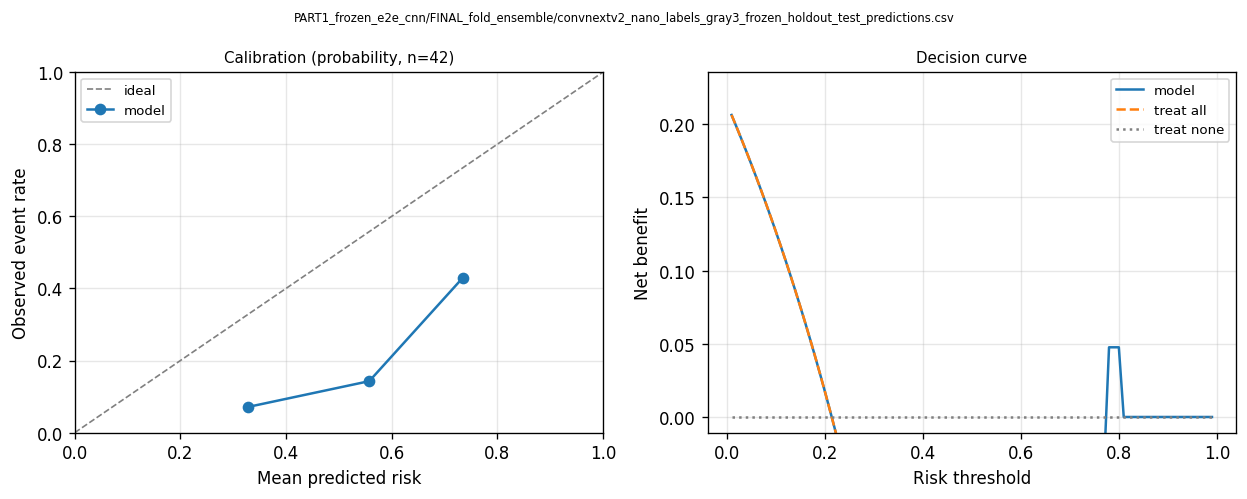

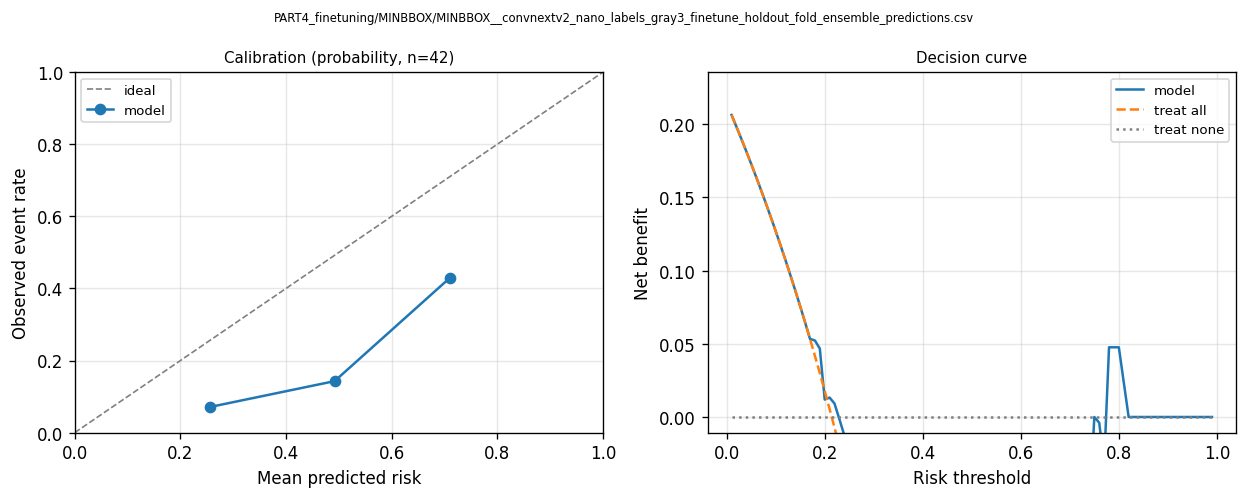

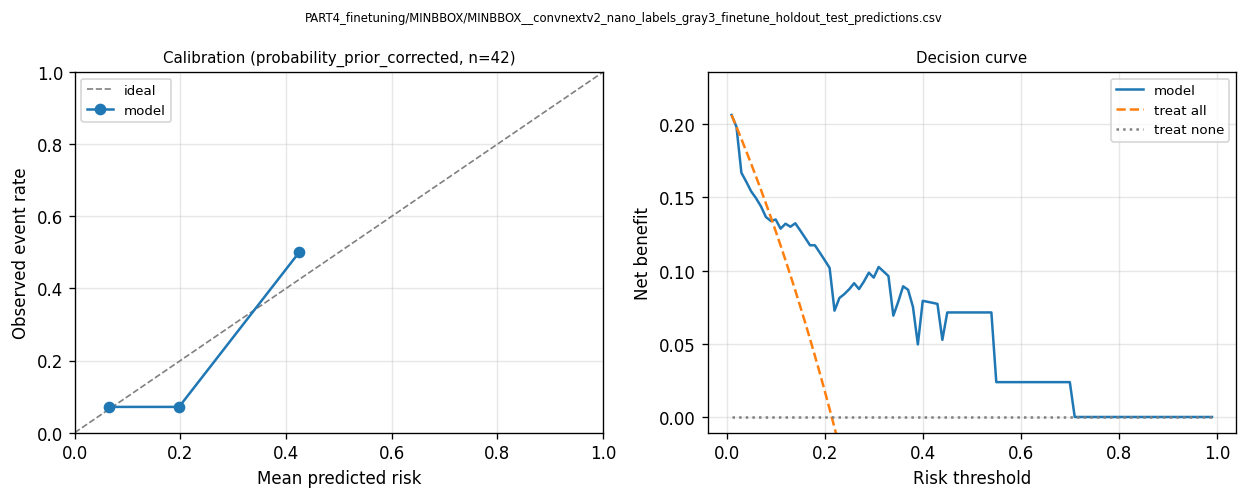

[CALIBRATION] 3 figure(s) saved in /content/drive/MyDrive/DATA/RESULTS/Results2/LARGE_COHORT_v1_early/IMAGE_PREPROCESSING_LPS_OFF_OBLIQUE_OFF/INTENSITY_IMAGE_ZSCORE_SD7/ALL_LESIONS/CALIBRATION_AND_DECISION_CURVES


In [51]:
# Section 8, cell 1: Optional prediction diagnostics
# Read saved predictions and report average precision, calibration and decision curves where scores permit. Model weights and earlier results remain unchanged.
if globals().get("RUN_CALIBRATION_AND_DECISION_CURVES", False):
    import os
    from pathlib import Path as _CPath
    import numpy as np
    import pandas as pd
    from sklearn.metrics import roc_auc_score as _c_auc, average_precision_score as _c_ap

    _CAL_LABEL_COLUMNS = ("true_label", "label")
    _CAL_SCORE_COLUMNS = ("probability", "probability_prior_corrected", "oof_probability_mean", "score")
    _CAL_PATTERNS = ("*_holdout_test_predictions*.csv", "*_holdout_fold_ensemble_predictions*.csv",
                     "*_oof_dev_predictions.csv", "test_predictions*.csv", "val_oof_predictions.csv")
    _CAL_THRESHOLDS = np.round(np.arange(0.01, 1.00, 0.01), 2)  # Decision-curve threshold array: probabilities strictly between 0 and 1.

    def calibration_intercept_slope(y, p, max_iter=100, tol=1e-10):
        """Logistic recalibration of predicted probabilities.

        Slope: coefficient b of logit(p) in the model y ~ a + b * logit(p). Intercept
        (calibration-in-the-large): a in the model y ~ a + logit(p), with the slope fixed at 1.
        Both are fitted by Newton's method. NaN is returned when a fit does not converge, for
        example when the predictions separate the classes perfectly.
        """
        y = np.asarray(y, dtype=float)
        logit = np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))

        def _newton(design, offset):
            beta = np.zeros(design.shape[1])
            for _ in range(int(max_iter)):
                eta = np.clip(design @ beta + offset, -30, 30)
                mu = 1.0 / (1.0 + np.exp(-eta))
                gradient = design.T @ (y - mu)
                hessian = (design * (mu * (1 - mu))[:, None]).T @ design
                try:
                    step = np.linalg.solve(hessian + 1e-12 * np.eye(design.shape[1]), gradient)
                except np.linalg.LinAlgError:
                    return None
                beta = beta + step
                if not np.all(np.isfinite(beta)) or np.max(np.abs(beta)) > 1e3:
                    return None
                if np.max(np.abs(step)) < tol:
                    return beta
            return None

        ones = np.ones_like(logit)
        intercept_fit = _newton(ones[:, None], logit)
        slope_fit = _newton(np.column_stack([ones, logit]), np.zeros_like(logit))
        return (float(intercept_fit[0]) if intercept_fit is not None else float("nan"),
                float(slope_fit[1]) if slope_fit is not None else float("nan"))

    def decision_curve(y, p, thresholds=_CAL_THRESHOLDS):
        """Net benefit of the model, of treating all and of treating none at each risk threshold."""
        y = np.asarray(y, dtype=int)
        p = np.asarray(p, dtype=float)
        n, prevalence = float(len(y)), float(np.mean(y))
        rows = []
        for t in thresholds:
            flagged = p >= t
            weight = t / (1.0 - t)
            true_pos = float(np.sum(flagged & (y == 1))) / n
            false_pos = float(np.sum(flagged & (y == 0))) / n
            rows.append({"threshold": float(t),
                         "net_benefit_model": true_pos - false_pos * weight,
                         "net_benefit_treat_all": prevalence - (1.0 - prevalence) * weight,
                         "net_benefit_treat_none": 0.0})
        return pd.DataFrame(rows)

    def reliability_table(y, p):
        """Mean predicted risk and observed event rate in equally filled risk groups."""
        y = np.asarray(y, dtype=float)
        p = np.asarray(p, dtype=float)
        n_bins = int(np.clip(len(y) // 20, 3, 10))
        order = np.argsort(p, kind="mergesort")
        rows = []
        for part in np.array_split(order, n_bins):
            if len(part):
                rows.append({"mean_predicted": float(p[part].mean()),
                             "observed_rate": float(y[part].mean()), "n": int(len(part))})
        return pd.DataFrame(rows)

    def _cal_source(path, root):
        relative = str(_CPath(path).relative_to(root))
        if "PART4_finetuning" in relative:
            workflow = "finetune"
        elif "PART1_frozen_e2e_cnn" in relative:
            workflow = "frozen"
        elif "PART3_cnn_ml" in relative or "PART2_cnn_features" in relative:
            workflow = "efficient_ML"
        else:
            workflow = "other"
        name = _CPath(path).name
        cohort = ("development out-of-fold" if ("oof" in name) else
                  "holdout fold ensemble" if "fold_ensemble" in name else "holdout test")
        return workflow, cohort, relative

    _cal_root = _CPath(globals().get("CNN_ANALYSIS_ROOT", OUT_ROOT))
    _cal_out = _cal_root / "CALIBRATION_AND_DECISION_CURVES"
    _cal_files = sorted({f for pattern in _CAL_PATTERNS for f in _cal_root.rglob(pattern)
                         if "CALIBRATION_AND_DECISION_CURVES" not in str(f)
                         and "MASK_PERTURBATION" not in str(f)}) if _cal_root.is_dir() else []
    print("=" * 78)
    print("[CALIBRATION] Calibration, PR-AUC and decision curves of the saved predictions")
    print("=" * 78)
    print(f"[CALIBRATION] {len(_cal_files)} prediction file(s) found below {_cal_root}")

    _cal_rows, _cal_curves, _cal_plots = [], [], []
    for _file in _cal_files:
        try:
            _frame = pd.read_csv(_file)
        except Exception as _exc:
            print(f"[CALIBRATION][note] Could not read {_file}: {_exc!r}")
            continue
        _label_col = next((c for c in _CAL_LABEL_COLUMNS if c in _frame.columns), None)
        if _label_col is None:
            continue
        _workflow, _cohort, _relative = _cal_source(_file, _cal_root)
        for _score_col in [c for c in _CAL_SCORE_COLUMNS if c in _frame.columns]:
            _pair = _frame[[_label_col, _score_col]].apply(pd.to_numeric, errors="coerce").dropna()
            _y = _pair[_label_col].to_numpy(dtype=int)
            _p = _pair[_score_col].to_numpy(dtype=float)
            if len(_y) < 4 or np.unique(_y).size != 2:
                continue
            _row = {"workflow": _workflow, "cohort": _cohort, "file": _relative,
                    "score_column": _score_col, "n_patients": int(len(_y)),
                    "prevalence": float(_y.mean()),
                    "auc": float(_c_auc(_y, _p)), "pr_auc": float(_c_ap(_y, _p)),
                    "pr_auc_chance_level": float(_y.mean())}
            # Calibration and net benefit need probabilities. A score outside [0, 1] (for example
            # an SVM decision value) ranks patients but is not a risk.
            _is_probability = bool(np.all((_p >= 0.0) & (_p <= 1.0)))
            _row["score_is_probability"] = _is_probability
            if _is_probability:
                _intercept, _slope = calibration_intercept_slope(_y, _p)
                _curve = decision_curve(_y, _p)
                _useful = _curve[(_curve["net_benefit_model"] > _curve["net_benefit_treat_all"] + 1e-12)
                                 & (_curve["net_benefit_model"] > 1e-12)]
                _row.update({
                    "brier": float(np.mean((_p - _y) ** 2)),
                    "mean_predicted_risk": float(_p.mean()),
                    "calibration_intercept": _intercept, "calibration_slope": _slope,
                    "net_benefit_at_prevalence_threshold": float(
                        _curve.iloc[int(np.argmin(np.abs(_curve["threshold"] - _y.mean())))]["net_benefit_model"]),
                    "thresholds_with_net_benefit_above_all_and_none": int(len(_useful)),
                    "useful_threshold_min": float(_useful["threshold"].min()) if len(_useful) else float("nan"),
                    "useful_threshold_max": float(_useful["threshold"].max()) if len(_useful) else float("nan"),
                })
                _curve.insert(0, "score_column", _score_col)
                _curve.insert(0, "file", _relative)
                _cal_curves.append(_curve)
                if _cohort != "development out-of-fold" and _workflow in ("finetune", "frozen"):
                    _cal_plots.append((_relative, _score_col, _y, _p, _curve))
            _cal_rows.append(_row)

    if not _cal_rows:
        print("[CALIBRATION] No usable prediction file was found. Run at least one workflow section "
              "with the holdout evaluation first.")
    else:
        _cal_out.mkdir(parents=True, exist_ok=True)
        CALIBRATION_TABLE = pd.DataFrame(_cal_rows).sort_values(
            by=["workflow", "cohort", "file", "score_column"]).reset_index(drop=True)
        _cal_csv = _cal_out / "calibration_prauc_netbenefit_summary.csv"
        CALIBRATION_TABLE.to_csv(_cal_csv, index=False)
        if _cal_curves:
            pd.concat(_cal_curves, ignore_index=True).to_csv(_cal_out / "decision_curves.csv", index=False)
        _show = CALIBRATION_TABLE[CALIBRATION_TABLE["cohort"] != "development out-of-fold"]
        _show = _show if len(_show) else CALIBRATION_TABLE
        _columns = [c for c in ("workflow", "cohort", "score_column", "n_patients", "prevalence", "auc",
                                "pr_auc", "brier", "calibration_intercept", "calibration_slope",
                                "useful_threshold_min", "useful_threshold_max", "file")
                    if c in _show.columns]
        _max_rows = int(globals().get("CALIBRATION_MAX_TABLE_ROWS", 40))
        print(_show[_columns].head(_max_rows).round(3).to_string(index=False))
        if len(_show) > _max_rows:
            print(f"... {len(_show) - _max_rows} more row(s) in the saved table.")
        print("\nHow to read it:")
        print("  pr_auc                 compare with prevalence, the value of a model without information.")
        print("  calibration_intercept  0 is ideal. Above 0 the model underestimates risk on average,")
        print("                         below 0 it overestimates it.")
        print("  calibration_slope      1 is ideal. Below 1 the predictions are too extreme (the usual")
        print("                         sign of overfitting), above 1 they are too cautious.")
        print("  useful_threshold_min/max  range of risk thresholds at which acting on the model gives")
        print("                         more net benefit than treating every patient or none.")
        print("  score_column           'probability' is the model output as trained with class weights,")
        print("                         which raises all risks towards the smaller class.")
        print("                         'probability_prior_corrected' has that shift removed and is the")
        print("                         scale to judge calibration and net benefit on.")
        print(f"\n[CALIBRATION] Summary table:  {_cal_csv}")
        if _cal_curves:
            print(f"[CALIBRATION] Decision curves: {_cal_out / 'decision_curves.csv'}")

        # Figures for the holdout predictions of the end-to-end CNN workflows.
        try:
            import matplotlib.pyplot as _cplt
            _max_figures = int(globals().get("CALIBRATION_MAX_FIGURES", 6))
            # Prefer the prior-corrected probability of a file when it exists.
            _by_file = {}
            for _entry in _cal_plots:
                if _entry[0] not in _by_file or _entry[1] == "probability_prior_corrected":
                    _by_file[_entry[0]] = _entry
            for _index, (_relative, _score_col, _y, _p, _curve) in enumerate(_by_file.values()):
                _figure, (_left, _right) = _cplt.subplots(1, 2, figsize=(10.5, 4.2), dpi=120)
                _bins = reliability_table(_y, _p)
                _left.plot([0, 1], [0, 1], linestyle="--", color="grey", linewidth=1, label="ideal")
                _left.plot(_bins["mean_predicted"], _bins["observed_rate"], marker="o", label="model")
                _left.set_xlabel("Mean predicted risk")
                _left.set_ylabel("Observed event rate")
                _left.set_title(f"Calibration ({_score_col}, n={len(_y)})", fontsize=9)
                _left.set_xlim(0, 1); _left.set_ylim(0, 1); _left.grid(alpha=0.3); _left.legend(fontsize=8)
                _right.plot(_curve["threshold"], _curve["net_benefit_model"], label="model")
                _right.plot(_curve["threshold"], _curve["net_benefit_treat_all"], linestyle="--", label="treat all")
                _right.plot(_curve["threshold"], _curve["net_benefit_treat_none"], linestyle=":", color="grey", label="treat none")
                _prevalence = float(np.mean(_y))
                _right.set_ylim(-0.05 * max(_prevalence, 0.05), max(_prevalence, 0.05) * 1.1)
                _right.set_xlabel("Risk threshold")
                _right.set_ylabel("Net benefit")
                _right.set_title("Decision curve", fontsize=9)
                _right.grid(alpha=0.3); _right.legend(fontsize=8)
                _figure.suptitle(_relative[-110:], fontsize=7)
                _figure.tight_layout()
                _png = _cal_out / (_CPath(_relative).stem + f"__{_score_col}.png")
                _figure.savefig(_png)
                if _index < _max_figures:
                    _cplt.show()
                _cplt.close(_figure)
            if _by_file:
                print(f"[CALIBRATION] {len(_by_file)} figure(s) saved in {_cal_out}")
        except Exception as _exc:
            print(f"[CALIBRATION] The figures were not drawn: {_exc!r}")
else:
    print("[SKIP] Section 8: calibration and decision curves disabled by RUN_CALIBRATION_AND_DECISION_CURVES=False.")


## Section 9, cell 1: Occlusion sensitivity

Enabled by `RUN_SALIENCY_CHECK`. Move a patch over prepared 2D slices and record changes in the saved model's output without training it. Compare the share of sensitivity inside the tumour with the fraction of crop area occupied by the tumour.

A ratio above one indicates greater sensitivity per unit area inside the mask. This describes the chosen occlusion experiment rather than proving causal importance or model reliability.

Use the selected saved Section 3 model and up to `SALIENCY_N_PATIENTS`, drawing from test patients when available or development patients otherwise. The cell skips if required helpers or a uniquely identifiable model are unavailable. It also skips 3D, DCE and custom front-end inputs.

Outputs under `CNN_ANALYSIS_ROOT/SALIENCY_CHECK` are `occlusion_saliency_per_patient.csv` and `occlusion_saliency_overview.png`.


In [52]:
# Section 9, cell 1: Optional 2D occlusion sensitivity
# Move a patch over prepared slices and measure output changes. Compare sensitivity inside the mask with its crop area. This measures occlusion sensitivity rather than proving which tissue causally determines a prediction.
if globals().get("RUN_SALIENCY_CHECK", False):
    from pathlib import Path as _SPath
    import numpy as np
    import pandas as pd

    def _saliency_prerequisites():
        """Return (saved model path, backbone name), or a reason why the check cannot run."""
        for _needed in ("build_classifier", "unfreeze_last_block", "get_shared_patient_inputs",
                        "to_backbone_channels", "apply_input_scaling"):
            if _needed not in globals():
                return None, ("the Section 3 helper cells have not run in this session. Set "
                              "RUN_CNN_FINETUNE_E2E = True, or RUN_MASK_PERTURBATION_RETEST = True to "
                              "load them without training")
        if dce_input_enabled() or frontend_enabled():
            return None, "the multi-phase DCE and front-end inputs have no mask channel to compare the sensitivity with"
        # Infer the backbone from the saved model before using configured fallback names.
        explicit = globals().get("SALIENCY_CNN_MODEL_PATH") or globals().get("PERTURB_RETEST_CNN_MODEL_PATH")
        if explicit:
            path = _SPath(explicit)
            if not path.is_file():
                return None, f"saved model not found: {path}"
        else:
            root = _SPath(globals().get("FINETUNE_OUT_DIR", OUT_ROOT))
            matches = sorted(root.rglob("*_final_retrain_model.pt")) if root.is_dir() else []
            if len(matches) != 1:
                listed = "\n    ".join(str(m) for m in matches[:20]) or "(none)"
                return None, (f"{len(matches)} saved fine-tuned models were found below {root}. Name one in "
                              f"SALIENCY_CNN_MODEL_PATH:\n    {listed}")
            path = matches[0]
        configured = (globals().get("SALIENCY_BACKBONE") or globals().get("PERTURB_RETEST_BACKBONE")
                      or (list(SHARED_BACKBONES)[0] if len(SHARED_BACKBONES) == 1 else None))
        backbone = infer_backbone_from_saved_model(path, configured, context="[SALIENCY]")
        if backbone is None:
            return None, (f"the backbone of {path.name} could not be read from its name or weights and "
                          "several backbones are configured: name it in SALIENCY_BACKBONE")
        if is_volume_backbone(backbone):
            return None, "the occlusion check is implemented for the 2D backbones only"
        return (path, backbone), None

    _saliency_found, _saliency_reason = _saliency_prerequisites()
    if _saliency_found is None:
        print(f"[SALIENCY] Skipped: {_saliency_reason}.")
    else:
        import torch
        _saliency_path, _saliency_backbone = _saliency_found
        print("=" * 78)
        print("[SALIENCY] Occlusion-sensitivity check of the saved fine-tuned CNN")
        print("=" * 78)
        print(f"[SALIENCY] Saved weights: {_saliency_path}")
        print(f"[SALIENCY] Backbone rebuilt for the saved weights: {_saliency_backbone}")
        _saliency_model, _, _saliency_norm = build_classifier(
            _saliency_backbone, dropout=float(globals().get("DROPOUT", 0.30)))
        try:
            _saliency_model.load_state_dict(
                torch.load(str(_saliency_path), map_location="cpu", weights_only=True), strict=True)
        except RuntimeError as _exc:
            raise RuntimeError(
                "The saved weights do not fit the rebuilt network. The backbone was read from the "
                f"saved file as {_saliency_backbone!r}; the usual remaining causes are a saved model "
                "from a different workflow section, or changed architecture settings (slice pooling, "
                f"attention size, LoRA) since the model was saved. Original error: {_exc}"
            ) from _exc
        _saliency_model = _saliency_model.to(device).eval()

        # Labelled holdout test patients, or development patients when no holdout exists.
        _sal_pairs, _sal_label_tables = get_shared_patient_data("Saliency check")
        _sal_tag = globals().get("PERTURB_RETEST_LABEL_TAG") or next(
            (t for t in _sal_label_tables if str(t) in _saliency_path.name), next(iter(_sal_label_tables)))
        _sal_labels = dict(zip(_sal_label_tables[_sal_tag]["canonical_id"].astype(str),
                               _sal_label_tables[_sal_tag]["label"].astype(int)))
        _sal_items = [dict(p, canonical_id=canonical_patient_id(p.get("canonical_id", p.get("patient_id"))))
                      for p in _sal_pairs]
        _sal_items = [dict(p, label=_sal_labels[p["canonical_id"]]) for p in _sal_items
                      if p["canonical_id"] in _sal_labels]
        _sal_test = [p for p in _sal_items if str(p.get("split_set", "")) == SPLIT_SET_TEST]
        _sal_cohort = "holdout test" if _sal_test else "development"
        _sal_items = sorted(_sal_test or _sal_items, key=lambda p: patient_id_sort_key(p["canonical_id"]))
        # Equal numbers of both classes where possible, in patient order.
        _sal_n = int(globals().get("SALIENCY_N_PATIENTS", 12))
        _sal_pos = [p for p in _sal_items if p["label"] == 1][:(_sal_n + 1) // 2]
        _sal_neg = [p for p in _sal_items if p["label"] == 0][:_sal_n - len(_sal_pos)]
        _sal_selected = sorted(_sal_pos + _sal_neg, key=lambda p: patient_id_sort_key(p["canonical_id"]))
        print(f"[SALIENCY] Outcome label: {_sal_tag} | cohort: {_sal_cohort} | patients analysed: "
              f"{len(_sal_selected)} of {len(_sal_items)}")

        _sal_size = int(CNN_INPUT_SIZE)
        _sal_patch = max(4, int(round(_sal_size * float(globals().get("SALIENCY_PATCH_FRACTION", 1.0 / 7.0)))))
        _sal_stride = max(1, _sal_patch // 2)
        _sal_starts = list(range(0, _sal_size - _sal_patch + 1, _sal_stride))
        if _sal_starts[-1] != _sal_size - _sal_patch:
            _sal_starts.append(_sal_size - _sal_patch)

        @torch.no_grad()
        def occlusion_sensitivity(raw_slices):
            """Per-slice map (S, H, W) of |change in logit| when a grey patch covers each position.

            raw_slices is the prepared (S, 3, H, W) tensor in [0, 1]. The patch takes the mean
            intensity of the slice it covers, so it removes local structure without adding an
            unnatural black or white square. One slice is occluded at a time.
            """
            xs = to_backbone_channels(raw_slices.clone())
            n_slices = int(xs.shape[0])
            base = float(_saliency_model(apply_input_scaling(xs.clone(), _saliency_norm)[None].to(device))[0])
            heat = torch.zeros((n_slices, _sal_size, _sal_size))
            hits = torch.zeros((n_slices, _sal_size, _sal_size))
            positions = [(s, y0, x0) for s in range(n_slices) for y0 in _sal_starts for x0 in _sal_starts]
            batch = max(1, int(globals().get("SALIENCY_BATCH_SIZE", 32)))
            for start in range(0, len(positions), batch):
                chunk = positions[start:start + batch]
                occluded = xs[None].repeat(len(chunk), 1, 1, 1, 1)
                for i, (s, y0, x0) in enumerate(chunk):
                    occluded[i, s, :, y0:y0 + _sal_patch, x0:x0 + _sal_patch] = xs[s].mean()
                occluded = apply_input_scaling(
                    occluded.view(-1, *xs.shape[1:]), _saliency_norm).view(len(chunk), *xs.shape)
                logits = _saliency_model(occluded.to(device)).float().cpu()
                for i, (s, y0, x0) in enumerate(chunk):
                    heat[s, y0:y0 + _sal_patch, x0:x0 + _sal_patch] += abs(float(logits[i]) - base)
                    hits[s, y0:y0 + _sal_patch, x0:x0 + _sal_patch] += 1
            return (heat / hits.clamp(min=1)).numpy(), base

        _sal_rows, _sal_panels = [], []
        for _item in _sal_selected:
            _raw, _meta = get_shared_patient_inputs(_item["image"], _item["mask"], _sal_size)
            _mask = (_raw[:, 2] > 0.5).numpy()            # channel 2 of the prepared tensor is the mask
            _heat, _base_logit = occlusion_sensitivity(_raw)
            _total = float(_heat.sum())
            _inside = float(_heat[_mask].sum()) / _total if _total > 0 else float("nan")
            _area = float(_mask.mean())
            _sal_rows.append({
                "canonical_id": _item["canonical_id"], "label": int(_item["label"]),
                "predicted_probability": float(1.0 / (1.0 + np.exp(-_base_logit))),
                "sensitivity_inside_tumour": _inside,
                "tumour_share_of_crop": _area,
                "concentration_ratio": (_inside / _area) if _area > 0 and np.isfinite(_inside) else float("nan"),
                "max_logit_change": float(_heat.max()),
            })
            _sal_panels.append((_item["canonical_id"], int(_item["label"]), _raw[0, 0].numpy(), _mask[0], _heat[0]))

        SALIENCY_TABLE = pd.DataFrame(_sal_rows)
        _sal_out = _SPath(globals().get("CNN_ANALYSIS_ROOT", OUT_ROOT)) / "SALIENCY_CHECK"
        _sal_out.mkdir(parents=True, exist_ok=True)
        SALIENCY_TABLE.to_csv(_sal_out / "occlusion_saliency_per_patient.csv", index=False)
        print(SALIENCY_TABLE.round(3).to_string(index=False))
        _ratio = SALIENCY_TABLE["concentration_ratio"].dropna()
        if len(_ratio):
            print(f"\n[SALIENCY] Median share of the sensitivity inside the tumour: "
                  f"{SALIENCY_TABLE['sensitivity_inside_tumour'].median():.2f} "
                  f"(the tumour covers a median of {SALIENCY_TABLE['tumour_share_of_crop'].median():.2f} "
                  f"of the crop). Concentration ratio above 1 in {int((_ratio > 1).sum())} of "
                  f"{len(_ratio)} patients, median {_ratio.median():.2f}.")
            print("[SALIENCY] A ratio above 1 means the model responds to the tumour more than to an "
                  "equally large random part of the crop. Ratios near or below 1 in most patients mean "
                  "the prediction is driven by the surroundings.")
        try:
            import matplotlib.pyplot as _splt
            _n = len(_sal_panels)
            if _n:
                _figure, _axes = _splt.subplots(2, _n, figsize=(2.2 * _n, 4.6), dpi=110, squeeze=False)
                for _col, (_cid, _lab, _image, _mask2d, _map) in enumerate(_sal_panels):
                    _axes[0, _col].imshow(_image, cmap="gray", vmin=0, vmax=1)
                    _axes[0, _col].contour(_mask2d.astype(float), levels=[0.5], colors="yellow", linewidths=0.8)
                    _axes[0, _col].set_title(f"{_cid} | label {_lab}", fontsize=7)
                    _axes[1, _col].imshow(_image, cmap="gray", vmin=0, vmax=1)
                    _axes[1, _col].imshow(_map, cmap="inferno", alpha=0.55)
                    _axes[1, _col].contour(_mask2d.astype(float), levels=[0.5], colors="cyan", linewidths=0.8)
                    for _row in (0, 1):
                        _axes[_row, _col].axis("off")
                _figure.suptitle("Top: analysed slice with the tumour outline. Bottom: occlusion sensitivity "
                                 "(bright = the output changes most when this region is covered)", fontsize=8)
                _figure.tight_layout()
                _figure.savefig(_sal_out / "occlusion_saliency_overview.png")
                _splt.show()
                print(f"[SALIENCY] Table and figure: {_sal_out}")
        except Exception as _exc:
            print(f"[SALIENCY] The figure was not drawn: {_exc!r}")
        del _saliency_model
else:
    print("[SKIP] Section 9: saliency check disabled by RUN_SALIENCY_CHECK=False.")


[SALIENCY] Skipped: the Section 3 helper cells have not run in this session. Set RUN_CNN_FINETUNE_E2E = True, or RUN_MASK_PERTURBATION_RETEST = True to load them without training.
